# 7단계 한눈에 보기

**7단계에서 정한 것은 하나입니다 — 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅) 모두 처음 보는 2025년을 기준선보다 잘 맞혀서, 넷 다 쓰기로 했습니다.** 나머지 물음은 점검이었고, 모델은 바꾸지 않았습니다.

| 물음 | 결과 | 결정 |
|---|---|---|
| 1 — 채점하기 전 점검 | 잔차(시각마다 「실제 − 예측」)가 이웃한 시각끼리 같은 쪽으로 틀렸다(독립성이 깨짐) | 모델은 그대로 둔다. 9단계의 「평소 틀리는 양」은 실제로 틀린 양으로 잡는다 |
| 2 — 2025년 채점 | 넷 모두 기준선보다 결정계수가 높았다 | 넷 다 쓴다. 하나 고르기는 8단계에서 |
| 3 — 2025년에 어디서 틀렸나 | 넷이 같은 곳에서 틀렸다. 까닭은 원전 · 석탄 · 늘어난 태양광 설비 — 셋 다 모델에 넣지 않기로 한 것 | 모델은 그대로 두고, 9단계에서 2026년 차이와 같은 표에 적는다 |
| 4 — 인과지도 | 틀린 까닭을 그림에 화살표로 더했다 | 그림만 고쳤다 |

셀마다 무엇을 물었는지는 셀 제목에 있습니다(VS Code 왼쪽 OUTLINE). 물음마다 한 일과 셀마다 누가 꺼냈는지는 맨 아래 「7단계 한눈에 보기 — 자세한 판」에, 독립성이 깨진 뒤의 흐름과 개념은 맨 아래 「10-13 다시 짚기」에 있습니다.

### 말 뜻 — 표를 읽을 때 쓰는 말 (10-28에 통일함)

| 말 | 뜻 |
|---|---|
| 실제 | 그해(주로 2026년)에 실제로 발전한 양 · 실제 값입니다. 전력거래소 자료 그대로입니다 |
| 모델 예측 | 2023 ~ 2025년을 배운 모델이 그때의 날씨 · 시각 · 날 종류를 보고 예측한 양입니다. 9단계까지는 「평소라면」이라고 불렀습니다 |
| 실제 − 모델 예측 | 발전량 표의 숫자입니다. + 면 실제가 모델 예측보다 많았다, − 면 적었다는 뜻입니다 |
| 평소 해 | 2023 · 2024 · 2025년입니다. 「평소」는 이 세 해만 가리킵니다 |
| 평소 범위 | 평소 해에 모델 예측이 한 달 평균으로 가장 크게 틀린 크기(±2,177 MWh)입니다. 모델이 예측해 본 2024 · 2025년으로 냈습니다. 2026년의 차이가 이 안이면 「달랐다고 말할 근거가 없다」로 읽습니다 |
| 세 해 평균 | 2023 ~ 2025년 같은 달 값의 평균입니다. 모델 없이 계산한 것으로, 10단계 가격 표(2-가 · 2-라)에서만 씁니다 |

앞 단계 글에서 발전량을 두고 쓴 「평소보다 많았다 · 적었다」는 「모델 예측보다 많았다 · 적었다」로 읽습니다.


### ✍️ 이 칸을 읽고 나서

읽어 보시고 아직 막히는 곳이나 생각이 바뀐 것이 있으면 적어 주세요. 비워 두셔도 됩니다.

답:

# 07. 모델링과 검정 — 전체 11단계 중 7단계

**이 단계의 목적** — 6단계에서 정한 모델 넷이 처음 보는 해(2025년)를 기준선보다 잘 맞히는지, 어디서 틀리는지 확인하는 단계입니다. 이것을 알아야 9단계에서 2026년이 평소와 다른 정도가 모델이 평소에 틀리는 정도보다 큰지 말할 수 있습니다.

## 데이터와 모델

**데이터 흐름**

1. 2·3단계 — 시간마다 LNG·기온·햇빛 같은 값을 받아서, 빈 곳을 고친 표를 만들었습니다.
2. 4단계 — 무엇이 LNG를 움직이는지 봤습니다. 몇 시인가 · 무슨 날인가 · 기온 · 햇빛이 컸습니다.
3. 5단계 — 그것들을 모델이 쓸 수 있는 열로 바꿔서 파일 하나(`data/hot/features_2023_2024_2025.csv`)로 저장했습니다.
4. 6단계 — 「2023년으로 배워 2024년을 맞혀 보기」로 연습하면서, 무엇을 넣고 무엇과 비교하고 무엇이 나오면 잘된 것으로 볼지를 정했습니다.
5. 7단계(이 노트북) — 준비 ②가 같은 파일을 읽습니다. 6단계에서 정한 모델 넷을 2023·2024년으로 배우고, 처음 보는 해인 2025년을 한 번 맞혀 채점합니다.

**모델의 입력** (6단계에서 정한 그대로)

- 몇 시인가 · 몇 월인가
- 무슨 날인가 — 월요일 · 화~금 · 토 · 일 · 공휴일 · 명절
- 기온 — 선형회귀는 16도보다 추운 만큼과 24도보다 더운 만큼, 트리 계열은 기온 그대로
- 3시간 동안 기온이 바뀐 만큼 — 추운 쪽과 더운 쪽 (선형회귀에만)
- 햇빛 세기(일사)
- 쉬는 날이면서 몇 시인가 (선형회귀에만)
- 넣지 않는 것 — 원전 · 습도 · 석탄 · 총 전력거래량 · 가격

**비교 대상** — 기준선 넷(모델 없이 지난 두 해의 평균 같은 단순한 규칙으로 맞히기)과 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅).

**7단계의 입력과 결과**

| 순서 | 입력 | 처리 | 결과 | 용도 |
|---|---|---|---|---|
| 1 | 5단계가 저장한 표 하나 — 2023~2025년 시각마다 LNG · 기온 · 일사 · 몇 시 · 몇 월 · 무슨 날 | 준비 ②가 읽고, 2025년 LNG는 바로 비운다. 6단계에서 정한 열을 만든다 | 모델마다 넣을 열 — 선형회귀 67열 · 기온 × 시간대 선형회귀 113열 · 트리 계열 7열 | 아래 2~4 모두 |
| 2 | 2023·2024년의 열과 그 시각의 LNG | 모델 넷이 「이런 조건이면 LNG 발전소가 이만큼 돈다」를 배운다 | 배운 모델 넷 | 물음 1에서 점검하고, 물음 2에서 채점한다 |
| 3 | 2025년의 열 — 기온 · 일사 · 몇 시 · 몇 월 · 무슨 날(LNG는 아직 빈 채로) | 배운 모델 넷이 2025년 시각마다 LNG를 맞힌다. 기준선 넷은 2023·2024년의 평균 같은 단순한 규칙으로 맞힌다 | 2025년 시각마다 맞힌 LNG — 여덟 가지(기준선 넷 + 모델 넷) | 물음 2 |
| 4 | 2025년 실제 LNG — 물음 2의 채점 셀에서 처음 꺼낸다 | 맞힌 값과 실제를 비교한다 | 결정계수 · 평균 절대 오차 · 시각마다 잔차(실제 − 맞힌 값) | 물음 2에서 모델을 쓸지 말지 · 물음 3에서 어디서 틀리나 · 9단계에서 모델이 평소에 틀리는 정도 |
| 5 | 물음 3에서 찾은, 크게 틀린 곳 | 왜 틀렸는지를 인과지도에 표시한다 | 「모델이 못 본 고리」 | 9단계에서 2026년 차이를 읽을 때 |

**먼저 준비 ①과 준비 ②를 돌립니다.**

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 |
| 3 | 정제 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 |
| 6 | 분석계획 |
| 7 | 모델링과 검정 ◀ 이 노트북 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 이 과제만의 물음 — 2026년은 평소와 얼마나 달랐나 |
| 10 | 그 답을 숫자로 내기 |
| 11 | 결론 |

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.

그 밖의 표지 글(물음마다 정한 것 · 7단계의 물음 · 앞 단계에서 넘어온 것 등)은 맨 아래 「7단계 표지 — 자세한 내용」에 있습니다.

In [369]:
# 7단계 모델링과 검정 · 준비 ①
import os                                      # 폴더와 파일 경로를 다루는 기본 모듈
import numpy as np                             # 숫자 계산
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt                # 그림을 그리는 라이브러리
import sklearn                                 # 판 번호를 적어 두려고 부른다
from scipy import stats                        # 정규분포와 검정 — 1-다·1-라의 잔차 가정
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
from sklearn.linear_model import LinearRegression                                   # 선형회귀 — 6단계와 같다
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor   # 트리 계열 둘 — 6단계와 같다
plt.rcParams["font.family"] = "AppleGothic"    # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False     # 그림의 마이너스 부호가 깨지지 않게
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
HOT = os.path.join(ROOT, "data", "hot")        # 5단계가 만들어 둔 파일이 있는 폴더

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다
print("scikit-learn 판:", sklearn.__version__)   # 그래디언트 부스팅은 판이 다르면 소수점 아래 넷째 숫자가 달라질 수 있어 적어 둔다(6단계 물음 2)

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project
scikit-learn 판: 1.9.0


In [370]:
# 7단계 모델링과 검정 · 준비 ②
tbl = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig")  # 5단계 「저장」 셀이 만든 표 — 6단계와 같은 파일
tbl["ts"] = pd.to_datetime(tbl["ts"])            # 글자로 저장된 시각을 다시 시각 자료형으로
tbl = tbl.set_index("ts").sort_index()           # 시각을 줄 이름으로 두고 시간 순서대로 놓는다
tbl.loc[tbl["year"] == 2025, "lng_mwh"] = np.nan   # 누수를 막는다 — 2025년 LNG는 읽자마자 비우고, 물음 2의 채점 셀 하나만 다시 읽는다

전체 = tbl.dropna(subset=["3시간 전 기온"])          # 3시간 전 기온이 빈 9시각(2023-01-01 · 2024-03-01 · 2024-09-01의 0~2시)은 뺀다 — 6단계와 같다
배움 = 전체["year"].isin([2023, 2024])             # 모델이 배우는 두 해
y = 전체["lng_mwh"]                                # 맞힐 값 — 그 시각의 LNG 발전량(MWh). 2025년은 비어 있다

def 선형열(d):                                     # 선형회귀에 넣는 열 — 6단계 닫는 칸 ② 「입력 — 선형회귀」, 67열
    시각열 = pd.get_dummies(d["hour24"].astype(str), prefix="시", drop_first=True).astype(float)   # 1~23시 0/1 열 — 0시가 기준
    월열 = pd.get_dummies(d["month"].astype(str), prefix="월", drop_first=True).astype(float)      # 2~12월 0/1 열 — 1월이 기준
    날열 = pd.get_dummies(d["날 종류"], prefix="날").astype(float).drop(columns="날_월")            # 화~금·토·일·공휴일·명절 — 월요일이 기준
    쉬는날 = d["날 종류"].isin(["토", "일", "공휴일", "명절"]).astype(float)                         # 쉬는 날이면 1
    쉬는날시간대 = (시각열 - 1 / 24).mul(쉬는날, axis=0)                                            # 5단계 물음 7 — 시간대 열의 평균(1/24)을 빼고 쉬는 날과 곱한다
    쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]                            # 열 이름 — 「쉬는 날×9시」
    기상 = pd.DataFrame({"16도보다 추운 만큼": d["16도보다 추운 만큼"],                               # 5단계 물음 1 — 16·24도
                         "24도보다 더운 만큼": d["24도보다 더운 만큼"],
                         "3시간 동안 바뀐 만큼 (추운 쪽)": d["16도보다 추운 만큼"] - d["3시간 전 16도보다 추운 만큼"],   # 6단계 4-라 — 지금 값 − 3시간 전 값
                         "3시간 동안 바뀐 만큼 (더운 쪽)": d["24도보다 더운 만큼"] - d["3시간 전 24도보다 더운 만큼"],
                         "일사": d["icsr"]})                                                       # 5단계 물음 3 — 일사 한 열
    return pd.concat([시각열, 월열, 날열, 기상, 쉬는날시간대], axis=1)

기온두열 = ["16도보다 추운 만큼", "24도보다 더운 만큼"]                                               # 선형회귀의 지금 기온 두 열
def 시간대기온열(d):                                # 기온 × 시간대 선형회귀 — 기온 두 열 대신 시간대마다 나눈 48열, 113열(6단계 물음 6)
    나눔 = pd.DataFrame({f"{c}×{h}시": d[c] * (d["hour24"] == h) for c in 기온두열 for h in range(24)}, index=d.index)   # 그 시간대일 때만 값, 아니면 0
    return 선형열(d).drop(columns=기온두열).join(나눔)

def 트리열(d):                                     # 트리 계열에 넣는 열 — 숫자 그대로 7열(6단계 닫는 칸 ② 「입력 — 트리 계열」)
    return d[["hour24", "month", "icsr", "ta", "dow", "is_holiday", "명절"]]

입력 = {"선형회귀": 선형열(전체), "기온 × 시간대 선형회귀": 시간대기온열(전체), "트리 계열": 트리열(전체)}   # 세 해의 열을 한 번에 만든다 — 해마다 같은 열이 되게

print(f"표 모양: {len(tbl):,}행 · {tbl.shape[1] + 1}열 — 6단계가 읽은 것과 같은 파일")
쓰는곳 = {2023: "배우는 해", 2024: "배우는 해", 2025: "물음 2에서 한 번 채점 — 그 전까지 LNG는 비어 있다"}
display(pd.DataFrame({"시각 수": 전체.groupby("year").size(), "LNG가 있는 시각": y.notna().groupby(전체["year"]).sum(),
                      "이 노트북에서": pd.Series(쓰는곳)}).rename_axis("해"))

표 모양: 25,536행 · 25열 — 6단계가 읽은 것과 같은 파일


,시각 수,LNG가 있는 시각,이 노트북에서
해,,,
2023,8757,8757,배우는 해
2024,8010,8010,배우는 해
2025,8760,0,물음 2에서 한 번 채점 — 그 전까지 LNG는 비어 있다


# 물음 1 — 채점하기 전에, 6단계에서 정한 대로 모델 넷을 만들었나, 배운 결과가 회귀의 가정을 지키나

**점검입니다.** 고르는 것은 없고, 2025년을 채점하기 전에 계획대로 됐는지 확인합니다. 적을 곳은 「1-가」~「1-사」 아래 「✍️」 칸들이고, 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.

**출처** — 6단계에서 정한 7단계 순서입니다. 교재의 회귀 순서(모델링 → 적합성 검정 → 잔차 가정 검토) 가운데 채점 전에 할 수 있는 것을 여기서 합니다.

**지금까지 정해진 것** — 넣을 열 · 모델 넷 · 기준선은 6단계에서 정했고, 이 노트북은 그것을 코드로 옮겼습니다.

**정할 것** — 없습니다. 통과하면 물음 2(2025년 채점)로 가고, 걸리면 채점하기 전에 고칩니다. 셀마다 무엇이 나오면 통과인지는 결과를 보기 전에 적어 두었고, 맨 아래 「물음 1 — 자세한 내용」에 있습니다.

**미리 걸리는 것 하나** — 2025년 채점은 한 번뿐입니다. 채점을 본 뒤에 고치면 처음 보는 해의 성적이 아니게 되므로, 이 물음에서는 2023 · 2024년만 씁니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가.** 2025년 채점은 한 번뿐이라, 채점하기 전에 이 노트북 코드가 6단계와 같은 모델을 만드는지, 열끼리 겹치지 않는지, 잔차가 회귀의 가정을 지키는지를 2023·2024년만으로 확인한 점검입니다.

### 결정 — 6단계에서 정한 대로 만들었고(결정계수 같음 · VIF 10 아래), 잔차는 독립성이 크게 깨졌다. 모델과 입력은 그대로 두고 물음 2(2025년 채점)로 간다

**같이 정한 것**

1. 독립성이 깨진 것은 모델을 바꾸지 않고, 뒤 단계에서 숫자를 읽는 방법으로 다룬다. 그 까닭(모델이 원전 정비·석탄 상한·LNG 가격처럼 천천히 바뀌는 것을 보지 않는다 — 판단)과 함께 README 한계에 적었다.
2. 잔차의 이어짐을 같이 배우는 선형회귀는 쓰지 않는다 — 2024년 결정계수가 오히려 내려갔다(1-마).
3. 8단계에서 기울기의 p값은 4주(672시간) 떨어진 짝까지 감안한 표준오차로 읽는다(1-바 · 1-사, 클로드 제안). 일주일에서 4주로 넓혀도 결론이 같았다.
4. 9단계에서 한 달 합계의 「평소 오차 범위」는 시각 하나의 오차로 계산하지 않고, 2025년에 달마다 실제로 틀린 양으로 본다(맨 아래 「물음 1 — 자세한 내용」). → 7단계를 닫는 중(10-09)에 1-사 「✍️ 다시 읽고 나서」의 「그러면 지금 이 독립성 문제는 해결이 안되는거야??」에서 3-너 · 3-더가 나왔다(2025년 잔차를 보는 셀이라 물음 3에 두었다). 한 달 평균이 어긋나는 크기는 2024 · 2025년이 비슷했고(1.10 ~ 1.22배 — 3-너), 시각 순서만 섞어 이어짐을 없애면 85 ~ 99로 줄어 실제(1,150 ~ 1,294)가 그 12 ~ 14배였다(3-더) — 이 결정이 숫자로 확인됐다.
5. 「3시간 동안 바뀐 만큼 (더운 쪽)」은 지금은 그대로 두고 8단계 효율성(같은 성능이면 더 적은 변수)에서 다시 본다(1-바).

**결정 근거** — 1-가 [표 1] 「같은가」 넷 모두 같다 · 1-나 [표 1] VIF가 10을 넘는 열 0개 · 1-라 [표 1] 더빈-왓슨 0.16 · 0.15(지켜질 때 2 근처) · 1-마 [표 1] 「차이」 −0.0196 · −0.0237 · 1-바 [표 2] 이어짐까지 감안해도 다섯 열의 p값이 0.05 아래 · 1-사 [표 2] 4주까지 넓혀도 다섯 열 모두 0.05 아래(가장 큰 것 0.0018). 판단은 1-바 아래 「✍️ 읽고 나서」 ①의 「오키. 가장 적합하게 객관적으로 진행해야할 것 같어..」와, 같은 때 채팅의 「너가 보기에 검토해서 객관적으로 가장 적합하게 진행하는 수밖에 없어 보이는데..」입니다. 창주 님이 맡기셔서 클로드가 위처럼 정했습니다(클로드 판단). 3의 「4주」는 1-사 아래 「✍️ 읽고 나서」 ①의 「응. 객관적으로 최선의 방향으로 가자.」로 확인하셨습니다.

**남은 것** — 물음 3에서 2025년 잔차로 달마다·시간대마다 어떻게 틀리는지 본다. 9단계에서 한 달 오차 범위를 낸다. 8단계에서 p값과 「3시간 동안 바뀐 만큼 (더운 쪽)」을 다시 본다. 1-바가 일주일 떨어진 짝까지만 감안한 것은 1-사(10-05)에서 4주까지 넓혀 확인했다 — 결론이 같았다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 1 셀 흐름

| 셀 | 어디서 나왔나 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 1-가 | 6단계에서 정한 입력과 모델 (클로드 계획) | 6단계의 표를 코드로 옮길 때 틀릴 수 있다 | 이 노트북이 6단계와 같은 모델을 만드는지 |
| 1-나 | 6단계 4-라 「✍️ 내 답변」 | 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」 | 선형회귀 둘의 모든 열에서 VIF가 10 아래인지 |
| 1-다 | 교재의 잔차 가정 검토 (클로드 계획) | 9단계에서 2026년을 잔차로 보려면, 잔차가 가정을 지키는지 먼저 알아야 한다 | 잔차가 등분산성 · 정규성 · 독립성을 지키는지(그림) |
| 1-라 | 1-다와 같음 (클로드 계획) | 같은 것을 숫자로 본다 | 1-다의 그림을 숫자로 하면 얼마인지 |
| 1-마 | 1-다 · 1-라 「✍️ 읽고 나서」 (창주 님 요청 · 방법은 클로드 제안) | 「해결할 수 있는 방법을 찾아줘. 없다면 해석을 제대로 해야겠네..」 | 잔차의 이어짐을 같이 배우면 2024년을 더 잘 맞히는지 |
| 1-바 | 「잔차 가정이 깨지면」 표 (클로드 제안) | 독립성이 깨지면 기울기의 p값이 실제보다 작게 나온다 | p값이 얼마나 작게 나오는지, 결론이 바뀌는 열이 있는지 |
| 1-사 | 채팅 「방향은 할 수 있는 최선인거지?」 (클로드 제안) | 1-바는 일주일 떨어진 짝까지만 감안했는데, 일주일 떨어진 잔차끼리도 이어져 있었다 | 감안하는 범위를 넓히면 p값이 달라지는지 |

</div>

## 1-가 — 6단계에서 정한 모델 넷을 이 노트북에서 다시 만들면 6단계와 같은 결정계수가 나오나

**어디서 나온 셀인가.** 6단계 닫는 칸 ②의 입력과 모델을 이 노트북 코드로 옮겼습니다. 옮기면서 틀린 곳이 없는지 채점하기 전에 확인합니다(클로드 계획).

**무엇을 보는 셀인가.** 6단계와 같은 연습(2023년으로 배워 2024년 맞히기)을 이 노트북 코드로 다시 해서, 모델마다 넣는 열 수와 결정계수를 6단계에서 나온 값과 나란히 놓습니다([표 1]).

In [371]:
# 7단계 모델링과 검정 · 1-가
모델들 = {"선형회귀": (lambda: LinearRegression(), "선형회귀"),                                    # 6단계 닫는 칸 ② 「시험할 모델」 넷
          "기온 × 시간대 선형회귀": (lambda: LinearRegression(), "기온 × 시간대 선형회귀"),
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=1, max_features=0.5,
                                                      n_jobs=-1, random_state=0), "트리 계열"),       # 6단계 물음 6에서 2024년으로 고른 설정
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=0), "트리 계열")}   # 설정은 그대로
육단계 = {"선형회귀": (0.7524, "4-라 [표 2]"), "기온 × 시간대 선형회귀": (0.7679, "6-나 [표 1]"),         # 6단계에서 2023년으로 배워 2024년을 맞힌 결정계수
          "랜덤포레스트": (0.7701, "6-바 [표 2] 고른 설정"), "그래디언트 부스팅": (0.7807, "6-바 [표 2] 지금 설정")}

연습배움 = 전체["year"] == 2023                                                               # 6단계와 같은 연습 — 2023년으로 배워
연습맞힘 = 전체["year"] == 2024                                                               # 2024년을 맞힌다
줄 = []
for 이름, (만들기, 열) in 모델들.items():
    X = 입력[열]
    값 = 만들기().fit(X[연습배움], y[연습배움]).score(X[연습맞힘], y[연습맞힘])                  # 2024년을 맞힌 결정계수
    전값, 칸 = 육단계[이름]
    줄.append({"모델": 이름, "넣는 열 수": X.shape[1], "6단계 결정계수": f"{전값:.4f}", "6단계에서 나온 칸": 칸,
               "이 노트북 결정계수": f"{값:.4f}", "같은가": "같다" if f"{값:.4f}" == f"{전값:.4f}" else "다르다"})

print(f"2023년 {int(연습배움.sum()):,}시각으로 배워 2024년 {int(연습맞힘.sum()):,}시각을 맞혔다 — 6단계에서 하던 연습 그대로")
print("[표 1] 6단계에서 정한 모델 넷을 이 노트북 코드로 다시 만들면, 2024년을 맞힌 결정계수가 6단계와 같은가")
display(pd.DataFrame(줄).set_index("모델"))

2023년 8,757시각으로 배워 2024년 8,010시각을 맞혔다 — 6단계에서 하던 연습 그대로
[표 1] 6단계에서 정한 모델 넷을 이 노트북 코드로 다시 만들면, 2024년을 맞힌 결정계수가 6단계와 같은가


,넣는 열 수,6단계 결정계수,6단계에서 나온 칸,이 노트북 결정계수,같은가
모델,,,,,
선형회귀,67,0.7524,4-라 [표 2],0.7524,같다
기온 × 시간대 선형회귀,113,0.7679,6-나 [표 1],0.7679,같다
랜덤포레스트,7,0.7701,6-바 [표 2] 고른 설정,0.7701,같다
그래디언트 부스팅,7,0.7807,6-바 [표 2] 지금 설정,0.7807,같다


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 여기서 같다는건 앞단계에서 한 방식이 적합했고, 그대로 코드를 가져와서 여기서 구현했을 때도 결정계수가 같으니 앞으로 이대로 진행한다는 말이겠지??

### 클로드 답변

> **짧게**
> 1. 맞습니다 — 통과입니다. 이 노트북 코드가 6단계와 같은 모델 넷을 만든다는 것이 확인됐고, 이대로 물음 2(채점)로 갑니다.
> 2. 다만 「같다」가 알려 주는 것은 「6단계 방식이 적합했다」가 아니라 「코드를 옮기다 틀린 곳이 없다」입니다.

- 「같다」는 6단계 코드와 이 노트북 코드가 같은 자료로 같은 결과를 냈다는 뜻입니다. 방식이 적합한지는 6단계에서 2024년으로 확인했고, 처음 보는 해에서도 맞는지는 물음 2에서 2025년으로 봅니다.
- 그래디언트 부스팅도 같았습니다. 준비 ①에 찍힌 scikit-learn 판은 1.9.0입니다. 6단계에서는 판을 적지 않았지만, 넷째 숫자까지 같아서 같은 판으로 보입니다(판단).
- 📘 4과목 분석 모형 평가 — 같은 자료 · 같은 설정 · 같은 난수 시드(random_state)면 같은 결과가 나와야 합니다(재현성). 그래야 2025년 채점 결과를 6단계 결과와 이어서 읽을 수 있습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 이해했어.

## 1-나 — 선형회귀 둘에 넣는 열끼리 겹치나(VIF)

**어디서 나온 셀인가.** 지침 7단계 칸의 「다중공선성(VIF 10)」입니다. 6단계 4-라에서는 기온 네 열만 셌고, 5단계 물음 7에서 쉬는 날 × 시간대는 평균을 빼고 만든 열로 VIF를 다시 센다고 남겨 두었습니다.

**무엇을 보는 셀인가.** 배우는 두 해의 입력으로 열마다 VIF를 계산해서, 모델마다 10을 넘는 열 수([표 1])와 VIF가 가장 큰 열 다섯([표 2])을 놓습니다. 열마다 회귀를 한 번씩 돌려서 20초쯤 걸립니다.

In [372]:
# 7단계 모델링과 검정 · 1-나
def VIF값(X, 열):                                                                   # 그 열을 나머지 열로 맞힌 R²로 계산한다 — VIF = 1 / (1 − R²) (6단계 4-라와 같다)
    나머지 = X.drop(columns=열)
    return 1 / (1 - LinearRegression().fit(나머지, X[열]).score(나머지, X[열]))

선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # VIF는 기울기를 배우는 선형회귀 둘만 센다 — 트리에는 기울기가 없다(6단계 4-다 답변 5)
VIF = {이름: pd.Series({c: VIF값(입력[이름][배움], c) for c in 입력[이름].columns}) for 이름 in 선형둘}   # 배우는 두 해(2023·2024년)의 입력으로 계산
표1 = pd.DataFrame({"열 수": {이름: len(v) for 이름, v in VIF.items()},
                    "VIF가 10을 넘는 열 수": {이름: int((v > 10).sum()) for 이름, v in VIF.items()}}).rename_axis("모델")
표2 = pd.concat({이름: v.sort_values(ascending=False).head(5).round(1).rename_axis("열").reset_index(name="VIF")
                 for 이름, v in VIF.items()}, axis=1)
표2.index = pd.RangeIndex(1, 6, name="큰 순서")

print(f"배우는 두 해(2023·2024년) {int(배움.sum()):,}시각의 입력으로 계산했다 — VIF가 10을 넘으면 다른 열과 겹친다고 본다(지침 7단계 칸)")
print("[표 1] 모델마다 열 수와, 그 가운데 VIF가 10을 넘는 열 수")
display(표1)
print("[표 2] 모델마다 VIF가 가장 큰 열 다섯")
display(표2)

배우는 두 해(2023·2024년) 16,767시각의 입력으로 계산했다 — VIF가 10을 넘으면 다른 열과 겹친다고 본다(지침 7단계 칸)
[표 1] 모델마다 열 수와, 그 가운데 VIF가 10을 넘는 열 수


,열 수,VIF가 10을 넘는 열 수
모델,,
선형회귀,67,0
기온 × 시간대 선형회귀,113,0


[표 2] 모델마다 VIF가 가장 큰 열 다섯


선형회귀      기온 × 시간대 선형회귀     
                열  VIF             열  VIF
큰 순서                                     
1     16도보다 추운 만큼  4.7          시_13  5.9
2             월_7  4.5          시_14  5.8
3             월_9  4.2          시_12  5.8
4             월_6  4.1          시_11  5.7
5              일사  4.1          시_15  5.6

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: vif도 나눈 형태로 봐도 10이 넘지 않으니까 진행해도 좋겠다.

### 클로드 답변

> **짧게**
> 1. 맞습니다 — 통과입니다. 선형회귀 둘의 모든 열에서 VIF가 10 아래라, 열을 고칠 것이 없습니다.

- 「나눈 형태」(기온 두 열을 시간대마다 나눈 48열)를 넣은 모델에서 가장 큰 VIF는 「시_13」 5.9입니다. 13시인지 나타내는 0/1 열이, 13시에만 값이 있는 기온 열과 조금 겹치는 것입니다. 10보다 낮습니다.
- 5단계 물음 7 결론 칸에 「쉬는 날 × 시간대는 평균을 빼고 만든 열로 VIF를 다시 센다」고 남겨 둔 일이 여기서 끝났습니다. 그 열들은 두 모델 모두 VIF가 큰 열 다섯 안에 없습니다.
- 📘 3과목 다중공선성 — VIF = 1 ÷ (1 − 그 열을 나머지 열로 맞힌 결정계수). 10을 넘으면 다중공선성이 있다고 봅니다(교재 기준).

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 나눈 형태로 진행하면 되겠네?

### 클로드 답변

> **짧게**
> 1. 나눈 형태(기온 × 시간대 선형회귀)만으로 가는 것이 아니라, 선형회귀 둘 다 물음 2에서 채점합니다. 둘 다 VIF를 통과했습니다.

- 6단계 물음 6에서 정한 대로 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)을 모두 2025년으로 채점합니다. 그중 하나를 고르는 것은 8단계입니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키

## 1-다 — 잔차 가정 셋을 그림으로 보기: 등분산성 · 정규성 · 독립성

**어디서 나온 셀인가.** 지침 7단계 칸의 「잔차 가정 3종」입니다. 이 프로젝트는 9단계에서 2026년의 잔차로 평소와 얼마나 달랐는지를 보기 때문에, 잔차가 어떻게 움직이는지 알아야 그 숫자를 읽을 수 있습니다.

**무엇을 보는 셀인가.** 선형회귀 둘을 2023·2024년으로 배우고, 같은 두 해를 다시 맞힌 잔차(실제 − 예측)를 그림 셋으로 봅니다 — 예측값과 잔차(등분산성), Q-Q 그림(정규성), 몇 시간 떨어진 잔차끼리의 상관(독립성). 위 줄이 선형회귀, 아래 줄이 기온 × 시간대 선형회귀입니다.

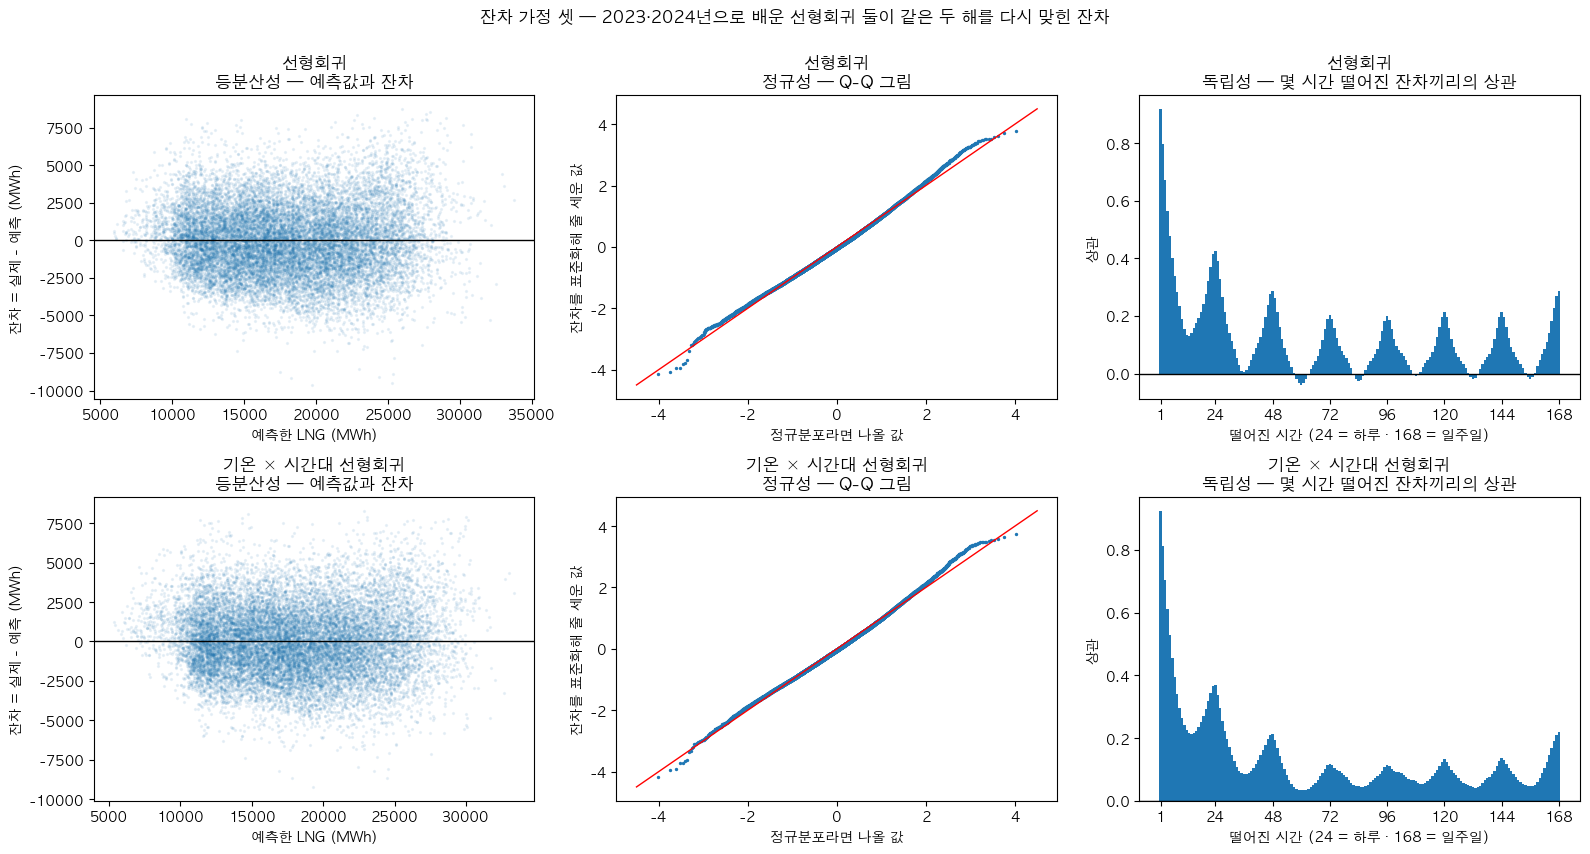

In [373]:
# 7단계 모델링과 검정 · 1-다
선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # 1-나와 같은 둘 — 1-나를 건너뛰고 이 셀만 돌려도 되게 다시 적는다
배운예측 = {이름: pd.Series(LinearRegression().fit(입력[이름][배움], y[배움]).predict(입력[이름][배움]), index=y[배움].index)
           for 이름 in 선형둘}                                                         # 두 해로 배우고, 배운 그 두 해를 다시 맞힌 값
잔차배움 = pd.DataFrame({이름: y[배움] - p for 이름, p in 배운예측.items()})             # 잔차 = 실제 LNG − 예측 LNG (MWh)

def 자기상관(e, k):                                                                    # k시간 떨어진 두 시각의 잔차 상관 — 자료가 빈 시각(2024년 8월 등)과는 짝을 짓지 않는다
    앞 = e.reindex(e.index - pd.Timedelta(hours=k)).values                             # 각 시각의 k시간 전 잔차
    있음 = ~np.isnan(앞)
    return np.corrcoef(e.values[있음], 앞[있음])[0, 1]

시차 = list(range(1, 169))                                                              # 1시간 ~ 168시간(일주일)
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for i, 이름 in enumerate(선형둘):
    e, p = 잔차배움[이름], 배운예측[이름]
    ax = axes[i, 0]                                                                     # 등분산성 — 예측값이 크든 작든 잔차가 퍼진 폭이 같은가
    ax.scatter(p, e, s=2, alpha=0.08, color="tab:blue")
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"{이름}\n등분산성 — 예측값과 잔차")
    ax.set_xlabel("예측한 LNG (MWh)"); ax.set_ylabel("잔차 = 실제 - 예측 (MWh)")    # 그림 글자의 빼기는 「-」로 — 맥 글꼴(AppleGothic)에 「−」가 없어 네모로 나온다(10-05)
    ax = axes[i, 1]                                                                     # 정규성 — 잔차를 줄 세운 값이 정규분포를 줄 세운 값과 한 선에 놓이나
    z = np.sort(((e - e.mean()) / e.std()).values)                                      # 잔차를 표준화해 작은 것부터 줄 세운다
    이론 = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))                    # 정규분포라면 같은 순서에 나올 값
    ax.scatter(이론, z, s=2, color="tab:blue")
    ax.plot([-4.5, 4.5], [-4.5, 4.5], color="red", lw=1)                                # 정규분포면 점이 이 선 위에 놓인다
    ax.set_title(f"{이름}\n정규성 — Q-Q 그림")
    ax.set_xlabel("정규분포라면 나올 값"); ax.set_ylabel("잔차를 표준화해 줄 세운 값")
    ax = axes[i, 2]                                                                     # 독립성 — 몇 시간 떨어진 잔차끼리 닮았나
    ax.bar(시차, [자기상관(e, k) for k in 시차], width=1.0, color="tab:blue")
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168])
    ax.set_title(f"{이름}\n독립성 — 몇 시간 떨어진 잔차끼리의 상관")
    ax.set_xlabel("떨어진 시간 (24 = 하루 · 168 = 일주일)"); ax.set_ylabel("상관")
plt.suptitle("잔차 가정 셋 — 2023·2024년으로 배운 선형회귀 둘이 같은 두 해를 다시 맞힌 잔차", y=1.0)
plt.tight_layout()
plt.show()

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  좌측 선형회귀의 두 종류로 봐도 사진상 등분산성이 보이고, 선형회귀 2열의 그림에서도 사용해도 되는 것 같은데..? 사실 첫번째 등분산성 사진 말고 2번과 3번의 형태는 해석을 어떻게 해야할지 잘 모르겠다. 3번 그림은 상관성이 1은 당연히 1이어야 하는데 시간이 흘러도 그러니까 어떤 24시간 흐름처럼 진폭을 그리지만 그 정도가 그리 높지 않으니까 괜찮다는 의미인가??

### 클로드 답변

> **짧게**
> 1. 등분산성(왼쪽)은 맞게 읽으셨습니다. 예측값이 크든 작든 잔차가 퍼진 폭이 크게 다르지 않습니다.
> 2. 정규성(가운데)은 가운데 점들이 빨간 선에 붙어 있어 정규분포에 가깝고, 양쪽 끝이 조금씩 선에서 벗어납니다.
> 3. 독립성(오른쪽)은 반대로 읽으셨습니다. 막대가 높을수록 독립성이 깨진 것이고, 1시간 떨어진 잔차끼리 상관이 0.92라 크게 깨졌습니다.

**정규성 — Q-Q 그림 읽는 법**

- 잔차를 작은 것부터 줄 세운 값(세로)과, 정규분포라면 같은 순서에 나올 값(가로)을 짝지어 찍은 그림입니다. 정규분포면 점이 빨간 선 위에 놓입니다.
- 두 모델 모두 가운데 점은 선에 붙어 있고, 양쪽 끝이 조금씩 벗어납니다. 오른쪽 위(가로 2 ~ 3.5)는 점이 선보다 위에 있어서, 실제가 예측보다 크게 나온 시각(잔차가 큰 +)이 정규분포에서 나올 것보다 조금 많습니다. 왼쪽 아래 맨 끝의 몇 점은 선보다 아래에 있어서, 예측이 실제보다 훨씬 컸던 시각이 몇 개 있습니다.

**독립성 — 몇 시간 떨어진 잔차끼리의 상관 읽는 법**

- 막대 하나는 「k시간 떨어진 두 시각의 잔차가 얼마나 닮았나」입니다. 가로축의 1은 1시간 떨어진 것입니다. 자기 자신과의 상관(0시간)은 늘 1이라 그리지 않았습니다.
- 잔차가 독립이면 막대가 모두 0 근처에 있어야 합니다. 그런데 선형회귀는 1시간 0.92 · 3시간 0.67 · 24시간 0.43 · 168시간(일주일) 0.29입니다. 모델이 9시를 낮게 예측하면 10시도 낮게 예측하고, 다음 날 같은 시각과 다음 주 같은 요일 같은 시각에도 같은 쪽으로 틀리기 쉽다는 뜻입니다.
- 24시간마다 막대가 다시 솟는 것은 「괜찮다」는 표시가 아니라, 같은 쪽으로 틀리는 날이 며칠씩 이어진다는 표시입니다.
- 그래서 맨 아래 「물음 1 — 자세한 내용」에 적어 둔 대로, 모델은 그대로 두고 읽는 방법이 바뀝니다. 8단계에서 기울기의 p값으로 변수를 고르지 않고, 9단계에서 한 달 합계의 오차 범위는 2025년에 달마다 실제로 틀린 양으로 봅니다.
- 📘 3과목 회귀 진단 — 잔차 대 예측값 그림(등분산성) · Q-Q 그림(정규성) · 자기상관과 더빈-왓슨(독립성). 시간 순서로 쌓인 자료는 독립성이 깨지기 쉽습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 정규성은 이해했고, 그러면 끝에 부분들을 보면 양쪽으로 조금씩 벗어나는게 보이네. 오키. 이 정도가 적합한지는 아래에서 보는 것 같고, 그러면 이정도는 정규성을 확보했다고 말하는 것도 아래. 그래프는 전체적으로 볼 수 있고 수학적으로도 설명이 되어야겠긴 하네

- 독립성을 보면 0에 가깝게 나와야 하는데 시간순으로 이렇게 요동치는건 틀리는 날이 이어진다.. 그렇구나. 이건 해결할 방법이 없는건가? 우리가 가진 데이터, 모델의 한계인가?

### 클로드 답변

> **짧게**
> 1. 정규성은 맞게 읽으셨습니다. 그림으로 보고(1-다) 숫자로 확인하는(1-라) 순서가 말씀하신 그대로입니다.
> 2. 해결할 방법은 셀로 만들었습니다 — 1-마(예측을 고치는 방법)와 1-바(p값을 고치는 방법)입니다. 1-라 「읽고 나서」에서도 같은 것을 물으셔서 한곳에 모았습니다.
> 3. 「데이터, 모델의 한계인가?」에는, 모델을 그렇게 만들어서 생기는 일이라고 봅니다(판단).

- 이 모델은 일부러 날씨 · 시간 · 달 · 날 종류만 봅니다. 원전 정비 · 석탄 발전 상한 · LNG 가격처럼 며칠에서 몇 주에 걸쳐 천천히 바뀌는 것은 보지 않습니다(6단계 물음 1 · 7). 그것들이 평소와 다르게 움직이는 동안에는 모델이 며칠씩 같은 쪽으로 틀립니다. 잔차가 이어지는 것은 그 결과로 보입니다(판단 — 셀로 확인하지는 않았습니다).
- 9단계에서 보려는 것이 바로 그 「모델이 보지 않는 것 때문에 생긴 차이」입니다. 잔차가 이어지지 않게 하려고 그것들을 입력에 넣으면, 2026년 차이도 같이 사라집니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 우리가 보는 방식에 따라서 생겨난 것이구나.. 일단 알겠어. 너가 새롭게 해결 방법을 제시해줬으니 그거 보고 어떻게 할지 결정해보자.

---
어디로 이어졌나 — 1-마(이어짐을 같이 배우는 선형회귀) · 1-바(이어짐을 감안한 표준오차)를 보신 뒤, 1-바 아래 ①에 「오키. 가장 적합하게 객관적으로 진행해야할 것 같어..」라고 적으셔서 물음 1을 닫았습니다(📌 물음 1 결론 칸).

## 1-라 — 잔차 가정 셋을 숫자로 보기

**어디서 나온 셀인가.** 1-다의 그림을 숫자로 옮긴 셀입니다.

**무엇을 보는 셀인가.** 1-다와 같은 잔차로, 가정마다 크기를 보여 주는 숫자([표 1] — 줄마다 「지켜질 때의 값」이 같이 있습니다)와 교재의 검정 p값([표 2])을 놓습니다.

In [374]:
# 7단계 모델링과 검정 · 1-라
def 더빈왓슨(e):                                                                       # Σ(바로 앞 시각과의 잔차 차이)² ÷ Σ잔차² — 바로 앞 시각이 있는 시각만 쓴다
    앞 = e.reindex(e.index - pd.Timedelta(hours=1)).values
    있음 = ~np.isnan(앞)
    return ((e.values[있음] - 앞[있음]) ** 2).sum() / (e.values ** 2).sum()

def 흩어짐비(e, p):                                                                     # 예측값 크기로 다섯 묶음을 만들고, 가장 큰 묶음과 가장 작은 묶음의 잔차 표준편차 비
    묶음 = pd.qcut(p, 5, labels=False)
    폭 = e.groupby(묶음).std()
    return 폭.iloc[-1] / 폭.iloc[0]

def 브로이시페이건(e, X):                                                               # 잔차 제곱을 입력 열로 맞힌 R² × 시각 수 — 열에 따라 잔차 흩어짐이 다르면 커진다
    LM = len(e) * LinearRegression().fit(X, e ** 2).score(X, e ** 2)
    return stats.chi2.sf(LM, X.shape[1])                                                 # p값

표1 = pd.DataFrame({이름: [f"{흩어짐비(잔차배움[이름], 배운예측[이름]):.2f}", f"{stats.skew(잔차배움[이름]):+.2f}",
                            f"{stats.kurtosis(잔차배움[이름], fisher=False):.2f}", f"{더빈왓슨(잔차배움[이름]):.2f}"]
                    for 이름 in 선형둘},
                   index=pd.Index(["등분산성 — 예측이 큰 1/5 묶음과 작은 1/5 묶음의 잔차 표준편차 비",
                                   "정규성 — 왜도(한쪽으로 치우친 정도)", "정규성 — 첨도(꼬리가 두꺼운 정도)",
                                   "독립성 — 더빈-왓슨 통계량"], name="가정 — 무엇으로 보나"))
표1.insert(0, "지켜질 때의 값", ["1 근처", "0 근처", "3 근처", "2 근처 (0에 가까울수록 이웃한 시각이 같은 쪽으로 틀린다)"])
표2 = pd.DataFrame({이름: [f"{브로이시페이건(잔차배움[이름], 입력[이름][배움]):.4f}", f"{stats.jarque_bera(잔차배움[이름]).pvalue:.4f}"]
                    for 이름 in 선형둘},
                   index=pd.Index(["등분산성 — 브로이시-페이건 검정", "정규성 — 자크-베라 검정"], name="가정 — 검정"))

print(f"1-다와 같은 잔차 — 2023·2024년 {len(잔차배움):,}시각, 선형회귀 둘")
print("[표 1] 크기로 본 잔차 가정 셋 — 줄마다 「지켜질 때의 값」과 비교한다")
display(표1)
print("[표 2] 검정의 p값 — 0.05보다 작으면 「가정이 깨졌다」로 읽는다. 시각이 많으면 작은 차이에도 p값이 작아져서 [표 1]을 같이 본다")
display(표2)

1-다와 같은 잔차 — 2023·2024년 16,767시각, 선형회귀 둘
[표 1] 크기로 본 잔차 가정 셋 — 줄마다 「지켜질 때의 값」과 비교한다


,지켜질 때의 값,선형회귀,기온 × 시간대 선형회귀
가정 — 무엇으로 보나,,,
등분산성 — 예측이 큰 1/5 묶음과 작은 1/5 묶음의 잔차 표준편차 비,1 근처,1.33,1.28
정규성 — 왜도(한쪽으로 치우친 정도),0 근처,+0.22,+0.21
정규성 — 첨도(꼬리가 두꺼운 정도),3 근처,3.17,3.21
독립성 — 더빈-왓슨 통계량,2 근처 (0에 가까울수록 이웃한 시각이 같은 쪽으로 틀린다),0.16,0.15


[표 2] 검정의 p값 — 0.05보다 작으면 「가정이 깨졌다」로 읽는다. 시각이 많으면 작은 차이에도 p값이 작아져서 [표 1]을 같이 본다


,선형회귀,기온 × 시간대 선형회귀
가정 — 검정,,
등분산성 — 브로이시-페이건 검정,0.0000,0.0000
정규성 — 자크-베라 검정,0.0000,0.0000


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 1-다의 그래프를 수치적으로 적절하게 해석해서 사용할 수 있는지를 보는 단계라 생각해. 너가 지켜질 때의 값을 적었고, 우측의 결괏값들이 거기서 약간씩 벗어나고 있는데 이게 어느정도여야 적합한 것인지 이정도의 수치면 적합하다고 해서 진행할 수 있는것인지는 내가 잘 모르겠거든?? 크게 차이가 나는 건 아닌 것 같어.

- p값을 보면 결국 보려는건 대립가설을 채택하느냐 문제인데, 표2를 보면 검정상 0.05보다 작으니까 결국 대립가설을 채택하겠지. 그러면 아마 귀무가설은 같다? 일 테니까 같지 않아서 사용할 수 있겠다로 결론내릴 수 있지 않을까?? 틀린거 있으면 바로 말해줘

### 클로드 답변

> **짧게**
> 1. 등분산성과 정규성은 「약간 벗어난다」가 맞습니다. 독립성(더빈-왓슨 0.16 · 0.15, 지켜질 때 2 근처)은 약간이 아니라 크게 벗어났습니다.
> 2. p값은 반대로 읽으셨습니다. 이 두 검정의 귀무가설은 「가정이 지켜진다」라서, 0.05보다 작으면 「가정이 깨졌다」로 읽습니다([표 2] 제목 줄).
> 3. 그래도 모델은 쓸 수 있습니다. 가정이 깨지면 예측값이 아니라 p값과 오차 범위를 읽는 방법이 달라집니다(맨 아래 「물음 1 — 자세한 내용」 「잔차 가정이 깨지면 무엇이 달라지나」 표).

**어느 정도면 괜찮은가**

- 한 경계로 정해진 숫자는 없습니다. 이 프로젝트에서는 「깨졌나」보다 「깨져서 무엇이 달라지나」로 봅니다. 그 표를 결과를 보기 전에 맨 아래 「물음 1 — 자세한 내용」에 적어 두었습니다.
- 왜도 +0.22와 첨도 3.17은 정규분포(0과 3)에서 조금 벗어난 정도입니다. 등분산성은 예측이 큰 쪽의 잔차가 퍼진 폭이 작은 쪽의 1.3배쯤입니다.
- 더빈-왓슨은 「1 − 더빈-왓슨 ÷ 2」가 1시간 떨어진 잔차의 상관과 거의 같습니다. 0.16이면 0.92이고, 1-다 오른쪽 그림의 첫 막대(0.92)와 같은 숫자입니다.

**p값 — 무엇을 버리는 검정인가**

- 브로이시-페이건 검정의 귀무가설은 「잔차가 퍼진 폭이 같다(등분산)」이고, 자크-베라 검정의 귀무가설은 「잔차가 정규분포다」입니다. p값이 0.05보다 작으면 귀무가설을 버리니, 「등분산이 아니다」·「정규분포가 아니다」로 읽습니다.
- 집단의 평균이 다른지 보는 검정에서는 귀무가설을 버리면 「차이가 있다」는 결론을 얻습니다. 가정을 확인하는 검정에서는 귀무가설을 버리면 「가정이 깨졌다」는 결론이 됩니다.
- 그런데 시각이 1만 6천 개쯤이면 아주 작은 차이에도 p값이 0에 가깝게 나옵니다. 잔차가 정확히 정규분포여도 이 표본 크기에서 왜도는 ±0.02쯤 흔들리는데(표준오차 0.019), 0.22는 그 열 배가 넘어서 「0이 아니다」는 분명하지만 크기는 작습니다. 유의한 것과 큰 것은 다릅니다. 그래서 [표 1]의 크기를 같이 봅니다.
- 📘 2과목 가설검정 — 귀무가설 · 대립가설 · p값, 표본이 크면 작은 차이도 유의하게 나옵니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 위에 그래프에서 본 것처럼, 등분산성 정규성은 약간 벗어나서 좋고, 독립성이 큰 문제네. 여기서 그러면 귀무가설이 가정이 지켜진다인데 표의 결과로보면 지켜지지 않은거네? 이거는 데이터나 모델에 내재된 문제인가 해결할 수 있는 방법을 찾아줘. 없다면 해석을 제대로 해야겠네..

#### 물음 1 — 기준 → 나온 것

| 기준(결과를 보기 전에 적은 것) | 어느 셀의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 6단계 결정계수와 소수점 아래 넷째 숫자까지 같다 | 1-가 [표 1] 「같은가」 | 모델 넷 모두 「같다」 | 통과 |
| 선형회귀 둘의 모든 열에서 VIF가 10 이하 | 1-나 [표 1] 「VIF가 10을 넘는 열 수」 | 두 모델 모두 0개 | 통과 |
| 잔차 가정 셋 — 통과와 걸림은 없고, 깨지면 뒤 단계에서 읽는 방법이 바뀐다 | 1-라 [표 1] | 독립성이 크게 깨졌다(더빈-왓슨 0.16 · 0.15). 등분산성과 정규성은 조금 벗어났다 | 모델은 그대로 둔다. 8단계에서 p값으로 변수를 고르지 않고, 9단계에서 한 달 오차 범위를 2025년 달마다 실제로 틀린 양으로 본다 |

#### ① 바꿀 것 없이 물음 2(2025년 채점)로 갈까요?

답: 일단 이건 이미 정해져있는거 아닌가? 독립성이 큰 문제네..

### 클로드 답변

> **짧게**
> 1. 맞습니다. 두 검정 모두 귀무가설(가정이 지켜진다)을 버렸으니, 검정으로 보면 등분산성과 정규성도 완전히 지켜지지는 않았습니다. 다만 크기는 작고([표 1]), 크게 깨진 것은 독립성입니다.
> 2. 「데이터나 모델에 내재된 문제인가」 — 모델이 날씨 · 시간 · 달 · 날 종류만 보도록 일부러 만들어서 생기는 일로 봅니다(판단). 1-다 「읽고 나서」 아래 답변 3번과 같은 답입니다. 해결할 방법은 찾아서 1-마 · 1-바로 넣었습니다. 아래 표가 그 방법들과, 넣지 않는 방법 하나입니다.
> 3. ①은 맞습니다 — 계획은 6단계에서 정해져 있습니다. 다만 채점 전이라 지금 바꿔도 누수가 아니어서, 1-마 · 1-바를 보신 뒤 1-바 아래에서 바꿀지를 한 번 더 여쭙겠습니다.

| 방법 | 무엇을 고치나 | 어디서 보나 |
|---|---|---|
| 잔차가 바로 앞 시각의 잔차를 닮는 정도를 같이 배우는 선형회귀(일반화 최소제곱의 하나, 프레이스-윈스턴 방식) | 기울기를 다시 구한다 — 예측이 달라진다 | 1-마 — 2023년으로 배워 2024년을 맞힌 결정계수 |
| 이어짐을 감안한 표준오차(뉴이-웨스트 방식) | 기울기는 그대로 두고 표준오차와 p값을 다시 낸다 | 1-바 |
| 2025년에 달마다 실제로 틀린 양으로 오차 범위를 낸다 | 9단계의 「평소 오차 범위」를 제대로 낸다 | 9단계 — 맨 아래 「물음 1 — 자세한 내용」에 이미 적어 둔 일 |
| 지난 시각의 LNG를 입력에 넣는다(시계열 모델) | 잔차의 이어짐이 거의 없어진다 | 넣지 않는다 — 2026년에도 지난 시각의 실제 LNG를 따라가서, 9단계에서 보려는 차이가 0에 가까워진다(6단계 물음 6) |

- 📘 3과목 회귀 진단 — 잔차에 자기상관이 있으면 최소제곱으로 구한 기울기는 그대로 써도 되지만, 표준오차가 작게 나와 p값을 믿기 어렵습니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 1-마 — 잔차의 이어짐을 같이 배우는 선형회귀로 바꾸면 2024년을 더 잘 맞히나

**어디서 나온 셀인가.** 1-다 「읽고 나서」의 「이건 해결할 방법이 없는건가?」와 1-라 「읽고 나서」의 「해결할 수 있는 방법을 찾아줘」(창주 님)에서 나왔습니다. 방법은 클로드가 골랐습니다(클로드 제안).

**무엇을 보는 셀인가.** 잔차가 바로 앞 시각의 잔차를 얼마나 닮는지(ρ)를 같이 배우는 선형회귀를 2023년으로 배워서, 2024년을 입력만으로 맞힙니다. 지금 선형회귀와 2024년 결정계수를 나란히 놓습니다([표 1]). 기준은 6단계 물음 6과 같습니다 — 0.002 넘게 높으면 7단계 비교에 더합니다(클로드는 오류를 확인하려고 돌릴 때 결과를 봤습니다).

In [375]:
# 7단계 모델링과 검정 · 1-마
선형둘 = ["선형회귀", "기온 × 시간대 선형회귀"]                                          # 1-나와 같은 둘 — 이 셀만 다시 돌려도 되게 다시 적는다
def 이어짐함께배우기(X, y, 되풀이=3):                                                    # 잔차가 바로 앞 시각과 이어지는 정도(ρ)를 같이 배우는 선형회귀 — 프레이스-윈스턴 방식
    Xc = np.column_stack([np.ones(len(X)), X.values])                                      # 절편 열을 붙인다
    β = np.linalg.lstsq(Xc, y.values, rcond=None)[0]                                       # 처음에는 보통 선형회귀로 기울기를 구한다
    앞X = pd.DataFrame(Xc, index=y.index).reindex(y.index - pd.Timedelta(hours=1)).values  # 각 시각의 1시간 전 입력
    앞y = y.reindex(y.index - pd.Timedelta(hours=1)).values                                 # 각 시각의 1시간 전 LNG
    있음 = ~np.isnan(앞y)                                                                   # 바로 앞 시각이 있는 시각만 쓴다(빈 날의 다음 시각은 뺀다)
    for _ in range(되풀이):
        e = y.values - Xc @ β                                                               # 지금 기울기로 낸 잔차
        e앞 = y.reindex(y.index - pd.Timedelta(hours=1)).values - np.nan_to_num(앞X) @ β     # 1시간 전 잔차
        ρ = np.dot(e[있음], e앞[있음]) / np.dot(e앞[있음], e앞[있음])                          # 잔차가 1시간 전 잔차를 얼마나 닮나
        β = np.linalg.lstsq(Xc[있음] - ρ * 앞X[있음], y.values[있음] - ρ * 앞y[있음], rcond=None)[0]   # 「지금 − ρ × 1시간 전」으로 바꿔 다시 배운다
    return β, ρ

연습배움 = 전체["year"] == 2023                                                          # 6단계와 같은 연습 — 2023년으로 배워
연습맞힘 = 전체["year"] == 2024                                                          # 2024년을 맞힌다
실제24 = y[연습맞힘]
def R2(실, 예): return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()
줄 = []
for 이름 in 선형둘:
    X = 입력[이름]
    보통 = LinearRegression().fit(X[연습배움], y[연습배움]).predict(X[연습맞힘])                 # 지금 방식
    β, ρ = 이어짐함께배우기(X[연습배움], y[연습배움])
    이어짐 = np.column_stack([np.ones(int(연습맞힘.sum())), X[연습맞힘].values]) @ β            # 2024년은 앞 시각의 실제 LNG를 쓰지 않고 입력만으로 맞힌다
    a, b = R2(실제24, 보통), R2(실제24, 이어짐)
    줄.append({"모델": 이름, "배운 ρ": f"{ρ:.2f}", "지금 방식": f"{a:.4f}", "이어짐을 함께 배운 방식": f"{b:.4f}",
               "차이": f"{b - a:+.4f}", "0.002 넘게 높나": "넘는다" if b - a > 0.002 else "못 넘는다"})
print("2023년으로 배워 2024년을 맞혔다 — 6단계 물음 6과 같은 연습, 같은 기준(0.002)")
print("[표 1] 잔차의 이어짐(ρ)을 함께 배운 선형회귀와 지금 선형회귀의 2024년 결정계수")
display(pd.DataFrame(줄).set_index("모델"))

2023년으로 배워 2024년을 맞혔다 — 6단계 물음 6과 같은 연습, 같은 기준(0.002)
[표 1] 잔차의 이어짐(ρ)을 함께 배운 선형회귀와 지금 선형회귀의 2024년 결정계수


,배운 ρ,지금 방식,이어짐을 함께 배운 방식,차이,0.002 넘게 높나
모델,,,,,
선형회귀,0.94,0.7524,0.7328,-0.0196,못 넘는다
기온 × 시간대 선형회귀,0.95,0.7679,0.7443,-0.0237,못 넘는다


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 오히려 떨어지네? 적합하지 않겠다..?

### 클로드 답변

> **짧게**
> 1. 맞습니다. 두 모델 모두 2024년 결정계수가 오히려 내려가서(−0.0196 · −0.0237) 기준(0.002 넘게 높아야)을 넘지 못했습니다. 지금 선형회귀 그대로 갑니다.

- 왜 내려갔나(판단 — 기울기를 비교하지는 않았습니다): 이 방식은 「지금 LNG − 0.94 × 1시간 전 LNG」를 맞히도록 다시 배워서, 기울기를 몇 시간 사이의 변화에서 주로 배웁니다. 그런데 2024년을 맞힐 때는 1시간 전의 실제 LNG를 쓰지 않고 입력만으로 맞힙니다. 그래서 변화에 맞춘 기울기가, LNG가 얼마나 되는지를 맞히는 데는 덜 맞습니다.
- 📘 3과목 회귀 — 일반화 최소제곱(GLS)은 오차가 서로 이어질 때 기울기를 다시 구하는 방법입니다(필기 범위 밖일 수 있습니다).

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오히려 너무 짧게 학습해서 너무 변동이 빠른가? 그래서 틀리는건가?

### 클로드 답변

> **짧게**
> 1. 네, 그 뜻입니다. 이 방식은 몇 시간 사이에 LNG가 얼마나 바뀌는지를 주로 배워서, 한 해 앞을 입력만으로 맞힐 때는 덜 맞습니다(판단 — 기울기를 비교하지는 않았습니다).

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 이해했어.

## 1-바 — 잔차의 이어짐을 감안하면 기울기의 표준오차와 p값이 얼마나 달라지나

**어디서 나온 셀인가.** 1-마와 같은 곳에서 나왔습니다. 맨 아래 「물음 1 — 자세한 내용」에 「독립성이 깨지면 기울기의 p값이 실제보다 작게 나온다」고 적어 두었는데, 얼마나 작게 나오는지를 숫자로 봅니다(클로드 제안).

**무엇을 보는 셀인가.** 2023·2024년으로 배운 선형회귀의 기울기 여섯에 대해 표준오차를 세 가지로 냅니다 — 보통 · 등분산이 아닌 것만 감안 · 이어짐까지 감안(1주일 떨어진 짝까지)([표 1]). 그 표준오차로 낸 p값을 나란히 놓습니다([표 2]). 기울기와 예측은 바뀌지 않습니다.

In [376]:
# 7단계 모델링과 검정 · 1-바
def 표준오차들(X, y, 시차=168):                                                          # 같은 기울기의 표준오차를 세 가지로 낸다
    Xc = np.column_stack([np.ones(len(X)), X.values])
    β = np.linalg.lstsq(Xc, y.values, rcond=None)[0]                                       # 기울기 — 세 가지 모두 같다
    e = y.values - Xc @ β                                                                  # 잔차
    A = np.linalg.inv(Xc.T @ Xc)
    보통 = np.sqrt(np.diag(A) * (e @ e) / (len(e) - Xc.shape[1]))                           # 보통 표준오차 — 잔차가 독립이고 등분산이라고 칠 때
    u = pd.DataFrame(Xc * e[:, None], index=y.index)                                       # 시각마다 (입력 × 잔차)
    S0 = u.values.T @ u.values
    등분산만 = np.sqrt(np.diag(A @ S0 @ A))                                                 # 등분산이 아닌 것만 감안(시차 0)
    S = S0.copy()
    for l in range(1, 시차 + 1):                                                            # 1~168시간 떨어진 짝의 곱을 더한다(뉴이-웨스트, 바틀렛 가중치)
        앞 = u.reindex(u.index - pd.Timedelta(hours=l)).values
        있음 = ~np.isnan(앞[:, 0])
        G = u.values[있음].T @ 앞[있음]
        S += (1 - l / (시차 + 1)) * (G + G.T)
    이어짐까지 = np.sqrt(np.diag(A @ S @ A))                                                 # 이어짐까지 감안
    열 = ["절편"] + list(X.columns)
    return pd.DataFrame({"기울기": β, "보통": 보통, "등분산만 감안": 등분산만, "이어짐까지 감안": 이어짐까지}, index=열)

볼열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 동안 바뀐 만큼 (추운 쪽)", "3시간 동안 바뀐 만큼 (더운 쪽)", "일사", "날_일"]
표 = 표준오차들(입력["선형회귀"][배움], y[배움]).loc[볼열]                                    # 두 해로 배운 선형회귀 — 1-다·1-라와 같은 모델
표1 = pd.DataFrame({"기울기 (MWh)": 표["기울기"].map("{:+,.0f}".format),
                    "보통 표준오차": 표["보통"].map("{:,.0f}".format),
                    "등분산만 감안": 표["등분산만 감안"].map("{:,.0f}".format),
                    "이어짐까지 감안": 표["이어짐까지 감안"].map("{:,.0f}".format),
                    "이어짐까지 ÷ 보통 (배)": (표["이어짐까지 감안"] / 표["보통"]).map("{:.1f}".format)}).rename_axis("열")
p = lambda 기울기, 오차: pd.Series(2 * stats.norm.sf(np.abs(기울기 / 오차)), index=기울기.index)   # 기울기가 0이라는 귀무가설의 p값
표2 = pd.DataFrame({"p값 — 보통": p(표["기울기"], 표["보통"]).map("{:.4f}".format),
                    "p값 — 이어짐까지 감안": p(표["기울기"], 표["이어짐까지 감안"]).map("{:.4f}".format)}).rename_axis("열")
print(f"2023·2024년 {int(배움.sum()):,}시각으로 배운 선형회귀의 기울기 가운데 여섯 — 기울기는 그대로이고 표준오차만 세 가지로 냈다")
print("[표 1] 표준오차 — 이어짐까지 감안할 때 1주일(168시간) 떨어진 짝까지 넣었다")
display(표1)
print("[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다")
display(표2)

2023·2024년 16,767시각으로 배운 선형회귀의 기울기 가운데 여섯 — 기울기는 그대로이고 표준오차만 세 가지로 냈다
[표 1] 표준오차 — 이어짐까지 감안할 때 1주일(168시간) 떨어진 짝까지 넣었다


,기울기 (MWh),보통 표준오차,등분산만 감안,이어짐까지 감안,이어짐까지 ÷ 보통 (배)
열,,,,,
16도보다 추운 만큼,+281,5,6,23,4.3
24도보다 더운 만큼,+977,15,16,64,4.4
3시간 동안 바뀐 만큼 (추운 쪽),+160,15,15,36,2.4
3시간 동안 바뀐 만큼 (더운 쪽),-8,24,24,51,2.1
일사,"-2,604",40,44,120,3.0
날_일,"-4,482",69,66,163,2.4


[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다


,p값 — 보통,p값 — 이어짐까지 감안
열,,
16도보다 추운 만큼,0.0000,0.0000
24도보다 더운 만큼,0.0000,0.0000
3시간 동안 바뀐 만큼 (추운 쪽),0.0000,0.0000
3시간 동안 바뀐 만큼 (더운 쪽),0.7461,0.8793
일사,0.0000,0.0000
날_일,0.0000,0.0000


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 더운쪽 3시간 바뀐만큼이 다른 건 전부 0인데 이 수치가 어떻게 봐야할지 잘 모르겠다..? 감안했을 때 최적이라는 의미인가?? 

### 클로드 답변

> **짧게**
> 1. 「최적」이라는 뜻이 아닙니다. p값이 크다는 것은 「3시간 동안 바뀐 만큼 (더운 쪽)」의 기울기(−8 MWh)가 0과 구별되지 않는다는 뜻입니다. 이 열은 LNG를 맞히는 데 거의 보태는 것이 없습니다.
> 2. 나머지 다섯 열은 이어짐까지 감안해 표준오차가 2~4배 커져도 p값이 0.05 아래 그대로입니다. 독립성이 깨진 것이 이 열들의 결론을 바꾸지는 않습니다.

- [표 2]의 귀무가설은 「기울기가 0이다(그 열은 LNG와 관계가 없다)」입니다. 0.0000은 그 귀무가설을 버린다(관계가 있다)이고, 0.75 · 0.88은 버리지 못한다(관계가 있다고 말할 수 없다)입니다.
- 6단계 5-마에서 3시간 전 기온의 두 열(추운 쪽 · 더운 쪽)을 함께 빼도 2024년 결정계수가 0.0016만 내려갔습니다. 그중 더운 쪽이 거의 보태지 않는다는 것이 여기서 보입니다. 6단계 물음 5에서 「이미 넣은 열은 그대로 둔다」고 정해서 지금은 그대로 두고, 8단계의 효율성(같은 성능이면 더 적은 변수)에서 다시 봅니다.
- 📘 3과목 회귀 — 회귀계수의 유의성 검정(t검정): 기울기를 표준오차로 나눈 값이 작으면 p값이 커서 「기울기가 0이다」를 버리지 못합니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키 구분되지 않으니까 이 열은 무의미한거네. 다른 것들은 전부 0.05이하인데 얘네들은 어떻게 하지? 너가 6단계에서 말한 것처럼. 흠. 정한대로 가는게 맞는 방향인가. 그러면 결국 해석의 방향을 어떻게 수정하는수밖에 없는건가? 모델링과 데이터 셋의 한계로 보고??

#### 물음 1 — 기준 → 나온 것 (1-마 · 1-바를 더해 다시 적었습니다)

| 기준(결과를 보기 전에 적은 것) | 어느 셀의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 6단계 결정계수와 소수점 아래 넷째 숫자까지 같다 | 1-가 [표 1] 「같은가」 | 모델 넷 모두 「같다」 | 통과 |
| 선형회귀 둘의 모든 열에서 VIF가 10 이하 | 1-나 [표 1] | 두 모델 모두 0개 | 통과 |
| 잔차 가정 셋 — 깨지면 뒤 단계에서 숫자를 읽는 방법이 바뀐다 | 1-라 [표 1] | 독립성이 크게 깨졌다(더빈-왓슨 0.16 · 0.15). 등분산성과 정규성은 조금 벗어났다 | 모델은 그대로 둔다 |
| 잔차의 이어짐을 같이 배운 선형회귀가 2024년 결정계수를 0.002 넘게 높이나(6단계 물음 6과 같은 기준) | 1-마 [표 1] 「차이」 | −0.0196 · −0.0237 | 더하지 않는다 — 지금 선형회귀 그대로 |
| 이어짐을 감안한 표준오차 — 통과와 걸림은 없다 | 1-바 [표 1] · [표 2] | 표준오차가 2.1~4.4배 커져도, p값이 0.05 아래였던 다섯 열은 그대로 아래였다 | 8단계에서 기울기를 읽을 때 이어짐까지 감안한 표준오차를 쓴다(클로드 제안) |

#### ① 모델과 입력은 6단계에서 정한 그대로 두고, 물음 2(2025년 채점)로 갈까요?

답: 오키. 가장 적합하게 객관적으로 진행해야할 것 같어..

1. 내용이 조금 어렵고 예상하지 못한 문제가 나와서, 무엇이 가장 적절한지 잘 모르겠다. 클로드가 검토해서 객관적으로 가장 적합하게 진행하는 수밖에 없어 보인다. 여기서는 복잡해서 방향을 잡기 어렵다.

### 클로드 답변

> **짧게**
> 1. 맞습니다 — 정한 대로 갑니다. 모델과 입력은 그대로 두고, 독립성이 깨진 것은 뒤 단계에서 숫자를 읽는 방법으로 다룹니다. README 한계에도 적었습니다.
> 2. p값이 0.05 아래인 다섯 열은 할 일이 없습니다. 「관계가 있다」가 그대로라 그대로 씁니다.
> 3. ①과 채팅에서 맡기셔서, 클로드 판단으로 물음 1을 닫고 물음 2를 열었습니다. 무엇을 정했는지는 물음 1 제목 바로 아래 📌 칸에 있습니다.

- 「한계로 보고 해석을 바꾸는 수밖에 없나」 — 네. 다만 이 프로젝트만의 사정은 아닙니다. 평소 기간으로 날씨·달력 모델을 만들고 다른 기간의 실제와 비교하는 에너지 절감량 검증(6단계에서 같은 구조라고 확인한 방법)에서도, 시간별 모델의 잔차가 이어지는 것은 흔하고 모델을 바꾸기보다 오차 범위를 넓혀서 다룹니다.
- 미국 ASHRAE 지침 14는 서로 독립인 자료 수를 줄여 잡는 식(n′ = n × (1 − ρ) ÷ (1 + ρ))으로 범위를 넓힙니다. 1-라의 0.92를 넣으면 1만 6천 시각이 700개쯤으로 줄어듭니다(클로드 계산). 그런데 미국 로렌스버클리 연구소의 비교 연구([Granderson 외](https://eta-publications.lbl.gov/sites/default/files/evaluation_of_methods_-_granderson.pdf))는 이 식도 시간별 모델에서는 범위를 좁게 잡는다고 했습니다. 그래서 9단계에서는 식으로 넓히지 않고, 2025년에 달마다 실제로 틀린 양으로 범위를 보는 쪽(맨 아래 「물음 1 — 자세한 내용」)으로 갑니다.
- 「이 열은 무의미」는 「관계가 있다고 말할 수 없다」가 더 정확합니다. 관계가 없다는 것이 증명된 것은 아니고, 이 자료로는 0과 구별되지 않는다는 뜻입니다.
- 📘 4과목 결과 해석 — 모델의 한계를 숨기지 않고, 그 한계가 어느 숫자에 영향을 주는지 적습니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 일단 복잡하긴 한데 적합한 방향, 최선의 방향으로 가보자. 뭐 모든게 완전할 수는 없으니까.

1. 방향은 할 수 있는 최선인거지?
2. 그러면 그냥 하면 되는거야?

### 클로드 답변

> **짧게**
> 1. 네, 큰 방향은 이 자료로 맞는 쪽이라고 봅니다(판단). 다만 클로드가 정한 세부에 약한 곳이 셋 있어서 아래에 적었습니다.
> 2. 그 셋은 물음 2를 하시는 데 바꿀 것이 없어서, 그대로 하시면 된다고 답했습니다.

- 가장 강한 반론은 「며칠씩 같은 쪽으로 틀리면 모델이 무언가를 놓친 것이니 모델을 고쳐야 한다」입니다. 놓친 것은 원전 · 석탄 · 가격처럼 천천히 움직이는 것들이고, 셋 다 일부러 뺐습니다 — 석탄과 가격은 2026년에 달라진 것 자체이고, 원전은 두 해 자료로 석탄과 떼어 낼 수 없었습니다(6단계 물음 1). 모델 안에서 고치는 방법은 1-마에서 다음 해를 덜 맞혔습니다. 그래서 이어짐은 이 설계에서 생기는 「평소에도 있는 차이」로 보고, 9단계에서 2026년 차이를 평소 해의 달마다 차이와 나란히 놓습니다.
- 약한 곳 ① — 1-바는 일주일 떨어진 짝까지만 감안했는데, 1-다 그림에서는 일주일 떨어진 잔차도 아직 이어져 있었습니다. 표준오차가 아직 작게 나왔을 수 있어서, 더 멀리 떨어진 짝까지 감안한 셀(1-사)을 물음 2를 닫은 뒤에 더합니다. 8단계에서 변수를 읽을 때 쓰는 숫자입니다.
- 약한 곳 ② — 2025년 채점에서 모델과 기준선의 결정계수 차이가 6단계 문턱(0.002)보다 작으면 우연과 가르기 어렵다고 적기로 했습니다(결과를 보기 전에 README에 적음). → 2-가에서 가장 작은 차이가 +0.0329라 해당하지 않았습니다(2-다 아래 표).
- 약한 곳 ③ — 9단계의 「평소 오차 범위」를 2025년의 달 열두 개로 잡으면 거칠게 나옵니다. 9단계를 열 때 셀로 다룹니다.
- 「뭐 모든게 완전할 수는 없으니까」 — 그래서 약한 곳 셋을 README 한계에 적어 두었습니다.
- 📘 4과목 결과 해석 — 한계를 숨기지 않고, 그 한계가 어느 숫자에 영향을 주는지 같이 적습니다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 이해했어. 약한 부분도 있을 수밖에 없구나..

## 1-사 — 이어짐을 감안하는 범위를 일주일보다 넓히면 표준오차와 p값이 달라지나

**어디서 나온 셀인가.** 물음 1을 닫은 뒤 채팅에서 창주 님이 「방향은 할 수 있는 최선인거지?」라고 물으셔서, 클로드가 자기가 정한 세부를 다시 보다가 찾은 약한 곳입니다(클로드 제안 — 1-바 「✍️ 다시 읽고 나서」 아래 답변의 약한 곳 ①). 1-바는 일주일(168시간) 떨어진 짝까지만 감안했는데, 1-다 그림에서는 일주일 떨어진 잔차끼리도 아직 이어져 있었습니다.

**무엇을 보는 셀인가.** 1-바와 같은 선형회귀(2023·2024년)의 여섯 열에 대해, 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차([표 1])와 p값([표 2])을 다시 냅니다. 기울기는 그대로이고, 「일주일」 칸은 1-바의 「이어짐까지 감안」과 같은 숫자입니다. 2025년은 쓰지 않습니다.

In [377]:
# 7단계 모델링과 검정 · 1-사
Xs = 입력["선형회귀"][배움]                                                              # 1-바와 같은 선형회귀 — 두 해(2023·2024년)의 67열
Xc = np.column_stack([np.ones(len(Xs)), Xs.values])                                      # 절편 열을 붙인다
β = np.linalg.lstsq(Xc, y[배움].values, rcond=None)[0]                                   # 기울기 — 범위를 바꿔도 그대로다
e = y[배움].values - Xc @ β                                                              # 잔차
A = np.linalg.inv(Xc.T @ Xc)
u = pd.DataFrame(Xc * e[:, None], index=Xs.index)                                        # 시각마다 (입력 × 잔차)
범위들 = {"일주일 (168시간)": 168, "2주 (336시간)": 336, "4주 (672시간)": 672}            # 이어짐을 감안하는 범위 — 몇 시간 떨어진 짝까지 넣나
G = {}                                                                                   # l시간 떨어진 짝의 곱 — 한 번만 구해 범위마다 다시 쓴다
for l in range(1, max(범위들.values()) + 1):
    앞 = u.reindex(u.index - pd.Timedelta(hours=l)).values                               # l시간 전 시각의 값(그 시각이 없으면 빈 칸)
    있음 = ~np.isnan(앞[:, 0])
    g = u.values[있음].T @ 앞[있음]
    G[l] = g + g.T
S0 = u.values.T @ u.values
오차 = {"보통": np.sqrt(np.diag(A) * (e @ e) / (len(e) - Xc.shape[1]))}                   # 보통 표준오차 — 1-바와 같다
for 이름, L in 범위들.items():                                                            # 뉴이-웨스트(바틀렛 가중치) — 1-바와 같은 식, 범위만 바꾼다
    S = S0 + sum((1 - l / (L + 1)) * G[l] for l in range(1, L + 1))
    오차[이름] = np.sqrt(np.diag(A @ S @ A))

열 = ["절편"] + list(Xs.columns)
볼열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 동안 바뀐 만큼 (추운 쪽)", "3시간 동안 바뀐 만큼 (더운 쪽)", "일사", "날_일"]   # 1-바와 같은 여섯 열
기울기 = pd.Series(β, index=열).loc[볼열]
표준 = pd.DataFrame(오차, index=열).loc[볼열]
표1 = pd.concat([기울기.map("{:+,.0f}".format).rename("기울기 (MWh)"), 표준.apply(lambda s: s.map("{:,.0f}".format))], axis=1).rename_axis("열")
p값 = 표준.apply(lambda s: pd.Series(2 * stats.norm.sf(np.abs(기울기 / s)), index=볼열))     # 기울기가 0이라는 귀무가설의 p값
표2 = p값.apply(lambda s: s.map("{:.4f}".format)).rename_axis("열")
print(f"1-바와 같은 선형회귀(2023·2024년 {len(Xs):,}시각) — 이어짐을 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차를 다시 냈다. 기울기는 그대로다")
print("[표 1] 기울기와 표준오차 — 「보통」은 잔차가 서로 독립이라고 칠 때, 나머지는 그 범위 안에서 떨어진 짝까지 감안할 때")
display(표1)
print("[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다")
display(표2)

1-바와 같은 선형회귀(2023·2024년 16,767시각) — 이어짐을 감안하는 범위를 일주일 · 2주 · 4주로 넓혀 표준오차를 다시 냈다. 기울기는 그대로다
[표 1] 기울기와 표준오차 — 「보통」은 잔차가 서로 독립이라고 칠 때, 나머지는 그 범위 안에서 떨어진 짝까지 감안할 때


,기울기 (MWh),보통,일주일 (168시간),2주 (336시간),4주 (672시간)
열,,,,,
16도보다 추운 만큼,+281,5,23,22,20
24도보다 더운 만큼,+977,15,64,70,80
3시간 동안 바뀐 만큼 (추운 쪽),+160,15,36,42,51
3시간 동안 바뀐 만큼 (더운 쪽),-8,24,51,53,55
일사,"-2,604",40,120,127,133
날_일,"-4,482",69,163,177,208


[표 2] 기울기가 0이라는 귀무가설의 p값 — 0.05보다 작으면 「이 열은 LNG와 관계가 있다」로 읽는다


,보통,일주일 (168시간),2주 (336시간),4주 (672시간)
열,,,,
16도보다 추운 만큼,0.0000,0.0000,0.0000,0.0000
24도보다 더운 만큼,0.0000,0.0000,0.0000,0.0000
3시간 동안 바뀐 만큼 (추운 쪽),0.0000,0.0000,0.0002,0.0018
3시간 동안 바뀐 만큼 (더운 쪽),0.7461,0.8793,0.8851,0.8895
일사,0.0000,0.0000,0.0000,0.0000
날_일,0.0000,0.0000,0.0000,0.0000


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 보는 범위를 넓혔을 때인데..추운쪽 4주로 늘리면 관계가 있다?? 이정도 보이고 나머진 거의 같네

1. 딱히 뭐 모르겠다 어렵네

### 클로드 답변

> **짧게**
> 1. 「추운쪽 4주로 늘리면 관계가 있다??」 — 범위를 넓혀도 「관계가 있다」가 그대로라는 뜻입니다. 「3시간 동안 바뀐 만큼 (추운 쪽)」의 p값이 0.0000 → 0.0002 → 0.0018로 커지기는 했지만, 0.05보다 훨씬 작습니다.
> 2. 「나머진 거의 같네」 — 맞습니다. 다섯 열은 4주까지 넓혀도 0.05 아래이고, 더운 쪽은 처음부터 0.05 위입니다. 1-바에서 읽은 결론이 바뀌지 않으니, 바꿀 것이 없습니다.

- 이 셀에서 가져갈 것은 한 줄입니다 — 잔차가 이어지는 것을 일주일보다 넓게(4주까지) 감안해도, 어느 열이 LNG와 관계가 있다는 결론은 같다.
- 표준오차는 대부분 범위를 넓힐수록 커졌습니다(예: 날_일 163 → 177 → 208). 범위를 넓히면 「며칠씩 같은 쪽으로 틀리는 것」을 더 많이 감안해서, 그만큼 기울기를 덜 믿게 되기 때문입니다. 「16도보다 추운 만큼」만 조금 작아졌는데(23 → 22 → 20), 멀리 떨어진 시각끼리는 반대쪽으로 틀린 짝도 섞여 들어가서라고 봅니다(판단). 범위를 넓힌다고 늘 커지는 것은 아닙니다.
- 1번(「딱히 뭐 모르겠다 어렵네」) — 이 셀은 확인용이라 위의 한 줄만 가져가셔도 됩니다. 숫자를 읽는 방법이 맞는지 한 번 더 본 것이고, 모델이나 입력을 바꾸는 셀이 아닙니다.
- 📘 3과목 회귀 진단 — 잔차에 자기상관이 있을 때 쓰는 뉴이-웨스트 표준오차는 몇 시간 떨어진 짝까지 감안할지(시차)를 정해야 하고, 그 값을 바꿔도 결론이 같은지 보는 것이 민감도 확인입니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러네 넓게 감안해도 lng와 관계가 있다는 결론..

#### 1-사 — 기준 → 나온 것

| 기준(결과를 보기 전에 적은 것) | 어느 셀의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 8단계에서는 4주로 낸 표준오차로 p값을 읽는다. 1-바에서 0.05 아래였던 열이 4주에서 0.05를 넘으면 그 열은 「관계가 있다고 말하기 어렵다」로 적는다(클로드 판단 — 물음 1 머리 칸의 통과 표) | 1-사 [표 2] 「4주 (672시간)」 칸 | 다섯 열 모두 0.05 아래 — 가장 큰 것이 「3시간 동안 바뀐 만큼 (추운 쪽)」 0.0018 | 결론이 바뀌는 열이 없다 |

#### ① 바꿀 것 없이 이대로 갈까요? 8단계에서는 4주로 낸 표준오차로 p값을 읽습니다. 확인하시면 물음 1을 다시 닫고, 물음 3(2025년에 어디서 어떻게 틀렸나)을 엽니다.

답: 응. 객관적으로 최선의 방향으로 가자.

1. 어려워서 그냥 알겠다고 했어

### 클로드 답변

> **짧게**
> 1. 「그러네 넓게 감안해도 lng와 관계가 있다는 결론..」 — 그것이 이 셀의 결론 그대로입니다. 바꿀 것이 없어서, ①에 적으신 대로 물음 1을 다시 닫았습니다.
> 2. 1번 — 몰라서 넘어가신 부분은 「표준오차를 왜 범위를 바꿔 가며 다시 내나」일 텐데, 이 물음에서 어려운 부분이 여기입니다. 7단계를 닫을 때 개념 질문(기울기의 표준오차와 p값)에서 한 번 더 짚겠습니다.

- 한 문단으로 풀면 이렇습니다. 어느 날 9시를 낮게 맞혔다면 10시 · 11시도 비슷하게 낮게 맞히는 일이 많습니다(1-다 — 한 시각 떨어진 잔차끼리 상관 0.92). 그러면 1만 6천 시각이 1만 6천 개의 따로 된 증거가 아니라 그보다 훨씬 적은 증거가 됩니다. 증거가 적으면 기울기를 덜 믿어야 하고(표준오차가 커짐), 1-바 · 1-사는 몇 시간 떨어진 시각까지를 같은 쪽으로 틀리는 묶음으로 감안할지를 일주일 · 2주 · 4주로 바꿔 가며 봐도 결론이 같은지 확인한 셀입니다.
- 📘 3과목 회귀 진단 — 관측값끼리 서로 독립이 아니면 표본 수만큼의 정보가 없어서, 그만큼 표준오차를 크게 잡아야 합니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 1. 그러면 지금 이 독립성 문제는 해결이 안되는거야?? 엄청 크리티컬하게 느껴지는데
2. 그러면 결론은 뭐야? 지금 단계에서 뭘 할 수가 없다는건가??
3. 더 쓴다는건 데이터증식시키는 개념이지?? 아 나는 오버샘플링 그거 생각했는데 그거랑은 다르구나
4. 흠 뭐가 적합하지?? 나 판단을 잘 못하겠네

### 클로드 답변

> **짧게**
> 1. 독립성이 깨진 것은 없애지 못했고, 일부러 없애지 않았습니다. 이 문제로 틀어지는 숫자 둘(기울기의 p값 · 한 달 오차 범위)은 물음 1에서 읽는 방법을 바꿨고, 모델이 맞힌 LNG 값 자체는 이 문제로 틀어지지 않습니다.
> 2. 남은 약점은 9단계에서 「평소에도 이만큼은 틀린다」를 2025년 한 해로 잡는다는 것입니다. 2024년에 틀린 양을 옆에 놓아 보는 3-너를 물음 3 맨 아래에 넣었습니다.

**1 · 2 — 독립성이 깨지면 무엇이 틀어지나**

| | 틀어지나 | 어떻게 했나 |
|---|---|---|
| 모델이 맞힌 LNG 값 | 아니오. 틀린 방향이 며칠씩 같다는 뜻이지, 예측이 한쪽으로 치우친다는 뜻은 아니다(교재 내용) | 그대로 둔다 |
| 기울기의 p값 | 예. 실제보다 작게 나온다 | 이어짐을 4주까지 감안한 표준오차로 다시 냈고, 다섯 열 모두 결론이 같았다(1-바 · 1-사). 8단계에서 이 값으로 읽는다 |
| 한 달을 합친 오차 범위 | 예. 틀린 것이 서로 지워지지 않아서, 공식으로 내면 범위가 실제보다 좁게 나온다 | 공식으로 내지 않고, 2025년에 달마다 실제로 틀린 양으로 본다(9단계) |

- 모델이 빼 둔 것이 입력과 같이 움직여서 생기는 문제는 이것과 따로입니다(교란 — 맨 아래 개념 표).
- 없애는 방법은 둘이었습니다. 잔차의 이어짐을 같이 배우는 선형회귀는 2024년을 오히려 덜 맞혔습니다(1-마). 지난 시각의 LNG를 입력에 넣으면 이어짐은 거의 사라지지만, 2026년에도 실제 LNG를 따라가서 보려던 차이가 0에 가까워집니다(1-라 「읽고 나서」 아래 답변의 표).
- 이 이어짐은 이 프로젝트가 보려는 것과 같은 데서 나옵니다(판단). 원전 정비 · 석탄 상한처럼 천천히 바뀌는 것을 모델이 일부러 보지 않아서 며칠씩 같은 쪽으로 틀렸고, 3-하에서 2025년 12달 가운데 10달은 원전과 석탄을 합친 변화로 틀린 쪽이 맞았습니다. 9단계에서 2026년에 보려는 차이가 이런 것입니다.
- 그래서 7단계에서 모델로 할 것은 없습니다. 할 수 있는 일은 차이를 나눠 읽는 쪽에 있습니다. 3-거처럼 2026년 차이를 원전 · 석탄 · 수요 몫으로 나눌지는 9단계를 열 때 정합니다.
- 남는 약점은 9단계의 「평소 틀리는 양」을 2025년 한 해(열두 달)로 잡는 것입니다. 2025년이 평소와 다른 해였다면 그 기준이 넓거나 좁게 잡힙니다. 쓸 수 있는 해가 세 해뿐이라 이 프로젝트 안에서 풀 수는 없어서 11단계 한계에 적고(맨 아래 닫는 칸 ③), 2024년에 틀린 양과 나란히 놓아 보는 3-너를 넣었습니다.

**3 — 데이터 증식과 다른가**

- 다릅니다. 데이터 증강(증식)과 오버샘플링은 모델이 배우는 자료를 늘리려고, 있는 자료를 바꿔 새 자료를 만드는 것입니다. 3-너는 새 자료를 만들지 않고, 배우는 자료도 늘리지 않습니다. 이미 있는 연습 결과(2023년만 배워 2024년을 맞힌 것, 1-가)를 「평소 틀리는 양」의 근거로 하나 더 쓰는 것입니다.
- 가까운 개념은 시간순 교차검증입니다. 배우는 구간을 늘려 가며 다음 해를 맞혀 보고 그때마다 틀린 양을 모으는 방식이고, 여기서는 2023년 → 2024년과 2023 · 2024년 → 2025년 두 번입니다.

**4 — 지금 볼지, 9단계에서 볼지**

- 언제 볼지는 절차라 클로드가 지금(3-너)으로 정했습니다. 10-02에 「고려해야할 거면 앞에서 고려해도 좋아. 뒤로 넘기지 말고」라고 하셨고, 셀 하나이며, 무엇이 나와도 모델은 그대로이기 때문입니다.

📘 3과목 회귀 진단 — 잔차에 자기상관이 있으면 기울기는 그대로 써도 되지만, 표준오차와 오차 범위는 이어짐을 감안해 다시 낸다 · 4과목 분석모형 평가 — 시간순 교차검증

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:

# 물음 2 — 2025년 채점: 모델 넷이 기준선보다 잘 맞히나, 모델을 쓸지 말지

**정하는 물음입니다 — 모델을 쓸지 말지. 10-05에 닫았습니다(결론은 바로 아래 📌 칸).** 무엇이 나오면 쓰는지는 6단계 물음 2에서 정해 두었고, 여기서는 그 기준에 2025년 결과를 대 봅니다. 적을 곳은 셋입니다 — 「2-가」·「2-나」·「2-다」 아래에 있는 「✍️ 내 답변」 칸입니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**지금 어디**

- 데이터 — 5단계가 저장한 표(2023~2025년 시각마다 LNG · 기온 · 일사 · 몇 시 · 몇 월 · 무슨 날)를 준비 ②가 읽고, 2025년 LNG는 읽자마자 비워 두었습니다.
- 모델에 들어가는 것 — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 3시간 동안 기온이 바뀐 만큼(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만). 원전 · 습도 · 석탄 · 총 전력거래량 · 가격은 넣지 않습니다.
- 물음 1에서 정한 것 — 이 노트북 코드가 6단계와 같은 모델 넷을 만들고, 열끼리 겹치지 않는 것을 확인했습니다. 잔차는 이웃한 시각끼리 같은 쪽으로 틀려서(독립성이 깨짐), 모델은 그대로 두고 뒤 단계에서 숫자를 읽는 방법을 바꾸기로 했습니다(창주 님이 맡기셔서 클로드가 정함).
- 이 물음 — 처음 보는 해인 2025년을 한 번 맞혀 봅니다. 끝나면 모델을 쓸지 말지가 정해지고, 9단계에서 2026년 차이와 나란히 놓을 「모델이 평소에 틀리는 정도」가 나옵니다. 2025년 LNG는 2-가가 처음 꺼냅니다.

**무엇이 나오면 쓰나 — 6단계 물음 2에서 정한 기준**

- 2024년에 기준선 넷 가운데 가장 나았던 것은 「달·시각·날별 평균」(같은 달 · 같은 시각 · 같은 날 종류의 평균)이었습니다. 2025년에도 모델의 결정계수가 이 기준선보다 높으면 그 모델은 「낫다」고 보고 씁니다.
- 낮으면 그 모델은 쓰지 않는다고 적습니다. 넷 모두 낮으면 「모델이 기준선을 못 이겼다」를 그대로 적고(지침 「실패도 결과입니다」), 9단계를 어떻게 할지는 그때 정합니다.
- 모델 넷 가운데 하나를 고르는 것은 8단계입니다. 여기서는 넷을 같은 기준으로 나란히 놓습니다.

**같이 하는 것 — 6단계에서 2025년에 하기로 한 것**

- 2-나 — 2023·2024년에 본 기온·일사 범위 밖인 2025년 시각을 빼고, 결정계수와 평균 절대 오차를 한 번 더 내서 나란히 놓습니다(6단계 물음 3). 거의 같으면 「범위 밖 시각에 기대지 않는 결과」입니다.
- 2-다 — 랜덤포레스트 설정을 6단계에서 2024년으로 골랐는데, 2025년에도 바꾸기 전 설정보다 나은지 봅니다(6단계 물음 6). 결과가 어떻든 설정은 바꾸지 않습니다 — 바꾸면 2025년 채점이 처음 보는 해의 성적이 아니게 됩니다.

**2025년 LNG를 꺼내는 셀은 2-가 하나입니다.** 2-가는 셀 맨 위에서 2025년 LNG를 파일에서 읽어 두지만, 모델이 배우는 줄에는 넣지 않고 맨 끝에 맞힌 값과 비교하는 데만 씁니다. 모델 넷은 2023·2024년으로 배우고, 2025년은 입력(기온 · 일사 · 몇 시 · 몇 월 · 무슨 날)만으로 맞힙니다. 2-나·2-다와 물음 3은 2-가가 낸 예측과 실제를 그대로 씁니다. 이 뒤로 모델을 고치게 되면, 고쳤다고 적고 고친 모델의 2025년 성적은 실제보다 좋게 나온 값이라고 적습니다(지침 「누수를 막습니다」 ⓒ).

**기준선 넷을 2025년에 맞게 옮긴 것 (클로드 판단 — 절차)**

- 6단계에서는 2023년 값만으로 2024년을 맞혔고, 여기서는 모델과 같은 두 해(2023·2024년) 값으로 2025년을 맞힙니다. 「달·시각·날별 평균」의 8월은 2024년 8월이 없어서 2023년 8월만으로 냅니다.
- 「52주 전 같은 요일」은 364일 전 값을 씁니다. 그날이 배운 두 해에 없으면 728일 전(104주 전 같은 요일) 값을 씁니다 — 364일 전이 2024년 8월이거나 2024년 2월 29일인 날, 그리고 12월 31일(364일 전이 채점하는 해인 2025년 1월 1일)입니다. 6단계처럼 그 시각을 모든 방법에서 빼면 2025년 7월 말부터 8월까지가 채점에서 빠지기 때문입니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가.** 6단계 물음 2에서, 2024년에 가장 나은 기준선보다 낫고 7단계 2025년 채점에서도 그 기준선보다 높으면 쓴다고 정했습니다. 그 뒷부분 — 처음 보는 해(2025년)에서도 모델이 단순한 평균보다 잘 맞히나 — 를 보고 모델을 쓸지 말지를 정하는 물음이었습니다.

### 결정 — 모델 넷 모두 2025년에도 기준선 「달·시각·날별 평균」보다 잘 맞혔다. 넷 다 쓰고, 하나를 고르는 것은 8단계에서 한다

**같이 정한 것**

1. 본 숫자는 모든 시각으로 낸 2-가의 숫자다. 범위 밖 30시각을 빼도 결론이 같아서 아무것도 빼지 않는다(2-나).
2. 랜덤포레스트 설정은 미리 정한 대로 그대로 둔다. 2024년으로 고른 나아짐은 2025년에 거의 남지 않았다(2-다).
3. 9단계의 「모델이 평소에 틀리는 정도」는 6단계에서 정한 대로 2025년 숫자(2-가 [표 2])로 잡는다. 2024년보다 커진 숫자라, 2024년 숫자로 잡았으면 2026년 차이를 실제보다 크게 읽었을 것이다.
4. 8단계에서 넷 가운데 하나를 고를 때는 창주 님 말 「현실적으로 예측력이 높고 현실을 잘 반영하는 것」을 기준의 첫 줄로 둔다 — 설명력(2025년 결정계수 · 평균 절대 오차) → 안정성(달마다 나눠도 순서가 같은가) → 효율성(같은 성능이면 더 단순한 모델).

**결정 근거** — 2-가 [표 1] 「그보다 높나」 칸은 넷 모두 「높다」, 「달·시각·날별 평균」과의 차이는 +0.0329 ~ +0.0875로 가장 작은 차이도 6단계 문턱 0.002의 열 배가 넘는다 · 2-나 [표 1] · [표 2]는 범위 밖 시각을 빼도 모델 넷의 결정계수 0.002 안쪽, 평균 절대 오차 1 MWh 안쪽 · 2-다 [표 1]은 고른 설정이 +0.0006(2024년 +0.0083). 판단은 2-다 아래 「✍️ 읽고 나서」 ①의 「높은 것, 즉 현실적으로 예측력이 높고 현실을 잘 반영하는 것을 골라야겠지??」입니다.

**남은 것** — 물음 3에서 2025년에 어디서 어떻게 틀렸는지 본다(선형회귀 둘이 2024년보다 더 내려간 곳, 2025년을 한쪽으로 틀렸는지 — 모두 2024년보다 내려간 까닭). 8단계에서 넷 가운데 하나를 고른다. 9단계에서 2025년 오차로 평소 오차 범위를 낸다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 2 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 2-가 | 6단계 물음 2 결론 칸 「남은 것」 → 6단계 닫는 칸 ② 「무엇이 나오면 잘된 것으로 볼지」·「지표와 기준선」 | 「7단계의 2025년 채점에서도 그 기준선보다 높으면 낫다」(6단계 닫는 칸 ②) · 9단계의 「평소에 틀리는 정도」는 2025년 평균 절대 오차로 다시 낸다(6단계 닫는 칸 ③) | 모델 넷이 2025년에도 「달·시각·날별 평균」보다 결정계수가 높은지, 평균 절대 오차는 얼마인지 |
| 2-나 | 6단계 물음 3의 3-가 「✍️ 읽고 나서」 → 6단계 닫는 칸 ② 마지막 줄 | 「둘 다 좋다. 적절하게 통계적 수치를 이용해서 찾아가는 거다.」(6단계 3-가 「✍️ 읽고 나서」) — 범위 밖 시각이 하나라도 있으면 빼고 한 번 더 계산해 나란히 적기로 했다 | 2025년 범위 밖 시각을 빼면 결정계수와 평균 절대 오차가 달라지는지 |
| 2-다 | 6단계 물음 6 결론 칸 「남은 것」 → 6단계 닫는 칸 ③ | 「랜덤포레스트 설정은 2024년으로 골라서 2024년 숫자가 조금 좋게 나온 값이다」(6단계 닫는 칸 ③) | 고른 설정이 처음 보는 해(2025년)에서도 바꾸기 전 설정보다 나은지 |

</div>

## 2-가 — 2025년을 맞히면 모델 넷이 「달·시각·날별 평균」보다 결정계수가 높나

**어디서 나온 셀인가.** 6단계 물음 2에서 정한 기준의 뒷부분 — 2025년 채점에서도 가장 나은 기준선보다 높은가 — 을 보는 셀입니다. 이 노트북에서 2025년 LNG를 처음 꺼냅니다.

**무엇을 보는 셀인가.** 기준선 넷과 모델 넷이 2025년을 맞힌 결정계수와 「달·시각·날별 평균」보다 높은지([표 1]), 같은 예측의 평균 절대 오차([표 2] — 9단계에 쓸 「평소에 틀리는 정도」)입니다. 모델을 배우느라 30초쯤 걸립니다.

In [378]:
# 7단계 모델링과 검정 · 2-가
원본 = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig", usecols=["ts", "lng_mwh"])   # 2025년 LNG를 처음 꺼낸다 — 이 노트북에서 여기 한 곳
원본["ts"] = pd.to_datetime(원본["ts"])
채점 = 전체["year"] == 2025                                                                     # 채점하는 해
시25 = 전체.index[채점]                                                                          # 2025년 시각
실제25 = 원본.set_index("ts")["lng_mwh"].reindex(시25)                                            # 2025년 시각마다 실제 LNG(MWh)

모델들 = {"선형회귀": (lambda: LinearRegression(), "선형회귀"),                                     # 1-가와 같은 넷 — 이 셀만 다시 돌려도 되게 다시 적는다
          "기온 × 시간대 선형회귀": (lambda: LinearRegression(), "기온 × 시간대 선형회귀"),
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=1, max_features=0.5,
                                                      n_jobs=-1, random_state=0), "트리 계열"),
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=0), "트리 계열")}

예측25 = {}                                                                                     # 방법 이름: 2025년 시각마다 예측
y두해 = tbl.loc[tbl["year"].isin([2023, 2024]), "lng_mwh"]                                      # 기준선이 쓰는 두 해 LNG
쉬는날 = tbl["날 종류"].isin(["토", "일", "공휴일", "명절"])                                       # 6단계와 같은 쉬는 날
예측25["① 한 해 평균"] = pd.Series(y두해.mean(), index=시25)                                      # 두 해 모든 시각의 평균 하나
시각평균 = y두해.groupby(tbl.loc[y두해.index, "hour24"]).mean()                                   # 시각(0~23시)마다 평균
예측25["② 시각별 평균"] = pd.Series(시각평균.loc[tbl.loc[시25, "hour24"]].values, index=시25)
셋평균 = y두해.groupby([tbl.loc[y두해.index, "month"], tbl.loc[y두해.index, "hour24"], 쉬는날.loc[y두해.index]]).mean()   # 같은 달·같은 시각·같은 날 종류의 평균
키 = pd.MultiIndex.from_arrays([tbl.loc[시25, "month"], tbl.loc[시25, "hour24"], 쉬는날.loc[시25]])
예측25["③ 달·시각·날별 평균"] = pd.Series(셋평균.reindex(키).values, index=시25)
전52 = y두해.reindex(시25 - pd.Timedelta(days=364)).values                                       # 364일 전 같은 요일 같은 시각
전104 = y두해.reindex(시25 - pd.Timedelta(days=728)).values                                      # 그날이 두 해에 없으면 728일 전
예측25["④ 52주 전 같은 요일"] = pd.Series(np.where(np.isnan(전52), 전104, 전52), index=시25)
for 이름, (만들기, 열) in 모델들.items():                                                        # 모델 넷 — 2023·2024년으로 배우고 2025년을 입력만으로 맞힌다
    X = 입력[열]
    예측25[이름] = pd.Series(만들기().fit(X[배움], y[배움]).predict(X[채점]), index=시25)

def R2(실, 예): return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()                  # 결정계수 — 6단계와 같은 식
값 = pd.Series({이름: R2(실제25, p) for 이름, p in 예측25.items()})
기준 = 값["③ 달·시각·날별 평균"]                                                                 # 2024년에 가장 나았던 기준선
표1 = pd.DataFrame({"2025년 결정계수": 값.map("{:.4f}".format),
                    "「달·시각·날별 평균」과의 차이": (값.round(4) - round(기준, 4)).map("{:+.4f}".format),
                    "그보다 높나": ["—"] * 4 + ["높다" if v > 기준 else "높지 않다" for v in 값.iloc[4:]]}).rename_axis("방법")
표2 = pd.Series({이름: (실제25 - p).abs().mean() for 이름, p in 예측25.items()}).map("{:,.0f}".format).rename("평균 절대 오차 (MWh)").to_frame().rename_axis("방법")

print(f"2023·2024년으로 배워 2025년 {len(시25):,}시각을 맞혔다 — 「52주 전 같은 요일」에서 728일 전 값을 쓴 시각 {int(np.isnan(전52).sum()):,}개")
print("[표 1] 2025년 결정계수 — 2024년에 가장 나았던 기준선 「달·시각·날별 평균」보다 높으면 낫다(6단계 물음 2)")
display(표1)
print("[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(9단계의 「평소에 틀리는 정도」)")
display(표2)

2023·2024년으로 배워 2025년 8,760시각을 맞혔다 — 「52주 전 같은 요일」에서 728일 전 값을 쓴 시각 792개
[표 1] 2025년 결정계수 — 2024년에 가장 나았던 기준선 「달·시각·날별 평균」보다 높으면 낫다(6단계 물음 2)


,2025년 결정계수,「달·시각·날별 평균」과의 차이,그보다 높나
방법,,,
① 한 해 평균,-0.0023,-0.6701,—
② 시각별 평균,0.2909,-0.3769,—
③ 달·시각·날별 평균,0.6678,+0.0000,—
④ 52주 전 같은 요일,0.4350,-0.2328,—
선형회귀,0.7007,+0.0329,높다
기온 × 시간대 선형회귀,0.7280,+0.0602,높다
랜덤포레스트,0.7427,+0.0749,높다
그래디언트 부스팅,0.7553,+0.0875,높다


[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(9단계의 「평소에 틀리는 정도」)


,평균 절대 오차 (MWh)
방법,
① 한 해 평균,"4,876"
② 시각별 평균,"4,019"
③ 달·시각·날별 평균,"2,723"
④ 52주 전 같은 요일,"3,419"
선형회귀,"2,652"
기온 × 시간대 선형회귀,"2,503"
랜덤포레스트,"2,421"
그래디언트 부스팅,"2,364"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  1~4번은 뭐 기존것들이니까.. 크게 유의미한것 같진 않고, 선형회귀부터 봐야겠네.

- 보면 4개 모두 전부 결정계수가 올라가네? 그러면 더 모델링이 적합하게 되고 있다고 봐도 좋을 것 같은걸? 역시 그래디언트부스팅이 여전히 성능이 좋네
- 표2를 보면, 1~4는 비슷한데 3번은 앞에서 본 것처럼 오차가 적은 방식이었고.. 여기서도 그래디언트가 절대 오차가 적네

1. 2-가는 모델링에 25년도꺼 사용하지는 않은거지? 지금까지 모델링한것을 기준으로 25년본것이지??

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다 — 모델 넷 모두 결정계수가 기준선 「달·시각·날별 평균」보다 높습니다(+0.0329 ~ +0.0875). 6단계 물음 2에서 정한 기준을 넘었습니다.
> 2. 다만 2024년과 비교하면 모델 넷도 기준선도 모두 내려갔습니다. 기준선도 비슷하게 내려간 만큼, 모델이 잘못 배워서라기보다 2025년이 앞의 두 해와 달랐다는 쪽으로 읽습니다(판단 — 어떻게 달랐는지는 물음 3).
> 3. [표 2]에서 비슷한 것은 기준선 넷이 아니라 모델 넷입니다(2,364 ~ 2,652 MWh). 기준선 가운데에서는 「달·시각·날별 평균」만 오차가 작습니다.

- 「4개 모두 전부 결정계수가 올라가네?」 — 기준선 「달·시각·날별 평균」보다 높다는 뜻이면 맞습니다. 2024년보다 올라갔다는 뜻이면 반대입니다. 2024년 숫자(모델 넷은 1-가 [표 1], 기준선은 6단계 물음 2)와 나란히 놓으면 이렇습니다.

| 방법 | 2024년 결정계수 | 2025년 결정계수 | 내려간 양 |
|---|---|---|---|
| 달·시각·날별 평균 (기준선) | 0.6948 | 0.6678 | −0.0270 |
| 선형회귀 | 0.7524 | 0.7007 | −0.0517 |
| 기온 × 시간대 선형회귀 | 0.7679 | 0.7280 | −0.0399 |
| 랜덤포레스트 | 0.7701 | 0.7427 | −0.0274 |
| 그래디언트 부스팅 | 0.7807 | 0.7553 | −0.0254 |

- 2024년 값은 2023년 한 해로 배워 맞힌 것이고, 2025년 값은 2023·2024년 두 해로 배워 맞힌 것입니다. 기준선의 2024년 값은 12월 30·31일을 뺀 시각으로 낸 것이라 0.001쯤 다를 수 있습니다.
- 평균 절대 오차도 모두 늘었습니다 — 기준선 2,341 → 2,723, 그래디언트 부스팅 2,000 → 2,364 MWh(2024년 값은 6단계 물음 2). 결정계수만 내려간 것이 아니라 실제로 더 틀렸습니다.
- 트리 계열 둘은 기준선과 비슷하게 내려갔고(−0.025 · −0.027), 선형회귀 둘은 더 내려갔습니다(−0.040 · −0.052). 선형회귀가 어느 달 · 어느 시간대에서 더 틀렸는지는 물음 3에서 봅니다.
- 「역시 그래디언트부스팅이 여전히 성능이 좋네」 — 2024년에 이어 2025년에도 결정계수가 가장 높고 평균 절대 오차가 가장 작습니다. 넷 가운데 하나를 고르는 것은 8단계(설명력 → 안정성 → 효율성 순으로 모델을 확정하는 단계)이고, 그때 달마다 순서가 바뀌지 않는지(안정성)를 같이 봅니다.
- 1번(채팅에서 물으신 것) — 2025년 LNG는 모델이 배우는 데 쓰이지 않았습니다. 모델 넷과 기준선은 2023·2024년의 LNG로만 배우고, 2025년에서는 그 시각의 기온 · 일사 · 몇 시 · 몇 월 · 무슨 날(맞힐 때 주는 조건)만 씁니다. 넣는 열 · 모델 · 랜덤포레스트 설정은 6단계에서 정한 그대로이고, 6단계 연습(2023년으로 배워 2024년 맞히기)의 모델을 가져온 것이 아니라 같은 조합으로 두 해를 배워 새로 만든 모델입니다. 2025년 LNG는 셀 맨 위에서 읽어 두지만 맨 끝의 비교에만 씁니다.
- 📘 4과목 분석모형 평가 — 기준선은 「모델 없이도 이만큼은 맞힌다」를 정해 두는 비교 대상이라, 해가 달라 모두가 덜 맞을 때도 같은 해 안에서 모델이 그보다 나은지를 비교할 수 있습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 많이 내려갔다는 그 수치 자체가 중요한건 아니라고 생각해. 결국 전체적인 25년까지 학습시켰을 때 최적의 결정계수를 보여주는 것이 더 중요하겠지? 선형회귀는 엄청나게 떨어졌네?? 그러면 25년까지 학습시킨 경우 다시 회귀모델을 수정하는건 26년 예측에 사용하는건 검증이라는 초기의 목적과 다르니까 적합하진 않은 방향이겠지??

- 비슷하게 어디든지 그래디언트 부스팅이나, 랜덤 포레스트가 확실히 높은 결정계수를 보이네.

### 클로드 답변

> **짧게**
> 1. 「그러면 25년까지 학습시킨 경우 다시 회귀모델을 수정하는건 … 적합하진 않은 방향이겠지??」 — 맞습니다. 2025년 결과를 보고 모델을 고쳐서 2026년에 쓰면 채점한 뜻이 사라집니다. 2023~2025년으로 다시 배울 때도 넣는 열 · 모델 · 설정은 그대로 두고, 모델 안의 숫자만 다시 구합니다(6단계 물음 5).
> 2. 「결국 전체적인 25년까지 학습시켰을 때 최적의 결정계수를 보여주는 것이 더 중요하겠지?」 — 다시 배운 모델에는 결정계수를 낼 해가 남지 않습니다. 그 모델을 믿는 근거는 같은 조합으로 2025년을 맞힌 2-가의 숫자이고, 2026년 결정계수는 모델이 좋은지가 아니라 2026년이 얼마나 달랐는지를 보여 줍니다.
> 3. 「많이 내려갔다는 그 수치 자체가 중요한건 아니라고 생각해」 — 물음 2의 결정(기준선보다 나은가)에는 쓰이지 않는다는 점은 맞습니다. 다만 9단계에는 쓰입니다. 2025년의 커진 오차가 9단계의 「평소에 틀리는 정도」가 되는데, 2024년 숫자로 잡았다면 평소 오차를 작게 잡아서 2026년 차이를 실제보다 크게 읽었을 것입니다.

- 「선형회귀는 엄청나게 떨어졌네??」 — 네, 기준선보다 두 배쯤 내려갔습니다(−0.052 대 −0.027). 어느 달 · 어느 시간대에서 더 틀렸는지는 물음 3에서 봅니다.
- 「비슷하게 어디든지 그래디언트 부스팅이나, 랜덤 포레스트가 확실히 높은 결정계수를 보이네」 — 2024년과 2025년 두 번 모두 트리 계열 둘이 위였습니다. 다만 두 번 다 한 해 전체로 낸 숫자라, 달마다 나눠도 위인지는 8단계의 안정성에서 봅니다.
- 📘 4과목 분석모형 평가 — 평가 데이터는 마지막에 한 번 쓰고, 그 결과를 보고 모델을 고치지 않습니다. 고치면 평가 데이터가 검증 데이터가 됩니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 2-나 — 2023·2024년에 본 기온·일사 범위 밖인 2025년 시각을 빼면 결과가 달라지나

**어디서 나온 셀인가.** 6단계 물음 3에서 정한 것입니다 — 범위 밖 시각이 하나라도 있으면, 그 시각을 빼고 결정계수와 평균 절대 오차를 한 번 더 내서 나란히 적습니다.

**무엇을 보는 셀인가.** 2-가의 예측을 그대로 쓰고, 모든 시각과 범위 밖 시각을 뺀 것을 나란히 놓습니다 — 결정계수([표 1])와 평균 절대 오차([표 2]).

In [379]:
# 7단계 모델링과 검정 · 2-나
본 = 전체.loc[배움, ["ta", "icsr"]]                                                              # 배울 때 본 기온·일사 — 6단계 3-나와 같은 범위
기상25 = 전체.loc[채점, ["ta", "icsr"]]                                                          # 2025년 기온·일사
밖 = ((기상25["ta"] < 본["ta"].min()) | (기상25["ta"] > 본["ta"].max()) | (기상25["icsr"] > 본["icsr"].max())).values   # 범위 밖 시각
안 = ~밖
이름들 = list(예측25)
표1 = pd.DataFrame({"모든 시각": [f"{R2(실제25, 예측25[n]):.4f}" for n in 이름들],
                    "범위 밖 시각을 뺌": [f"{R2(실제25[안], 예측25[n][안]):.4f}" for n in 이름들]}, index=pd.Index(이름들, name="방법"))
표2 = pd.DataFrame({"모든 시각": [f"{(실제25 - 예측25[n]).abs().mean():,.0f}" for n in 이름들],
                    "범위 밖 시각을 뺌": [f"{(실제25[안] - 예측25[n][안]).abs().mean():,.0f}" for n in 이름들]}, index=pd.Index(이름들, name="방법"))

print(f"2025년 {len(밖):,}시각 가운데 2023·2024년에 본 기온·일사 범위 밖인 {int(밖.sum())}시각을 뺐다(6단계 3-나와 같은 기준)")
print("[표 1] 2025년 결정계수 — 모든 시각과, 범위 밖 시각을 뺀 것")
display(표1)
print("[표 2] 평균 절대 오차(MWh) — 모든 시각과, 범위 밖 시각을 뺀 것")
display(표2)

2025년 8,760시각 가운데 2023·2024년에 본 기온·일사 범위 밖인 30시각을 뺐다(6단계 3-나와 같은 기준)
[표 1] 2025년 결정계수 — 모든 시각과, 범위 밖 시각을 뺀 것


,모든 시각,범위 밖 시각을 뺌
방법,,
① 한 해 평균,-0.0023,-0.0019
② 시각별 평균,0.2909,0.2900
③ 달·시각·날별 평균,0.6678,0.6662
④ 52주 전 같은 요일,0.4350,0.4316
선형회귀,0.7007,0.6989
기온 × 시간대 선형회귀,0.7280,0.7264
랜덤포레스트,0.7427,0.7410
그래디언트 부스팅,0.7553,0.7538


[표 2] 평균 절대 오차(MWh) — 모든 시각과, 범위 밖 시각을 뺀 것


,모든 시각,범위 밖 시각을 뺌
방법,,
① 한 해 평균,"4,876","4,864"
② 시각별 평균,"4,019","4,010"
③ 달·시각·날별 평균,"2,723","2,721"
④ 52주 전 같은 요일,"3,419","3,419"
선형회귀,"2,652","2,653"
기온 × 시간대 선형회귀,"2,503","2,502"
랜덤포레스트,"2,421","2,422"
그래디언트 부스팅,"2,364","2,364"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 1,2,4는 어차피 뭐 그냥 두는거고, 3번과 나머지 4개의 모델링을 보면 되겠네. 일단 범위 밖을 뺀다면 당연히 나는 다 좋아질거라고 생각했는데 그렇진 않네? 오히려 전부다 떨어졌구나?? 신기하네
- 오차는 거의 같아서 큰 의미가 있어보이진 않어

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다 — 범위 밖 30시각을 빼도 모델 넷의 결정계수는 0.002 안쪽으로 움직이고, 평균 절대 오차는 1 MWh 안쪽입니다. 6단계 물음 3에서 정한 대로 읽으면 「범위 밖 시각에 기대지 않는 결과」입니다.
> 2. 결정계수가 내려간 것은 예측이 나빠져서가 아닙니다. 결정계수는 실제 값이 평균에서 얼마나 흩어져 있는지를 분모로 쓰는데, 빼낸 30시각은 7월 한여름 낮이라 LNG가 평소보다 많이 높은 시각입니다(6단계 3-나). 크게 흩어진 시각을 빼면 분모가 줄어서, 오차가 같아도 결정계수가 내려갈 수 있습니다(판단 — 그 30시각의 LNG를 따로 세지는 않았습니다).

- 지어낸 숫자로 보이면 이렇습니다. 실제 값 넷(10 · 20 · 30 · 100)을 모두 5씩 틀리게 맞혔다고 하면, 넷으로 낸 결정계수는 0.98이고 100을 빼고 셋으로 내면 0.625입니다. 틀린 양(평균 절대 오차 5)은 똑같습니다. 결정계수는 「흩어진 만큼 가운데 얼마를 맞혔나」라서, 흩어짐이 작은 시각만 남으면 같은 오차도 크게 보입니다.
- 그래서 시각 묶음이 다르면 결정계수끼리 바로 비교하기 어렵고, 평균 절대 오차(MWh)를 같이 봅니다. 2-가 답변에서 2024년과 2025년을 비교할 때 평균 절대 오차를 같이 적은 것도 같은 까닭입니다.
- 「오차는 거의 같아서 큰 의미가 있어보이진 않어」 — 그 뜻입니다. 범위 밖 시각 때문에 결과가 바뀌지 않는다는 뜻이라, 이 점은 더 볼 것이 없습니다.
- 📘 4과목 분석모형 평가 — 결정계수는 실제 값의 흩어짐에 기대는 비율이고, 평균 절대 오차는 단위(MWh)가 있는 크기입니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 그냥 이대로 뭐 포함시키지 않고 진행하는건가?? 범위밖 추가 한것과 안한것 차이가 별로 없어 보여서 적합하게 진행해줘. 뺀거면 뺀 이유가 잘 적히고 논리만 잘 적히면 되는거고.

### 클로드 답변

> **짧게**
> 1. 아무것도 빼지 않습니다. 본 숫자는 모든 시각으로 낸 2-가의 숫자이고, 2-나는 범위 밖 시각을 빼도 결론이 같은지 확인한 것입니다(6단계 물음 3에서 그렇게 정했습니다).
> 2. 이유와 논리는 물음 2 결론 칸 「같이 정한 것」 1에 적었습니다 — 범위 밖 시각을 빼도 결정계수와 평균 절대 오차가 거의 같아서, 결과가 그 시각들에 기대지 않는다.

- 9단계에서도 같습니다. 2026년 1~6월에서 범위 밖인 시각은 하나뿐이고, 이미 비교에서 빼는 5월 2~17일 안에 있습니다(6단계 3-나).
- 📘 4과목 분석모형 평가 — 결과가 몇몇 관측값에 기대는지 그 값을 빼고 다시 내 보는 것을 민감도 분석이라고 합니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 2-다 — 랜덤포레스트: 6단계에서 2024년으로 고른 설정이 2025년에도 바꾸기 전 설정보다 나은가

**어디서 나온 셀인가.** 6단계 물음 6에서 랜덤포레스트 설정을 2024년 결정계수로 골라서, 2024년 숫자는 조금 좋게 나온 값입니다. 처음 보는 해에서도 나은지는 2025년에 본다고 남겨 두었습니다.

**무엇을 보는 셀인가.** 바꾸기 전 설정(잎 하나에 최소 5시각 · 가지를 나눌 때마다 모든 열)으로 같은 두 해를 배워 2025년을 맞히고, 고른 설정(2-가)과 결정계수를 나란히 놓습니다([표 1]). 결과가 어떻든 설정은 바꾸지 않습니다.

In [380]:
# 7단계 모델링과 검정 · 2-다
전설정 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=1.0, n_jobs=-1, random_state=0)   # 6단계 물음 6 전의 설정(5-다)
예전 = pd.Series(전설정.fit(입력["트리 계열"][배움], y[배움]).predict(입력["트리 계열"][채점]), index=시25)   # 같은 두 해로 배우고 2025년을 맞힌다
표1 = pd.DataFrame({"2024년 결정계수 (6단계 6-바)": ["0.7701", "0.7618"],
                    "2025년 결정계수": [f"{R2(실제25, 예측25['랜덤포레스트']):.4f}", f"{R2(실제25, 예전):.4f}"]},
                   index=pd.Index(["고른 설정 (잎 1 · 가지마다 열의 절반)", "바꾸기 전 설정 (잎 5 · 가지마다 모든 열)"], name="랜덤포레스트 설정"))
print("두 설정 모두 2023·2024년으로 배워 2025년을 맞혔다 — 참고로 보는 셀이고, 설정은 바꾸지 않는다")
print("[표 1] 랜덤포레스트 두 설정의 결정계수")
display(표1)

두 설정 모두 2023·2024년으로 배워 2025년을 맞혔다 — 참고로 보는 셀이고, 설정은 바꾸지 않는다
[표 1] 랜덤포레스트 두 설정의 결정계수


,2024년 결정계수 (6단계 6-바),2025년 결정계수
랜덤포레스트 설정,,
고른 설정 (잎 1 · 가지마다 열의 절반),0.7701,0.7427
바꾸기 전 설정 (잎 5 · 가지마다 모든 열),0.7618,0.7421


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 둘 다 떨어졌네? 뭔가 그러면 기존 방식의 데이터가 적어서 생긴거라고 보는게 맞지않을까 싶은데.. 학습하는데 당연히 다른 값들이 주어졌으니까 결정계수가 떨어질 수 있다고 생각해. 데이터가 늘어날수록 결정계수가 늘어나는건 아니니까. 더 현실적인 방식으로 맞아들어가고 있다고 느껴지는데? 잘못해석한거면 얼마든지 의견 제시해줘.



### 클로드 답변

> **짧게**
> 1. 둘 다 떨어진 것은 맞습니다. 그런데 이 셀에서 볼 것은 두 설정의 차이입니다 — 2024년에는 고른 설정이 +0.0083 높았는데, 2025년에는 +0.0006으로 거의 같아졌습니다.
> 2. 6단계에서 2024년으로 고른 나아짐은 대부분 2024년에만 맞았던 것입니다. 「더 현실적인 방식으로 맞아들어가고 있다고 느껴지는데?」는 이 뜻에서 맞습니다 — 2025년 숫자가 처음 보는 해의 성적입니다.
> 3. 둘 다 떨어진 까닭이 「배운 데이터가 달라서」인지 「2025년이 달라서」인지는 이 셀만으로는 가를 수 없습니다. 물음 3에서 2025년을 한쪽으로(늘 낮게 또는 늘 높게) 틀렸는지 보면서 판단합니다.

- 6단계 물음 6에서 랜덤포레스트 설정을 2024년 결정계수로 고르면서, README 한계에 「2024년 숫자는 조금 좋게 나온 값이고, 처음 보는 해의 성적은 7단계 2025년 채점이다」라고 적어 두었습니다. 그 말이 숫자로 나왔습니다. 여러 설정 가운데 한 해에서 가장 높은 것을 고르면, 그 해에만 맞은 부분까지 같이 고르게 됩니다. 설정은 결과가 어떻든 바꾸지 않기로 미리 정했으니 그대로 갑니다.
- 「데이터가 늘어날수록 결정계수가 늘어나는건 아니니까」 — 맞습니다. 처음 보는 해의 결정계수는 배운 해들과 그 해가 얼마나 닮았는지에 크게 기댑니다. 두 해를 배우면 한 해만 배울 때보다 모델 안의 숫자가 덜 흔들리지만, 해마다 달라지는 것은 데이터를 늘려도 줄지 않습니다.
- 「기존 방식의 데이터가 적어서」와 같이 볼 것이 하나 있습니다. 해마다 LNG 수준이 달라진다면(2023년으로 배운 모델이 2024년을 한 시각 평균 895 MWh 낮게 맞혔습니다 — README 한계), 두 해를 섞어 배운 모델은 그 사이의 수준을 배웁니다. 그러면 2025년을 한쪽으로 틀릴 수 있습니다. 평균만 내는 기준선도 두 해를 섞어서 비슷하게 내려갔으니(2-가 답변의 표), 이 셀만으로는 둘을 가를 수 없습니다.
- 📘 4과목 분석모형 평가 — 검증 데이터로 고른 설정은 검증 데이터에서 실제보다 좋게 나옵니다. 그래서 고를 때 쓰지 않은 평가 데이터를 따로 둡니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 너가 2번 답변에서 말한 것처럼 점차 현실적인 방향으로 맞춰들어가다 보니까 이제 수정이 들어가는거지. 오키. 둘 다 떨어진게 데이터가 달라서인지, 25년이 달라서인지는 모르고. 물음 3에서 본다고 이해했어. 

#### 물음 2 — 기준 → 나온 것

| 기준(결과를 보기 전에 적은 것) | 어느 셀의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 2025년 결정계수가 「달·시각·날별 평균」보다 높으면 그 모델을 쓴다(6단계 물음 2) | 2-가 [표 1] 「그보다 높나」 칸 | 모델 넷 모두 「높다」 | 넷 다 기준을 넘었다 |
| 그 차이가 6단계 문턱 0.002보다 작으면 우연인지 가르기 어렵다고 적는다(10-05, 클로드가 결과를 보기 전에 README에 적음) | 2-가 [표 1] 「달·시각·날별 평균」과의 차이 칸 | 가장 작은 것이 선형회귀 +0.0329 | 해당하지 않는다 |
| 범위 밖 시각을 빼도 결정계수와 평균 절대 오차가 거의 같으면 범위 밖 시각에 기대지 않는 결과다(6단계 물음 3) | 2-나 [표 1] · [표 2] | 모델 넷의 결정계수는 0.002 안쪽, 평균 절대 오차는 1 MWh 안쪽으로 움직였다 | 범위 밖 시각에 기대지 않는다 |
| 랜덤포레스트 설정은 결과가 어떻든 바꾸지 않는다 — 2025년에도 나은지는 참고로 본다(6단계 물음 6) | 2-다 [표 1] | 고른 설정이 바꾸기 전보다 +0.0006 높다(2024년에는 +0.0083) | 설정은 그대로 둔다 |

#### ① 기준을 넘은 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)을 쓸까요? 넷 가운데 하나를 고르는 것은 8단계입니다.

답: 높은 것, 즉 현실적으로 예측력이 높고 현실을 잘 반영하는 것을 골라야겠지??

### 클로드 답변

> **짧게**
> 1. ① 「높은 것, 즉 현실적으로 예측력이 높고 현실을 잘 반영하는 것을 골라야겠지??」 — 네. 그래서 물음 2는 「모델 넷 모두 쓴다」로 닫고, 하나를 고르는 것은 8단계(모델을 확정하는 단계)로 넘깁니다. 말씀하신 것을 8단계에서 고르는 기준의 첫 줄로 옮겨 두었습니다(물음 2 결론 칸 「같이 정한 것」 4).
> 2. 「점차 현실적인 방향으로 맞춰들어가다 보니까 이제 수정이 들어가는거지」 — 숫자가 바로잡힌다는 뜻이면 맞습니다. 2024년으로 고른 설정의 2024년 숫자는 조금 좋게 나온 값이었고, 처음 보는 해(2025년)에서는 그 나아짐이 거의 남지 않았습니다. 모델을 바꾼다는 뜻이면 아닙니다 — 설정은 그대로입니다.

- 8단계에서 「높은 것」을 고를 때 볼 것은 셋입니다(지침 8단계 칸) — 처음 보는 해(2025년)의 결정계수와 평균 절대 오차(설명력) · 달마다 나눠도 그 순서가 바뀌지 않는지(안정성) · 같은 성능이면 더 단순한 모델(효율성). 한 해 전체로 낸 숫자가 조금 높은 것만으로는 고르지 않습니다. 2-다에서 봤듯이, 한 해에서 가장 높은 것을 고르면 그 해에만 맞은 부분까지 같이 고르게 되기 때문입니다.
- 「둘 다 떨어진게 데이터가 달라서인지, 25년이 달라서인지는 모르고. 물음 3에서 본다고 이해했어」 — 맞습니다.
- 클로드 생각(① 다음에 붙임) — 같은 결론입니다. 넷 다 기준을 넘었고 가장 작은 차이도 문턱보다 훨씬 크니, 넷을 다 8단계로 가져갑니다.
- 📘 3과목 모델 선택 — 설명력 · 안정성 · 효율성 순으로 고릅니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키

# 물음 3 — 2025년에 어디서 어떻게 틀렸나

**점검입니다 — 2025년에 틀린 곳마다 모델 안(고칠 것)인지 밖(옆에 놓을 것)인지 갈리면 끝납니다.** 모델이 2025년에 어느 달 · 어느 시간대 · 어떤 날에 많이 틀렸는지, 그리고 평균으로 보면 예측이 실제보다 작았는지 컸는지를 찾아 적습니다. 틀린 곳이 나와도 모델은 고치지 않고 적어만 두기로 3-가에서 정했습니다(10-06). 3-하 아래 「✍️ 다시 읽고 나서」 ①에서 가(모델을 그대로 둔다)로 정하셨고(10-09), 그 뒤 크게 틀린 날의 나머지가 자료의 한계인지 보는 3-거를 더 넣었습니다. 3-거를 보고도 바꿀 것이 없어 물음 3을 끝냈습니다(10-09, 3-거 아래 「✍️ 다시 읽고 나서」 ①). 7단계를 닫는 중에 1-사 「다시 읽고 나서」의 독립성 문답에서 3-너(9단계 「평소 틀리는 양」을 2025년 한 해로 잡아도 되나 — 2024년에 틀린 양과 나란히)를, 3-너 「읽고 나서」에서 3-더(시각 순서만 섞으면 한 달 평균이 어긋나는 크기가 얼마나 줄어드나)를 맨 아래에 더했습니다. 적을 곳은 3-더 아래 「✍️ 읽고 나서」입니다. 앞 셀의 답변을 읽고 되묻고 싶은 것이 있으면 그 답변 아래 비어 있는 칸(3-거는 「✍️ 다시 읽고 나서 (2)」, 3-하는 「✍️ 다시 읽고 나서 (2)」, 3-타는 「✍️ 다시 읽고 나서」, 3-파는 「✍️ 다시 읽고 나서 (2)」, 3-카는 「✍️ 다시 읽고 나서 (2)」, 3-사는 「✍️ 다시 읽고 나서 (3)」, 3-자는 「✍️ 다시 읽고 나서 (2)」)에 적습니다. 물음 3에서 쓰는 말은 바로 아래 칸에, 지금까지 정리한 결론은 그 아래 📌 칸에, 셀마다 왜 생겼는지는 그 아래 🗂️ 칸에 있습니다.

**지금 어디**

- 데이터 — 물음 2의 2-가가 2025년 시각마다 맞힌 LNG와 실제 LNG를 만들었습니다. 이 물음의 셀은 그것을 그대로 씁니다. 2025년 LNG를 새로 읽지 않습니다.
- 모델에 들어가는 것 — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 3시간 동안 기온이 바뀐 만큼(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만). 원전 · 습도 · 석탄 · 총 전력거래량 · 가격은 넣지 않습니다.
- 물음 1에서 정한 것 — 모델 넷을 6단계 계획대로 만들었습니다. 모델이 한 번 틀리면 이웃한 시각에도 같은 쪽으로 틀리는데, 모델은 그대로 두고 뒤 단계에서 숫자를 읽는 방법만 바꿉니다.
- 물음 2에서 정한 것 — 모델 넷 모두 2025년에도 기준선(2023·2024년의 같은 달 · 같은 시각 · 같은 날 종류의 평균)보다 잘 맞혔습니다. 넷 다 쓰고, 하나를 고르는 것은 8단계입니다.
- 이 물음을 왜 하나 — 9단계에서 2026년의 실제 LNG가 모델이 맞힌 값과 얼마나 다른지 볼 때, 그 차이에는 모델이 평소에도 틀리는 만큼이 섞여 있습니다. 2025년에 어느 달 · 어느 시간대를 얼마나, 어느 쪽으로 틀렸는지 적어 두면, 9단계에서 「이 달은 평소에도 이만큼 틀린다」를 감안하고 2026년을 읽을 수 있습니다.
- 끝나면 달라지는 것 — 9단계가 쓸 「2025년에 달마다 · 시간대마다 틀린 양」이 생기고, 물음 4에서 인과지도에 「모델이 못 본 고리」를 더할 재료가 생깁니다.

**앞 단계에서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 것 다섯** (README 「되돌아올 수 있는 곳」 · 6단계 물음 3) — 3-가에서 모델을 고치지 않기로 해서, 다섯 다 다시 넣어 보지 않습니다. 2025년에 그 조건에서 어떻게 틀렸는지만 이 물음의 셀로 적고, 11단계 한계에 「넣어 보지 않은 것」으로 남깁니다.

| 미뤄 둔 것 | 무엇을 바꾸는 것이었나 | 이 물음에서 어떻게 틀렸는지 보는 셀 |
|---|---|---|
| 기상 관측 지점을 늘리기(부산) | 서울 한 곳의 기온에 남부 지방 기온을 더한다 | 3-바(기온 묶음마다 어느 쪽으로 · 얼마나) |
| 일사를 달마다 따로 넣기 | 같은 햇빛이 LNG를 줄이는 양을 달마다 다르게 배운다 | 3-나 · 3-다(달마다) |
| 월 × 시간대 | 하루 안에서 몇 시에 높고 낮은지를 달마다 따로 배운다 | 3-나 · 3-다(달마다 · 시간 묶음마다) |
| 불쾌지수 | 덥고 습한 정도를 한 열로 더한다 | 3-사(6~9월, 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날) |
| 태양광 설비를 아는 열 | 해마다 늘어난 태양광 설비를 모델이 알게 한다 | 3-라 · 3-마(날마다 낮에 틀린 양과 밤에 틀린 양의 차이 — 6단계 물음 3에서 정한 방법 그대로) |

**셀 순서** — 3-나(어느 쪽으로 틀렸나) · 3-다(얼마나 틀렸나) → 3-라 · 3-마(태양광 점검 — 날마다 · 달마다 낮과 밤의 차이) → 3-바(추운 시각 · 더운 시각) · 3-사(습한 여름) · 3-아(원전이 평소보다 덜 · 더 돈 달) → 3-자(크게 틀린 날과 3월 1일 · 5월 1일) → 3-차(습한 날의 차이를 하루의 시간 묶음마다 — 습도 때문인가 햇빛 때문인가) · 3-카(요일마다)까지 넣었습니다. 3-카 답변 아래에 미뤄 둔 다섯 가지와, 앞 단계에서 7단계에서 따로 보기로 한 둘(원전이 적게 돈 때 · 주말에 든 공휴일과 5월 1일)마다 「미룰 때 적은 조건 → 2025년에 나온 것」을 한 표로 모았습니다. 그 뒤에 3-타(크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나) · 3-파(같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나)를 넣었습니다. 3-타 「읽고 나서」에서 「그럼 뭐 다른거 찾을 수 있는거가?」라고 물으셔서, 자료에 남은 후보인 석탄을 원전과 같은 두 표(달마다 · 크게 틀린 날)로 보는 3-하를 넣었습니다. 3-하 아래 ①에서 가(모델을 그대로 둔다)로 정한 뒤, 크게 틀린 날에 LNG가 틀린 양을 수요와 발전원 넷의 몫으로 나눠 보는 3-거를 넣었습니다.

## 물음 3에서 쓰는 말 — 며칠 만에 여실 때 먼저 읽습니다

*(숫자는 설명하려고 지어낸 예입니다.)*

1. **예측** — 모델이 2023·2024년을 보고 배운 대로, 2025년 어느 시각에 LNG가 얼마나 쓰일지 낸 숫자입니다.
2. **잔차** — 실제에서 예측을 뺀 값입니다. 실제가 21,000이고 예측이 20,000이면 잔차는 +1,000이고, 예측이 실제보다 작았다는 뜻입니다. 실제가 19,000이면 −1,000이고, 예측이 실제보다 컸다는 뜻입니다.
3. **기준선** — 모델 없이 「2023·2024년의 같은 달, 같은 시각, 같은 날 종류(평일이냐 쉬는 날이냐)의 평균」을 그대로 예측으로 쓴 것입니다. 모델이 이것보다 덜 틀려야 모델을 쓸 이유가 있습니다.
4. **어느 쪽으로 · 얼마나** — 잔차를 그대로 평균 내면 +와 −가 서로 지워집니다(+1,000과 −1,000이면 평균 0). 그래서 따로 봅니다. 그대로 평균 낸 것은 「어느 쪽으로 틀렸나」(앞의 예는 0)이고, +와 −를 떼고 평균 낸 것(평균 절대 오차)은 「얼마나 틀렸나」(앞의 예는 1,000)입니다.
5. **낮 − 밤** — 하루마다 낮(10~15시) 잔차 평균에서 밤(0~5시) 잔차 평균을 뺀 값입니다. 태양광은 낮에만 돌아서, 밤을 기준으로 놓고 낮만 따로 틀리는지 봅니다. −이면 밤보다 낮에 예측이 실제보다 컸다는 뜻이고, 낮 LNG가 모델 생각보다 덜 쓰였다는 뜻입니다.
6. **95% 구간** — 날마다 들쭉날쭉한 값의 평균이 진짜로는 어디쯤일지 잡은 범위입니다. 범위 전체가 0보다 아래면 「우연히 −로 나온 게 아니다」, 범위에 0이 들어 있으면 「어느 쪽이라고 말할 수 없다」로 읽습니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가.** 물음 2에서 모델 넷 모두 2025년에도 기준선보다 잘 맞혔습니다. 그래도 어느 달 · 어느 시간대 · 어떤 날에 어느 쪽으로 틀렸는지 적어 두어야, 9단계에서 2026년 차이를 읽을 때 「이 달은 평소에도 이만큼 틀린다」를 감안할 수 있습니다. 앞 단계에서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 것이 2025년에 걸렸는지도 같이 본 점검이었습니다. 끝에 창주 님이 「모델에 새로운 컬럼을 추가하거나 방향을 더해서 수정하는 방법은 없는건가?」라고 물으셔서, 모델을 그대로 둘지 고치러 앞 단계로 돌아갈지를 정했습니다. 그 뒤 「데이터에 내재된 한계일까」를 보려고 크게 틀린 날 LNG가 틀린 양을 수요와 발전원 넷으로 나눴습니다(3-거).

### 결정 — 2025년에 모델은 낮에 예측이 실제보다 컸고(늘어난 태양광), 달마다 틀린 쪽은 원전과 석탄이 평소와 다르게 돈 쪽과 맞았으며(12달 가운데 10달), 30도 넘는 시각 · 토요일 · 며칠 이어진 날에 크게 틀렸다(그날 틀린 양도 대부분 원전 · 석탄이 다르게 돈 몫이고, 그다음이 수요). 모델은 그대로 두고(가), 찾은 것은 11단계 한계 · 9단계 · 물음 4로 넘긴다

**물음 3에서 알게 된 것**

1. 날씨를 아는 모델 넷이 날씨를 모르는 기준선과 같은 달 · 같은 시간대에 같은 쪽으로 틀렸다. 2025년이 2023 · 2024년과 달랐던 것의 많은 부분은 모델이 받는 것(기온 · 일사 · 몇 시 · 몇 월 · 무슨 날) 밖에 있었다(판단). 그 가운데 자료로 확인한 셋(석탄 · 원전 · 늘어난 태양광 설비)은 이 프로젝트가 일부러 모델 밖에 둔 것이다. 달마다 틀린 쪽은 원전과 석탄을 합친 변화와 12달 가운데 10달 맞았다(원전 하나로는 5달).
2. 낮에 예측이 실제보다 컸던 까닭은 늘어난 태양광 설비다. 같은 서울 일사에서 2025년 태양광 발전량은 2023 · 2024년보다 한 시각 698 ~ 1,049 MWh 많았고, 밤보다 낮에 예측이 컸던 양(822 ~ 1,164 MWh)과 크기가 비슷했다(판단). 습한 날에 예측이 작았던 것도 대부분 이것으로 읽혔다.
3. 크게 틀린 날은 며칠씩 이어져 나왔다. 그날 틀린 양을 모델과 같은 틀(2023 · 2024년으로 배운 예상)로 나누면 대부분 원전과 석탄이 예상과 다르게 돈 몫이고(예측이 작았던 날 원전 + 석탄 +4,599 대 틀린 양 +4,379, 컸던 날 −3,265 대 −4,764), 수요가 그다음이다(+510 · −1,093 — 3-거). 3-하에서 석탄이 19 ~ 41%쯤만 설명한 것은 같은 달의 다른 날과 비교해 그달 내내 함께 움직인 몫이 빠졌기 때문이다. 자료로 나누고 남는 것은 「왜 원전 · 석탄 · 수요가 그렇게 움직였나」(발전소 정비 · 정책 · 경기 · 서울 밖 날씨)이고, 받은 자료에 없다.
4. 나눠 본 32줄 가운데 26줄에서 그래디언트 부스팅이 가장 덜 틀렸다.
5. 그래서 2026년 차이를 전부 호르무즈 · 가격 탓으로 읽지 않는다. 평소 해인 2025년에도 원전 · 석탄 · 늘어난 태양광 · 수요 때문에 이만큼 틀렸으니, 9단계에서 2026년 차이 옆에 같은 달 원전 · 석탄 변화와 태양광 몫, 2025년에 틀린 양을 놓고 읽는다.

**같이 정한 것**

1. 미뤄 둔 다섯(부산 기온 · 일사를 달마다 · 월 × 시간대 · 불쾌지수 · 태양광 설비를 아는 열)과 따로 보기로 한 둘(원전 · 주말에 든 공휴일과 5월 1일)은 넣어 보지 않고, 2025년에 어떻게 틀렸는지만 11단계 한계와 9단계로 넘긴다(3-가). 어디로 넘기는지는 3-카 「읽고 나서」의 「기준 → 나온 것」 표 그대로다.
2. 3-사에서 본 습한 날의 차이(예측이 상대적으로 작았다)는 3-차에서 하루의 시간 묶음으로 나눠 보니 대부분 흐린 날 태양광 쪽이었고, 습도의 효과는 확인되지 않았다.
3. 11단계 한계에 적는 것 — 낮에 예측이 컸던 것과 늘어난 태양광 발전량(3-라 · 3-마 · 3-파) · 원전 정비 일정과 석탄을 모델이 모른다(3-아 · 3-하 — 5월 · 8월은 수요 쪽, 3-거) · 크게 틀린 날이 며칠씩 이어졌고, 그날 틀린 양은 대부분 원전 · 석탄, 그다음 수요가 예상과 다르게 움직인 몫이다 — 왜 그렇게 움직였는지는 자료 밖이다(3-자 · 3-거) · 토요일에 더 틀렸다(3-카) · 8단계에서 고른 모델의 2025년 성적은 조금 좋게 나온 값일 수 있다(3-자 「읽고 나서」 답변). 줄마다 숫자는 맨 아래 닫는 칸 ③에 있다.
4. 8단계로 넘기는 것은 맨 아래 닫는 칸 ②에 모았다. 나눠 봐도 그래디언트 부스팅이 가장 덜 틀린 것이 안정성의 근거다. 습한 날과 덜 습한 날의 차이(3-사 · 3-차)는 얼마나 틀렸나가 아니라서 고르는 데 쓰지 않는다.
5. 셀 짜는 방식(절차, 3-타 · 3-파부터) — 처음 ✍️ 칸과 「읽고 나서」는 자유롭게 적으시고, 결과를 보기 전에 적는 읽는 법은 접어 둔다. 셀 설명 칸에는 그 셀이 답하는 물음과 표의 숫자가 무엇인지(모델끼리 비교하는 표인지 아닌지, 0이면 무슨 뜻인지)를 둔다. 첫 클로드 답변은 읽으신 것에 대한 답까지이고, 방향(이 셀로 답해진 것 · 이어서 볼 것)은 「읽고 나서」 다음 답변부터 드린다. 물음을 닫을 때 「이 물음에서 알게 된 것」 두세 문장을 표 위에 둔다. 3-사 「다시 읽고 나서 (2)」에 적으신 제안대로다.
6. 고치러 돌아가는 길(나 — 태양광 설비가 늘어난 것을 아는 열을 넣으러 5 · 6단계로 돌아간다)은 가지 않는다. 가면 2025년 성적이 답을 보고 고친 값이 되고, 2026년 태양광 설비용량을 추정해 넣어야 한다. 석탄 · 원전을 넣는 길은 6단계 물음 1에서 뺀 것이라 고를 수 있는 길이 아니다.
7. 9단계에서 2026년 차이 옆에 놓는 것 — 2025년 달마다 · 시간 묶음마다 틀린 양 · 같은 달 원전 · 석탄 변화 · 「신재생·기타」에서 떼어 낸 태양광 몫 · 토요일과 연휴 숫자. 줄마다는 닫는 칸 ③에 있다.
8. 9단계에 총 전력거래량은 따로 놓지 않는다. 3-거 결과를 보기 전에 클로드가 적은 기준(크게 틀린 날 두 줄 가운데 하나에서라도 수요 몫이 가장 크면 놓는다)에서 두 줄 모두 석탄 몫이 가장 컸다(수요 몫 +510 · −1,093). 9단계에서 2026년 차이를 몫으로 나누기로 하면 수요 몫은 그 안에 들어간다.
9. 7단계를 닫는 중에 3-너 · 3-더를 더했다(10-09). 한 달 평균이 어긋나는 크기는 2024 · 2025년이 비슷했고(모델 넷 1,038 ~ 1,087 대 1,150 ~ 1,294 MWh), 독립이라고 보고 계산한 값(85 ~ 99)의 12 ~ 14배였다 — 이웃한 시각이 같은 쪽으로 틀려서다. 9단계의 「평소 틀리는 양」은 공식이 아니라 실제로 틀린 양으로 잡는다 — 물음 1에서 정한 것이 확인됐다(한 달 1,000 ~ 1,300). 같은 달 값 대신 이 크기로 읽을지는 9단계를 열 때 정한다(클로드 제안 — 맨 아래 닫는 칸 ③). 3-더 아래 「✍️ 읽고 나서」 ① 「응 가장 적합하게 그냥 가자 이제」로 끝냈다.

**결정 근거** — 3-나 [표 1](다섯 방법이 12달 가운데 11달 같은 쪽, 5월만 갈림) · [표 2](시간 묶음 다섯 가운데 넷이 같은 쪽, 10 ~ 15시는 다섯 모두 −) · 3-라 [표 1](넷 모두 낮 − 밤의 95% 구간 전체가 0보다 아래, 평균 −822 ~ −1,164) · 3-마 [표 2](12달 가운데 9 ~ 10달이 0보다 아래) · 3-파 [표 1](같은 서울 일사에서 2025년 태양광 발전량이 2023 · 2024년보다 +698 ~ +1,049) · 3-바 [표 2](다섯 방법 모두 30도 넘는 시각에 여섯 묶음 가운데 가장 크게 틀림) · 3-차 [표 2](차이가 10 ~ 15시에 가장 큼, 밤 두 묶음은 서로 반대) · 3-아 [표 1](원전으로 설명되는 달 12달 가운데 5달) · 3-하 [표 1](원전 + 석탄으로는 10달, 5월 · 8월만 아님) · 3-자 [표 1](크게 틀린 열 날이 며칠씩 이어짐) · 3-타 [표 1](크게 틀린 날에 원전이 설명한 것은 그날 틀린 양의 4 · 7%) · 3-하 [표 2](석탄은 41% · 19%쯤) · 3-카 [표 2](월 ~ 일 가운데 다섯 방법 모두 토요일이 가장 큼) · 3-거 [표 1](같은 틀로 나누면 크게 틀린 날 원전 + 석탄 +4,599 · −3,265, 수요 +510 · −1,093) · [표 2](12달 모두 가장 큰 몫이 원전이나 석탄이고 둘의 부호가 반대) · 3-너 [표 2](두 해의 「달마다 평균 잔차의 크기」가 1.10 ~ 1.22배) · 3-더 [표 1](섞은 순서 더빈-왓슨 2.00, 실제가 섞음의 12.3 ~ 13.6배). 그래디언트 부스팅이 가장 덜 틀린 줄은 3-다 [표 1] 12달 가운데 9달 · [표 2] 시간 묶음 다섯 가운데 넷 · 3-바 [표 2] 기온 묶음 여섯 가운데 다섯 · 3-카 [표 2] 아홉 줄 가운데 여덟이다(클로드가 셈). 「알게 된 것」의 까닭 읽기는 클로드 판단이다(3-카 「읽고 나서」 ①에서 「가장 적합한 방식으로 너가 봐야할 것 같은데..?」라고 맡기심). 결정(가)은 3-하 「✍️ 다시 읽고 나서」 ①에 창주 님이 정하셨다 — 「대가가 25년 고친 값이니까 전자 그대로 둔다가 더 적합해 보이는게 확실하네..」. 3-거를 보고도 바꿀 것이 없어 물음 3을 끝내는 것은 3-거 아래 「✍️ 다시 읽고 나서」 ①에서 확인하셨다 — 「이제 물음 3은 그만해도 될 것 같은데 너도 동의하면 이제 그렇게 닫아줘」.

**남은 것** — 9단계에서 2026년 차이를 3-거처럼 몫으로 나눌지(클로드 제안)는 9단계를 열 때 정한다 — 몫은 어디서 바뀌었나를 보여 줄 뿐, 어느 쪽이 먼저 움직였나는 보여 주지 않는다. 찾은 까닭은 물음 4(10-09)에서 인과지도에 「모델이 못 본 고리」로 더했다 — 빨간 화살표 여섯(늘어난 태양광 설비 · 원전 · 석탄 · 원전과 석탄이 서로 반대로 돈 것 · 그날의 수요, `figures/인과지도_7단계.png`). 8단계에서 넷 가운데 하나를 고른다. 9단계에서 위 7의 것들(달마다 틀린 양 · 원전 · 석탄 · 태양광 몫)을 2026년 차이 옆에 놓고, 11단계에서 위 3의 것들을 한계에 적는다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 3 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 3-가 | README 「되돌아올 수 있는 곳」(부산 기상 · 일사를 달마다 · 월 × 시간대 · 불쾌지수) · 6단계 물음 3 결론 칸 「남은 것」(태양광 설비를 아는 열) → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 (클로드가 모음) | 넣지 않기로 하면서 「7단계에서 … 틀리면 그때 다시 본다」로 미뤄 두었다 | 2025년에 틀린 곳이 나오면, 그곳을 잘 맞히도록 모델을 고칠지, 고치지 않고 적어만 둘지 |
| 3-나 | 7단계 2-다 아래 클로드 답변(「물음 3에서 2025년을 한쪽으로(늘 낮게 또는 늘 높게) 틀렸는지 보면서 판단합니다」) → 2-다 「✍️ 읽고 나서」 · 3-가 「✍️ 내 답변」 | 「둘 다 떨어진게 데이터가 달라서인지, 25년이 달라서인지는 모르고. 물음 3에서 본다고 이해했어」 · 3-가에서 틀린 곳은 「이 달은 원래 이만큼 틀리는 곳」으로 적어 두기로 했다 | 2025년을 평균으로 보면 예측이 실제보다 작았나, 컸나 — 달마다 · 하루의 시간 묶음마다 |
| 3-다 | 6단계 2-다 [표 1] → 6단계 물음 2 결론 칸 「남은 것」 → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 · 7단계 2-가 [표 2] | 2023년으로 배워 2024년을 맞혔을 때 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸다 · 2-가의 평균 절대 오차는 2025년 한 해 전체로 낸 숫자 하나다 | 달마다 · 시간 묶음마다 얼마나 틀렸나, 2025년에 기준선보다 더 틀린 달이 있나 |
| 3-라 | 6단계 물음 3 결론 칸 「남은 것」(7단계에서 2025년에 같은 점검을 한 번 더 하기로 함) → 6단계 닫는 칸 ③ → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 · 3-가 클로드 답변(태양광 점검은 기록으로만 — 클로드 판단, 「읽고 나서」에서 확인하심) | 6단계에서 정한 방법 — 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 빼고, 그 평균의 95% 구간이 모두 0보다 아래면 「일사 한 열로는 늘어난 태양광 설비를 못 따라간다」. 2024년에는 세 모델 모두 구간에 0이 들어 있었다(6단계 3-라) | 2025년에는 어떤가 |
| 3-마 | 6단계 3-마 → 6단계 닫는 칸 ③(세 모델이 같은 쪽으로 틀린 달이 2025년에도 같은 쪽인지) → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 | 2024년에 세 모델 모두 −였던 달 5 · 6 · 11월, 모두 +였던 달 1 · 2 · 7 · 9월 · 6단계에서 3-라의 구간만으로 정하지 않고 「여러 달에 고르게」를 같이 보기로 했다 | 2025년에도 같은 달에 같은 부호인가, 0보다 아래인 달이 여러 달에 고르게 있나 |
| 3-바 | 4단계 09-13 기록(`docs/4단계_09-13_기록.md`) → README 「되돌아올 수 있는 곳」 「기상 관측 지점을 늘리는 것」(09-22에 되돌아올 조건을 옮겨 적음) → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 → 3-가 · 3-나 클로드 답변(7월은 더운 시각에서 이어 본다) | 「만약 남부지방을 차용한다면 그나마 부산이 적합할 수 있을 것 같긴 한데.. 아직 시기상조인 것 같긴 하네.」 · 「7단계에서 추운 날 · 더운 날에 크게 틀리면 부산 기온을 받는다」로 미뤄 두었다 · 2025년 7월에 모델 넷의 예측이 실제보다 컸고, 기준선보다도 더 많이 컸다(3-나) | 2025년 추운 시각 · 더운 시각에 어느 쪽으로, 얼마나 틀렸나 |
| 3-사 | 5단계 7-나 · 6단계 물음 4(불쾌지수를 넣어 보고 뺌) → 6단계 4-다 「✍️ 읽고 나서」 → README 「되돌아올 수 있는 곳」 「불쾌지수와 트리 계열의 3시간 전 기온」(7단계에서 습한 여름 시각에 한쪽으로 틀리면 다시 본다 — 클로드 제안) → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 → 3-가 | 「문턱 아래라면 굳이 넣어서 모델 복잡하게 할 필요는 없겠다. 이런것들은 결국 최종적으로 내용을 정리할 때 고려했던 데이터들을 나열하거나 설명할 때, 이런 것들을 고려했고, 이러한 이유로 우리가 모델링에 포함시키지 않았다. 이런것들이 잘 적히면 될 것 같어.」 | 2025년 여름에 같은 달 · 같은 시각인데 습한 날과 덜 습한 날의 예측이 다르게 틀렸나 |
| 3-아 | 6단계 물음 1 결론 칸 「같이 정한 것」 2 → 6단계 닫는 칸 ③ → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 · 3-나 · 3-다 클로드 답변(원전은 뒤 셀에서 본다) | 원전의 영향은 모델로 숫자를 내지 못한다. 7단계에서 원전이 적게 돈 시기의 오차를 보고, 9·10단계에서 같은 달 원전·석탄·LNG 변화를 차이 옆에 놓는다 | 2025년에 원전이 2023 · 2024년 같은 달보다 덜 돈 달 · 더 돈 달에, 예측이 실제보다 작았나 · 컸나 |
| 3-자 | 지침 7단계 칸(큰 오차 상위 사례) · 5단계 물음 5 결론 칸 「남은 것」(주말에 든 명절 아닌 공휴일 — 2025년 3월 1일, 5월 1일은 공휴일 표에 없음) → 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 | 주말에 든 공휴일은 2023 · 2024년에 예측이 실제보다 한 시각 평균 약 2,000 컸다(날마다 달랐다) · 5월 1일은 평일로 배웠고 2023 · 2024년에 예측이 실제보다 3,584 · 1,594 컸다 | 2025년에 가장 크게 틀린 날은 어떤 날인가, 3월 1일 · 5월 1일은 얼마나 틀렸나 |
| 3-차 | 7단계 3-사 「✍️ 읽고 나서」 → 3-사 「읽고 나서」 아래 클로드 답변(습한 날은 흐린 날이 많아 햇빛 쪽 설명도 있다 — 클로드가 꺼낸 설명) | 「그러면 습한 날 평균 2.1도 시원했는데 사용 lng가 같았다면 습함이라는 것이 꽤 영향을 준다는 의미 아니야??」 | 습한 날에 예측이 작았던 것이 습도(냉방) 때문인가, 습한 날이 흐려서 태양광이 덜 돈 때문인가 — 해가 없는 밤에도 차이가 남나 |
| 3-카 | 7단계 3-자 「✍️ 내 답변」 → 3-자 아래 클로드 답변(열 날로는 가를 수 없다) | 「해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..」 · 3-자 [표 1]의 크게 틀린 열 날 가운데 여덟이 금 · 토 · 일 | 365일로 보면 요일마다 크게 틀린 날 수와 틀린 양이 다른가 |
| 3-타 | 지침 7단계 칸 「원전 정비기별 잔차」 → 3-아(달마다) · 3-자 [표 1](크게 틀린 날이 며칠씩 이어짐) — 클로드가 꺼냄 | 3-자 답변 — 크게 틀린 날이 며칠씩 이어진 것은 모델이 모르는 무엇(서울 밖 날씨 · 발전소 정비 · 석탄을 돌린 양 같은 것)이 며칠 계속된 것으로 보인다(판단) | 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나 |
| 3-파 | 물음 3 결론 칸 「물음 3에서 알게 된 것」 2 ← 3-라 · 3-마 — 클로드가 꺼냄 | 「까닭을 말할 수 있는 것은 늘어난 태양광 설비」 — 낮과 밤의 잔차 차이로 한 판단 · 3-라 · 3-마에서 넷 모두 밤보다 낮에 예측이 실제보다 컸다 | 같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나 |
| 3-하 | 7단계 3-아 [표 1] · 3-타 [표 1](원전은 일부만 설명) → 3-타 「✍️ 읽고 나서」 — 석탄으로 보자는 것은 클로드가 꺼냄 | 「그럼 뭐 다른거 찾을 수 있는거가? 아니면 여기서 끝인가?」 · 3-아 — 1 ~ 4월에 원전이 더 돌았는데도 LNG가 모델 생각보다 더 돌았다 | 2025년에 틀린 달과 크게 틀린 날에 석탄이 평소와 다르게 돌았나 |
| 3-거 | 3-하 「✍️ 다시 읽고 나서」 ①(가로 정함) 뒤 채팅 → 3-타 · 3-하(크게 틀린 날에 원전과 석탄만 봄) — 수요와 그 밖의 발전원으로 나눠 보자는 것은 클로드가 꺼냄 | 「내가 못찾은걸까? 아니면 데이터에 내재된 한계일까??」 · 「더 적합한것을 지금 할 수 있으면 하는거지! 회피하지 말자.」 · 3-하 — 크게 틀린 날 틀린 양 가운데 석탄은 19 ~ 41%쯤, 원전(3-타)은 4 ~ 7%만 설명했다 | 크게 틀린 날에 LNG가 틀린 양을 수요와 발전원 넷으로 나누면 어느 몫이 큰가, 자료로 설명되지 않는 것이 남나 |
| 3-너 | 7단계를 닫으며 개념 2(자기상관) 문답 → 1-사 「✍️ 다시 읽고 나서」 1 · 2 · 4 — 2024년을 나란히 놓자는 것은 클로드가 꺼냄 | 「그러면 지금 이 독립성 문제는 해결이 안되는거야?? 엄청 크리티컬하게 느껴지는데」 · 「흠 뭐가 적합하지?? 나 판단을 잘 못하겠네」 · 1-사 아래 답변 — 남은 약점은 9단계 「평소 틀리는 양」을 2025년 한 해로 잡는 것 | 9단계 「평소 틀리는 양」을 2025년 한 해로 잡아도 되나 — 2024년에 틀린 양과 크기가 비슷한가 |
| 3-더 | 7단계 3-너 「✍️ 읽고 나서」(채팅) — 순서를 섞어 확인하자는 것은 클로드가 꺼냄 | 「평소 틀리는게 1000정도이고, 뭐 알겠는데 이거랑 독립성 0.16정도 나오는거랑 무슨 상관이야?」 · 「설명은 해주긴 했는데 여전히 어렵긴 하네」 · 클로드 채팅 답 — 독립이었다면 한 달 평균은 100 안팎만 어긋나야 한다(어림) | 한 달에 1,000쯤 어긋나는 것이 이어짐(독립성이 깨진 것) 때문인가 — 순서만 섞으면 얼마나 줄어드나 |

</div>

## 3-가 — 틀린 곳이 나오면 모델을 고칠까, 적어만 둘까 (결과를 보기 전에)

**어디서 나온 셀인가.** 위 표의 다섯 가지는 앞 단계에서 넣지 않기로 하면서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 것입니다(미뤄 둔 곳을 클로드가 모음). 결과를 보기 전에, 틀린 곳이 나오면 어떻게 할지를 먼저 정합니다.

**무엇을 정하는 셀인가.** 코드는 없습니다. 10-06에 채팅에서 여쭌 물음과 답하신 말을 아래 칸에 옮겼습니다.

### ✍️ 내 답변

물음 3은 2025년에 모델이 어디서 틀렸는지 찾는 물음입니다. 예를 들어 「어느 달에는 모델이 늘 실제보다 적게 맞혔다」 같은 결과가 나올 수 있습니다.

#### ① 그런 결과가 나오면, 그 달을 잘 맞히도록 모델을 고칠까요? 아니면 모델은 그대로 두고 「이 달은 원래 이만큼 틀리는 곳」이라고 적어만 둘까요?

- 고치면 — 그 달은 더 잘 맞히게 됩니다. 대신 2025년 답을 보고 고친 셈이라, 2025년 성적을 처음 보는 해의 성적으로 믿을 수 없게 됩니다(데이터 누수).
- 적어만 두면 — 2025년 성적은 그대로 믿을 수 있습니다. 대신 9단계에서 2026년의 그 달을 볼 때 「원래 이만큼 틀리던 곳」이라는 것을 감안해서 읽습니다.

답: 그러면 후자가 더 맞는 방식 아닌가?? 너가 말한 것처럼?

### 클로드 답변

> **짧게**
> 1. 네, 적어만 두는 쪽(후자)으로 갑니다. 반대쪽에서 가장 강하게 따져 봐도 결론이 같습니다.
> 2. 10-05에 함께 여쭸던 ②(「한쪽으로 틀렸다」를 무엇으로 볼지)는 정할 일이 없어져서 뺐습니다(클로드 판단).

**1. 적어만 두는 까닭.** 이쪽에 대한 가장 강한 반론은 이것입니다 — 모델이 어느 달을 늘 같은 쪽으로 크게 틀린다면, 2026년 그 달의 차이 가운데 얼마가 모델이 평소에도 틀리는 만큼이고 얼마가 2026년에 실제로 생긴 일인지 가르기 어렵습니다. 그래도 결론은 바뀌지 않습니다. 모델이 평소에 그 달을 얼마나 틀리는지는 2025년 같은 달에 틀린 양으로 알 수 있어서, 9단계에서 2026년 차이를 그 옆에 놓으면 그만큼을 빼고 생각하며 읽을 수 있습니다. 반대로 지금 모델을 고치면 고친 모델은 2025년에 덜 틀리게 나오고, 그 양을 바르게 보여 줄 해가 남지 않습니다 — 2023·2024년은 배운 해이고, 2026년은 비교할 해입니다.

**2. ②를 뺀 까닭.** ②는 「한쪽으로 틀린 곳이 나오면 입력을 바꾼다」로 정했을 때, 무엇이 나와야 바꿀지 그 선을 정하는 물음이었습니다. 모델을 고치지 않기로 했으니 그 선이 필요 없습니다. 대신 3-나 · 3-다처럼 달마다 · 시간대마다 얼마나, 어느 쪽으로 틀렸는지를 표로 남기고, 9단계에서 2026년 같은 달 옆에 놓습니다.

**3. 그래서 달라지는 것 둘.**

- 앞 단계에서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 다섯 가지(부산 기상 · 일사를 달마다 · 월 × 시간대 · 불쾌지수 · 태양광 설비를 아는 열)는 다시 넣어 보지 않습니다. 2025년에 그 조건에서 어떻게 틀렸는지만 이 물음의 셀로 적고, 11단계 한계에 「넣어 보지 않은 것」으로 남깁니다.
- 6단계 물음 3에서 정해 둔 태양광 점검(날마다 낮에 틀린 양에서 밤에 틀린 양을 빼서, 낮에 예측이 늘 실제보다 컸는지 보는 것)은 정해 둔 방법대로 한 번 보고, 결과는 기록으로만 남깁니다(클로드 판단).

📘 4과목 분석 모형 평가 — 평가 데이터(2025년)는 마지막에 한 번 채점하는 데만 쓰고, 그 결과를 보고 모델을 고치면 더 이상 처음 보는 데이터가 아니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것을 적습니다. 위 답변에서 클로드가 정한 둘 — ②를 뺀 것, 태양광 점검을 기록으로만 남기는 것 — 이 괜찮은지도 적습니다.)*

답: 좋아. 완벽한 모델링이 중요하지만, 그것이 가능하지 않다면 왜 어떤 것을 뺀지 설명하고 한계를 적는게 중요하지. 끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지.

## 3-나 — 2025년에 예측이 실제보다 작았나, 컸나 (달마다 · 시간 묶음마다)

**어디서 나온 셀인가.** 물음 2의 2-다 아래 「✍️ 읽고 나서」에 「둘 다 떨어진게 데이터가 달라서인지, 25년이 달라서인지는 모르고. 물음 3에서 본다고 이해했어」라고 적으셨습니다. 3-가에서 틀린 곳은 적어 두기로 정해서, 어느 달 · 어느 시간대를 어느 쪽으로 틀렸는지부터 봅니다.

**무엇을 보는 셀인가.** 시각마다 잔차(실제 LNG − 모델이 맞힌 LNG)를 내서 달마다([표 1]), 하루의 시간 묶음마다([표 2]) 평균합니다. +면 그 달(또는 그 시간 묶음)에 평균으로 보면 예측이 실제보다 작았다는 뜻이고, −면 컸다는 뜻입니다. 0에 가까우면 예측이 작았던 만큼과 컸던 만큼이 비슷했다는 뜻이고, 얼마나 틀렸는지는 3-다에서 봅니다. 모델 넷 옆에 기준선(2023·2024년의 같은 달 · 같은 시각 · 같은 날 종류의 평균)도 놓았습니다 — 기준선의 잔차는 2025년 LNG가 지난 두 해의 같은 때보다 얼마나 높았나(또는 낮았나)를, 날씨를 감안하지 않고 보여 줍니다. 시간 묶음 다섯은 6단계 3-다와 같습니다. 물음 2에서 남긴 물음(둘 다 떨어진 것이 데이터가 달라서인가, 2025년이 달라서인가) 가운데 이 셀로 볼 수 있는 것은 「2025년 한 해 내내 예측이 실제보다 작았나(또는 컸나)」까지입니다.

In [381]:
# 7단계 모델링과 검정 · 3-나
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 2024년에 가장 나았던 기준선 + 모델 넷
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
묶음 = pd.cut(잔차.index.hour, bins=[-1, 5, 9, 15, 19, 23],
             labels=["0~5시 (밤)", "6~9시", "10~15시 (낮)", "16~19시", "20~23시"])      # 6단계 3-다와 같은 시간 묶음 다섯
표1 = 잔차.groupby(잔차.index.month).mean()                                               # 달마다 평균
표1.index = [f"{m}월" for m in 표1.index]
표1.loc["한 해"] = 잔차.mean()                                                            # 맨 아래 — 2025년 전체
표2 = 잔차.groupby(묶음, observed=True).mean()                                           # 시간 묶음마다 평균
부호 = lambda 표: 표.apply(lambda 칸: 칸.map("{:+,.0f}".format))                           # 부호와 천 단위 쉼표
print(f"2025년 {len(잔차):,}시각 — 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh · +면 예측이 실제보다 작았고, −면 컸다")
print("[표 1] 달마다 평균 잔차 — 맨 아래 줄은 2025년 한 해")
display(부호(표1).rename_axis("달"))
print("[표 2] 하루의 시간 묶음마다 평균 잔차")
display(부호(표2).rename_axis("시간 묶음"))

2025년 8,760시각 — 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh · +면 예측이 실제보다 작았고, −면 컸다
[표 1] 달마다 평균 잔차 — 맨 아래 줄은 2025년 한 해


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
달,,,,,
1월,+553,+484,+479,+566,+591
2월,"+3,050","+2,138","+2,196","+2,189","+1,955"
3월,+846,+794,+806,"+1,034",+954
4월,"+2,022","+1,877","+1,901","+2,055","+2,040"
5월,+197,-239,-206,+18,-176
6월,-953,"-1,178","-1,106","-1,157","-1,066"
7월,-901,"-2,652","-2,065","-1,698","-1,686"
8월,+957,+296,+564,+383,+343
9월,"-2,879","-2,443","-2,506","-2,049","-2,177"


[표 2] 하루의 시간 묶음마다 평균 잔차


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
시간 묶음,,,,,
0~5시 (밤),+437,+32,+317,+180,+182
6~9시,+87,-230,-153,-230,-215
10~15시 (낮),-646,-789,-846,-696,-748
16~19시,+820,+555,+570,+732,+661
20~23시,+889,+545,+619,+535,+567


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1은 어느 한 모델이 완벽하진 않네. 월별로 조금씩 더 비슷하거나 아닌게 갈리는걸?

- 선형회귀는 특정 시간대에 오차가 조금 더 큰 것 같고, 트리 모델들은 그런 편차가 적은 것 같아 보여.

### 클로드 답변

> **짧게**
> 모델 넷과 기준선이 거의 모든 달에 같은 쪽으로 틀렸습니다. 모델이 잘못 배웠다기보다, 모델에 넣지 않은 무언가가 2025년 그 달에 달랐다고 봅니다(판단).

**「어느 한 모델이 완벽하진 않네」** — 맞습니다. 그런데 더 눈에 띄는 것이 있습니다. 위쪽 표(달마다 본 표)를 한 줄씩 보면, 다섯 칸의 부호(+ 또는 −)가 12달 가운데 11달에서 모두 같습니다. 예를 들어 2월은 다섯 모두 +(예측이 실제보다 작았다)이고, 9월은 다섯 모두 −(예측이 실제보다 컸다)입니다. 날씨를 모르는 기준선까지 같은 쪽으로 틀렸으니, 그 달의 차이는 날씨 · 시간 · 날 종류로는 설명되지 않는 것입니다. 원전이 덜 돌았거나, 석탄을 더 돌렸거나, LNG 가격이 달랐던 것 같은 일입니다(판단 — 원전은 뒤에 넣는 셀에서 봅니다).

**「월별로 조금씩 더 비슷하거나 아닌게 갈리는걸?」** — 모델끼리 가장 크게 갈린 달은 7월입니다. 7월에는 모델 넷이 기준선보다 더 크게 빗나갔습니다. 2025년 7월이 유난히 더웠던 것과 관계가 있어 보여서(판단), 뒤에 넣는 「더운 날」 셀에서 이어 봅니다. 부호가 갈린 5월은 다섯 모두 0에 가까워서 작은 차이로 갈린 것입니다.

맨 아래 「한 해」 줄은 모델 넷 모두 0에 가깝습니다. 달마다 + 와 −가 서로 지워졌다는 뜻이고, 2025년 한 해 전체로 높게 또는 낮게 예측한 것은 아닙니다. 물음 2에서 남겨 두신 「25년이 달라서인지」에 대한 답이 이것입니다 — 해 전체가 달랐던 것이 아니라 몇몇 달이 달랐습니다.

**「선형회귀는 특정 시간대에 오차가 조금 더 큰 것 같고」** — 크기로 보면 맞습니다. 다만 그것은 다음 셀(얼마나 틀렸나를 본 셀)에 나옵니다. 이 셀의 아래쪽 표(하루 시간대마다 본 표)는 「어느 쪽으로」만 보는데, 여기서는 다섯이 똑같이 낮 시간에는 예측이 실제보다 컸고, 저녁과 밤에는 작았습니다.

📘 3과목 회귀 진단 — 잔차를 달 · 시간대로 묶어 평균 내면 모델이 어디서 한쪽으로 틀리는지 보인다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러네 5월만 다르고 다른건 같은 경향성을 보이네. 그러면 그것을 보는거고, 나지로 모델에 따라 더 틀리거나 하는건 너가 이어서 보는거구나. 이해했어.

### 클로드 답변

> **짧게**
> 5월은 따로 볼 달이 아닙니다. 다섯 모두 0에 가까워서, 아주 작은 차이로 + 와 −가 갈린 것입니다.

따로 볼 것은 다섯이 함께 크게 빗나간 달들입니다. 그 까닭 가운데 이 자료로 볼 수 있는 것(원전이 덜 돈 때, 더운 날)은 뒤에 넣는 셀에서 봅니다.

📘 3과목 회귀 진단 — 잔차의 부호는 0에서 멀 때만 읽는다. 0 근처에서 부호가 갈리는 것은 차이가 아니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-다 — 2025년에 얼마나 틀렸나 (달마다 · 시간 묶음마다)

**어디서 나온 셀인가.** 6단계 2-다에서 2023년으로 배워 2024년을 맞혔을 때, 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸습니다(트리 계열 둘은 모든 달에 덜 틀렸습니다). 6단계 물음 2 결론 칸에서 그 네 달을 7단계 달마다 잔차에서 다시 보기로 했습니다. 그리고 물음 2의 2-가 [표 2]는 2025년 한 해 전체로 낸 평균 절대 오차 하나라서, 달마다 얼마나 다른지는 아직 모릅니다.

**무엇을 보는 셀인가.** 시각마다 틀린 크기(잔차에서 +와 −를 뗀 것)를 달마다([표 1]), 시간 묶음마다([표 2]) 평균합니다 — 한 시각에 평균 몇 MWh 틀렸나입니다. 맨 오른쪽 칸에는 그 달(또는 그 시간 묶음)에 기준선보다 더 틀린 모델을 적었습니다. [표 1]의 「한 해」 줄은 2-가 [표 2]와 같은 숫자입니다.

In [382]:
# 7단계 모델링과 검정 · 3-다
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나와 같은 다섯
기준 = "기준선(달·시각·날별 평균)"
모델 = [짧게 for 짧게 in 이름.values() if 짧게 != 기준]                                    # 모델 넷
오차 = pd.DataFrame({짧게: (실제25 - 예측25[긴]).abs() for 긴, 짧게 in 이름.items()})     # 시각마다 틀린 크기(+와 −를 뗀다)
묶음 = pd.cut(오차.index.hour, bins=[-1, 5, 9, 15, 19, 23],
             labels=["0~5시 (밤)", "6~9시", "10~15시 (낮)", "16~19시", "20~23시"])      # 3-나와 같은 시간 묶음
표1 = 오차.groupby(오차.index.month).mean()                                               # 달마다 평균 절대 오차
표1.index = [f"{m}월" for m in 표1.index]
표1.loc["한 해"] = 오차.mean()                                                            # 맨 아래 — 2-가 [표 2]와 같은 숫자
표2 = 오차.groupby(묶음, observed=True).mean()                                           # 시간 묶음마다 평균 절대 오차
def 글(표):                                                                               # 천 단위 쉼표 + 그 줄에서 기준선보다 더 틀린 모델
    t = 표.apply(lambda 칸: 칸.map("{:,.0f}".format))
    t["기준선보다 더 틀린 모델"] = [" · ".join(m for m in 모델 if 표.loc[i, m] > 표.loc[i, 기준]) or "없음"
                                  for i in 표.index]
    return t
print("2025년 — 평균 절대 오차 = 한 시각에 평균 몇 MWh 틀렸나(+와 −를 떼고 크기만)")
print("[표 1] 달마다 평균 절대 오차 — 2024년에는 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸다(6단계 2-다)")
display(글(표1).rename_axis("달"))
print("[표 2] 하루의 시간 묶음마다 평균 절대 오차")
display(글(표2).rename_axis("시간 묶음"))

2025년 — 평균 절대 오차 = 한 시각에 평균 몇 MWh 틀렸나(+와 −를 떼고 크기만)
[표 1] 달마다 평균 절대 오차 — 2024년에는 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀렸다(6단계 2-다)


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
달,,,,,,
1월,"2,029","2,067","1,973","1,969","1,879",선형회귀
2월,"3,712","3,116","3,101","3,077","2,885",없음
3월,"2,889","2,926","2,846","2,628","2,520",선형회귀
4월,"3,202","2,992","2,887","2,747","2,679",없음
5월,"2,182","1,986","1,857","1,782","1,769",없음
6월,"2,390","2,455","2,319","2,250","2,169",선형회귀
7월,"3,035","3,504","2,901","2,860","2,817",선형회귀
8월,"2,677","2,888","2,496","2,386","2,361",선형회귀
9월,"3,629","3,218","3,263","2,836","2,830",없음


[표 2] 하루의 시간 묶음마다 평균 절대 오차


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
시간 묶음,,,,,,
0~5시 (밤),"2,492","2,887","2,594","2,396","2,326",선형회귀 · 기온 × 시간대 선형회귀
6~9시,"2,601","2,759","2,486","2,432","2,386",선형회귀
10~15시 (낮),"2,915","2,402","2,402","2,339","2,212",없음
16~19시,"2,876","2,627","2,561","2,529","2,523",없음
20~23시,"2,750","2,595","2,477","2,464","2,468",없음


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 지금 표1은 기준선마다 더 틀린 선형회귀를 적은것이고, 표2는 어느 특정 시간에 많이 틀린지 나와있는데 보면 10~23시까지는 오히려 회귀가 덜 틀린거라는 의미인가?? 그러면 0~9시 부분만 수정하면 선형회귀가 더 잘 만들어질 수 있다는 건가??

### 클로드 답변

> **짧게**
> 선형회귀는 자정부터 아침 9시까지 기준선보다 더 틀렸고, 나머지 시간에는 덜 틀렸습니다. 이 약점을 줄인 모델이 이미 넷 가운데 하나로 있습니다 — 「기온 × 시간대 선형회귀」입니다.

**「표1은 기준선마다 더 틀린 선형회귀를 적은것」** — 맨 오른쪽 칸은 선형회귀만이 아니라 모델 넷을 다 보고, 그 달에 기준선보다 더 틀린 모델을 적은 칸입니다. 선형회귀 이름이 자주 보이는 것은 선형회귀가 여러 달에 기준선보다 조금씩 더 틀렸기 때문입니다. 크게 더 틀린 달은 7월과 8월이고, 나머지 달은 차이가 아주 작습니다. 다른 세 모델은 12월의 랜덤포레스트 한 번을 빼고는 이 칸에 나오지 않습니다.

**「10~23시까지는 오히려 회귀가 덜 틀린거라는 의미인가??」** — 네, 맞습니다. 그 시간에는 모델 넷 모두 기준선보다 덜 틀렸고, 특히 낮에 가장 덜 틀렸습니다. 모델은 햇빛 세기(일사)를 알고, 기준선은 모르기 때문입니다.

**「그러면 0~9시 부분만 수정하면 선형회귀가 더 잘 만들어질 수 있다는 건가??」** — 그 방향으로 고친 모델이 이미 있습니다. 보통 선형회귀는 「1도 추워지면 LNG가 얼마 는다」를 하루 내내 같은 크기로 배웁니다. 그런데 실제로는 같은 1도라도 새벽과 낮에 LNG가 늘어나는 크기가 다릅니다. 「기온 × 시간대 선형회귀」는 그 크기를 시간대마다 따로 배워서, 보통 선형회귀보다 자정부터 아침 9시까지 덜 틀렸습니다(그래도 자정부터 새벽 5시까지는 기준선보다 조금 더 틀렸습니다). 이 모델은 2025년을 보기 전인 6단계에서 골라 둔 것이라 괜찮습니다.

지금 2025년 결과를 보고 선형회귀를 더 고치는 것은, 앞에서 모델을 고칠지 정하실 때 적으신 「끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지」에 해당해서 하지 않습니다. 대신 「선형회귀는 자정부터 아침 9시까지 기준선보다 더 틀렸다」를 한계로 적어 두고, 8단계(모델 넷 가운데 하나를 고르는 단계)에서 씁니다.

📘 3과목 회귀 — 교호작용: 한 열의 효과가 다른 열에 따라 달라지는 것(같은 1도라도 새벽과 낮에 LNG를 바꾸는 크기가 다르다). 선형회귀는 그것을 배우는 열을 따로 넣어야 하고, 트리는 스스로 나눠 배운다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 어렵긴한데, 결국 5월에 차이가 나는 이상한건 보는거고, 그것 빼고는 각각의 어떤 이유라고 할만한 것들이 있는거네?

### 클로드 답변

> **짧게**
> 1. 5월은 따로 보지 않습니다. 3-나에서 다섯 방법 모두 0에 가까워 아주 작은 차이로 + 와 −가 갈린 달이었고, 이 셀의 [표 1]에서는 모델 넷이 모두 가장 덜 틀린 달입니다.
> 2. 그 밖의 달은 맞게 읽으셨습니다. 다섯이 함께 크게 빗나간 달에는 모델에 넣지 않은 까닭이 있다고 봅니다(판단).

그 까닭 가운데 이 자료로 볼 수 있는 것(원전이 덜 돈 때, 더운 날, 석탄)은 뒤에 넣는 셀에서 보고, 이 자료에 없는 LNG 가격은 9단계와 10단계(2026년과 비교하고 그 차이를 숫자로 옮기는 단계)에서 같은 달 숫자를 옆에 놓고 읽습니다.

📘 4과목 분석 결과 해석 — 모델이 설명하지 못한 부분(잔차)의 까닭은 모델 밖 자료와 나란히 놓고 해석한다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-라 — 2025년에 밤보다 낮에 예측이 실제보다 더 컸나 (태양광 점검 — 날마다)

**어디서 나온 셀인가.** 6단계 물음 3에서 정해 둔 점검입니다. 2025년 태양광 설비는 2023·2024년 평균보다 약 20% 많았는데(6단계 3-다), 모델은 햇빛 세기(일사)만 알고 설비가 늘어난 것은 모릅니다. 늘어난 설비만큼 낮 LNG가 덜 쓰였다면, 밤보다 낮에 예측이 실제보다 더 컸을 것입니다. 3-가에서 정한 대로, 결과가 어떻든 모델은 고치지 않고 적어만 둡니다.

**무엇을 보는 셀인가.** 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺍니다. 예를 들어 어느 날 낮 잔차가 −300이고 밤 잔차가 +200이면 그날의 「낮 − 밤」은 −500입니다 — 낮에 예측이 실제를 넘은 정도가 밤보다 500 컸다는 뜻입니다. 반대로 낮 +300, 밤 −200이면 +500입니다. 이것을 2025년 365일로 평균 내고 95% 구간(평균 ± 1.96 × 표준오차)을 붙였습니다. 6단계에서 정한 대로, 구간이 모두 0보다 아래면 「일사 한 열로는 늘어난 태양광 설비를 못 따라갔다」로 읽고, 구간에 0이 들어 있으면 어느 쪽이라고 말할 수 없습니다. 기준선은 일사를 모르니 이 점검에서 뺐습니다. 날끼리도 서로 닮아서(물음 1 — 하루 떨어진 잔차끼리 상관 0.43) 이 구간은 실제보다 좁게 나옵니다. 그래서 3-마에서 달마다 나눠서도 봅니다.

In [383]:
# 7단계 모델링과 검정 · 3-라
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                  # 모델 넷 — 기준선은 일사를 몰라서 뺀다
낮밤잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷})                                      # 시각마다 잔차 = 실제 − 맞힌 값
시 = 낮밤잔차.index.hour                                                                          # 그 시각이 몇 시인가
날 = 낮밤잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
낮 = (시 >= 10) & (시 <= 15)                                                                       # 낮 10~15시 — 6단계 3-라와 같다
밤 = 시 <= 5                                                                                       # 밤 0~5시
낮밤25 = (낮밤잔차[낮].groupby(날[낮]).mean() - 낮밤잔차[밤].groupby(날[밤]).mean()).dropna()        # 날마다 「낮 평균 잔차 − 밤 평균 잔차」
낮밤평균 = 낮밤25.mean()                                                                          # 모델마다 그 평균
낮밤오차 = 낮밤25.std(ddof=1) / np.sqrt(len(낮밤25))                                               # 표준오차 = 표준편차 ÷ √날 수
아래끝, 위끝 = 낮밤평균 - 1.96 * 낮밤오차, 낮밤평균 + 1.96 * 낮밤오차                                # 95% 구간
읽기 = ["밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)" if b < 0 else
        "밤보다 낮에 예측이 실제보다 더 작았다 (구간이 모두 0 위)" if a > 0 else
        "어느 쪽이라고 말할 수 없다 (구간에 0이 들어 있다)" for a, b in zip(아래끝, 위끝)]
표 = pd.DataFrame({"날마다 낮 − 밤의 평균": 낮밤평균.map("{:+,.0f}".format),
                   "95% 구간": [f"{a:+,.0f} ~ {b:+,.0f}" for a, b in zip(아래끝, 위끝)],
                   "6단계 기준으로 읽으면": 읽기}).rename_axis("모델")
print(f"2025년 {len(낮밤25)}일 — 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 그 차이의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 2024년에는 세 모델 모두 구간에 0이 들어 있었다(6단계 3-라)")
display(표)

2025년 365일 — 날마다 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 그 차이의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 2024년에는 세 모델 모두 구간에 0이 들어 있었다(6단계 3-라)


,날마다 낮 − 밤의 평균,95% 구간,6단계 기준으로 읽으면
모델,,,
선형회귀,-822,"-1,220 ~ -423",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
기온 × 시간대 선형회귀,"-1,164","-1,523 ~ -804",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
랜덤포레스트,-876,"-1,198 ~ -554",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)
그래디언트 부스팅,-930,"-1,236 ~ -624",밤보다 낮에 예측이 실제보다 더 컸다 (구간이 모두 0 아래)


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 그러면 신뢰구간을 정해놓고, 25년도가 그 구간에서 얼마나 벗어난 것인지를 보는건데, 결과를 보면 넷 다 낮보다 밤을 더 많게 맞혔다?? 많게 맞힌게 모델링 결정계수가 높다는 의미라면, 낮에는 특정 변수들의 영향력이 더 커서 그런건가?

### 클로드 답변

> **짧게**
> 2025년에는 모델 넷 모두, 밤보다 낮에 예측이 실제보다 컸습니다. 우연이 아니라고 읽을 만큼 분명했습니다. 태양광 설비가 늘었는데 모델은 그것을 모르기 때문으로 봅니다(판단).

**「많게 맞힌게 모델링 결정계수가 높다는 의미라면」** — 제가 쓴 「많게 맞혔다」가 헷갈리게 했습니다. 「더 잘 맞혔다」가 아니라 「예측이 실제보다 컸다」는 뜻이었고, 지금은 그렇게 고쳐 두었습니다. 그리고 낮과 밤이 거꾸로입니다 — 밤이 아니라 낮에 예측이 실제보다 컸습니다.

**「신뢰구간을 정해놓고, 25년도가 그 구간에서 얼마나 벗어난 것인지를 보는건데」** — 조금 다릅니다. 구간을 미리 정해 둔 것이 아니라, 2025년 365일의 「낮 − 밤」으로 계산한 것입니다. 날마다 값이 들쭉날쭉해서, 평균이 진짜로는 어디쯤인지 범위로 잡은 것이 95% 구간입니다. 미리 정해 둔 것은 읽는 방법입니다 — 범위 전체가 0보다 아래면 「우연이 아니다」로 읽기로 6단계에서 정했습니다. 이 셀에서는 넷 모두 범위 전체가 0보다 아래였습니다. 2024년에는 범위에 0이 들어 있어서 「어느 쪽이라고 말할 수 없다」였습니다.

**「낮에는 특정 변수들의 영향력이 더 커서 그런건가?」** — 그 뜻에 가깝습니다. 모델은 햇빛 세기(일사)를 알아서, 맑은 낮에는 태양광이 많이 돌아 LNG가 줄 것으로 예측합니다. 그런데 「햇빛이 이만큼이면 LNG가 이만큼 준다」는 크기는 태양광 설비가 적던 2023 · 2024년에서 배웠습니다. 2025년에는 설비가 약 20% 많아서, 같은 햇빛에 태양광이 더 많이 돌았고 LNG는 모델 생각보다 더 줄었습니다. 그래서 낮에 예측이 실제보다 컸습니다. 햇빛의 영향력은 커졌는데 모델은 예전 크기를 쓴 것입니다(판단).

모델은 고치지 않고, 「2025년에는 모델이 늘어난 태양광 설비를 따라가지 못했다」를 한계로 적어 둡니다. 9단계(2026년과 비교하는 단계)에서 2026년 낮 차이를 읽을 때 이 크기를 옆에 놓습니다.

📘 2과목 통계 — 95% 신뢰구간은 진짜 평균이 있을 만한 범위다. 구간 전체가 0의 한쪽에 있을 때만 「방향이 있다」고 말한다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-마 — 밤보다 낮에 예측이 실제보다 더 큰 달이 여러 달에 고르게 있나 (태양광 점검 — 달마다)

**어디서 나온 셀인가.** 6단계 3-마에서 2024년의 「낮 − 밤」을 달마다 모았더니, 세 모델이 모두 −였던 달이 5 · 6 · 11월, 모두 +였던 달이 1 · 2 · 7 · 9월이었습니다. 한 해만으로는 그것이 해마다 되풀이되는지 알 수 없어서, 2025년에도 같은 쪽인지 7단계에서 보기로 했습니다(6단계 닫는 칸 ③). 6단계에서 3-라의 구간만으로 정하지 않고 「여러 달에 고르게」를 같이 보기로 한 것도 이 셀입니다.

**무엇을 보는 셀인가.** 3-라의 날마다 「낮 − 밤」을 달마다 평균합니다([표 1]). −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸습니다. 오른쪽 두 칸은 2024년에 세 모델이 모두 같은 부호였던 달과, 2025년에도 넷 모두 그 부호인지입니다. [표 2]는 12달 가운데 0보다 아래인 달 수입니다.

In [384]:
# 7단계 모델링과 검정 · 3-마
assert "낮밤25" in globals(), "3-라를 먼저 돌려 주세요 — 날마다 「낮 − 밤」이 3-라에서 만들어집니다"
달평균 = 낮밤25.groupby(낮밤25.index.month).mean()                                                # 달마다 「낮 − 밤」의 평균 — 모델 넷
부호24 = {1: "+", 2: "+", 7: "+", 9: "+", 5: "-", 6: "-", 11: "-"}                                 # 6단계 3-마 — 2024년에 세 모델이 모두 같은 부호였던 달
같나 = []
for m in 달평균.index:                                                                            # 그 달 2025년에도 넷 모두 그 부호인가
    if m not in 부호24: 같나.append("")
    else: 같나.append("예" if ((달평균.loc[m] > 0).all() if 부호24[m] == "+" else (달평균.loc[m] < 0).all()) else "아니오")
표1 = 달평균.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1["2024년에 세 모델 모두"] = [부호24.get(m, "") for m in 달평균.index]
표1["2025년에도 넷 모두 그 부호인가"] = 같나
표1.index = [f"{m}월" for m in 달평균.index]
표2 = pd.DataFrame({"0보다 아래인 달": (달평균 < 0).sum().map(lambda n: f"{n}달 / {len(달평균)}달")}).rename_axis("모델")
print(f"2025년 {len(달평균)}달 — 3-라의 날마다 「낮 − 밤」을 달마다 평균 냈다 · 단위 MWh · −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸다")
print("[표 1] 달마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」의 평균 — 오른쪽 두 칸은 6단계 3-마(2024년)와 비교")
display(표1.rename_axis("달"))
print("[표 2] 12달 가운데 0보다 아래인 달 수 — 2024년에는 11달 가운데 선형회귀 6 · 랜덤포레스트 5 · 그래디언트 부스팅 4달(6단계 3-마)")
display(표2)

2025년 12달 — 3-라의 날마다 「낮 − 밤」을 달마다 평균 냈다 · 단위 MWh · −면 그 달에 밤보다 낮에 예측이 실제보다 더 컸다
[표 1] 달마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」의 평균 — 오른쪽 두 칸은 6단계 3-마(2024년)와 비교


,선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,2024년에 세 모델 모두,2025년에도 넷 모두 그 부호인가
달,,,,,,
1월,-435,-765,-709,-420,+,아니오
2월,-503,-947,-777,"-1,324",+,아니오
3월,"-2,643","-2,357",-222,-311,,
4월,"-5,039","-4,542","-3,160","-3,109",,
5월,"-2,134","-1,538",-373,-579,-,예
6월,"-1,023",-810,"-1,264","-1,065",-,예
7월,"+2,261","-1,050",-350,-552,+,아니오
8월,"+3,284",+464,+113,+186,,
9월,"+1,649","+1,911",+731,+719,+,예


[표 2] 12달 가운데 0보다 아래인 달 수 — 2024년에는 11달 가운데 선형회귀 6 · 랜덤포레스트 5 · 그래디언트 부스팅 4달(6단계 3-마)


,0보다 아래인 달
모델,
선형회귀,9달 / 12달
기온 × 시간대 선형회귀,10달 / 12달
랜덤포레스트,10달 / 12달
그래디언트 부스팅,10달 / 12달


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 5,6,11은 낮을 밤보다 더 많게?? 맞혔다(많게라는게 너무 비유적이라서 뭔말인지 모르겠다. 값이 -로 찍히니까 낮은 크게, 밤은 적은것이겠지) 1,2, 7,9도 같은 흐름으로 +가 나오네. 이거는 그러면 모델의 문제라기보다는 가진 데이터의 한계라고 보는게 적합한거같은데?? 데이터 자체에서 나오는 일률적인 흐름이니까. 반대로 그렇게 고르게 나오지 않은 다른 달들은 뭐 모델별로 특징 혹은 뭐 빼먹은게 있어서 그런가?

### 클로드 답변

> **짧게**
> 2025년에는 거의 모든 달에서 밤보다 낮에 예측이 실제보다 컸습니다. 바로 위 셀에서 본 것이 한두 달이 아니라 한 해 내내 그랬다는 뜻입니다.

**「값이 -로 찍히니까 낮은 크게, 밤은 적은것이겠지」** — 맞습니다. −면 그 달에 밤보다 낮에 예측이 실제보다 컸다는 뜻입니다.

**「1,2, 7,9도 같은 흐름으로 +가 나오네」** — 다르게 읽으셨습니다. 그 + 는 오른쪽에서 두 번째 칸 「2024년에 세 모델 모두」에 있는 것으로, 2024년의 부호입니다. 2025년의 답은 맨 오른쪽 칸 「2025년에도 넷 모두 그 부호인가」입니다. 1월과 2월은 2025년에 넷 모두 −였습니다. 2025년에 넷 모두 +였던 달은 8월과 9월뿐이고, 12달 가운데 −인 달이 보통 선형회귀는 9달, 나머지 셋은 10달입니다(아래쪽 표).

**「모델의 문제라기보다는 가진 데이터의 한계라고 보는게 적합한거같은데??」** — 넷이 함께 −인 것은 그렇게 읽습니다. 넷 모두 늘어난 태양광 설비를 모르기 때문입니다. 더 정확히는 모델에 넣은 자료의 한계입니다 — 2026년 태양광 설비 자료를 받을 곳이 없어서, 5단계에서 설비 대신 햇빛 세기를 넣었습니다.

**「반대로 그렇게 고르게 나오지 않은 다른 달들은 뭐 모델별로 특징 혹은 뭐 빼먹은게 있어서 그런가?」** — 네, 맞습니다. 봄(3월 · 5월)에는 두 선형회귀가 트리 계열보다 훨씬 크게 −였고, 여름(7월 · 8월)에는 보통 선형회귀만 크게 +였습니다. 선형회귀는 「햇빛이 이만큼이면 LNG가 이만큼 준다」를 한 해 내내 같은 크기로 배웁니다. 그런데 실제로는 그 크기가 봄에 크고 여름에 작습니다(5단계에서 확인했습니다). 그래서 봄 낮에는 예측이 실제보다 크게, 여름 낮에는 작게 나옵니다. 2024년에도 보통 선형회귀가 그랬습니다. 트리 계열은 몇 월인지와 햇빛을 같이 나눠 배워서 이렇게 갈리지 않습니다. 이것이 선형회귀가 「빼먹은 것」이고, 앞 단계에서 미뤄 둔 「일사를 달마다 따로 넣기」가 이것을 배우게 하는 방법이었습니다. 모델은 고치지 않고 한계로 적습니다.

📘 3과목 회귀 — 회귀계수는 배운 기간의 관계다. 그 뒤에 관계가 바뀌면(설비가 늘어 같은 햇빛이 LNG를 더 줄이면) 예측이 한쪽으로 틀린다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 아 그러네. 기존 데이터 셋과 25년의 이제 검증할 때 부호가 다른 부분이 있는데.. 이건 결국 데이터의 한계로 봐야하나? 이것을 고려하는 방향으로 모델링하는거야? 아니면 데이터를 구성하는거가??

### 클로드 답변

> **짧게**
> 네, 데이터의 한계로 보고 적어 둡니다. 모델도 데이터도 바꾸지 않습니다 — 3-가에서 정한 대로입니다.

**「기존 데이터 셋과 25년의 이제 검증할 때 부호가 다른 부분이 있는데」** — 맞게 보셨습니다. 2024년에 세 모델 모두 +였던 1 · 2 · 7월이 2025년에는 넷 모두 +가 아니었습니다(1 · 2월은 넷 모두 −). 달마다 「낮 − 밤」이 어느 쪽으로 나오는지는 그해 그 달에 햇빛이 얼마나 강했는지, 태양광 설비가 얼마나 늘었는지, 낮에 석탄과 LNG를 어떻게 돌렸는지에 따라 해마다 달라집니다. 모델은 두 해로만 배워서 「이 달은 보통 이렇다」를 굳게 배울 수 없습니다(판단).

**「아건 결국 데이터의 한계로 봐야하나?」** — 네.

**「이것을 고려하는 방향으로 모델링하는거야? 아니면 데이터를 구성하는거가??」** — 둘 다 하지 않습니다.

- 모델로 고려하려면 태양광 설비를 아는 열을 넣거나, 일사를 달마다 따로 넣어야 합니다. 둘 다 앞 단계에서 미뤄 둔 일이고, 3-가에서 2025년 채점을 본 뒤에는 넣어 보지 않기로 했습니다. 보고 넣으면 2025년 성적이 처음 보는 해의 성적이 아니게 됩니다.
- 데이터로 고려하려면 배우는 해를 늘려야 합니다. 2020 ~ 2022년은 코로나로 전력 거래량이 줄고, LNG와 원전이 크게 늘었던 해라 평소로 쓸 수 없어서 받지 않았습니다.
- 그래서 11단계 한계에 「두 해로 배워서, 달마다 햇빛이 LNG를 줄이는 정도가 해마다 바뀌는 것을 따라가지 못한다」로 적고, 9단계에서 2026년 같은 달의 낮 차이를 읽을 때 2025년 그 달 값을 옆에 놓습니다.

📘 4과목 결과 해석 — 모델의 한계는 고칠 수 있는 것(입력 · 방법)과 자료로 정해진 것(배운 해의 수)을 갈라 적는다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 이해했어.

## 3-바 — 추운 시각 · 더운 시각에 예측이 어느 쪽으로, 얼마나 틀렸나 (기온 묶음마다)

**어디서 나온 셀인가.** 모델에는 서울 한 곳의 기온만 넣었습니다. 09-13에 창주 님이 「만약 남부지방을 차용한다면 그나마 부산이 적합할 수 있을 것 같긴 한데.. 아직 시기상조인 것 같긴 하네.」라고 적으셨고(4단계 09-13 기록), 먼저 서울 하나로 모델을 만들어 보고 「7단계에서 추운 날 · 더운 날에 크게 틀리면 그때 부산 기온을 받는다」로 미뤄 두었습니다. 3-가에서 받지 않고 적어만 두기로 했습니다. 또 3-나(달마다 어느 쪽으로 틀렸나)에서 2025년 7월에는 모델 넷의 예측이 실제보다 컸고, 기온을 모르는 기준선보다도 더 많이 컸습니다. 그 까닭을 더운 시각에서 이어 보기로 했습니다(3-나 클로드 답변).

**무엇을 보는 셀인가.** 2025년 시각을 그 시각의 서울 기온으로 여섯 묶음으로 나눴습니다. [표 1]은 묶음마다 어느 쪽으로 틀렸나(잔차를 그대로 평균), [표 2]는 얼마나 틀렸나(+와 −를 떼고 평균)입니다. 16 ~ 24도는 선형회귀가 「기온이 LNG를 바꾸지 않는 구간」으로 둔 묶음입니다 — 5단계 물음 1에서 16도보다 추운 만큼과 24도보다 더운 만큼만 넣기로 해서, 그 사이에서는 두 열이 모두 0입니다. 영하 5도 · 0도 · 30도는 추위와 더위의 끝을 따로 보려고 클로드가 정한 경계입니다. 기준선은 기온을 모르고, 모델 넷은 기온을 압니다.

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- [표 1] — 「영하 5도 ~ 0도」 줄의 랜덤포레스트 칸이 −700이면, 2025년에 기온이 영하 5도와 0도 사이였던 시각에 랜덤포레스트의 예측이 실제보다 평균 700 MWh 컸다는 뜻입니다.
- [표 2] — 같은 칸이 2,000이면, 그 시각에 +와 −를 떼고 평균 2,000 MWh 틀렸다는 뜻입니다. 추운 줄 · 더운 줄이 「16 ~ 24도」 줄보다 크면 「추운 시각 · 더운 시각에 더 틀렸다」입니다. 다만 추운 시각은 LNG가 원래 많이 쓰이는 겨울이라 틀린 양도 커지기 쉬워서, 맨 오른쪽 칸(같은 줄에서 기준선보다 더 틀린 모델)을 같이 봅니다. 기온을 아는 모델이 기온을 모르는 기준선보다 더 틀렸다면, 그 기온에서는 모델이 기온을 잘 쓰지 못한 것입니다.

In [385]:
# 7단계 모델링과 검정 · 3-바
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 · 3-다와 같은 다섯
기준 = "기준선(달·시각·날별 평균)"
모델 = [짧게 for 짧게 in 이름.values() if 짧게 != 기준]                                    # 모델 넷
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
그시각기온 = 전체.loc[잔차.index, "ta"]                                                    # 그 시각 서울 기온 — 입력 값이라 봐도 된다
기온묶음 = pd.cut(그시각기온, bins=[-np.inf, -5, 0, 16, 24, 30, np.inf],
                 labels=["영하 5도 이하", "영하 5도 ~ 0도", "0 ~ 16도", "16 ~ 24도", "24 ~ 30도", "30도 넘음"])   # 16 · 24도는 선형회귀가 기온을 나누는 곳(5단계 물음 1)
시각수 = 기온묶음.value_counts().sort_index()                                              # 묶음마다 2025년 시각 수
쪽 = 잔차.groupby(기온묶음, observed=True).mean()                                           # 어느 쪽으로 — 잔차를 그대로 평균
크기 = 잔차.abs().groupby(기온묶음, observed=True).mean()                                   # 얼마나 — +와 −를 떼고 평균
표1 = 쪽.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1.insert(0, "2025년 시각 수", 시각수.map("{:,}".format))
표2 = 크기.apply(lambda 칸: 칸.map("{:,.0f}".format))
표2["기준선보다 더 틀린 모델"] = [" · ".join(m for m in 모델 if 크기.loc[i, m] > 크기.loc[i, 기준]) or "없음"
                                for i in 크기.index]
print("2025년 시각을 그 시각 서울 기온으로 여섯 묶음으로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 어느 쪽으로 — 묶음마다 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다")
display(표1.rename_axis("그 시각 기온"))
print("[표 2] 얼마나 — 묶음마다 평균 절대 오차(+와 −를 떼고 크기만) · 맨 오른쪽은 같은 줄에서 기준선보다 더 틀린 모델")
display(표2.rename_axis("그 시각 기온"))

2025년 시각을 그 시각 서울 기온으로 여섯 묶음으로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 어느 쪽으로 — 묶음마다 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다


,2025년 시각 수,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
그 시각 기온,,,,,,
영하 5도 이하,375,"+2,012",+61,+48,-130,-307
영하 5도 ~ 0도,731,"+1,016",+308,+315,+258,+156
0 ~ 16도,"3,453","+1,029",+988,"+1,004","+1,080","+1,103"
16 ~ 24도,"2,057","-1,298",-773,-828,-940,-953
24 ~ 30도,"1,623",-431,"-1,290",-703,-837,-866
30도 넘음,521,+927,-697,-997,-371,-393


[표 2] 얼마나 — 묶음마다 평균 절대 오차(+와 −를 떼고 크기만) · 맨 오른쪽은 같은 줄에서 기준선보다 더 틀린 모델


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅,기준선보다 더 틀린 모델
그 시각 기온,,,,,,
영하 5도 이하,"2,822","2,784","2,530","2,302","2,193",없음
영하 5도 ~ 0도,"2,603","2,598","2,546","2,522","2,406",없음
0 ~ 16도,"2,753","2,557","2,487","2,462","2,408",없음
16 ~ 24도,"2,700","2,469","2,455","2,283","2,226",없음
24 ~ 30도,"2,623","2,922","2,364","2,363","2,311",선형회귀
30도 넘음,"3,019","3,153","3,146","2,825","2,843",선형회귀 · 기온 × 시간대 선형회귀


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1 을  보느 모델마다 잔차를 보여주고 있는데. 특정 온도 구간마다 그 잔차가 가장 많이 틀리거나 맞는게 달라서 이것만 보고 해석하기는 어렵다.

- 표2 위 질문을 상세히 했구나. 기준선보다 24도 이하인 경우는 없으니까 적합한데. 가장 잘 맞추는 것이 중요해보이고,, 그 이상의 경우 선형회귀 방식이 문제가 있네.. 우리가 그 부분 나누어서 기울기 가파르다는 것도 확인하고 잘 했던 것 같은데 이렇게 더 틀리나??

### 클로드 답변

> **짧게**
> 추운 시각은 모델 넷이 잘 맞혔고, 30도가 넘는 더운 시각에 가장 크게 틀렸습니다. 더운 시각에는 넷 모두 예측이 실제보다 컸고, 선형회귀 둘은 기온을 모르는 기준선보다도 더 틀렸습니다.
> 부산 기온을 미룰 때 적은 조건(추운 날 · 더운 날에 크게 틀린다) 가운데 「더운 날」 쪽에 걸립니다. 3-가에서 정한 대로 고치지 않고 11단계 한계에 적습니다.

**「특정 온도 구간마다 그 잔차가 가장 많이 틀리거나 맞는게 달라서 이것만 보고 해석하기는 어렵다」** — 위쪽 표(어느 쪽으로 틀렸나)는 한 줄 안에서 기준선과 모델 넷을 나란히 보면 읽힙니다. 기준선은 기온을 모르고, 모델은 기온을 압니다.

- 영하 5도 이하 — 기준선은 +2,012입니다. 추워서 LNG가 같은 달 · 같은 시각의 평균보다 더 돌았는데, 기준선은 그것을 몰랐습니다. 모델 넷은 −307 ~ +61로 0 근처입니다. 모델은 추위를 알고 맞혔다는 뜻입니다.
- 30도 넘음 — 기준선은 +927입니다. 더워서 LNG가 더 돌았습니다. 모델 넷은 −371 ~ −997로 예측이 실제보다 컸습니다. 모델이 「더우면 LNG가 더 돈다」를 실제보다 크게 잡았습니다.
- 0 ~ 16도 · 16 ~ 24도 — 다섯이 모두 같은 쪽으로 1,000쯤 틀렸습니다. 기온을 모르는 기준선까지 같은 쪽으로 같은 만큼 틀렸으니, 기온 때문이라기보다 그 기온이 많은 달의 사정 때문으로 봅니다(판단 — 3-나에서 본 달마다 틀린 쪽이 여기 섞여 나옵니다).

**「표2 … 기준선보다 24도 이하인 경우는 없으니까 적합한데 … 그 이상의 경우 선형회귀 방식이 문제가 있네」** — 맞게 읽으셨습니다. 24도까지는 모델 넷 모두 기준선보다 덜 틀렸습니다. 24 ~ 30도에서는 선형회귀가, 30도 넘음에서는 선형회귀 둘이 기준선보다 더 틀렸습니다. 트리 계열 둘은 30도를 넘어도 기준선보다 덜 틀렸지만, 넷 모두 이 묶음에서 가장 크게 틀렸습니다(2,825 ~ 3,153).

**「우리가 그 부분 나누어서 기울기 가파르다는 것도 확인하고 잘 했던 것 같은데 이렇게 더 틀리나??」** — 16 · 24도로 나눈 것은 맞았습니다. 그래도 남은 것이 둘입니다(판단).

- 24 ~ 30도 — 선형회귀는 24도 위의 기울기를 하루 내내 하나로 배웠습니다. 같은 27도라도 한낮과 밤에 LNG가 늘어나는 양이 다른데, 한 기울기로 맞혀서 기준선보다 더 틀렸습니다(2,922 대 2,623). 시간대마다 기울기를 따로 배운 기온 × 시간대 선형회귀는 2,364로 덜 틀렸습니다. 3-다(얼마나 틀렸나)에서 선형회귀가 0 ~ 9시에 더 틀렸던 것과 같은 까닭입니다.
- 30도 넘음 — 선형회귀 둘은 24도를 넘는 1도마다 같은 양을 더하는 직선이라, 아주 더운 시각에는 그만큼 많이 더합니다. 트리 계열은 배운 시각 가운데 비슷한 시각들의 평균을 내서 그보다 크게 올라가지 않습니다. 그래서 선형회귀 둘의 예측이 더 크게 넘쳤습니다(−697 · −997 대 −371 · −393). 30도 넘는 시각은 대부분 10 ~ 19시라, 3-라에서 본 「늘어난 태양광 때문에 낮 LNG가 모델 생각보다 덜 돌았다」도 여기 같이 섞여 있습니다.

**7월** — 3-나(달마다 어느 쪽으로 틀렸나)에서 7월에 모델 넷이 기준선보다 더 크게 빗나간 것(예측이 실제보다 컸다)은 이 표의 30도 넘음 줄과 같은 쪽입니다. 2025년에 30도를 넘은 521시각 가운데 261시각이 7월이었습니다(클로드가 셀 밖에서 셈).

📘 3과목 회귀 — 선형회귀는 직선이라 기온이 아주 높은 쪽으로 갈수록 크게 벗어날 수 있고, 트리 계열은 배운 값들의 평균 안에서만 맞힌다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  그런데 부산 이야기하면서, 부산이 당연히 서울보다 평균 기온이 높은건 알고있는데, 이건 부산의 영역으로 확장시켜서 볼 수 없는거 아닌가? 전력거래소는 전국 단위니까 부산의 영역, 즉 더 높은 온도로 구성된 경우로 확대시켜서 해석할 수 있는 건가... 가능할 수도 있긴 하겠다.

- 이게 기울기가 급격히 벌어져서 나는 모델링이 덜 잘되었다고 생각했는데, 이게 그만큼 뭐라 해야 하지 변화폭이 커서 크게 틀리는 경우도 많구나.. 그래서 오히려 트리 계열이 더 잘나오고 있다고 말할 수 있겠다. 흠..

- 7월에서 30도 넘는게 그렇다면.. 온도를 다르게 구성해야 하나?? 30도 이상을 하나 추가해야하나? 그건 적합한가 잘 모르겠네?

### 클로드 답변

> **짧게**
> 1. 부산 기온은 「더 더운 경우로 넓혀 보기」가 아니라, 전국 LNG를 맞히면서 서울 밖 날씨를 모델이 알게 하려던 열입니다.
> 2. 30도 넘는 시각에서는 「변화폭이 커서」와 「트리 계열이 더 잘나오고 있다」가 둘 다 맞습니다. 선형회귀 둘은 그 위에 예측이 실제보다 더 크게 빗나갔습니다.
> 3. 30도에서 한 번 더 나누는 열은 5단계에서 넣어 봤고, 결정계수가 0.001만 올라 넣지 않았습니다. 지금 다시 넣으면 2025년을 보고 고친 것이 되어 넣지 않습니다.

**「부산이 당연히 서울보다 평균 기온이 높은건 알고있는데 … 전력거래소는 전국 단위니까 부산의 영역, 즉 더 높은 온도로 구성된 경우로 확대시켜서 해석할 수 있는 건가... 가능할 수도 있긴 하겠다.」**

- 전력거래소의 LNG 발전량은 전국에서 쓴 전기를 맞추려고 돌린 양입니다. 냉방과 난방은 전국 날씨를 따라 움직이는데, 모델은 서울 한 곳의 기온만 압니다.
- 그래서 부산을 넣으려던 까닭은 부산이 더 따뜻해서가 아니라, 서울과 남부의 날씨가 다른 날을 모델이 알게 하려는 것이었습니다. 서울이 30도인 날이라도 남부가 33도면 전국에서 냉방을 더 돌리고, 27도면 덜 돌립니다(숫자는 지어낸 예입니다). 지금 모델에게 이 두 날은 같은 날입니다.
- 09-13에 4단계에서 「만약 남부지방을 차용한다면 그나마 부산이 적합할 수 있을 것 같긴 한데..」라고 적으셨을 때 클로드가 답한 것도 이것이었습니다. 지점을 늘린다는 것은 전국을 대표하는 기온 하나를 만들거나(여러 지점의 평균), 지점마다 기온을 따로 넣는 것입니다(`docs/4단계_09-13_기록.md`).
- 30도 넘는 시각에 크게 틀린 것이 부산 기온이 없어서인지는, 부산 자료를 받지 않아서 가를 수 없습니다. 그래서 「미룰 때 적은 조건에 걸렸다」까지만 적고, 「부산을 넣었으면 나아졌다」고는 적지 않습니다.

**「기울기가 급격히 벌어져서 나는 모델링이 덜 잘되었다고 생각했는데 … 변화폭이 커서 크게 틀리는 경우도 많구나.. 그래서 오히려 트리 계열이 더 잘나오고 있다고 말할 수 있겠다.」**

30도 넘는 시각에서는 셋 다 맞습니다.

- 변화폭 — 30도 넘음 줄에서는 기온을 모르는 기준선도 여섯 묶음 가운데 가장 크게 틀렸습니다(평균 절대 오차 3,019). 같은 달 · 같은 시각이라도 아주 더운 시각에는 LNG가 날마다 크게 달라서, 무엇으로 맞혀도 많이 틀리는 묶음입니다. 모델 넷도 모두 이 묶음에서 가장 크게 틀렸습니다.
- 기울기 — 선형회귀 둘은 그 위에 예측이 한쪽으로 더 빗나갔습니다(평균 잔차 −697 · −997, 예측이 실제보다 컸다). 처음 생각하신 「모델링이 덜 잘되었다」는 이 부분에서 맞습니다. 24도 위를 직선 하나로 배워서, 아주 더운 시각에는 그 직선을 따라 많이 더했기 때문입니다(판단).
- 트리 계열 — 30도 넘는 시각에서 트리 계열 둘이 선형회귀 둘보다 300쯤 덜 틀렸습니다(2,825 · 2,843 대 3,153 · 3,146). 여섯 묶음 모두에서 트리 계열 둘이 선형회귀 둘보다 덜 틀렸고, 24 ~ 30도의 랜덤포레스트(2,363)와 기온 × 시간대 선형회귀(2,364)만 거의 같았습니다. 넷 가운데 하나를 고르는 것은 8단계(설명력 → 안정성 → 효율성 순서로 모델을 하나로 정하는 단계)이고, 이 표는 그때 안정성의 근거가 됩니다(맨 아래 닫는 칸 ②에 적어 두었습니다).

**「30도 이상을 하나 추가해야하나? 그건 적합한가 잘 모르겠네?」**

- 5단계 1-사(09-24, 기온을 몇 구간으로 나눌지 정한 셀)에서 넣어 봤습니다. 24도 위를 26 · 28 · 30도에서 한 번 더 나눠 봤고, 2023 · 2024년을 배운 결정계수(시간대 · 월을 같이 넣은 칸)가 셋 다 0.501에서 0.502로 0.001 올랐습니다. 우연으로도 생긴다고 본 0.002 안쪽이라 넣지 않았습니다.
- 그때 0.001밖에 안 오른 까닭 하나는, 30도 넘는 시각이 두 해 16,776시각 가운데 597시각(3.6%)뿐이라서입니다(클로드가 셀 밖에서 기온만 셈). 그 시각을 더 잘 맞혀도 한 해 전체로 낸 결정계수는 조금밖에 움직이지 않습니다(판단). 그래서 「아주 더운 시각에 선형회귀가 크게 틀린다」는 한 해 결정계수로는 잘 안 보이고, 3-바처럼 기온 묶음으로 나눠야 보입니다.
- 지금 다시 넣지는 않습니다. 3-바를 보고 넣으면 2025년 성적이 처음 보는 해의 성적이 아니게 됩니다(3-가). 2024년으로 다시 시험해도, 시험해 볼 생각이 2025년 결과에서 나온 것이라 2025년을 보고 고르는 것과 같습니다.
- 11단계 한계에 「30도에서 한 번 더 나누는 열은 5단계에서 넣어 봤지만 한 해 결정계수가 0.001만 올라 넣지 않았다. 2025년 30도 넘는 시각에 선형회귀 둘의 예측이 실제보다 컸다」로 적습니다(맨 아래 닫는 칸 ③).

📘 3과목 회귀 — 결정계수는 한 해 전체를 숫자 하나로 보여 주어서, 시각 수가 적은 구간에서 크게 틀리는 것은 구간을 나눠 봐야 드러난다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 결론은 그러면 1번 질문에 대해선 별로 유용하지 않은거고, 2번의 경우 트리가 그래 잘 나왔는데 어떤 기준으로 우리가 모델링 선정하는 3요소가 있으니까 그건 다음 단계에서 하는거고, 3번 질문에 대해선 5단계에서 했구나. 0.002면 그래 넣지 않아야겠네. 오키 이해했어.

### 클로드 답변

> **짧게**
> 1. 2번(트리 계열이 잘 나왔지만 고르는 것은 8단계)과 3번(30도에서 나누는 열은 5단계에서 결정계수가 0.001만 올라 넣지 않았다)은 맞게 정리하셨습니다.
> 2. 1번(부산)은 「유용하지 않다」가 아니라 「유용한지 확인하지 못했다」입니다. 부산 기온을 받지 않았기 때문입니다.

**「결론은 그러면 1번 질문에 대해선 별로 유용하지 않은거고」** — 3-바에서 본 것은 「30도 넘는 시각에 크게 틀렸다」까지입니다. 부산 기온을 넣었으면 덜 틀렸을지는 자료가 없어 알 수 없습니다. 그래서 11단계 한계에도 「부산 기온이 없어서 틀린 것인지는 부산 자료를 받지 않아서 가를 수 없다」로 적어 두었습니다(맨 아래 닫는 칸 ③). 「부산은 쓸모없었다」로 적으면, 확인하지 않은 것을 확인한 것처럼 적게 됩니다.

📘 4과목 결과 해석 — 「효과가 없다」와 「효과가 있는지 확인하지 못했다」는 다르다. 자료가 없어 못 본 것은 뒤쪽으로 적는다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-사 — 습한 여름 시각에 예측이 어느 쪽으로 틀렸나 (같은 달 · 같은 시각끼리 습한 날과 덜 습한 날)

**어디서 나온 셀인가.** 불쾌지수(기온과 습도로 계산하는 숫자)는 5단계와 6단계 물음 4에서 넣어 봤는데, 2023년으로 배워 2024년을 맞힌 결정계수가 문턱 0.002보다 적게 올라 넣지 않았습니다. 6단계 4-다 「✍️ 읽고 나서」에 창주 님이 「문턱 아래라면 굳이 넣어서 모델 복잡하게 할 필요는 없겠다.」라고 적으셨습니다. 그때 「7단계에서 습한 여름 시각에 한쪽으로 틀리면 다시 본다」로 미뤄 두었고(이 조건은 클로드 제안), 3-가에서 다시 넣지 않고 적어만 두기로 했습니다.

**무엇을 보는 셀인가.** 모델은 기온을 이미 알고 있어서, 불쾌지수를 넣으면 모델이 새로 알게 되는 것은 습도입니다. 그래서 습한 날과 덜 습한 날에 예측이 다르게 틀렸는지 봅니다. 다만 습도는 밤에 높고 한낮에 낮아서, 그냥 둘로 나누면 습도가 아니라 밤과 한낮을 비교하게 됩니다. 그래서 같은 달 · 같은 시각끼리 나눴습니다(클로드 판단 — 절차). 6단계에서 넣어 본 열은 「불쾌지수가 75를 넘는 만큼」이었고, 2025년에 75를 넘은 시각은 거의 다 6~9월이라 6~9월만 봅니다.

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 나누는 방법 — 2025년 7월 오후 3시는 31번 있습니다. 그 31번의 습도를 줄 세워, 가운데값보다 높은 날을 「그 시각치고 습한 날」, 나머지를 「그 시각치고 덜 습한 날」로 나눕니다. 6~9월의 모든 시각을 이렇게 나눠 두 줄에 모았습니다. 평균 습도 · 평균 기온 칸은 제대로 나뉘었는지 보는 칸입니다.
- 맨 아래 「차이」 줄의 선형회귀 칸이 −300이면, 같은 달 · 같은 시각인데 습한 날에 선형회귀의 예측이 실제보다 300 MWh 더 컸다(습한 날 LNG가 모델 생각보다 덜 쓰였다)는 뜻입니다. 0에 가까우면, 습도를 알려 줘도 모델이 더 맞힐 것이 거의 없다는 뜻입니다.
- 기준선은 날씨를 몰라서, 기준선의 「차이」는 습한 날과 덜 습한 날에 LNG가 실제로 얼마나 달랐나에 가깝습니다. 모델 넷의 「차이」는 모델이 기온 · 햇빛으로 맞히고도 남은 차이입니다.

In [386]:
# 7단계 모델링과 검정 · 3-사
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 · 3-다와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
날씨 = 전체.loc[잔차.index, ["month", "hour24", "hm", "ta"]]                               # 그 시각의 달 · 몇 시 · 서울 습도(%) · 기온 — 입력 값이라 봐도 된다
여름 = 날씨["month"].between(6, 9)                                                         # 6~9월 — 2025년에 불쾌지수 75를 넘은 시각이 거의 다 이 넉 달에 있다
가운데 = 날씨[여름].groupby(["month", "hour24"])["hm"].transform("median")                  # 같은 달 · 같은 시각끼리 습도 가운데값
습한가 = pd.Series(np.where(날씨.loc[여름, "hm"] > 가운데, "그 시각치고 습한 날", "그 시각치고 덜 습한 날"),
                  index=가운데.index)                                                       # 가운데값보다 습하면 「습한 날」
두줄 = ["그 시각치고 습한 날", "그 시각치고 덜 습한 날"]
쪽 = 잔차[여름].groupby(습한가).mean().loc[두줄]                                             # 어느 쪽으로 — 두 묶음의 평균 잔차
쪽.loc["차이 (습한 날 − 덜 습한 날)"] = 쪽.iloc[0] - 쪽.iloc[1]
날씨평균 = 날씨[여름].groupby(습한가)[["hm", "ta"]].mean().loc[두줄]                         # 두 묶음의 평균 습도 · 평균 기온 — 나눈 것이 맞는지 보는 칸
날씨평균.loc["차이 (습한 날 − 덜 습한 날)"] = 날씨평균.iloc[0] - 날씨평균.iloc[1]
시각수 = 습한가.value_counts()
표1 = 쪽.apply(lambda 칸: 칸.map("{:+,.0f}".format))
표1.insert(0, "시각 수", [f"{시각수[i]:,}" if i in 시각수.index else "" for i in 표1.index])
표1.insert(1, "평균 습도 (%)", [f"{v:.0f}" if i in 두줄 else f"{v:+.0f}" for i, v in 날씨평균["hm"].items()])
표1.insert(2, "평균 기온 (도)", [f"{v:.1f}" if i in 두줄 else f"{v:+.1f}" for i, v in 날씨평균["ta"].items()])
print(f"2025년 6~9월 {int(여름.sum()):,}시각 — 같은 달 · 같은 시각끼리 습도가 가운데값보다 높은가로 둘로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 어느 쪽으로 — 두 묶음의 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다 · 맨 아래 줄은 두 묶음의 차이")
display(표1.rename_axis("6~9월 시각"))

2025년 6~9월 2,928시각 — 같은 달 · 같은 시각끼리 습도가 가운데값보다 높은가로 둘로 나눴다 · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 어느 쪽으로 — 두 묶음의 평균 잔차 · +면 예측이 실제보다 작았고, −면 컸다 · 맨 아래 줄은 두 묶음의 차이


,시각 수,평균 습도 (%),평균 기온 (도),기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
6~9월 시각,,,,,,,,
그 시각치고 습한 날,"1,378",83,25.0,-936,"-1,197","-1,073",-902,-998
그 시각치고 덜 습한 날,"1,550",64,27.1,-921,"-1,749","-1,444","-1,319","-1,264"
차이 (습한 날 − 덜 습한 날),,+19,-2.1,-14,+551,+371,+418,+266


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  흠 그래디언트가 가장 적은 차이를 보여주고,, 차이가 적다는게 예측과 비슷했다는 의미이니까.. gb가 여기선 적합하다?? 그런데 이 전체적인 흐름에서 이 부분을 어떻게 쓰고, 고려해야할지에 대해선 잘 모르겠다.

### 클로드 답변

> **짧게**
> 습한 날은 덜 습한 날보다 평균 2.1도 시원했는데도, 실제 LNG는 거의 같았습니다. 모델 넷은 시원한 만큼 LNG를 덜 맞혀서, 습한 날에 예측이 실제보다 상대적으로 작게 나왔습니다(266 ~ 551 MWh).
> 불쾌지수를 미룰 때 적은 조건(습한 여름 시각에 한쪽으로 틀린다)에 걸립니다. 3-가에서 정한 대로 넣어 보지 않고 11단계 한계에 적습니다.

**표 읽기** — 위 두 줄은 모델 넷 모두 −(예측이 실제보다 컸다)입니다. 2025년 6 · 7 · 9월은 날씨와 관계없이 다섯 방법 모두 예측이 컸던 달이라 그렇습니다(3-나, 달마다 어느 쪽으로 틀렸나). 이 셀에서 볼 것은 맨 아래 「차이」 줄입니다.

- 기준선 −14 — 기준선은 날씨를 모르고, 같은 달 · 같은 시각에는 같은 값을 냅니다. 그래서 기준선의 차이는 「습한 날과 덜 습한 날에 실제 LNG가 얼마나 달랐나」에 가깝습니다. 거의 같았습니다. 그런데 평균 기온 칸을 보면 습한 날이 2.1도 더 시원했습니다.
- 모델 넷 +266 ~ +551 — 모델은 습한 날이 더 시원하니 LNG를 덜 맞혔는데, 실제는 덜 돌지 않았습니다. 그래서 습한 날에 예측이 실제보다 상대적으로 작았습니다. 습할수록 냉방을 더 돌린다는 쪽(불쾌지수를 넣으려 했던 까닭)으로 읽을 수 있는 숫자입니다. 다만 까닭이 습도인지는 이 표만으로 정해지지 않습니다(판단).

**「그래디언트가 가장 적은 차이를 보여주고,, 차이가 적다는게 예측과 비슷했다는 의미이니까.. gb가 여기선 적합하다??」** — 반은 맞습니다. 「차이」 줄은 예측과 실제의 차이가 아니라, 습한 날에 틀린 양과 덜 습한 날에 틀린 양의 차이입니다. 그래디언트 부스팅도 두 날 모두 예측이 실제보다 1,000쯤 컸습니다(−998 · −1,264). 차이가 작다는 것은 「습도에 따라 틀리는 정도가 덜 달라졌다」는 뜻이고, 덜 틀렸다는 뜻은 아닙니다. 얼마나 틀렸는지는 평균 절대 오차로 봅니다. 그래도 습도를 모르는 트리 계열이 덜 흔들린 것은, 기온 · 시각 · 달을 엮어서 습한 날의 패턴을 일부 잡았기 때문으로 보입니다(판단). 모델을 고르는 것은 8단계이고, 거기서는 얼마나 틀렸나(평균 절대 오차)로 고르기 때문에 이 줄은 고르는 데 쓰지 않습니다.

**「이 전체적인 흐름에서 이 부분을 어떻게 쓰고, 고려해야할지」** — 세 곳에 씁니다.

- 11단계 한계 — 「불쾌지수(습도)를 넣어 보지 않았다. 2025년 여름에 모델 넷 모두, 습한 날에는 덜 습한 날보다 예측이 실제에 비해 한 시각 266 ~ 551 MWh 작았다.」
- 9단계 — 2026년 1 ~ 6월 가운데 여름은 6월뿐이라 걸리는 곳이 작습니다. 6월 차이를 읽을 때 이 숫자를 옆에 놓습니다.
- 8단계 — 불쾌지수를 뺀 까닭을 적을 때 이 숫자를 같이 적습니다.

📘 3과목 회귀 진단 — 넣지 않은 변수(습도)로 시각을 나눠 잔차가 갈리면, 그 변수나 그 변수와 같이 움직이는 것에 모델이 못 본 효과가 있다는 신호다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  그러면 습한 날 평균 2.1도 시원했는데 사용 lng가 같았다면 습함이라는 것이 꽤 영향을 준다는 의미 아니야?? 불쾌지수를 적을 때 고른 조건에서 미룬다? 이거 뭔 말인지 모르겠는데.. 앞의 단계에서 이 부분이 결정계수에 영향이 적어서 뺀 것을 이야기하는건가?.. 지금 그러면 이 정도의 수치는 굳이 추가할 필요가 없는 데이터로 보고 한계에만 적고 모델링에는 사용하지 않는다는거지?

- 9단계에서 예측을 6월까지인데 지금 시점이 10월이니까 더 늘려서 데이터만 있다면 추가적으로 더 볼수 있지 않을까??
- 8단계는 그러면 위에 사용하지 않으려고 했다가 사용해서 결정계수나 뭐 방법이 적합하다면 추가할 수 있다는 의미인가?

### 클로드 답변

> **짧게**
> 1. 습한 날에 예측이 작았던 것이 습도 때문인지, 습한 날이 흐려서 태양광이 덜 돈 때문인지는 3-사로 가를 수 없어서 3-차를 넣었습니다.
> 2. 넣지 않는 까닭은 숫자가 작아서가 아니라 2025년을 본 뒤라서입니다. 8단계도 넣지 않은 변수를 다시 넣는 단계가 아니라, 뺀 까닭을 적는 단계입니다.
> 3. 2026년 7 ~ 9월까지 늘리는 것은 9단계를 열 때 정합니다. 늘려도 맞힌 값과 비교하는 데만 씁니다.

**「그러면 습한 날 평균 2.1도 시원했는데 사용 lng가 같았다면 습함이라는 것이 꽤 영향을 준다는 의미 아니야??」**

- 습도 쪽으로 읽으면 그렇습니다. 기온만 보면 습한 날에 LNG가 덜 돌았어야 하는데 덜 돌지 않았으니, 습할수록 냉방을 더 돌린다는 쪽과 맞습니다.
- 그런데 같은 숫자를 다르게 설명할 수도 있습니다(클로드가 꺼낸 설명). 습한 날에는 비가 오거나 흐린 날이 많고, 흐리면 태양광이 덜 돕니다. 2025년에는 태양광 설비가 2023 · 2024년보다 늘었는데 모델은 그것을 몰라서, 밤보다 낮에 예측이 실제보다 컸습니다(3-라). 태양광은 맑을수록 많이 도니 이 치우침은 맑은 날 낮에 더 클 것이고(판단), 맑은 날이 많은 「덜 습한 날」 쪽 예측이 더 컸던 것만으로도 3-사의 차이가 +로 나옵니다.
- 두 설명은 해가 없는 시각에서 갈립니다. 햇빛 때문이면 밤에는 차이가 없어야 하고, 습도 때문이면 밤에도 남습니다. 이것을 보는 3-차를 물음 3 맨 아래(3-자 다음)에 넣었습니다. 「꽤」인지는 3-차를 보고 말하는 것이 맞습니다.
- 크기도 같이 놓고 볼 것이 있습니다. +266 ~ +551은 한 시각의 숫자이고, 같은 6 ~ 9월에 모델 넷이 한 시각에 틀린 양(평균 절대 오차)은 2,169 ~ 3,504였습니다(3-다, 달마다 얼마나 틀렸나). 그 10 ~ 20%쯤입니다.

**「불쾌지수를 적을 때 고른 조건에서 미룬다? 이거 뭔 말인지 모르겠는데.. 앞의 단계에서 이 부분이 결정계수에 영향이 적어서 뺀 것을 이야기하는건가?..」**

- 네, 그것입니다. 6단계 물음 4(10-04, 입력 후보를 하나씩 넣어 보고 넣을지 정한 물음)에서 불쾌지수(기온과 습도를 한 숫자로 합친 것)를 넣어 봤더니, 2023년으로 배워 2024년을 맞힌 결정계수가 0.0012 올랐습니다. 문턱 0.002 아래라 뺐습니다.
- 그때 클로드가 「7단계에서 습한 여름 시각에 잔차가 한쪽으로 틀리면 불쾌지수를 다시 본다」를 덧붙였습니다(README 「되돌아올 수 있는 곳」). 이 문장이 3-사 답변에 쓴 「미룰 때 적은 조건」입니다. 3-사는 그 조건을 보려고 넣은 셀이고, 조건대로 나왔습니다.
- 그래도 다시 넣어 보지 않습니다. 3-가에서 「2025년을 본 뒤에는 모델을 고치지 않는다」로 정했기 때문입니다.

**「지금 그러면 이 정도의 수치는 굳이 추가할 필요가 없는 데이터로 보고 한계에만 적고 모델링에는 사용하지 않는다는거지?」**

- 결론은 맞습니다. 한계에만 적고 모델에는 넣지 않습니다.
- 까닭은 「수치가 작아서」가 아닙니다. 숫자가 더 컸어도 넣지 않습니다. 2025년 채점을 보고 넣으면 그 모델의 2025년 성적은 답을 보고 고친 성적이 됩니다. 3-가 「읽고 나서」에 「끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지.」라고 적으신 것과 같은 까닭입니다.
- 11단계 한계에는 「불쾌지수는 2024년 결정계수가 0.0012만 올라 뺐다. 2025년 6 ~ 9월에는 같은 달 · 같은 시각에서 습한 날 예측이 실제보다 상대적으로 작았다(한 시각 266 ~ 551 MWh)」를 적고, 그것이 습도 때문인지 햇빛 때문인지는 3-차를 보고 덧붙입니다.

**「9단계에서 예측을 6월까지인데 지금 시점이 10월이니까 더 늘려서 데이터만 있다면 추가적으로 더 볼수 있지 않을까??」**

- 9단계(2026년에 맞힌 값과 실제를 비교하는 단계)를 열 때 정합니다. 6단계 물음 5(10-04)에서 비교 구간을 2026년 1 ~ 6월로 정했고, 받아 둔 2026년 자료는 7월 10일까지입니다(`data/raw/api/` 파일, 클로드가 셈). 9월까지 API에 올라와 있는지는 2단계(데이터를 받는 단계)를 다시 열어 확인합니다.
- 늘리면 좋은 점 — 원전이 크게 줄고 석탄이 는 2026년의 변화가 여름까지 이어졌는지 볼 수 있습니다.
- 같이 놓고 정할 것 — 7 · 9월은 2025년에 모델 넷이 가장 크게 틀린 세 달(2 · 7 · 9월)에 듭니다(3-다, 달마다 얼마나 틀렸나). 평소에도 많이 틀리는 달이라, 2026년 차이가 평소에 틀리는 양보다 큰지 가르기가 1 ~ 6월보다 어렵습니다(판단).
- 2026년 자료는 늘려도 맞힌 값과 비교하는 데만 씁니다. 배우는 데 넣지 않는 까닭은 바로 아래 3-아 「읽고 나서」 답변에 적었습니다.
- README 「되돌아올 수 있는 곳」의 「2026년 7월 11일부터의 시간별 발전량」 줄에 이 제안을 적어 두었습니다.

**「8단계는 그러면 위에 사용하지 않으려고 했다가 사용해서 결정계수나 뭐 방법이 적합하다면 추가할 수 있다는 의미인가?」**

- 아닙니다. 8단계(모델 확정과 핵심인자 — 모델 넷 가운데 하나를 고르고, 변수마다 넣은 까닭 · 뺀 까닭을 적는 단계)에서도 새 변수는 넣지 않습니다. 넣으면 2025년을 보고 고친 것이 됩니다.
- 8단계에서는 변수마다 뺀 까닭을 적을 때, 불쾌지수 줄에 「6단계에서 2024년 결정계수 +0.0012로 뺐다」와 3-사 · 3-차에서 나온 것을 같이 적습니다. 습한 날과 덜 습한 날에 틀린 양의 차이(그래디언트 부스팅 +266, 선형회귀 +551)는 얼마나 틀렸나가 아니라서, 넷 가운데 하나를 고르는 데는 쓰지 않습니다.

📘 3과목 회귀 진단 — 넣지 않은 변수로 잔차가 갈려도, 그 변수와 같이 움직이는 다른 것(여기서는 흐린 날의 태양광)이 섞여 있으면 그 변수의 효과라고 바로 말할 수 없다(교란).

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 3-사에서 습한 날 예측이 다른것에 대해선 3-사에서 놓친 것을 본다는 것이고, 여기서 알아야할 것은 어떤 원인 때문에 적게 나온지를 알아내는 것이라고 할 수 있겠네? 그런데 너가 준 결괏값에 따르면 500Mwh 정도 차이가 났던 것 같은데 큰 차이는 아니라고 느껴지는데.. 일단 알겠어 한 번 봐야겠다. 그리고 만약에 어떤 질문에 대한 답이 주어지거나, 지금처럼 내가 해당 물음에 대해서 질문했을 때 너가 새로운 셀을 제시해주잖어?? 그럴때 어느 부분을 중심으로 봐야하는지 가이드를 주는건 내가 해석하는 방법을 좁히는 선택일까? 어떤 방식으로 읽어라고 하는 것이라면 이미 정해진 정답을 찍는 것에 다름아니니까?? 뭐가 적합할까?? 이게 셀이 점점 늘어나면서 부터 사실 뭐가 어디 내용인지 사실 이제 감이 잘 잡히지가 않아가지고, 어떤 표에는 무엇을 봐야하는지 정확하게 감이 잘 안오거든..? 그렇다고 모든 부분에 이렇게 봐라고 하는건 내가 방향을 정하고 너가 세부적인 셀을 구성해서 답변을 주는 방식에서는 적합하지 않다고도 느껴가지고 뭐가 적합한 방향인지.. 생각해봐야할 것 같아.

- 습함의 정도와 태양광의 정도를 비교할 수 있는 표를 구성해가지고, 찾아보겠다는거네? 그러네 햇빛때문이면 습함이 비슷하다면 그 값에는 차이가 없어야하고, 반대로 습도 때문이라면 밤에도 비슷한 수치를 보여야겠네.
- 그러면 습도나 하는 문제에 적합한 방향으로 진행하는데, 예전에 본 방식에 따르면 결정계수가 낮아가지고 넣지 않는다고 했었는데.. 지금 모델링에서도 비슷한 것 같은데 만약 뺀다면 언제나 그랬듯이 그 이유가 잘 적히면 될 것이고..
- 9단계 그 나머지 월이나 그런건 물론 급하진 않은데 지금 다운받을 수 있으면 뭐 받아두고.
- 8단계에서 앞서 23,24년도로 고른 모델링, 조합을 해서, 25년으로 검증하는 거잖어?? 그런데 적합한것을 하나 결정했다고 해보자. 그런데 만약 25년도의 자료를 결국 26년도에 예측할 때 사용하잖어? 그렇다면 어차피 25년도 자료를 쓰게 되는건데 이 25년도 자료를 통해, 24,23년도 자료로 모델링에 강화시키는 것 자체가 누수인가? 만약 그렇다면 25년도 자료는 검증만 하고,, 25년도 자료도 26년도 예측할 때 쓴다고 했던 것 같은데 어떤 방식으로 사용해야지 누수가 아니고 적합하게 사용하는 것이라고 말할 수 있지?

### 클로드 답변

> **짧게**
> 1. 네, 3-차는 3-사에서 습한 날 예측이 작았던 까닭을 가르는 셀이었고, 가르는 기준(해가 없는 밤에도 차이가 남나)도 맞게 읽으셨습니다. 결과는 습도보다 흐린 날 태양광 쪽으로 읽혔습니다(3-차 아래 답변). 크기가 작다는 읽기도 맞습니다.
> 2. 「이 표 읽는 법」은 답을 정해 주는 것이 아니라, 결과를 보기 전에 「무엇이 나오면 어느 쪽인가」를 정해 두는 것입니다. 다만 표마다 무엇을 보는지 놓치기 쉬워졌으니, 표 제목에 그 표가 답하는 물음을 적는 쪽으로 바꾸자고 제안드립니다(3-카 「읽고 나서」 ②).
> 3. 2025년을 배우는 데 쓰는 것과 고르는 데 쓰는 것의 차이는 아래 3-자 「읽고 나서」 답변에 적었습니다. 2026년 7 ~ 9월을 받는 순서는 이 칸 맨 아래에 적었습니다.

**「여기서 알아야할 것은 어떤 원인 때문에 적게 나온지를 알아내는 것이라고 할 수 있겠네?」** — 네. 3-사는 「습한 날 예측이 상대적으로 작았다」까지였고, 3-차는 그 까닭이 습도인지 햇빛인지 가르는 셀이었습니다.

**「500Mwh 정도 차이가 났던 것 같은데 큰 차이는 아니라고 느껴지는데..」** — 맞습니다. 여름(6 ~ 9월)에 모델 넷이 한 시각에 틀린 양(2,169 ~ 3,504 — 3-다, 달마다 얼마나 틀렸나)의 10 ~ 20%쯤입니다. 그래서 한계에는 숫자와 함께 적어 두는 정도로 둡니다.

**「만약 뺀다면 언제나 그랬듯이 그 이유가 잘 적히면 될 것이고..」** — 네. 불쾌지수를 뺀 까닭은 8단계(변수마다 넣은 까닭 · 뺀 까닭을 적는 단계)와 11단계 한계에 「6단계에서 2024년 결정계수 +0.0012 · 2025년 습한 날 차이는 대부분 흐린 날 태양광 쪽(3-차)」으로 적습니다(맨 아래 닫는 칸 ② · ③).

**「어느 부분을 중심으로 봐야하는지 가이드를 주는건 내가 해석하는 방법을 좁히는 선택일까? … 뭐가 적합할까??」**

- 맞는 걱정입니다. 읽는 법을 먼저 읽으면 그 줄만 보고 표의 다른 숫자는 안 보게 될 수 있습니다. 클로드가 셀도 짜고 읽는 법도 정하면, 창주 님은 따라 읽기만 하게 될 수도 있습니다.
- 그래도 읽는 법을 없애지 않는 쪽이 낫다고 봅니다(판단). 까닭 둘입니다.
  - 읽는 법은 정답이 아니라, 결과를 보기 전에 정해 두는 「무엇이 나오면 어느 쪽인가」입니다. 3-차의 읽는 법은 「밤에도 +로 남으면 습도 쪽, 한낮에만 +면 햇빛 쪽」이었는데, 실제로는 밤 두 묶음이 서로 반대로 나와 어느 쪽에도 딱 맞지 않았습니다. 정답을 정해 둔 것이었다면 이런 결과는 나올 수 없습니다. 결과를 보고 나서 기준을 만들면 보고 싶은 쪽으로 읽게 됩니다 — 3-가 「읽고 나서」에 「끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지.」라고 적으신 것과 같은 까닭입니다. (클로드는 셀이 오류 없이 도는지 시험할 때 숫자를 가렸는데, 첫 시험에서 +와 − 부호는 보였습니다. 읽는 법은 그 전에 적었습니다.)
  - 읽는 법이 없으면 표를 다른 물음으로 읽게 됩니다. 7단계 표 대부분이 「어느 모델이 잘 맞히나」라서, 3-사와 3-차의 「차이」 표도 그렇게 읽혔습니다(3-사 「gb가 여기선 적합하다??」 · 3-차 「0~9시 정도까지는 선형회귀가 잘 맞추고」). 두 표는 모델끼리 잘 맞히는 정도를 비교하는 표가 아니었습니다.
- 「셀이 늘어나면서 뭐가 어디 내용인지 감이 안 잡힌다」는, 읽는 법이 설명 칸에 있어서 표를 보는 순간에는 잊히기 때문으로 봅니다(판단). 그래서 바꿀 것을 3-카 「읽고 나서」 ②에 적었습니다. 표 제목에 그 표가 답하는 물음을 적고, 설명 칸 맨 위에 「이 셀이 답하는 물음」 한 줄을 두고, ✍️ 칸을 「① 이 셀이 답하는 물음에 대해 무엇이 보이나 ② 그 밖에 눈에 띈 것」 둘로 나누는 것입니다. ②가 있어야 「금,토,일에 조금 있다」처럼 창주 님이 먼저 찾는 것이 계속 나옵니다 — 이번 토요일도 그렇게 나왔습니다.

**「습함의 정도와 태양광의 정도를 비교할 수 있는 표를 구성해가지고, 찾아보겠다는거네? 그러네 햇빛때문이면 습함이 비슷하다면 그 값에는 차이가 없어야하고, 반대로 습도 때문이라면 밤에도 비슷한 수치를 보여야겠네.」**

- 네. 3-차 [표 1]이 습한 날과 덜 습한 날의 날씨(습도 · 기온 · 서울 일사)를 하루의 시간 묶음마다 나란히 놓은 표이고, [표 2]가 두 날에 틀린 양의 차이를 시간 묶음마다 놓은 표입니다.
- 가르는 기준도 같습니다. 「습도 때문이라면 밤에도 비슷한 수치」는 3-차를 열 때 적은 읽는 법과 같습니다. 앞의 「햇빛때문이면 … 차이가 없어야하고」는 「해가 없는 밤에는 습한 날과 덜 습한 날의 차이가 0 근처여야 한다」로 읽었습니다.
- 결과는 어느 쪽에도 딱 맞지 않았습니다. 해가 강한 10 ~ 15시에 차이가 가장 컸고(모델 넷 +827 ~ +1,447), 해가 없는 밤 두 묶음은 서로 반대였습니다(0 ~ 5시 −33 ~ −892, 20 ~ 23시 +300 ~ +519). 밤에 비슷한 +가 남지 않아 습도 쪽은 확인되지 않았고, 차이가 한낮에 몰려 있어 햇빛 쪽으로 더 읽었습니다(3-차 아래 답변).

**「9단계 그 나머지 월이나 그런건 물론 급하진 않은데 지금 다운받을 수 있으면 뭐 받아두고.」**

- 받는 일은 API를 부르는 일이라 창주 님 노트북 셀로만 돌립니다. 클로드 쪽에서는 data.go.kr을 부를 수 없고, 인증키가 든 `.env`는 클로드가 열지 않습니다(지침).
- 2단계 수집 노트북 `02_수집_api`가 원래 이렇게 이어 받도록 짜여 있습니다(머리말 「다음 순서」). 2단계를 다시 여는 일이라 `2a`로 적습니다. 급하지 않으니 편하실 때 하시면 됩니다.
  1. `02_수집_api` 맨 아래 「날짜별 건수 확인」 셀에서 `볼날 = ["20260722", "20260731", "20260831"]` 줄을 `볼날 = ["20260731", "20260831", "20260930"]`으로 바꾸고 돌립니다(호출 3건). 세 날이 「192건 정상」으로 나오면 9월까지 올라와 있는 것입니다.
  2. 맨 위 수집 셀의 `END   = "2026-07-22"` 줄을 `END   = "2026-09-30"`으로 바꾸고 돌립니다. 1에서 「아직 없음」으로 나온 날이 있으면, 「정상」으로 나온 마지막 날을 적습니다. 이미 받은 날은 건너뛰고 7월 11일부터 받습니다(82일 — 하루 한도 100건 안). 이미 0행으로 받아 둔 5월 17일도 한 번 더 시도해서 「0행」이 한 줄 찍힐 수 있습니다.
  3. 마지막 줄 「이번 실행 호출 N건 · 누적 파일 N개 · 남은 것 N일」을 채팅에 알려 주시면 README에 `2a`로 적습니다.
- 두 셀 모두 LNG 숫자는 찍지 않고 날마다 몇 행이 왔는지만 찍습니다. 2026년 LNG는 9단계 비교에만 씁니다. 비교 구간을 늘릴지는 그대로 9단계를 열 때 정합니다.

📘 4과목 분석 모형 평가 — 판단 기준은 결과를 보기 전에 정한다. 결과를 보고 기준을 만들면 원하는 쪽으로 읽게 된다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 애매하네. 너가 방향을 정해주면 내가 뻗어나가기가 어려울 것 같고, 그럼에도 내가 여러 일을 하다가 돌아왔을 때 방향을 자주 잃는 것 같기도 하네.. 흠 그러면 예컨대, 우리가 보통 한 번 하고, 거기에 대한 답변, 질문 답변 이렇게 이어지잖어?? 지금처럼 '다시 읽고나서 정도, 혹은 다시 읽고 나서(2) 이정도부터 너가 방향을 잡아주는건 어때? 맨 처음부터 잡아주면 내가 자유롭게 생각하지 못할 것 같거든?? 다시 읽고나서 어느 시점에 적합하게 너의 방향성을 잡아주는 방식을 적용시킬지는 고민을 한 번 해보고, 일단 맨 처음에는 그냥 내가 자유롭게 생각하도록 하는 방식이 가장 적합해보여. 너의 의견을 제시해줘.

### 클로드 답변

> **짧게**
> 1. 처음 적으실 때와 「읽고 나서」는 자유롭게 — 제안하신 대로 합니다. 결과를 보기 전에 적는 「이 표 읽는 법」은 그대로 적되 접어 두고, ✍️ 칸을 적으신 뒤에 펼치시게 합니다.
> 2. 방향(이 셀로 답해진 것 · 이어서 볼 것)은 「읽고 나서」 다음 답변부터 드립니다. 첫 답변은 읽으신 것에 대한 답까지입니다.
> 3. 표의 숫자가 무엇인지(모델끼리 비교하는 표인지 아닌지, 0이면 무슨 뜻인지)는 처음부터 셀 설명 칸에 적습니다. 읽는 방향이 아니라 표의 뜻이라서입니다.

**「너가 방향을 정해주면 내가 뻗어나가기가 어려울 것 같고, 그럼에도 내가 여러 일을 하다가 돌아왔을 때 방향을 자주 잃는 것 같기도 하네..」**

- 둘 다 물음 3에서 있었던 일입니다. 뻗어 나간 생각은 쓸모가 있었습니다 — 「금,토,일에 조금 있다」(3-자)에서 3-카가 생겨 토요일이 나왔고, 「습함이라는 것이 꽤 영향을 준다는 의미 아니야??」(3-사)에서 3-차가 생겨 습도보다 햇빛 쪽이라는 것이 나왔습니다.
- 방향을 잃으신 것은, 결과 셀이 열 개로 늘어나는 동안 셀마다 무엇이 답해졌는지가 긴 답변 안에 흩어져 있었기 때문으로 봅니다(판단).

**「다시 읽고나서 정도, 혹은 다시 읽고 나서(2) 이정도부터 너가 방향을 잡아주는건 어때? … 너의 의견을 제시해줘.」**

3-타 · 3-파부터 이렇게 짭니다.

| 언제 | 지금까지 | 3-타 · 3-파부터 |
|---|---|---|
| 셀 설명 칸 | 어디서 나온 셀인가 · 무엇을 보는 셀인가 · 이 표 읽는 법 | 이 셀이 답하는 물음 한 줄 · 어디서 나온 셀인가 · 표의 숫자가 무엇인가. 읽는 법은 결과를 보기 전에 적되 접어 둔다 |
| ✍️ 내 답변 | 자유 | 그대로 자유 |
| 첫 클로드 답변 | 읽으신 것에 대한 답 | 읽으신 것에 대한 답까지. 잘못 읽으신 것은 바로잡는다 — 표의 뜻을 바로잡는 것이라 방향이 아니다 |
| ✍️ 읽고 나서 | 자유 | 그대로 자유. 새로 물으시면 셀을 만드는 것도 그대로 |
| 「읽고 나서」 다음 답변 | 물으신 것에 대한 답 | 맨 위 「짧게」에 이 셀로 답해진 것 한 줄과, 이어서 볼 것이 있는지(있으면 그것으로 무엇이 달라질 수 있는지) 한 줄을 먼저 적는다 |
| 물음을 닫을 때 | 「기준 → 나온 것」 표 | 표 위에 「이 물음에서 알게 된 것」을 두세 문장으로 먼저 둔다. 「읽고 나서」가 비어 방향을 드리지 못한 셀은 여기에 모은다 |

방향을 「읽고 나서」 다음 답변부터 드리는 까닭 — 「읽고 나서」에서 새 셀이 나오면 그 다음 답변과 같이 만들어지니, 그때 방향을 붙여도 늦지 않습니다. 첫 답변에 방향을 넣으면 「읽고 나서」에 적으실 생각을 미리 좁힙니다.

표의 뜻을 처음부터 적는 까닭입니다.

- 3-차 [표 2]는, 3-사 답변에서 차이가 작다는 것이 덜 틀렸다는 뜻은 아니라고 읽으신 뒤에도, 처음 적으실 때 모델끼리 비교하는 표로 읽혔습니다(「0~9시 정도까지는 선형회귀가 잘 맞추고」). 3-차 설명 칸에 숫자가 무엇인지는 적었지만, 「모델끼리 비교하는 표가 아니다」와 「0이면 무슨 뜻인가」는 적지 않았습니다.
- 「습한 날과 덜 습한 날에 틀린 양의 차이 — 0이면 두 날에 같은 쪽으로 같은 만큼 틀렸다는 뜻이고, 잘 맞혔다는 뜻은 아니다」처럼 숫자의 뜻만 적는 것은 답을 알려 주는 것이 아니라서, 읽는 방향을 좁히지 않는다고 봅니다(판단).

📘 4과목 분석 모형 평가 — 읽는 기준은 결과를 보기 전에 적어 두고, 결과를 자유롭게 읽은 뒤에 대조한다.


### ✍️ 다시 읽고 나서 (3)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-아 — 원전이 평소보다 덜 돈 달에 예측이 실제보다 작았나 (달마다)

**어디서 나온 셀인가.** 원전 발전량은 6단계 물음 1에서 입력에서 뺐습니다. 2023 · 2024년 두 해로는 원전이 LNG를 바꾸는 크기를, 같은 때 석탄이 바뀐 것과 떼어 낼 수 없었기 때문입니다(2024년에 석탄이 줄면서 원전과 LNG가 같이 늘었습니다). 그때 「원전의 영향은 모델로 숫자를 내지 못한다. 7단계에서 원전이 적게 돈 시기의 오차를 보고, 9·10단계에서 같은 달 원전·석탄·LNG 변화를 차이 옆에 놓는다」로 정했습니다(6단계 물음 1 결론 칸). 3-나(달마다 어느 쪽으로 틀렸나)를 읽을 때도, 다섯 방법이 같이 크게 빗나간 달의 까닭 가운데 원전은 뒤 셀에서 보기로 했습니다.

**무엇을 보는 셀인가.** 달마다 2025년 원전이 2023 · 2024년 같은 달보다 한 시각에 얼마나 더 돌았나(+) 덜 돌았나(−)를 적고, 그 옆에 같은 달 모델 넷의 평균 잔차를 놓습니다. 모델은 원전을 모르고 2023 · 2024년의 LNG를 보고 배웠습니다. 원전이 그 두 해보다 덜 돈 달에는 다른 발전소가 그만큼 더 돌았을 것이고, 그것이 LNG였다면 모델은 그것을 몰라서 예측이 실제보다 작게(잔차 +) 나옵니다. 원전이 더 돈 달은 반대로 잔차 −가 됩니다. 그래서 맨 오른쪽 칸에 두 칸의 부호가 반대인지 적었습니다. 3-나에서 다섯 방법이 12달 가운데 11달 같은 쪽으로 틀려서, 모델 넷의 잔차를 평균 내 한 칸으로 모았습니다(클로드 판단 — 절차).

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 4월 줄이 「−1,200 (−6%)」 · 「+500」이면, 2025년 4월에 원전이 2023 · 2024년 4월 평균보다 한 시각에 1,200 MWh(6%) 덜 돌았고, 그 달 모델 넷의 예측이 실제보다 평균 500 MWh 작았다는 뜻입니다. 부호가 반대라서 맨 오른쪽 칸은 「예」입니다.
- 「예」인 달이 많으면 「원전이 덜 돈 만큼 LNG가 더 돌았다(더 돈 만큼 덜 돌았다)」와 맞는 쪽입니다. 다만 석탄도 같은 때 바뀌어서, 원전만의 효과라고 할 수는 없습니다(6단계에서 원전을 뺀 까닭과 같습니다).
- 2024년 8월은 자료가 없어서, 8월은 2023년 8월과만 비교했습니다.

In [387]:
# 7단계 모델링과 검정 · 3-아
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 다시 넷끼리 평균
원전 = tbl["nuke_mwh"]                                                                       # 시각마다 원전 발전량(MWh) — 6단계 물음 1에서 입력에서 뺐다. 입력 쪽 값이라 봐도 된다
두해 = 원전[tbl["year"].isin([2023, 2024])]
두해평균 = 두해.groupby(두해.index.month).mean()                                               # 2023·2024년 같은 달의 한 시각 평균 — 8월은 2023년만(2024년 8월 자료가 없다)
올해 = 원전[tbl["year"] == 2025]
올해평균 = 올해.groupby(올해.index.month).mean()                                               # 2025년 그 달의 한 시각 평균
원전차이 = 올해평균 - 두해평균                                                                # 2025년에 한 시각 얼마나 더 돌았나(+) · 덜 돌았나(−)
잔차달 = 넷잔차.groupby(넷잔차.index.month).mean()                                             # 그 달 모델 넷의 평균 잔차
표1 = pd.DataFrame({"원전이 2023·2024년 같은 달보다 한 시각에": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(원전차이, 두해평균)],
                    "모델 넷의 평균 잔차": 잔차달.map("{:+,.0f}".format),
                    "두 칸의 부호가 반대인가": ["예" if d * r < 0 else "아니오" for d, r in zip(원전차이, 잔차달)]},
                   index=원전차이.index)
표1.index = [f"{m}월" for m in 표1.index]
print("2025년 달마다 — 원전이 2023·2024년 같은 달보다 한 시각에 더 돌았나(+) 덜 돌았나(−), 그 옆에 같은 달 모델 넷의 평균 잔차 · 단위 MWh")
print("[표 1] 잔차 = 실제 LNG − 맞힌 LNG · +면 예측이 실제보다 작았다 · 원전이 덜 돈 만큼 LNG가 더 돌았다면 두 칸의 부호가 반대로 나온다")
display(표1.rename_axis("달"))

2025년 달마다 — 원전이 2023·2024년 같은 달보다 한 시각에 더 돌았나(+) 덜 돌았나(−), 그 옆에 같은 달 모델 넷의 평균 잔차 · 단위 MWh
[표 1] 잔차 = 실제 LNG − 맞힌 LNG · +면 예측이 실제보다 작았다 · 원전이 덜 돈 만큼 LNG가 더 돌았다면 두 칸의 부호가 반대로 나온다


,원전이 2023·2024년 같은 달보다 한 시각에,모델 넷의 평균 잔차,두 칸의 부호가 반대인가
달,,,
1월,"+3,293 (+17%)",+530,아니오
2월,"+3,261 (+17%)","+2,120",아니오
3월,"+3,153 (+16%)",+897,아니오
4월,"+2,438 (+13%)","+1,968",아니오
5월,+827 (+4%),-151,예
6월,+589 (+3%),"-1,127",예
7월,"-1,166 (-6%)","-2,025",아니오
8월,"-2,325 (-11%)",+396,예
9월,"-1,567 (-8%)","-2,294",아니오


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 원전을 모르고 그 상황에 따라 lng 돌아가는걸 본건가?  평균 잔차는 뭐 값이고.. 결국 부호가 반대인지 아닌지가 중요해 보이는데.. 이걸 어떻게 봐야하지, 반대면 잘못 예측한거 아니여?? 우리가 평균으로 묶어 봐서 그런가? 따로 모델 나눠보면 괜찮나?? 이게 부호가 달라도 돼??

### 클로드 답변

> **짧게**
> 원전으로 설명되는 달은 12달 가운데 5달(5 · 6 · 8 · 10 · 11월)이었습니다. 1 ~ 4월은 원전이 13 ~ 17% 더 돌았는데도 LNG가 모델 생각보다 더 돌았습니다.
> 달마다 틀린 까닭을 원전 하나로는 댈 수 없습니다. 6단계에서 원전을 입력에서 뺀 까닭(원전의 효과를 다른 발전원의 변화와 떼어 낼 수 없다)과 같은 이야기입니다.

**「원전을 모르고 그 상황에 따라 lng 돌아가는걸 본건가?」** — 네. 모델은 원전을 모르고 2023 · 2024년의 LNG를 보고 배웠습니다. 이 셀은 원전이 그 두 해보다 덜 돈 달에 LNG가 모델 생각보다 더 돌았는지(더 돈 달에는 덜 돌았는지)를 봅니다.

**「평균 잔차는 뭐 값이고..」** — 그 달 시각마다 「실제 LNG − 모델이 맞힌 LNG」를 내서 모델 넷끼리 평균 내고, 다시 그 달로 평균 낸 값입니다. +면 그 달 모델 넷의 예측이 실제보다 작았습니다.

**「반대면 잘못 예측한거 아니여?? … 이게 부호가 달라도 돼??」** — 부호가 반대인 것은 잘못 예측했다는 뜻이 아닙니다. 모델은 어느 달이든 조금씩 틀리고, 맨 오른쪽 칸은 그 틀린 쪽을 원전으로 설명할 수 있는지를 봅니다.

- 11월 — 원전 −3,812(18% 덜 돌았다), 잔차 +1,131(예측이 실제보다 작았다). 원전이 덜 돈 만큼 LNG가 더 돌아서 모델이 작게 맞힌 것으로 읽힙니다. 부호가 반대라서 「예」 — 원전으로 설명됩니다.
- 2월 — 원전 +3,261(17% 더 돌았다), 잔차 +2,120. 원전이 더 돌았으면 LNG는 덜 돌아야 하는데 오히려 더 돌았습니다. 부호가 같아서 「아니오」 — 원전으로는 설명이 안 됩니다. 무엇이 그 달 LNG를 더 돌게 했는지는 원전으로는 알 수 없습니다(석탄 · 전체 전력 수요 · 서울 밖 날씨 같은 것 — 판단). 석탄은 3-하에서 같은 표로 봅니다.

**「우리가 평균으로 묶어 봐서 그런가? 따로 모델 나눠보면 괜찮나??」** — 따로 나눠도 같습니다. 모델마다 달마다 틀린 쪽은 3-나(달마다 어느 쪽으로 틀렸나)의 위쪽 표에 있고, 12달 가운데 11달은 넷의 부호가 같았습니다. 다른 한 달인 5월은 넷이 0 근처(−239 ~ +18)라 랜덤포레스트 하나만 +로 갈렸습니다. 그래서 맨 오른쪽 칸은 모델 하나씩 봐도 5월의 랜덤포레스트 말고는 그대로입니다.

**그래서** — 원전이 덜 돈 7 ~ 12월이라고 더 크게 틀리지는 않았습니다(표의 잔차 크기가 1 ~ 6월과 비슷합니다 — 판단). 2026년 1 ~ 6월에는 원전이 크게 줄었으니, 9 · 10단계에서 2026년 차이를 읽을 때 같은 달 원전 · 석탄 · LNG 변화를 옆에 놓는 계획(6단계 물음 1)을 그대로 갑니다. 11단계 한계에는 「원전 정비 일정과 석탄을 모델이 모른다 — 2025년에 달마다 틀린 쪽이 원전으로 설명된 달은 12달 가운데 5달」로 적습니다.

📘 4과목 결과 해석 — 잔차를 모델 밖 변수와 나란히 놓으면, 그 변수로 설명되는 부분과 설명되지 않는 부분이 갈린다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  원전이 덜 돌았다고 크게 틀리지 않고, 1~6월과 비슷하다면.. 그래 변화를 옆에 놓는 계획 그대로 가자. 대신 위에 말한 것처럼 2026년 지금 10월이니까 추가적으로 7,8,9월 데이터를 얻어서 모델링 할 수도 있으니까 그건 추가로 고려해보고.

### 클로드 답변

> **짧게**
> 1. 네, 9 · 10단계에서 2026년 차이 옆에 같은 달 원전 · 석탄 · LNG 변화를 놓는 계획 그대로 갑니다.
> 2. 2026년 7 ~ 9월은 9단계를 열 때 늘릴지 정합니다. 늘려도 배우는 데는 넣지 않고 비교에만 씁니다 — 배우는 데 넣으면 보려던 차이가 지워집니다.

**「원전이 덜 돌았다고 크게 틀리지 않고, 1~6월과 비슷하다면.. 그래 변화를 옆에 놓는 계획 그대로 가자.」** — 맨 아래 닫는 칸 ③의 9단계 줄에 그대로 두었습니다.

**「추가적으로 7,8,9월 데이터를 얻어서 모델링 할 수도 있으니까 그건 추가로 고려해보고.」**

- 늘릴지는 바로 위 3-사 「읽고 나서」 답변에 적은 대로 9단계를 열 때 정합니다.
- 다만 2026년 자료로 모델을 배우지는 않습니다. 모델은 2023 ~ 2025년으로 배웁니다(6단계 물음 5 — 2025년 채점을 마친 뒤 같은 조합으로 2023 ~ 2025년을 다시 배워 2026년을 맞힌다).
- 2026년을 배우는 데 넣으면, 모델이 원전이 줄고 석탄이 는 2026년의 LNG까지 평소로 배웁니다. 그러면 9단계에서 보려는 「평소와 얼마나 달랐나」가 0에 가까워집니다. LNG 가격을 입력에 넣지 않는 까닭과 같습니다.
- 그래서 7 ~ 9월을 더 받으면 1 ~ 6월과 똑같이, 맞힌 값과 실제를 비교하는 데만 씁니다.

📘 4과목 분석 모형 평가 — 비교할 기간(2026년)을 배우는 데 쓰면 그 기간에 달라진 것까지 「평소」가 되어, 보려던 차이가 사라진다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키 방향성은 이해했어.

## 3-자 — 크게 틀린 날, 그리고 따로 보기로 한 두 날(3월 1일 · 5월 1일)

**어디서 나온 셀인가.** 지침에 적힌 7단계 일 가운데 「큰 오차 상위 사례」입니다. 또 5단계 물음 5(공휴일을 어떻게 넣을지)에서 두 날을 7단계에서 따로 보기로 했습니다.

- 주말에 든 공휴일 — 모델은 이런 날을 그냥 토요일 · 일요일로 압니다. 5단계에서 본 2023 · 2024년에는 이런 날 예측이 실제보다 한 시각에 평균 2,000쯤 컸습니다(날마다 크기와 방향이 달랐습니다). 2025년에는 3월 1일(토요일인 삼일절)이 이런 날입니다.
- 5월 1일(근로자의 날) — 2023 ~ 2025년 공휴일 표에 없어서 모델은 보통 평일로 압니다. 5단계에서 본 2023 · 2024년에는 예측이 실제보다 한 시각에 3,584 · 1,594 MWh 컸습니다. 2026년 공휴일 표에는 노동절로 들어 있어서, 9단계에서 2026년 5월 1일을 따로 봅니다.

**무엇을 보는 셀인가.** 날마다 모델 넷의 잔차를 하루 평균합니다(3-아처럼 넷을 평균 낸 잔차). [표 1]은 +와 −를 떼고 가장 크게 틀린 열 날이고, [표 2]는 3월 1일과 5월 1일입니다. 칸은 요일 · 모델이 아는 날 종류 · 공휴일 표의 이름 · 하루 평균 기온 · 하루 평균 잔차 · 365일 가운데 몇 번째로 크게 틀렸나입니다.

**이 표 읽는 법** (숫자는 지어낸 예입니다)

- 어떤 날 줄이 「목 · 화~금 · (빈칸) · 12.0 · +3,000 · 5」이면, 그날은 목요일이고 공휴일 표에 없어서 모델은 보통 평일로 알았습니다. 하루 평균 기온은 12도였고, 그날 모델 넷의 예측이 실제보다 한 시각에 평균 3,000 MWh 작았으며, 365일 가운데 다섯 번째로 크게 틀린 날입니다.
- 크게 틀린 날들이 어떤 날에 몰려 있는지(쉬는 날 앞뒤인가 · 주말인가 · 한 계절인가)를 보면, 모델이 날 종류로 알 수 없는 것 때문에 틀렸는지, 날씨 때문인지를 가늠할 수 있습니다.

In [388]:
# 7단계 모델링과 검정 · 3-자
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-아와 같다
날 = 넷잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                            # 날마다 한 시각 평균 잔차
순위 = 하루잔차.abs().rank(ascending=False, method="min").astype(int)                            # +와 −를 떼고 크게 틀린 순서 — 1이 가장 크게 틀린 날
하루정보 = 전체.loc[넷잔차.index].groupby(날).agg(날종류=("날 종류", "first"), 기온=("ta", "mean"))   # 모델이 아는 날 종류 · 하루 평균 기온 — 입력 값
공휴일표 = pd.read_csv(os.path.join(ROOT, "data", "raw", "holidays_kr.csv"), encoding="utf-8-sig")  # 공휴일 이름 — 2단계에서 받은 표
공휴일이름 = pd.Series(공휴일표["name"].values, index=pd.to_datetime(공휴일표["date"]))
요일 = ["월", "화", "수", "목", "금", "토", "일"]
def 날표(날들):                                                                                 # 고른 날마다 한 줄
    return pd.DataFrame({"요일": [요일[d.dayofweek] for d in 날들],
                         "모델이 아는 날 종류": 하루정보.loc[날들, "날종류"].values,
                         "공휴일 표의 이름": [공휴일이름.get(d, "") for d in 날들],
                         "하루 평균 기온 (도)": 하루정보.loc[날들, "기온"].map("{:.1f}".format).values,
                         "모델 넷의 하루 평균 잔차": 하루잔차.loc[날들].map("{:+,.0f}".format).values,
                         "365일 가운데 순위": 순위.loc[날들].values},
                        index=[f"{d.month}월 {d.day}일" for d in 날들])
열날 = 하루잔차.abs().sort_values(ascending=False).index[:10]                                    # 크게 틀린 열 날
두날 = pd.to_datetime(["2025-03-01", "2025-05-01"])                                              # 따로 보기로 한 두 날 — 5단계 물음 5
print(f"2025년 {len(하루잔차)}일 — 날마다 모델 넷의 잔차(실제 LNG − 맞힌 LNG)를 하루 평균했다 · 단위 MWh · +면 그날 예측이 실제보다 작았고, −면 컸다")
print("[표 1] +와 −를 떼고 가장 크게 틀린 열 날 — 크게 틀린 순서")
display(날표(열날).rename_axis("날짜"))
print("[표 2] 따로 보기로 한 두 날 — 3월 1일(토요일인 삼일절) · 5월 1일(근로자의 날, 공휴일 표에 없다)")
display(날표(두날).rename_axis("날짜"))

2025년 365일 — 날마다 모델 넷의 잔차(실제 LNG − 맞힌 LNG)를 하루 평균했다 · 단위 MWh · +면 그날 예측이 실제보다 작았고, −면 컸다
[표 1] +와 −를 떼고 가장 크게 틀린 열 날 — 크게 틀린 순서


,요일,모델이 아는 날 종류,공휴일 표의 이름,하루 평균 기온 (도),모델 넷의 하루 평균 잔차,365일 가운데 순위
날짜,,,,,,
2월 14일,금,화~금,,3.6,"+6,273",1
9월 14일,일,일,,24.7,"-6,132",2
3월 2일,일,일,,8.8,"-5,611",3
11월 2일,일,일,,8.7,"+5,443",4
7월 19일,토,토,,23.9,"-5,285",5
9월 13일,토,토,,23.2,"-5,093",6
7월 18일,금,화~금,,24.6,"-5,021",7
9월 11일,목,화~금,,25.6,"-4,978",8
8월 26일,화,화~금,,27.7,"+4,871",9


[표 2] 따로 보기로 한 두 날 — 3월 1일(토요일인 삼일절) · 5월 1일(근로자의 날, 공휴일 표에 없다)


,요일,모델이 아는 날 종류,공휴일 표의 이름,하루 평균 기온 (도),모델 넷의 하루 평균 잔차,365일 가운데 순위
날짜,,,,,,
3월 1일,토,토,삼일절,8.2,"-4,062",33
5월 1일,목,화~금,,15.1,+822,267


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이정도로 차이가 난다고 흠..평일, 주말 고르게 퍼져 있네. 보통 뭐 특정 온도대라고 하기도 조금 애매하고 말이지. 확실한건 16~24도 범위에서는 거의 이런 경향이 적다는 것 정도?? 그것도 근대 포함된 데이터가 있어가지고 그렇게 말하기도 어렵네. 이건 어떻게 처리해야하지?? 뭔가 극단에 위치하거나, 특정한 패턴이 보인다면 수정하는 방향을 설정할 수 있을 것 같은데.. 해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..

- 표2는 우리가 연휴였나?? 뭐 그거랑 관련지어서 보려고 했던 것 같은데 표1에 보면 막 엄청나게 영향을 주는 요소는 아니라고 해석해야 하나?? 이건 어떤 맥락에서 나온것들이지? 

### 클로드 답변

> **짧게**
> 1. 크게 틀린 날은 며칠씩 이어져 나왔습니다(7월 18 · 19일, 9월 11 · 13 · 14일 — 3월 2일은 3번째이고 앞날 3월 1일은 33번째). 모델이 모르는 무엇이 며칠 동안 이어졌다는 뜻으로 읽고, 고치지 않고 적어 둡니다.
> 2. 열 날 가운데 여덟이 금 · 토 · 일이라 요일 쪽은 열 날로 가를 수 없어서, 365일로 보는 3-카를 넣었습니다.
> 3. [표 2]의 3월 1일과 다음 날은 2023 · 2024년처럼 예측이 실제보다 크게 빗나갔고, 5월 1일은 크게 틀리지 않았습니다.

**「평일, 주말 고르게 퍼져 있네.」** — 열 날 가운데 평일 다섯 · 주말 다섯이라 고르게 보입니다. 그런데 한 해에 주말은 일곱 날 가운데 이틀이라, 요일과 관계없이 흩어지면 열 날 가운데 셋쯤이 주말입니다. 다섯이면 조금 많은 쪽입니다.

**「확실한건 16~24도 범위에서는 거의 이런 경향이 적다는 것 정도?? 그것도 근대 포함된 데이터가 있어가지고 그렇게 말하기도 어렵네.」**

- 하루 평균 기온 칸을 보면 열 날 가운데 16 ~ 24도 안에 드는 날은 둘(7월 19일 23.9도 · 9월 13일 23.2도)이고, 둘 다 24도에 가깝습니다. 하루 평균 9 ~ 23도인 날은 열 날에 하나도 없습니다. 그래서 「16 ~ 24도에서는 크게 틀린 날이 적다」는 이 표와 맞습니다.
- 시각으로 보면 더 단단한 근거가 있습니다. 3-바(기온 묶음마다 얼마나 틀렸나)에서 16 ~ 24도 시각의 평균 절대 오차가, 모델 넷 모두 여섯 묶음 가운데 가장 작거나 두 번째로 작았습니다(2,226 ~ 2,469).

**「이건 어떻게 처리해야하지?? … 뭔가 극단에 위치하거나, 특정한 패턴이 보인다면 수정하는 방향을 설정할 수 있을 것 같은데..」**

- 3-가에서 정한 대로 모델은 고치지 않고 적어 둡니다. 「특정한 패턴이 보인다면 수정하는 방향」은 맞는 생각인데, 지금 고치면 2025년을 보고 고친 것이 됩니다.
- 이 표에서 보이는 패턴은 크게 틀린 날이 며칠씩 붙어서 나온 것입니다 — 7월 18 · 19일(7 · 5번째), 9월 11 · 13 · 14일(8 · 6 · 2번째), 3월 1 · 2일(33 · 3번째). 물음 1에서 본 「모델이 한 번 틀리면 이웃한 시각에도 같은 쪽으로 틀린다」(한 시각 떨어진 잔차끼리 상관 0.92, 하루 떨어지면 0.43)가 날로 보면 이렇게 나옵니다.
- 며칠씩 이어졌다는 것은 모델이 모르는 무엇이 며칠 동안 계속됐다는 뜻입니다(판단). 서울 밖 날씨, 발전소 정비, 석탄을 돌린 양 같은 것입니다. 서울 밖 날씨는 자료에 없어서 가를 수 없습니다. 원전은 노트북이 읽는 표에 있어서 3-타에서, 석탄은 2단계에서 받은 전력거래소 파일에 있어서 3-하에서 봅니다.
- 그래서 둘을 적어 둡니다(맨 아래 닫는 칸 ③).
  - 11단계 한계 — 「크게 틀린 날은 며칠씩 이어져 나왔다. 서울 밖 날씨가 이어졌는지는 이 자료로 가를 수 없다(원전은 3-타, 석탄은 3-하)」.
  - 9단계 — 한 달 평균 차이는 이런 날 며칠로 크게 움직입니다. 30일인 달에 하루 평균 잔차가 −5,000인 날이 사흘 있으면 그 달 평균이 −500쯤 움직입니다(5,000 × 3 ÷ 30). 그래서 2026년도 달마다 차이 옆에 날마다 차이를 같이 봅니다(클로드 판단).

**「해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..」** — 열 날 가운데 금 · 토 · 일이 여덟입니다. 요일과 관계없이 흩어지면 금 · 토 · 일은 일곱 날 가운데 사흘이라 넷쯤이 보통이니, 여덟이면 많은 쪽입니다. 다만 크게 틀린 날이 금 · 토, 토 · 일처럼 붙어서 나와서 열 날로는 요일 때문인지 가를 수 없습니다. 365일 전체로 요일마다 크게 틀린 날과 틀린 양을 보는 3-카를 물음 3 맨 아래에 넣었습니다.

**「표2는 우리가 연휴였나?? … 표1에 보면 막 엄청나게 영향을 주는 요소는 아니라고 해석해야 하나?? 이건 어떤 맥락에서 나온것들이지?」**

[표 2]는 5단계 물음 5(09-28 ~ 29, 공휴일을 모델에 어떻게 알려 줄지 정한 물음)에서 7단계로 넘긴 두 날입니다.

- 주말에 든 공휴일 — 모델은 평일에 든 공휴일은 공휴일로 알지만, 토 · 일에 든 공휴일은 그냥 토요일 · 일요일로 압니다. 그런 날이 2023 · 2024년에 사흘뿐이라 따로 배울 수 없어서 그렇게 정했습니다. 그 사흘에는 예측이 실제보다 한 시각 평균 2,000쯤 컸습니다(날마다 크기와 방향이 달랐습니다). 2025년에는 3월 1일(토요일인 삼일절)이 이런 날입니다.
- 5월 1일(근로자의 날) — 2023 ~ 2025년 공휴일 표에 없어서 모델은 보통 평일로 압니다. 2023 · 2024년에는 예측이 실제보다 3,584 · 1,594 컸습니다.

나온 것은 이렇습니다.

- 3월 1일 — −4,062로 365일 가운데 33번째였습니다. 크게 틀린 쪽 10% 안에 들고, 2023 · 2024년과 같은 쪽(예측이 실제보다 컸다)입니다. 다음 날 3월 2일(일)은 −5,611로 3번째였습니다. 2025년 3월 1 ~ 3일은 토 · 일과 대체 휴일(3월 3일 월요일)이 이어진 사흘 연휴였는데, 모델은 3월 3일만 공휴일로 알고 3월 1 · 2일은 보통 토 · 일로 알았습니다. 연휴 가운데 날에는 LNG가 보통 주말보다 덜 돈 것으로 읽힙니다(판단).
- 5월 1일 — +822로 267번째, 크게 틀리지 않았습니다(예측이 실제보다 조금 작았다). 2023 · 2024년과 달랐습니다.
- 그래서 「엄청나게 영향을 주는 요소는 아니다」는 5월 1일에는 맞고, 주말에 든 공휴일과 그 연휴에는 맞지 않습니다. 둘 다 고치지 않고 적어 둡니다(3-가).
- 9단계에서 따로 볼 날 — 2026년 1 ~ 6월에는 2월 28일 ~ 3월 2일(토 · 삼일절인 일요일 · 대체 휴일), 5월 1 ~ 5일(노동절인 금요일 · 토 · 일 · 평일인 월요일 · 어린이날), 5월 23 ~ 25일(토 · 부처님오신날인 일요일 · 대체 휴일), 6월 6일(현충일인 토요일)입니다. 2026년 공휴일 표에는 5월 1일이 노동절로 들어 있어서, 2026년에는 모델이 공휴일로 계산합니다.

📘 3과목 회귀 진단(큰 오차 사례) — 크게 틀린 날을 날짜로 늘어놓으면, 까닭이 입력 안(날 종류 · 기온)에 있는지 입력 밖(며칠 이어진 일)에 있는지 가늠할 수 있다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 3-카를 통해서 더 적합한 어떤 핵심 원인을 찾아보는거네.. 도대체 어떤 기준이라는게 있을까. 없을 수도 있다는 생각도 해보고 진행해야 겠다. 끝도 없을 수도 있으니까.

- 주말 쪽으로 조금 쏠린 경향이 보이긴 해. 아래 부분에 그것에 대해 깊이 탐구한다고 했으니 해당 셀을 살펴볼께.
- 그러네 내가 계속 25년도 자료를 통해 고치는 행위를 하려고 하고 있네.. 그런데 위에서 말한 것처럼 결국 25년도 자료도 26년도 모델링할 때 쓰는건데 이걸 보고 고치는게 누수잖어?? 그러면 23,24년도로 모델링을 해서 25년도로 검증하는 것이랑, 어차피 뒤에 25년도까지 추가해서 모델링에 더하는데 그 차이가 뭐야??(너의 방향성이나 우리의 방향성을 바꾸자는게 아니라 그 차이 자체, 그리고 실행하는 방법에 대한 의문이 있어가지고 질문한거야)
- 빅데이터 회귀 진단 부분에 크게 늘어놓으면?? 이게 정확히 무슨 말인지 모르겠어. 그러니까 회귀 함수를 만들 때 거기서 크게 틀린 것을 기준으로 디테일하게 기준을 만들어서 다시 살펴보겠다는 의미인가?? 뭐가 해당하는 날짜의 특성과 공휴일 등의 특성을 가장 잘 파악하는 방식인지 어렵네. 이거 앞에서 봤던 것 같은데 기억이 잘 안나네..



### 클로드 답변

> **짧게**
> 1. 2025년을 「배우는 데」 쓰는 것은 괜찮고, 2025년 채점 결과를 보고 열이나 설정을 「고르는 데」 쓰는 것이 누수입니다. 고르는 데 쓰면 「처음 보는 해를 얼마나 틀리나」를 알려 줄 해가 남지 않습니다.
> 2. 8단계에서 넷 가운데 하나를 2025년 성적으로 고르는 것도 조금은 고르는 데 쓰는 것이라, 고른 모델의 2025년 성적은 조금 좋게 나온 값일 수 있다고 적어 둡니다.
> 3. 「회귀 진단(큰 오차 사례)」은 모델을 다시 만드는 일이 아니라, 크게 틀린 날을 날짜로 늘어놓고 그 날들이 어떤 날인지 보는 일입니다.

**「도대체 어떤 기준이라는게 있을까. 없을 수도 있다는 생각도 해보고 진행해야 겠다.」** — 맞습니다. 3-카에서 토요일 쪽은 보였지만, 나머지 크게 틀린 날은 요일마다 고르게 흩어졌습니다(3-카 아래 답변). 「모델이 아는 것으로는 까닭이 갈리지 않는다」도 답이고, 11단계 한계에 그렇게 적습니다.

**「주말 쪽으로 조금 쏠린 경향이 보이긴 해.」** — 365일로 보니 토요일은 그랬고, 일요일은 다른 날과 비슷했습니다(3-카 아래 답변).

**「23,24년도로 모델링을 해서 25년도로 검증하는 것이랑, 어차피 뒤에 25년도까지 추가해서 모델링에 더하는데 그 차이가 뭐야??」** — 3-사 「다시 읽고 나서」에 적으신 같은 물음(「이 25년도 자료를 통해, 24,23년도 자료로 모델링에 강화시키는 것 자체가 누수인가?」)도 여기서 같이 답합니다.

2025년 자료가 쓰이는 곳은 둘입니다.

| 어디서 | 하는 일 | 2025년이 하는 일 | 알게 되는 것 |
|---|---|---|---|
| 7단계 2-가 | 2023 · 2024년으로 배운 모델로 2025년을 맞히고 실제와 비교한다 | 채점 — 모델은 2025년을 처음 본다 | 이 모델이 처음 보는 해를 얼마나 틀리나 |
| 9단계 첫 셀 | 같은 열 · 같은 설정으로 2023 ~ 2025년을 다시 배워 2026년을 맞힌다 | 배우는 재료 | 2026년 예측(배운 해가 하나 늘어 조금 더 나을 것 — 판단) |

- 9단계 첫 셀은 누수가 아닙니다. 열과 설정은 2025년을 보기 전에 6단계에서 2024년으로 정한 그대로이고, 2025년은 배우는 재료로만 들어갑니다. 그 모델이 처음 보는 해를 얼마나 틀릴지는 2-가의 숫자로 대신합니다.
- 누수는 2-가의 결과를 보고 열이나 설정을 바꾸는 것입니다. 예를 들어 3-사를 보고 불쾌지수를 넣으면 2025년 성적은 좋아지지만, 그만큼은 실력이 아니라 답을 보고 고친 만큼입니다. 그리고 바꾼 모델이 처음 보는 해를 얼마나 틀리는지 알려 줄 해가 남지 않습니다 — 2023 · 2024년은 배운 해, 2025년은 답을 본 해, 2026년은 비교할 해입니다.
- 그것이 왜 문제인가 — 9단계에서는 「2026년 차이가 모델이 평소에 틀리는 양보다 큰가」를 봅니다. 평소에 틀리는 양은 2025년 성적으로 잡는데, 그 성적이 고친 만큼 좋게 나와 있으면 평소 틀리는 양을 작게 잡게 되고, 2026년 차이를 실제보다 크게 읽게 됩니다.
- 교재 말로는 「검증 데이터(2024년)로 고르고, 평가 데이터(2025년)로 한 번 채점하고, 고른 그대로 모든 해를 다시 배워 쓴다」입니다. 2-가 「읽고 나서」 아래 답변(10-05)에 적은 것 — 2023 ~ 2025년으로 다시 배운 모델에는 결정계수를 낼 해가 남지 않고, 그 모델을 믿는 근거는 같은 조합으로 2025년을 맞힌 2-가라는 것 — 과 같은 이야기입니다.

**8단계에서 하나를 고르는 것 — 3-사 「다시 읽고 나서」의 「적합한것을 하나 결정했다고 해보자」**

- 8단계에서 넷 가운데 하나를 2025년 성적으로 고르는 것은, 2025년을 조금은 고르는 데 쓰는 것입니다. 넷 가운데 2025년에 가장 나은 것을 고르면, 그 모델의 2025년 성적에는 운이 좋았던 만큼이 조금 섞입니다(판단).
- 그래서 미리 정해 둔 것이 둘입니다. 후보 넷과 그 설정은 2025년을 보기 전에 6단계에서 정했고, 고르는 순서(설명력 → 안정성 → 효율성)도 정해 두었습니다. 한 해 전체로 낸 숫자가 조금 높은 것만으로는 고르지 않습니다(맨 아래 닫는 칸 ②).
- 더할 것 둘(클로드 판단) — 11단계 한계에 「8단계에서 고른 모델의 2025년 성적은 넷 가운데 가장 나은 것을 고른 만큼 조금 좋게 나온 값일 수 있다」를 적고, 9단계에서 평소 틀리는 양을 볼 때 고른 모델과 함께 넷의 범위를 옆에 놓습니다(맨 아래 닫는 칸 ② · ③).

**「빅데이터 회귀 진단 부분에 크게 늘어놓으면?? 이게 정확히 무슨 말인지 모르겠어. … 이거 앞에서 봤던 것 같은데 기억이 잘 안나네..」**

- 3-자 답변 맨 아래 📘 줄(「크게 틀린 날을 날짜로 늘어놓으면, 까닭이 입력 안(날 종류 · 기온)에 있는지 입력 밖(며칠 이어진 일)에 있는지 가늠할 수 있다」)을 줄여 써서 안 읽혔습니다.
- 회귀 진단은 빅분기 3과목에서, 모델을 만든 뒤 잔차를 보고 어디서 왜 틀리는지 살피는 일입니다. 물음 1에서 본 잔차 가정 셋(등분산성 · 정규성 · 독립성 — 1-다 · 1-라)도 회귀 진단입니다. 그 가운데 큰 오차 사례는 가장 크게 틀린 날을 날짜로 늘어놓고, 그 날들이 어떤 날인지(요일 · 날 종류 · 기온) 같이 적어 보는 것입니다. 3-자 [표 1]이 그것입니다.
- 「크게 틀린 것을 기준으로 디테일하게 기준을 만들어서 다시 살펴보겠다는 의미인가??」 — 아닙니다. 모델을 다시 만들려는 것이 아니라 까닭을 가늠하는 데까지입니다.
  - 크게 틀린 날들이 모델이 아는 것에 몰려 있으면(예: 모두 공휴일), 모델이 그 입력을 잘못 배운 것입니다.
  - 모델이 아는 것 어디에도 몰리지 않고 날짜로 며칠씩 붙어 있으면, 모델이 모르는 무엇이 까닭입니다. 2025년은 대부분 이쪽이었고, 요일로는 토요일만 조금 몰렸습니다(3-카).
- 앞에서 본 것과 이어지는 곳 — 1-다 · 1-라에서 본 「한 번 틀리면 이웃한 시각도 같은 쪽으로 틀린다」(독립성이 깨진 것)를 날로 보면, 3-자의 「크게 틀린 날이 며칠씩 이어져 나왔다」가 됩니다.

📘 4과목 분석 모형 평가 — 검증 데이터는 고르는 데, 평가 데이터는 한 번 채점하는 데 쓰고, 고른 그대로 모든 자료를 다시 배워 쓴다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 25년 그러니까 어떤 경우가 누수이고, 어떤 방식으로 적합한지 이 부분은 내가 앞으로도 잘 틀릴거 같거든?? 그래서 잘 쓰여있으면 좋겠다. 우리가 보통 데이터모델링할 때, 잘못하다 보면 이런 누수나, 하는 문제가 자주 발생하는 것으로 알고 있거든. 잘 적혀야겠다. 

- 이게 그러면 25년도 누수가 일어나면 모델링의 목표인 어떤 예측의 목적이 아니라 25년도에 맞추어서 모델링의 조절이 일어나게 되는거네?? 그러니까 25년도의 값과 비교해서 23,24년도 모델링이 적합하게 진행되었는지를 판단하는건데, 그것을 25년도 자료가 들어가는 방식으로 모델링하면, 결국 23,24년도 모델링이 lng 전체를 대변하는게 아니라 25년도에 가장 잘 맞게 모델링이 되는거네?? 이건 26년도 예측이라는 방향과는 무관하게, 그냥 결정계수 높게 만드는 데 집중해버리는 것이고, 25년도까지 했으니 당연히 결정계수는 높아질 수 있겠지만, 우리가 궁극적으로 추구하고자 했던 26년도 모델 예측에는 적합하지 않은 방식이라고 이해했어. 맞을까??

### 클로드 답변

> **짧게**
> 1. 맞게 이해하셨습니다. 2025년 채점 결과를 보고 모델을 고치면, 모델은 「처음 보는 해를 맞히는 모델」이 아니라 「2025년에 맞춘 모델」이 되고, 2025년 결정계수는 고친 만큼 좋게 나옵니다.
> 2. 한 군데만 나눠 두면 — 2025년 자료가 배우는 재료로 들어가는 것은 괜찮습니다(9단계 첫 셀). 2025년 채점 결과를 보고 고르거나 고치는 것이 누수입니다.
> 3. 앞으로 헷갈리실 때 보시도록 아래에 표 하나로 모았습니다. 7단계를 닫을 때 맨 아래 개념 표에 「데이터 누수」 줄을 두고, 창주 님 말로 「내 말로」 칸을 채웁니다.

**「25년도의 값과 비교해서 23,24년도 모델링이 적합하게 진행되었는지를 판단하는건데, 그것을 25년도 자료가 들어가는 방식으로 모델링하면, 결국 23,24년도 모델링이 lng 전체를 대변하는게 아니라 25년도에 가장 잘 맞게 모델링이 되는거네??」**

- 맞습니다. 2025년은 2023 · 2024년으로 배운 모델이 처음 보는 해를 얼마나 맞히는지 보는 해이고, 그 결과를 보고 고치면 모델이 2025년에 맞춰집니다.
- 「25년도 자료가 들어가는 방식」만 나눠 두면 — 2025년 자료가 배우는 재료로 들어가는 것 자체는 누수가 아닙니다. 9단계 첫 셀이 6단계에서 정한 열 · 설정 그대로 2023 ~ 2025년을 다시 배웁니다. 누수는 2025년 채점 결과(답)를 보고 열 · 설정 · 모델을 고르거나 바꾸는 것입니다.

**「25년도까지 했으니 당연히 결정계수는 높아질 수 있겠지만, 우리가 궁극적으로 추구하고자 했던 26년도 모델 예측에는 적합하지 않은 방식이라고 이해했어. 맞을까??」**

- 맞습니다. 이 프로젝트에서 실제로 본 예가 있습니다. 2-다에서 랜덤포레스트 설정을 2024년 성적으로 골랐더니 2024년 결정계수는 +0.0083 올랐는데, 2025년에는 +0.0006만 남았습니다. 한 해의 답을 보고 고른 나아짐은 다음 해에 거의 남지 않았습니다.
- 2026년에 문제가 되는 까닭 — 9단계에서는 「2026년 차이가 모델이 평소에 틀리는 양보다 큰가」를 봅니다. 평소에 틀리는 양은 2025년 성적으로 잡습니다. 2025년에 맞춰 고친 만큼 그 성적이 좋게 나와 있으면 평소에 틀리는 양을 작게 잡게 되고, 2026년 차이를 실제보다 크게 읽게 됩니다.

**「어떤 경우가 누수이고, 어떤 방식으로 적합한지 이 부분은 내가 앞으로도 잘 틀릴거 같거든?? 그래서 잘 쓰여있으면 좋겠다.」**

| 무엇을 하나 | 누수인가 | 까닭 |
|---|---|---|
| 2023년으로 배워 2024년을 맞히고, 그 결과로 열 · 설정을 고른다(6단계) | 아니다 | 2024년은 고르는 데 쓰라고 떼어 둔 해(검증 데이터)다. 대신 2024년 성적은 고른 만큼 좋게 나온 값이라, 처음 보는 해의 성적은 2025년으로 따로 본다 |
| 2023 · 2024년으로 배운 모델로 2025년을 한 번 맞히고 실제와 비교한다(2-가) | 아니다 | 모델이 2025년을 처음 본다(평가 데이터) |
| 2025년의 기온 · 일사 · 날 종류를 본다(2-나에서 배운 범위 밖 시각 세기) | 아니다 | 예측할 때 모델이 받는 조건이고, 답(LNG)이 아니다 |
| 2025년 채점을 보고 열을 넣거나 설정을 바꾼다(예: 3-사를 보고 불쾌지수를 넣기) | 누수 | 답을 보고 고친 만큼 2025년 성적이 좋게 나오고, 처음 보는 해의 성적을 알려 줄 해가 남지 않는다 |
| 모델 넷 가운데 2025년에 가장 나은 것을 고른다(8단계) | 조금 | 후보 · 설정 · 고르는 순서는 2025년을 보기 전에 정했지만, 고른 모델의 성적에는 운이 좋았던 만큼이 조금 섞인다 → 11단계 한계에 적는다 |
| 같은 열 · 같은 설정으로 2023 ~ 2025년을 다시 배워 2026년을 맞힌다(9단계 첫 셀) | 아니다 | 2025년이 배우는 재료로만 들어가고, 무엇을 고르거나 바꾸지 않는다 |
| 2026년 실제 LNG를 보고 모델을 바꾼다 | 누수 | 「평소와 얼마나 달랐나」가 고친 만큼 0에 가까워진다 |

📘 4과목 데이터 누수 — 고르는 데 쓴 해의 성적은 좋게 나온다. 그래서 고르는 해(검증)와 한 번 채점하는 해(평가)를 따로 둔다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-차 — 습한 날에 예측이 작았던 것은 습도 때문인가, 흐려서 태양광이 덜 돈 때문인가 (하루의 시간 묶음마다)

**어디서 나온 셀인가.** 3-사 「✍️ 읽고 나서」에 「습함이라는 것이 꽤 영향을 준다는 의미 아니야??」라고 적으셨습니다. 3-사의 숫자는 습도(냉방) 쪽으로 읽을 수 있지만, 다른 설명이 하나 더 있습니다(클로드가 꺼낸 설명). 습한 날에는 비가 오거나 흐린 날이 많습니다. 2025년에는 늘어난 태양광 설비를 모델이 몰라서 밤보다 낮에 예측이 실제보다 컸고(3-라), 이 치우침은 해가 강한 맑은 날 낮에 더 클 것입니다(판단). 그러면 맑은 날이 많은 「덜 습한 날」 쪽 예측이 더 컸던 것만으로도 3-사의 차이가 +로 나옵니다.

**무엇을 보는 셀인가.** 3-사와 똑같이 6 ~ 9월 시각을 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음 다섯(3-나와 같은 0 ~ 5시 · 6 ~ 9시 · 10 ~ 15시 · 16 ~ 19시 · 20 ~ 23시)마다 따로 봅니다. [표 1]은 두 날의 날씨가 얼마나 달랐나(습도 · 기온 차이와 서울 일사)이고, [표 2]는 두 날의 평균 잔차 차이(습한 날 − 덜 습한 날)입니다. [표 1]의 습도 · 기온 차이와 [표 2]의 맨 아래 「6~9월 전체」 줄은 3-사 「차이」 줄과 같아야 맞습니다.

**이 표 읽는 법** (결과를 보기 전에 적었습니다)

- [표 1]의 일사 두 칸 — 해가 있는 10 ~ 15시에 「습한 날」 일사가 「덜 습한 날」보다 작으면, 습한 날은 흐린 날이었다는 뜻입니다.
- [표 2]에서 해가 없는 0 ~ 5시 · 20 ~ 23시에도 모델 넷이 +로 남으면, 햇빛 없이도 습한 날 예측이 작았다는 뜻이라 습도(냉방) 쪽 설명이 남습니다.
- 해가 있는 10 ~ 15시에만 +가 크고 밤에는 0 근처면, 습한 날이 흐려서 태양광이 덜 돈 것으로 설명하는 쪽이 더 그럴듯합니다.
- 밤에도 +이고 낮에 더 크면 둘이 섞여 있다고 적습니다.

In [389]:
# 7단계 모델링과 검정 · 3-차
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 ~ 3-사와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
날씨 = 전체.loc[잔차.index, ["month", "hour24", "hm", "ta", "icsr"]]                       # 그 시각의 달 · 몇 시 · 서울 습도 · 기온 · 일사 — 입력 값이라 봐도 된다
여름 = 날씨["month"].between(6, 9)                                                         # 3-사와 같은 6~9월
여름날씨, 여름잔차 = 날씨[여름], 잔차[여름]
습한 = 여름날씨["hm"] > 여름날씨.groupby(["month", "hour24"])["hm"].transform("median")      # 3-사와 같은 나눔 — 같은 달 · 같은 시각의 가운데값보다 습한가
순서 = ["0~5시", "6~9시", "10~15시", "16~19시", "20~23시"]                                 # 3-나와 같은 시간 묶음 다섯
묶음 = pd.cut(여름날씨["hour24"], bins=[-1, 5, 9, 15, 19, 23], labels=순서).astype(str)
def 묶음평균(값, 고른):                                                                    # 묶음마다 평균, 맨 아래 줄은 6~9월 전체
    t = 값[고른].groupby(묶음[고른]).mean().reindex(순서)
    t.loc["6~9월 전체"] = 값[고른].mean()
    return t
습, 덜 = 묶음평균(여름날씨[["hm", "ta", "icsr"]], 습한), 묶음평균(여름날씨[["hm", "ta", "icsr"]], ~습한)
표1 = pd.DataFrame({"습도 차이 (%)": (습["hm"] - 덜["hm"]).map("{:+.0f}".format),
                    "기온 차이 (도)": (습["ta"] - 덜["ta"]).map("{:+.1f}".format),
                    "서울 일사 — 습한 날": 습["icsr"].map("{:.2f}".format),
                    "서울 일사 — 덜 습한 날": 덜["icsr"].map("{:.2f}".format)})
차이 = 묶음평균(여름잔차, 습한) - 묶음평균(여름잔차, ~습한)                                 # 습한 날 − 덜 습한 날
표2 = 차이.apply(lambda 칸: 칸.map("{:+,.0f}".format))
print("2025년 6~9월 — 3-사처럼 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음마다 따로 봤다")
print("[표 1] 두 날의 날씨 — 차이는 습한 날 − 덜 습한 날 · 일사는 한 시각 평균(MJ/m²)이고 해가 없으면 0")
display(표1.rename_axis("시간 묶음"))
print("[표 2] 어느 쪽으로 — 평균 잔차의 차이(습한 날 − 덜 습한 날, MWh) · +면 습한 날에 예측이 실제보다 상대적으로 작았다 · 맨 아래 줄은 3-사 「차이」 줄과 같다")
display(표2.rename_axis("시간 묶음"))

2025년 6~9월 — 3-사처럼 같은 달 · 같은 시각끼리 습한 날과 덜 습한 날로 나누고, 하루의 시간 묶음마다 따로 봤다
[표 1] 두 날의 날씨 — 차이는 습한 날 − 덜 습한 날 · 일사는 한 시각 평균(MJ/m²)이고 해가 없으면 0


,습도 차이 (%),기온 차이 (도),서울 일사 — 습한 날,서울 일사 — 덜 습한 날
시간 묶음,,,,
0~5시,+15,-0.8,0.00,0.00
6~9시,+16,-0.8,0.26,0.56
10~15시,+23,-3.6,1.15,2.45
16~19시,+22,-3.5,0.63,1.13
20~23시,+18,-1.9,0.01,0.01
6~9월 전체,+19,-2.1,0.44,0.89


[표 2] 어느 쪽으로 — 평균 잔차의 차이(습한 날 − 덜 습한 날, MWh) · +면 습한 날에 예측이 실제보다 상대적으로 작았다 · 맨 아래 줄은 3-사 「차이」 줄과 같다


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
시간 묶음,,,,,
0~5시,-817,-33,-892,-300,-562
6~9시,+679,+686,+487,+623,+657
10~15시,"+1,527",+953,"+1,447","+1,063",+827
16~19시,-960,+721,+600,+388,+271
20~23시,-828,+519,+314,+379,+300
6~9월 전체,-14,+551,+371,+418,+266


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 습도와 일사의 영향을 보기 위해서 해당 셀을 만든거지. 같은 시각에서, 기온차이가 비슷할 때는 습한 날보다 덜 습한 날에 일사가 훨씬 높네. 보통 습하다는 것 자체는 뭐 우리나라 여름처럼 습하고 더울 수도 있지만, 보통 흐린 날과 유사할 거니까 일사가 적을 수 있다고 생각해. 그렇다면, 아까 위에서 본 의문이었던, 습함이 일사와 관계가 있다고 말할 수 있겠는데??

- 표2를 보면, 어느 쪽으로 그 잔차가 크게 차이가 나는지를 본다면,, 확실히 0~9시 정도까지는 선형회귀가 잘 맞추고, 앞서 본 것처럼 나머지의 경우 그래디언트 부스팅이 제대로 잘 보는 것 같네.

### 클로드 답변

> **짧게**
> 1. 「습함이 일사와 관계가 있다」는 맞습니다. 해가 있는 시각 모두 습한 날의 일사가 덜 습한 날의 절반쯤이었습니다 — 습한 날은 흐린 날이었습니다.
> 2. 결과를 보기 전에 적은 읽는 법으로 보면, 차이는 해가 강한 10 ~ 15시에 가장 컸고(모델 넷 +827 ~ +1,447), 해가 없는 밤 두 묶음은 서로 반대였습니다. 그래서 3-사의 「습한 날 예측이 작았다」는 습도보다 흐린 날 태양광 쪽으로 읽고, 습도가 냉방을 더 돌리게 했다는 것은 확인되지 않았다고 적습니다.
> 3. [표 2]는 모델끼리 얼마나 잘 맞히는지 비교하는 표가 아닙니다. 「0~9시 정도까지는 선형회귀가 잘 맞추고」는 다르게 읽으신 것이고, 그래디언트 부스팅이 덜 틀린 것은 3-다로 보면 맞습니다.

**「같은 시각에서, 기온차이가 비슷할 때는 습한 날보다 덜 습한 날에 일사가 훨씬 높네. … 습함이 일사와 관계가 있다고 말할 수 있겠는데??」**

- 일사는 맞게 읽으셨습니다. 해가 있는 세 묶음 모두 습한 날의 일사가 작았습니다(6 ~ 9시 0.26 대 0.56 · 10 ~ 15시 1.15 대 2.45 · 16 ~ 19시 0.63 대 1.13). 0 ~ 5시와 20 ~ 23시는 해가 없어 둘 다 0 근처입니다.
- 기온 차이는 비슷하지 않았습니다. 습한 날이 밤(0 ~ 5시)에는 0.8도, 한낮(10 ~ 15시)에는 3.6도 더 시원했습니다. 흐려서 해가 덜 든 한낮에 더 많이 시원했던 것으로 보입니다(판단).

**「확실히 0~9시 정도까지는 선형회귀가 잘 맞추고, 앞서 본 것처럼 나머지의 경우 그래디언트 부스팅이 제대로 잘 보는 것 같네.」**

- [표 2]의 숫자는 「얼마나 잘 맞혔나」가 아니라 「습한 날과 덜 습한 날에 틀린 양이 얼마나 달랐나」입니다. 0에 가까우면 습도에 따라 틀리는 정도가 달라지지 않았다는 뜻이고, 잘 맞혔다는 뜻은 아닙니다. 습한 밤과 덜 습한 밤에 둘 다 크게 틀렸어도 차이는 0 근처로 나옵니다. 3-사 「차이」 줄과 같은 숫자입니다.
- 선형회귀가 0 ~ 9시에 얼마나 틀렸는지는 3-다(시간 묶음마다 얼마나 틀렸나)에 있습니다. 거기서는 오히려 선형회귀가 0 ~ 5시와 6 ~ 9시에 기준선보다 더 틀렸습니다(0 ~ 5시 2,887 대 2,492).
- 「나머지의 경우 그래디언트 부스팅이 제대로 잘 보는」은 3-다에서 맞습니다. 그래디언트 부스팅은 다섯 시간 묶음 가운데 넷(0 ~ 5시 · 6 ~ 9시 · 10 ~ 15시 · 16 ~ 19시)에서 모델 넷 가운데 가장 덜 틀렸고, 20 ~ 23시는 랜덤포레스트와 거의 같았습니다(2,468 대 2,464). 0 ~ 9시도 선형회귀가 아니라 그래디언트 부스팅이 가장 덜 틀렸습니다.

**이 표로 보려던 것 — 습도인가 햇빛인가**

- 기준선 칸 — 기준선은 같은 달 · 같은 시각에 같은 값을 내서, 이 칸은 「습한 날과 덜 습한 날에 실제 LNG가 얼마나 달랐나」에 가깝습니다. 흐린 한낮(10 ~ 15시)에는 LNG가 1,527 더 돌았고, 습한(더 시원한) 저녁과 밤(16 ~ 19시 · 20 ~ 23시 · 0 ~ 5시)에는 820 ~ 960 덜 돌았습니다.
- 모델 넷 — 해가 강한 10 ~ 15시에 +827 ~ +1,447로 가장 컸습니다. 흐린 한낮에 LNG가 더 돈 것을 모델이 다 따라가지 못했다는 뜻입니다. 2025년에 늘어난 태양광 설비를 모델이 몰라서, 맑은 날 태양광이 LNG를 줄인 양을 작게 잡았고 흐린 날과의 차이도 작게 잡은 것으로 봅니다(판단 — 3-라의 「밤보다 낮에 예측이 컸다」와 같은 쪽).
- 해가 없는 밤 — 0 ~ 5시는 −33 ~ −892(습한 밤에 오히려 예측이 상대적으로 컸다), 20 ~ 23시는 +300 ~ +519로 서로 반대였습니다. 읽는 법의 「밤에도 +로 남으면 습도 쪽」에 맞지 않습니다. 20 ~ 23시의 +는 습한 밤이 1.9도 시원해서 모델이 LNG를 실제보다 많이 줄인 것일 수도 있습니다(판단).
- 그래서 — 3-사의 +266 ~ +551은 대부분 흐린 날 태양광 쪽으로 읽고, 「습도가 냉방을 더 돌리게 했다」는 이 자료로 확인되지 않았다고 적습니다.

**어디에 적나** (맨 아래 닫는 칸 ② · ③)

- 11단계 한계 — 불쾌지수 줄에 「시간 묶음으로 나누면 해가 강한 한낮에 가장 컸고, 해가 없는 밤에는 일정하지 않았다 — 흐린 날 태양광 쪽(판단). 습도의 효과는 확인되지 않았다」를 덧붙입니다.
- 8단계 — 불쾌지수를 뺀 까닭에 「6단계 결정계수 +0.0012 · 2025년 습한 날 차이는 대부분 흐린 날 태양광 쪽」을 적습니다.

📘 3과목 회귀 진단 — 같은 잔차를 두 원인 가운데 하나로 가를 때는, 한 원인만 작동하는 조건(여기서는 해가 없는 밤)에서 차이가 남는지 본다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 표2는 기준으로 삼은 영역에서 어떤 모델이 적합했는가를 보는거네.
- 그러면 이제 습도인가 햇빛인가에 따라 적합한 방향으로 해석하는 것으로 하고, 이것에 따라 뭐 모델에 추가되거나 할건 없는거지? 아닌가? 해석하는 방식만 달라지는건지 뭐 추가적으로 모델에 수정해야하는 영역이 더해진건가? 너가 맨 아래 11단계, 8단계에 적는다고 했으니 아마 해석하는 방식에 적는 것이겠지? 아니라면 얼마든지 말해줘.

### 클로드 답변

> **짧게**
> 1. 시간 묶음마다 어느 모델이 덜 틀렸나를 보는 표는 3-다 [표 2]입니다. 3-차 [표 2]는 모델마다 「습한 날과 덜 습한 날에 틀린 양이 얼마나 달랐나」라서, 어느 모델이 적합한지는 이 표로 보지 않습니다.
> 2. 네, 모델에 더하는 것은 없습니다. 바뀌는 것은 적는 문장 셋입니다 — 11단계 한계의 불쾌지수 줄, 8단계의 불쾌지수를 뺀 까닭, 9단계에서 2026년 6월 옆에 놓을 숫자입니다.

**「그러면 표2는 기준으로 삼은 영역에서 어떤 모델이 적합했는가를 보는거네.」**

- 3-다 [표 2](시간 묶음마다 평균 절대 오차)를 말씀하신 것이면 맞습니다. 시간 묶음마다 모델이 얼마나 틀렸는지라서 모델끼리 비교해도 됩니다.
- 3-차 [표 2]를 말씀하신 것이면 아닙니다. 숫자가 0이면 「습한 날과 덜 습한 날에 같은 쪽으로 같은 만큼 틀렸다」는 뜻이고, 잘 맞혔다는 뜻이 아닙니다. 두 날 모두 크게 틀렸어도 0이 나올 수 있습니다. 이 표는 모델을 고르는 표가 아니라, 습한 날에 예측이 작았던 까닭이 습도인지 햇빛인지 가르는 표였습니다.

**「이것에 따라 뭐 모델에 추가되거나 할건 없는거지? 아닌가? … 아마 해석하는 방식에 적는 것이겠지? 아니라면 얼마든지 말해줘.」**

- 맞습니다. 3-가에서 「2025년 채점을 본 뒤에는 모델을 고치지 않고 적어만 둔다」로 정하셔서, 습도 쪽이든 햇빛 쪽이든 모델에 더하는 열은 없습니다.
- 달라지는 것은 적는 문장 셋이고, 맨 아래 닫는 칸 ② · ③에 이미 넣었습니다.
  - 11단계 한계 — 불쾌지수를 넣어 보지 않았다. 2025년 습한 날의 차이는 해가 강한 한낮에 가장 커서 흐린 날 태양광 쪽으로 읽었고, 습도의 효과는 확인되지 않았다.
  - 8단계 — 불쾌지수를 뺀 까닭에 6단계 결정계수(+0.0012)와 위 결과를 같이 적는다.
  - 9단계 — 2026년 6월 차이를 읽을 때 3-사의 습한 날 숫자를 옆에 놓는다.

📘 3과목 회귀 진단 — 잔차의 차이를 조건으로 나눠 보는 표는 까닭을 가르는 표이고, 모델의 성능을 비교하는 표가 아니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키

## 3-카 — 요일마다 크게 틀린 날이 며칠이고, 얼마나 틀렸나 (2025년 365일)

**어디서 나온 셀인가.** 3-자 「✍️ 내 답변」에 「해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..」라고 적으셨습니다. 3-자 [표 1]의 크게 틀린 열 날 가운데 여덟이 금 · 토 · 일인데, 크게 틀린 날이 금 · 토, 토 · 일처럼 붙어서 나와서 열 날로는 요일 때문인지 가를 수 없습니다.

**무엇을 보는 셀인가.** 2025년 365일을 요일마다 나눕니다. 공휴일과 명절은 따로 한 줄씩 두고, 토 · 일에 든 공휴일은 모델이 아는 대로 토 · 일 줄에 넣었습니다. 모델이 아는 날 종류는 화 ~ 금을 하나로 묶지만, 금요일을 따로 보려고 요일을 그대로 나눴습니다.

- [표 1] — 요일마다 날 수와, 365일 가운데 가장 크게 틀린 37일(상위 10% — 3-자처럼 모델 넷의 하루 평균 잔차로 셈)이 며칠 들었나입니다. 맨 오른쪽 칸은 37일이 요일과 관계없이 흩어졌다면 그 줄에 며칠 들었을지입니다(37 × 그 줄의 날 수 ÷ 365).
- [표 2] — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)입니다. 시각마다 낸 값이고, 다섯 방법을 나란히 둡니다.

**이 표 읽는 법** (결과를 보기 전에 적었습니다)

- [표 1] — 가운데 칸이 맨 오른쪽 칸보다 뚜렷이 큰 요일이 있으면, 그 요일에 크게 틀린 날이 몰렸다는 뜻입니다. 금 · 토 · 일 세 줄을 더해 맨 오른쪽 칸의 합과 비교합니다.
- [표 2] — 요일마다 평균 절대 오차가 비슷하면 요일에 따라 더 틀리지 않는 것입니다. 금 · 토 · 일 줄이 다른 요일보다 뚜렷이 크면 「금,토,일에 조금 있다」가 365일로도 맞는 것입니다.

In [390]:
# 7단계 모델링과 검정 · 3-카
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
이름 = {"③ 달·시각·날별 평균": "기준선(달·시각·날별 평균)", "선형회귀": "선형회귀",
        "기온 × 시간대 선형회귀": "기온 × 시간대 선형회귀", "랜덤포레스트": "랜덤포레스트",
        "그래디언트 부스팅": "그래디언트 부스팅"}                                          # 3-나 ~ 3-차와 같은 다섯
잔차 = pd.DataFrame({짧게: 실제25 - 예측25[긴] for 긴, 짧게 in 이름.items()})             # 시각마다 잔차 = 실제 − 맞힌 값
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]
요일이름 = ["월", "화", "수", "목", "금", "토", "일"]
줄 = pd.Series([요일이름[d] for d in 잔차.index.dayofweek], index=잔차.index)               # 그 시각의 요일
날종류 = 전체.loc[잔차.index, "날 종류"]                                                   # 모델이 아는 날 종류 — 입력 값
줄 = 줄.where(~날종류.isin(["공휴일", "명절"]), 날종류)                                    # 공휴일 · 명절은 따로 — 주말에 든 공휴일은 모델이 토 · 일로 알아서 토 · 일에 든다
순서 = 요일이름 + ["공휴일", "명절"]
날 = 잔차.index.normalize()
하루잔차 = 잔차[넷].mean(axis=1).groupby(날).mean()                                        # 3-자와 같은 하루 평균 잔차(모델 넷)
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                          # 365일 가운데 가장 크게 틀린 37일(상위 10%)
하루줄 = 줄.groupby(날).first()
날수 = 하루줄.value_counts().reindex(순서)
표1 = pd.DataFrame({"날 수": 날수,
                    "가장 크게 틀린 37일 가운데": 하루줄[크게].value_counts().reindex(순서).fillna(0).astype(int),
                    "요일과 관계없이 흩어지면": (날수 * 37 / 날수.sum()).map("{:.1f}".format)})
표2 = 잔차.abs().groupby(줄).mean().reindex(순서).apply(lambda 칸: 칸.map("{:,.0f}".format))
print("2025년 365일을 요일마다 나눴다(공휴일 · 명절은 따로) · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh")
print("[표 1] 날 수와, 모델 넷의 하루 평균 잔차가 +와 −를 떼고 가장 큰 37일(365일의 상위 10%)이 며칠 들었나")
display(표1.rename_axis("요일"))
print("[표 2] 얼마나 — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)")
display(표2.rename_axis("요일"))

2025년 365일을 요일마다 나눴다(공휴일 · 명절은 따로) · 잔차 = 실제 LNG − 맞힌 LNG · 단위 MWh
[표 1] 날 수와, 모델 넷의 하루 평균 잔차가 +와 −를 떼고 가장 큰 37일(365일의 상위 10%)이 며칠 들었나


,날 수,가장 크게 틀린 37일 가운데,요일과 관계없이 흩어지면
요일,,,
월,48,3,4.9
화,48,3,4.9
수,50,6,5.1
목,49,5,5.0
금,49,5,5.0
토,52,9,5.3
일,51,5,5.2
공휴일,11,0,1.1
명절,7,1,0.7


[표 2] 얼마나 — 요일마다 평균 절대 오차(+와 −를 떼고 크기만)


,기준선(달·시각·날별 평균),선형회귀,기온 × 시간대 선형회귀,랜덤포레스트,그래디언트 부스팅
요일,,,,,
월,"2,654","2,466","2,298","2,326","2,221"
화,"2,738","2,461","2,274","2,287","2,190"
수,"2,731","2,626","2,433","2,353","2,286"
목,"2,652","2,672","2,479","2,334","2,304"
금,"2,851","2,777","2,635","2,501","2,442"
토,"2,878","3,005","2,875","2,776","2,738"
일,"2,641","2,626","2,548","2,317","2,311"
공휴일,"2,227","2,476","2,436","2,174","2,085"
명절,"2,850","2,273","2,227","3,035","3,020"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 요일은 물론 토요일이 많은데 그렇게 많이 차이가 나는 것 같지도 않고, 월~일 다 비슷해보여. 특이한건 역시 공휴일과 명절의 값이 다른 요일의 일반적인 경향과 크게 달라진다는 것 정도??

- 표2를 보면, 절대오차를 보면 그래디언트부스팅이 역시 가장 좋은 효과를 보이고, 다른 경우도 마찬가지인 것 같은데..??? 

### 클로드 답변

> **짧게**
> 1. 토요일은 두 표 모두에서 따로 보입니다. 크게 틀린 37일 가운데 9일(요일과 관계없으면 5.3일)이고, 월 ~ 일 가운데 다섯 방법 모두 토요일에 가장 크게 틀렸습니다. 모델이 기준선보다 나은 정도도 토요일에 가장 작았습니다. 일요일은 다른 날과 비슷했습니다.
> 2. 공휴일 · 명절은 11일 · 7일뿐이라 하루 이틀이 평균을 크게 움직여서, 이 두 줄로는 판단하지 않습니다.
> 3. 「그래디언트부스팅이 역시 가장 좋은」은 맞습니다 — 아홉 줄 가운데 여덟 줄에서 가장 작게 틀렸습니다(명절만 아님). [표 2]는 「얼마나 틀렸나」라서 모델끼리 비교해도 되는 표입니다.

**「일단 요일은 물론 토요일이 많은데 그렇게 많이 차이가 나는 것 같지도 않고, 월~일 다 비슷해보여.」**

- [표 1] — 토요일 9일은 맨 오른쪽 칸 5.3일보다 4일쯤 많고, 나머지 요일은 3 ~ 6일로 5일 안팎이었습니다. 금 · 토 · 일을 더하면 19일(맨 오른쪽 칸으로는 15.5일)인데, 늘어난 것은 토요일뿐입니다. 다만 요일과 관계없이 흩어져도 토요일에 9일 이상 들 확률이 7%쯤이라(클로드가 셈), 이 칸만으로는 우연과 가르기 어렵습니다.
- [표 2] — 월 ~ 일 일곱 줄에서 다섯 방법 모두 토요일이 가장 컸고, 금요일이 그다음이었습니다. 모델 넷은 토요일에 다른 요일 평균보다 15 ~ 19% 더 틀렸는데, 기준선은 6% 더 틀렸습니다(클로드가 표에서 셈). 그래서 토요일에는 모델이 기준선보다 나은 정도가 가장 작았습니다 — 선형회귀는 기준선보다 더 틀렸고(3,005 대 2,878), 기온 × 시간대 선형회귀는 같았습니다(2,875 대 2,878).
- 「그렇게 많이 차이가 나는 것 같지도 않고」는 [표 1]만 보면 맞는 읽기이고, [표 2]까지 보면 토요일은 따로 적어 둘 날입니다. 까닭은 모델이 받는 것(무슨 날인가 포함) 밖에 있다고 봅니다(판단). 11단계 한계에 적고, 9단계에서 2026년 토요일 차이 옆에 놓습니다(맨 아래 닫는 칸 ③).

**「특이한건 역시 공휴일과 명절의 값이 다른 요일의 일반적인 경향과 크게 달라진다는 것 정도??」**

- 공휴일(11일)은 크게 틀린 37일에 하루도 없었고(맨 오른쪽 칸 1.1일), 기준선 · 트리 계열은 아홉 줄 가운데 공휴일에 가장 작게 틀렸습니다. 선형회귀 둘은 공휴일에 기준선보다 더 틀렸습니다(2,476 · 2,436 대 2,227).
- 명절(7일)은 트리 계열 둘만 크게 틀렸습니다(3,035 · 3,020 — 아홉 줄 가운데 가장 큼). 선형회귀 둘은 오히려 명절에 가장 작게 틀렸습니다(2,273 · 2,227). 명절 값은 2023 · 2024년 설 · 추석 14일로 배운 것이라(5단계 물음 5), 트리 계열이 그 14일에 맞춰 배운 것이 2025년에 덜 맞은 것으로 보입니다(판단).
- 다만 7일 · 11일은 적어서, 하루가 크게 틀리면 평균이 크게 움직입니다. 그래서 「명절에 트리 계열이 약하다」는 적어 두되 판단에는 쓰지 않습니다.

**「표2를 보면, 절대오차를 보면 그래디언트부스팅이 역시 가장 좋은 효과를 보이고, 다른 경우도 마찬가지인 것 같은데..???」**

- 맞습니다. 아홉 줄 가운데 여덟 줄에서 그래디언트 부스팅이 가장 작게 틀렸고, 명절만 기온 × 시간대 선형회귀가 가장 작았습니다.
- 이 표는 3-차 [표 2]와 달리 「얼마나 틀렸나」(평균 절대 오차)라서, 줄마다 모델끼리 비교해도 됩니다. 「나눠 봐도 순서가 같은가」는 8단계에서 넷 가운데 하나를 고를 때 안정성의 근거가 됩니다(맨 아래 닫는 칸 ②).

📘 3과목 회귀 진단 — 잔차를 날 종류로 나눠 보면, 모델이 기준선보다 덜 나은 곳(여기서는 토요일)이 드러난다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 해석하는 방식이 내가 따라가긴 조금 어렵게 느껴져. 결국, 더 깊게 파들어 가는거야? 아니면 여기서 종료인가?

#### 물음 3 — 기준 → 나온 것

물음 3은 점검입니다. 앞 단계에서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 것마다, 미룰 때 적은 조건에 2025년이 걸렸는지 한 줄씩 적었습니다. 걸린 것도 3-가에서 정한 대로 모델은 고치지 않고 오른쪽 칸에 적힌 곳으로 넘깁니다.

| 기준(미룰 때 적은 조건 — 결과를 보기 전에 적은 것) | 어느 셀의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 부산 기온 — 7단계에서 「추운 날·더운 날에 크게 틀린다」가 나오면 부산 기온을 받는다(4단계 09-13 기록 → README) | 3-바 [표 1] · [표 2] 「영하 5도 이하」 · 「30도 넘음」 줄 | 추운 시각은 모델 넷이 잘 맞혔다(평균 잔차 −307 ~ +61). 30도 넘는 시각은 넷 모두 예측이 실제보다 컸고(−371 ~ −997), 여섯 묶음 가운데 가장 크게 틀렸다(2,825 ~ 3,153) | 더운 날 쪽이 걸렸다. 부산이 없어서인지는 받지 않아 가를 수 없다 → 11단계 한계 · 9단계 2026년 6월 옆에 |
| 일사를 달마다 따로 넣기 — 7단계에서 봄(3~5월)에 햇빛이 많은 시각을 한쪽으로 틀리면 다시 본다(5단계 물음 3 → README) | 3-마 [표 1] 3 · 4 · 5월 줄(날마다 낮 잔차 − 밤 잔차를 달마다 평균) | 넷 모두 3 · 4 · 5월이 −(밤보다 낮에 예측이 실제보다 컸다)이고 4월이 가장 컸다(−3,109 ~ −5,039). 선형회귀 둘이 트리 계열보다 컸다(3월 −2,643 · −2,357 대 −222 · −311) | 걸렸다 → 11단계 한계 |
| 월 × 시간대 — 7단계에서 달마다·시간대마다 잔차가 한쪽으로 틀리면 다시 본다(5단계 물음 7 → README) | 3-나 [표 1] · [표 2] | 다섯 방법이 12달 가운데 11달 같은 쪽으로 틀렸다(2 · 4월 +, 7 · 9 · 12월 −). 하루 안에서는 다섯 모두 낮(10 ~ 15시) −, 저녁 · 밤(16 ~ 23시) + | 걸렸다. 다만 같은 달 · 같은 시각의 평균인 기준선도 같은 쪽으로 틀려서, 이 열을 넣었어도 줄지 않았을 것으로 본다(판단) → 11단계 한계 · 9단계(2026년 같은 달 · 같은 시간 묶음 옆에 2025년에 틀린 양) |
| 불쾌지수 — 7단계에서 습한 여름 시각에 잔차가 한쪽으로 틀리면 불쾌지수를 다시 본다(6단계 물음 4, 클로드 제안 → README) | 3-사 [표 1] 「차이」 줄 · 3-차 [표 2] | 습한 날에 모델 넷의 예측이 실제보다 상대적으로 작았다(+266 ~ +551). 시간 묶음으로 나누면 해가 강한 10 ~ 15시에 가장 컸고(+827 ~ +1,447), 해가 없는 밤은 0 ~ 5시 −33 ~ −892, 20 ~ 23시 +300 ~ +519로 서로 반대였다 | 걸렸지만 습도보다 흐린 날 태양광 쪽으로 읽힌다(판단) → 11단계 한계 · 8단계 불쾌지수를 뺀 까닭에 |
| 태양광 설비를 아는 열 — 날마다 낮 잔차 − 밤 잔차의 95% 구간이 모두 0보다 아래이고, 0보다 아래인 달이 여러 달에 고르게 있으면 설비를 아는 열을 넣은 모델을 시험한다(6단계 물음 3) | 3-라 [표 1] · 3-마 [표 2] | 넷 모두 구간 전체가 0보다 아래(평균 −822 ~ −1,164). 12달 가운데 0보다 아래인 달 9 ~ 10달 | 두 기준 모두 걸렸다 → 11단계 한계 · 9단계 2026년 낮 차이 옆에 |
| 원전 — 7단계에서 원전이 적게 돈 시기의 오차를 본다(6단계 물음 1) | 3-아 [표 1] | 원전이 덜 돈 7 ~ 12월이라고 더 크게 틀리지 않았다. 틀린 쪽이 원전으로 설명된 달은 12달 가운데 5달 | 원전 하나로는 달마다 틀린 것을 설명할 수 없다 → 9 · 10단계에서 같은 달 원전 · 석탄 · LNG 변화를 옆에 놓는 계획 그대로(3-아 「읽고 나서」) · 11단계 한계 |
| 주말에 든 공휴일 · 5월 1일 — 7단계 잔차에서 따로 본다(5단계 물음 5 — 2023 · 2024년에는 예측이 실제보다 컸다) | 3-자 [표 2] | 3월 1일(토요일인 삼일절) −4,062로 365일 가운데 33번째, 다음 날 3월 2일은 3번째. 5월 1일은 +822로 267번째 | 주말에 든 공휴일은 2023 · 2024년과 같은 쪽이고 5월 1일은 아니었다 → 11단계 한계 · 9단계 2026년 연휴(2월 28일 ~ 3월 2일 · 5월 1 ~ 5일 · 5월 23 ~ 25일 · 6월 6일) |

그 밖에 물음 3에서 새로 나온 것 셋도 11단계 한계에 적습니다(맨 아래 닫는 칸 ③) — 크게 틀린 날은 며칠씩 이어져 나왔다(3-자) · 토요일에 더 틀렸고 모델이 기준선보다 나은 정도가 가장 작았다(3-카) · 8단계에서 고른 모델의 2025년 성적은 넷 가운데 가장 나은 것을 고른 만큼 조금 좋게 나온 값일 수 있다(3-자 「읽고 나서」 답변).

#### ① 이 표대로 11단계 한계와 9단계로 넘기고 물음 3을 닫을까요? 모델은 3-가에서 정한 대로 그대로 둡니다. 확인하시면 물음 4(물음 3에서 크게 틀린 곳의 까닭을 인과지도에 「모델이 못 본 고리」로 더하기)를 엽니다.

답: 내용이 너무 많아서.. 뭘 어디서 어떤 것을 결정하라는 건지 잘 모르겠어.. 가장 적합한 방식으로 너가 봐야할 것 같은데..? 일단 계속 따져보고 확장하고 있는데 계속 비슷한 답으로 귀결되는 느낌이야.. 그래디언트 부스팅이 적합하고, 내가 생각으로 뻗어나간 조건은 새로운 의문을 가져다주는데 뭔가 적합한 어떤 인사이트는 찾지 못하는 느낌? 예시가 많아지고, 고려할게 계속 추가되니까 어렵다.. 

#### ② 물음 4부터 새 셀을 이렇게 짤까요? 3-사 「다시 읽고 나서」에 물으신 것이고, 까닭은 그 아래 답변에 적었습니다(클로드 제안).

- 표 제목(출력에 찍히는 줄)에 그 표가 답하는 물음을 적습니다. 모델끼리 잘 맞히는 정도를 비교하는 표가 아니면 그렇다고 적습니다.
- 설명 칸 맨 위에 「이 셀이 답하는 물음 — …」 한 줄을 둡니다. 창주 님이 쓰신 말이면 그대로 옮깁니다.
- 「이 표 읽는 법」에는 결과를 보기 전에 정하는 기준만 둡니다 — 어느 줄 · 칸을 보는지, 어느 쪽이 나오면 무엇을 뜻하는지. 예시 답은 쓰지 않습니다.
- ✍️ 칸 물음을 둘로 나눕니다 — ① 이 셀이 답하는 물음에 대해 무엇이 보이나 ② 그 밖에 눈에 띈 것.

답: 가장 적합하게... 잘 모르겠어

### 클로드 답변

> **짧게**
> 1. 더 파지 않습니다. 맡기셔서 클로드가 정리했고, 결론은 물음 3 맨 위 📌 칸에 있습니다. 결론에 적은 까닭 가운데 원전과 늘어난 태양광 설비는 자료로 확인할 수 있어서, 아래 3-타 · 3-파를 보신 뒤에 물음 3을 끝냅니다.
> 2. 「계속 비슷한 답으로 귀결되는 느낌」이 물음 3에서 찾은 것입니다. 날씨를 아는 모델 넷과 날씨를 모르는 기준선이 같은 달 · 같은 시간대에 같은 쪽으로 틀렸습니다. 어느 모델을 써도 같은 곳에서 틀린다면, 까닭의 많은 부분은 모델에 넣지 않은 것에 있다고 봅니다(판단).
> 3. ②는 3-사 「다시 읽고 나서 (2)」에 적으신 제안대로 처음 ✍️ 칸과 「읽고 나서」는 자유롭게 적으시고, 방향은 「읽고 나서」 다음 답변부터 드립니다. 그 칸 바로 아래 답변에 표로 적었습니다.

**「결국, 더 깊게 파들어 가는거야? 아니면 여기서 종료인가?」**

- 더 파지 않습니다. 물음 3은 점검이라 고를 것이 없었고, 앞 단계에서 미뤄 둔 일곱 가지는 2025년에 어떻게 나왔는지 위 표에 다 적었습니다. 3-가에서 모델은 고치지 않기로 정하셔서, 더 나눠 봐도 한계에 적을 문장만 늘어납니다.
- 3-타 · 3-파를 보신 뒤에 남는 것은 물음 4 하나입니다. 물음 3에서 찾은 「모델에 넣지 않은 것」을 인과지도에 「모델이 못 본 고리」로 더하는 물음입니다. 새 표를 뽑지 않고, 6단계 물음 7처럼 채팅에서 한 줄짜리 물음을 하나씩 여쭙고 답하신 대로 클로드가 그립니다.

**「일단 계속 따져보고 확장하고 있는데 계속 비슷한 답으로 귀결되는 느낌이야.. … 뭔가 적합한 어떤 인사이트는 찾지 못하는 느낌?」**

물음 3에서 알게 된 것은 셋입니다.

1. 모델 넷과 기준선이 같은 곳에서 같은 쪽으로 틀렸습니다. 12달 가운데 11달은 다섯 방법 모두 같은 쪽이었고(2 · 4월은 예측이 실제보다 작고, 7 · 9 · 12월은 컸다), 하루 안에서는 다섯 방법 모두 낮(10 ~ 15시)에 예측이 실제보다 컸습니다(3-나). 기준선은 날씨를 모르고 모델 넷은 날씨를 아는데도 같은 쪽으로 틀렸으니, 2025년이 2023 · 2024년과 달랐던 것의 많은 부분은 모델이 받는 것(기온 · 일사 · 몇 시 · 몇 월 · 무슨 날) 밖에 있다고 봅니다(판단). 그래서 기온 · 습도 · 요일로 나눠 볼 때마다 모델이 받는 것으로는 까닭이 갈리지 않았습니다.
2. 까닭을 말할 수 있는 것은 늘어난 태양광 설비입니다. 6단계에서 미리 정한 기준 둘에 모두 걸렸고(3-라 · 3-마), 습한 날에 예측이 작았던 것도 대부분 이것으로 읽혔습니다(3-차). 발전량으로 직접 본 것은 3-파입니다.
3. 나눠 본 줄 32개(달 12 · 시간 묶음 5 · 기온 묶음 6 · 요일과 날 종류 9) 가운데 26개에서 그래디언트 부스팅이 가장 덜 틀렸습니다(3-다 · 3-바 · 3-카, 클로드가 표에서 셈). 8단계에서 하나를 고를 때 안정성(나눠 봐도 순서가 같은가)의 근거가 됩니다.

9단계에서는 2026년 차이를 읽을 때 2025년에 틀린 양(같은 달 · 같은 시간대 · 낮 · 토요일 · 연휴)을 옆에 놓아, 평소에도 있던 차이인지 2026년에만 있는 차이인지 봅니다.

**① 「가장 적합한 방식으로 너가 봐야할 것 같은데..?」**

- 위 「기준 → 나온 것」 표대로 정리했습니다(클로드 판단). 모델은 3-가에서 정하신 대로 그대로 두고, 일곱 가지는 표의 오른쪽 칸대로 11단계 한계와 9단계로 넘겼습니다. 바꾸고 싶은 것이 있으면 아래 칸에 적어 주세요. 결론 칸을 고칩니다.

**「예시가 많아지고, 고려할게 계속 추가되니까 어렵다..」**

- 물음 3의 결과 셀이 열 개(3-나 ~ 3-카)로 늘었습니다. 앞 단계에서 미뤄 둔 것이 일곱 가지라 셀이 여럿 필요했고, 거기에 새로 물으신 둘(3-차 · 3-카)이 더해졌습니다.
- 앞으로 물음을 닫을 때는 긴 표만 두지 않고, 표 위에 「이 물음에서 알게 된 것」을 두세 문장으로 먼저 적겠습니다. 위 셋이 물음 3의 그것이고, 결론 칸에도 옮겼습니다.

**② 「가장 적합하게... 잘 모르겠어」** — 3-사 「다시 읽고 나서 (2)」에 적으신 제안대로 정했습니다. 무엇이 어떻게 바뀌는지는 그 칸 바로 아래 답변에 표로 적었습니다.

📘 4과목 분석 결과 해석 — 모델과 기준선이 같은 곳에서 같은 쪽으로 틀리면, 까닭은 모델이 아니라 넣지 않은 정보 쪽에 있다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 여러 조건들과 가정들이 조합되니까 내용이 방대해져서 내가 길을 잃었구먼.. 힘내서 적합하게 진행해보자고!

### 클로드 답변

> **짧게**
> 1. 물음 3이 셀 열넷으로 늘면서 길어졌습니다. 며칠 만에 여실 때는 맨 위 📌 물음 3 결론 칸 하나만 읽으셔도 흐름이 이어지게, 물음 3을 끝낼 때 그 칸을 3-타 · 3-파 · 3-하까지 넣어 다시 씁니다.
> 2. 남은 셀은 3-하(석탄) 하나입니다.

**「여러 조건들과 가정들이 조합되니까 내용이 방대해져서 내가 길을 잃었구먼.. 힘내서 적합하게 진행해보자고!」**

물음 3은 「2025년에 어디서 어떻게 틀렸나」를 찾아 적는 점검이고, 모델은 바꾸지 않습니다(3-가). 지금까지 본 것을 셋으로 줄이면 이렇습니다.

- **어디서** — 날씨를 아는 모델 넷과 날씨를 모르는 기준선이 같은 달 · 같은 시간대에 같은 쪽으로 틀렸습니다. 낮에는 예측이 실제보다 컸고, 30도 넘는 시각(3-바) · 토요일(3-카) · 며칠 이어진 날(3-자)에 크게 틀렸습니다.
- **왜 — 자료로 확인한 것** — 낮에 예측이 컸던 것은 같은 햇빛에서 늘어난 태양광으로 설명됩니다(3-라 · 3-마 · 3-파 — 크기가 비슷하다는 데까지, 판단).
- **왜 — 아직 남은 것** — 달마다 틀린 쪽과 크게 틀린 날은 원전으로 일부만 설명됐고(3-아 · 3-타), 석탄을 3-하에서, 수요와 그 밖의 발전원을 3-거에서 봅니다. 그러고도 남는 것(왜 그렇게 움직였나 — 서울 밖 날씨 · 발전소 정비 · 수요의 까닭)은 11단계 한계에 적습니다.

이 셋은 모델을 바꾸는 데 쓰지 않고, 11단계 한계와 9단계(2026년 차이 옆에 2025년에 틀린 양을 놓는 일)에 씁니다.

📘 4과목 분석 결과 해석 — 잔차를 여러 갈래로 나눠 본 뒤에는 「어디서 · 왜 · 어디에 적나」로 줄여 적는다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-타 — 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나 (2025년 365일)

**이 셀이 답하는 물음** — 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나. 덜 돌았다면 원전 정비가 크게 틀린 날의 까닭 하나입니다.

**어디서 나온 셀인가.** 지침에 7단계 일로 적힌 「원전 정비기별 잔차」를 날마다 보는 셀입니다. 3-아는 원전이 평소보다 덜 돈 달을 달마다 봤고, 3-자에서는 크게 틀린 날이 며칠씩 이어져 나왔습니다. 노트북이 읽는 표에 2025년 시간별 원전 발전량이 있어서, 그 날들에 원전이 그 달 평소보다 덜 돌았는지 봅니다(클로드가 꺼낸 셀).

**표의 숫자** — [표 1]은 365일을 셋으로 나눴습니다. 크게 틀린 37일(3-카와 같은 날) 가운데 예측이 실제보다 작았던 날(+)과 컸던 날(−), 그리고 나머지 날입니다. 「원전 − 그 달 평균」은 그날 원전이 한 시각에 2025년 그 달 평균보다 더 돌았으면 +, 덜 돌았으면 −입니다. 달 전체가 덜 돈 것은 3-아(달마다)에서 봤고, 이 표는 그 달 안에서 날마다 달라진 것을 봅니다. 「1,000 넘게 덜 돈 날」은 원전 한 기(1,000 ~ 1,400 MW)가 멈춘 만큼을 기준으로 셌습니다(클로드 판단). [표 2]는 3-자의 크게 틀린 열 날입니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- 원전이 덜 돈 만큼 LNG가 더 돌면, 모델은 원전을 몰라서 예측이 실제보다 작게 나옵니다(+). 그래서 「예측이 실제보다 작았다(+)」 줄의 「원전 − 그 달 평균의 평균」이 −로 크고 「나머지 날」 줄과 뚜렷이 다르면, 원전 정비가 크게 틀린 날의 까닭 하나입니다.
- 「예측이 실제보다 컸다(−)」 줄은 반대로 원전이 더 돈 쪽(+)이면 같은 설명이 됩니다.
- 원전 차이가 하루 평균 잔차보다 훨씬 작으면, 원전은 그날 틀린 양의 일부만 설명합니다.
- 세 줄이 비슷하면 크게 틀린 날은 원전으로 설명되지 않습니다.

</details>

In [391]:
# 7단계 모델링과 검정 · 3-타
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                       # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-자 · 3-카와 같다
날 = 넷잔차.index.normalize()                                                                   # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                            # 날마다 한 시각 평균 잔차
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                              # 3-카와 같은 37일(365일의 상위 10%)
하루원전 = tbl.loc[넷잔차.index, "nuke_mwh"].groupby(날).mean()                                # 날마다 원전 발전량(한 시각 평균) — 입력에서 뺀 값이라 봐도 된다(3-아)
원전차 = 하루원전 - 하루원전.groupby(하루원전.index.month).transform("mean")                    # 그날 원전 − 2025년 그 달 평균 · +면 더 돌았고 −면 덜 돌았다
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                # 크게 틀린 37일을 틀린 쪽으로 둘로
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
표1 = pd.DataFrame({"날 수": 묶음.value_counts().reindex(순서),
                    "하루 평균 잔차의 평균": 하루잔차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전 − 그 달 평균의 평균": 원전차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전이 그 달 평균보다 1,000 넘게 덜 돈 날": (원전차 < -1000).groupby(묶음).sum().reindex(순서).astype(int)})
열날 = 하루잔차.abs().sort_values(ascending=False).index[:10]                                    # 3-자의 크게 틀린 열 날
요일 = ["월", "화", "수", "목", "금", "토", "일"]
표2 = pd.DataFrame({"요일": [요일[d.dayofweek] for d in 열날],
                    "모델 넷의 하루 평균 잔차": 하루잔차.loc[열날].map("{:+,.0f}".format).values,
                    "원전 − 그 달 평균": 원전차.loc[열날].map("{:+,.0f}".format).values},
                   index=[f"{d.month}월 {d.day}일" for d in 열날])
print("2025년 365일 — 날마다 원전 발전량(한 시각 평균)이 2025년 그 달 평균보다 더 돌았나(+) 덜 돌았나(−) · 단위 MWh")
print("[표 1] 크게 틀린 37일(3-카와 같은 날)을 틀린 쪽으로 나누고 나머지 날과 나란히 놓았다 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("날"))
print("[표 2] 3-자의 크게 틀린 열 날 — 크게 틀린 순서")
display(표2.rename_axis("날짜"))

2025년 365일 — 날마다 원전 발전량(한 시각 평균)이 2025년 그 달 평균보다 더 돌았나(+) 덜 돌았나(−) · 단위 MWh
[표 1] 크게 틀린 37일(3-카와 같은 날)을 틀린 쪽으로 나누고 나머지 날과 나란히 놓았다 — 모델끼리 비교하는 표가 아니다


,날 수,하루 평균 잔차의 평균,원전 − 그 달 평균의 평균,"원전이 그 달 평균보다 1,000 넘게 덜 돈 날"
날,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,505",-170,2
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,652",+347,0
나머지 날,328,+13,-9,17


[표 2] 3-자의 크게 틀린 열 날 — 크게 틀린 순서


,요일,모델 넷의 하루 평균 잔차,원전 − 그 달 평균
날짜,,,
2월 14일,금,"+6,273",-189
9월 14일,일,"-6,132",+668
3월 2일,일,"-5,611","+1,378"
11월 2일,일,"+5,443","-1,392"
7월 19일,토,"-5,285",+480
9월 13일,토,"-5,093",+502
7월 18일,금,"-5,021",+886
9월 11일,목,"-4,978",-154
8월 26일,화,"+4,871",-827


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  틀린 날이 드라마틱하긴 한데, 그게 원전의 영향과는 크게 차이가 없어보이는데? 보면, 뭐지 3번 행은 원전-평균에서 차이가 가장 크네 그렇다고 1등도 아니니까?

### 클로드 답변

> **짧게**
> 1. 「원전의 영향과는 크게 차이가 없어보이는데?」 — 맞게 읽으셨습니다. 크게 틀린 날에 원전이 그 달 평소와 다르게 돈 양은, 그날 틀린 양에 비해 작았습니다.
> 2. 「3번 행은 … 그렇다고 1등도 아니니까?」도 맞는 읽기입니다. 원전이 가장 많이 달라진 날이 가장 크게 틀린 날은 아니었습니다. 다만 원전이 가장 많이 달라진 날은 3번 행(3월 2일 +1,378)과 4번 행(11월 2일 −1,392)이 거의 같습니다.

**「틀린 날이 드라마틱하긴 한데, 그게 원전의 영향과는 크게 차이가 없어보이는데?」**

- [표 1] — 예측이 실제보다 작았던 19일은 하루 평균 잔차가 +4,505인데, 그 19일에 원전은 평균으로 그 달 평균보다 한 시각에 170 덜 돌았습니다. 예측이 컸던 18일(−4,652)에는 원전이 347 더 돌았습니다. 원전이 덜 돈 날 예측이 작았고 더 돈 날 예측이 컸으니 쪽은 맞지만, 크기는 그날들 틀린 양의 4%와 7%쯤입니다.
- 원전 한 기가 멈춘 만큼(1,000 넘게 덜 돈 날)도 크게 틀린 37일 가운데 2일(5%)이고, 나머지 328일에서도 17일(5%)이라 다르지 않습니다.
- [표 2] — 열 날 가운데 아홉 날은 틀린 쪽과 원전이 달라진 쪽이 맞았습니다(9월 11일만 아님). 그래도 원전이 가장 많이 달라진 날(11월 2일 −1,392 · 3월 2일 +1,378 · 8월 1일 +1,212)도 그날 잔차의 4분의 1쯤입니다.
- 결과를 보기 전에 적은 읽는 법으로는 「원전 차이가 하루 평균 잔차보다 훨씬 작으면, 원전은 그날 틀린 양의 일부만 설명합니다」에 해당합니다.

**「보면, 뭐지 3번 행은 원전-평균에서 차이가 가장 크네 그렇다고 1등도 아니니까?」**

- 맞습니다. 원전이 많이 달라진 날일수록 더 크게 틀렸다면 원전이 까닭이라고 말할 수 있는데, 그렇지 않았습니다.
- 3월 2일은 3-자에서 본 대로 토 · 일 · 대체 휴일이 이어진 사흘 연휴 가운데 하루라, 그날 크게 틀린 것은 연휴 쪽이 더 컸던 것으로 보입니다(판단).

📘 4과목 분석 결과 해석 — 까닭 후보가 맞는 쪽으로 움직였어도, 그 크기가 틀린 양에 비해 작으면 일부만 설명한다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 원전 방식을 여기 원인으로 찾아서 적용시킬 수는 없다는 말이지?? 그럼 뭐 다른거 찾을 수 있는거가? 아니면 여기서 끝인가?

### 클로드 답변

> **짧게**
> 1. 이 셀로 답해진 것 — 크게 틀린 날에 원전은 맞는 쪽으로 움직였지만, 그날 틀린 양의 작은 부분만 설명합니다. 11단계 한계에는 「원전은 일부」로 적습니다.
> 2. 원전이든 다른 까닭이든, 찾아도 모델에 넣지는 않습니다. 까닭을 찾는 것은 한계에 무엇을 적을지와, 9단계에서 2026년 차이 옆에 무엇을 놓을지를 정하려는 것입니다.
> 3. 이어서 볼 것 — 자료에 남은 후보는 석탄입니다. 원전을 본 두 표(달마다 3-아 · 크게 틀린 날 3-타)와 같은 표를 석탄으로 만들어 맨 아래 3-하에 넣었습니다. 3-하까지 보고 물음 3을 끝냅니다.

**「그러면 원전 방식을 여기 원인으로 찾아서 적용시킬 수는 없다는 말이지??」**

- 맞습니다. 3-타 [표 1]에서 크게 틀린 날에 원전이 평소와 다르게 돈 양은 그날 틀린 양의 4 ~ 7%였습니다. 「크게 틀린 날의 까닭은 원전」이라고는 적을 수 없고, 「원전은 일부」로 적습니다.
- 그리고 원전이 까닭으로 나왔더라도 모델에 다시 넣지는 않습니다. 까닭은 둘입니다.
- 하나는 6단계 물음 1에서 원전을 뺀 까닭입니다. 두 해 자료로는 원전이 LNG를 바꾸는 크기를 같은 때 석탄이 바뀐 것과 떼어 낼 수 없었습니다(2024년에 석탄이 줄면서 원전과 LNG가 같이 늘었습니다).
- 다른 하나는 누수입니다. 2025년 채점을 본 뒤에 입력을 바꾸면 2025년 성적이 처음 보는 해의 성적이 아니게 됩니다(3-가에서 정하신 것 — 3-자 「다시 읽고 나서」 아래 답변의 누수 표).
- 그래서 물음 3에서 까닭을 찾는 일은 모델을 바꾸는 일이 아니라 적는 일입니다. 적는 곳은 둘입니다 — 11단계 한계(「2025년에 크게 틀린 날의 까닭 가운데 원전은 일부였다」)와 9단계(2026년 차이를 읽을 때 같은 달 원전 변화를 옆에 놓는다).

**「그럼 뭐 다른거 찾을 수 있는거가? 아니면 여기서 끝인가?」**

까닭 후보마다 자료에 있는지 보면 이렇습니다.

| 까닭 후보 | 자료에 있나 | 어디서 보나 |
|---|---|---|
| 연휴 · 요일 | 있다 — 날 종류(모델이 받는다) | 3-자 · 3-카 |
| 원전 | 있다 — 노트북이 읽는 표 | 3-아(달마다) · 3-타(크게 틀린 날) — 일부만 |
| 늘어난 태양광 | 있다 — 노트북이 읽는 표 | 3-라 · 3-마 · 3-파 — 낮 |
| 석탄 | 있다 — 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)과 API 파일(2024년). 노트북 표에는 넣지 않았다 | 3-하 |
| 서울 밖 날씨 | 없다 — 기상은 서울 한 곳만 받았다 | 볼 수 없다 |
| LNG 가격 | 없다 | 10단계 해석 재료 |

- 석탄은 원전과 달리 그날 수요에 맞춰 LNG와 같이 오르내릴 수 있는 연료입니다. 그래서 석탄이 LNG가 틀린 쪽과 반대로 움직였으면 둘이 서로 바꿔 돈 것이고, 같은 쪽으로 움직였으면 그날 전기를 모델 생각과 다르게 쓴 것(수요 — 서울 밖 날씨 같은 것)이 까닭 후보로 남습니다. 석탄 하나로 두 가지를 같이 가늠할 수 있습니다.
- 3-아에서 원전 하나로는 1 ~ 4월에 LNG가 모델 생각보다 더 돈 것을 설명하지 못했는데, 그 달들도 3-하 [표 1]에서 석탄으로 같이 봅니다.
- 「여기서 끝인가」 — 3-하에서 석탄을, 3-거에서 수요와 그 밖의 발전원을 보면 자료로 볼 수 있는 까닭 후보는 다 본 것입니다. 그러고도 남는 것(왜 그렇게 움직였나 — 서울 밖 날씨 · 발전소 정비 · 수요의 까닭)은 11단계 한계에 적고 물음 4에서 인과지도에 「모델이 못 본 고리」로 더합니다. 석탄도 모델에는 넣지 않습니다 — 같은 시각에 LNG와 함께 정해지는 값이라 처음부터 넣지 않기로 했습니다.

📘 4과목 분석 결과 해석 — 잔차의 까닭은 모델 밖 자료와 나란히 놓고 찾고, 찾은 것은 모델을 바꾸는 데가 아니라 한계와 해석에 쓴다(채점을 본 뒤 입력을 바꾸면 누수).

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-파 — 같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나 (낮 10 ~ 15시)

**이 셀이 답하는 물음** — 서울 일사가 비슷한 시각끼리 놓았을 때, 2025년 태양광이 2023 · 2024년보다 더 많이 발전했나. 그렇다면 3-라 · 3-마의 「밤보다 낮에 예측이 실제보다 더 컸다」를 늘어난 태양광 설비로 설명할 수 있습니다.

**어디서 나온 셀인가.** 물음 3 결론 칸에 「까닭을 말할 수 있는 것은 늘어난 태양광 설비」라고 적었는데, 이것은 낮과 밤의 잔차 차이(3-라 · 3-마)로 한 판단이었습니다. 노트북이 읽는 표에 해마다 태양광 발전량과 설비용량이 있어서 발전량으로 직접 확인합니다(클로드가 꺼낸 셀). 태양광 발전량은 모델에 넣지 않은 값이고 LNG가 아니라서 봐도 됩니다. 이 셀을 보고 모델을 고치지는 않습니다(3-가).

**표의 숫자** — [표 1]은 낮 10 ~ 15시 가운데 해가 있는 시각을 서울 일사(MJ/m²)로 네 묶음으로 나누고, 묶음마다 해마다 한 시각 평균 태양광 발전량(MWh)을 놓았습니다. 「2025년 − 2023 · 2024년」은 같은 묶음에서 2025년이 두 해 평균보다 더 발전했으면 +, 덜 발전했으면 −입니다. [표 2]는 해마다 태양광 설비용량 평균(MW)이고, 모델은 이 열을 모릅니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- [표 1]의 「2025년 − 2023 · 2024년」이 네 묶음 모두 +이면, 같은 햇빛에서 2025년 태양광이 더 많이 발전해 낮 LNG를 더 많이 줄였다는 뜻입니다. 모델은 일사만 알아서 그만큼을 모르고, 낮에 예측이 실제보다 크게 나옵니다 — 3-라 · 3-마와 같은 쪽입니다.
- 그 크기를 3-라의 「날마다 낮 − 밤의 평균」(모델 넷 −822 ~ −1,164)과 나란히 놓습니다. 비슷하면 낮에 예측이 컸던 것이 거의 설명되고, 훨씬 작으면 일부만 설명됩니다.
- 묶음마다 0 근처이면 같은 햇빛에서 발전량이 늘지 않은 것이라, 「늘어난 태양광 설비」라는 판단은 맞지 않습니다. 낮에 예측이 컸던 까닭을 다른 데서 찾습니다.

</details>

In [392]:
# 7단계 모델링과 검정 · 3-파
낮 = tbl[(tbl["hour24"] >= 10) & (tbl["hour24"] <= 15) & (tbl["icsr"] > 0)]                  # 낮 10~15시(3-라와 같은 낮) 가운데 해가 있는 시각 — 세 해 모두
묶음 = pd.cut(낮["icsr"], bins=[0, 1, 2, 3, 99], labels=["0 ~ 1", "1 ~ 2", "2 ~ 3", "3 이상"])   # 서울 일사(MJ/m²)가 비슷한 시각끼리 네 묶음
두해 = 낮["year"].isin([2023, 2024])                                                            # 모델이 배운 두 해
해마다 = 낮.groupby([묶음, "year"], observed=True)["solar_mwh"].mean().unstack()                 # 묶음마다 · 해마다 한 시각 평균 태양광 발전량(MWh)
두해평균 = 낮[두해].groupby(묶음[두해], observed=True)["solar_mwh"].mean()                        # 2023 · 2024년을 합친 평균
표1 = pd.DataFrame({"2023년": 해마다[2023].map("{:,.0f}".format),
                    "2024년": 해마다[2024].map("{:,.0f}".format),
                    "2025년": 해마다[2025].map("{:,.0f}".format),
                    "2025년 − 2023 · 2024년": (해마다[2025] - 두해평균).map("{:+,.0f}".format),
                    "2025년 시각 수": 낮[낮["year"] == 2025].groupby(묶음[낮["year"] == 2025], observed=True).size()})
표2 = pd.DataFrame({"태양광 설비용량 평균 (MW)": tbl.groupby("year")["solar_cap_mw"].mean().map("{:,.0f}".format)})
print("낮 10~15시 · 해가 있는 시각 — 서울 일사가 비슷한 시각끼리 태양광 발전량(한 시각 평균, MWh)을 해마다 나란히 놓았다")
print("[표 1] 같은 햇빛에서 태양광이 해마다 얼마나 발전했나 — 2024년은 8월이 빠져 있다 · 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("서울 일사 (MJ/m²)"))
print("[표 2] 해마다 태양광 설비용량 평균 — 모델은 이 열을 모른다(5단계 물음 3에서 일사 한 열만 넣었다)")
display(표2.rename_axis("해"))

낮 10~15시 · 해가 있는 시각 — 서울 일사가 비슷한 시각끼리 태양광 발전량(한 시각 평균, MWh)을 해마다 나란히 놓았다
[표 1] 같은 햇빛에서 태양광이 해마다 얼마나 발전했나 — 2024년은 8월이 빠져 있다 · 모델끼리 비교하는 표가 아니다


,2023년,2024년,2025년,2025년 − 2023 · 2024년,2025년 시각 수
서울 일사 (MJ/m²),,,,,
0 ~ 1,"1,652","1,902","2,517",+746,605
1 ~ 2,"2,791","3,153","3,664",+698,719
2 ~ 3,"3,604","4,050","4,706",+903,614
3 이상,"4,056","5,058","5,640","+1,049",246


[표 2] 해마다 태양광 설비용량 평균 — 모델은 이 열을 모른다(5단계 물음 3에서 일사 한 열만 넣었다)


,태양광 설비용량 평균 (MW)
해,
2023,"7,840"
2024,"8,998"
2025,"10,072"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이렇게 계산한건 알겠는데.. 이걸 뭐 어떻게 하겠다는거야? 25,26년에는 이제 설비용량이 없으니까 이것으로 모델링의 예측 즉 회귀곡선이나 뭐 직선상에 늘어나는 비율을 가정하겠다는건가??

### 클로드 답변

> **짧게**
> 1. 2025년 설비용량은 자료에 있습니다([표 2] 10,072 MW). 설비용량이 없는 것은 2026년입니다.
> 2. 이 셀로 모델을 고치지는 않습니다. 비율을 가정해 회귀를 손보려는 것이 아니라, 물음 3 결론 칸에 적은 「까닭을 말할 수 있는 것은 늘어난 태양광 설비」가 발전량 자료로도 맞는지 본 것이고, 맞았습니다.

**「이렇게 계산한건 알겠는데.. 이걸 뭐 어떻게 하겠다는거야?」**

- 표가 보여 주는 것 — 서울 일사가 비슷한 시각끼리 놓아도, 2025년 태양광은 2023 · 2024년 평균보다 한 시각에 698 ~ 1,049 MWh 더 발전했습니다(네 묶음 모두 +). 같은 동안 설비용량 평균이 7,840 → 8,998 → 10,072 MW로 늘었습니다.
- 결과를 보기 전에 적은 읽는 법으로는 「네 묶음 모두 +」이고, 그 크기(698 ~ 1,049)가 3-라의 「날마다 낮 − 밤의 평균」(모델 넷 −822 ~ −1,164)과 비슷합니다. 그래서 2025년 낮에 예측이 실제보다 컸던 것은 대부분 늘어난 태양광으로 설명된다고 봅니다(판단 — 이 표가 보여 주는 것은 크기가 비슷하다는 데까지).
- 쓰는 곳은 둘입니다. 11단계 한계에 「모델은 일사만 알아서, 2025년 같은 햇빛에서 늘어난 태양광 발전량(한 시각 698 ~ 1,049 MWh)을 몰랐다」를 숫자와 함께 적고, 물음 3 결론 칸의 판단을 이 숫자로 바꿉니다. 9단계에서는 2026년 낮 차이를 읽을 때 이 크기를 옆에 놓습니다.

**「25,26년에는 이제 설비용량이 없으니까 이것으로 모델링의 예측 즉 회귀곡선이나 뭐 직선상에 늘어나는 비율을 가정하겠다는건가??」**

- 아닙니다. 늘어나는 비율을 가정해 모델에 넣으면 2025년 채점을 보고 모델을 고치는 것이 되어, 3-가에서 정하신 대로 하지 않습니다.
- 2025년 설비용량은 자료에 있습니다([표 2]). 없는 것은 2026년입니다 — 2단계에서 본 대로 2026년 API에는 설비용량 칸이 없고, 태양광 발전량도 「신재생 · 기타」에 묶여 있습니다. 그래서 9단계에서 2026년 낮 차이 가운데 태양광이 늘어서 생긴 부분을 볼 때는 발전량을 「신재생 · 기타」에서 거꾸로 계산해 씁니다(README 「되돌아올 수 있는 곳」).

📘 3과목 회귀 — 회귀계수는 배운 기간의 관계다. 같은 햇빛에서 발전량이 늘면(설비 증가), 그 관계로 맞힌 값은 한쪽으로 틀린다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그렇구나. 26년이 없는거네. 그러면 지금 26년도 이런 경향성의 비율로 크고 있다는 것을 가정해서 26년도 예측에 쓰겠다는 말이지??? 

- 신재생 거꾸로 쓴다고 했는데 이게 정확히 어떤 의미지? 어차피 뭐지 23,24,25년도에 사용할 때는 값이 들어가는데 26년에는 없다는 말이잖어? 그러면 26년도에 자료를 쓸 때는 여기 신재생·기타로 묶인 데서 뭐 추정했다고 치자. 그래도 뭐 나머지 풍력이나 뭐 그런 것들도 어차피 모델링에는 안썼던거 아닌가? 예측의 측면에서 보겠다는 의미인가??

### 클로드 답변

> **짧게**
> 1. 2026년 예측에도 태양광 설비용량이나 발전량을 넣지 않고, 늘어나는 비율을 가정하지도 않습니다. 모델이 받는 햇빛은 서울 일사 하나이고, 2023 ~ 2025년에도 그랬습니다.
> 2. 「거꾸로 계산」은 예측이 아니라 9단계에서 차이를 읽는 데 쓰는 일입니다. 2026년 자료에는 태양광이 「신재생·기타」에 묶여 있어서, 그 합계에서 태양광 몫을 어림해 떼어 내는 것을 그렇게 적었습니다.
> 3. 이 셀로 답해진 것 — 2025년 낮에 예측이 실제보다 컸던 것은 같은 햇빛에서 늘어난 태양광 발전량과 크기가 비슷해, 늘어난 태양광으로 설명된다고 봅니다(판단). 이어서 볼 것 — 7단계에는 없습니다. 2026년 태양광을 어떻게 떼어 낼지는 2026년 차이를 읽는 방법이라 9단계를 열 때 정합니다(7단계 노트북은 2026년 자료를 읽지 않습니다).

**「그렇구나. 26년이 없는거네. 그러면 지금 26년도 이런 경향성의 비율로 크고 있다는 것을 가정해서 26년도 예측에 쓰겠다는 말이지???」**

- 아닙니다. 2026년을 맞힐 때도 같은 열 · 같은 설정으로 2023 ~ 2025년을 다시 배운 모델을 쓰고(6단계 물음 5), 모델이 받는 값도 같습니다 — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 3시간 동안 기온이 바뀐 만큼 · 서울 일사 · 쉬는 날이면서 몇 시인가. 태양광 설비용량과 발전량은 어느 해에도 넣지 않았습니다. 5단계 물음 3에서 설비용량 대신 일사 한 열을 넣기로 하셨습니다.
- 늘어나는 비율을 가정해 넣으면, 2025년 채점을 본 뒤에 입력을 바꾸는 것이 됩니다(3-가).
- 그래서 2026년에도 모델은 태양광이 더 늘어난 만큼을 모릅니다. 9단계에서 2026년 낮 차이를 읽을 때 그 몫을 따로 옆에 놓아야, 나머지를 「날씨 · 시간대 · 날 종류가 같을 때 평소 패턴과 비교한 차이」로 읽을 수 있습니다.

**「신재생 거꾸로 쓴다고 했는데 이게 정확히 어떤 의미지?」**

- 태양광이 따로 적힌 파일은 해마다 다릅니다. 2023 · 2025년은 전력거래소 연간 파일에, 2024년은 연간 파일의 재생에너지 부분에 태양광이 따로 있습니다. 2026년은 API로만 받는데, API의 연료는 여덟 가지(LNG · 원자력 · 유연탄 · 무연탄 · 유전 · 양수 · 수력 · 신재생·기타)이고, 태양광은 「신재생·기타」 안에 풍력 · 바이오 · 연료전지 같은 것과 같이 묶여 있습니다. 설비용량 칸도 없습니다.
- 「거꾸로 계산」은 그 묶인 합계에서 태양광 몫을 어림해 떼어 낸다는 뜻이었습니다(README 「되돌아올 수 있는 곳」에는 「역산」으로 적혀 있습니다). 예를 들면 2023 ~ 2025년에 같은 달 같은 시각에 태양광이 그 묶음에서 차지한 비율을 2026년 합계에 곱하는 식입니다. 어떤 방법으로 뗄지는 9단계를 열 때 정합니다.

**「어차피 뭐지 23,24,25년도에 사용할 때는 값이 들어가는데 26년에는 없다는 말이잖어?」**

- 하나 바로잡습니다. 2023 ~ 2025년에도 태양광 발전량 · 설비용량은 모델에 들어가지 않았습니다. 3-파는 모델에 넣지 않은 값을 따로 꺼내 본 셀입니다. 「있다 / 없다」는 자료에 그 칸이 있느냐의 이야기이고, 모델이 받는 값은 해마다 같습니다.

**「그러면 26년도에 자료를 쓸 때는 여기 신재생.기타로 묶인 데서 뭐 추정했다고 치자. 그래도 뭐 나머지 풍력이나 뭐 그런 것들도 어차피 모델링에는 안썼던거 아닌가?」**

- 맞습니다. 풍력 · 바이오 · 연료전지 같은 나머지도 모델에 넣지 않았습니다(6단계 물음 7 인과지도에서 LNG를 바로 움직이지만 모델이 보지 않는 것으로 그렸습니다). 9단계에서 「신재생·기타」를 나누려는 것도 태양광 몫을 떼어 낮 차이 옆에 놓으려는 것이고, 모델에 넣으려는 것이 아닙니다.

**「예측의 측면에서 보겠다는 의미인가??」**

- 아닙니다, 읽는 쪽(해석)입니다. 예측값은 그대로 두고, 9단계에서 2026년 「실제 − 예측」을 낼 때 낮 시간 차이 가운데 태양광이 늘어서 생긴 몫이 얼마인지 옆에 놓습니다. 3-파의 2025년 숫자(같은 햇빛에서 한 시각 698 ~ 1,049 MWh 더 발전)도 그때 비교할 크기로 같이 놓습니다.

📘 4과목 분석 결과 해석 — 모델에 넣지 않은 값은 예측을 바꾸지 않고, 차이를 읽을 때 옆에 놓는 해석 재료로 쓴다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 쓰지 않는건 그대로이고, 해석할 때 이 부분을 고려해서 쓰겠다는 것이고, 이건 9단계에서 한다는 말이네? 그러면 지금 정해진 뭐 모델링이나 방식에는 차이가 없는거고?

### 클로드 답변

> **짧게**
> 1. 셋 다 맞습니다. 태양광은 모델에 쓰지 않는 그대로이고, 9단계에서 2026년 낮 차이를 읽을 때 옆에 놓습니다.
> 2. 지금 정해진 모델 · 입력 · 2026년을 맞히는 방식은 하나도 바뀌지 않습니다. 바뀌는 것은 적는 문장뿐입니다.

**「그러면 쓰지 않는건 그대로이고, 해석할 때 이 부분을 고려해서 쓰겠다는 것이고, 이건 9단계에서 한다는 말이네?」** — 맞습니다. 2026년 낮 차이 가운데 태양광이 늘어서 생긴 몫을 「신재생·기타」에서 떼어 옆에 놓는 일이고, 어떻게 뗄지는 9단계를 열 때 정합니다.

**「그러면 지금 정해진 뭐 모델링이나 방식에는 차이가 없는거고?」** — 없습니다. 3-파로 바뀐 것은 적는 문장 둘입니다 — 11단계 한계의 태양광 줄에 3-파 숫자를 더한 것과, 9단계 낮 차이 옆에 태양광 몫을 놓는다는 줄입니다(둘 다 맨 아래 닫는 칸 ③).

📘 4과목 분석 결과 해석 — 해석 재료를 더해도 모델과 채점은 그대로 두고, 바뀌는 것은 결과를 읽는 문장이다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-하 — 2025년에 틀린 달과 크게 틀린 날에 석탄이 평소와 다르게 돌았나

**이 셀이 답하는 물음** — 「그럼 뭐 다른거 찾을 수 있는거가?」(3-타 「✍️ 읽고 나서」). 자료에 남은 후보인 석탄으로 봅니다. 2025년에 LNG가 모델 생각보다 더 돈 달과 날에 석탄은 평소보다 덜 돌았나, 덜 돈 달과 날에는 더 돌았나.

**어디서 나온 셀인가.** 원전은 달마다(3-아)로도 크게 틀린 날(3-타)로도 2025년에 틀린 것의 일부만 설명했습니다. 3-아에서는 1 ~ 4월에 원전이 2023 · 2024년보다 더 돌았는데도 LNG가 모델 생각보다 더 돌았습니다. 까닭 후보 가운데 서울 밖 날씨는 자료에 없고, 석탄은 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)과 API 파일(2024년)에 시간별로 있습니다 — 노트북 표에는 넣지 않았던 값입니다. 석탄으로 보자는 것은 클로드 제안입니다. 석탄은 같은 시각에 LNG와 함께 정해지는 값이라 처음부터 모델에 넣지 않았고, LNG가 아니라서 봐도 됩니다. 파일에서 석탄 두 줄(유연탄 · 무연탄)만 남기고 나머지는 읽자마자 버립니다. 이 셀을 보고 모델을 바꾸지는 않습니다(3-가).

**표의 숫자** — 원전을 달마다(3-아)와 크게 틀린 날(3-타)로 본 것과 같은 두 표를 석탄으로 만들었습니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- [표 1]은 3-아 [표 1]과 같은 12달입니다. 「석탄이 2023·2024년 같은 달보다」는 2025년 그 달 석탄이 2023 · 2024년 같은 달보다 한 시각에 더 돌았으면 +, 덜 돌았으면 −입니다(8월은 2023년과만 비교합니다 — 2024년 8월 자료가 없습니다). 「원전 + 석탄」은 두 칸을 더한 것이고, −이면 원전과 석탄을 합쳐 평소보다 덜 돌아서 그만큼 다른 발전원이 더 돌아야 했다는 뜻입니다. 원전 칸과 잔차 칸은 3-아 그대로입니다.
- [표 2]는 3-타 [표 1]과 같은 37일 · 같은 세 줄입니다. 석탄은 원전과 달리 쉬는 날에 덜 돌 수 있어서, 그날 석탄을 같은 달 같은 날 묶음(평일 / 토요일 / 일요일 · 공휴일 · 명절)의 다른 날 평균과 비교합니다(클로드 판단). +면 그날 석탄이 평소보다 더 돌았고, −면 덜 돌았습니다. 날 묶음마다 2025년 평균은 셀 첫 줄에 찍었습니다. 날 수 · 잔차 · 원전 칸은 3-타 그대로입니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- [표 1] — 원전과 석탄을 합쳐 평소보다 덜 돈 달(원전 + 석탄이 −)에 LNG가 모델 생각보다 더 돌았으면(잔차 +), 쪽이 맞습니다. 그래서 「원전 + 석탄과 잔차의 부호가 반대인가」가 「예」인 달은 그 달 LNG가 틀린 쪽을 원전과 석탄으로 댈 수 있는 달입니다. 3-아에서 원전 하나로는 12달 가운데 5달이었습니다 — 석탄을 더해 늘어나면 석탄이 까닭 하나이고, 그대로이면 석탄으로도 설명되지 않습니다.
- [표 1]은 쪽(부호)으로 읽습니다. 원전과 석탄이 덜 돈 만큼 LNG 혼자 더 도는 것이 아니라 수요 · 태양광 · 그 밖의 연료도 같이 움직여서, 크기는 잔차와 같게 나오지 않아도 됩니다.
- [표 2] — 「예측이 실제보다 작았다(+)」 줄은 LNG가 모델 생각보다 더 돈 날입니다. 석탄 칸이 −로 크면 석탄이 덜 돈 만큼 LNG가 더 돈 것이고, +이면 석탄과 LNG가 같이 더 돈 것이라 그날 전기를 더 쓴 쪽(모델이 모르는 수요 — 서울 밖 날씨 같은 것)이 까닭 후보로 남습니다. 「예측이 실제보다 컸다(−)」 줄은 쪽이 반대입니다.
- 석탄 칸이 잔차 칸보다 훨씬 작으면 석탄은 그날 틀린 양의 일부만 설명합니다. 세 줄이 비슷하면 크게 틀린 날은 석탄으로 설명되지 않습니다.

</details>

In [393]:
# 7단계 모델링과 검정 · 3-하
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
석탄종류 = ["유연탄", "무연탄"]                                                                 # 석탄 두 가지
연간폴더 = os.path.join(ROOT, "data", "raw", "kpx")                                              # 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)
def 연간석탄(해):                                                                                # 연간 파일 한 해에서 석탄만 떼어 시각마다 더한다
    이름 = [f for f in os.listdir(연간폴더) if f"{해}1231" in f][0]                              # 파일명에 20251231 같은 기준일이 들어 있다
    d = pd.read_csv(os.path.join(연간폴더, 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                                      # 해마다 열 이름이 달라서 순서로 통일한다(3단계와 같다)
    d = d[d["fuel"].str.strip().isin(석탄종류)]                                                 # 석탄 두 줄만 남기고, LNG를 포함한 나머지는 읽자마자 버린다 — 누수를 막는다
    ts = pd.to_datetime(d["date"]) + pd.to_timedelta(d["hour"].astype(int) - 1, unit="h")     # 1~24시를 0~23시 시각으로(3단계와 같다)
    return d["mwh"].groupby(ts).sum()                                                           # 시각마다 유연탄 + 무연탄(MWh)
API폴더 = os.path.join(ROOT, "data", "raw", "api")                                               # 2024년은 API 하루치 파일에 있다(연간 파일에는 재생에너지만 있다)
조각 = []
for f in sorted(x for x in os.listdir(API폴더) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(API폴더, f)
    if os.path.getsize(q) < 100:                                                                # 0행 파일(2024년 2월 29일)은 건너뛴다 — 3단계와 같다
        continue
    하루 = pd.read_csv(q, encoding="utf-8-sig")
    if len(하루) != 192:                                                                        # 연료 8종 × 24시간이 아닌 날(2024년 8월)은 쓰지 않는다 — 3단계와 같다
        continue
    하루 = 하루[하루["fuelTpCd"].isin(석탄종류)]                                                  # 석탄 두 줄만 남긴다
    ts = pd.to_datetime(하루["tradeYmd"].astype(str)) + pd.to_timedelta(하루["tradeNo"].astype(int) - 1, unit="h")
    조각.append(하루["amgo"].groupby(ts).sum())
석탄 = pd.concat([연간석탄(2023), pd.concat(조각), 연간석탄(2025)]).sort_index()                 # 2023 · 2024 · 2025년 시각마다 석탄 발전량

넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 모델 넷
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                         # 시각마다 모델 넷의 잔차를 넷끼리 평균 — 3-아 · 3-타와 같다

def 해마다차이(값):                                                                              # 2025년 그 달 한 시각 평균 − 2023·2024년 같은 달 한 시각 평균 — 3-아와 같은 비교
    두해 = 값[(값.index.year == 2023) | (값.index.year == 2024)]
    올해 = 값[값.index.year == 2025]
    두해평균 = 두해.groupby(두해.index.month).mean()                                            # 8월은 2023년만 — 2024년 8월 자료가 없다
    return 올해.groupby(올해.index.month).mean() - 두해평균, 두해평균
원전차이, 원전두해 = 해마다차이(tbl["nuke_mwh"])                                                 # 3-아 [표 1]과 같다
석탄차이, 석탄두해 = 해마다차이(석탄)
둘합 = 원전차이 + 석탄차이                                                                        # −이면 원전과 석탄을 합쳐 2023·2024년 같은 달보다 덜 돌았다
잔차달 = 넷잔차.groupby(넷잔차.index.month).mean()                                                # 그 달 모델 넷의 평균 잔차 — 3-아와 같다
표1 = pd.DataFrame({"원전이 2023·2024년 같은 달보다 (3-아)": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(원전차이, 원전두해)],
                    "석탄이 2023·2024년 같은 달보다": [f"{d:+,.0f} ({d / b:+.0%})" for d, b in zip(석탄차이, 석탄두해)],
                    "원전 + 석탄": 둘합.map("{:+,.0f}".format),
                    "모델 넷의 평균 잔차 (3-아)": 잔차달.map("{:+,.0f}".format),
                    "원전 + 석탄과 잔차의 부호가 반대인가": ["예" if s * r < 0 else "아니오" for s, r in zip(둘합, 잔차달)]},
                   index=잔차달.index)
표1.index = [f"{m}월" for m in 표1.index]                                                         # 1 → 「1월」

날 = 넷잔차.index.normalize()                                                                    # 그 시각이 어느 날인가
하루잔차 = 넷잔차.groupby(날).mean()                                                             # 날마다 한 시각 평균 잔차
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                               # 3-카 · 3-타와 같은 37일(365일의 상위 10%)
하루원전 = tbl.loc[넷잔차.index, "nuke_mwh"].groupby(날).mean()
원전차 = 하루원전 - 하루원전.groupby(하루원전.index.month).transform("mean")                     # 그날 원전 − 2025년 그 달 평균 — 3-타와 같다
하루석탄 = 석탄.reindex(넷잔차.index).groupby(날).mean()                                          # 날마다 석탄(한 시각 평균)
날묶음 = tbl.loc[넷잔차.index, "날 종류"].groupby(날).first().map(                              # 날 종류를 셋으로 — 석탄은 쉬는 날에 덜 돌 수 있어서 같은 묶음끼리 비교한다
    lambda s: "평일" if s in ("월", "화~금") else ("토" if s == "토" else "일 · 공휴일 · 명절")).reindex(하루석탄.index)
열쇠 = [하루석탄.index.month, 날묶음.values]                                                     # 같은 달 · 같은 날 묶음
묶음합 = 하루석탄.groupby(열쇠).transform("sum")
묶음수 = 하루석탄.groupby(열쇠).transform("count")
석탄차 = 하루석탄 - (묶음합 - 하루석탄) / (묶음수 - 1)                                             # 그날 석탄 − 같은 달 같은 날 묶음의 다른 날 평균(그날은 뺀다)
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                  # 크게 틀린 37일을 틀린 쪽으로 둘로 — 3-타와 같다
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
표2 = pd.DataFrame({"날 수": 묶음.value_counts().reindex(순서),
                    "하루 평균 잔차의 평균 (3-타)": 하루잔차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "원전 − 그 달 평균의 평균 (3-타)": 원전차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format),
                    "석탄 − 같은 달 같은 날 묶음 평균의 평균": 석탄차.groupby(묶음).mean().reindex(순서).map("{:+,.0f}".format)})

묶음평균 = 하루석탄.groupby(날묶음).mean().reindex(["평일", "토", "일 · 공휴일 · 명절"])
print("2025년 석탄(유연탄 + 무연탄) 한 시각 평균 — " + " · ".join(f"{k} {v:,.0f}" for k, v in 묶음평균.items()) + " MWh · 모델은 석탄을 모른다")
print("[표 1] 달마다 — 3-아 [표 1]과 같은 12달에 석탄 칸을 더했다 · 2023·2024년 같은 달보다 더 돌았으면 +, 덜 돌았으면 − · 8월은 2023년과만 비교 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("달"))
print("[표 2] 크게 틀린 날 — 3-타 [표 1]과 같은 37일 · 같은 세 줄에 석탄 칸을 더했다 · 석탄은 그날을 같은 달 같은 날 묶음(평일 / 토 / 일 · 공휴일 · 명절)의 다른 날 평균과 비교 — 모델끼리 비교하는 표가 아니다")
display(표2.rename_axis("날"))

2025년 석탄(유연탄 + 무연탄) 한 시각 평균 — 평일 20,212 · 토 17,250 · 일 · 공휴일 · 명절 15,036 MWh · 모델은 석탄을 모른다
[표 1] 달마다 — 3-아 [표 1]과 같은 12달에 석탄 칸을 더했다 · 2023·2024년 같은 달보다 더 돌았으면 +, 덜 돌았으면 − · 8월은 2023년과만 비교 — 모델끼리 비교하는 표가 아니다


,원전이 2023·2024년 같은 달보다 (3-아),석탄이 2023·2024년 같은 달보다,원전 + 석탄,모델 넷의 평균 잔차 (3-아),원전 + 석탄과 잔차의 부호가 반대인가
달,,,,,
1월,"+3,293 (+17%)","-6,227 (-27%)","-2,935",+530,예
2월,"+3,261 (+17%)","-5,047 (-24%)","-1,786","+2,120",예
3월,"+3,153 (+16%)","-4,255 (-26%)","-1,102",+897,예
4월,"+2,438 (+13%)","-5,436 (-33%)","-2,999","+1,968",예
5월,+827 (+4%),"-1,685 (-11%)",-859,-151,아니오
6월,+589 (+3%),-131 (-1%),+457,"-1,127",예
7월,"-1,166 (-6%)","+4,323 (+20%)","+3,157","-2,025",예
8월,"-2,325 (-11%)","+2,911 (+12%)",+586,+396,아니오
9월,"-1,567 (-8%)","+5,243 (+26%)","+3,676","-2,294",예


[표 2] 크게 틀린 날 — 3-타 [표 1]과 같은 37일 · 같은 세 줄에 석탄 칸을 더했다 · 석탄은 그날을 같은 달 같은 날 묶음(평일 / 토 / 일 · 공휴일 · 명절)의 다른 날 평균과 비교 — 모델끼리 비교하는 표가 아니다


,날 수,하루 평균 잔차의 평균 (3-타),원전 − 그 달 평균의 평균 (3-타),석탄 − 같은 달 같은 날 묶음 평균의 평균
날,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,505",-170,"-1,851"
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,652",+347,+867
나머지 날,328,+13,-9,+60


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  그렇지. 석탄과 lng의 오르내림의 관계 속에서 너가 말하는 인사이트를 얻을 수 있을거야. 3-아에서는 그런데 우리가 석탄을 고려하지 않았기 때문에 이 부분을 설명하는 방식이 부족했고, 그래서 석탄의 변화로 lng가 실제로 어떻게 되었는지를 추정한다는거네?

- 1~4월을 보면, 원전이 같은 달보다 많은 발전량을 보였고, 석탄은 적어. 그렇다면, 이 관계에서 추정해야할 것은 lng의 사용량이 늘어야한다는 것인데, 너가 말한 것처럼 덜 돌았단말이지??
- 너가 표2를 제시한 것은 이 특정하게 많이 틀린 날이 원전, 석탄의 방향이 다른 이때 발생했다는건가?? 

### 클로드 답변

> **짧게**
> 1. 「1~4월 … lng의 사용량이 늘어야한다」는 맞는 읽기입니다. 덜 돈 것은 원전과 석탄을 합친 것이고, LNG는 모델 생각보다 더 돌았습니다(잔차 +). 그래서 [표 1] 맨 오른쪽 칸이 「예」입니다.
> 2. [표 2]에서 원전과 석탄은 같은 쪽으로 움직였습니다. 반대로 움직인 것은 석탄과 LNG입니다.
> 3. 3-하는 석탄으로 LNG를 추정하는 셀이 아니라, LNG가 틀린 쪽과 원전 · 석탄이 평소와 다르게 돈 쪽이 맞는지 맞춰 보는 셀입니다.

**「3-아 에서는 그런데 우리가 석탄을 고려하지 않았기 때문에 이 부분을 설명하는 방식이 부족했고, 그래서 석탄의 변화로 lng가 실제로 어떻게 되었는지를 추정한다는거네?」**

- 3-아에서 원전만 놓고 본 것을 석탄까지 놓고 다시 본 것이라는 읽기는 맞습니다.
- 다만 추정은 아닙니다. 석탄 때문에 LNG가 얼마나 바뀌었는지 계산하지 않았고, 모델에 석탄을 넣지도 않았습니다. 본 것은 쪽(부호)입니다 — 2025년 그 달에 원전과 석탄을 합쳐 2023 · 2024년보다 덜 돌았으면 LNG가 모델 생각보다 더 돌았나(잔차 +), 더 돌았으면 덜 돌았나(잔차 −).
- 크기를 맞추지 않는 까닭은, 원전과 석탄이 덜 돈 만큼 LNG 혼자 더 도는 것이 아니라 수요 · 태양광 · 그 밖의 연료도 같이 움직여서입니다. 그래서 1월의 「원전 + 석탄」(−2,935)과 잔차(+530)는 크기가 다릅니다.

**「1~4월을 보면, 원전이 같은 달보다 많은 발전량을 보였고, 석탄은 적어. 그렇다면, 이 관계에서 추정해야할 것은 lng의 사용량이 늘어야한다는 것인데, 너가 말한 것처럼 덜 돌았단말이지??」**

- LNG가 늘어야 한다는 읽기가 맞습니다. 1 ~ 4월에 원전은 13 ~ 17% 더 돌았지만 석탄이 24 ~ 33% 덜 돌아서, 둘을 합치면 한 시각에 1,102 ~ 2,999 MWh 덜 돌았습니다.
- 덜 돈 것은 원전과 석탄을 합친 것이고, LNG는 반대로 모델 생각보다 더 돌았습니다(잔차 +530 ~ +2,120). 쪽이 반대라서 맨 오른쪽 칸이 「예」입니다.
- 3-아에서 원전 하나만 볼 때 1 ~ 4월은 「아니오」(원전이 더 돌았는데 LNG도 더 돎)였는데, 석탄을 더하니 「예」로 바뀌었습니다. 12달 가운데 「예」는 원전 하나로 5달, 원전 + 석탄으로 10달입니다(5월 · 8월만 「아니오」).

**「너가 표2를 제시한 것은 이 특정하게 많이 틀린 날이 원전, 석탄의 방향이 다른 이때 발생했다는건가??」**

- 아닙니다. [표 2]에서 원전과 석탄은 같은 쪽으로 움직였습니다 — 예측이 실제보다 작았던 날(+)에는 원전 −170 · 석탄 −1,851로 둘 다 평소보다 덜 돌았고, 컸던 날(−)에는 원전 +347 · 석탄 +867로 둘 다 더 돌았습니다.
- 반대로 움직인 것은 석탄과 LNG입니다. LNG가 모델 생각보다 더 돈 날 석탄은 그 달 같은 날 묶음의 다른 날보다 덜 돌았고, LNG가 덜 돈 날 석탄은 더 돌았습니다. 둘이 서로 바꿔 돈 쪽으로 읽힙니다(판단).
- [표 2]가 보여 주는 것은 크게 틀린 날이 언제 생겼는지가 아니라, 그날 틀린 양 가운데 석탄이 얼마쯤 설명하나입니다. 예측이 작았던 날에는 잔차 4,505 가운데 석탄 1,851(41%쯤), 컸던 날에는 4,652 가운데 867(19%쯤)입니다. 원전(4% · 7%)보다 크지만 일부입니다. 나머지 날은 +60으로 0에 가깝습니다.

📘 4과목 분석 결과 해석 — 잔차의 쪽을 모델 밖 변수(원전 · 석탄)의 변화와 맞춰 보면 모델이 못 본 까닭을 가늠할 수 있다. 크기까지 나누는 것은 아니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러네 내가 lng 더 돌았는데 잘못해석했구나. 그런데 보통 우리가 알다 시피, lng와 석탄이 부족한 파이를 채우는 방식이니까 서로 바꿔돈게 당연한거 아닌가?

- 표2는 그러면 뭐 어떻게 봐야하는거지? 크게 틀린 양 가운데 석탄이 뭐 적게, 혹은 많게 적히는데.. 나머지 날은 그래 +60으로 거의 비슷하다면, 뭐 어떻게 진행해야하지? 이거 그대로 가져가는 방식으로 진행해야하는건가? 데이터가 나열되어 있어서 상황은 대충 알겠는데, 이걸 보고 뭘 어떤 것을 결정하라는건지 잘 모르겠어.

- 너마 아래 물음3에서 알게된 것이 나와있는데 그렇다면 이러한 문제를 찾아낸 것을 토대로, 뭐 모델에 새로운 컬럼을 추가하거나 방향을 더해서 수정하는 방법은 없는건가? 지금 비슷한 물음을 계속 진행하고 답하고 있는 것 같은데 결국 못찾아낸 것 같거든?? 내가 놓친게 있다면 말해줘.

#### 물음 3에서 알게 된 것

1. 2025년에 모델이 틀린 쪽은 대부분 모델이 받지 않는 두 가지로 설명됐습니다. 낮에 예측이 컸던 것은 같은 햇빛에서 늘어난 태양광(3-파)이고, 달마다 틀린 쪽은 원전과 석탄을 합친 변화(3-하 [표 1] — 12달 가운데 10달)입니다.
2. 크게 틀린 날에도 석탄은 LNG와 반대로 움직였습니다. 같은 달의 다른 날과 비교하면 그날 틀린 양의 일부(19 ~ 41%쯤)이지만, 모델과 같은 틀로 나누면 원전과 석탄이 대부분이고 수요가 그다음입니다(3-거).
3. 모델은 바꾸지 않습니다(3-가). 9단계에서 2026년 차이 옆에 같은 달 원전 · 석탄 변화를 놓고 읽는 계획이 2025년에도 통한다는 근거가 생겼습니다.

#### 3-타 · 3-파 · 3-하 — 결과를 보기 전에 적은 읽는 법 → 나온 것

| 읽는 법(결과를 보기 전에 적은 것) | 어느 표의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 3-타 — 원전 차이가 잔차보다 훨씬 작으면 원전은 일부만 설명한다 | 3-타 [표 1] 「원전 − 그 달 평균의 평균」 | 예측이 작았던 날 −170(잔차 +4,505), 컸던 날 +347(잔차 −4,652) — 4% · 7% | 원전은 일부 → 11단계 한계 |
| 3-파 — 네 묶음 모두 +이고 크기가 3-라의 낮 − 밤과 비슷하면, 낮에 예측이 컸던 것이 거의 설명된다 | 3-파 [표 1] 「2025년 − 2023 · 2024년」 | 네 묶음 모두 +698 ~ +1,049 — 3-라의 낮 − 밤(−822 ~ −1,164)과 크기가 비슷 | 늘어난 태양광으로 설명된다(판단) → 11단계 한계 · 9단계 낮 차이 옆 |
| 3-하 [표 1] — 원전 + 석탄과 잔차의 부호가 반대인 달이 3-아의 5달보다 늘면 석탄이 까닭 하나 | 3-하 [표 1] 맨 오른쪽 칸 | 10달(5월 · 8월만 「아니오」) | 석탄이 달마다 틀린 쪽의 까닭 하나 → 11단계 한계 · 9단계 |
| 3-하 [표 2] — 예측이 작았던 날 석탄 칸이 −로 크면 석탄과 LNG가 바꿔 돈 것이고, 잔차보다 훨씬 작으면 일부 | 3-하 [표 2] 석탄 칸 | 예측이 작았던 날 −1,851(잔차의 41%쯤) · 컸던 날 +867(19%쯤) · 나머지 날 +60 | 바꿔 돈 쪽이지만 일부 → 11단계 한계 |

#### ① 바꿀 것 없이 물음 3을 끝낼까요?

물음 3은 점검이라 고르실 것은 없습니다. 모델은 3-가에서 정한 대로 그대로 두고, 위 표의 「그래서」대로 11단계 한계와 9단계로 넘깁니다. 확인하시면 📌 물음 3 결론 칸을 이 내용으로 고쳐 쓰고, 물음 4(물음 3에서 찾은 까닭을 인과지도에 「모델이 못 본 고리」로 더하기)를 엽니다.

답: 조건이 너무 많고, 해석이 복잡해서 뭐가 가장 적합한 방향인지 잘 모르겠다.. 적합한 방향을 너가 설명해줘, 그러면 내가 다시 살피고 방향을 정해볼께.

### 클로드 답변

> **짧게**
> 1. 놓치신 것은 하나입니다. 물음 3에서 찾은 태양광 · 석탄 · 원전 · 수요는 모델이 몰라서 틀린 것이 아니라, 이 프로젝트가 일부러 모델 밖에 둔 것입니다. 그래서 찾은 것은 「고칠 곳」이 아니라 「9단계에서 2026년 차이 옆에 놓을 것」의 목록이고, 그 목록이 다 나왔습니다.
> 2. 제 판단은 모델을 그대로 두고 물음 3을 여기서 끝내는 쪽입니다. 까닭은 맨 아래 ①에 셋으로 적었고, 정하시는 것은 그 아래 칸입니다.
> 3. [표 2]로 정하실 것은 없습니다. 11단계 한계에 그대로 적어 가져갑니다.

**「그런데 보통 우리가 알다 시피, lng와 석탄이 부족한 파이를 채우는 방식이니까 서로 바꿔돈게 당연한거 아닌가?」**

- 맞습니다. 시각마다 발전량 합계는 그때 쓰는 전기와 같아야 해서, 원전과 태양광이 돌고 남는 몫을 석탄과 LNG가 나눠 맡습니다. 둘이 서로 바꿔 도는 것 자체는 새로운 사실이 아닙니다.
- 3-하가 새로 보여 준 것은 둘입니다. 하나는 모델이 틀린 쪽이 그 바꿈과 맞는다는 것입니다 — 2025년에 모델이 틀린 것은 날씨를 잘못 읽어서가 아니라 석탄과 원전이 2023 · 2024년과 다르게 돌아서였습니다(12달 가운데 10달). 다른 하나는 크기입니다 — 1 ~ 4월에 석탄이 24 ~ 33% 덜 돌았다는 것은 당연하게 알 수 있는 것이 아니라 자료로 본 것입니다.
- 이것이 9단계에서 2026년을 읽는 방법의 근거가 됩니다. 2026년 차이 옆에 같은 달 석탄 · 원전 변화를 놓으면 차이 가운데 어디까지가 「석탄 · 원전이 바뀐 몫」인지 읽을 수 있다는 것을, 2025년에 먼저 확인한 셈입니다.

**「표2는 그러면 뭐 어떻게 봐야하는거지? … 이거 그대로 가져가는 방식으로 진행해야하는건가? 데이터가 나열되어 있어서 상황은 대충 알겠는데, 이걸 보고 뭘 어떤 것을 결정하라는건지 잘 모르겠어.」**

- 「그대로 가져가는 방식」이 맞습니다. [표 2]는 고르는 표가 아니라 적어 두는 표입니다 — 11단계 한계에 적습니다 — 크게 틀린 날의 까닭은 모델과 같은 틀로 나누면 대부분 원전과 석탄이 예상과 다르게 돈 몫이고 수요가 그다음이며(3-거), 왜 그렇게 움직였는지는 자료 밖이라고 적습니다.
- 9단계에서 2026년에 크게 틀린 날이 나오면 같은 방식으로 그날 석탄 · 원전을 옆에 놓습니다.

**「그렇다면 이러한 문제를 찾아낸 것을 토대로, 뭐 모델에 새로운 컬럼을 추가하거나 방향을 더해서 수정하는 방법은 없는건가? 지금 비슷한 물음을 계속 진행하고 답하고 있는 것 같은데 결국 못찾아낸 것 같거든?? 내가 놓친게 있다면 말해줘.」**

찾은 넷을 모델에 넣으면 어떻게 되는지 하나씩 놓으면 이렇습니다.

| 찾은 것 | 모델에 넣으면 | 그래서 |
|---|---|---|
| 석탄 | 2026년에 석탄이 평소와 다르게 돈 만큼을 모델이 「평소」로 받아들여, 2026년 차이가 0 쪽으로 줄어든다 — 보려던 것이 모델 안으로 들어간다 | 넣지 않는다(6단계 물음 1에서 「나. 석탄을 입력에 넣는다」를 같은 까닭으로 뺐다) |
| 원전 | 두 해 자료로는 같은 때 석탄이 바뀐 것과 떼어 낼 수 없어, 「원전이 늘면 LNG도 는다」는 거꾸로 된 관계를 배웠다 | 넣지 않는다(6단계 물음 1) |
| 늘어난 태양광 설비 | 넣을 수는 있다. 다만 2026년 설비용량은 자료에 없어 「신재생·기타」에서 어림해야 하고, 2025년 채점을 본 뒤에 넣으면 2025년 성적이 처음 보는 해의 성적이 아니게 된다(3-가) | 넣지 않고 9단계에서 낮 차이 옆에 태양광 몫을 놓는다 — 읽는 것은 같고 채점은 그대로 남는다 |
| 수요(총 전력거래량) | LNG = 수요 − 나머지 발전원이라는 뺄셈에 가까워져 모델이 필요 없어진다(방향을 고를 때 세우신 기준 「뺄셈으로 나오는 건 프로젝트가 아니다」) | 넣지 않는다. 9단계에서 2026년 차이를 몫으로 나누기로 하면 수요 몫이 그 안에 들어간다(3-거) |

- 모델이 하는 일은 날씨 · 시간대 · 날 종류를 같게 맞추는 데까지입니다(물음 2 — 그 일로 기준선보다 결정계수가 높았습니다). 그 밖에서 LNG를 움직인 것은 일부러 남겨 두고, 9단계에서 차이로 읽습니다. 물음 3에서 셀마다 본 것은 「2025년에 틀린 쪽이 모델 안(고칠 것)인지 밖(옆에 놓을 것)인지」였고, 이제 다 갈렸습니다 — 낮은 태양광, 달마다는 원전과 석탄, 크게 틀린 날도 원전과 석탄이 대부분이고 수요가 그다음(3-거).
- 「비슷한 물음을 계속」 — 맞습니다. 달 · 시간 · 기온 · 습도 · 요일 · 날로 나눠 본 셀이 대부분 「모델 밖」으로 끝났고, 그것이 물음 3의 답입니다. 셀을 더 나눠도 같은 답이 나올 것으로 봅니다(판단).

**① 「조건이 너무 많고, 해석이 복잡해서 뭐가 가장 적합한 방향인지 잘 모르겠다.. 적합한 방향을 너가 설명해줘, 그러면 내가 다시 살피고 방향을 정해볼께.」**

제 판단은 모델은 그대로 두고 물음 3을 여기서 끝내는 것입니다. 까닭은 셋입니다.

1. 이 프로젝트가 보려는 것은 「날씨 · 시간대 · 날 종류가 같을 때 평소 패턴과 비교해 2026년 LNG가 얼마나 달랐나」입니다. 석탄 · 원전 · 늘어난 태양광 · 수요는 그 「다름」에 들어가는 재료라서 모델 밖에 두고, 9단계에서 차이 옆에 놓아 나눠 읽습니다.
2. 2025년 채점 결과를 보고 모델을 바꾸면 2025년이 처음 보는 해의 성적이 아니게 됩니다. 10-06 3-가에서 「그러면 후자가 더 맞는 방식 아닌가?? 너가 말한 것처럼?」으로 정하신 것과 같은 까닭입니다.
3. 물음 3에서 찾은 것은 버려지지 않고 세 곳에 쓰입니다 — 11단계 한계, 9단계에서 옆에 놓을 것, 물음 4에서 인과지도에 더할 「모델이 못 본 고리」(태양광 · 원전 · 석탄 · 수요).

다르게 가는 길도 있습니다. 늘어난 태양광 설비를 아는 열을 넣으려고 5 · 6단계(열을 만들고 입력을 정하는 단계)를 다시 여는 것입니다. 그러면 2025년 성적은 「답을 보고 고친 값」이라고 적어야 하고, 2026년 설비용량을 어림해서 넣어야 합니다. 제가 이쪽을 권하지 않는 까닭은, 9단계에서 태양광 몫을 옆에 놓으면 같은 것을 읽을 수 있기 때문입니다.

📘 4과목 분석 결과 해석 — 잔차를 나눠 보는 목적이 모델을 고치는 데만 있는 것은 아니다. 모델이 일부러 보지 않는 것이 얼마나 움직였는지 알면, 뒤 단계에서 차이를 나눠 읽을 수 있다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:
1. 답변을 보고도 지금 고를 수 있는 선택지와 방향이 몇 개인지 모르겠다.

#### ① 방향을 정해 주세요 — 아래 표의 가 · 나 가운데 어느 쪽으로 갈까요?

정할 것은 하나입니다. 2025년 채점을 본 지금, 모델을 그대로 둘지, 고치러 앞 단계로 돌아갈지입니다.

| | 가. 모델을 그대로 둔다 | 나. 태양광 설비가 늘어난 것을 아는 열을 넣으러 돌아간다 |
|---|---|---|
| 하는 일 | 물음 3을 여기서 끝낸다. 물음 3에서 찾은 셋(늘어난 태양광 · 원전 · 석탄)은 11단계 한계에 적고, 9단계에서 2026년 차이 옆에 놓고 읽는다 | 5 · 6단계(열을 만들고 입력을 정하는 단계)를 다시 열어, 태양광 설비가 늘어난 것을 아는 열을 만들어 넣는다 |
| 대가 | 늘어난 태양광 몫(낮에 예측이 크게 나오는 것)은 2026년 차이에도 섞여 남아서, 9단계에서 태양광 발전량을 옆에 놓고 나눠 읽어야 한다. 2025년 성적은 처음 보는 해의 성적으로 남는다 | 2025년 성적이 「답을 보고 고친 값」이 된다(실제보다 좋게 나온 값이라고 적어야 한다). 2026년 태양광 설비용량은 자료에 없어서 「신재생·기타」 발전량에서 추정해 넣어야 한다 |
| 다음 | 물음 4(물음 3에서 찾은 셋을 인과지도에 「모델이 못 본 고리」로 더하기)를 열고, 그다음 7단계를 끝낸다 | 5 · 6단계에서 열을 넣고, 7단계로 돌아와 2025년 채점을 다시 한다 |

석탄과 원전을 넣는 길은 표에 없습니다. 석탄은 넣으면 2026년에 평소와 다르게 돈 만큼을 모델이 평소로 받아들여 보려던 차이가 0 쪽으로 줄고, 원전은 두 해 자료로는 거꾸로 된 관계(원전이 늘면 LNG도 는다)를 배워서, 둘 다 6단계 물음 1에서 뺐습니다.

클로드 판단 — 가. 늘어난 태양광 몫은 9단계에서 옆에 놓고 읽을 수 있고, 나로 가면 2025년 채점이 처음 보는 해의 성적이 아니게 됩니다.

답: 대가가 25년 고친 값이니까 전자 그대로 둔다가 더 적합해 보이는게 확실하네..

### 클로드 답변

> **짧게**
> 1. 고를 수 있는 길은 둘이었습니다 — 위 ① 표의 가(모델을 그대로 둔다)와 나(태양광 설비가 늘어난 것을 아는 열을 넣으러 5 · 6단계로 돌아간다)입니다. 석탄 · 원전을 넣는 길은 6단계 물음 1에서 뺀 것이라 길이 아닙니다.
> 2. 「전자」는 가입니다. 가로 정하셨으니 모델은 그대로 두고 물음 3을 여기서 끝냅니다. 2025년 성적은 처음 보는 해의 성적으로 남습니다.
> 3. 이어서 할 것은 물음 4입니다 — 물음 3에서 찾은 셋(늘어난 태양광 · 원전 · 석탄)을 인과지도에 「모델이 못 본 고리」로 더합니다.

**「답변을 보고도 지금 고를 수 있는 선택지와 방향이 몇 개인지 모르겠다」**

- 둘입니다. ① 표의 칸 수가 고를 수 있는 길의 수입니다. 가와 나를 가르는 것은 「대가」 줄입니다 — 가는 늘어난 태양광 몫을 9단계에서 나눠 읽어야 하고, 나는 2025년 성적을 답을 보고 고친 값으로 적어야 합니다.

**① 「대가가 25년 고친 값이니까 전자 그대로 둔다가 더 적합해 보이는게 확실하네..」**

- 맞게 읽으셨습니다. 나로 가면 잃는 것(2025년이 처음 보는 해의 성적이라는 것)은 다시 되돌릴 수 없고, 가로 가면 남는 일(늘어난 태양광 몫을 떼어 읽는 것)은 9단계에서 할 수 있습니다. 3-가(10-06)에서 「틀린 곳이 나와도 모델은 고치지 않고 적어 둔다」로 정하신 것과도 같은 쪽입니다.

📘 4과목 분석 결과 해석 — 채점한 해를 보고 모델을 고치면 그 채점은 처음 보는 해의 성적이 아니게 된다(데이터 누수). 고치지 않고 틀린 까닭을 적어 두는 것도 결과다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  

## 3-거 — 2025년에 LNG가 틀린 양은 수요와 발전원 가운데 어디서 왔나

**이 셀이 답하는 물음** — 「데이터에 내재된 한계일까」(물음 3을 가로 정한 뒤 채팅). 크게 틀린 날에 LNG가 틀린 양을 수요와 발전원 넷의 몫으로 남김없이 나눠, 무엇이 자료로 설명되고 무엇이 자료 밖에 남는지 봅니다.

**어디서 나온 셀인가.** 3-타 · 3-하는 크게 틀린 날에 원전과 석탄만 봤고, 그날 틀린 양 가운데 두 발전원으로 설명되지 않은 부분은 「서울 밖 날씨 · 모델이 모르는 수요 같은 것(판단)」으로 남겨 두었습니다. 그런데 그날의 총 전력거래량(그 시각에 거래된 모든 발전원의 합 — 수요로 봅니다)과 원전 · 석탄 밖의 발전원(양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것)도 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)과 API 파일(2024년)에 시각마다 있습니다. 수요와 그 밖의 발전원으로 나눠 보자는 것은 클로드가 꺼냈고, 창주 님이 「더 적합한것을 지금 할 수 있으면 하는거지! 회피하지 말자.」로 정하셨습니다. 파일에서 LNG 줄은 읽자마자 버리고, LNG는 준비 ②(2023 · 2024년)와 2-가(2025년)의 값만 씁니다. 이 셀을 보고 모델을 바꾸지는 않습니다(3-가 · 3-하 「다시 읽고 나서」 ①).

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- 「LNG가 틀린 양」은 선형회귀의 잔차(실제 − 맞힌 값)입니다. 선형회귀는 열마다 곱하고 더하기만 하는 식이라, 수요와 발전원 넷을 같은 67열 · 같은 두 해(2023 · 2024년)로 따로 맞히면 그 틀린 양들이 LNG가 틀린 양과 꼭 맞습니다(LNG = 수요 − 원전 − 석탄 − 태양광 − 그 밖의 발전원이라서). 트리 계열은 이렇게 꼭 맞게 나눠지지 않아서 선형회귀 하나로 나눴습니다.
- 「몫」은 그것 때문에 LNG가 예상(날씨 · 시간대 · 날 종류로 맞힌 값)보다 더 돈 양입니다. 수요는 예상보다 많았으면 +, 원전 · 석탄 · 태양광 · 그 밖의 발전원은 예상보다 덜 돌았으면 +입니다. 0이면 예상대로였다는 뜻입니다. 다섯 몫을 더하면 「LNG가 틀린 양」이 됩니다.
- [표 1]은 3-타 · 3-하와 같은 37일 · 같은 세 줄입니다. 날은 모델 넷의 평균으로 골랐고 나누는 데는 선형회귀 하나를 써서, 「LNG가 틀린 양」은 3-하 [표 2]의 잔차와 조금 다릅니다. 원전 · 석탄 몫도 3-타 · 3-하의 숫자와 크기가 다를 수 있습니다 — 거기서는 같은 달의 다른 날과 비교했고, 여기서는 날씨 · 시간대 · 날 종류로 본 예상과 비교합니다.
- [표 2]는 2025년 12달입니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- 다섯 몫으로 남김없이 나뉘어서, 「자료로 설명되지 않는 나머지」는 없습니다. 남는 물음은 「그 몫이 왜 예상과 달랐나」(그날 왜 전기를 더 썼나, 그 발전원이 왜 덜 돌았나)이고, 그것이 받은 자료 밖 — 자료의 한계입니다.
- [표 1] — 크게 틀린 날 두 줄에서 크기(+ · −를 뗀)가 가장 큰 몫이 그날 LNG가 틀린 까닭의 큰 쪽입니다. 수요 몫이 가장 크면 그날 전기를 예상보다 더(또는 덜) 쓴 것이고, 3-하에서 까닭 후보로 남긴 「모델이 모르는 수요」 쪽입니다. 발전원 몫이 가장 크면 그 발전원 쪽입니다.
- 크게 틀린 날 두 줄 가운데 하나에서라도 수요 몫이 가장 크면, 9단계에서 2026년 차이 옆에 총 전력거래량도 놓습니다(클로드 판단).
- [표 2] — 3-하 [표 1]에서 원전 + 석탄으로 쪽이 맞지 않았던 5월 · 8월에 어느 몫이 큰지 봅니다.

</details>

In [394]:
# 7단계 모델링과 검정 · 3-거
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
연간폴더 = os.path.join(ROOT, "data", "raw", "kpx")                                              # 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)
API폴더 = os.path.join(ROOT, "data", "raw", "api")                                               # 2024년은 API 하루치 파일(연간 파일에는 재생에너지만 있다)
석탄종류 = ["유연탄", "무연탄"]                                                                 # 석탄 두 가지 — 3-하와 같다
def 연간(해):                                                                                    # 연간 파일 한 해 — 시각마다 「LNG 밖 모든 발전원의 합」과 「석탄」
    이름 = [f for f in os.listdir(연간폴더) if f"{해}1231" in f][0]                              # 파일명에 20251231 같은 기준일이 들어 있다
    d = pd.read_csv(os.path.join(연간폴더, 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                                      # 해마다 열 이름이 달라서 순서로 통일한다(3-하와 같다)
    d["fuel"] = d["fuel"].str.strip()
    d = d[d["fuel"] != "LNG"]                                                                   # LNG 줄은 읽자마자 버린다 — 누수를 막는다(LNG는 준비 ② · 2-가의 값만 쓴다)
    ts = pd.to_datetime(d["date"]) + pd.to_timedelta(d["hour"].astype(int) - 1, unit="h")     # 1~24시를 0~23시 시각으로(3-하와 같다)
    석 = d["fuel"].isin(석탄종류)
    return d["mwh"].groupby(ts).sum(), d["mwh"][석].groupby(ts[석]).sum()
밖조각, 석조각 = [], []
for f in sorted(x for x in os.listdir(API폴더) if x.startswith("2024") and x.endswith(".csv")):
    q = os.path.join(API폴더, f)
    if os.path.getsize(q) < 100:                                                                # 0행 파일(2024년 2월 29일)은 건너뛴다 — 3-하와 같다
        continue
    하루 = pd.read_csv(q, encoding="utf-8-sig")
    if len(하루) != 192:                                                                        # 연료 8종 × 24시간이 아닌 날(2024년 8월)은 쓰지 않는다 — 3-하와 같다
        continue
    하루 = 하루[하루["fuelTpCd"] != "LNG"]                                                        # LNG 줄은 버린다
    ts = pd.to_datetime(하루["tradeYmd"].astype(str)) + pd.to_timedelta(하루["tradeNo"].astype(int) - 1, unit="h")
    석 = 하루["fuelTpCd"].isin(석탄종류)
    밖조각.append(하루["amgo"].groupby(ts).sum())
    석조각.append(하루["amgo"][석].groupby(ts[석]).sum())
밖23, 석23 = 연간(2023)
밖25, 석25 = 연간(2025)
LNG밖 = pd.concat([밖23, pd.concat(밖조각), 밖25]).sort_index()                                  # 시각마다 LNG를 뺀 모든 발전원의 합(MWh)
석탄 = pd.concat([석23, pd.concat(석조각), 석25]).sort_index()                                   # 시각마다 유연탄 + 무연탄 — 3-하와 같다

채점 = 전체["year"] == 2025                                                                     # 2-가와 같다
LNG = y.copy()                                                                                  # 2023 · 2024년 LNG — 준비 ②의 값
LNG[채점] = 실제25.values                                                                       # 2025년 LNG — 2-가에서 꺼낸 실제 값
원전 = tbl.loc[전체.index, "nuke_mwh"]                                                           # 3-타와 같은 원전
태양광 = tbl.loc[전체.index, "solar_mwh"]                                                        # 3-파와 같은 태양광
밖 = LNG밖.reindex(전체.index)
대상 = {"수요": LNG + 밖,                                                                        # 총 전력거래량 = LNG + LNG 밖 모든 발전원
        "원전": 원전, "석탄": 석탄.reindex(전체.index), "태양광": 태양광,
        "그 밖의 발전원": 밖 - 원전 - 석탄.reindex(전체.index) - 태양광}                          # 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것
쓰는줄 = 배움 | 채점
assert all(v[쓰는줄].notna().all() for v in 대상.values()), "빈 시각이 있다"

X = 입력["선형회귀"]                                                                             # 2-가의 선형회귀와 같은 67열
def 틀린양(값):                                                                                  # 2023 · 2024년으로 배워 2025년을 맞힌 뒤 실제 − 맞힌 값 — 2-가와 같은 방법
    return 값[채점] - LinearRegression().fit(X[배움], 값[배움]).predict(X[채점])
LNG잔차 = 틀린양(LNG)
assert np.allclose(LNG잔차.values, (실제25 - 예측25["선형회귀"]).values), "2-가의 선형회귀 잔차와 다르다"
몫 = pd.DataFrame({"수요 몫": 틀린양(대상["수요"])}, index=LNG잔차.index)                        # 수요가 예상보다 많으면 + — LNG를 더 돌게 한다
for k in ["원전", "석탄", "태양광", "그 밖의 발전원"]:
    몫[f"{k} 몫"] = -틀린양(대상[k])                                                              # 발전원은 예상보다 덜 돌면 + — 그만큼 LNG를 더 돌게 한다
어긋남 = (몫.sum(axis=1) - LNG잔차).abs().max()                                                   # 다섯 몫의 합과 LNG가 틀린 양의 차이 — 선형회귀라서 0이어야 한다

넷 = ["선형회귀", "기온 × 시간대 선형회귀", "랜덤포레스트", "그래디언트 부스팅"]
넷잔차 = pd.DataFrame({m: 실제25 - 예측25[m] for m in 넷}).mean(axis=1)                          # 3-타 · 3-하와 같은 모델 넷의 평균 잔차
날 = 넷잔차.index.normalize()
하루잔차 = 넷잔차.groupby(날).mean()
크게 = 하루잔차.abs().rank(ascending=False, method="first") <= 37                                # 3-카 · 3-타 · 3-하와 같은 37일
위 = "크게 틀린 날 — 예측이 실제보다 작았다(+)"; 아래 = "크게 틀린 날 — 예측이 실제보다 컸다(−)"; 나머지 = "나머지 날"
묶음 = pd.Series(나머지, index=하루잔차.index)
묶음[크게 & (하루잔차 > 0)] = 위                                                                  # 3-타 · 3-하와 같은 세 줄
묶음[크게 & (하루잔차 < 0)] = 아래
순서 = [위, 아래, 나머지]
날마다 = 몫.assign(**{"LNG가 틀린 양": LNG잔차}).groupby(날).mean()                                # 날마다 한 시각 평균
칸 = ["LNG가 틀린 양"] + list(몫.columns)
쓰기 = lambda t: t.apply(lambda c: c.map("{:+,.0f}".format))
표1 = pd.concat([묶음.value_counts().reindex(순서).rename("날 수"), 쓰기(날마다[칸].groupby(묶음).mean().reindex(순서))], axis=1)
표2 = 쓰기(날마다[칸].groupby(날마다.index.month).mean())
표2.index = [f"{m}월" for m in 표2.index]

print(f"2025년 — 선형회귀가 LNG를 틀린 양(실제 − 맞힌 값)을 다섯 몫으로 나눴다 · 수요(총 전력거래량)와 발전원 넷도 같은 {X.shape[1]}열 · 같은 두 해로 따로 맞혔고, 예상과 다른 만큼이 그 몫이다")
print("단위 MWh(한 시각 평균) · 몫이 +면 그것 때문에 LNG가 예상보다 더 돌았고, −면 덜 돌았다 · 다섯 몫을 더하면 「LNG가 틀린 양」 — 가장 크게 어긋난 시각도 " + f"{어긋남:.6f}" + " MWh")
print("[표 1] 크게 틀린 날 — 3-타 · 3-하와 같은 37일 · 같은 세 줄 — 모델끼리 비교하는 표가 아니다")
display(표1.rename_axis("날"))
print("[표 2] 달마다 — 2025년 12달 — 모델끼리 비교하는 표가 아니다")
display(표2.rename_axis("달"))

2025년 — 선형회귀가 LNG를 틀린 양(실제 − 맞힌 값)을 다섯 몫으로 나눴다 · 수요(총 전력거래량)와 발전원 넷도 같은 67열 · 같은 두 해로 따로 맞혔고, 예상과 다른 만큼이 그 몫이다
단위 MWh(한 시각 평균) · 몫이 +면 그것 때문에 LNG가 예상보다 더 돌았고, −면 덜 돌았다 · 다섯 몫을 더하면 「LNG가 틀린 양」 — 가장 크게 어긋난 시각도 0.000000 MWh
[표 1] 크게 틀린 날 — 3-타 · 3-하와 같은 37일 · 같은 세 줄 — 모델끼리 비교하는 표가 아니다


,날 수,LNG가 틀린 양,수요 몫,원전 몫,석탄 몫,태양광 몫,그 밖의 발전원 몫
날,,,,,,,
크게 틀린 날 — 예측이 실제보다 작았다(+),19,"+4,379",+510,"-1,194","+5,793",-353,-377
크게 틀린 날 — 예측이 실제보다 컸다(−),18,"-4,764","-1,093",+553,"-3,818",-272,-135
나머지 날,328,-41,-161,+35,+620,-252,-284


[표 2] 달마다 — 2025년 12달 — 모델끼리 비교하는 표가 아니다


,LNG가 틀린 양,수요 몫,원전 몫,석탄 몫,태양광 몫,그 밖의 발전원 몫
달,,,,,,
1월,+484,"-1,406","-3,304","+5,655",-163,-299
2월,"+2,138",+434,"-3,240","+5,908",-281,-683
3월,+794,-29,"-3,154","+4,129",-147,-5
4월,"+1,877",-810,"-2,445","+5,672",-415,-124
5월,-239,-648,-823,"+1,870",-197,-441
6월,"-1,178",+201,-582,+126,-342,-581
7월,"-2,652",+84,"+1,202","-3,494",-548,+104
8월,+296,"+1,296","+2,345","-2,894",-361,-89
9월,"-2,443",+391,"+1,591","-4,325",-48,-51


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  수요, 원전, 석탄 세 가지가 영향을 모두 크게 주고 있는데.. 우리가 본 것처럼 1~4월은 원전이 크게 줄었을 때 석탄몫이 크게 늘면서 lng가 생각보다 많이 틀리게 되었고.. 원전이 크게 늘거나 했을 때도, 석탄이 크게 요동쳐(물론 11월은 또 그렇치 않아가지고 lng가 상대적으로 많이 틀리네). 결국 lng가 에너지 소모되는 방식의 맨 끝에 있잖어? 우리가 말한 것처럼 가장 저렴한 것부터 사용되니까.. 그래서 lng는 결국 이런 변화에 민감하게 반응할 수밖에 없는 것 같고,, 여기에 해당하는 데이터 셋의 년도나 자료셋 자체로 지금 수정할 수 있거나 변화를 주어서 모델을 더 잘 만드는 방법은 내가 본 지금의 상태로는 잘 떠오르지 않어. 너의 아이디어가 있다면 제시해줘.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으신 것 — 원전 · 석탄이 움직인 만큼 LNG가 받아 낸다는 것(값싼 발전원부터 돌리니 LNG가 끝에서 남는 몫을 맡는다)과 11월 읽기입니다.
> 2. 다르게 읽으신 것은 둘입니다. 발전원의 몫은 예상보다 「덜」 돌았을 때 +라서, 1 ~ 4월 원전 몫 −는 원전이 예상보다 더 돌았다는 뜻입니다. 그리고 수요 몫은 원전 · 석탄 몫보다 한참 작습니다.
> 3. 3-하에서 「원전 · 석탄 밖」으로 남겨 둔 것은 대부분 같은 틀로 나누지 않아서 생긴 것이었습니다. 같은 틀로 나누면 크게 틀린 날도 원전과 석탄이 대부분이고, 수요가 그다음입니다.
> 4. 모델을 고치는 아이디어는 없습니다. 원전 · 석탄을 넣으면 맞히는 것은 좋아지지만 2026년에 보려던 차이가 지워집니다. 이 셀에서 나온 아이디어는 9단계 쪽입니다(맨 아래).

**「수요, 원전, 석탄 세 가지가 영향을 모두 크게 주고 있는데..」**

- 원전과 석탄은 맞습니다. [표 2]의 12달 모두 가장 큰 몫이 석탄이나 원전입니다. 수요는 그보다 작습니다. [표 1] 크게 틀린 날에서 석탄 몫이 +5,793 · −3,818일 때 수요 몫은 +510 · −1,093이고, 수요 몫이 가장 큰 달은 없습니다. 그래서 결과를 보기 전에 적은 기준(크게 틀린 날 두 줄 가운데 하나에서라도 수요 몫이 가장 크면 9단계에 총 전력거래량도 놓는다)에는 못 미칩니다.
- 다만 수요가 쪽을 가른 달이 둘 있습니다. 3-하 [표 1]에서 원전 + 석탄으로 쪽이 맞지 않던 5월과 8월입니다. 5월은 원전 + 석탄이 +1,047(LNG를 더 돌게 하는 쪽)이었는데 수요가 예상보다 적고(−648) 그 밖의 발전원이 더 돌아서(−441) LNG가 예상보다 덜 돌았습니다(−239). 8월은 원전 + 석탄이 −549였는데 수요가 예상보다 많아서(+1,296) LNG가 더 돌았습니다(+296).

**「1~4월은 원전이 크게 줄었을 때 석탄몫이 크게 늘면서 lng가 생각보다 많이 틀리게 되었고..」 · 「원전이 크게 늘거나 했을 때도, 석탄이 크게 요동쳐」**

- 몫의 부호를 반대로 읽으셨습니다. 이 표의 몫은 「그것 때문에 LNG가 예상보다 더 돌았으면 +」입니다. 그래서 수요는 예상보다 많았을 때 +이고, 발전원은 예상보다 덜 돌았을 때 +, 더 돌았을 때 −입니다.
- 1 ~ 4월은 원전이 예상(2023 · 2024년 그때)보다 더 돌았고(원전 몫 −2,445 ~ −3,304), 석탄은 그보다 더 크게 덜 돌았습니다(석탄 몫 +4,129 ~ +5,908). 3-아 · 3-하 [표 1]에서 1 ~ 4월 원전 +13 ~ +17%, 석탄 −24 ~ −33%로 본 것과 같은 쪽입니다. 석탄이 덜 돈 만큼이 원전이 더 돈 만큼보다 커서(1월은 석탄 몫 +5,655와 원전 몫 −3,304를 더해 +2,351), 남은 몫을 LNG가 더 돌아 채웠습니다.
- 7 ~ 12월은 반대입니다. 원전이 예상보다 덜 돌았고(원전 몫 +), 석탄이 더 돌았습니다(석탄 몫 −).
- 12달 모두 원전 몫과 석탄 몫의 부호가 반대입니다. 원전이 많이 돈 때는 석탄이 덜 돌고, 원전이 덜 돈 때는 석탄이 더 돌았습니다. LNG는 둘을 합친 차이만큼 움직였습니다.

**「(물론 11월은 또 그렇치 않아가지고 lng가 상대적으로 많이 틀리네)」**

- 맞게 읽으셨습니다. 11월은 원전이 예상보다 크게 덜 돌았는데(원전 몫 +3,814) 석탄이 그만큼 더 돌지 않아서(석탄 몫 −833), LNG가 더 돌았고 예측이 실제보다 작았습니다(+1,348).

**「결국 lng가 에너지 소모되는 방식의 맨 끝에 있잖어? 우리가 말한 것처럼 가장 저렴한 것부터 사용되니까..」**

- 맞습니다. 전력시장은 연료비가 싼 발전원부터 돌리고(원전 → 석탄 → LNG), LNG가 끝에서 남는 몫을 맡습니다. 4단계 2-라에서 3시 → 18시에 늘어난 수요의 74%를 LNG가 맡은 것도 같은 까닭입니다. 그래서 수요나 원전 · 석탄이 조금만 달라져도 그만큼 LNG가 움직입니다. 석탄은 값만이 아니라 정책(겨울 · 봄의 석탄 발전 상한)으로도 움직입니다 — 6단계 인과지도의 「탄소 규제 → 석탄 발전 상한」입니다.

**3-하 [표 2]와 숫자가 크게 다른 까닭 — 「원전 · 석탄 밖」으로 남겨 둔 것**

- 3-하 [표 2]는 크게 틀린 날의 석탄을 2025년 같은 달 · 같은 날 묶음의 다른 날과 비교했습니다(예측이 작았던 날 −1,851, 잔차의 41%쯤). 그러면 그달 내내 함께 움직인 몫이 지워집니다. 예를 들어 2월은 한 달 내내 석탄이 예상보다 덜 돌았는데([표 2] 2월 석탄 몫 +5,908), 2월 14일을 같은 2월의 다른 평일과 비교하면 이 몫이 서로 지워져 남지 않습니다.
- LNG가 틀린 양은 2023 · 2024년으로 배운 예상과 비교한 것이라 그달 내내 함께 움직인 몫까지 들어 있습니다. 3-거는 다섯 몫을 모두 같은 틀로 나눴습니다. 그러면 예측이 작았던 날은 원전 + 석탄 몫이 +4,599로 LNG가 틀린 양(+4,379)과 거의 같고, 예측이 컸던 날은 −3,265로 틀린 양(−4,764)의 70%쯤입니다. 나머지는 대부분 수요(−1,093)입니다.
- 그래서 「크게 틀린 날의 나머지는 원전 · 석탄 밖(서울 밖 날씨 · 모델이 모르는 수요 — 판단)」은 같은 틀로 나누지 않아서 생긴 읽기였습니다. 물으신 「데이터에 내재된 한계일까」의 답은 이렇습니다 — LNG가 틀린 양은 받은 자료 안에서 다섯 몫으로 남김없이 나뉩니다(원전 · 석탄이 대부분, 수요가 그다음). 자료 밖에 남는 것은 「왜 원전 · 석탄 · 수요가 그렇게 움직였나」(발전소 정비 일정 · 정책 · 경기 · 서울 밖 날씨)입니다.

**「모델을 더 잘 만드는 방법은 내가 본 지금의 상태로는 잘 떠오르지 않어. 너의 아이디어가 있다면 제시해줘.」**

- 맞히는 것만 보면 방법은 분명합니다. 원전과 석탄을 입력에 넣는 것입니다. 이 표대로면 LNG가 틀린 양의 대부분이 두 몫이라 결정계수가 크게 오를 것입니다(판단). 그러나 이 프로젝트에서는 쓰지 않는 방법입니다. 2026년에 달라진 것이 바로 원전과 석탄이라(호르무즈 봉쇄 뒤 석탄 발전 상한을 풀었다면 석탄이 더 돈다), 넣으면 그 변화를 모델이 「평소」로 받아들여 보려던 차이가 0 쪽으로 줄어듭니다. 수요까지 넣으면 LNG = 수요 − 나머지라는 뺄셈이 되어 모델이 필요 없어집니다(방향을 고를 때 세우신 기준 「뺄셈으로 나오는 건 프로젝트가 아니다」). 원전은 두 해로는 거꾸로 배우기도 했습니다(6단계 물음 1).
- 규칙 안에서 더할 수 있는 것(서울 밖 날씨 · 태양광 설비를 아는 열 · 더 앞선 해)은 이 표에서 작은 몫(수요 · 태양광)을 조금 줄이는 일이라 얻을 것이 적고(판단), 2025년 채점을 본 뒤라 넣으면 누수입니다(3-가).
- 그래서 모델을 고치는 아이디어는 없습니다. 이 셀에서 나온 아이디어는 9단계 쪽입니다(클로드 제안). 지금 9단계 계획은 2026년 차이 옆에 같은 달 원전 · 석탄 변화를 나란히 놓고 읽는 것입니다. 이 셀과 같은 방식을 쓰면 「2026년 ○월 LNG가 평소보다 얼마 더 돌았고, 그 가운데 원전 몫 · 석탄 몫 · 수요 몫 · 신재생과 그 밖의 몫이 각각 얼마」처럼 숫자로 꼭 맞게 나뉩니다(2026년 API에는 태양광이 「신재생·기타」에 묶여 있어서 둘을 한 몫으로). 정하는 것은 9단계를 열 때입니다.

📘 3과목 회귀분석 — 최소제곱으로 구한 계수는 맞히는 값(y)에 대해 선형이라, 같은 열로 여러 값을 따로 맞히면 예측과 잔차도 더하고 빼는 관계가 그대로 이어진다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  오키. 예상보다 덜 돌아서 -로 적은것이구나 이해했어.

### 클로드 답변

> **짧게**
> 1. 적으신 문장은 무엇이 덜 돌았다는 뜻인지에 따라 맞기도 하고 반대이기도 합니다. LNG가 덜 돌았다는 뜻이면 맞고, 원전이 덜 돌았다는 뜻이면 반대입니다. 1 ~ 4월에 원전은 예상보다 더 돌았고, 그만큼 LNG가 덜 돌아도 되어서 원전 몫이 −입니다.
> 2. 이 셀로 답해진 것 — 크게 틀린 날에 LNG가 틀린 양은 받은 자료 안에서 다섯 몫으로 남김없이 나뉩니다. 두 줄 모두 석탄 몫이 가장 크고, 크기로 그다음은 예측이 작았던 날 원전 · 컸던 날 수요입니다. 자료 밖에 남는 것은 그 몫들이 왜 그렇게 움직였나입니다.
> 3. 이어서 볼 것 — 물음 3 안에서는 없습니다. 바로 아래 칸 ①에 물음 3을 바꿀 것 없이 끝낼지 확인을 두었습니다.

**「오키. 예상보다 덜 돌아서 -로 적은것이구나 이해했어.」**

몫의 부호는 늘 LNG 쪽에서 붙입니다. +는 그 몫 때문에 LNG가 예상보다 더 돈 쪽이고, −는 덜 돈 쪽입니다. 발전원은 예상보다 더 돌면 그만큼 LNG가 덜 돌아도 되어서 −가 됩니다.

| 원전이 예상(2023 · 2024년 그때)보다 | LNG는 | 원전 몫 | 2025년에 그랬던 달 |
|---|---|---|---|
| 더 돌았다 | 그만큼 덜 돌아도 됐다 | − | 1 ~ 6월(1월 −3,304) |
| 덜 돌았다 | 그만큼 더 돌아야 했다 | + | 7 ~ 12월(11월 +3,814) |

- 석탄 · 태양광 · 그 밖의 발전원도 같습니다. 1 ~ 4월 석탄 몫이 +4,129 ~ +5,908인 것은 석탄이 예상보다 덜 돌아서 LNG가 더 돌아야 했다는 뜻입니다.
- 수요만 반대입니다. 수요는 예상보다 많으면 +입니다 — 전기를 더 쓰면 LNG가 더 돌아야 해서입니다.

📘 4과목 분석 결과 해석 — 부호가 붙은 숫자를 여러 개 나란히 놓은 표는 「무엇을 기준으로 +인가」를 먼저 읽는다. 이 표는 모든 몫을 LNG 쪽에서 붙였다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:
1. 데이터 해석할 때 기준이 맨날 바뀌는 것 아닌가? 원전에 −가 적혀 있으면 아니다 — 특정한 방향으로 해석하는 것을 정해 놓으면 유연성이 없으니까.
2. 제시한 것처럼 반대로 읽은 것 같다. 원전 아래에 −가 적혀 있으니까 원전이 덜 돌았다는 뜻으로 해석했다.
3. 이것도 이미 처리되었으니 넘어가고, 적합한 방향으로 가자.

#### 물음 3에서 알게 된 것 — 3-거까지

1. 2025년에 모델이 틀린 쪽은 모델이 받는 것(기온 · 일사 · 몇 시 · 몇 월 · 무슨 날) 밖에서 왔습니다. 낮에 예측이 실제보다 컸던 것은 늘어난 태양광이고(3-라 · 3-마 · 3-파), 달마다 틀린 양과 크게 틀린 날에 틀린 양은 대부분 원전과 석탄이 2023 · 2024년과 다르게 돈 몫이며(원전이 더 돈 때 석탄이 덜 돌았습니다), 크기로 그다음이 수요입니다(3-하 · 3-거).
2. 이 몫들은 받은 자료 안에서 남김없이 나뉩니다. 자료 밖에 남는 것은 그 몫들이 왜 그렇게 움직였나(발전소 정비 · 석탄 발전 상한 같은 정책 · 경기 · 서울 밖 날씨)입니다.
3. 그래서 2026년 차이를 전부 호르무즈 · 가격 탓으로 읽지 않습니다. 평소 해인 2025년에도 원전 · 석탄 · 늘어난 태양광 · 수요 때문에 이만큼 틀렸으니, 9단계에서 2026년 차이 옆에 같은 달 원전 · 석탄 변화와 태양광 몫, 2025년에 틀린 양을 놓고 읽습니다.

#### 3-거 — 결과를 보기 전에 적은 읽는 법 → 나온 것

| 읽는 법(결과를 보기 전에 적은 것) | 어느 표의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 다섯 몫으로 남김없이 나뉘면 「자료로 설명되지 않는 나머지」는 없고, 남는 물음은 「그 몫이 왜 예상과 달랐나」다 | 셀 출력 둘째 줄 | 다섯 몫을 더하면 시각마다 LNG가 틀린 양과 같다(가장 크게 어긋난 시각도 0.000000 MWh) | 남는 것은 「왜」 쪽이고 받은 자료 밖이다 → 11단계 한계 |
| 크게 틀린 날 두 줄에서 크기(+ · −를 뗀)가 가장 큰 몫이 그날 틀린 까닭의 큰 쪽이다 | [표 1] 크게 틀린 날 두 줄 | 두 줄 모두 석탄(+5,793 · −3,818). 크기로 그다음은 예측이 작았던 날 원전(−1,194), 컸던 날 수요(−1,093) | 크게 틀린 날은 석탄 쪽 → 11단계 한계 |
| 두 줄 가운데 하나에서라도 수요 몫이 가장 크면 9단계에서 2026년 차이 옆에 총 전력거래량도 놓는다(클로드 판단) | [표 1] 「수요 몫」 칸 | +510 · −1,093 — 어느 줄에서도 가장 크지 않다 | 9단계에 총 전력거래량은 따로 놓지 않는다 |
| 3-하 [표 1]에서 원전 + 석탄의 변화로 LNG가 틀린 쪽이 설명되지 않던 5월 · 8월에 어느 몫이 큰가 | [표 2] 5월 · 8월 줄 | 가장 큰 몫은 두 달 모두 석탄이다. LNG가 예상보다 더 돌았나 덜 돌았나를 가른 것은 5월은 수요(−648) · 그 밖의 발전원(−441) · 태양광(−197)을 합친 것이고(원전 + 석탄 +1,047을 넘음), 8월은 수요(+1,296)다(원전 + 석탄 −549를 넘음) | 11단계 한계에 「5월 · 8월은 수요 쪽」으로 적는다 |

#### ① 바꿀 것 없이 물음 3을 끝낼까요?

물음 3은 점검이라 고르실 것은 없습니다. 3-거를 보고도 바뀌는 것이 없습니다 — 모델은 3-하 아래 ①에서 정하신 대로(가) 그대로 두고, 위 표의 「그래서」대로 11단계 한계에 적으며, 9단계에 총 전력거래량은 따로 놓지 않습니다. 9단계에서 2026년 차이를 3-거처럼 몫으로 나눌지(클로드 제안)는 9단계를 열 때 정합니다. 확인을 적어 주시면 📌 물음 3 결론 칸을 이 내용으로 고쳐 쓰고 물음 3을 끝냅니다. 그다음은 물음 4(물음 3에서 찾은 늘어난 태양광 · 원전 · 석탄을 인과지도에 「모델이 못 본 고리」로 더하기)이고, 새 대화에서 엽니다.

답: 이제 물음 3은 그만해도 될 것 같은데 너도 동의하면 이제 그렇게 닫아줘

### 클로드 답변

> **짧게**
> 1. 맞습니다. 물음 3의 표마다 부호의 기준이 달랐습니다. 3-아 · 3-타 · 3-하는 원전 · 석탄이 「자기가」 더 돌았으면 +였고, 3-거만 「LNG 쪽에서」 붙여서 원전이 더 돌았으면 −였습니다. 앞 표의 기준으로 읽으셔서 반대로 읽힌 것입니다.
> 2. 표마다 기준이 다를 수는 있지만, 앞 표와 기준이 바뀌는 표는 열 이름에 +가 무엇인지 적어야 했습니다. 3-거의 열 이름(「원전 몫」)에는 그것이 없었습니다.
> 3. 물음 3은 여기서 끝납니다. 다음은 물음 4(인과지도에 「모델이 못 본 고리」 더하기)이고, 새 대화에서 엽니다.

**1 · 2 「데이터 해석할 때 기준이 맨날 바뀌는 것 아닌가? …」 · 「원전 아래에 −가 적혀 있으니까 원전이 덜 돌았다는 뜻으로 해석했다.」**

같은 사실이 두 표에 반대 부호로 나옵니다.

| 2025년 1월 | 3-아 · 3-하 [표 1] — 그 발전원이 2023 · 2024년 같은 달보다 더 돌았으면 + | 3-거 [표 2] — 그 몫 때문에 LNG가 예상보다 더 돌았으면 + | 두 표가 말하는 것 |
|---|---|---|---|
| 원전 | +3,293 | −3,304 | 원전이 2023 · 2024년 때보다 더 돌았다 |
| 석탄 | −6,227 | +5,655 | 석탄이 2023 · 2024년 때보다 덜 돌았다 |

- 3-타 · 3-하 [표 2]의 「원전 − 그 달 평균」 · 「석탄 − 같은 달 같은 날 묶음 평균」도 앞 표와 같은 기준입니다(그 발전원이 더 돌았으면 +). 물음 3에서 기준이 바뀐 표는 3-거 하나입니다.
- 3-거만 바꾼 까닭은, 다섯 몫을 더해 「LNG가 틀린 양」이 되게 하려면 모든 몫을 LNG 쪽에서 붙여야 해서입니다. 원전이 더 돈 만큼은 LNG를 덜 돌게 하니 −로 들어가야 합이 맞습니다.
- 그래서 표마다 보려는 것에 따라 기준이 다를 수는 있습니다. 다만 앞 표와 기준이 바뀌는 표는 열 이름에 +가 무엇인지 적어야 합니다. 「원전 몫」 대신 「원전 때문에 LNG가 더 돈 양」으로 적었다면 −를 「LNG가 덜 돌았다」로 바로 읽으셨을 것입니다. 3-거는 셀 설명 칸(「표의 숫자」)에만 적었습니다. 셀은 고치지 않고, 뒤에 만드는 셀부터 이렇게 적습니다.

**3 「이것도 이미 처리되었으니 넘어가고, 적합한 방향으로 가자.」 · ① 「이제 물음 3은 그만해도 될 것 같은데 너도 동의하면 이제 그렇게 닫아줘」**

- 동의합니다. 물음 3은 「2025년에 틀린 곳마다 모델 안(고칠 것)인지 밖(옆에 놓을 것)인지 갈리면 끝」나는 점검이었고, 찾은 것은 모두 고치지 않고 옆에 놓을 것으로 갈렸습니다 — 11단계 한계에 적고, 9단계에서 2026년 차이 옆에 놓고, 물음 4에서 인과지도에 더합니다. 3-거를 보고도 바뀐 것이 없습니다.
- 결론은 맨 위 📌 물음 3 결론 칸에 있습니다. 다음은 물음 4(물음 3에서 찾은 늘어난 태양광 · 원전 · 석탄을 인과지도에 「모델이 못 본 고리」로 더하기)이고, 새 대화에서 엽니다.

📘 2과목 데이터 탐색 — 차이를 나타내는 숫자는 무엇에서 무엇을 뺐느냐에 따라 부호가 반대가 된다. 기준이 다른 표를 나란히 볼 때는 열 이름에서 +의 뜻부터 확인한다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:  

## 3-너 — 「평소 틀리는 양」을 2025년 한 해로 잡아도 되나 (2024년에 틀린 양과 나란히, 달마다)

**이 셀이 답하는 물음** — 9단계에서 「평소에도 이만큼은 틀린다」를 2025년 한 해로 잡아도 되나. 2024년에 틀린 양과 크기가 비슷한가.

**어디서 나온 셀인가.** 7단계를 닫으며 개념을 하나씩 여쭙던 중, 1-사 「다시 읽고 나서」에 「그러면 지금 이 독립성 문제는 해결이 안되는거야?? 엄청 크리티컬하게 느껴지는데」라고 적으셨습니다. 독립성이 깨져서 생기는 일 가운데 남은 약점은, 9단계에서 「평소 틀리는 양」을 2025년 열두 달로만 잡는다는 것입니다(물음 1 결론 칸 「같이 정한 것」 4). 1-가에 2023년만 배워 2024년을 맞힌 연습이 있어서, 2024년에 달마다 틀린 양을 2025년 옆에 놓으면 근거가 두 해가 됩니다. 클로드가 꺼낸 셀이고, 「흠 뭐가 적합하지?? 나 판단을 잘 못하겠네」에 언제 볼지는 클로드가 지금으로 정했습니다(절차). 2025년 잔차를 보는 셀이라 물음 1(채점하기 전, 2023 · 2024년만)이 아니라 물음 3에 두었습니다. 이 셀을 보고 모델을 바꾸지는 않습니다(3-가).

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 두 표 모두 모델끼리 비교하는 표가 아닙니다.

- 잔차는 실제 − 예측입니다. +면 그 달(그 해) 예측이 실제보다 작았고, −면 컸습니다.
- [표 1]은 달마다 모델 넷의 평균 잔차 가운데 가장 작은 값 ~ 가장 큰 값입니다. 2024년은 8월 자료가 없습니다.
- [표 2]의 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것으로, 한 달 평균이 보통 얼마나 어긋나는지입니다(2024년은 열한 달). 「가장 크게 어긋난 달」은 평균 잔차가 0에서 가장 먼 달입니다. 기준선은 2-가의 「달·시각·날별 평균」을 같은 방법으로 놓았고, 2024년 쪽은 2023년 한 해의 평균입니다.
- 2024년 쪽은 2023년 한 해만 배운 모델이라, 두 해를 배운 2025년 쪽보다 원래 더 틀릴 수 있습니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- [표 2] 「달마다 평균 잔차의 크기」가 두 해에 비슷하면(큰 쪽이 작은 쪽의 1.5배 안 — 클로드가 정한 문턱), 2025년 한 해로 잡은 「평소 틀리는 양」이 그 해만의 우연은 아니라고 읽습니다.
- 2024년이 1.5배 넘게 크면, 2025년 한 해로 잡으면 「평소 틀리는 양」을 작게 잡을 수 있다고 읽고, 9단계에서는 두 해를 같이 놓습니다. 다만 2024년 쪽에는 한 해만 배워서 더 틀린 몫이 섞여 있다고 같이 적습니다.
- 2025년이 1.5배 넘게 크면, 2025년이 평소보다 많이 어긋난 해였다고 읽습니다. 9단계에서 2026년 차이를 2025년과만 비교하면 차이를 작게 읽을 수 있다고 적습니다.
- [표 1]은 위 판단에 쓰지 않습니다. 두 해 모두 크게 어긋난 달이 있는지(늘 많이 틀리는 달인지) 보는 표입니다.
- 무엇이 나와도 모델은 그대로입니다(3-가).

</details>

In [395]:
# 7단계 모델링과 검정 · 3-너
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
연습배움 = 전체["year"] == 2023                                                               # 1-가와 같은 연습 — 2023년으로 배워
연습맞힘 = (전체["year"] == 2024) & y.notna()                                                  # 2024년을 맞힌다(8월은 자료가 없어 빠진다)
시24 = 전체.index[연습맞힘]                                                                     # 2024년 시각
실제24 = y[연습맞힘]                                                                           # 2024년 시각마다 실제 LNG — 6단계부터 써 온 검증하는 해

예측24 = {}                                                                                    # 방법 이름: 2024년 시각마다 예측
y한해 = tbl.loc[tbl["year"] == 2023, "lng_mwh"]                                                 # 기준선이 쓰는 한 해 LNG
쉬는날 = tbl["날 종류"].isin(["토", "일", "공휴일", "명절"])                                      # 2-가와 같은 쉬는 날
셋평균 = y한해.groupby([tbl.loc[y한해.index, "month"], tbl.loc[y한해.index, "hour24"], 쉬는날.loc[y한해.index]]).mean()   # 같은 달·같은 시각·같은 날 종류의 평균
키 = pd.MultiIndex.from_arrays([tbl.loc[시24, "month"], tbl.loc[시24, "hour24"], 쉬는날.loc[시24]])
예측24["③ 달·시각·날별 평균"] = pd.Series(셋평균.reindex(키).values, index=시24)                  # 2-가의 기준선 ③과 같은 방법을 2023년 한 해로
for 이름, (만들기, 열) in 모델들.items():                                                        # 2-가와 같은 모델 넷 — 2023년만 배우고 2024년을 입력만으로 맞힌다
    X = 입력[열]
    예측24[이름] = pd.Series(만들기().fit(X[연습배움], y[연습배움]).predict(X[연습맞힘]), index=시24)

방법 = ["③ 달·시각·날별 평균"] + list(모델들)                                                    # 기준선 ③과 모델 넷
두해 = {"2024년": (실제24, 예측24), "2025년": (실제25, 예측25)}                                    # 해: (실제, 예측)
def 달평균(실, 예): return (실 - 예).groupby(실.index.month).mean()                               # 달마다 한 시각 평균 잔차(실제 − 예측)

표1 = pd.DataFrame({f"{해} — 모델 넷": pd.DataFrame({이름: 달평균(실, 예[이름]) for 이름 in 모델들}).apply(
                       lambda r: f"{r.min():+,.0f} ~ {r.max():+,.0f}", axis=1)                    # 달마다 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값
                    for 해, (실, 예) in 두해.items()}).reindex(range(1, 13)).fillna("자료 없음")
표1.index = [f"{m}월" for m in 표1.index]
표1.index.name = "달"

줄 = {}
for 이름 in 방법:
    r = {}
    for 해, (실, 예) in 두해.items():
        잔 = 실 - 예[이름]                                                                        # 시각마다 잔차
        달 = 달평균(실, 예[이름])                                                                  # 달마다 평균 잔차
        큰 = 달.abs().idxmax()                                                                     # 평균 잔차가 0에서 가장 먼 달
        r[(해, "한 해 평균 잔차")] = f"{잔.mean():+,.0f}"
        r[(해, "달마다 평균 잔차의 크기 (달 평균)")] = f"{달.abs().mean():,.0f}"                     # 달마다 평균 잔차의 절댓값을 다시 평균 — 한 달 평균이 보통 얼마나 어긋나나
        r[(해, "가장 크게 어긋난 달")] = f"{큰}월 {달[큰]:+,.0f}"
    줄[이름] = r
표2 = pd.DataFrame(줄).T
표2.index.name = "방법"

print(f"2023년 {int(연습배움.sum()):,}시각으로 배워 2024년 {len(시24):,}시각을 맞혔다(1-가와 같은 연습, 2024년 8월은 자료가 없다) · 2025년은 2-가의 예측 그대로")
print("[표 1] 달마다 평균 잔차(실제 − 예측, 한 시각 평균 MWh) — 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값 · +면 그 달 예측이 작았다 · 모델끼리 비교하는 표가 아니다")
display(표1)
print("[표 2] 한 해로 모으면 — 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것(2024년은 열한 달) · 9단계 「평소 틀리는 양」의 후보")
display(표2)

2023년 8,757시각으로 배워 2024년 8,010시각을 맞혔다(1-가와 같은 연습, 2024년 8월은 자료가 없다) · 2025년은 2-가의 예측 그대로
[표 1] 달마다 평균 잔차(실제 − 예측, 한 시각 평균 MWh) — 모델 넷 가운데 가장 작은 값 ~ 가장 큰 값 · +면 그 달 예측이 작았다 · 모델끼리 비교하는 표가 아니다


,2024년 — 모델 넷,2025년 — 모델 넷
달,,
1월,+245 ~ +477,+479 ~ +591
2월,"-1,104 ~ -974","+1,955 ~ +2,196"
3월,+117 ~ +658,"+794 ~ +1,034"
4월,+145 ~ +581,"+1,877 ~ +2,055"
5월,"+784 ~ +1,035",-239 ~ +18
6월,"+1,373 ~ +1,469","-1,178 ~ -1,066"
7월,"+1,444 ~ +1,621","-2,652 ~ -1,686"
8월,자료 없음,+296 ~ +564
9월,+443 ~ +819,"-2,506 ~ -2,049"


[표 2] 한 해로 모으면 — 「달마다 평균 잔차의 크기」는 달마다 평균 잔차의 절댓값을 다시 평균 낸 것(2024년은 열한 달) · 9단계 「평소 틀리는 양」의 후보


2024년                                      2025년  \
              한 해 평균 잔차 달마다 평균 잔차의 크기 (달 평균) 가장 크게 어긋난 달 한 해 평균 잔차   
방법                                                                   
③ 달·시각·날별 평균       +923                1,126   6월 +1,684      +247   
선형회귀               +895                1,059  11월 +2,235       -44   
기온 × 시간대 선형회귀      +923                1,087  11월 +2,194       +40   
랜덤포레스트             +853                1,038  12월 +1,763       +44   
그래디언트 부스팅          +884                1,054  11월 +2,024       +27   

                                                
              달마다 평균 잔차의 크기 (달 평균) 가장 크게 어긋난 달  
방법                                              
③ 달·시각·날별 평균                 1,306   2월 +3,050  
선형회귀                         1,294   7월 -2,652  
기온 × 시간대 선형회귀                1,273   9월 -2,506  
랜덤포레스트                       1,150   2월 +2,189  
그래디언트 부스팅                    1,158   9월 -2,177

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이걸 뭐 어떻게 봐야하지??  어떤 방식으로 무엇을 해석해야 하는거야? 왜 그렇게 해석해야 하는건지도 조금 알려줄래?

### 클로드 답변

> **짧게**
> 1. 보는 것은 [표 2]의 「달마다 평균 잔차의 크기」 한 칸입니다. 한 달 평균이 보통 얼마나 어긋나는지를 2024년과 2025년에서 따로 낸 값이고, 둘이 비슷한지를 봅니다.
> 2. 비슷했습니다. 모델 넷 모두 2025년이 2024년의 1.10 ~ 1.22배였습니다. 결과를 보기 전에 정한 문턱(1.5배) 안이라, 9단계의 「평소 틀리는 양」을 2025년 한 해로 잡아도 그 해만의 우연은 아니라고 읽습니다.

**왜 이 칸을 보나**

- 9단계에서는 2026년 달마다 「실제 − 모델이 맞힌 값」이 나옵니다. 그 차이가 크다고 말하려면, 평소 해에도 한 달 평균이 이만큼은 어긋난다는 기준이 있어야 합니다.
- 지금까지는 그 기준을 2025년 한 해로만 잡으려 했습니다. 한 해만 보면 그해가 우연히 잘 맞았는지, 우연히 많이 틀렸는지 알 수 없어서, 2024년에도 같은 크기였는지 본 것입니다.
- 「크기」(+ · −를 뗀 값)로 보는 까닭은, 부호째 평균 내면 + 달과 − 달이 서로 지워지기 때문입니다. 2025년은 한 해 평균 잔차가 0 근처(−44 ~ +44)였지만, 달마다는 1,000 넘게 어긋났습니다.

**[표 2]를 읽는 법** — 「달마다 평균 잔차의 크기 (달 평균)」 칸을 옮겨 나눴습니다(MWh, 한 시각 평균). 이 값이 어떻게 계산되는지는 3-더 아래 답변에 선형회귀의 열두 달 값으로 있습니다.

| 방법 | 2024년 | 2025년 | 2025년 ÷ 2024년 |
|---|---|---|---|
| 선형회귀 | 1,059 | 1,294 | 1.22 |
| 기온 × 시간대 선형회귀 | 1,087 | 1,273 | 1.17 |
| 랜덤포레스트 | 1,038 | 1,150 | 1.11 |
| 그래디언트 부스팅 | 1,054 | 1,158 | 1.10 |
| 기준선(달·시각·날별 평균) | 1,126 | 1,306 | 1.16 |

- 두 해 모두 한 달 평균이 보통 1,000 ~ 1,300 MWh 어긋났습니다. 9단계에서 같은 달 값 대신 이 크기를 「평소 틀리는 양」으로 읽을지는 9단계를 열 때 정합니다(클로드 제안 — 맨 아래 닫는 칸 ③).
- 2024년 쪽은 2023년 한 해만 배운 모델이라 더 틀릴 수 있었는데도, 2025년보다 조금 작았습니다. 2025년이 2024년보다 조금 더 어긋난 해였다는 뜻이고, 3-하에서 본 원전 · 석탄 변화와 같은 쪽입니다(판단).
- 「한 해 평균 잔차」는 두 해가 달랐습니다. 2024년은 모델 넷 모두 +853 ~ +923으로 해 전체가 한쪽(예측이 작은 쪽)으로 어긋났고, 2025년은 0 근처였습니다. 어긋난 방식은 달랐지만 한 달이 어긋난 크기는 비슷했다는 것이 이 표의 요지입니다.

**[표 1]을 읽는 법** — 위 판단에는 쓰지 않고, 같은 달이 두 해에 같은 쪽으로 크게 어긋났는지 보는 표입니다.

- 같은 쪽으로 크게(두 해 모두 800 넘게) 어긋난 달은 11월 하나입니다(2024년 +1,680 ~ +2,235, 2025년 +830 ~ +1,348).
- 쪽이 반대인 달이 다섯입니다 — 2 · 6 · 7 · 9 · 12월. 예를 들어 7월은 2024년 +1,444 ~ +1,621, 2025년 −2,652 ~ −1,686입니다.
- 그래서 「이 달은 원래 이쪽으로 이만큼 틀린다」는 두 해에서 되풀이되지 않았습니다(판단).

📘 4과목 분석모형 평가 — 한 해의 평가 결과에는 그해의 우연이 섞여 있어서, 다른 해의 결과와 나란히 놓아 크기가 비슷한지 본다(시간순 교차검증과 같은 생각).

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 1. 평소 틀리는게 1000정도이고, 뭐 알겠는데 이거랑 독립성 0.16정도 나오는거랑 무슨 상관이야?
2. 설명은 해주긴 했는데 여전히 어렵긴 하네

### 클로드 답변

> **짧게**
> 1. 한 달에 1,000쯤 어긋나는 것 자체가 독립성이 깨져서 생긴 크기입니다. 같은 쪽으로 틀린 시각이 며칠 · 몇 주씩 이어져서, 한 달을 평균 내도 지워지지 않고 남은 것입니다.
> 2. 채팅에서는 어림으로만 말씀드려서, 실제 2025년 잔차로 확인하는 3-더를 바로 아래에 넣었습니다.

**지어낸 예 — 한 달을 네 주로 나눠 보면**

한 시각에 2,400씩 틀리는 모델이 둘 있다고 해 보겠습니다. 틀리는 크기는 같고, 순서만 다릅니다.

| | 1주 | 2주 | 3주 | 4주 | 한 달 평균 |
|---|---|---|---|---|---|
| 서로 독립 — 시각마다 + 와 −가 섞인다 | 0 근처 | 0 근처 | 0 근처 | 0 근처 | 0 근처 |
| 이어짐 — 한 주 내내 같은 쪽으로 틀린다 | +2,400 | +2,400 | −2,400 | +2,400 | +1,200 |

- 위 줄은 한 주 안에서 + 와 −가 서로 지워져서, 한 달 평균이 거의 0입니다.
- 아래 줄은 한 주 내내 같은 쪽으로 틀려서 지워질 것이 없습니다. 네 주 가운데 셋이 + 쪽이라 한 달 평균이 +1,200으로 남습니다.
- 더빈-왓슨 0.16은 우리 모델이 아래 줄에 가깝다는 뜻입니다. 9시를 낮게 맞히면 10시도, 다음 날도 낮게 맞힙니다. 그래서 3-너에서 한 달 평균이 1,000 넘게 남았습니다.

**그래서 9단계에서 무엇이 달라지나**

- 공식으로 오차 범위를 내면 위 줄(독립)을 가정하게 되어, 「평소에는 한 달 평균이 거의 어긋나지 않는다」로 잡힙니다. 그러면 2026년에 조금만 어긋나도 「평소와 크게 달랐다」로 읽게 됩니다.
- 그래서 물음 1에서 한 달 오차 범위는 공식이 아니라 실제로 틀린 양으로 보기로 했고, 그 실제 양이 3-너의 1,000 ~ 1,300입니다.

📘 3과목 회귀 진단 — 잔차가 이어지면 평균을 내도 지워지지 않아서, 독립을 가정한 공식은 평균의 오차 범위를 실제보다 좁게 잡는다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:

## 3-더 — 시각 순서만 섞어 이어짐을 없애면, 한 달 평균이 어긋나는 크기가 얼마나 줄어드나 (2025년)

**이 셀이 답하는 물음** — 「평소 틀리는게 1000정도이고, 뭐 알겠는데 이거랑 독립성 0.16정도 나오는거랑 무슨 상관이야?」(3-너 「✍️ 읽고 나서」).

**어디서 나온 셀인가.** 3-너에서 한 달 평균이 보통 1,000 ~ 1,300 어긋났습니다. 이것이 독립성과 무슨 상관이냐고 물으셔서, 클로드가 채팅에서 「독립이었다면 한 달 평균은 100 안팎만 어긋나야 한다(어림)」고 답했습니다. 어림이라 실제 잔차로 확인하는 셀입니다(클로드가 꺼낸 셀). 2025년 잔차를 그대로 두고 시각 순서만 무작위로 섞으면, 틀린 양 하나하나는 같고 이웃한 시각끼리 같은 쪽으로 틀리는 이어짐만 사라집니다. 그때 한 달 평균이 어긋나는 크기를, 순서가 그대로인 실제와 나란히 놓습니다. 이 셀을 보고 모델을 바꾸지는 않습니다(3-가).

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 모델끼리 비교하는 표가 아닙니다.

- 「더빈-왓슨」은 1-라와 같은 식으로, 2025년 잔차로 낸 값입니다. 시각 순서대로 이웃한 두 시각의 잔차 차이를 제곱해 모두 더하고, 잔차를 제곱해 모두 더한 값으로 나눕니다. 2 근처면 이웃한 시각끼리 이어짐이 없고, 0에 가까울수록 같은 쪽으로 이어져 틀립니다.
- 「달마다 평균 잔차의 크기」는 3-너 [표 2]와 같은 값입니다. 달마다 그 달 시각의 잔차를 모두 더해 시각 수로 나눈 열두 개에서, + · −를 떼고 평균 낸 것입니다. 한 달 평균이 보통 얼마나 어긋나는지입니다.
- 「섞은 순서」는 2025년 잔차를 해 안에서 무작위로 섞어 같은 값을 낸 것을 200번 되풀이한 평균입니다. 달은 그대로 두고 잔차만 섞었습니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- 섞은 순서의 더빈-왓슨이 2 근처로 가면, 섞기가 이어짐만 없앤 것입니다(틀린 양은 그대로입니다).
- 그때 「달마다 평균 잔차의 크기」가 크게 줄면(실제가 섞음의 3배 넘게 — 클로드가 정한 문턱), 한 달에 1,000쯤 어긋나는 것은 같은 쪽으로 이어져 틀린 것 때문이라고 읽습니다. 9단계 오차 범위를 공식이 아니라 실제로 틀린 양으로 잡기로 한 물음 1의 결정이 숫자로 확인됩니다.
- 별로 줄지 않으면(3배 안), 한 달 평균이 어긋나는 것은 이어짐보다 틀린 양 자체 때문이라고 읽습니다.
- 무엇이 나와도 모델은 그대로입니다(3-가).

</details>

In [396]:
# 7단계 모델링과 검정 · 3-더
assert "예측25" in globals(), "2-가를 먼저 돌려 주세요 — 2025년에 맞힌 값과 실제 값이 2-가에서 만들어집니다"
난수 = np.random.default_rng(0)                                                                  # 섞는 순서를 고정한다 — 다시 돌려도 같은 값이 나온다
def 더빈왓슨(e): return float((np.diff(e) ** 2).sum() / (e ** 2).sum())                            # 2 근처면 이웃한 시각끼리 이어짐이 없다(1-라와 같은 식)
def 달크기(e, 달): return float(pd.Series(e).groupby(달).mean().abs().mean())                     # 달마다 평균 잔차의 절댓값을 다시 평균 — 3-너 [표 2]와 같은 값
달 = np.asarray(시25.month)                                                                      # 2025년 시각마다 몇 월인가 — 섞어도 그대로 둔다
줄 = {}
for 이름 in 모델들:                                                                               # 2-가의 모델 넷
    잔 = (실제25 - 예측25[이름]).to_numpy()                                                        # 2025년 시각 순서대로 잔차(실제 − 예측)
    섞음 = [난수.permutation(잔) for _ in range(200)]                                              # 같은 잔차를 해 안에서 무작위로 섞는다 — 200번
    실제크기 = 달크기(잔, 달)                                                                       # 실제 순서 그대로일 때
    섞음크기 = float(np.mean([달크기(s, 달) for s in 섞음]))                                        # 섞었을 때 — 200번의 평균
    줄[이름] = {"더빈-왓슨 — 실제 순서": f"{더빈왓슨(잔):.2f}",
               "더빈-왓슨 — 섞은 순서": f"{np.mean([더빈왓슨(s) for s in 섞음]):.2f}",
               "달마다 평균 잔차의 크기 — 실제 순서": f"{실제크기:,.0f}",
               "달마다 평균 잔차의 크기 — 섞은 순서": f"{섞음크기:,.0f}",
               "실제 ÷ 섞음": f"{실제크기 / 섞음크기:.1f}배"}
표 = pd.DataFrame(줄).T
표.index.name = "모델"
print(f"2025년 {len(시25):,}시각의 잔차(실제 − 예측) — 틀린 양은 그대로 두고, 시각 순서만 해 안에서 무작위로 200번 섞었다")
print("[표 1] 순서를 섞으면 이어짐(더빈-왓슨)과 한 달 평균이 어긋나는 크기가 어떻게 바뀌나 — MWh(한 시각 평균) · 모델끼리 비교하는 표가 아니다")
display(표)

2025년 8,760시각의 잔차(실제 − 예측) — 틀린 양은 그대로 두고, 시각 순서만 해 안에서 무작위로 200번 섞었다
[표 1] 순서를 섞으면 이어짐(더빈-왓슨)과 한 달 평균이 어긋나는 크기가 어떻게 바뀌나 — MWh(한 시각 평균) · 모델끼리 비교하는 표가 아니다


,더빈-왓슨 — 실제 순서,더빈-왓슨 — 섞은 순서,달마다 평균 잔차의 크기 — 실제 순서,달마다 평균 잔차의 크기 — 섞은 순서,실제 ÷ 섞음
모델,,,,,
선형회귀,0.11,2.00,"1,294",99,13.1배
기온 × 시간대 선형회귀,0.10,2.00,"1,273",95,13.5배
랜덤포레스트,0.13,2.00,"1,150",94,12.3배
그래디언트 부스팅,0.12,2.00,"1,158",85,13.6배


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 1. 너가 적은 설명이 너무 비유적이라서 사실 3-더는 뭔말이지 잘 모르겠어. 그러니까 섞으면 저렇게 99, 95 이렇게 나와야 하는데 그렇지 않고 실제로 나오는건 둘의 독립성이 없는 것처럼 나온다는거지?? 여기서 이 독립성이 이렇게 나온다는게 정확히 어떻게 계산하면 나온다는거야??
2. 어떻게 계산하면 1300이 나오고, 어떻게 계산하면 90 이렇게 나오냐는거야
3. 이런게 적혀야 알아먹지.. 맨날 99 1300 이렇게 적으면 어떻게 알어

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 순서만 섞으면 한 달 평균이 85 ~ 99만 어긋나는데, 실제 순서로는 1,150 ~ 1,294로 12 ~ 14배입니다. 이웃한 시각의 잔차끼리 독립이 아니라서 생긴 차이입니다.
> 2. 두 숫자는 같은 계산으로 나오고, 다른 것은 각 달에 어느 시각의 잔차가 들어가느냐 하나입니다. 아래에 선형회귀의 열두 달 값으로 계산을 보였습니다.

**「섞는다」가 정확히 무엇인가** — 2025년 8,760시각의 잔차 값 8,760개는 그대로 두고, 늘어놓는 순서만 무작위로 바꾼 것입니다. 그러면 1월 1일 0시 다음 1시에 오는 값이 원래의 1시 값이 아니라, 아무 시각에서 온 값이 됩니다.

**달마다 평균 잔차의 크기 — 1,294와 89가 나오는 계산** (선형회귀, 2025년)

1. 달마다 그 달 시각의 잔차를 모두 더해서 시각 수로 나눕니다. 예를 들어 실제 순서 1월은 744시각의 잔차를 더하면 +359,868이고, ÷ 744 = +484입니다.
2. 이렇게 나온 열두 달의 값에서 + · −를 떼고 평균 냅니다.

| 달 | 실제 순서 — 그 달 평균 잔차 | 섞은 순서(200번 가운데 첫 번째) — 그 달 평균 잔차 |
|---|---|---|
| 1월 | +484 | +59 |
| 2월 | +2,138 | +60 |
| 3월 | +794 | −8 |
| 4월 | +1,877 | −252 |
| 5월 | −239 | −106 |
| 6월 | −1,178 | −110 |
| 7월 | −2,652 | +1 |
| 8월 | +296 | −167 |
| 9월 | −2,443 | −75 |
| 10월 | +665 | −17 |
| 11월 | +1,348 | −66 |
| 12월 | −1,416 | +150 |
| **+ · −를 떼고 열두 달 평균** | **1,294** | **89** (200번 섞은 평균이 [표 1]의 99) |

- 실제 순서 — 1월 744시각 가운데 457시각이 + 쪽(예측이 실제보다 작음)으로 틀렸습니다. 한 달 안에 같은 쪽으로 틀린 시각이 많아서, 더해도 지워지지 않고 +484가 남습니다. 7월은 반대로 − 쪽 시각이 많아서 −2,652가 남았습니다.
- 섞은 순서 — 1월에 들어온 744개가 한 해 전체에서 무작위로 온 값이라, + 와 −가 반반쯤 섞입니다(1월은 373개가 +, 한 해 전체는 8,760개 가운데 4,203개가 +). 더하면 거의 지워져서 0 근처만 남습니다.
- 섞은 순서의 89 ~ 99는 손으로도 계산됩니다. 서로 관계없는 값 n개를 평균 내면 흔들림이 1/√n로 줄어서, 한 시각 평균 절대 오차 2,652(2-가 [표 2]) ÷ √730(한 달 시각 수, 약 27) ≈ 98입니다.

**더빈-왓슨 — 0.11과 2.00이 나오는 계산**

1. 시각 순서대로 잔차를 놓고, 이웃한 두 시각의 차이를 제곱해 모두 더합니다 — (1시 − 0시)² + (2시 − 1시)² + …
2. 그 값을, 잔차를 제곱해 모두 더한 값으로 나눕니다.
3. 식을 풀면 이 값은 거의 「2 × (1 − 1시간 떨어진 잔차끼리의 상관)」과 같습니다.

- 1-다 · 1-라(2023 · 2024년): 1시간 떨어진 잔차끼리의 상관 0.92 → 2 × (1 − 0.92) = 0.16
- 섞은 순서: 이웃한 두 값이 서로 관계가 없어 상관이 0 → 2 × (1 − 0) = 2.00
- 이 셀의 실제 순서 0.10 ~ 0.13은 2025년 잔차로 낸 값입니다. 1-라의 0.16보다 작으니, 2025년이 조금 더 이어져 틀렸다는 뜻입니다.

**그래서** — 한 달에 1,000쯤 어긋나는 것은 같은 쪽으로 틀린 시각이 한 달 안에 많아서이고, 더빈-왓슨이 0에 가깝게 나온 것과 같은 이야기입니다. 9단계에서는 「평소에는 한 달 평균이 100쯤 어긋난다」(독립이라고 보고 한 계산)가 아니라 「1,000 ~ 1,300쯤 어긋난다」(실제)로 잡습니다.

📘 3과목 회귀 진단 — 더빈-왓슨 ≈ 2 × (1 − 1시간 떨어진 잔차끼리의 상관). 잔차가 이어지면 평균을 내도 지워지지 않아서, 독립을 가정한 오차 범위는 실제보다 좁다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 1. 아니 뭐 더 늘려도 이제 잘 모르겠다. 이제 적합한거 같은데 그만 셀 늘리고 싶다. 물론 부족하면 해야하는건 맞는데
2. 내가 이해할 수 있는 범위를 아득히 넘은거 같어

#### 3-너 · 3-더에서 알게 된 것

1. 한 달 평균이 어긋나는 크기는 두 해가 비슷했습니다(모델 넷 2024년 1,038 ~ 1,087 · 2025년 1,150 ~ 1,294 MWh). 그래서 9단계의 「평소 틀리는 양」을 2025년 한 해로 잡아도 그 해만의 우연은 아닙니다(3-너).
2. 그 크기는 독립이라고 보고 계산한 값(85 ~ 99)의 12 ~ 14배입니다. 이웃한 시각이 같은 쪽으로 틀려서(2025년 더빈-왓슨 0.10 ~ 0.13) 한 달 평균에서 지워지지 않은 것입니다(3-더). 9단계 오차 범위를 공식이 아니라 실제로 틀린 양으로 잡기로 한 물음 1의 결정이 숫자로 확인됐습니다.
3. 같은 달이라도 두 해의 쪽이 반대인 달이 다섯이라, 「이 달은 원래 이만큼 틀린다」로 같은 달끼리 맞춰 읽을 근거는 약합니다(판단). 9단계에서는 2025년 같은 달의 잔차를 옆에 놓되, 「평소 틀리는 양」은 한 달이 보통 어긋나는 크기(두 해 모두 1,000 ~ 1,300)로 읽는 쪽을 제안합니다(클로드 제안 — 9단계를 열 때 정합니다).

#### 3-너 · 3-더 — 결과를 보기 전에 적은 읽는 법 → 나온 것

| 읽는 법(결과를 보기 전에 적은 것) | 어느 표의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 3-너 — 두 해의 「달마다 평균 잔차의 크기」가 1.5배 안이면, 2025년 한 해로 잡은 「평소 틀리는 양」이 그 해만의 우연은 아니다 | 3-너 [표 2] 「달마다 평균 잔차의 크기 (달 평균)」 2024년 · 2025년 | 모델 넷 모두 2025년이 2024년의 1.10 ~ 1.22배(기준선 1.16배) | 1.5배 안 — 2025년 한 해로 잡아도 된다 → 9단계 · 11단계 한계 |
| 3-너 [표 1] — 두 해 모두 크게 어긋난 달이 있나(판단에 쓰지 않음) | 3-너 [표 1] 같은 달 두 칸 | 같은 쪽으로 크게 어긋난 달은 11월 하나 · 쪽이 반대인 달 다섯(2 · 6 · 7 · 9 · 12월) | 같은 달끼리 맞춰 읽을 근거는 약하다(판단) → 9단계 |
| 3-더 — 섞은 순서의 더빈-왓슨이 2 근처로 가고 실제가 섞음의 3배를 넘으면, 한 달에 1,000쯤 어긋나는 것은 이어져 틀린 것 때문이다 | 3-더 [표 1] 「더빈-왓슨 — 섞은 순서」 · 「실제 ÷ 섞음」 | 섞은 순서의 더빈-왓슨 넷 모두 2.00 · 실제가 섞음의 12.3 ~ 13.6배 | 3배 넘음 — 이어져 틀린 것 때문이다. 실제로 틀린 양으로 범위를 잡는다는 물음 1의 결정이 확인됐다 → 9단계 |

#### ① 바꿀 것 없이 3-너 · 3-더를 끝낼까요?

점검이라 고르실 것은 없습니다. 모델은 그대로이고, 위 표의 「그래서」대로 9단계와 11단계 한계로 넘깁니다. 확인하시면 물음 3 결론 칸에 한 줄을 더하고, 7단계를 닫는 나머지 일(README · handoff · 지침 붙여 넣기 · 저장)로 갑니다.

답: 응 가장 적합하게 그냥 가자 이제

### 클로드 답변

> **짧게**
> 1. 3-너 · 3-더를 끝냅니다. 더 넣을 셀은 없습니다 — 7단계에서 볼 것은 다 봤고, 남은 일은 기록(물음 3 결론 · README · handoff)입니다.
> 2. 가져가실 것은 한 문장입니다 — 모델이 며칠씩 같은 쪽으로 틀려서, 한 달 평균으로 봐도 평소에 1,000쯤은 어긋난다. 그래서 9단계에서 2026년이 「평소와 달랐다」고 말하려면, 그 달의 차이가 1,000보다 뚜렷이 커야 한다.

- 「이해할 수 있는 범위를 넘었다」 — 3-더의 계산(순서를 섞기 · 더빈-왓슨 식)은 빅분기 시험 범위를 넘는 부분입니다. 3-더는 「독립성이랑 무슨 상관이냐」는 물음에 답하려고 클로드가 꺼낸 셀이고, 정할 것을 바꾸는 셀은 아니었습니다. 9단계에 필요한 것은 위 한 문장입니다.
- ① 「응 가장 적합하게 그냥 가자 이제」 — 3-너 · 3-더를 끝내고, 물음 3 결론 칸 「같이 정한 것」 9에 적었습니다. 9단계로 넘기는 줄은 맨 아래 닫는 칸 ③에 있습니다.

📘 4과목 분석 결과 해석 — 결과를 읽는 기준(평소 틀리는 양)은 결과를 보기 전에 정하고, 그 기준이 한 해만의 우연인지 다른 해로 확인해 둔다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:

# 물음 4 — 인과지도에 「모델이 못 본 고리」를 더한다: 2025년에 모델이 틀린 까닭은 그림의 어느 화살표인가

**그리는 물음입니다 — 물음 3에서 찾은, 2025년에 모델이 틀린 까닭 여섯(늘어난 태양광 설비 · 원전과 석탄이 평소와 다르게 돈 것 · 원전과 석탄이 서로 반대로 돈 것 · 그날의 수요 · 30도 넘는 시각과 토요일 · 연휴 — 4-가 [표 1])마다 그림에서 어느 화살표를 거쳐 LNG 발전량으로 이어지는지 정해지고, 그림에 없는 화살표(모델링에서 넣거나 뺀 것 가운데 그림에 빠진 것까지)를 더하고 맞지 않는 화살표를 고치면 끝납니다.** 모델은 바꾸지 않습니다. 6단계 물음 7처럼 클로드가 채팅에서 한 줄짜리 물음을 하나씩 여쭙고, 답하신 대로 클로드가 그림 파일을 고칩니다. 적을 곳은 4-가 · 4-나 · 4-다 · 4-라 · 4-마 아래 「✍️ 내 답변」이고, 채팅에서 답하신 말은 클로드가 4-나에 옮겼습니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

이 물음에서 「고리」는 원인에서 LNG 발전량까지 화살표가 이어진 것을 말합니다. 6단계에서 그린 B1 · B2처럼 화살표를 따라가면 처음 변수로 돌아오는 고리와는 다릅니다.

**지금 어디**

- 데이터 — 2 · 3단계에서 시간마다 LNG · 기온 · 햇빛 값을 받아 고친 표를 만들고, 5단계에서 모델이 쓸 열로 바꿨습니다. 6단계에서 무엇을 넣고 무엇과 비교할지 정했고, 이 노트북에서 2023 · 2024년으로 배운 모델 넷이 2025년을 맞혔습니다.
- 모델에 들어가는 것 — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 3시간 동안 기온이 바뀐 만큼(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만). 원전 · 습도 · 석탄 · 총 전력거래량 · 가격은 넣지 않습니다.
- 물음 1에서 정한 것 — 모델 넷을 6단계 계획대로 만들었습니다. 잔차가 이웃한 시각끼리 같은 쪽으로 이어지는 것은 모델을 바꾸지 않고, 뒤 단계에서 숫자를 읽는 방법으로 다룹니다.
- 물음 2에서 정한 것 — 모델 넷 모두 2025년에도 기준선(2023 · 2024년의 같은 달 · 같은 시각 · 같은 날 종류의 평균)보다 잘 맞혀서 넷 다 씁니다. 하나를 고르는 것은 8단계입니다.
- 물음 3에서 정한 것 — 2025년에 모델이 틀린 쪽은 대부분 모델이 받지 않는 것(늘어난 태양광 설비 · 원전 · 석탄 · 수요)에서 왔습니다. 모델은 그대로 두고, 찾은 것은 11단계 한계 · 9단계 · 이 물음으로 넘겼습니다.
- 이 물음을 왜 하나 — 6단계 물음 7의 그림은 2025년을 맞혀 보기 전에 4 · 5 · 6단계에서 본 근거로 그렸습니다. 물음 3에서 평소 해인 2025년에 모델이 실제로 무엇 때문에 틀렸는지 알게 되어, 그것이 그림의 어느 화살표인지 표시하고 그림에 없던 화살표를 더합니다.
- 끝나면 달라지는 것 — 9단계(2026년 예측과 실제를 비교하는 단계)에서 2026년 차이를 읽을 때, 평소 해에도 모델이 이 화살표들 때문에 틀렸다는 것을 그림 한 장으로 옆에 놓을 수 있습니다. 이 물음을 끝내면 7단계를 마무리하는 일(기계 검사 · 개념을 말로 설명하기 · README)로 갑니다.

**순서**

| 순서 | 하는 일 | 어디서 |
|---|---|---|
| 1 | 6단계 그림과, 2025년에 모델이 틀린 까닭 여섯을 나란히 봅니다 | 4-가 |
| 2 | 까닭마다 그림의 어느 화살표인지, 그림에 없는 화살표는 무엇인지 채팅에서 하나씩 여쭙고 정합니다 | 채팅 → 4-나(묻고 답한 기록) |
| 3 | 시장 밖 태양광(지붕 · 공장)이 낮의 전력시장 수요를 줄였는지 봅니다 | 4-다 |
| 4 | 모델링에서 넣거나 뺀 것이 그림에 다 있는지 봅니다 | 4-라 |
| 5 | 4-나 [표 2]대로 그림을 고치고, 고친 그림 파일을 셀로 읽어 정한 대로 그렸는지 확인합니다 | 4-마 |

그림은 6단계 파일(`figures/인과지도_6단계.mdl`)을 그대로 두고, 같은 그림을 `figures/인과지도_7단계.mdl`로 복사해 고칩니다. 6단계 노트북의 셀이 6단계 그림을 그대로 읽게 두려는 것입니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가.** 6단계 물음 7에서 그린 인과지도는 2025년을 맞혀 보기 전에 4 · 5 · 6단계에서 본 근거로 그렸습니다. 물음 3에서 평소 해인 2025년에 모델이 무엇 때문에 틀렸는지 알게 되어, 그 까닭들이 그림의 어느 화살표인지 표시하고 그림에 없던 화살표를 더하려고 연 물음입니다. 그리는 물음이라, 까닭마다 화살표가 정해지고 없는 화살표를 더하고 맞지 않는 화살표를 지우면 끝나기로 했습니다(머리 칸 첫 줄).

### 결정 — 2025년에 모델이 틀린 까닭 여섯 가운데 다섯을 그림의 화살표로 이었다(2025년에 확인한 화살표 여섯은 빨간색). 원전 → 석탄 · 그 밖의 전력 소비 · 시장 밖 태양광 · 요금 고리 · 열병합 · 연휴를 더하고, 이 시장에서 성립하지 않는 가격 고리(LNG 가격 → LNG 발전량)를 지웠다. 모델은 그대로다

**물음 4에서 알게 된 것**

1. 2025년에 모델이 틀린 까닭 여섯 가운데 다섯은 그림의 화살표로 이어진다 — 늘어난 태양광 설비 · 원전과 석탄이 평소와 다르게 돈 것 · 원전과 석탄이 서로 반대로 돈 것(원전 → 석탄) · 그날의 수요 · 연휴. 30도 넘는 시각과 토요일은 모델이 보는 변수(더운 정도 · 쉬는 날)에서 덜 맞힌 곳이라 화살표 없이 11단계 한계에 둔다.
2. 6단계 그림의 가격 고리(LNG 가격 → LNG 발전량)는 지웠다. 싼 발전소부터 돌리고 LNG가 남는 만큼을 채우는 이 시장에서는 LNG 값이 석탄 상한(B1)과 전기 요금(B2)을 거쳐서만 LNG 발전량을 바꾼다. 그래서 9단계에서 2026년 차이 옆에 놓는 고리는 B1 · B2와 R1이다.
3. LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나(열병합)다. 나머지 다섯(전력시장 태양광 · 수요 · 원전 · 석탄 · 그 밖의 발전원)은 모델이 직접 보지 않는다. 그 가운데 넷(전력시장 태양광 · 수요 · 원전 · 석탄)은 모델이 보는 변수(기온 · 몇 시 · 몇 월 · 날 종류 · 일사)를 거쳐 평소에 움직이던 만큼만 알고, 그 밖의 발전원은 모델이 보는 변수와 이어지지 않는다(4-마 [표 3]). 2026년 차이에는 이 다섯이 평소와 다르게 움직인 만큼이 함께 들어 있다.
4. 창주 님 말로 — 「인과지도에서는 적히지만, 따로 뭐 모델링에는 적용될 수 없는 것도 많구만.」(4-가 「✍️ 읽고 나서」). 그림은 모델이 보는 것과 못 보는 것의 경계를 보여 주고, 못 보는 것은 모델을 고칠 재료가 아니라 9단계에서 2026년 차이를 읽을 때 옆에 놓을 재료다.

**같이 정한 것**

1. 그림은 `figures/인과지도_7단계.mdl`이고 캡처는 `figures/인과지도_7단계.png`다. 6단계 그림 파일은 그대로 두어, 6단계 노트북 셀이 6단계 그림을 그대로 읽는다.
2. 고리 이름은 7단계 그림에 있는 순서대로 붙였다 — 석탄 고리 B1 · 요금 고리 B2 · 강화 고리 R1. 6단계 그림에서는 B1이 가격 고리라서, 7단계 노트북에서는 지운 고리를 「6단계 그림의 가격 고리 B1」로 적는다(캡처를 보신 뒤 「그래도 1,2이름 순서로 적는게 적합해보여」).
3. 클로드가 정한 것 다섯 — 일사 → 시장 밖 태양광은 그림 옆 글로 · 설명은 그림 왼쪽 아래 글 여섯 줄로 · 그 밖의 발전원 위치 · 「태양광 발전(전력시장) → 석탄 발전」은 긋지 않음 · 전기 요금 위치(4-라 「✍️ 읽고 나서」 아래 답변). 「내가 추가하고, 그리고 너가 봐서 추가한 지금의 방향으로 진행해보자.」로 확인하셨다.
4. 지붕 · 공장 태양광(시장 밖 태양광)은 근거 「못 봄」으로 두고 더 보지 않는다. 받은 자료에 전력시장 밖 태양광 발전량이 없다(4-다 — 「아니 더 이상 넓히지 말자. 이정도로 하고 다른 데 집중하자.」).
5. 30도 넘는 시각과 토요일에는 화살표를 더하지 않는다. 석탄 가격 · 전력 도매가격 · 기상 넷(하늘 상태 · 비 · 눈 · 바람)은 그림에 넣지 않는다(4-라).

**결정 근거** — 4-가 [표 1](까닭 여섯과 6단계 그림의 화살표) · 4-나 [표 1] · [표 2](채팅에서 묻고 답한 것과 그릴 것 아홉) · 4-다 [표 1](밤보다 낮에 LNG가 예상보다 덜 돈 822 가운데 전력시장 태양광 −802 · 수요 −529 · 석탄 +408) · [표 2](수요 몫은 해가 강한 날일수록 더 −가 아니었다) · 4-라 [표 1] ~ [표 4](모델에 넣은 것은 모두 그림에 있었고, 그림에 없는 것은 다섯 줄) · 4-마 [표 1](정한 열두 줄 모두 그림과 같음) · [표 2](고리 셋 — B1 · B2 균형, R1 강화) · [표 3](LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나). 원전 → 석탄(−)은 창주 님 답이다(「원전 발전이 늘면 석탄 발전은 줄거야.」). 가격 고리를 지우는 것은 가 · 나 가운데 가로 정하셨다(4-나 [표 1] 5). 그림에 더할 다섯 줄은 4-라 「✍️ 읽고 나서」 ①에서 「추가적으로 넣을 게 없다면, 이제 이대로 가는거지.」로 정하셨다. 물음 4를 끝내는 것은 4-마 「✍️ 읽고 나서」 ①의 「뭐 사실 뭐 더 추가하거나 하는게 없어서 뭐 적을것도 없는데??」와 「✍️ 다시 읽고 나서」의 「딱히 없어.」로 확인하셨다.

**남은 것** — 9단계(2026년 예측과 실제를 비교하는 단계)에서 2026년 달마다 차이 옆에 B1 · B2와 R1을, 낮 차이 옆에 4-다의 낮 − 밤 몫을, 겨울 차이 옆에 열병합을 놓고, 연휴 날짜를 따로 본다. 그때 그림이 맞지 않는 곳이 나오면 다시 그린다. 10단계에서 저량 · 유량 그림에 LNG 비축량 · 보관 비용 · 호르무즈로 모자라는 물량을 그린다. 11단계 README에 7단계 그림 한 장과 경계 문단(가격 고리를 지운 까닭 포함)을 넣고, 한계에 지붕 · 공장 태양광 줄을 적는다. 줄마다는 맨 아래 닫는 칸 ③에 있다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 4 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 4-가 | 6단계 물음 7 결론 칸 「남은 것」 → 7단계 물음 3 결론 칸 「남은 것」 | 「7단계에서 모델이 크게 틀린 곳의 원인을 화살표로 더하고」 · 「물음 4에서 찾은 셋(늘어난 태양광 · 원전 · 석탄)을 인과지도에 「모델이 못 본 고리」로 더한다」 | 2025년에 모델이 틀린 까닭 여섯(4-가 [표 1] 「까닭」 칸)이 6단계 그림의 어느 화살표인지 |
| 4-나 | 물음 4 채팅(10-09) — 클로드가 물은 것 둘과 창주 님이 물으신 것 넷 | 「원전 발전이 늘면 석탄 발전은 줄거야.」 · 「아니면 우리가 지금 그린 그림에서 틀렸거나 더 고려해볼만한 것은 루프나 피드백에서 뭐 빠진 거라든지 등등??」 · 「아니면 그냥 일반론적인 관점에서 틀린거지? 어떤 방식을 취해야 가장 적합하지??」 | 그림에 무엇을 더하고 지우고 적을지 |
| 4-다 | 물음 4 채팅(10-09) — 두 번째 물음의 답 → 클로드 제안 | 「에너지 전환에 따른 재생에너지원이 추가?」 → 시장 밖 태양광(지붕 · 공장)이 낮의 전력시장 수요를 줄였나(클로드 제안) | 「시장 밖 태양광 → 전력 수요 (−)」를 「2025년에 보임」으로 그을지, 「못 봄」으로 그을지 |
| 4-라 | 물음 4 채팅(10-09) — 창주 님 물음 | 「이 모델링 자체에서, 우리가 혹은 뭐 변수로 넣거나 한 것들 중에서 우리가 추가적으로 고려하지 않은 뭐 놓친 것들이 있나?」 · 「우리가 모델링과 여기 다이내믹 그림은 다르니까. 혹시나 여기 그림에서 빠진 것이 있나 하는 질문인거야」 | 모델에 넣은 것 · 뺀 것 · 3-거에서 나눈 몫 · 4단계에서 본 기상 열이 그림에 다 있는지 |
| 4-마 | 물음 4 머리 칸 「순서」 5번 → 4-라 「✍️ 읽고 나서」 ① → 채팅(10-09, 캡처한 그림을 보고) | 「추가적으로 넣을 게 없다면, 이제 이대로 가는거지.」 — 4-나 [표 2] 아홉 줄과 4-라 「✍️ 읽고 나서」 표대로 클로드가 그린 `figures/인과지도_7단계.mdl` · 「그래도 1,2이름 순서로 적는게 적합해보여」(고리 이름) | 그린 그림이 정한 대로인지 · 남은 고리가 무엇인지 · 모델이 보는 것과 못 보는 것의 경계가 6단계 그림과 어떻게 달라졌는지 |

</div>

## 4-가 — 2025년에 모델이 틀린 까닭 여섯과 6단계 그림

**이 셀이 답하는 물음** — 물음 3에서 2025년에 모델이 틀린 까닭으로 찾은 여섯(늘어난 태양광 설비 · 원전과 석탄이 평소와 다르게 돈 것 · 원전과 석탄이 서로 반대로 돈 것 · 그날의 수요 · 30도 넘는 시각과 토요일 · 연휴)은 6단계 그림에 화살표로 그려져 있나.

**어디서 나온 셀인가** — 6단계 물음 7 결론 칸 「남은 것」의 「7단계에서 모델이 크게 틀린 곳의 원인을 화살표로 더하고」와, 이 노트북 물음 3 결론 칸 「남은 것」의 「물음 4에서 찾은 셋(늘어난 태양광 · 원전 · 석탄)을 인과지도에 「모델이 못 본 고리」로 더한다」에서 나왔습니다. 크게 틀린 날에 수요가 예상과 달랐던 것(3-거)도 그림에 넣을지 여쭙기로 했습니다(물음 3을 끝낼 때 클로드가 적어 둔 할 일).

**무엇이 있나** — 6단계에서 그린 그림과 [표 1]입니다. 그림에서 큰 글자가 모델이 보는 변수 여섯입니다. [표 1]은 까닭마다 물음 3에서 보신 숫자를 그대로 옮기고, 그것이 6단계 그림의 어느 화살표인지를 클로드가 그림 파일을 읽어 적은 표입니다. 코드는 없습니다. 표에서 「예상」은 3-거에서 쓴 말로, 2023 · 2024년에 같은 날씨 · 시간대 · 날 종류일 때 돈 만큼입니다.

![인과지도 6단계](../figures/인과지도_6단계.png)

**[표 1] 2025년에 모델이 틀린 까닭과 6단계 그림**

| | 까닭 | 물음 3에서 본 것 | 어느 셀 | 6단계 그림에서 |
|---|---|---|---|---|
| 1 | 늘어난 태양광 설비 | 낮에 예측이 실제보다 컸다. 같은 서울 일사에서 2025년 태양광 발전량이 2023 · 2024년보다 한 시각 698 ~ 1,049 MWh 많았다 | 3-라 · 3-마 · 3-파 | 「태양광 설비용량 → 태양광 발전 → LNG 발전량」이 있다. 모델은 일사만 보고 태양광 설비용량은 보지 않는다 |
| 2 | 원전과 석탄이 평소와 다르게 돈 것 | 달마다 틀린 쪽은 원전과 석탄을 합친 변화와 12달 가운데 10달 맞았다(원전 하나로는 5달) | 3-아 · 3-하 | 「원전 정비 · 원전 설비용량 → 원전 발전 → LNG 발전량」과 「석탄 발전 상한 → 석탄 발전 → LNG 발전량」이 있다. 모델은 이 변수들을 하나도 보지 않는다. 다만 「몇 월인가 → 원전 정비」 · 「몇 월인가 → 석탄 발전 상한」이 있어서, 계절마다 평소에 정비하거나 상한을 거는 만큼은 모델이 보는 몇 월인가로 이어진다 |
| 3 | 원전과 석탄이 서로 반대로 돈 것 | 원전이 예상보다 더 돈 달(1 ~ 6월)에는 석탄이 예상보다 덜 돌았고, 원전이 덜 돈 달(7 ~ 12월)에는 석탄이 더 돌았다. 12달 모두 그랬다 | 3-거 [표 2] | 원전 발전과 석탄 발전 사이에는 화살표가 없다 |
| 4 | 그날의 수요 | 크게 틀린 날 LNG가 틀린 양은 대부분 원전 · 석탄이 예상과 다르게 돈 몫이었고, 그다음이 수요였다. 5월 · 8월은 수요가 LNG가 더 돌았나 덜 돌았나를 갈랐다. 그날 수요가 왜 달랐는지는 받은 자료에 없다 | 3-자 · 3-거 | 「전력 수요 → LNG 발전량」이 있다. 전력 수요로 들어오는 화살표는 추운 정도 · 더운 정도 · 습도 · 사회 활동(몇 시인가와 쉬는 날을 거침) 넷이고, 습도를 빼면 모두 모델이 보는 변수(추운 정도 · 더운 정도 · 몇 시인가 · 쉬는 날)에서 온다 |
| 5 | 30도 넘는 시각과 토요일 | 30도 넘는 시각과 토요일에 더 틀렸다 | 3-바 · 3-카 | 더운 정도와 쉬는 날은 모델이 보는 변수(큰 글자)다 |
| 6 | 연휴 | 주말에 든 공휴일과 그다음 날에 예측이 실제보다 컸다 — 2025년 3월 1일(토요일인 삼일절)과 3월 2일. 3월 3일 대체 휴일까지 사흘 연휴였다 | 3-자 | 「쉬는 날 → 사회 활동」이 있다. 하루하루가 쉬는 날인지는 있지만, 며칠 이어 쉬는지(연휴)는 없다 |

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 말이 너무 어려운데.? 그냥 이전 것에 적힌게 있는데 부족한거 찾아서 새롭게 수정했다는거 아니야??

1. 「까닭」이 왜 그 까닭인지, 그래서 무엇이 어떻게 달라졌는지가 적힌 것 같은데 말이 어려워 무슨 말인지 잘 모르겠다.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 4-가는 6단계에 그린 그림(이전 것)에, 2025년에 모델이 틀린 까닭마다 화살표가 이미 있는지 놓아 본 칸입니다. 빠진 것은 4-나에서 정해 4-마까지 새로 그렸습니다.
> 2. 고친 것은 그림이고 모델은 그대로입니다(3-가). 「까닭」은 모델 안에 있는 것이 아니라, 2025년에 모델이 맞힌 값이 실제와 달랐던 이유입니다.
> 3. 아래 표에 까닭마다 2025년에 무슨 일이 있었고, 모델은 왜 몰랐고, 그림에서 무엇이 바뀌었는지를 적었습니다.

**「까닭」이 무슨 뜻인가**

모델은 2023 · 2024년에 날씨 · 시간 · 날 종류가 이럴 때 LNG가 이만큼 돌았다는 것을 배워서, 2025년 시각마다 LNG를 맞혔습니다. 맞힌 값과 실제 값이 달랐던 곳이 「틀린 곳」이고, 왜 달랐는지가 「까닭」입니다. 물음 3에서 여섯을 찾았습니다.

**까닭 여섯 — 무슨 일이 있었고, 모델은 왜 몰랐고, 그림에서 무엇이 바뀌었나**

| 까닭 | 2025년에 무슨 일이 있었나 | 모델은 왜 몰랐나 | 7단계 그림에서 |
|---|---|---|---|
| 1 늘어난 태양광 설비 | 태양광 설비가 늘어 같은 햇빛에도 태양광이 더 돌았고, 그만큼 낮에 LNG가 예측보다 덜 돌았다 | 모델은 햇빛 세기만 알고, 설비가 늘어난 것은 모른다 | 이미 있던 화살표(태양광 설비용량 → 태양광 발전 → LNG 발전량)를 빨간색으로 |
| 2 원전과 석탄이 평소와 다르게 돈 것 | 달마다 원전 · 석탄이 평소보다 더 돌거나 덜 돌았고, LNG가 그 빈 몫을 더 채우거나 덜 채웠다 | 원전 · 석탄은 일부러 모델에 넣지 않았다(4단계 · 6단계 물음 1) | 이미 있던 화살표(원전 발전 → LNG 발전량 · 석탄 발전 → LNG 발전량)를 빨간색으로 |
| 3 원전과 석탄이 서로 반대로 돈 것 | 원전이 더 돈 달에는 석탄이 덜 돌았고, 덜 돈 달에는 더 돌았다(12달 모두) | 2번과 같다 | 새 화살표 원전 발전 → 석탄 발전(−), 빨간색 |
| 4 그날의 수요 | 크게 틀린 날 가운데 수요가 예측과 달랐던 날이 있었다 | 모델은 날씨 · 시간 · 날 종류로 수요를 짐작할 뿐, 그날의 실제 수요는 모른다 | 이미 있던 화살표(전력 수요 → LNG 발전량)를 빨간색으로. 수요를 바꾸는 것으로 그 밖의 전력 소비(데이터 센터 · 전기차 같은 것) · 전기 요금 · 시장 밖 태양광을 더했다 |
| 5 30도 넘는 시각과 토요일 | 이때 더 틀렸다 | 모르는 것이 아니라 덜 맞힌 것이다 — 더운 정도 · 쉬는 날은 모델이 보는 것이다 | 그대로 두고 11단계 한계에 적는다 |
| 6 연휴 | 사흘 연휴(3월 1 ~ 3일)에 예측이 실제보다 컸다 | 모델은 그날이 쉬는 날인지만 알고, 며칠 이어 쉬는지는 모른다 | 새 화살표 연휴 → 사회 활동(−) |

**표 밖에서 바뀐 것 둘** — 까닭 여섯에서 나온 것이 아니라, 그림을 다시 보다가 나온 것입니다.

- LNG 가격 → LNG 발전량은 지웠습니다. 싼 발전소부터 돌리고 LNG가 남는 만큼을 채우는 이 시장에서는 성립하지 않는다고 봤습니다(4-나 「가격 고리를 지운 까닭」).
- 추운 정도 → LNG 발전량(열병합)을 더했습니다. 추운 날 지역난방 발전소가 열을 만들려고 LNG를 돌리면서 전기도 팝니다.

📘 4과목 결과 해석 — 모델이 틀린 곳의 까닭은 모델을 고치는 데 쓸 수도 있고, 고치지 않고 결과를 읽을 때 옆에 놓는 데 쓸 수도 있다. 이 프로젝트는 3-가에서 뒤의 방식으로 정했다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 인과지도에서는 적히지만, 따로 뭐 모델링에는 적용될 수 없는 것도 많구만. 바꾼 설명이 훨씬 낫다.

## 4-나 — 묻고 답한 기록: 채팅에서 정한 것과 그래서 그릴 것 (10-09)

> **짧게**
> 1. 더하는 화살표는 넷입니다 — 원전 발전 → 석탄 발전(−) · 그 밖의 전력 소비 → 전력 수요(+) · 요금 고리(LNG 가격 → 전기 요금 → 전력 수요) · 열병합(추운 정도 → LNG 발전량 +). 시장 밖 태양광은 4-다를 보고 정합니다.
> 2. 지우는 화살표는 하나입니다 — LNG 가격 → LNG 발전량(6단계 그림의 가격 고리 B1). 보통 시장에서는 맞지만, 싼 발전소부터 돌리고 LNG가 남는 만큼을 채우는 한국 전력시장에서는 성립하지 않아서입니다(판단).
> 3. 적는 것은 둘입니다 — 모델은 서울 기온 · 서울 일사로만 본다 · 습도 → 전력 수요는 2025년에 확인되지 않았다(3-차). 2025년에 틀린 까닭으로 확인한 화살표는 빨간색으로 그립니다.

**고리 이름** — 7단계 그림의 이름으로 적습니다. 석탄 고리(LNG 값이 오르면 석탄 상한이 풀려 석탄이 늘고 LNG가 준다)가 B1, 요금 고리(LNG 값이 오르면 전기 요금이 올라 수요가 준다)가 B2, 석탄을 거치는 작은 강화 고리가 R1입니다. 6단계 그림에서는 가격 고리가 B1, 석탄 고리가 B2였고, 가격 고리는 지웠습니다. 창주 님 말 안의 「b1」은 6단계 그림의 가격 고리입니다.

**[표 1] 묻고 답한 것** — 답하신 말은 글자 그대로 옮겼습니다. 전체는 `docs/7단계_10-09_인과지도_문답.md`에 있습니다.

| 번호 | 물은 것 | 답하신 말 | 그래서 |
|---|---|---|---|
| 1 | 클로드 — 다른 것이 그대로일 때 원전 발전이 늘면 석탄 발전은 어떻게 된다고 그릴까요? (2025년에 원전이 예상보다 더 돈 달에 석탄이 덜 돌았다 — 12달 모두, 3-거 아래쪽 표) | 「원전 발전이 늘면 석탄 발전은 줄거야.」 | 원전 발전 → 석탄 발전 (−) |
| 2 | 클로드 — 크게 틀린 날 수요를 예상과 다르게 만든 것은 무엇일 것 같나요? | 「이거는 가정과 산업이 구분되어 있는건가??」 · 「새로운 에너지원? 흠. 외적인 사건?? 데이터 센터? ess가 추가된 공장? 에너지 전환에 따른 재생에너지원이 추가? 전기자동차? 전기자동차의 전력을 공급하려면 그것도 발전소에서 돌려야하니까? 너무 적은가?」 · 「발전소의 효율??」 · 「lng 보관할 때 초저온으로 보관해야하는데 거기에 유지비용에 따라서 판단해서 lng수요가 줄수도 있나??」 · 「비축량에 따라 푸는 양(수요와 공급은 경제적으로 연결되어 있고, 가격에 따라 결정되니까?)」 | 쓰는 쪽(데이터 센터 · ESS를 단 공장 · 전기차 · 외적인 사건)은 「그 밖의 전력 소비」 한 변수로 묶어 전력 수요로 +를 긋는다 — 근거 「못 봄」. 재생에너지는 만드는 쪽으로 이미 그림에 있고, 쓰는 쪽으로는 시장 밖 태양광을 4-다에서 본다. 발전소 효율은 10단계에서 MWh를 LNG 톤으로 바꿀 때 쓰는 가정이고, 보관 비용 · 비축량은 10단계 저량 · 유량 그림에서 그린다. 가정 · 산업은 받은 자료에 나뉘어 있지 않다 |
| 3 | 창주 님 | 「내가 지금 말한건 조금 다 뭐라해야하지?? 근원적인 변화에 따라 전기 수요에 대한 이야기인데, 너가 제시해준건 지금 이 모델링에서 볼 수 있는 어떤 문제점에 대한 것이나 거기에 대한 인사이트가 담겨있는 것 같어..」 | 맞다 — 근원적인 변화는 해마다 수요의 수준을 바꾸고, 서울 밖 날씨 · 시장 밖 태양광은 모델이 보는 것과 실제 사이의 차이라 하루 · 시간 단위 오차로 나타난다. 반론 하나 — 3-거 위쪽 표 「나머지 날」(크게 틀린 날을 뺀 328일)의 수요 몫이 한 시각 −161 MWh라, 2025년에는 근원적인 변화가 수요를 키운 흔적이 보이지 않는다. 해가 더 지난 2026년에는 커질 수 있어 9단계에서 본다 |
| 4 | 창주 님 | 「아니면 우리가 지금 그린 그림에서 틀렸거나 더 고려해볼만한 것은 루프나 피드백에서 뭐 빠진 거라든지 등등??」 · 「너가 방금 적은 것처럼 정치적인 요소? 뭐 석탄 상한이나 이런 것들도 주요하게 영향을 줄 수 있다고 방금 생각했는데 그림 안에 이미 있구먼」 | 아래 [표 2]. 석탄 발전 상한과 탄소 규제는 이미 그림에 있고, 석탄 고리 B1(LNG 값이 오르면 정부가 석탄 상한을 푼다)이 그 화살표를 거쳐 간다 |
| 5 | 창주 님 | 「그러면 일단 새로운 루프가 들어가는건 봤는데 b1에 문제가 있는 것 같은데 이 그림 루프 자체가 일반적인 상황을 의미하는거잖어? 틀렸다고 말한게 그 특정한 부분 때문에 생겨난거야? 아니면 그냥 일반론적인 관점에서 틀린거지? 어떤 방식을 취해야 가장 적합하지??」 · 「그러네 그러면 이거 모델링 적을 때 원래 일반론은 이래야 하는게 적합하지만, 우리가 지금 보고 있는 상황의 특수한 시점, 기간의 경우에는 적합하지 않았기 때문에 이런 방식을 추구했다고 잘 적어야할 것 같어.」 | 6단계 그림의 가격 고리 B1을 지운다(가). 까닭은 아래 「가격 고리를 지운 까닭」 |
| 6 | 창주 님 | 「그리고 열병합은 우리가 뭐 api나 데이터를 추가적으로 받아서 확보할 수 있는 영역인가 그건 아닌가??」 | 받은 원자료에는 LNG가 하나로만 있다. 새로 받는 것은 지침(handoff §3에 없는 데이터를 새로 끌어오지 않는다)과 3-가(2025년을 본 뒤에는 모델을 고치지 않는다)에 맞지 않고, 쓸 곳은 9단계 겨울 차이를 읽을 때 하나다. 근거 「못 봄」으로 긋고 README 「되돌아올 수 있는 곳」에 적는다 |

**[표 2] 그릴 것** — 「누가」는 그 생각을 누가 꺼냈는지입니다. 클로드가 낸 제안을 그대로 받으셨고, 6번은 가 · 나 가운데 가로 정하셨습니다.

| | 그릴 것 | 근거 | 누가 |
|---|---|---|---|
| 1 | 원전 발전 → 석탄 발전 (−) | 2025년 확인 — 3-거 아래쪽 표에서 12달 모두 원전 몫과 석탄 몫의 부호가 반대 | 창주 님 답 |
| 2 | 그 밖의 전력 소비 → 전력 수요 (+). 변수 옆에 「해마다 쌓이는 변화 — 데이터 센터 · ESS를 단 공장 · 전기차 · 외적인 사건」을 적는다 | 못 봄 — 수요가 예상과 달랐던 것까지는 3-거로 확인 | 예시는 창주 님, 한 변수로 묶는 것은 클로드 제안 |
| 3 | 시장 밖 태양광(지붕 · 공장) → 전력 수요 (−) · 일사 → 시장 밖 태양광 (+). 그리면 지금의 「태양광 발전」을 「태양광 발전(전력시장)」으로 바꾼다 | 4-다를 보고 정한다 | 클로드 제안(창주 님 「에너지 전환에 따른 재생에너지원이 추가?」에서) |
| 4 | 추운 정도 · 더운 정도 · 일사 옆에 「모델은 서울 값으로만 본다」를 적는다 | 모델 입력은 서울 108 한 지점이고, 태양광 발전소는 서울보다 남쪽에 많다 | 클로드 제안 |
| 5 | 2025년에 틀린 까닭으로 확인한 화살표를 빨간색으로 — 태양광 설비용량 → 태양광 발전 → LNG 발전량 · 원전 발전 → LNG 발전량 · 석탄 발전 → LNG 발전량 · 원전 발전 → 석탄 발전 · 전력 수요 → LNG 발전량 | 물음 3 결론 칸(3-파 · 3-하 · 3-거) | 클로드 제안 |
| 6 | LNG 가격 → LNG 발전량을 지운다 — 6단계 그림의 가격 고리 B1이 없어진다 | 판단 — 아래 「가격 고리를 지운 까닭」 | 클로드 반론, 창주 님이 가로 정하심 |
| 7 | LNG 가격 → 전기 요금 (+, 지연 ‖) → 전력 수요 (−) — 요금 고리 B2. 석탄을 거치는 작은 강화 고리 R1도 같이 생긴다(수요가 줄 때 석탄도 조금 줄면 그만큼 LNG가 덜 준다) | 못 봄 — 2022년 LNG 값이 크게 오른 뒤 요금이 여러 번 올랐고, 2024년 10월에는 산업용 요금이 평균 9.7% 올랐다(기사) | 클로드 제안 |
| 8 | 추운 정도 → LNG 발전량 (+) — 지역난방 열병합 발전소는 겨울에 열을 만들려고 돌면서 전기도 판다 | 못 봄 — 원자료(2023 · 2025년 전력거래소 연간 파일, 연료 21 · 26가지)에 LNG가 하나로만 있다 | 클로드 제안 |
| 9 | 습도 → 전력 수요 (+)는 그대로 두고 「2025년에 확인되지 않음(3-차)」을 적는다 | 3-차 — 습한 날의 차이는 흐린 날 태양광 쪽으로 읽혔다 | 클로드 제안 |

**긋지 않는 것(클로드 판단)** — 석탄을 많이 때면 탄소 규제가 세지는 화살표(석탄 발전 → 탄소 규제)는 해 단위로 도는 정책이라, 2025년 오차나 2026년 1 ~ 6월을 읽는 데 쓸 곳이 없다. 물량(재고)은 10단계 저량 · 유량 그림에서 그린다. 그 밖의 발전원(풍력 · 바이오 등)은 12달 가운데 11달 예상보다 더 돌았지만 한 시각 수백 MWh로 원전 · 석탄의 10분의 1쯤이라 빨간색에서 뺀다. 30도 넘는 시각과 토요일은 모델이 보는 변수(더운 정도 · 쉬는 날)에서 덜 맞힌 곳이라 화살표를 더하지 않고 11단계 한계에 둔다.

**가격 고리를 지운 까닭** — 보통 시장에서는 값이 오르면 덜 쓴다. 6단계 문답 14번에 창주 님이 「다른것이 그대로고 lng 가격 오르면 발전량은 줄겠지?」라고 답하셨고, 그대로 그렸다. 그런데 한국 전력시장은 싼 발전소부터 돌리고 LNG가 남는 만큼을 채운다(4단계 2-라 — 2023년 평일 새벽 3시에서 저녁 6시로 수요가 15,326 MWh 느는 동안 그 74%를 LNG가 맡았다). 그래서 다른 것이 그대로면 LNG 값이 올라도 LNG를 덜 돌릴 방법이 없고, LNG 값은 석탄 상한(B1)과 전기 요금(B2)을 거쳐서만 LNG 발전량을 바꾼다(판단 — 가격 자료로 확인하지는 않았다). 지금 보는 시점이나 기간이 특수해서가 아니라 이 시장이 돌아가는 방식 때문이라, 시장 구조가 바뀌지 않는 한 다른 해에도 같다. 기간이 특수해서 생기는 것은 물량 쪽(호르무즈로 LNG가 모자라면 값과 관계없이 덜 돌린다)이고, 10단계 저량 · 유량 그림에서 그린다. 6단계 그림(`figures/인과지도_6단계.mdl`)은 그대로 둔다.

**그림** — `figures/인과지도_7단계.mdl`(6단계 파일을 복사해 고쳐 그린다). 4-다 · 4-라를 보신 뒤 위 [표 2]를 한 번에 그린다.

### ✍️ 내 답변

이 기록에서 답하신 것과 다르게 적힌 곳이 있습니까?

답: 적합하게 설명하는게 목적이니까, 과거의 데이터나 해석이 잘못되었다면 얼마든지 고치는거지.

### 클로드 답변

> **짧게**
> 1. 맞습니다. 6단계 물음 7에서 답하신 「LNG 가격 → LNG 발전량」(가격 고리 B1)을 지우는 것이 그 경우입니다. 보통 시장에서는 맞는 답이었지만, 싼 발전소부터 돌리고 LNG가 남는 만큼을 채우는 한국 전력시장에서는 그 화살표가 성립하지 않는다는 것을 물음 4에서 알았습니다.
> 2. 고치는 것은 해석을 그린 7단계 그림(`figures/인과지도_7단계.mdl`)이고, 데이터와 모델은 그대로입니다(3-가). 6단계 그림 파일도 그대로 두어서, 6단계에 무엇을 근거로 그렸는지와 7단계에서 왜 고쳤는지가 둘 다 남습니다.
> 3. 다르게 적힌 곳은 적지 않으셔서 4-나 기록은 그대로 두고, 그 [표 2]대로 그립니다.

📘 1과목 분석 기획 — 분석 방법론의 단계는 한 방향으로만 가지 않고, 뒤 단계에서 알게 된 것으로 앞 단계의 산출물을 고치는 되돌아가기(피드백)를 둔다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키

## 4-다 — 2025년에 해가 강한 낮에만 전력시장 수요가 예상보다 적었나 (시장 밖 태양광)

**이 셀이 답하는 물음** — 2025년에 같은 날의 낮(10 ~ 15시)과 밤(0 ~ 5시)을 비교하면, 낮에 수요가 예상보다 더 적었나. 그렇다면 전력시장을 거치지 않고 지붕 · 공장에서 바로 쓰는 태양광이 늘어서 낮의 시장 수요를 줄인 것으로 읽을 수 있습니다(판단).

**어디서 나온 셀인가** — 물음 4의 두 번째 물음(크게 틀린 날 수요를 예상과 다르게 만든 것)에 창주 님이 「에너지 전환에 따른 재생에너지원이 추가?」를 적으셨고, 클로드가 쓰는 쪽으로 보면 시장 밖 태양광이 낮의 시장 수요를 줄인다고 더했습니다(클로드 제안 — 4-나 [표 2] 3번). 3-파에서 본 태양광 발전량은 전력거래소 「전력거래량」 파일의 값이라, 시장 밖 태양광은 거기에 들어 있지 않습니다(판단). 지금 자료(3-거의 수요 몫)로 볼 수 있어서 그림에 긋기 전에 셀로 봅니다. 이 셀을 보고 모델을 바꾸지는 않습니다(3-가).

**표의 숫자** — 단위는 MWh(한 시각 평균)입니다. 3-거에서 선형회귀로 나눈 몫을 날마다 「낮 10 ~ 15시 평균 − 밤 0 ~ 5시 평균」으로 바꿨습니다 — 3-라에서 LNG 잔차로 한 것과 같은 계산이고, LNG 줄은 3-라 [표 1] 선형회귀 줄과 같습니다. 몫의 부호는 3-거와 같이 LNG 쪽에서 붙여서, 줄마다 +의 뜻을 표 오른쪽 칸에 적었습니다(−면 그 반대). 0이면 낮과 밤이 같은 만큼 예상과 달랐다는 뜻입니다. [표 2]는 날마다 낮 10 ~ 15시 서울 일사 평균으로 날을 셋(흐린 날 · 가운데 · 맑은 날)으로 나눴습니다. 두 표 모두 모델끼리 비교하는 표가 아닙니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- [표 1] 수요 몫 줄의 95% 구간이 모두 0보다 아래이고, [표 2]에서 맑은 날일수록 수요 몫 낮 − 밤이 더 아래면 — 2025년에 해가 강한 낮에만 전력시장 수요가 예상보다 더 적었다. 시장 밖 태양광이 늘어난 쪽으로 읽고(판단), 「시장 밖 태양광 → 전력 수요 (−)」의 근거를 「2025년에 보임(4-다, 판단)」으로 적는다.
- 수요 몫 구간이 0보다 아래인데 맑은 정도와 관계없이 비슷하면 — 낮에 쓰는 전력이 준 다른 까닭(산업 · 상업) 쪽이다(판단). 시장 밖 태양광 화살표는 근거 「못 봄」으로 긋는다.
- 수요 몫 구간에 0이 들어 있으면 — 그런 표시가 없다. 시장 밖 태양광 화살표를 「못 봄」으로 그을지, 긋지 않을지 정한다.
- 태양광 몫 줄은 전력시장 태양광이 낮에 예상보다 더 돈 만큼이다. 3-라에서 본 「밤보다 낮에 예측이 실제보다 컸던 것」(LNG 줄)이 수요 몫과 태양광 몫으로 각각 얼마씩 나뉘는지 나란히 본다.

</details>

In [397]:
# 7단계 모델링과 검정 · 4-다
assert "몫" in globals() and "LNG잔차" in globals(), "3-거를 먼저 돌려 주세요 — 수요와 발전원의 몫이 3-거에서 만들어집니다"
다섯 = pd.concat([LNG잔차.rename("LNG가 틀린 양"), 몫], axis=1)                                     # 3-거의 「LNG가 틀린 양」과 다섯 몫 — 2025년 시각마다
시4 = 다섯.index.hour                                                                               # 그 시각이 몇 시인가
날4 = 다섯.index.normalize()                                                                        # 그 시각이 어느 날인가
낮4 = (시4 >= 10) & (시4 <= 15)                                                                      # 낮 10~15시 — 3-라와 같다
밤4 = 시4 <= 5                                                                                       # 밤 0~5시 — 3-라와 같다
낮밤4 = (다섯[낮4].groupby(날4[낮4]).mean() - 다섯[밤4].groupby(날4[밤4]).mean()).dropna()            # 날마다 「낮 평균 − 밤 평균」 — 3-라와 같은 계산
assert np.allclose(낮밤4.drop(columns="LNG가 틀린 양").sum(axis=1), 낮밤4["LNG가 틀린 양"])           # 다섯 몫의 낮 − 밤을 더하면 LNG의 낮 − 밤이 된다(선형회귀라서)
if "낮밤25" in globals():                                                                            # 3-라를 돌렸으면, LNG 줄이 3-라 선형회귀 줄과 같은지 본다
    assert np.isclose(낮밤4["LNG가 틀린 양"].mean(), 낮밤25["선형회귀"].mean())
평균4 = 낮밤4.mean()                                                                                 # 줄마다 날 평균
오차4 = 낮밤4.std(ddof=1) / np.sqrt(len(낮밤4))                                                      # 표준오차 = 표준편차 ÷ √날 수
아래4, 위4 = 평균4 - 1.96 * 오차4, 평균4 + 1.96 * 오차4                                              # 95% 구간 — 3-라와 같다
뜻4 = {"LNG가 틀린 양": "+면 밤보다 낮에 LNG가 예상보다 더 돌았다",                                   # 줄마다 +가 무슨 뜻인가 — 3-거와 같은 부호(LNG 쪽에서 붙인다)
       "수요 몫": "+면 밤보다 낮에 수요가 예상보다 더 많아서 LNG가 더 돌았다",
       "원전 몫": "+면 밤보다 낮에 원전이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "석탄 몫": "+면 밤보다 낮에 석탄이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "태양광 몫": "+면 밤보다 낮에 전력시장 태양광이 예상보다 덜 돌아서 LNG가 더 돌았다",
       "그 밖의 발전원 몫": "+면 밤보다 낮에 그 밖의 발전원이 예상보다 덜 돌아서 LNG가 더 돌았다"}
표1_4 = pd.DataFrame({"날마다 낮 − 밤의 평균": 평균4.map("{:+,.0f}".format),
                     "95% 구간": [f"{a:+,.0f} ~ {b:+,.0f}" for a, b in zip(아래4, 위4)],
                     "+면 무슨 뜻인가": [뜻4[k] for k in 평균4.index]}).rename_axis("줄")

일사4 = tbl.loc[다섯.index, "icsr"]                                                                 # 그 시각의 서울 일사(MJ/m²) — 모델이 받는 입력이다
낮일사 = 일사4[낮4].groupby(날4[낮4]).mean().reindex(낮밤4.index)                                    # 날마다 낮 10~15시 서울 일사 평균
맑음 = pd.qcut(낮일사, 3, labels=["흐린 날 (아래 1/3)", "가운데 1/3", "맑은 날 (위 1/3)"])              # 낮 일사로 날을 셋으로 나눈다
표2_4 = pd.DataFrame({"날 수": 맑음.value_counts().sort_index(),
                     "낮 평균 서울 일사 (MJ/m²)": 낮일사.groupby(맑음, observed=True).mean().map("{:.2f}".format),
                     "수요 몫 낮 − 밤": 낮밤4["수요 몫"].groupby(맑음, observed=True).mean().map("{:+,.0f}".format),
                     "태양광 몫 낮 − 밤": 낮밤4["태양광 몫"].groupby(맑음, observed=True).mean().map("{:+,.0f}".format)}).rename_axis("날")

print(f"2025년 {len(낮밤4)}일 — 3-거의 몫마다 날마다 낮(10~15시) 평균에서 밤(0~5시) 평균을 뺐다 · 단위 MWh · LNG 줄은 3-라 [표 1] 선형회귀 줄과 같은 계산이다")
print("[표 1] 낮 − 밤의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 다섯 몫을 더하면 LNG 줄이 된다 · 모델끼리 비교하는 표가 아니다")
display(표1_4)
print("[표 2] 낮에 해가 얼마나 강했나로 날을 셋으로 나눠, 수요 몫과 태양광 몫의 낮 − 밤 — 모델끼리 비교하는 표가 아니다")
display(표2_4)

2025년 365일 — 3-거의 몫마다 날마다 낮(10~15시) 평균에서 밤(0~5시) 평균을 뺐다 · 단위 MWh · LNG 줄은 3-라 [표 1] 선형회귀 줄과 같은 계산이다
[표 1] 낮 − 밤의 평균과 95% 구간(평균 ± 1.96 × 표준오차) — 다섯 몫을 더하면 LNG 줄이 된다 · 모델끼리 비교하는 표가 아니다


,날마다 낮 − 밤의 평균,95% 구간,+면 무슨 뜻인가
줄,,,
LNG가 틀린 양,-822,"-1,220 ~ -423",+면 밤보다 낮에 LNG가 예상보다 더 돌았다
수요 몫,-529,-914 ~ -145,+면 밤보다 낮에 수요가 예상보다 더 많아서 LNG가 더 돌았다
원전 몫,+38,+13 ~ +63,+면 밤보다 낮에 원전이 예상보다 덜 돌아서 LNG가 더 돌았다
석탄 몫,+408,+198 ~ +618,+면 밤보다 낮에 석탄이 예상보다 덜 돌아서 LNG가 더 돌았다
태양광 몫,-802,-904 ~ -700,+면 밤보다 낮에 전력시장 태양광이 예상보다 덜 돌아서 LNG가 더 돌았다
그 밖의 발전원 몫,+64,+23 ~ +104,+면 밤보다 낮에 그 밖의 발전원이 예상보다 덜 돌아서 LNG가 더 돌았다


[표 2] 낮에 해가 얼마나 강했나로 날을 셋으로 나눠, 수요 몫과 태양광 몫의 낮 − 밤 — 모델끼리 비교하는 표가 아니다


,날 수,낮 평균 서울 일사 (MJ/m²),수요 몫 낮 − 밤,태양광 몫 낮 − 밤
날,,,,
흐린 날 (아래 1/3),122,0.75,-438,-530
가운데 1/3,121,1.71,-744,-809
맑은 날 (위 1/3),122,2.69,-408,"-1,067"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1을 보면, 태양광의 경우 95%구간이 - 니까 밤보다 낮에 전력시장 태양광이 더 많이 돈거네? 아닌가? 뭐 그런거 같고, 표2는 일사에 따라 나오는데 특이한건 일사가 흐리건 맑건 간에, 낮-밤을 빼면 -가 찍혔다는 거지. 그렇다면, 낮-밤의 평균이 -가 찍히니까(수요든, 태양광이든) 아니다, 여기서 비교해야할건 수요와 태양광을 비교해야 하는거 아닌가?? 값을 보면 수요보다 태양광이 더 큰 차이값을 가지고 있으니까 태양광이 전력의 많은 부분을 채운다고 해석해야 하는거 아닌가?

### 클로드 답변

> **짧게**
> 1. 태양광 몫은 쪽을 맞게 읽으셨습니다. 다만 「예상보다」를 붙여야 합니다 — 낮에 태양광이 밤보다 많이 도는 것은 당연하고, −802는 「낮에 전력시장 태양광이 예상보다 더 돈 만큼이 밤보다 802 컸고, 그만큼 LNG가 덜 돌았다」는 뜻입니다.
> 2. 수요 몫과 태양광 몫을 비교하신 것은 「밤보다 낮에 LNG가 예상보다 덜 돈 822를 무엇이 나눠 가졌나」로 읽으면 맞습니다. 가장 큰 몫이 전력시장 태양광이고 그다음이 수요입니다. 「태양광이 전력의 많은 부분을 채운다」까지는 이 표가 말하지 않습니다.
> 3. 이 셀이 묻는 것은 수요 몫이 흐린 날에서 맑은 날로 갈수록 더 −가 되나였고, [표 2]에서는 그렇지 않았습니다.

**「표1을 보면, 태양광의 경우 95%구간이 - 니까 밤보다 낮에 전력시장 태양광이 더 많이 돈거네? 아닌가?」**

- 쪽은 맞습니다. 태양광 몫은 −802이고 95% 구간 −904 ~ −700이 모두 0보다 아래라, 우연으로 보기 어렵습니다.
- 이 셀의 몫은 모두 3-거의 「예상」(2023 · 2024년에 같은 날씨 · 시간대 · 날 종류일 때 돈 만큼)과의 차이입니다. 그래서 −802는 낮에 태양광이 얼마나 도는지가 아니라, 낮에 예상보다 더 돈 만큼이 밤보다 얼마나 컸는지입니다. 3-파에서 본 것(같은 서울 일사에서 2025년 태양광이 2023 · 2024년보다 한 시각 698 ~ 1,049 MWh 더 발전)과 같은 이야기입니다.

**「표2는 … 일사가 흐리건 맑건 간에, 낮-밤을 빼면 -가 찍혔다는 거지.」**

- 맞습니다. 여섯 칸이 모두 −입니다. 태양광 몫은 맑을수록 더 −였습니다(흐린 날 −530 · 가운데 −809 · 맑은 날 −1,067). 늘어난 설비가 해가 강할수록 더 많이 발전한 것과 맞습니다(판단).

**「여기서 비교해야할건 수요와 태양광을 비교해야 하는거 아닌가?? … 태양광이 전력의 많은 부분을 채운다고 해석해야 하는거 아닌가?」**

- [표 1]의 다섯 몫을 더하면 「LNG가 틀린 양」 −822가 됩니다. 그래서 두 몫을 비교하면 밤보다 낮에 LNG가 예상보다 덜 돈 까닭 가운데 무엇이 큰지를 알 수 있습니다 — 전력시장 태양광 −802, 수요 −529이고, 석탄이 낮에 예상보다 덜 돈 것(+408)이 반대쪽으로 일부를 메웠습니다.
- 「전력의 많은 부분을 채운다」는 이 표보다 넓은 말입니다. 전력 전체에서 태양광이 얼마를 맡는지는 이 표에 없고, 이 표는 예상과 달랐던 만큼만 나눕니다.
- 이 셀의 물음은 두 몫의 크기가 아니라 수요 몫이었습니다. 지붕 · 공장 태양광은 전력시장을 거치지 않아서, 늘었다면 전력시장 태양광 몫이 아니라 수요 몫에 나타나고, 해가 강한 날일수록 더 −가 됩니다. [표 2] 수요 몫은 흐린 날 −438 · 가운데 −744 · 맑은 날 −408로, 맑은 날에 더 −가 아니었습니다. 접어 둔 「결과를 보기 전에 적어 둔 읽는 법」을 이제 펼쳐 보셔도 됩니다.

📘 2과목 데이터 탐색 — 차이를 나타내는 숫자는 무엇과의 차이인지(여기서는 「예상」)를 같이 읽어야 뜻이 정해진다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 여기에 대한 해석을 적합한 방향으로, 뭐 모델링이든 여기 다이내믹스 인과지도 등 잘 적어줘. 설명도

### 클로드 답변

> **짧게**
> 1. 이 셀로 답해진 것 — 2025년에 밤보다 낮에 전력시장 수요가 예상보다 더 적었지만(−529), 해가 강한 날일수록 더 적지는 않았습니다. 지붕 · 공장 태양광이 낮의 시장 수요를 줄였다는 것은 이 자료로 보이지 않았습니다. 없다는 뜻은 아닙니다.
> 2. 그래서 모델은 그대로이고, 인과지도에는 「시장 밖 태양광 → 전력 수요(−)」를 근거 「못 봄」으로 그었습니다. 낮에 LNG가 예상보다 덜 돈 것의 가장 큰 까닭이 늘어난 전력시장 태양광이라는 물음 3의 읽기도 그대로입니다.
> 3. 이어서 볼 것 — 이 자료로 더 볼 것은 없다고 봅니다. 달마다 나눠 볼 수는 있지만, 무엇이 나와도 모델은 그대로이고 그림에서는 화살표의 근거 이름만 바뀝니다. 보고 싶으시면 셀을 만들겠습니다.

**이 셀에서 나온 것을 어디에 쓰나**

| 어디 | 무엇을 | 까닭 |
|---|---|---|
| 모델 | 바꾸지 않는다 | 2025년을 본 뒤에 입력을 바꾸면 2025년 채점이 처음 보는 해의 성적이 아니게 된다(3-가). 지붕 · 공장 태양광은 받은 자료에 없어서 넣을 열도 없다 |
| 인과지도 | 「시장 밖 태양광 → 전력 수요(−)」를 근거 「못 봄」으로 긋고, 「태양광 발전」을 「태양광 발전(전력시장)」으로 바꿨다 | 4-라 「✍️ 읽고 나서」 ①에서 정한 대로 |
| 인과지도 | 「태양광 발전(전력시장) → 석탄 발전(−)」은 긋지 않았다(클로드 판단) | 아래 「설명 — 석탄 몫 +408」 |
| 9단계(2026년 예측과 실제를 비교하는 단계) | 2026년 낮 − 밤 차이를 몫으로 나누게 되면, 이 셀의 [표 1]을 평소 해에도 있던 낮 − 밤으로 옆에 놓는다 | 2026년에는 설비가 더 늘었을 것이라 태양광 몫이 더 클 수 있다(판단) |
| 11단계(결론과 한계를 적는 단계) | README 한계의 「자가용·PPA 태양광은 빠져 있어, 해가 갈수록 낮 시간 LNG를 낮추는 쪽으로 작용한다」에 이 셀에서 본 것을 붙인다 | 그 줄은 데이터를 보기 전에 적은 것이고, 2025년 자료로는 그 쪽인지 가를 수 없었다 |

**설명 — 수요 몫 −529**

- 2025년 낮의 전력시장 수요가 2023 · 2024년에 같은 날씨 · 시간대 · 날 종류였을 때보다 적었고, 그 차이가 밤보다 낮에 529 MWh 더 컸다는 뜻입니다. 95% 구간(−914 ~ −145)이 0보다 아래라 우연으로 보기 어렵습니다.
- 지붕 · 공장 태양광이 늘어서 그랬다면, 해가 강한 날일수록 더 적어야 합니다. 같은 [표 2]의 태양광 몫은 그렇게 나왔고(흐린 날 −530 · 가운데 −809 · 맑은 날 −1,067), 수요 몫은 그렇게 나오지 않았습니다(−438 · −744 · −408).
- 그렇다고 지붕 · 공장 태양광이 늘지 않았다는 뜻은 아닙니다. 까닭이 둘입니다.
  - 수요 몫은 날마다 흔들림이 큽니다. [표 1]에서 365일로 낸 구간이 이미 ±385였고, 날을 셋으로 나누면 한 무리가 122일이라 어림으로 ±670쯤이 됩니다. 가운데 날 −744와 맑은 날 −408의 차이도 그 안에 들어서, 맑은 정도를 따라 커지는 차이가 있어도 이 표로는 보이지 않을 수 있습니다.
  - 맑은 날은 봄 · 가을에, 흐린 날은 장마철에 많아서 날 셋에 계절이 섞여 있습니다. 달마다 나눠 보지는 않았습니다.
- 그래서 근거를 「2025년에 보임」이 아니라 「못 봄」으로 적었습니다. 낮에 수요가 적었던 다른 까닭으로는 낮에 전력을 쓰는 쪽(공장 · 상가)의 변화가 있고(판단), 그림에서는 「그 밖의 전력 소비 → 전력 수요」가 그 길입니다. 받은 자료에 가정 · 산업 · 상업이 나뉘어 있지 않아 둘을 가를 수 없습니다.

**설명 — 석탄 몫 +408**

- +는 「밤보다 낮에 석탄이 예상보다 덜 돌아서 LNG가 더 돌았다」는 뜻입니다. 석탄 때문에 LNG가 더 돌았다는 말이 아니라, 낮에 줄어든 몫을 석탄도 나눠 받아서 LNG가 그만큼 덜 줄었다는 말입니다.
- 숫자로 따라가면 — 밤보다 낮에 수요가 예상보다 529 적고 전력시장 태양광이 802 더 돌아서, 나머지 발전원이 채울 몫이 1,331 줄었습니다. 그것을 LNG가 822, 석탄이 408, 원전과 그 밖의 발전원이 합쳐 100쯤 덜 돌아서 나눠 받았습니다. 다섯 몫을 더하면 LNG 줄(−822)이 되는 것이 이 뜻입니다.
- 그림에서는 「전력 수요 → 석탄 발전(+)」이 이 길입니다 — 수요가 줄면 석탄도 덜 돌립니다. 석탄이 수요 쪽(529)을 따라 줄었는지, 전력시장 태양광 쪽(802)을 따라 줄었는지는 이 표로 가를 수 없습니다. 달마다 표(3-거 [표 2])에서도 석탄 몫은 원전과 반대로 한 시각 수천 MWh씩 움직여서, 태양광 몫(달마다 −48 ~ −548) 크기의 움직임은 보이지 않습니다. 그래서 「태양광 발전(전력시장) → 석탄 발전(−)」은 긋지 않았습니다(클로드 판단). 9단계에서 2026년 차이를 몫으로 나누게 되면 석탄 몫이 따로 나와서, 이 화살표 없이도 읽을 수 있습니다. 다르게 하실 것이면 아래 칸에 적어 주세요.

📘 2과목 기초통계 — 날을 잘게 나눌수록 무리마다 날 수가 줄어 평균의 흔들림(표준오차 = 표준편차 ÷ √날 수)이 커지고, 무리끼리 차이가 있어도 드러나기 어렵다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 너가 말한 것처럼 "지붕 · 공장 태양광이 낮의 시장 수요를 줄였다는 것은 이 자료로 보이지 않았습니다. 없다는 뜻은 아닙니다." 이 부분에 대해선 더 짚을 수 없는거네?? 자료의 한계라고 봐야겠지??

### 클로드 답변

> **짧게**
> 1. 맞습니다. 지붕 · 공장 태양광 때문인지는 받은 자료로 가를 수 없어서, 자료의 한계로 적습니다. 정확히는 「받은 자료에 전력시장 밖 태양광(지붕 · 공장 · PPA)의 발전량이 없다」는 한계입니다.
> 2. 이 자료로 조금 더 볼 수 있는 것이 하나 있지만, 보지 않는 쪽을 제안합니다(클로드 판단). 까닭은 아래에 적었고, 보고 싶으시면 셀을 만들겠습니다.

**「이 부분에 대해선 더 짚을 수 없는거네??」**

- 가르려면 전력시장 밖 태양광이 시간마다 얼마나 돌았는지가 있어야 합니다. 받은 자료(전력거래소 연간 파일 · API)는 전력시장에서 거래된 발전량만 적고, 새 자료는 끌어오지 않기로 했습니다(지침 · handoff §3).
- 지금 자료로 더 볼 수 있는 것은 하나입니다 — 날을 셋으로 나누지 않고 365일 전부로, 같은 달 안에서 낮에 해가 강했던 날일수록 수요 몫이 더 −였는지 보는 것입니다. 무리마다 흔들림이 커지는 문제와 계절이 섞이는 문제를 둘 다 줄입니다.
- 그래도 보지 않는 쪽을 제안하는 까닭이 둘입니다. 하나, 맑은 날은 덥기도 해서 냉방이 수요를 올리는 쪽과 지붕 태양광이 내리는 쪽이 같은 날에 섞입니다. 관계가 나와도 지붕 태양광 때문이라고 가를 수 없습니다(판단). 둘, 무엇이 나와도 모델(3-가)과 9단계 계획은 그대로이고, 그림에서는 「시장 밖 태양광 → 전력 수요」의 근거 이름만 바뀝니다.

**「자료의 한계라고 봐야겠지??」**

- 그렇습니다. README 한계의 「자가용·PPA 태양광은 빠져 있어, 해가 갈수록 낮 시간 LNG를 낮추는 쪽으로 작용한다」 줄에 4-다에서 본 것(낮에 수요가 예상보다 적었지만 해가 강한 날일수록 더 적지는 않았고, 지붕 · 공장 태양광 때문인지는 가를 수 없다)을 붙였습니다. 닫는 칸 ③의 11단계 한계 줄에도 같은 내용이 있습니다.
- 9단계에서는 2026년 낮 차이를 읽을 때 2025년의 수요 몫(−529)을 평소 해에도 있던 낮 − 밤으로 옆에 놓습니다(닫는 칸 ③).

📘 4과목 결과 해석 — 「보이지 않았다」는 자료가 그 차이를 가를 만큼 충분하지 않았다는 뜻일 수 있어서 「없다」와 갈라 적고, 무엇이 있어야 가를 수 있는지를 같이 적는다.

### ✍️ 다시 읽고 나서 (2)

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답:아니 더 이상 넓히지 말자. 이정도로 하고 다른 데 집중하자. 관계가 나와도 태양광때문이라고 확정할 수 없다면..

## 4-라 — 모델링에서 넣거나 뺀 것이 그림에 다 있나

**이 셀이 답하는 물음** — 「이 모델링 자체에서, 우리가 혹은 뭐 변수로 넣거나 한 것들 중에서 우리가 추가적으로 고려하지 않은 뭐 놓친 것들이 있나?」 · 「우리가 모델링과 여기 다이내믹 그림은 다르니까. 혹시나 여기 그림에서 빠진 것이 있나 하는 질문인거야」(10-09 채팅).

**어디서 나온 셀인가** — 6단계 7-라는 1단계 원인 목록 · 4단계에서 입력에서 뺀 여섯 · 9단계에서 볼 고리의 변수를 그림과 짝지었고, 그 뒤에 정하거나 본 것은 짝짓지 않았습니다. 이 셀은 넷을 그림의 변수와 짝지어 봅니다 — 6단계 4-가 [표 A](모델에 넣는 것) · [표 B](뺀 것)와 5단계 물음 2에서 시험하고 넣지 않은 시간 지연, 이 노트북 3-거에서 LNG가 틀린 양을 나눈 다섯 몫, 4단계 1-나 · 1-라에서 보고 넣지 않은 기상 열 19개입니다. [표 A] · [표 B]는 줄과 순서를 그대로 옮겼고, 기상 열은 같은 것을 나타내는 열끼리 일곱 줄로 묶었습니다. 짝은 클로드가 지었습니다. 모델에 넣은 것을 모두 그림에 그리자는 것이 아니라, 빠진 것이 있는지 보는 셀입니다.

**표의 숫자** — 숫자는 없습니다. 칸은 6단계 7-라와 같고 「그림에서는」 하나를 더했습니다.

- 「그림에서 짝지은 변수」 — 같은 것을 나타내는 그림 변수입니다.
- 「짝지어도 그림에 없는 부분」 — 변수는 있는데, 원래 말한 것 가운데 그림에 없는 것입니다.
- 「그림에서는」 — 변수가 아니라 지연 표시(‖)나 두 변수가 만나는 곳으로 그림에 들어 있는 것입니다. 짝이 없는 줄에는 그림에서 가장 가까운 변수를 적었습니다.
- 「그림에 있나」 — 있음(짝지은 변수가 그림에 있다) · 일부만(짝지어도 그림에 없는 부분이 있다) · 없음(짝지을 변수가 그림에 없다).

그림은 6단계 파일(`figures/인과지도_6단계.mdl`)을 읽습니다 — 7단계 그림은 4-다 · 4-라를 보신 뒤에 그립니다. 앞 셀을 돌리지 않아도 돌아갑니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- 「없음」이나 「일부만」인 줄은 4-나 [표 2]의 「그릴 것」에 더할지 정한다. 기준은 6단계 7-라와 같다 — 그 화살표가 입력을 정한 까닭(왜 넣었나 · 왜 뺐나)을 보여 주거나, 9단계에서 2026년 차이를 읽는 데 쓰이면 넣는다. 둘 다 아니면 넣지 않는다.
- 「있음」만 나오면 모델링에서 넣거나 뺀 것은 그림에 다 들어 있다.

</details>

In [398]:
# 7단계 모델링과 검정 · 4-라
if "ROOT" not in globals():                                                          # 준비 ①을 안 돌렸어도 되게, 준비 ①과 같은 방법으로 프로젝트 루트를 찾는다
    import os, pandas as pd
    from IPython.display import display
    ROOT = os.getcwd()
    while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
        ROOT = os.path.dirname(ROOT)
def 보이기4(표):                                                                       # 칸 안의 긴 글자를 「...」로 자르지 않고 격자로 띄운다
    with pd.option_context("display.max_colwidth", None): display(표)

# 1) 6단계 그림(.mdl)에서 변수 이름을 뽑는다 — 6단계 7-라와 같은 방법
with open(os.path.join(ROOT, "figures", "인과지도_6단계.mdl"), encoding="utf-8") as f:
    스케치4 = f.read().split("\\\\\\---///")[1].split("///---\\\\\\")[0]               # 그림 정보가 적힌 부분만 자른다
그림변수4 = {줄.split(",")[2].strip('"') for 줄 in 스케치4.splitlines() if 줄.startswith("10,")}   # 변수 줄(10,…)의 셋째 칸이 이름

# 2) 모델링에서 넣거나 뺀 것 — (표, 어디서 나왔나, 이름, 그림에서 짝지은 변수, 짝지어도 그림에 없는 부분, 그림에서는)
#    짝은 클로드가 지었다 — 같은 것을 나타내는 그림 변수와 짝지었다. 6단계 4-가 [표 A] · [표 B]는 줄과 순서를 그대로 옮겼다
목록4 = [
    (1, "[표 A]", "몇 시인가", ["몇 시인가"], "", ""),
    (1, "[표 A]", "몇 월인가", ["몇 월인가"], "", ""),
    (1, "[표 A]", "무슨 날인가 — 월 · 화~금 · 토 · 일 · 공휴일 · 명절", ["쉬는 날"], "", "날 종류를 「쉬는 날」 하나로 그렸다"),
    (1, "[표 A]", "기온 — 16도보다 추운 만큼 · 24도보다 더운 만큼", ["추운 정도", "더운 정도"], "", ""),
    (1, "[표 A]", "3시간 전 기온 — 같은 두 가지(선형회귀만 · 3시간 동안 바뀐 만큼으로 넣는다)", ["추운 정도", "더운 정도"], "", "추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖)"),
    (1, "[표 A]", "햇빛 세기(일사)", ["일사"], "", ""),
    (1, "[표 A]", "쉬는 날이면서 몇 시인가", ["쉬는 날", "몇 시인가"], "", "두 변수가 함께 사회 활동으로 들어간다"),
    (1, "[표 A] 아래 문단", "기온을 시간대마다 따로 주는 방식(기온 × 시간대 선형회귀)", ["추운 정도", "더운 정도", "몇 시인가"], "", "기온과 몇 시인가가 전력 수요에서 만난다"),
    (2, "[표 B] — 6단계 물음 1", "원전 발전량", ["원전 발전"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "석탄 발전량", ["석탄 발전"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "총 전력거래량", ["전력 수요"], "", ""),
    (2, "[표 B] — 4단계 닫는 칸 ②", "가격(LNG · 석탄 · 전력 도매가격)", ["LNG 가격"], "석탄 가격 · 전력 도매가격", "석탄 가격은 6단계 7-라에서 그리지 않기로 했다"),
    (2, "[표 B] — 5단계 물음 3", "태양광 발전량 · 설비용량", ["태양광 발전", "태양광 설비용량"], "", ""),
    (2, "[표 B] — 5단계 물음 3", "설비용량 × 일사", ["태양광 설비용량", "일사"], "", "두 변수가 함께 태양광 발전으로 들어간다"),
    (2, "[표 B] — 5단계 물음 3", "지난 시각 일사", ["일사"], "", "일사 → 태양광 발전에 지연 표시가 없다(빛이 들어오는 시각에 바로 만든다)"),
    (2, "[표 B] — 4단계 1-바 · 닫는 칸 ②", "풍력 · 바이오매스 · 연료전지", ["풍력·바이오매스·연료전지"], "", ""),
    (2, "[표 B] — 6단계 닫는 칸 ①", "기온 방식 둘 — 10·16·24도 · 9·12·24도", ["추운 정도", "더운 정도"], "", "기온을 나누는 온도만 다르다"),
    (2, "[표 B] — 5단계 물음 7", "불쾌지수 · 월 × 시간대 · 날 종류마다 × 시간대", ["습도", "더운 정도", "몇 월인가", "몇 시인가", "쉬는 날"], "",
     "불쾌지수는 기온과 습도로 계산한다. 나머지 둘은 그림에 있는 변수끼리 곱한 것이다"),
    (2, "[표 B] — 6단계 물음 4", "습도", ["습도"], "", ""),
    (2, "5단계 물음 2", "1 · 6 · 12시간 전 기온 · 지난 24시간 평균 · 전날 하루 평균", ["추운 정도", "더운 정도"], "", "추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖)"),
    (3, "7단계 3-거", "수요(총 전력거래량)", ["전력 수요"], "", ""),
    (3, "7단계 3-거", "원전", ["원전 발전"], "", ""),
    (3, "7단계 3-거", "석탄(유연탄 · 무연탄)", ["석탄 발전"], "", ""),
    (3, "7단계 3-거", "태양광(전력시장)", ["태양광 발전"], "", ""),
    (3, "7단계 3-거", "그 밖의 발전원 — 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것", ["풍력·바이오매스·연료전지"],
     "양수 · 수력 · 유류 · 부생가스 같은 것", ""),
    (4, "4단계 1-나 · 1-라", "땅 온도 — 지면온도 · 지중온도(5 · 10 · 20 · 30cm)", ["추운 정도", "더운 정도"], "", "기온과 함께 오르내리는 온도라 추운 정도 · 더운 정도와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "공기 속 물기 — 증기압 · 이슬점온도", ["습도"], "", "습도와 함께 오르내리는 값이라 습도와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "해가 든 시간 — 일조시간", ["일사"], "", "같은 햇빛을 시간으로 적은 값이라 일사와 짝지었다"),
    (4, "4단계 1-나 · 1-라", "하늘 상태 — 전운량 · 중하층운량 · 최저운고 · 시정 · 현지기압 · 해면기압", [], "", "그림에서 가장 가까운 변수는 일사다(흐리면 일사가 준다)"),
    (4, "4단계 1-나 · 1-라", "비 — 강수량", [], "", ""),
    (4, "4단계 1-나 · 1-라", "눈 — 적설 · 3시간 신적설", [], "", ""),
    (4, "4단계 1-나 · 1-라", "바람 — 풍속 · 풍향", [], "", "그림에서 가장 가까운 변수는 풍력·바이오매스·연료전지다(바람이 세면 풍력이 더 돈다)"),
]

# 3) 짝지은 변수가 그림에 있는지 파일에서 확인한다 — 6단계 7-라와 같은 규칙
def 있나4(짝, 없는부분):
    if not 짝 or any(v not in 그림변수4 for v in 짝): return "없음"                    # 짝이 없거나, 짝지은 변수가 그림에 없다
    return "일부만" if 없는부분 else "있음"                                            # 변수는 있는데 원래 말한 것 가운데 그림에 없는 부분이 있다
표4 = pd.DataFrame([{"표": 번, "어디서 나왔나": 곳, "이름": 이름, "그림에서 짝지은 변수 (클로드)": " · ".join(짝) or "—",
                     "짝지어도 그림에 없는 부분": 없는부분 or "—", "그림에서는": 비고 or "—", "그림에 있나": 있나4(짝, 없는부분)}
                    for 번, 곳, 이름, 짝, 없는부분, 비고 in 목록4])

제목4 = {1: "6단계 4-가 [표 A] — 모델에 넣는 것(줄과 순서를 그대로 옮김)",
         2: "6단계 4-가 [표 B] — 뺀 것(줄과 순서를 그대로 옮김), 그리고 5단계 물음 2에서 시험하고 넣지 않은 시간 지연",
         3: "7단계 3-거 — LNG가 틀린 양을 나눈 다섯 몫",
         4: "4단계 1-나 · 1-라에서 보고 넣지 않은 기상 열 19개 — 같은 것을 나타내는 열끼리 일곱 줄로 묶음(클로드)"}
for 번, 제목 in 제목4.items():
    부분 = 표4[표4["표"] == 번].drop(columns="표")                                     # 이 표에 들어갈 줄만 고른다
    print(f"[표 {번}] {제목}")
    짧게4 = lambda 줄들: " · ".join(이름.split(" — ")[0] for 이름 in 줄들) or "없음"          # 줄 이름에서 「 — 」 앞만 — 예: 「하늘 상태」
    print("      → 그림에 없는 것:", 짧게4(부분.loc[부분["그림에 있나"] == "없음", "이름"]),
          "| 일부만 있는 것:", 짧게4(부분.loc[부분["그림에 있나"] == "일부만", "이름"]))
    보이기4(부분.set_index("이름"))

[표 1] 6단계 4-가 [표 A] — 모델에 넣는 것(줄과 순서를 그대로 옮김)
      → 그림에 없는 것: 없음 | 일부만 있는 것: 없음


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
몇 시인가,[표 A],몇 시인가,—,—,있음
몇 월인가,[표 A],몇 월인가,—,—,있음
무슨 날인가 — 월 · 화~금 · 토 · 일 · 공휴일 · 명절,[표 A],쉬는 날,—,날 종류를 「쉬는 날」 하나로 그렸다,있음
기온 — 16도보다 추운 만큼 · 24도보다 더운 만큼,[표 A],추운 정도 · 더운 정도,—,—,있음
3시간 전 기온 — 같은 두 가지(선형회귀만 · 3시간 동안 바뀐 만큼으로 넣는다),[표 A],추운 정도 · 더운 정도,—,추운 정도 · 더운 정도 → 전력 수요의 지연 표시(‖),있음
햇빛 세기(일사),[표 A],일사,—,—,있음
쉬는 날이면서 몇 시인가,[표 A],쉬는 날 · 몇 시인가,—,두 변수가 함께 사회 활동으로 들어간다,있음
기온을 시간대마다 따로 주는 방식(기온 × 시간대 선형회귀),[표 A] 아래 문단,추운 정도 · 더운 정도 · 몇 시인가,—,기온과 몇 시인가가 전력 수요에서 만난다,있음


[표 2] 6단계 4-가 [표 B] — 뺀 것(줄과 순서를 그대로 옮김), 그리고 5단계 물음 2에서 시험하고 넣지 않은 시간 지연
      → 그림에 없는 것: 없음 | 일부만 있는 것: 가격(LNG · 석탄 · 전력 도매가격)


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
원전 발전량,[표 B] — 6단계 물음 1,원전 발전,—,—,있음
석탄 발전량,[표 B] — 4단계 닫는 칸 ②,석탄 발전,—,—,있음
총 전력거래량,[표 B] — 4단계 닫는 칸 ②,전력 수요,—,—,있음
가격(LNG · 석탄 · 전력 도매가격),[표 B] — 4단계 닫는 칸 ②,LNG 가격,석탄 가격 · 전력 도매가격,석탄 가격은 6단계 7-라에서 그리지 않기로 했다,일부만
태양광 발전량 · 설비용량,[표 B] — 5단계 물음 3,태양광 발전 · 태양광 설비용량,—,—,있음
설비용량 × 일사,[표 B] — 5단계 물음 3,태양광 설비용량 · 일사,—,두 변수가 함께 태양광 발전으로 들어간다,있음
지난 시각 일사,[표 B] — 5단계 물음 3,일사,—,일사 → 태양광 발전에 지연 표시가 없다(빛이 들어오는 시각에 바로 만든다),있음
풍력 · 바이오매스 · 연료전지,[표 B] — 4단계 1-바 · 닫는 칸 ②,풍력·바이오매스·연료전지,—,—,있음
기온 방식 둘 — 10·16·24도 · 9·12·24도,[표 B] — 6단계 닫는 칸 ①,추운 정도 · 더운 정도,—,기온을 나누는 온도만 다르다,있음


[표 3] 7단계 3-거 — LNG가 틀린 양을 나눈 다섯 몫
      → 그림에 없는 것: 없음 | 일부만 있는 것: 그 밖의 발전원


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
수요(총 전력거래량),7단계 3-거,전력 수요,—,—,있음
원전,7단계 3-거,원전 발전,—,—,있음
석탄(유연탄 · 무연탄),7단계 3-거,석탄 발전,—,—,있음
태양광(전력시장),7단계 3-거,태양광 발전,—,—,있음
그 밖의 발전원 — 양수 · 수력 · 풍력 · 유류 · 부생가스 · 바이오 · 연료전지 같은 것,7단계 3-거,풍력·바이오매스·연료전지,양수 · 수력 · 유류 · 부생가스 같은 것,—,일부만


[표 4] 4단계 1-나 · 1-라에서 보고 넣지 않은 기상 열 19개 — 같은 것을 나타내는 열끼리 일곱 줄로 묶음(클로드)
      → 그림에 없는 것: 하늘 상태 · 비 · 눈 · 바람 | 일부만 있는 것: 없음


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에서는,그림에 있나
이름,,,,,
땅 온도 — 지면온도 · 지중온도(5 · 10 · 20 · 30cm),4단계 1-나 · 1-라,추운 정도 · 더운 정도,—,기온과 함께 오르내리는 온도라 추운 정도 · 더운 정도와 짝지었다,있음
공기 속 물기 — 증기압 · 이슬점온도,4단계 1-나 · 1-라,습도,—,습도와 함께 오르내리는 값이라 습도와 짝지었다,있음
해가 든 시간 — 일조시간,4단계 1-나 · 1-라,일사,—,같은 햇빛을 시간으로 적은 값이라 일사와 짝지었다,있음
하늘 상태 — 전운량 · 중하층운량 · 최저운고 · 시정 · 현지기압 · 해면기압,4단계 1-나 · 1-라,—,—,그림에서 가장 가까운 변수는 일사다(흐리면 일사가 준다),없음
비 — 강수량,4단계 1-나 · 1-라,—,—,—,없음
눈 — 적설 · 3시간 신적설,4단계 1-나 · 1-라,—,—,—,없음
바람 — 풍속 · 풍향,4단계 1-나 · 1-라,—,—,그림에서 가장 가까운 변수는 풍력·바이오매스·연료전지다(바람이 세면 풍력이 더 돈다),없음


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 왠만한건 잘 추가한거 같은데, 우리가 없는거나 부적합한 것들은 앞단계에서도 거의 뺐던 것 같기도 하고?

### 클로드 답변

> **짧게**
> 1. 맞게 보셨습니다. 모델에 넣은 것([표 1])은 모두 그림에 있고, 뺀 것([표 2])도 가격 둘(석탄 가격 · 전력 도매가격)을 빼면 있습니다.
> 2. 그림에 없는 것 가운데 기상 넷(하늘 상태 · 비 · 눈 · 바람)과 가격 둘은 앞 단계에서 뺀 것이 맞습니다. 양수 · 수력 · 유류 · 부생가스는 아닙니다 — 입력 후보였던 적이 없고, 3-거에서 「그 밖의 발전원」으로 처음 따로 나왔습니다.
> 3. 다만 앞에서 뺐다는 것은 그림에서도 뺄 까닭이 되지 않습니다. 그림은 모델에서 뺀 원전 · 석탄 · LNG 가격도 그립니다(6단계 7-라). 그래서 없는 줄마다 6단계 7-라의 기준으로 다시 본 표를 아래 「✍️ 읽고 나서」에 두었습니다.

**「왠만한건 잘 추가한거 같은데」**

- [표 1] 여덟 줄은 모두 「있음」이고, [표 2]는 열두 줄 가운데 가격 줄 하나만 「일부만」입니다. [표 3]은 다섯 줄 가운데 「그 밖의 발전원」 하나가 「일부만」이고, [표 4]는 일곱 줄 가운데 넷이 「없음」입니다.

**「우리가 없는거나 부적합한 것들은 앞단계에서도 거의 뺐던 것 같기도 하고?」**

- 기상 넷은 4단계에서 넣지 않은 것이 맞습니다. 하늘 상태 · 비 · 눈은 4단계 1-라에서 상관을 낸 열이 모두 LNG와 0.07보다 작게 움직였고(적설은 빈 칸도 96%), 바람은 상관이 0.135였지만 바람이 LNG를 바꾸는 길인 풍력이 LNG가 흔들리는 폭의 5%쯤이고 서울 풍속이 강원 · 제주 해안의 풍력과 잘 맞지 않았습니다(0.358 — 4단계 1-바).
- 가격은 4단계에서 입력에서 뺐고, 석탄 가격은 6단계 7-라에서 그림에도 그리지 않기로 했습니다. 전력 도매가격은 입력에서는 뺐지만 그림에 그릴지는 정한 적이 없습니다.
- 양수 · 수력 · 유류 · 부생가스는 앞 단계에서 뺀 것이 아닙니다. 1단계 입력 후보 여덟에도, 4단계에서 입력에서 뺀 여섯에도 없었습니다. 3-거에서 「LNG 밖 모든 발전원 − 원전 − 석탄 − 태양광」을 「그 밖의 발전원」 몫으로 묶으면서 처음 따로 보였고, 그림의 「풍력·바이오매스·연료전지」는 그 가운데 셋만 이름에 들어 있습니다.

📘 1과목 분석 기획 — 분석 범위(무엇을 보고 무엇을 보지 않나)는 모델의 입력 목록과 따로 정하고, 범위 밖에 둔 것도 그 까닭과 함께 적어 둔다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 딱히 없어.

#### 그림을 그리기 전에 정할 것 — 기준 → 나온 것

4-나 [표 2]에서 정한 아홉 줄 밖에, 4-가 · 4-다 · 4-라에서 그림에 없다고 나온 것이 다섯 줄입니다. 기준은 6단계 7-라와 같습니다 — 그 화살표가 입력을 정한 까닭(왜 넣었나 · 왜 뺐나)을 보여 주거나, 9단계에서 2026년 차이를 읽는 데 쓰이면 넣고, 둘 다 아니면 넣지 않습니다. 시장 밖 태양광은 4-다에 결과를 보기 전에 적어 둔 읽는 법으로 정합니다.

| 그림에 없는 것 | 어디서 | 입력을 정한 까닭을 보여 주나 | 9단계에서 2026년 차이를 읽는 데 쓰이나 | 제안 (클로드 판단) |
|---|---|---|---|---|
| 시장 밖 태양광(지붕 · 공장) → 전력 수요(−) | 4-다 | 아니다 — 입력 후보였던 적이 없다 | 그렇다 — 2026년 낮 차이에서 수요 쪽 까닭 후보로 옆에 놓는다(판단) | 근거 「못 봄」으로 긋는다 — 수요 몫은 0보다 아래였지만(−529, 구간 −914 ~ −145) 맑은 날에 더 아래가 아니었다(흐린 날 −438 · 가운데 −744 · 맑은 날 −408). 달마다 나눠 보지는 않았다. 그으면 「태양광 발전」을 「태양광 발전(전력시장)」으로 바꾼다 |
| 연휴(며칠 이어 쉬는 날) → 사회 활동(−) | 4-가 [표 1] 6번 | 그렇다 — 5단계 물음 5에서 주말에 든 공휴일에 값을 따로 주지 않기로 해서, 모델은 하루하루가 무슨 날인지만 안다 | 그렇다 — 2026년 2월 28일 ~ 3월 2일 · 5월 1 ~ 5일 · 5월 23 ~ 25일 · 6월 6일을 따로 본다 | 더한다. 근거는 「2025년 3월 1 · 2일(3-자)」 |
| 양수 · 수력 · 유류 · 부생가스 | 4-라 [표 3] | 아니다 — 입력 후보였던 적이 없다 | 그렇다 — 9단계에서 2026년 차이를 몫으로 나누면(9단계를 열 때 정한다) 「그 밖의 발전원」 몫에 들어간다 | 변수를 더하지 않고, 「풍력·바이오매스·연료전지」를 3-거와 같은 「그 밖의 발전원」으로 이름을 넓힌다 |
| 석탄 가격 · 전력 도매가격 | 4-라 [표 2] | 아니다 — 가격을 입력에서 뺀 까닭은 그림의 LNG 가격이 보여 준다 | 아니다 — 가격 자료는 받지 않기로 해서 옆에 놓을 숫자가 없다 | 넣지 않는다 |
| 기상 넷 — 하늘 상태 · 비 · 눈 · 바람 | 4-라 [표 4] | 아니다 — 하늘 상태 · 비 · 눈은 4단계에서 LNG와 거의 같이 움직이지 않았고, 바람이 LNG를 바꾸는 길(풍력)은 이미 그림에 있다 | 아니다 | 넣지 않는다 |

#### ① 위 표의 제안대로 그림을 그릴까요? 다르게 하실 줄이 있으면 그 줄 이름과 함께 적어 주세요.

답: 이제 어느정도 전체적인 검토는 다 끝난 것 같은데?? 혹시나 해서 빼먹은게 있다면 추가적으로 검토해줘. 내 의견이 필요하다면 얼마든지 질문해도 좋고. 추가적으로 넣을 게 없다면, 이제 이대로 가는거지.

### 클로드 답변

> **짧게**
> 1. 이 셀로 답해진 것 — 모델링에서 넣거나 뺀 것은 그림에 다 있었고, 그림에 없던 다섯 줄 가운데 셋(시장 밖 태양광 · 연휴 · 「그 밖의 발전원」으로 이름을 넓힘)을 위 표의 제안대로 그림에 넣었습니다. 가격 둘 · 기상 넷은 넣지 않았습니다.
> 2. 「혹시나 해서 빼먹은게 있다면」 — 그림에 더할 것은 더 없었습니다. 다음 단계로 넘길 것은 아래 닫는 칸 ③에 9 · 10 · 11단계 줄로 적었습니다.
> 3. 이어서 볼 것 — 그린 그림이 정한 대로인지 바로 아래 4-마에서 봅니다. 4-마를 적으시면 물음 4가 끝납니다.

**그린 그림 — `figures/인과지도_7단계.mdl`**

6단계 그림 파일을 복사해서 그렸고, 6단계 파일은 그대로 두었습니다. 변수는 스물하나에서 스물다섯(그 밖의 전력 소비 · 전기 요금 · 시장 밖 태양광 · 연휴를 더함), 화살표는 스물여덟에서 서른넷(LNG 가격 → LNG 발전량 하나를 지우고 일곱을 더함)이 되었습니다. 2025년에 모델이 틀린 까닭으로 확인한 화살표 여섯은 빨간색입니다. 고리는 셋입니다 — 석탄 고리 B1(LNG 값이 오르면 석탄 상한이 풀린다) · 요금 고리 B2(LNG 값이 오르면 전기 요금이 오른다) · 석탄을 거치는 강화 고리 R1. 이름은 캡처를 보시고 말씀하신 대로 그림에 있는 순서로 붙였고(「그래도 1,2이름 순서로 적는게 적합해보여」), 6단계 그림의 가격 고리 B1은 지웠습니다.

**클로드가 정한 것 다섯** — 다르게 하실 것이 있으면 아래 「✍️ 다시 읽고 나서」에 적어 주세요.

1. 일사 → 시장 밖 태양광(+)은 화살표 대신 그림 왼쪽 아래 글에 「해가 강할수록 많이 돈다」로 적었습니다. 그으면 몇 월인가 → 일사 화살표와 거의 나란히 겹쳐서, 어느 화살표인지 가르기 어려웠습니다.
2. 4-나 [표 2] 2번에서 「그 밖의 전력 소비」 옆에 적기로 한 설명(데이터 센터 · ESS를 단 공장 · 전기차 · 외적인 사건)과 4번 「모델은 서울 값으로만 본다」를 그림 왼쪽 아래 글 여섯 줄에 모았습니다. 빨간 화살표와 큰 굵은 글자가 무엇인지도 거기 적었습니다.
3. 「그 밖의 발전원」을 LNG 발전량 바로 아래에서 오른쪽으로 조금 옮겼습니다. 열병합 화살표(추운 정도 → LNG 발전량)가 아래에서 둥글게 들어오는 길을 비우려고 했습니다.
4. 「태양광 발전(전력시장) → 석탄 발전(−)」은 긋지 않았습니다. 까닭은 4-다 「✍️ 읽고 나서」 아래 클로드 답변의 「설명 — 석탄 몫 +408」에 있습니다.
5. 전기 요금은 LNG 가격에서 왼쪽으로 떨어뜨려 두었습니다. 가까우면 LNG 가격 → 전기 요금 화살표가 짧아 「+」와 지연 표시(‖)가 화살 끝에 겹칩니다.

📘 필기 범위 밖(시스템 다이내믹스 인과지도) — 고리의 종류는 고리를 한 바퀴 도는 동안 지나는 − 화살표의 수로 정한다. 홀수면 B(균형), 짝수면 R(강화)이다. 새로 생긴 R1은 − 화살표가 둘(전기 요금 → 전력 수요 · 석탄 발전 → LNG 발전량)이라 강화 고리다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 내가 추가하고, 그리고 너가 봐서 추가한 지금의 방향으로 진행해보자.

## 4-마 — 7단계 그림이 정한 대로 그려졌나

**이 셀이 답하는 물음** — 4-나 [표 2] 아홉 줄, 4-라 「✍️ 읽고 나서」 표에서 더하기로 한 두 줄(연휴 · 「그 밖의 발전원」), 캡처를 보시고 채팅에서 정하신 고리 이름(그림에 있는 순서대로 B1 · B2)대로 7단계 그림을 그렸나. 그림에 남은 고리는 무엇이고, 모델이 보는 것과 못 보는 것의 경계는 6단계 그림과 어떻게 달라졌나.

**어디서 나온 셀인가** — 물음 4 머리 칸 「순서」 5번(4-나 [표 2]대로 그림을 고치고, 고친 그림 파일을 셀로 읽어 정한 대로 그렸는지 확인한다)입니다. 4-라 「✍️ 읽고 나서」 ①에 「추가적으로 넣을 게 없다면, 이제 이대로 가는거지.」라고 적으셔서 클로드가 그렸고, 그 그림 파일을 6단계 7-다와 같은 방법으로 읽어 정한 것과 나란히 놓습니다. 클로드가 정한 것 다섯은 4-라 「✍️ 읽고 나서」 아래 클로드 답변에 있습니다.

**표의 숫자** — [표 1]에는 숫자가 없습니다. 「확인한 것(정한 것)」은 4-나 · 4-라에서 정한 부호(+ · −) · 지연(‖) · 색이고, 「같나」는 그림 파일에서 읽은 것이 그와 같은지입니다. 「그림 옆 글」은 그림 왼쪽 아래에 적은 설명 여섯 줄입니다. [표 2]의 「− 화살표 수」는 고리를 한 바퀴 도는 동안 지나는 − 화살표의 개수로, 홀수면 B(균형 — 처음 변화를 되돌린다), 짝수면 R(강화 — 처음 변화를 더 키운다)입니다. 고리 이름은 7단계 그림의 것입니다 — 석탄 고리 B1(6단계 그림의 B2) · 요금 고리 B2 · 강화 고리 R1. [표 3]은 6단계 7-다 [표 4]와 같은 표입니다. 셀 맨 아래에는 Vensim에서 캡처해 `figures/인과지도_7단계.png`로 저장하신 그림을 띄웁니다.

<details><summary>결과를 보기 전에 적어 둔 읽는 법 — ✍️ 칸을 적으신 뒤에 펼칩니다</summary>

- [표 1] 「같나」가 모두 「예」면 정한 대로 그렸다. 「아니오」인 줄이 있으면 「다른 것」 칸을 보고 클로드가 그림 파일을 다시 그린다.
- [표 2]에 가격 고리(LNG 가격 → LNG 발전량 → LNG 가격)가 없고, 고리마다 「이름의 글자와 같나」가 「예」면 그림에 적은 고리 표시(B1 · B2 · R1)가 화살표의 부호와 맞는다.
- [표 3] — 6단계 그림에서는 LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것이 하나도 없었다(6단계 7-다 [표 4]). 7단계 그림에서 무엇이 달라졌는지 본다.

</details>

[표 1] 정한 것 열둘(4-나 [표 2] 아홉 줄 · 4-라 「✍️ 읽고 나서」 ① 두 줄 · 채팅에서 정한 고리 이름)이 그림에 정한 대로 들어갔나 — 그림 파일(figures/인과지도_7단계.mdl)에서 읽음
      → 정한 것과 다른 줄: 없음 | 그림의 변수 25개 · 화살표 34개(6단계 그림은 21개 · 28개)


,그릴 것,어디서 정했나,확인한 것(정한 것),같나,다른 것
번호,,,,,
1,원전 발전 → 석탄 발전,4-나 [표 2] 1,원전 발전 → 석탄 발전 − 빨강,예,—
2,그 밖의 전력 소비 → 전력 수요,4-나 [표 2] 2,그 밖의 전력 소비 → 전력 수요 + · 그림 옆 글 「해마다 쌓이는 변화」 있음,예,—
3,시장 밖 태양광 → 전력 수요,4-나 [표 2] 3 · 4-라 ①,시장 밖 태양광 → 전력 수요 − · 일사 → 시장 밖 태양광을 적은 그림 옆 글 「해가 강할수록」 있음 · 변수 「태양광 발전(전력시장)」 있음 · 변수 「태양광 발전」 없음,예,—
4,모델은 서울 값으로만 본다,4-나 [표 2] 4,그림 옆 글 「서울 한 지점」 있음,예,—
5,2025년에 틀린 까닭으로 확인한 화살표를 빨간색으로,4-나 [표 2] 5,태양광 설비용량 → 태양광 발전(전력시장) 빨강 · 태양광 발전(전력시장) → LNG 발전량 빨강 · 원전 발전 → LNG 발전량 빨강 · 석탄 발전 → LNG 발전량 빨강 · 원전 발전 → 석탄 발전 빨강 · 전력 수요 → LNG 발전량 빨강 · 그 밖의 빨간 화살표 없음,예,—
6,LNG 가격 → LNG 발전량을 지운다 — 6단계 그림의 가격 고리 B1이 없어진다,4-나 [표 2] 6,LNG 가격 → LNG 발전량 없음,예,—
7,LNG 가격 → 전기 요금 → 전력 수요 — 요금 고리 B2와 작은 강화 고리 R1,4-나 [표 2] 7,LNG 가격 → 전기 요금 + ‖ · 전기 요금 → 전력 수요 − · 고리 표시 B2 · R1 있음,예,—
8,추운 정도 → LNG 발전량 — 열병합,4-나 [표 2] 8,추운 정도 → LNG 발전량 + · 그림 옆 글 「열병합」 있음,예,—
9,습도 → 전력 수요는 두고 「2025년에 확인되지 않았다」를 적는다,4-나 [표 2] 9,습도 → 전력 수요 + · 그림 옆 글 「확인되지 않았다」 있음,예,—


[표 2] 고리 3개 — − 화살표가 홀수 개면 B(균형), 짝수 개면 R(강화) · 그림에 적은 고리 표시: B1 · B2 · R1


,화살표를 따라간 길,− 화살표 수,− 수로 정한 종류,이름의 글자와 같나
고리,,,,
B1,LNG 가격 → 석탄 발전 상한 → 석탄 발전 → LNG 발전량 → LNG 가격,1,B(균형),예
B2,LNG 가격 → 전기 요금 → 전력 수요 → LNG 발전량 → LNG 가격,1,B(균형),예
R1,LNG 가격 → 전기 요금 → 전력 수요 → 석탄 발전 → LNG 발전량 → LNG 가격,2,R(강화),예


[표 3] LNG 발전량으로 바로 들어오는 원인 6개 가운데 모델이 보는 것 1개 — 6단계 7-다 [표 4]와 같은 표(6단계 그림은 6개 가운데 0개)


,부호,모델이 보나,이 원인을 움직이는 것 가운데 모델이 보는 것(LNG를 거쳐 되돌아오는 길은 뺌)
LNG 발전량으로 바로 들어오는 원인,,,
태양광 발전(전력시장),−,못 봄,몇 시인가 · 몇 월인가 · 일사
전력 수요,+,못 봄,더운 정도 · 몇 시인가 · 몇 월인가 · 쉬는 날 · 추운 정도
원전 발전,−,못 봄,몇 월인가
석탄 발전,−,못 봄,더운 정도 · 몇 시인가 · 몇 월인가 · 쉬는 날 · 추운 정도
그 밖의 발전원,−,못 봄,없음
추운 정도,+,봄,몇 월인가


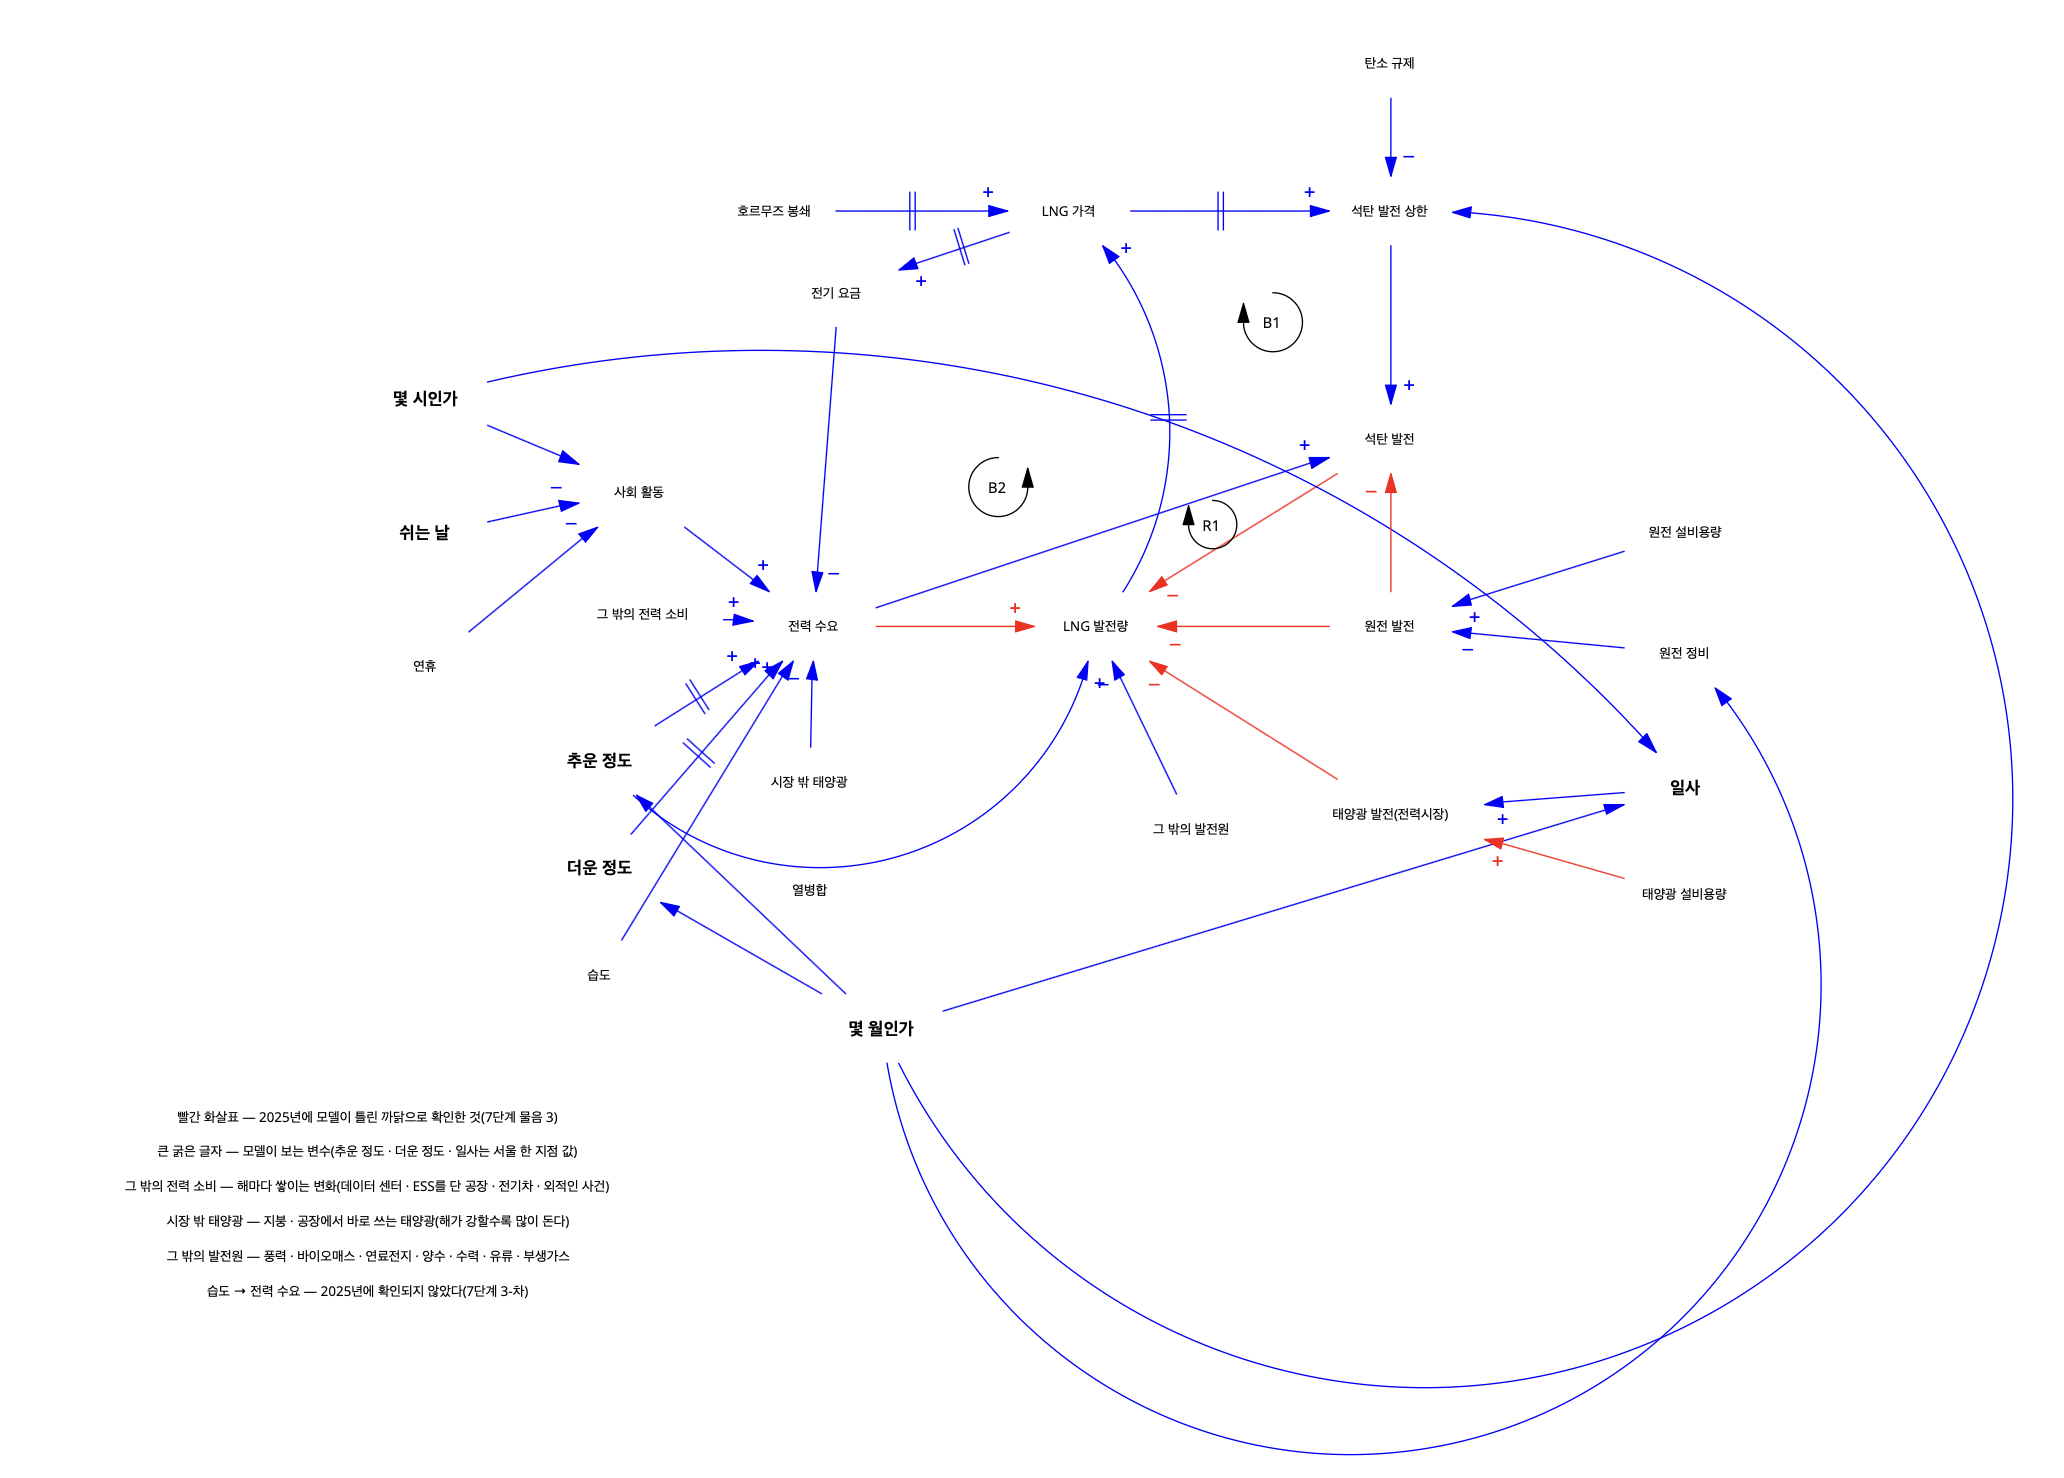

In [399]:
# 7단계 모델링과 검정 · 4-마
if "ROOT" not in globals():                                                          # 준비 ①을 안 돌렸어도 되게, 준비 ①과 같은 방법으로 프로젝트 루트를 찾는다
    import os, pandas as pd
    from IPython.display import display
    ROOT = os.getcwd()
    while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
        ROOT = os.path.dirname(ROOT)
from IPython.display import Image                                                    # 캡처한 그림을 셀 아래에 띄운다
def 보이기7(표):                                                                       # 칸 안의 긴 글자를 「...」로 자르지 않고 격자로 띄운다
    with pd.option_context("display.max_colwidth", None): display(표)

# 1) 7단계 그림(.mdl)에서 변수 · 화살표 · 글을 뽑는다 — 6단계 7-다와 같은 방법에 화살표 색과 글 줄을 더했다
with open(os.path.join(ROOT, "figures", "인과지도_7단계.mdl"), encoding="utf-8") as f:
    줄7 = f.read().split("\\\\\\---///")[1].split("///---\\\\\\")[0].splitlines()      # 그림 정보가 적힌 부분만 잘라 줄로 나눈다
이름7, 굵게7, 화살표7, 글7, 고리표시7 = {}, set(), [], [], []
for i, 줄 in enumerate(줄7):
    칸 = 줄.split(",")
    if 칸[0] == "10":                                                                  # 변수 줄 — 10, 번호, 이름, …
        이름7[칸[1]] = 칸[2].strip('"')
        if "|B|" in 줄: 굵게7.add(칸[2].strip('"'))                                    # 굵게 표시한 변수 = 모델이 보는 변수
    elif 칸[0] == "1":                                                                 # 화살표 줄 — 부호는 7번째 칸, 지연(‖)은 10번째 칸, 색은 12번째 칸
        화살표7.append((칸[2], 칸[3], {"43": "+", "45": "−"}.get(칸[6], "없음"), int(칸[9]) % 2 == 1, 칸[11] == "255-0-0"))
    elif 칸[0] == "12" and int(칸[8]) & 4:                                             # 글 줄 — 적힌 글은 다음 줄에 있다
        (고리표시7 if 칸[7] in ("4", "5") else 글7).append(줄7[i + 1])                  # 모양 번호가 4 · 5면 고리 표시(둥근 화살표), 아니면 그림 옆 글
화살표7 = [(이름7[a], 이름7[b], s, d, r) for a, b, s, d, r in 화살표7]                  # 번호를 이름으로 바꾼다
def 그린것7(a, b):                                                                     # 화살표 하나를 「부호 ‖ 빨강」으로 적는다. 그림에 없으면 「없음」
    for x, y, s, d, r in 화살표7:
        if (x, y) == (a, b): return ("부호 없음" if s == "없음" else s) + (" ‖" if d else "") + (" 빨강" if r else "")
    return "없음"
def 있나7(참): return "있음" if 참 else "없음"
def 글에7(말): return 있나7(any(말 in t for t in 글7))                                   # 그림 옆 글에 그 말이 있나
빨강7 = [("태양광 설비용량", "태양광 발전(전력시장)"), ("태양광 발전(전력시장)", "LNG 발전량"), ("원전 발전", "LNG 발전량"),
         ("석탄 발전", "LNG 발전량"), ("원전 발전", "석탄 발전"), ("전력 수요", "LNG 발전량")]       # 4-나 [표 2] 5번 — 2025년에 틀린 까닭으로 확인한 화살표

# 2) 4-나 [표 2] 아홉 줄 · 4-라 「✍️ 읽고 나서」 ①에서 더한 두 줄 · 채팅에서 정한 고리 이름 — (그릴 것, 어디서 정했나, [(확인할 것, 정한 것, 그림에서 읽은 것)])
정한것7 = [
    ("원전 발전 → 석탄 발전", "4-나 [표 2] 1", [("원전 발전 → 석탄 발전", "− 빨강", 그린것7("원전 발전", "석탄 발전"))]),
    ("그 밖의 전력 소비 → 전력 수요", "4-나 [표 2] 2",
     [("그 밖의 전력 소비 → 전력 수요", "+", 그린것7("그 밖의 전력 소비", "전력 수요")), ("그림 옆 글 「해마다 쌓이는 변화」", "있음", 글에7("해마다 쌓이는 변화"))]),
    ("시장 밖 태양광 → 전력 수요", "4-나 [표 2] 3 · 4-라 ①",
     [("시장 밖 태양광 → 전력 수요", "−", 그린것7("시장 밖 태양광", "전력 수요")),
      ("일사 → 시장 밖 태양광을 적은 그림 옆 글 「해가 강할수록」", "있음", 글에7("해가 강할수록")),
      ("변수 「태양광 발전(전력시장)」", "있음", 있나7("태양광 발전(전력시장)" in 이름7.values())),
      ("변수 「태양광 발전」", "없음", 있나7("태양광 발전" in 이름7.values()))]),
    ("모델은 서울 값으로만 본다", "4-나 [표 2] 4", [("그림 옆 글 「서울 한 지점」", "있음", 글에7("서울 한 지점"))]),
    ("2025년에 틀린 까닭으로 확인한 화살표를 빨간색으로", "4-나 [표 2] 5",
     [(f"{a} → {b}", "빨강", "빨강" if 그린것7(a, b).endswith("빨강") else "빨강 아님") for a, b in 빨강7]
     + [("그 밖의 빨간 화살표", "없음", " · ".join(f"{a} → {b}" for a, b, _, _, r in 화살표7 if r and (a, b) not in 빨강7) or "없음")]),
    ("LNG 가격 → LNG 발전량을 지운다 — 6단계 그림의 가격 고리 B1이 없어진다", "4-나 [표 2] 6",
     [("LNG 가격 → LNG 발전량", "없음", 그린것7("LNG 가격", "LNG 발전량"))]),
    ("LNG 가격 → 전기 요금 → 전력 수요 — 요금 고리 B2와 작은 강화 고리 R1", "4-나 [표 2] 7",
     [("LNG 가격 → 전기 요금", "+ ‖", 그린것7("LNG 가격", "전기 요금")), ("전기 요금 → 전력 수요", "−", 그린것7("전기 요금", "전력 수요")),
      ("고리 표시 B2 · R1", "있음", 있나7({"B2", "R1"} <= set(고리표시7)))]),
    ("추운 정도 → LNG 발전량 — 열병합", "4-나 [표 2] 8",
     [("추운 정도 → LNG 발전량", "+", 그린것7("추운 정도", "LNG 발전량")), ("그림 옆 글 「열병합」", "있음", 글에7("열병합"))]),
    ("습도 → 전력 수요는 두고 「2025년에 확인되지 않았다」를 적는다", "4-나 [표 2] 9",
     [("습도 → 전력 수요", "+", 그린것7("습도", "전력 수요")), ("그림 옆 글 「확인되지 않았다」", "있음", 글에7("확인되지 않았다"))]),
    ("연휴 → 사회 활동", "4-라 「✍️ 읽고 나서」 ①", [("연휴 → 사회 활동", "−", 그린것7("연휴", "사회 활동"))]),
    ("「풍력·바이오매스·연료전지」를 「그 밖의 발전원」으로", "4-라 「✍️ 읽고 나서」 ①",
     [("변수 「그 밖의 발전원」", "있음", 있나7("그 밖의 발전원" in 이름7.values())),
      ("변수 「풍력·바이오매스·연료전지」", "없음", 있나7("풍력·바이오매스·연료전지" in 이름7.values())),
      ("그 밖의 발전원 → LNG 발전량", "−", 그린것7("그 밖의 발전원", "LNG 발전량"))]),
    ("고리 이름을 그림에 있는 순서대로 — 석탄 고리 B1 · 요금 고리 B2 · 강화 고리 R1", "채팅(10-09) — 캡처를 보시고",
     [("그림에 적은 고리 표시", "B1 · B2 · R1", " · ".join(sorted(고리표시7)))]),
]
행 = []
for 번호, (그릴것, 어디, 확인) in enumerate(정한것7, start=1):
    다름 = [f"{무엇} — 그림에서 {그림}" for 무엇, 정, 그림 in 확인 if 정 != 그림]                 # 정한 것과 그림이 다른 것
    행.append({"번호": 번호, "그릴 것": 그릴것, "어디서 정했나": 어디, "확인한 것(정한 것)": " · ".join(f"{무엇} {정}" for 무엇, 정, _ in 확인),
               "같나": "아니오" if 다름 else "예", "다른 것": " · ".join(다름) or "—"})
print("[표 1] 정한 것 열둘(4-나 [표 2] 아홉 줄 · 4-라 「✍️ 읽고 나서」 ① 두 줄 · 채팅에서 정한 고리 이름)이 그림에 정한 대로 들어갔나 — 그림 파일(figures/인과지도_7단계.mdl)에서 읽음")
print("      → 정한 것과 다른 줄:", " · ".join(str(r["번호"]) for r in 행 if r["같나"] == "아니오") or "없음",
      f"| 그림의 변수 {len(이름7)}개 · 화살표 {len(화살표7)}개(6단계 그림은 21개 · 28개)")
보이기7(pd.DataFrame(행).set_index("번호"))

# 3) 고리 — 화살표를 따라가면 처음 변수로 돌아오는 길을 모두 찾는다(6단계 7-다와 같은 방법)
나감7 = {}
for a, b, s, _, _ in 화살표7: 나감7.setdefault(a, []).append((b, s))
고리7 = []
def 따라가기7(처음, 지금, 지나온, 부호들):
    for 다음, s in 나감7.get(지금, []):
        if 다음 == 처음: 고리7.append((지나온 + [처음], 부호들 + [s]))
        elif 다음 not in 지나온 and 다음 > 처음: 따라가기7(처음, 다음, 지나온 + [다음], 부호들 + [s])   # 같은 고리를 두 번 세지 않게
for v in 이름7.values(): 따라가기7(v, v, [v], [])
def 고리이름7(길):                                                                     # 7단계 그림의 고리 이름 — 석탄 발전 상한을 지나면 B1, 전기 요금만 지나면 B2, 전기 요금과 석탄 발전을 다 지나면 R1
    if "석탄 발전 상한" in 길: return "B1"
    if "전기 요금" in 길: return "R1" if "석탄 발전" in 길 else "B2"
    return "이름 없음"
행 = []
for 길, 부호 in 고리7:
    종류 = "부호 없는 화살표가 있음" if "없음" in 부호 else ("B(균형)" if 부호.count("−") % 2 else "R(강화)")
    행.append({"고리": 고리이름7(길), "화살표를 따라간 길": " → ".join(길), "− 화살표 수": 부호.count("−"), "− 수로 정한 종류": 종류,
               "이름의 글자와 같나": "예" if 고리이름7(길)[0] == 종류[0] else "아니오"})
print(f"[표 2] 고리 {len(고리7)}개 — − 화살표가 홀수 개면 B(균형), 짝수 개면 R(강화) · 그림에 적은 고리 표시: {' · '.join(sorted(고리표시7))}")
보이기7(pd.DataFrame(행).set_index("고리"))

# 4) 경계 — LNG 발전량으로 바로 들어오는 원인마다, 모델이 보나(굵게)와 그 원인을 움직이는 변수 가운데 모델이 보는 것(6단계 7-다 [표 4]와 같은 표)
들어옴7 = {}
for a, b, _, _, _ in 화살표7: 들어옴7.setdefault(b, []).append(a)
def 거슬러7(v, 본):                                                                    # v를 움직이는 변수를 화살표를 거슬러 올라가며 모두 모은다
    for a in 들어옴7.get(v, []):
        if a not in 본 and a != "LNG 발전량": 본.add(a); 거슬러7(a, 본)              # LNG 발전량을 거쳐 되돌아오는 길(고리)은 뺀다
    return 본
행 = [{"LNG 발전량으로 바로 들어오는 원인": a, "부호": "부호 없음" if s == "없음" else s, "모델이 보나": "봄" if a in 굵게7 else "못 봄",
       "이 원인을 움직이는 것 가운데 모델이 보는 것(LNG를 거쳐 되돌아오는 길은 뺌)": " · ".join(sorted(거슬러7(a, set()) & 굵게7)) or "없음"}
      for a, b, s, _, _ in 화살표7 if b == "LNG 발전량"]
print(f"[표 3] LNG 발전량으로 바로 들어오는 원인 {len(행)}개 가운데 모델이 보는 것 {sum(r['모델이 보나'] == '봄' for r in 행)}개"
      " — 6단계 7-다 [표 4]와 같은 표(6단계 그림은 6개 가운데 0개)")
보이기7(pd.DataFrame(행).set_index("LNG 발전량으로 바로 들어오는 원인"))

그림파일7 = os.path.join(ROOT, "figures", "인과지도_7단계.png")
if os.path.exists(그림파일7): display(Image(filename=그림파일7, width=900))           # Vensim에서 캡처해 저장하신 그림
else: print("그림 파일(figures/인과지도_7단계.png)이 아직 없습니다 — Vensim에서 캡처해 저장하신 뒤 이 셀을 다시 돌려 주세요")

### ✍️ 내 답변

이 셀과 그림에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까? 그림에서 다르게 그릴 곳이 있으면 같이 적어 주세요.

답: 인과지도야. 화살표는 영향을 주는 관계를 뜻하고 화살표의 +/-는 각각 방향을 의미하지. +는 같은 방향, -는 서로 반대방향을 의미해.

- 루프는 우리가 여기선 2개의 균형 루프와 1개의 강화루프가 보이네. 빨간 줄이나, 해당하는 내용은 너가 디테일하게 추가한 것으로 확인했어.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 화살표는 원인이 결과에 영향을 준다는 뜻이고, +는 같은 방향, −는 반대 방향입니다. 고리는 균형 둘(B1 석탄 고리 · B2 요금 고리)과 강화 하나(R1)입니다.
> 2. 하나만 더하면 — +와 −는 「다른 것이 그대로일 때」 어느 쪽으로 움직이나만 말하고, 얼마나 큰지나 2025년에 확인했는지는 말하지 않습니다. 확인했는지는 색(빨강 = 2025년에 확인)과 근거(「못 봄」)로 따로 적었습니다.
> 3. 다르게 그릴 곳은 적지 않으셔서 그림은 그대로 둡니다.

**「+는 같은 방향, -는 서로 반대방향을 의미해.」**

- 맞습니다. 원전 발전 → 석탄 발전(−)이면, 다른 것이 그대로일 때 원전이 더 돌면 석탄이 덜 돈다는 뜻입니다.
- 실제로는 여러 화살표가 한꺼번에 움직입니다. 2025년 1 ~ 4월은 원전이 더 돌았는데도 LNG가 모델 생각보다 더 돌았는데, 석탄이 그보다 더 많이 덜 돌았기 때문이었습니다(3-하 · 3-거). 원전 발전 → LNG 발전량(−)이 틀린 것이 아니라, 석탄 쪽 화살표가 같이 움직인 것입니다.

**「2개의 균형 루프와 1개의 강화루프」**

- 맞습니다. [표 2]의 「− 화살표 수」가 B1 · B2는 하나(홀수)라 균형, R1은 둘(짝수)이라 강화입니다.
- R1이 강화 고리인 까닭 — LNG 값이 오르면 몇 달 뒤 요금이 올라 수요가 줄고, 수요가 줄면 석탄도 조금 덜 돌리고, 석탄이 덜 돌면 그만큼 LNG가 더 돌아 LNG 값을 더 올리는 쪽으로 돕니다. 수요가 줄 때 LNG가 바로 덜 도는 B2가 더 큰 쪽이라고 봅니다(판단) — 4-다에서 낮에 줄어든 몫을 LNG가 822, 석탄이 408 나눠 받았습니다.

**「빨간 줄이나, 해당하는 내용은 너가 디테일하게 추가한 것으로 확인했어.」**

- [표 1] 열두 줄이 모두 「예」입니다. 빨간 화살표 여섯은 2025년에 모델이 틀린 까닭으로 확인한 것(물음 3)이고, 새로 더한 화살표 가운데 연휴는 2025년 3월 1 · 2일(3-자)을 근거로, 나머지(그 밖의 전력 소비 · 시장 밖 태양광 · 요금 · 열병합)는 근거 「못 봄」으로 그었습니다.

📘 필기 범위 밖(시스템 다이내믹스 인과지도) — 화살표의 부호는 다른 것이 그대로일 때 원인과 결과가 같은 쪽으로 움직이나(+) 반대로 움직이나(−)만 나타내고, 영향의 크기나 확인했는지는 부호로 나타내지 않는다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 다르게 적을 곳은 뭐 찾아서 없는 것 같은데??

#### 물음 4에서 알게 된 것

1. 2025년에 모델이 틀린 까닭 여섯 가운데 다섯은 그림의 화살표로 이어집니다 — 늘어난 태양광 설비 · 원전과 석탄이 평소와 다르게 돈 것 · 원전과 석탄이 서로 반대로 돈 것(원전 → 석탄) · 그날의 수요 · 연휴. 30도 넘는 시각과 토요일은 모델이 보는 변수(더운 정도 · 쉬는 날)에서 덜 맞힌 곳이라 화살표 없이 11단계 한계에 둡니다.
2. 6단계 그림의 가격 고리(LNG 가격 → LNG 발전량)는 지웠습니다. 싼 발전소부터 돌리고 LNG가 남는 만큼을 채우는 이 시장에서는 LNG 값이 석탄 상한(B1)과 전기 요금(B2)을 거쳐서만 LNG 발전량을 바꿉니다. 그래서 9단계에서 2026년 차이 옆에 놓는 고리는 B1 · B2와 R1입니다.
3. LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나(열병합)입니다. 나머지 다섯(전력시장 태양광 · 수요 · 원전 · 석탄 · 그 밖의 발전원)은 모델이 직접 보지 않습니다. 그 가운데 넷(전력시장 태양광 · 수요 · 원전 · 석탄)은 모델이 보는 변수(기온 · 몇 시 · 몇 월 · 날 종류 · 일사)를 거쳐 평소에 움직이던 만큼만 알고, 그 밖의 발전원은 모델이 보는 변수와 이어지지 않습니다(4-마 [표 3]). 2026년 차이에는 이 다섯이 평소와 다르게 움직인 만큼이 함께 들어 있습니다.

#### 끝나는 조건 → 나온 것

| 끝나는 조건(머리 칸 첫 줄) | 나온 것 | 어디서 |
|---|---|---|
| 까닭 여섯마다 그림의 어느 화살표인지 정한다 | 다섯은 화살표로 이어진다. 30도 넘는 시각과 토요일은 화살표 없이 11단계 한계로 | 4-나 [표 2] · 「긋지 않는 것」 |
| 그림에 없는 화살표를 더한다 | 일곱을 더했다 — 원전 → 석탄 · 그 밖의 전력 소비 → 수요 · 시장 밖 태양광 → 수요 · LNG 가격 → 전기 요금 · 전기 요금 → 수요 · 추운 정도 → LNG(열병합) · 연휴 → 사회 활동 | 4-마 [표 1] 1 · 2 · 3 · 7 · 8 · 10 |
| 맞지 않는 화살표를 지운다 | LNG 가격 → LNG 발전량(6단계 그림의 가격 고리 B1)을 지웠다 | 4-마 [표 1] 6 |
| 정한 대로 그렸나(4-마, 결과를 보기 전에 적은 읽는 법) | 열두 줄 모두 「예」 · 고리 셋 모두 이름의 글자와 부호가 맞음 · 가격 고리 없음 | 4-마 [표 1] · [표 2] |

#### ① 물음 4를 여기서 끝낼까요?

머리 칸 첫 줄에 적은 끝나는 조건은 위 표대로 채워졌고, 바꿀 것은 없습니다. 끝내면 📌 물음 4 결론 칸을 쓰고, 7단계를 마무리하는 일(기계 검사 · 개념을 말로 설명하기 · README)로 갑니다.

답: 뭐 사실 뭐 더 추가하거나 하는게 없어서 뭐 적을것도 없는데??

### 클로드 답변

> **짧게**
> 1. 맞습니다. 다르게 적을 곳은 없습니다. 위 「끝나는 조건 → 나온 것」 표의 네 줄이 다 채워졌고, 4-마에서 그린 그림도 정한 대로였습니다.
> 2. 이어서 볼 것은 없습니다. 4-가 아래에 까닭 여섯을 표로 적은 답변을 읽어 보신 뒤, 위 ①에 물음 4를 끝낼지 한 줄 적어 주세요. 끝내면 📌 물음 4 결론 칸을 쓰고 7단계 마무리로 갑니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 딱히 없어. 

## ✍️ 7단계를 닫으며 — 채점 결과와 8단계로 넘기는 것

*(물음을 돌면서 채웁니다. 셋으로 적습니다 — ① 내가 던진 물음과 그 결과 표 ② 8단계로 넘기는 것 ③ 인과지도(모델이 못 본 고리)와 다음 단계로 넘길 것. ① 표는 물음이나 아이디어가 나올 때마다 바로 한 줄씩 넣습니다.)*

### ① 내가 던진 물음과 그 결과

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 10-05 | (클로드 판단 — 절차) 6단계 닫는 칸 ③에서 7단계로 넘어온 줄과, README 「되돌아올 수 있는 곳」·5단계 결론 칸·지침에 적힌 7단계 일을 물음 넷으로 나눴다. 2025년 LNG 없이 할 수 있는 확인(코드가 6단계와 같은가 · VIF · 잔차 가정)은 채점보다 먼저 물음 1에 모았다 | 6단계 닫는 칸 ②·③ · 지침 11단계 표 7단계 칸 · 볼트 「빅데이터 분석의 순서」 7단계 절(회귀 다섯 단계: 경향성 확인 → 모델링 → 적합성 검정 → 잔차 가정 검토 → 모델 확정) | 넘어온 일 열셋 가운데 열둘은 이 노트북의 물음 1~4에서 하고, 하나(2023~2025년으로 다시 배운 모델)는 9단계 첫 셀에서 한다(맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 표) | 물음 1을 열었다 |
| 10-05 | 「이대로 간다는건 뭔 말이야? 정해진대로 가는거 아닌가??」 · 「7단계의 물음에 대해선 나도 어떤 값들이 들어오고 나가는지 복잡해서, 앞 단계에서 결정된 것으로 넘어간다?? 이정도밖에 모르겠는데?」(표지 아래 「✍️ 7단계의 물음」 칸을 보고 채팅에서) | — 진행 흐름에 대한 물음이라 셀이 없다 | 맞게 읽으셨다. 7단계는 6단계에서 정한 열 · 모델 · 기준선 · 「잘 맞힌다」의 기준을 그대로 돌리고, 새로 정하는 것은 물음 2의 하나(2025년 채점에서 모델이 기준선을 이기면 쓰고, 못 이기면 안 쓴다)다. 그 칸은 정할 것이 없는데 클로드가 확인을 받을 것처럼 적었다 | 표지 「데이터와 모델」에 「7단계의 입력과 결과」 표를 넣고, 확인을 묻던 칸에 하신 말을 옮기고 클로드 답변을 달았다 |
| 10-05 | 「지금 단계는 아래에서 정한 것들을 모델링하고 어떤걸 정할지 판단하는 단계지??」(위 줄의 답을 듣고 채팅에서) | — 진행 흐름에 대한 물음이라 셀이 없다 | 거의 맞다. 정해 둔 것으로 모델을 만들어 2025년을 채점하고, 그 결과로 모델을 쓸지 말지를 정한다. 어디서 틀리는지 보는 것(물음 3·4)은 결과를 읽고 적는 일이고, 모델 넷 가운데 하나를 고르는 것은 8단계다 | 「✍️ 7단계의 물음」 칸 아래 「읽고 나서」에 옮기고 클로드 답변을 달았다 |
| 10-05 | 「그러면 우리가 정한 것들도 추가적으로 모델링하거나 결정계수 보면서 다듬어서 결정하는 것으로 이해했어」(「✍️ 7단계의 물음」 아래 「읽고 나서」) | 지침 「누수를 막습니다」 ⓒ | 2025년 결정계수를 보고 열이나 설정을 다듬으면, 2025년 채점이 처음 보는 해의 성적이 아니게 된다. 다듬는 일은 6단계에서 2024년으로 끝냈고, 2025년 결정계수로 하는 일은 물음 2(모델을 쓸지 말지)와 8단계(모델 넷 가운데 하나 고르기)다 | 「✍️ 7단계의 물음」 아래 클로드 답변에 덧붙였다 |
| 10-05 | 「3번 그림은 상관성이 1은 당연히 1이어야 하는데 … 그 정도가 그리 높지 않으니까 괜찮다는 의미인가??」(1-다 「✍️ 내 답변」) | 1-다 오른쪽 그림(몇 시간 떨어진 잔차끼리의 상관) · 1-라 [표 1] 「독립성 — 더빈-왓슨 통계량」 | 반대였다 — 막대가 높을수록 독립성이 깨진 것이다. 선형회귀 잔차의 상관이 1시간 떨어지면 0.92, 24시간 0.43, 일주일 0.29이고, 더빈-왓슨은 0.16이다(2 근처면 지켜짐) | 모델은 그대로 두고 읽는 방법을 바꾼다(맨 아래 「물음 1 — 자세한 내용」 「잔차 가정이 깨지면」 표) — 8단계에서 p값으로 변수를 고르지 않고, 9단계에서 한 달 오차 범위를 2025년 달마다 실제로 틀린 양으로 본다 |
| 10-05 | 「표2를 보면 검정상 0.05보다 작으니까 결국 대립가설을 채택하겠지. 그러면 아마 귀무가설은 같다? 일 테니까 같지 않아서 사용할 수 있겠다로 결론내릴 수 있지 않을까??」(1-라 「✍️ 내 답변」) | 1-라 [표 2]와 그 제목 줄(「0.05보다 작으면 「가정이 깨졌다」로 읽는다」) | 반대였다 — 브로이시-페이건과 자크-베라의 귀무가설은 「가정이 지켜진다」라서, p값이 0.05보다 작으면 가정이 깨졌다는 뜻이다. 시각이 1만 6천 개쯤이라 작은 차이도 p값이 0에 가깝게 나온다 — 왜도 +0.22는 표준오차(0.019)의 열 배가 넘지만 크기는 작다 | 1-라 답변에 귀무가설의 방향과 「유의한 것과 큰 것」을 적었다 |
| 10-05 | 「이게 어느정도여야 적합한 것인지 이정도의 수치면 적합하다고 해서 진행할 수 있는것인지는 내가 잘 모르겠거든??」(1-라 「✍️ 내 답변」) | 맨 아래 「물음 1 — 자세한 내용」 「잔차 가정이 깨지면 무엇이 달라지나」 표(결과를 보기 전에 적음) | 한 경계로 정해진 숫자는 없다. 이 프로젝트는 「깨졌나」보다 「깨져서 무엇이 달라지나」로 본다. 모델의 예측은 그대로 쓰고, p값과 오차 범위를 읽는 방법이 바뀐다 | 1-라 아래 「읽고 나서」에 「기준 → 나온 것」 표를 두고, 바꿀 것 없이 물음 2로 갈지 여쭸다 |
| 10-05 | 「그러면 나눈 형태로 진행하면 되겠네?」(1-나 「읽고 나서」) | 6단계 닫는 칸 ② 「시험할 모델」 | 나눈 형태만으로 가는 것이 아니다. 선형회귀 둘 다 VIF를 통과해서 둘 다 물음 2에서 채점하고, 모델 넷 가운데 하나를 고르는 것은 8단계다 | 1-나 아래 답변에 적었다 |
| 10-05 | 「이건 해결할 방법이 없는건가? 우리가 가진 데이터, 모델의 한계인가?」(1-다 「읽고 나서」) · 「해결할 수 있는 방법을 찾아줘. 없다면 해석을 제대로 해야겠네..」(1-라 「읽고 나서」) | 1-마(잔차의 이어짐을 같이 배우는 선형회귀로 2023년으로 배워 2024년 맞히기) · 1-바(이어짐을 감안한 표준오차와 p값) — 방법은 클로드 제안 | 잔차의 이어짐을 같이 배운 선형회귀는 2024년 결정계수가 −0.0196 · −0.0237로 오히려 낮았다(1-마 [표 1] 「차이」). 이어짐까지 감안하면 표준오차가 2.1~4.4배 커지지만, p값이 0.05 아래였던 다섯 열은 그대로 아래였다(1-바 [표 1] · [표 2]) | 1-마 · 1-바를 넣었고, 1-바 아래 「읽고 나서」에서 모델과 입력을 그대로 두고 물음 2로 갈지 여쭸다. 지난 시각의 LNG를 넣는 방법은 2026년 차이를 지워서 넣지 않는다(6단계 물음 6) |
| 10-05 | 「표 더운쪽 3시간 바뀐만큼이 다른 건 전부 0인데 이 수치가 어떻게 봐야할지 잘 모르겠다..?」 · 「감안했을 때 최적이라는 의미인가??」(1-바 「✍️ 내 답변」) | 1-바 [표 2] 「3시간 동안 바뀐 만큼 (더운 쪽)」 줄 · 6단계 5-마(3시간 전 기온 두 열을 빼도 2024년 결정계수 −0.0016) | 최적이라는 뜻이 아니다. p값 0.75 · 0.88은 그 열의 기울기(−8 MWh)가 0과 구별되지 않는다는 뜻이고, 그 열은 LNG를 맞히는 데 거의 보태지 않는다 | 6단계 물음 5에서 이미 넣은 열은 그대로 두기로 해서 지금은 그대로 두고, 8단계 효율성에서 다시 본다(닫는 칸 ②) |
| 10-05 | 「오히려 너무 짧게 학습해서 너무 변동이 빠른가? 그래서 틀리는건가?」(1-마 「읽고 나서」) | 1-마 [표 1](기울기는 비교하지 않았다) | 그 뜻이다 — 몇 시간 사이의 변화를 주로 배워서, 한 해 앞을 입력만으로 맞힐 때 덜 맞는다(판단) | 1-마 아래 답변에 적었다 |
| 10-05 | 「그러면 결국 해석의 방향을 어떻게 수정하는수밖에 없는건가? 모델링과 데이터 셋의 한계로 보고??」(1-바 「읽고 나서」) · 「너가 보기에 검토해서 객관적으로 가장 적합하게 진행하는 수밖에 없어 보이는데..」(채팅) | 로렌스버클리 연구소의 에너지 절감량 불확도 비교 연구(Granderson 외) — ASHRAE 지침 14의 보정식(n′ = n × (1 − ρ) ÷ (1 + ρ))도 시간별 모델에서는 범위를 좁게 잡는다 | 그렇다 — 모델은 그대로 두고 숫자를 읽는 방법을 바꾼다. 같은 구조의 에너지 절감량 검증에서도 시간별 모델의 잔차가 이어지는 것은 흔하고, 모델보다 오차 범위로 다룬다 | 클로드 판단으로 물음 1을 닫았다(📌 물음 1 결론 칸). 9단계 오차 범위는 2025년 달마다 실제 오차로 보고, README 한계에 적었다. 물음 2를 열었다 |
| 10-05 | 「방향은 할 수 있는 최선인거지?」 · 「그러면 그냥 하면 되는거야?」(채팅) · 「일단 복잡하긴 한데 적합한 방향, 최선의 방향으로 가보자. 뭐 모든게 완전할 수는 없으니까.」(1-바 「✍️ 다시 읽고 나서」) | 가장 강한 반론을 세워 봄(클로드 판단) · 1-다 오른쪽 그림(몇 시간 떨어진 잔차끼리의 상관) · 1-바 [표 1] | 큰 방향은 맞다. 클로드가 정한 세부에 약한 곳 셋 — 1-바가 일주일 떨어진 짝까지만 감안했다 · 결정계수 차이가 문턱보다 작으면 우연과 가르기 어렵다 · 9단계의 오차 범위를 달 열두 개로 잡는다 | README 한계에 셋을 적고(둘째는 2-가 결과를 보기 전에), 물음 2를 그대로 돌리셨다. 1-사는 물음 2를 닫은 뒤에 더한다 |
| 10-05 | 「2-가는 모델링에 25년도꺼 사용하지는 않은거지? 지금까지 모델링한것을 기준으로 25년본것이지??」(채팅) | 2-가 코드 | 2025년 LNG는 배우는 데 쓰지 않는다. 6단계에서 정한 조합으로 2023·2024년을 배워 새로 만든 모델이다. 2025년 LNG는 셀 맨 위에서 읽지만 맨 끝 비교에만 쓴다 | 2-가 「✍️ 내 답변」 맨 아래에 옮기고 답변에 적었다. 물음 2 머리 칸의 「맞힌 뒤에 처음 읽는다」를 코드 순서대로 고쳤다 |
| 10-05 | 「보면 4개 모두 전부 결정계수가 올라가네? 그러면 더 모델링이 적합하게 되고 있다고 봐도 좋을 것 같은걸?」(2-가 「✍️ 내 답변」) | 2-가 [표 1] · [표 2] · 1-가 [표 1] · 6단계 물음 2 | 기준선 「달·시각·날별 평균」보다 높다는 뜻으로는 맞다(+0.0329 ~ +0.0875). 2024년보다는 모델 넷과 기준선이 모두 내려갔고, 선형회귀 둘이 더 내려갔다(−0.040 · −0.052, 트리 계열과 기준선은 −0.025 ~ −0.027) | 2-가 답변에 2024 · 2025년 표를 넣었다. 선형회귀가 어디서 더 틀렸는지는 물음 3에서 본다 |
| 10-05 | 「일단 범위 밖을 뺀다면 당연히 나는 다 좋아질거라고 생각했는데 그렇진 않네? 오히려 전부다 떨어졌구나?? 신기하네」(2-나 「✍️ 내 답변」) | 2-나 [표 1] · [표 2] | 모델 넷의 결정계수는 0.002 안쪽으로 내려가고 평균 절대 오차는 그대로였다. 빼낸 시각이 LNG가 크게 높은 한여름 낮이라 결정계수의 분모(흩어짐)가 줄어서다(판단) | 2-나 답변에 지어낸 숫자 예(10 · 20 · 30 · 100)를 넣었다 |
| 10-05 | 「뭔가 그러면 기존 방식의 데이터가 적어서 생긴거라고 보는게 맞지않을까 싶은데..」 · 「더 현실적인 방식으로 맞아들어가고 있다고 느껴지는데?」(2-다 「✍️ 내 답변」) | 2-다 [표 1] · README 한계(랜덤포레스트 설정) | 2024년으로 고른 설정의 나아짐(+0.0083)이 2025년에는 +0.0006으로 거의 남지 않았다. 둘 다 떨어진 까닭(배운 데이터가 달라서 / 2025년이 달라서)은 이 셀로 가를 수 없다 | 설정은 미리 정한 대로 그대로 둔다. 2025년을 한쪽으로 틀렸는지는 물음 3에서 본다 |
| 10-05 | 「결국 전체적인 25년까지 학습시켰을 때 최적의 결정계수를 보여주는 것이 더 중요하겠지?」 · 「그러면 25년까지 학습시킨 경우 다시 회귀모델을 수정하는건 26년 예측에 사용하는건 검증이라는 초기의 목적과 다르니까 적합하진 않은 방향이겠지??」(2-가 「✍️ 읽고 나서」) | 지침 「누수를 막습니다」 ⓒ · 6단계 물음 5 | 2025년을 보고 모델을 고치지 않는다는 것은 맞다. 2023~2025년으로 다시 배운 모델에는 결정계수를 낼 해가 남지 않는다 — 그 모델을 믿는 근거는 같은 조합으로 2025년을 맞힌 2-가다 | 2-가 「읽고 나서」 아래 답변에 적었다 |
| 10-05 | 「많이 내려갔다는 그 수치 자체가 중요한건 아니라고 생각해.」(2-가 「✍️ 읽고 나서」) | 2-가 [표 2] · 6단계 물음 2 | 물음 2의 결정에는 쓰이지 않는다. 9단계에는 쓰인다 — 2025년의 커진 오차가 「평소에 틀리는 정도」가 되고, 2024년 숫자로 잡았으면 2026년 차이를 실제보다 크게 읽었을 것이다 | 2-가 「읽고 나서」 아래 답변에 적었다 |
| 10-05 | 「그러면 그냥 이대로 뭐 포함시키지 않고 진행하는건가??」 · 「뺀거면 뺀 이유가 잘 적히고 논리만 잘 적히면 되는거고.」(2-나 「✍️ 읽고 나서」) | 6단계 물음 3 결론 칸 | 아무것도 빼지 않는다 — 본 숫자는 모든 시각으로 낸 것이고, 2-나는 빼도 결론이 같은지 본 확인이다 | 물음 2 결론 칸 「같이 정한 것」 1에 적었다 |
| 10-05 | ① 「높은 것, 즉 현실적으로 예측력이 높고 현실을 잘 반영하는 것을 골라야겠지??」 · 「점차 현실적인 방향으로 맞춰들어가다 보니까 이제 수정이 들어가는거지」(2-다 「✍️ 읽고 나서」) | 2-가 [표 1] · 지침 8단계 칸 | 모델 넷 모두 쓴다. 고르는 것은 8단계이고, 말씀하신 것을 설명력 → 안정성 → 효율성의 첫 줄로 옮겼다. 「수정」은 숫자가 바로잡힌 것이고 모델은 바꾸지 않는다 | 물음 2를 닫았다(📌 물음 2 결론 칸). 약속한 대로 1-사를 물음 1에 더했다 |
| 10-05 | 「보는 범위를 넓혔을 때인데..추운쪽 4주로 늘리면 관계가 있다?? 이정도 보이고 나머진 거의 같네」(1-사 「✍️ 내 답변」) · 「딱히 뭐 모르겠다 어렵네」(채팅) | 1-사 [표 2] 「4주 (672시간)」 칸 | 범위를 넓혀도 「관계가 있다」가 그대로다 — 「3시간 동안 바뀐 만큼 (추운 쪽)」의 p값이 0.0018로 커졌지만 0.05보다 훨씬 작고, 나머지 넷도 0.05 아래다 | 1-사 답변에 가져갈 한 줄(넓혀도 결론이 같다)을 적고, 그 아래 ①에서 「바꿀 것 없음」을 확인받는다 |
| 10-05 | 「그러네 넓게 감안해도 lng와 관계가 있다는 결론..」 · ① 「응. 객관적으로 최선의 방향으로 가자.」(1-사 「✍️ 읽고 나서」) · 「뭐 몰라서 그냥 알겠다고 했어」(채팅) | 1-사 [표 2] | 결론은 맞게 읽으셨다. 몰라서 넘어간 부분(표준오차를 왜 범위를 바꿔 가며 다시 내나)은 7단계를 닫을 때 개념 질문에서 다시 짚는다 | 물음 1을 다시 닫았다(📌 물음 1 결론 칸 「같이 정한 것」 3을 4주로 고침) |
| 10-05 | (클로드 판단 — 절차) 물음 3을 열면서, 앞 단계에서 「7단계에서 이렇게 틀리면 다시 본다」고 미뤄 둔 다섯 가지(부산 기상 · 일사를 달마다 · 월 × 시간대 · 불쾌지수 · 태양광 설비를 아는 열)를 한 표로 모으고, 결과 셀보다 기준을 먼저 여쭙기로 했다 | 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 · README 「되돌아올 수 있는 곳」 · 6단계 물음 3 | 지금부터 무엇을 바꾸면 2025년을 보고 바꾸는 것이 된다 | 3-가에서 ① 입력을 바꿀지, 9단계에서 조심해 읽을 곳으로 적어 둘지 ② 「한쪽으로 틀렸다」를 무엇으로 볼지를 여쭙는다 |
| 10-06 | 「그러면 후자가 더 맞는 방식 아닌가?? 너가 말한 것처럼?」(채팅에서 다시 여쭌 3-가 ①에 답하심 → 3-가 「✍️ 내 답변」에 옮김) | 결과를 보기 전에 정함 · 지침 「누수를 막습니다」(2025년 채점을 보고 모델을 고치면 그 채점은 처음 보는 해의 성적이 아니다) | 맞다 — 가장 강한 반론(어느 달을 늘 같은 쪽으로 틀리면, 2026년 그 달의 차이 가운데 얼마가 모델이 평소에도 틀리는 만큼인지 가르기 어렵다)도 2025년 같은 달에 틀린 양을 옆에 놓으면 풀린다. 지금 고치면 그 양을 바르게 보여 줄 해가 남지 않는다 | 모델은 고치지 않고 2025년에 틀린 곳을 적어 둔다. 앞 단계에서 미뤄 둔 다섯 가지는 다시 넣어 보지 않고 11단계 한계에 남긴다. 3-가 ②(「한쪽으로 틀렸다」를 무엇으로 볼지)는 정할 일이 없어져 뺐고, 6단계에서 정한 태양광 점검은 기록으로만 본다(둘 다 클로드 판단 — 3-가 「✍️ 읽고 나서」에서 확인받는다) |
| 10-06 | (클로드 판단 — 절차) 결과 셀 둘을 넣었다 — 3-나 어느 쪽으로 틀렸나(달마다 · 시간 묶음마다 평균 잔차) · 3-다 얼마나 틀렸나(평균 절대 오차와, 기준선보다 더 틀린 모델) | 2-다 「✍️ 읽고 나서」(「둘 다 떨어진게 데이터가 달라서인지, 25년이 달라서인지는 모르고. 물음 3에서 본다고 이해했어」) · 6단계 2-다(2024년에 선형회귀가 4 · 5 · 7 · 11월에 기준선보다 더 틀림) · 6단계 3-다(시간 묶음 다섯) | 3-나 — 다섯 방법이 12달 가운데 11달 같은 쪽으로 틀렸고, 「한 해」는 모델 넷 −44 ~ +44, 하루 안에서는 낮 −, 저녁·밤 + · 3-다 — 선형회귀가 일곱 달(크게는 7 · 8월)과 0~9시에 기준선보다 더 틀렸다 | 3-나 · 3-다 아래에 답변을 달았다(아래 두 줄) |
| 10-06 | 「좋아. 완벽한 모델링이 중요하지만, 그것이 가능하지 않다면 왜 어떤 것을 뺀지 설명하고 한계를 적는게 중요하지. 끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지.」(3-가 「✍️ 읽고 나서」) | — 확인하신 칸이라 셀이 없다 | 3-가에서 정한 것(틀린 곳이 나와도 모델은 고치지 않고 적어 둔다)과 클로드가 정한 둘(② 빼기 · 태양광 점검은 기록으로만)을 확인하셨다 | 그대로 간다. 이 말은 11단계 한계 문단에 쓴다 |
| 10-06 | 「표1은 어느 한 모델이 완벽하진 않네. 월별로 조금씩 더 비슷하거나 아닌게 갈리는걸?」 · 「선형회귀는 특정 시간대에 오차가 조금 더 큰 것 같고, 트리 모델들은 그런 편차가 적은 것 같아 보여.」(3-나 「✍️ 내 답변」) | 3-나 [표 1] · [표 2] · 3-다 [표 2] | 다섯 방법이 같은 달에 같은 쪽으로 틀렸다(12달 가운데 11달 — 2·4월 +1,877 ~ +3,050, 7·9·12월 −901 ~ −2,879). 「한 해」는 모델 넷 −44 ~ +44로 0에 가깝다. 7월은 모델 넷이 기준선보다 더 많이 틀렸다(−1,686 ~ −2,652 대 −901). 하루 안에서는 다섯 모두 낮(10~15시) −646 ~ −846, 저녁·밤(16~23시) +535 ~ +889. 선형회귀가 시간대에 따라 더 틀린 것은 크기(3-다 [표 2]) 쪽이다 | 3-나 답변에 적었다. 낮 −와 저녁 +는 3-라 · 3-마(태양광 점검)로, 7월은 다음에 넣는 「추운 날 · 더운 날」 셀로 이어 본다 |
| 10-06 | 「지금 표1은 기준선마다 더 틀린 선형회귀를 적은것이고」 · 「10~23시까지는 오히려 회귀가 덜 틀린거라는 의미인가??」 · 「그러면 0~9시 부분만 수정하면 선형회귀가 더 잘 만들어질 수 있다는 건가??」(3-다 「✍️ 내 답변」) | 3-다 [표 1] · [표 2] · 2-가 [표 2] | 맨 오른쪽 칸은 모델 넷을 다 본다 — 기준선보다 더 틀린 달이 선형회귀 일곱(크게는 7월 +469 · 8월 +211, 나머지 다섯 달은 36 ~ 72 MWh), 랜덤포레스트 하나(12월), 나머지 둘은 없다. 10~23시는 넷 모두 기준선보다 덜 틀렸고 선형회귀는 0~9시에만 더 틀렸다. 0~9시를 기준선만큼으로 줄여도 한 해 2,652 → 약 2,527로 나머지 셋(2,364 ~ 2,503)보다 크다. 기온을 시간대마다 따로 배운 기온 × 시간대 선형회귀는 0~5시 2,887 → 2,594(교호작용) | 고치지 않는다(3-가) — 고친 쪽은 6단계에서 미리 골라 둔 기온 × 시간대 선형회귀로 이미 있다. 8단계 안정성의 근거와 11단계 한계에 적었다(닫는 칸 ② · ③) |
| 10-06 | (클로드 판단 — 절차) 태양광 점검 셀 둘을 넣었다 — 3-라 날마다 「낮 평균 잔차 − 밤 평균 잔차」의 평균과 95% 구간(6단계 3-라와 같은 방법, 모델 넷) · 3-마 그 값을 달마다 평균 내고 2024년에 세 모델이 같은 부호였던 달(6단계 3-마)과 비교 | 6단계 물음 3 결론 칸 「남은 것」 · 6단계 닫는 칸 ③ · 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 · 3-가(기록으로만) | 3-라 — 넷 모두 날마다 낮 − 밤 평균 −822 ~ −1,164, 95% 구간이 모두 0 아래(2024년에는 셋 모두 0이 들어 있었다) · 3-마 — 12달 가운데 0보다 아래인 달 선형회귀 9 · 나머지 셋 10(2024년 11달 가운데 4 ~ 6) | 6단계 기준 둘에 넷 모두 걸렸다. 3-가대로 고치지 않고 11단계 한계와 9단계에 적는다(아래 세 줄) |
| 10-06 | 「그러네 5월만 다르고 다른건 같은 경향성을 보이네. 그러면 그것을 보는거고, 나지로 모델에 따라 더 틀리거나 하는건 너가 이어서 보는거구나. 이해했어.」(3-나 「✍️ 읽고 나서」) · 「어렵긴한데, 결국 5월에 차이가 나는 이상한건 보는거고, 그것 빼고는 각각의 어떤 이유라고 할만한 것들이 있는거네?」(3-다 「✍️ 읽고 나서」) | 3-나 [표 1] 5월 줄 | 5월은 다섯 모두 0에 가까워(−239 ~ +197) 부호가 갈린 것이라 따로 보지 않는다. 다섯이 같이 크게 벗어난 달에는 입력에 없는 이유가 있다고 본다(판단) | 이 자료로 볼 수 있는 것(원전 · 더운 날 · 석탄)은 뒤 셀(3-아 · 3-바 · 3-하)에서, 이 자료에 없는 LNG 가격은 9 · 10단계에서 본다 |
| 10-06 | 「그러면 신뢰구간을 정해놓고, 25년도가 그 구간에서 얼마나 벗어난 것인지를 보는건데, 결과를 보면 넷 다 낮보다 밤을 더 많게 맞혔다?? 많게 맞힌게 모델링 결정계수가 높다는 의미라면, 낮에는 특정 변수들의 영향력이 더 커서 그런건가?」(3-라 「✍️ 내 답변」) | 3-라 [표 1] · 6단계 3-다(2025년 태양광 설비가 2023·2024년 평균보다 약 20% 많다) | 「많게 맞혔다」가 「더 잘 맞혔다」로 읽혔다 — 클로드가 쓴 말 탓이다. 뜻은 「예측이 실제보다 컸다」이고, 결과는 넷 모두 밤보다 낮에 예측이 실제보다 더 컸다(낮과 밤을 거꾸로 읽으셨다). 구간은 미리 정한 것이 아니라 2025년 365일로 계산한 것이고, 미리 정한 것은 읽는 규칙이다. 「특정 변수들의 영향력이 더 커서」는 맞는 쪽이다 — 햇빛이 LNG를 줄이는 크기가 설비 증가로 커졌는데 모델은 2023 · 2024년의 크기로 배웠다(판단) | 11단계 한계와 9단계에 적는다(닫는 칸 ③) |
| 10-06 | 「5,6,11은 낮을 밤보다 더 많게?? 맞혔다(많게라는게 너무 비유적이라서 뭔말인지 모르겠다. 값이 -로 찍히니까 낮은 크게, 밤은 적은것이겠지) 1,2, 7,9도 같은 흐름으로 +가 나오네.」 · 「이거는 그러면 모델의 문제라기보다는 가진 데이터의 한계라고 보는게 적합한거같은데??」 · 「반대로 그렇게 고르게 나오지 않은 다른 달들은 뭐 모델별로 특징 혹은 뭐 빼먹은게 있어서 그런가?」(3-마 「✍️ 내 답변」) | 3-마 [표 1] 오른쪽 두 칸 · [표 2] · 5단계 3-마(같은 햇빛이 LNG를 줄이는 양이 봄에 크고 여름에 작다) · 6단계 3-마 | −의 뜻은 맞게 읽으셨다. 1 · 2 · 7월의 +는 2024년 부호이고, 2025년에 넷 모두 +인 달은 8 · 9월뿐이다(1 · 2월은 넷 모두 −). 넷이 같이 −인 것은 입력의 한계(설비를 아는 열이 없다), 넷이 크게 갈린 봄(3 · 5월)과 여름(7 · 8월)은 선형회귀가 햇빛의 효과를 한 해 내내 같은 크기로 배워서다(판단 — 봄에는 선형회귀 둘이, 여름에는 보통 선형회귀만 크게 갈렸고, 보통 선형회귀는 2024년에도 같았다) | 6단계 기준 둘에 넷 모두 걸렸다 — 고치지 않고 11단계 한계 둘(일사 한 열 · 선형회귀의 달마다 햇빛 효과)과 9단계에 적었다(닫는 칸 ② · ③) |
| 10-06 | (클로드 판단 — 절차) 날씨 · 원전 셀 셋을 넣었다 — 3-바 기온 묶음 여섯(영하 5도 이하 ~ 30도 넘음)마다 어느 쪽으로 · 얼마나 · 3-사 6~9월을 같은 달 · 같은 시각끼리 습도 가운데값으로 둘로 나눠 어느 쪽으로 · 3-아 달마다 원전이 2023 · 2024년 같은 달보다 더 · 덜 돈 양 옆에 모델 넷의 평균 잔차. 셀마다 「이 표 읽는 법」을 지어낸 숫자 예와 함께 먼저 적었다 | README 「되돌아올 수 있는 곳」(부산 기상 · 불쾌지수) · 6단계 물음 1 결론 칸(원전이 적게 돈 시기의 오차) · 3-나 클로드 답변(7월은 더운 시각에서 이어 본다) | 추운 시각은 모델 넷이 잘 맞혔고(영하 5도 이하 잔차 −307 ~ +61), 30도 넘는 시각에 넷 모두 가장 크게 틀렸다(예측이 실제보다 컸다) · 6 ~ 9월 같은 달 · 같은 시각에서 습한 날에 예측이 실제보다 상대적으로 작았다(모델 넷 +266 ~ +551) · 원전으로 설명되는 달은 12달 가운데 5달 — 창주 님이 적으신 것과 함께 아래 네 줄 | 클로드가 정한 것 셋 — 기온 경계(16 · 24도는 5단계에서 정한 곳, 영하 5 · 0 · 30도는 추위와 더위의 끝을 따로 보려고) · 습도를 같은 달 · 같은 시각끼리 나눈 것(습도가 밤에 높고 한낮에 낮아서, 그냥 나누면 밤과 한낮을 비교하게 된다) · 원전 셀에서 모델 넷의 잔차를 평균 내 한 칸으로 모은 것(3-나에서 다섯 방법이 12달 가운데 11달 같은 쪽으로 틀려서) |
| 10-06 | 「아 그러네. 기존 데이터 셋과 25년의 이제 검증할 때 부호가 다른 부분이 있는데.. 이건 결국 데이터의 한계로 봐야하나? 이것을 고려하는 방향으로 모델링하는거야? 아니면 데이터를 구성하는거가??」(3-마 「✍️ 읽고 나서」) | 3-마 [표 1] 오른쪽 두 칸 · 3-가 | 2024년에 세 모델 모두 +였던 1 · 2 · 7월이 2025년에는 넷 모두 +가 아니었다(1 · 2월은 넷 모두 −). 달마다 낮 − 밤의 부호는 그해 햇빛 · 태양광 설비 · 낮에 석탄과 LNG를 돌린 방식에 따라 해마다 달라지는데, 두 해로는 「이 달은 보통 이렇다」를 굳게 배울 수 없다(판단) | 데이터의 한계로 적는다. 모델도 데이터도 바꾸지 않는다(3-가 · 2020 ~ 2022년은 평소가 아니라 받지 않았다). 11단계 한계 · 9단계(2026년 같은 달 옆에 2025년 그 달)(닫는 칸 ③). 3-마 「✍️ 다시 읽고 나서」에 「이해했어.」 |
| 10-06 | 「특정 온도 구간마다 그 잔차가 가장 많이 틀리거나 맞는게 달라서 이것만 보고 해석하기는 어렵다.」 · 「기준선보다 24도 이하인 경우는 없으니까 적합한데. 가장 잘 맞추는 것이 중요해보이고,, 그 이상의 경우 선형회귀 방식이 문제가 있네.. 우리가 그 부분 나누어서 기울기 가파르다는 것도 확인하고 잘 했던 것 같은데 이렇게 더 틀리나??」(3-바 「✍️ 내 답변」) | 3-바 [표 1] · [표 2] · 3-다(선형회귀 0 ~ 9시) · 3-라 | 기준선과 모델을 한 줄에서 나란히 읽는다 — 영하 5도 이하는 기준선 +2,012, 모델 넷 −307 ~ +61(추위를 맞혔다). 30도 넘음은 기준선 +927, 모델 넷 −371 ~ −997(예측이 실제보다 컸다)이고 넷 모두 이 묶음에서 가장 크게 틀렸다(2,825 ~ 3,153). 선형회귀는 24 ~ 30도(2,922 대 2,623)에서, 선형회귀 둘은 30도 넘음(3,153 · 3,146 대 3,019)에서 기준선보다 더 틀렸다 — 24 ~ 30도는 하루 내내 기울기 하나라서(기온 × 시간대 선형회귀 2,364), 30도 넘음은 직선이라 아주 더운 시각에 많이 더해서(판단). 0 ~ 16도 · 16 ~ 24도 줄은 다섯이 같은 쪽으로 약 1,000 — 그 기온이 많은 달의 사정(판단). 2025년 30도 넘는 521시각 가운데 261시각이 7월(클로드가 셀 밖에서 셈) | 부산 기온을 미룰 때 적은 조건 가운데 「더운 날」 쪽에 걸렸다 — 3-가대로 넣어 보지 않고 11단계 한계에(닫는 칸 ③). 선형회귀 둘의 더운 시각 약점은 8단계 안정성에(닫는 칸 ②) |
| 10-06 | 「흠 그래디언트가 가장 적은 차이를 보여주고,, 차이가 적다는게 예측과 비슷했다는 의미이니까.. gb가 여기선 적합하다?? 그런데 이 전체적인 흐름에서 이 부분을 어떻게 쓰고, 고려해야할지에 대해선 잘 모르겠다.」(3-사 「✍️ 내 답변」) | 3-사 [표 1] | 습한 날은 2.1도 시원했는데 실제 LNG는 거의 같았다(기준선의 차이 −14). 모델 넷은 습한 날에 예측이 실제보다 상대적으로 작았다(차이 +266 ~ +551, 그래디언트 부스팅이 가장 작다). 「차이」 줄은 예측과 실제의 차이가 아니라 습한 날과 덜 습한 날에 틀린 양의 차이라, 작다는 것은 습도에 따라 덜 흔들렸다는 뜻이다(덜 틀렸다는 뜻은 아니다 — 그래디언트 부스팅도 두 날 모두 1,000쯤 컸다) | 불쾌지수를 미룰 때 적은 조건에 걸렸다 — 3-가대로 넣어 보지 않고 11단계 한계에 · 9단계 2026년 6월 옆에 · 8단계 참고(닫는 칸 ② · ③) |
| 10-06 | 「원전을 모르고 그 상황에 따라 lng 돌아가는걸 본건가?  평균 잔차는 뭐 값이고.. 결국 부호가 반대인지 아닌지가 중요해 보이는데.. 이걸 어떻게 봐야하지, 반대면 잘못 예측한거 아니여?? 우리가 평균으로 묶어 봐서 그런가? 따로 모델 나눠보면 괜찮나?? 이게 부호가 달라도 돼??」(3-아 「✍️ 내 답변」) | 3-아 [표 1] · 3-나 [표 1](모델마다 달마다 부호) | 부호가 반대인 달(원전으로 설명되는 달)은 12달 가운데 5달 — 5 · 6 · 8 · 10 · 11월. 1 ~ 4월은 원전이 13 ~ 17% 더 돌았는데도 예측이 실제보다 작았다(+530 ~ +2,120). 모델마다 나눠도 5월의 랜덤포레스트 하나만 달라진다. 부호가 반대인 것은 잘못 예측했다는 뜻이 아니라 틀린 쪽을 원전으로 댈 수 있다는 뜻이다. 원전이 덜 돈 7 ~ 12월이라고 더 크게 틀리지는 않았다(판단) | 원전 하나로 달마다 틀린 것을 설명할 수 없다 — 6단계 물음 1(원전을 뺐다)과 맞는다. 9 · 10단계에서 같은 달 원전 · 석탄 · LNG를 옆에 놓는 계획 그대로. 11단계 한계에(닫는 칸 ③) |
| 10-06 | (클로드 판단 — 절차) 마지막 결과 셀 3-자를 넣었다 — 모델 넷의 하루 평균 잔차가 +와 −를 떼고 가장 큰 열 날과, 따로 보기로 한 두 날(3월 1일 — 토요일인 삼일절, 모델은 토요일로 안다 · 5월 1일 — 근로자의 날, 공휴일 표에 없어 모델은 평일로 안다). 칸은 요일 · 모델이 아는 날 종류 · 공휴일 표의 이름 · 하루 평균 기온 · 하루 평균 잔차 · 365일 가운데 순위 | 지침 7단계 칸(큰 오차 상위 사례) · 5단계 물음 5 결론 칸 「남은 것」 · 7단계 맨 아래 「7단계 표지 — 자세한 내용」의 「앞 단계에서 넘어온 것」 | 크게 틀린 열 날은 며칠씩 이어져 나왔다(7월 18 · 19일, 9월 11 · 13 · 14일 — 3월 2일은 3번째이고 앞날 3월 1일은 33번째). 열 날 가운데 여덟이 금 · 토 · 일이고, 하루 평균 기온은 3.6 ~ 31.0도로 흩어졌다(9 ~ 23도인 날은 없다). 3월 1일 −4,062로 33번째 · 다음 날 3월 2일 −5,611로 3번째 · 5월 1일 +822로 267번째 — 창주 님이 적으신 것과 함께 아래 줄 | 크게 틀린 날을 날짜로 보이면, 날 종류 · 날씨 · 달 가운데 어디서 틀렸는지 읽힌다 |
| 10-07 | 「부산이 당연히 서울보다 평균 기온이 높은건 알고있는데, 이건 부산의 영역으로 확장시켜서 볼 수 없는거 아닌가?」 · 「변화폭이 커서 크게 틀리는 경우도 많구나.. 그래서 오히려 트리 계열이 더 잘나오고 있다고 말할 수 있겠다.」 · 「30도 이상을 하나 추가해야하나? 그건 적합한가 잘 모르겠네?」(3-바 「✍️ 읽고 나서」) | `docs/4단계_09-13_기록.md`(부산을 처음 꺼낸 곳) · 3-바 [표 1] · [표 2] · 5단계 1-사 「16·24·30도」 줄 | 부산 기온은 더 더운 경우로 넓혀 보는 열이 아니라, 전국 LNG를 맞히면서 서울 밖 날씨를 모델이 알게 하려던 열이다. 30도 넘는 시각은 기준선도 가장 크게 틀려(3,019) 변화폭이 크다는 읽기가 맞고, 선형회귀 둘은 그 위에 예측이 실제보다 더 컸다. 트리 계열 둘은 여섯 묶음 모두에서 선형회귀 둘보다 덜 틀렸다. 30도에서 한 번 더 나누는 열은 5단계 1-사에서 넣어 봤고 결정계수가 0.501 → 0.502로 0.001만 올랐다 — 30도 넘는 시각은 두 해 597시각(3.6%)뿐이다(클로드가 셀 밖에서 기온만 셈) | 30도에서 나누는 열은 다시 넣지 않는다(3-가). 11단계 한계의 부산 줄에 덧붙였다(③). 트리 계열이 덜 틀린 것은 8단계 안정성에 이미 적었다(②) |
| 10-07 | 「습함이라는 것이 꽤 영향을 준다는 의미 아니야??」 · 「불쾌지수를 적을 때 고른 조건에서 미룬다? 이거 뭔 말인지 모르겠는데..」 · 「지금 그러면 이 정도의 수치는 굳이 추가할 필요가 없는 데이터로 보고 한계에만 적고 모델링에는 사용하지 않는다는거지?」 · 「9단계에서 예측을 6월까지인데 지금 시점이 10월이니까 더 늘려서 데이터만 있다면 추가적으로 더 볼수 있지 않을까??」 · 「8단계는 그러면 위에 사용하지 않으려고 했다가 사용해서 결정계수나 뭐 방법이 적합하다면 추가할 수 있다는 의미인가?」(3-사 「✍️ 읽고 나서」) | 3-사 [표 1] · 3-라 · 3-다 [표 1] 6 ~ 9월 줄 · README 「되돌아올 수 있는 곳」(불쾌지수 · 2026년 7월 11일부터) · `data/raw/api/` 파일 | 습도 쪽으로 읽을 수 있지만, 습한 날이 흐려서 태양광이 덜 돈 것으로도 같은 숫자가 나온다(클로드가 꺼낸 설명 — 2025년에 늘어난 태양광 설비를 모델이 몰라 맑은 날 낮에 예측이 더 컸을 것이다). 「미룰 때 적은 조건」은 6단계 물음 4에서 불쾌지수(2024년 결정계수 +0.0012)를 뺄 때 클로드가 적은 「7단계에서 습한 여름 시각에 잔차가 한쪽으로 틀리면 불쾌지수를 다시 본다」다. 넣지 않는 까닭은 숫자 크기가 아니라 2025년을 본 뒤라서다(3-가). 8단계는 넣지 않은 변수를 다시 넣는 단계가 아니다. 받아 둔 2026년 자료는 7월 10일까지다 | 습도 때문인지 햇빛 때문인지 가르는 3-차를 넣었다(아래 줄). 9단계를 열 때 비교 구간을 2026년 9월까지 늘릴지 정한다(창주 님 제안 — README 「되돌아올 수 있는 곳」 · ③). 8단계에서 불쾌지수를 뺀 까닭에 3-사 · 3-차를 같이 적는다(②) |
| 10-07 | 「그래 변화를 옆에 놓는 계획 그대로 가자.」 · 「추가적으로 7,8,9월 데이터를 얻어서 모델링 할 수도 있으니까 그건 추가로 고려해보고.」(3-아 「✍️ 읽고 나서」) | 6단계 물음 1 · 6단계 물음 5 · 지침 「가격을 입력에 넣지 않는 이유」 | 계획 그대로 간다. 2026년 7 ~ 9월은 늘려도 맞힌 값과 비교하는 데만 쓴다 — 배우는 데 넣으면 원전이 줄고 석탄이 는 2026년까지 평소로 배워서, 보려던 차이가 0에 가까워진다 | 9 · 10단계에서 같은 달 원전 · 석탄 · LNG 변화를 차이 옆에 놓는다(③에 이미 있다). 7 ~ 9월은 위 줄과 같이 9단계를 열 때 정한다. 3-아 「✍️ 다시 읽고 나서」에 「오키 방향성은 이해했어.」 |
| 10-07 | 「평일, 주말 고르게 퍼져 있네.」 · 「확실한건 16~24도 범위에서는 거의 이런 경향이 적다는 것 정도??」 · 「이건 어떻게 처리해야하지??」 · 「해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..」 · 「표2는 우리가 연휴였나?? 뭐 그거랑 관련지어서 보려고 했던 것 같은데 표1에 보면 막 엄청나게 영향을 주는 요소는 아니라고 해석해야 하나?? 이건 어떤 맥락에서 나온것들이지?」(3-자 「✍️ 내 답변」) | 3-자 [표 1] · [표 2] · 3-바 [표 2] 「16 ~ 24도」 줄 · 물음 1의 1-다(잔차의 이어짐) · 5단계 물음 5 결론 칸 「남은 것」 | 평일 다섯 · 주말 다섯이지만 주말은 일곱 날 가운데 이틀이라 조금 많은 쪽이고, 금 · 토 · 일은 여덟로 보통(넷쯤)보다 많다 — 크게 틀린 날이 붙어서 나와 열 날로는 가를 수 없다. 하루 평균 9 ~ 23도인 날은 열 날에 없었고, 시각으로도 16 ~ 24도에서 모델 넷이 가장 작거나 두 번째로 작게 틀렸다(2,226 ~ 2,469). 보이는 패턴은 크게 틀린 날이 며칠씩 이어진 것이고, 모델이 모르는 무엇이 며칠 계속된 것으로 본다(판단). 표 2는 5단계 물음 5에서 7단계로 넘긴 두 날이다 — 3월 1일과 다음 날은 2023 · 2024년과 같은 쪽으로 크게 틀렸고, 5월 1일은 아니었다 | 고치지 않는다(3-가). 11단계 한계 둘과 9단계 둘을 ③에 더했다. 요일은 365일로 보는 3-카를 넣었다(아래 줄) |
| 10-07 | (클로드 판단 — 절차) 물음 3에 결과 셀 둘을 더 넣었다 — 3-차 6 ~ 9월 습한 날과 덜 습한 날의 차이를 하루의 시간 묶음 다섯마다(해가 없는 밤에도 남나) · 3-카 2025년 365일을 요일마다(크게 틀린 37일이 며칠 들었나 · 평균 절대 오차). 셀마다 「이 표 읽는 법」을 결과를 보기 전에 적었다 | 3-사 「✍️ 읽고 나서」 · 3-자 「✍️ 내 답변」 | 3-차 — 습한 날은 흐린 날이었고(10 ~ 15시 서울 일사 1.15 대 2.45), 차이는 해가 강한 10 ~ 15시에 가장 컸다(모델 넷 +827 ~ +1,447). 해가 없는 밤은 0 ~ 5시 −33 ~ −892, 20 ~ 23시 +300 ~ +519로 서로 반대였다 · 3-카 — 크게 틀린 37일 가운데 토요일 9일(요일과 관계없으면 5.3일), 월 ~ 일 가운데 다섯 방법 모두 토요일에 가장 크게 틀렸고 모델이 기준선보다 나은 정도도 토요일에 가장 작았다. 그래디언트 부스팅이 아홉 줄 가운데 여덟 줄에서 가장 작게 틀렸다 — 창주 님이 적으신 것과 함께 아래 줄 | 「기준 → 나온 것」 표와 물음 3을 닫을지 묻는 칸을 3-카 답변 아래에 두었다 |
| 10-08 | 「결론은 그러면 1번 질문에 대해선 별로 유용하지 않은거고, 2번의 경우 트리가 그래 잘 나왔는데 어떤 기준으로 우리가 모델링 선정하는 3요소가 있으니까 그건 다음 단계에서 하는거고, 3번 질문에 대해선 5단계에서 했구나.」(3-바 「✍️ 다시 읽고 나서」) | 3-바 「읽고 나서」 아래 답변 · 닫는 칸 ③ 부산 줄 | 2번(트리 계열이 잘 나왔지만 고르는 것은 8단계)과 3번(30도에서 나누는 열은 5단계 1-사에서 결정계수 +0.001)은 맞게 정리하셨다. 1번(부산)은 「유용하지 않다」가 아니라 「유용한지 확인하지 못했다」 — 부산 기온을 받지 않았다 | 한계에는 「부산 기온이 없어서 틀린 것인지는 가를 수 없다」 그대로 둔다 |
| 10-08 | 「여기서 알아야할 것은 어떤 원인 때문에 적게 나온지를 알아내는 것이라고 할 수 있겠네?」 · 「500Mwh 정도 차이가 났던 것 같은데 큰 차이는 아니라고 느껴지는데..」 · 「만약 뺀다면 언제나 그랬듯이 그 이유가 잘 적히면 될 것이고..」 · 「어느 부분을 중심으로 봐야하는지 가이드를 주는건 내가 해석하는 방법을 좁히는 선택일까?」 · 「습함의 정도와 태양광의 정도를 비교할 수 있는 표를 구성해가지고, 찾아보겠다는거네?」 · 「반대로 습도 때문이라면 밤에도 비슷한 수치를 보여야겠네.」 · 「9단계 그 나머지 월이나 그런건 물론 급하진 않은데 지금 다운받을 수 있으면 뭐 받아두고.」 · 「이 25년도 자료를 통해, 24,23년도 자료로 모델링에 강화시키는 것 자체가 누수인가?」(3-사 「✍️ 다시 읽고 나서」) | 3-차 · 3-다 [표 1] 6 ~ 9월 줄 · `02_수집_api`(머리말 「다음 순서」 · 수집 셀 · 날짜별 건수 확인 셀) | 3-차가 그 원인을 가르는 셀이었다. 크기는 여름에 모델이 한 시각 틀리는 양의 10 ~ 20%쯤이라 작다는 읽기가 맞다. 읽는 법은 정답이 아니라 결과를 보기 전에 정한 「무엇이 나오면 어느 쪽인가」이고(3-차는 실제로 어느 쪽에도 딱 맞지 않게 나왔다), 없으면 표를 다른 물음(어느 모델이 잘 맞히나)으로 읽게 된다 — 3-사 · 3-차의 「차이」 표가 그렇게 읽혔다. 2026년 7 ~ 9월은 API를 부르는 일이라 창주 님 노트북 셀로만 받는다. 습도와 햇빛을 가르는 기준(습도 때문이면 해가 없는 밤에도 비슷한 차이가 남는다)은 3-차를 열 때 적은 읽는 법과 같았고, 밤 두 묶음이 서로 반대로 나와 습도 쪽은 확인되지 않았다(3-차 [표 2]) | 읽는 법을 표 제목 쪽으로 옮기는 안을 3-카 「읽고 나서」 ②에 여쭸다(클로드 제안). 받는 순서는 3-사 「다시 읽고 나서」 아래 답변에 적었다 — 받으시면 README에 `2a`로 적는다. 2025년을 배우는 데 쓰는 것과 고르는 데 쓰는 것의 차이는 아래 3-자 줄 |
| 10-08 | 「도대체 어떤 기준이라는게 있을까. 없을 수도 있다는 생각도 해보고 진행해야 겠다.」 · 「23,24년도로 모델링을 해서 25년도로 검증하는 것이랑, 어차피 뒤에 25년도까지 추가해서 모델링에 더하는데 그 차이가 뭐야??」 · 「빅데이터 회귀 진단 부분에 크게 늘어놓으면?? 이게 정확히 무슨 말인지 모르겠어.」(3-자 「✍️ 읽고 나서」) | 지침 「누수를 막습니다」 · 6단계 물음 5 · 2-가 「읽고 나서」 아래 답변 · 1-다 · 1-라(잔차 가정) | 2025년을 배우는 데 쓰는 것(9단계 첫 셀 — 같은 열 · 같은 설정으로 2023 ~ 2025년을 다시 배운다)은 괜찮고, 채점 결과를 보고 열 · 설정을 고르는 데 쓰는 것이 누수다 — 고르는 데 쓰면 처음 보는 해를 얼마나 틀리는지 알려 줄 해가 남지 않고, 9단계에서 2026년 차이를 실제보다 크게 읽게 된다. 8단계에서 넷 가운데 하나를 2025년 성적으로 고르는 것도 조금은 고르는 데 쓰는 것이다. 회귀 진단의 큰 오차 사례는 모델을 다시 만드는 것이 아니라, 크게 틀린 날을 늘어놓고 까닭이 입력 안인지 밖인지 가늠하는 일이다 | 11단계 한계 한 줄(고른 모델의 2025년 성적은 조금 좋게 나온 값일 수 있다)과 9단계 한 줄(평소 틀리는 양 옆에 넷의 범위)을 더했다(② · ③, 클로드 판단) |
| 10-08 | 「습함이 일사와 관계가 있다고 말할 수 있겠는데??」 · 「확실히 0~9시 정도까지는 선형회귀가 잘 맞추고, 앞서 본 것처럼 나머지의 경우 그래디언트 부스팅이 제대로 잘 보는 것 같네.」(3-차 「✍️ 내 답변」) | 3-차 [표 1] · [표 2] · 3-다 [표 2](시간 묶음마다 얼마나 틀렸나) | 습한 날은 흐린 날이었다(해가 있는 세 묶음 모두 일사가 덜 습한 날의 절반쯤). 기온은 비슷하지 않았다(습한 날이 밤 0.8도 · 한낮 3.6도 더 시원). [표 2]는 모델끼리 잘 맞히는 정도가 아니라 습한 날과 덜 습한 날에 틀린 양의 차이라서, 선형회귀의 0 ~ 5시 −33은 잘 맞혔다는 뜻이 아니다(3-다에서는 선형회귀가 0 ~ 9시에 기준선보다 더 틀렸다). 결과를 보기 전에 적은 읽는 법으로는 차이가 한낮에 가장 크고 밤 두 묶음이 반대 — 흐린 날 태양광 쪽(판단) | 3-사의 습한 날 숫자는 습도보다 흐린 날 태양광 쪽으로 적는다. 11단계 한계의 불쾌지수 줄에 덧붙였다(③) |
| 10-08 | 「일단 요일은 물론 토요일이 많은데 그렇게 많이 차이가 나는 것 같지도 않고, 월~일 다 비슷해보여.」 · 「특이한건 역시 공휴일과 명절의 값이 다른 요일의 일반적인 경향과 크게 달라진다는 것 정도??」 · 「절대오차를 보면 그래디언트부스팅이 역시 가장 좋은 효과를 보이고, 다른 경우도 마찬가지인 것 같은데..???」(3-카 「✍️ 내 답변」) | 3-카 [표 1] · [표 2] | 토요일은 37일 가운데 9일(요일과 관계없으면 5.3일 — 우연으로도 9일 이상일 확률 7%쯤)이고, 월 ~ 일 가운데 다섯 방법 모두 토요일에 가장 크게 틀렸다. 모델이 기준선보다 나은 정도도 토요일에 가장 작았다(선형회귀 3,005는 기준선 2,878보다 더 틀림). 공휴일 11일 · 명절 7일은 날이 적어 판단에 쓰지 않는다 — 명절에는 트리 계열 둘만 크게 틀렸다(3,035 · 3,020). 그래디언트 부스팅이 아홉 줄 가운데 여덟 줄에서 가장 작게 틀렸다(명절만 아님) — 이 표는 얼마나 틀렸나라서 모델끼리 비교해도 된다 | 11단계 한계 · 9단계(2026년 토요일 차이 옆에)에 적고, 8단계 안정성에 그래디언트 부스팅의 순서와 트리 계열의 명절을 적었다(② · ③) |
| 10-08 | 「너가 방향을 정해주면 내가 뻗어나가기가 어려울 것 같고, 그럼에도 내가 여러 일을 하다가 돌아왔을 때 방향을 자주 잃는 것 같기도 하네..」 · 「다시 읽고나서 정도, 혹은 다시 읽고 나서(2) 이정도부터 너가 방향을 잡아주는건 어때? 맨 처음부터 잡아주면 내가 자유롭게 생각하지 못할 것 같거든??」 · 「너의 의견을 제시해줘.」(3-사 「✍️ 다시 읽고 나서 (2)」) · 「가장 적합하게... 잘 모르겠어」(3-카 「✍️ 읽고 나서」 ②) | 물음 3에서 새 셀이 생긴 칸(3-차 ← 3-사 「읽고 나서」 · 3-카 ← 3-자 「내 답변」) · 3-차 「✍️ 내 답변」 · 3-차 설명 칸 | 3-차 [표 2]는 3-사 답변을 읽으신 뒤에도 처음 적으실 때 모델끼리 비교하는 표로 읽혔다 — 3-차 설명 칸에 「모델끼리 비교하는 표가 아니다」와 「0이면 무슨 뜻인가」가 없었다. 「읽고 나서」에서 나온 새 셀은 그 다음 답변과 같이 만들어진다 | 3-타 · 3-파부터 — 처음 ✍️ 칸과 「읽고 나서」는 자유롭게 적으시고, 읽는 법은 결과를 보기 전에 적되 접어 둔다. 셀 설명 칸에는 그 셀이 답하는 물음과 표의 숫자가 무엇인지를 두고, 첫 답변은 읽으신 것에 대한 답까지, 방향(이 셀로 답해진 것 · 이어서 볼 것)은 「읽고 나서」 다음 답변부터 드린다. 물음을 닫을 때 「알게 된 것」 두세 문장을 표 위에 둔다(창주 님 제안대로 — 물음 3 결론 칸 「같이 정한 것」 5 · 지침 v60) |
| 10-08 | 「어떤 경우가 누수이고, 어떤 방식으로 적합한지 이 부분은 내가 앞으로도 잘 틀릴거 같거든?? 그래서 잘 쓰여있으면 좋겠다.」 · 「결국 23,24년도 모델링이 lng 전체를 대변하는게 아니라 25년도에 가장 잘 맞게 모델링이 되는거네??」 · 「우리가 궁극적으로 추구하고자 했던 26년도 모델 예측에는 적합하지 않은 방식이라고 이해했어. 맞을까??」(3-자 「✍️ 다시 읽고 나서」) | 2-다 [표 1](2024년으로 고른 랜덤포레스트 설정의 나아짐 — 2024년 +0.0083 · 2025년 +0.0006) · 지침 「누수를 막습니다」 | 맞게 이해하셨다. 2025년 자료가 배우는 재료로 들어가는 것(9단계 첫 셀)은 괜찮고, 2025년 채점 결과를 보고 고르거나 고치는 것이 누수다. 고치면 2025년 성적이 좋게 나와 9단계에서 평소 틀리는 양을 작게 잡고, 2026년 차이를 실제보다 크게 읽게 된다. 2-다에서 한 해의 답으로 고른 나아짐이 다음 해에 거의 남지 않은 것이 이 프로젝트의 예다 | 누수인 것과 아닌 것 일곱 가지를 3-자 「다시 읽고 나서」 아래 답변에 표로 모았다. 7단계를 닫을 때 개념 표에 「데이터 누수」 줄을 둔다 |
| 10-08 | 「그러면 표2는 기준으로 삼은 영역에서 어떤 모델이 적합했는가를 보는거네.」 · 「이것에 따라 뭐 모델에 추가되거나 할건 없는거지? 아닌가?」 · 「너가 맨 아래 11단계, 8단계에 적는다고 했으니 아마 해석하는 방식에 적는 것이겠지?」(3-차 「✍️ 읽고 나서」) | 3-차 [표 2] · 3-다 [표 2](시간 묶음마다 평균 절대 오차) · 3-가 | 시간 묶음마다 어느 모델이 덜 틀렸나는 3-다 [표 2]이고, 3-차 [표 2]는 습한 날과 덜 습한 날에 틀린 양의 차이라 모델을 고르는 표가 아니다(0이면 두 날에 같은 쪽으로 같은 만큼 틀렸다는 뜻). 모델에 더하는 것은 없다(3-가) | 적는 문장 셋 — 11단계 한계의 불쾌지수 줄 · 8단계의 불쾌지수를 뺀 까닭 · 9단계 2026년 6월 옆에 놓을 3-사 숫자(② · ③에 이미 있다) |
| 10-08 | 「해석하는 방식이 내가 따라가긴 조금 어렵게 느껴져. 결국, 더 깊게 파들어 가는거야? 아니면 여기서 종료인가?」 · ① 「가장 적합한 방식으로 너가 봐야할 것 같은데..?」 · 「일단 계속 따져보고 확장하고 있는데 계속 비슷한 답으로 귀결되는 느낌이야..」 · 「예시가 많아지고, 고려할게 계속 추가되니까 어렵다..」(3-카 「✍️ 읽고 나서」) | 3-카 「읽고 나서」 「기준 → 나온 것」 표 · 3-나 [표 1] · [표 2] · 3-다 [표 1] · [표 2] · 3-바 [표 2] · 3-카 [표 2](그래디언트 부스팅이 가장 덜 틀린 줄 — 클로드가 셈) | 날씨를 아는 모델 넷과 날씨를 모르는 기준선이 12달 가운데 11달, 하루의 시간 묶음 다섯 가운데 넷에서 같은 쪽으로 틀렸다 — 2025년이 2023 · 2024년과 달랐던 것의 많은 부분은 모델이 받는 것 밖에 있다(판단). 까닭을 말할 수 있는 것은 늘어난 태양광 설비(3-라 · 3-마). 나눠 본 32줄 가운데 26줄에서 그래디언트 부스팅이 가장 덜 틀렸다 | 더 파지 않고 물음 3을 끝냈다(클로드 판단 — 맡기심). 알게 된 것 셋을 물음 3 결론 칸에 적었고, 모델이 받는 것 밖의 까닭은 물음 4에서 인과지도에 「모델이 못 본 고리」로 더한다 |
| 10-08 | (클로드 제안) 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나 — 「틀린 날이 드라마틱하긴 한데, 그게 원전의 영향과는 크게 차이가 없어보이는데? 보면, 뭐지 3번 행은 원전-평균에서 차이가 가장 크네 그렇다고 1등도 아니니까?」(3-타 「✍️ 내 답변」) | 3-타 [표 1] · [표 2] | 크게 틀린 37일 가운데 예측이 작았던 19일(하루 평균 잔차 +4,505)에 원전은 그 달 평균보다 한 시각 170 덜 돌았고, 컸던 18일(−4,652)에는 347 더 돌았다 — 쪽은 맞지만 그날 틀린 양의 4%와 7%. 원전 한 기만큼(1,000 넘게) 덜 돈 날은 크게 틀린 37일에서도 나머지 328일에서도 5%로 같았다. 열 날 가운데 아홉은 쪽이 맞았지만, 원전이 가장 많이 달라진 날도 그날 잔차의 4분의 1쯤이었고 가장 크게 틀린 날은 아니었다 | 11단계 한계에 「크게 틀린 날의 까닭 가운데 원전은 일부」(③). 모델은 바꾸지 않는다(3-가) |
| 10-08 | (클로드 제안) 같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나 — 「이렇게 계산한건 알겠는데.. 이걸 뭐 어떻게 하겠다는거야? 25,26년에는 이제 설비용량이 없으니까 이것으로 모델링의 예측 즉 회귀곡선이나 뭐 직선상에 늘어나는 비율을 가정하겠다는건가??」(3-파 「✍️ 내 답변」) | 3-파 [표 1] · [표 2] · 3-라 [표 1](낮 − 밤) | 서울 일사 네 묶음 모두 2025년 태양광이 2023 · 2024년 평균보다 한 시각 698 ~ 1,049 MWh 많았고, 설비용량 평균은 7,840 → 8,998 → 10,072 MW로 늘었다. 크기가 3-라의 낮 − 밤(−822 ~ −1,164)과 비슷해, 낮에 예측이 컸던 것은 늘어난 태양광으로 설명된다고 본다(판단). 2025년 설비용량은 자료에 있고 없는 것은 2026년이다 | 비율을 가정해 모델에 넣지 않는다(3-가). 11단계 한계의 태양광 줄에 숫자를 더하고, 9단계에서 2026년 낮 차이 옆에 놓는다(③) |
| 10-08 | 「그러면 원전 방식을 여기 원인으로 찾아서 적용시킬 수는 없다는 말이지?? 그럼 뭐 다른거 찾을 수 있는거가? 아니면 여기서 끝인가?」(3-타 「✍️ 읽고 나서」) | 6단계 물음 1 · 3-가 · 2단계에서 받은 전력거래소 연간 파일(2023 · 2025년)과 API 파일(2024년)의 연료 | 원전은 크게 틀린 날의 일부만 설명하고, 까닭을 찾아도 모델에 넣지 않는다(6단계 물음 1에서 원전을 뺀 까닭 · 2025년을 본 뒤에 입력을 바꾸면 누수). 까닭 후보 가운데 자료에 남은 것은 석탄이고, 서울 밖 날씨는 자료에 없다 | 석탄을 원전과 같은 두 표(달마다 3-아 · 크게 틀린 날 3-타)로 보는 3-하를 넣었다(석탄으로 보자는 것은 클로드 제안). 크게 틀린 날은 석탄이 쉬는 날에 덜 돌 수 있어 같은 달 같은 날 묶음끼리 비교한다(클로드 판단). 3-하까지 보고 물음 3을 끝낸다 |
| 10-08 | 「그렇구나. 26년이 없는거네. 그러면 지금 26년도 이런 경향성의 비율로 크고 있다는 것을 가정해서 26년도 예측에 쓰겠다는 말이지???」 · 「신재생 거꾸로 쓴다고 했는데 이게 정확히 어떤 의미지?」 · 「그래도 뭐 나머지 풍력이나 뭐 그런 것들도 어차피 모델링에는 안썼던거 아닌가?」 · 「예측의 측면에서 보겠다는 의미인가??」(3-파 「✍️ 읽고 나서」) | 6단계 물음 5 · 5단계 물음 3 · 2026년 API 파일의 연료 여덟 가지 · README 「되돌아올 수 있는 곳」(태양광 발전량 · 설비용량 줄) | 2026년 예측에도 태양광 설비용량 · 발전량은 넣지 않는다 — 2023 ~ 2025년에도 넣지 않았다. 2026년 API에는 태양광이 「신재생·기타」에 풍력 · 바이오 같은 것과 묶여 있고 설비용량 칸이 없다. 「거꾸로 계산」은 그 합계에서 태양광 몫을 어림해 떼어 내는 것이고, 예측이 아니라 9단계에서 낮 차이를 읽는 데 쓴다. 풍력 같은 나머지도 모델에 넣지 않았다 | 어떻게 뗄지는 9단계를 열 때 정한다(③ 9단계 줄) |
| 10-09 | 「3-아 에서는 그런데 우리가 석탄을 고려하지 않았기 때문에 이 부분을 설명하는 방식이 부족했고, 그래서 석탄의 변화로 lng가 실제로 어떻게 되었는지를 추정한다는거네?」 · 「1~4월을 보면, 원전이 같은 달보다 많은 발전량을 보였고, 석탄은 적어. 그렇다면, 이 관계에서 추정해야할 것은 lng의 사용량이 늘어야한다는 것인데, 너가 말한 것처럼 덜 돌았단말이지??」 · 「너가 표2를 제시한 것은 이 특정하게 많이 틀린 날이 원전, 석탄의 방향이 다른 이때 발생했다는건가??」(3-하 「✍️ 내 답변」) | 3-하 [표 1] · [표 2] | 원전 + 석탄과 잔차의 부호가 반대인 달이 원전 하나일 때 5달에서 10달로 늘었다(5월 · 8월만 아님) — 1 ~ 4월은 원전이 13 ~ 17% 더 돌았지만 석탄이 24 ~ 33% 덜 돌아 합치면 덜 돌았고, LNG는 모델 생각보다 더 돌았다. 크게 틀린 날에는 원전과 석탄이 같은 쪽으로, 석탄과 LNG가 반대로 움직였다 — 예측이 작았던 날 석탄 −1,851(잔차의 41%쯤), 컸던 날 +867(19%쯤), 나머지 날 +60. 3-하는 LNG를 추정한 것이 아니라 쪽을 맞춰 본 것이다 | 석탄이 달마다 틀린 쪽의 까닭 하나이고, 크게 틀린 날에는 일부 → 11단계 한계 · 9단계(같은 달 원전 · 석탄 변화를 옆에 놓는 계획)(③). 모델은 바꾸지 않는다(3-가). 물음 3을 끝낼지 3-하 「읽고 나서」 ①에 여쭘 |
| 10-09 | 「그러면 쓰지 않는건 그대로이고, 해석할 때 이 부분을 고려해서 쓰겠다는 것이고, 이건 9단계에서 한다는 말이네? 그러면 지금 정해진 뭐 모델링이나 방식에는 차이가 없는거고?」(3-파 「✍️ 다시 읽고 나서」) | 3-가 · 닫는 칸 ③ 태양광 · 9단계 줄 | 맞다 — 모델 · 입력 · 2026년을 맞히는 방식은 그대로이고, 바뀌는 것은 적는 문장 둘(11단계 한계의 태양광 숫자 · 9단계 낮 차이 옆 태양광 몫)이다 | 그대로 간다 |
| 10-09 | 「그런데 보통 우리가 알다 시피, lng와 석탄이 부족한 파이를 채우는 방식이니까 서로 바꿔돈게 당연한거 아닌가?」 · 「표2는 그러면 뭐 어떻게 봐야하는거지?」 · 「그렇다면 이러한 문제를 찾아낸 것을 토대로, 뭐 모델에 새로운 컬럼을 추가하거나 방향을 더해서 수정하는 방법은 없는건가? 지금 비슷한 물음을 계속 진행하고 답하고 있는 것 같은데 결국 못찾아낸 것 같거든?? 내가 놓친게 있다면 말해줘.」 · ① 「조건이 너무 많고, 해석이 복잡해서 뭐가 가장 적합한 방향인지 잘 모르겠다.. 적합한 방향을 너가 설명해줘, 그러면 내가 다시 살피고 방향을 정해볼께.」(3-하 「✍️ 읽고 나서」) | 6단계 물음 1(「나. 석탄을 입력에 넣는다」를 뺀 까닭 · 원전을 뺀 까닭) · 3-가 · 물음 2(모델이 기준선보다 결정계수가 높았다) · 3-하 [표 1] · [표 2] | 석탄과 LNG가 서로 바꿔 도는 것은 당연하지만, 모델이 틀린 쪽이 그 바꿈과 맞는다는 것(12달 가운데 10달)과 그 크기(1 ~ 4월 석탄 −24 ~ −33%)는 자료로 본 것이다. [표 2]는 고르는 표가 아니라 한계에 적는 표다. 찾은 셋을 모델에 넣으면 — 석탄은 2026년 차이를 모델 안으로 넣어 지우고, 원전은 두 해로 거꾸로 배우고, 태양광 설비는 2025년 채점을 본 뒤라 누수이고 2026년 설비용량을 어림해야 한다. 물음 3에서 셀마다 본 것은 틀린 쪽이 모델 안(고칠 것)인지 밖(옆에 놓을 것)인지였고 다 갈렸다 | 클로드 판단 — 모델은 그대로 두고 물음 3을 여기서 끝낸다(까닭 셋: 보려는 것이 그 「다름」 · 3-가 · 찾은 것은 한계 · 9단계 · 물음 4에 쓰인다). 다른 길(태양광 설비를 아는 열을 넣으려고 5 · 6단계를 다시 엶)도 적었다. 방향은 3-하 「✍️ 다시 읽고 나서」 ①에 창주 님이 정한다 |
| 10-09 | 「답변을 보고도 지금 고를 수 있는 선택지와 방향이 몇 개인지 모르겠다.」(3-하 「✍️ 다시 읽고 나서」) | 3-하 「✍️ 다시 읽고 나서」 ①의 표(고를 수 있는 길을 칸으로, 하는 일 · 대가 · 다음을 줄로) | 고를 수 있는 길은 둘이다 — 가(모델을 그대로 둔다: 늘어난 태양광 몫이 2026년 차이에도 섞여 남아 9단계에서 나눠 읽는다, 2025년 성적은 그대로 남는다) · 나(태양광 설비가 늘어난 것을 아는 열을 넣으러 5 · 6단계로 돌아간다: 2025년 성적이 답을 보고 고친 값이 되고, 2026년 설비용량을 추정해 넣어야 한다). 석탄 · 원전을 넣는 길은 6단계 물음 1에서 뺀 것이라 길이 아니다 | 창주 님이 가로 정했다 — ① 「대가가 25년 고친 값이니까 전자 그대로 둔다가 더 적합해 보이는게 확실하네..」. 모델은 그대로 두고 물음 3을 끝냈다(📌 물음 3 결론 칸) |
| 10-09 | 「내가 못찾은걸까? 아니면 데이터에 내재된 한계일까??」(채팅 — 물음 3을 가로 정한 뒤) | 2단계에서 받은 원자료의 연료 목록(클로드가 셀 밖에서 셈 — 3-거 셀이 이 파일들로 돌아 다섯 몫의 합이 맞은 것으로 확인) — 전력거래소 연간 파일(2023 · 2025년)은 연료 21 · 26가지, API(2024년)는 8가지라 총 전력거래량과 원전 · 석탄 밖의 발전원이 시각마다 있다(LNG 밖 월 합계가 EPSIS와 1% 안쪽으로 맞는다 — 2024년 2월은 29일이 빠져 낮다) | 크게 틀린 날의 나머지는 수요인지 다른 발전원인지 자료로 나눌 수 있다. 나눈 뒤에 남는 「왜 그날 수요나 그 발전원이 예상과 달랐나」(발전소 정비 · 수요의 까닭)는 받은 자료에 없다 — 그것이 자료의 한계다. 서울 밖 날씨는 자료를 더 받아야 볼 수 있다 | 창주 님 「더 적합한것을 지금 할 수 있으면 하는거지! 회피하지 말자.」 → 3-거를 넣었다(모델은 그대로) |
| 10-09 | 「결국 lng가 에너지 소모되는 방식의 맨 끝에 있잖어? 우리가 말한 것처럼 가장 저렴한 것부터 사용되니까.. 그래서 lng는 결국 이런 변화에 민감하게 반응할 수밖에 없는 것 같고,,」 · 「여기에 해당하는 데이터 셋의 년도나 자료셋 자체로 지금 수정할 수 있거나 변화를 주어서 모델을 더 잘 만드는 방법은 내가 본 지금의 상태로는 잘 떠오르지 않어. 너의 아이디어가 있다면 제시해줘.」(3-거 「✍️ 내 답변」) | 3-거 [표 1] · [표 2] | 12달 모두 가장 큰 몫이 원전이나 석탄이고 둘의 부호가 반대다(1 ~ 6월은 원전이 예상보다 더 돌고 석탄이 덜, 7 ~ 12월은 반대). 같은 틀로 나누면 크게 틀린 날도 원전 + 석탄이 예측이 작았던 날 +4,599(틀린 양 +4,379) · 컸던 날 −3,265(−4,764)이고 수요가 그다음(+510 · −1,093) — 3-하 [표 2]의 19 ~ 41%는 같은 달 다른 날과 비교해 그달 내내 함께 움직인 몫이 빠진 것이다. 5월 · 8월은 수요가 쪽을 갈랐다. 원전 · 석탄을 넣으면 맞히는 것은 좋아지지만 2026년 차이가 지워지고, 수요까지 넣으면 뺄셈이 된다 | 모델은 그대로(3-가 · 가). 결과 전 기준(크게 틀린 날 두 줄에서 수요 몫이 가장 크면 9단계에 총 전력거래량)에는 못 미친다. 9단계에서 2026년 차이를 3-거처럼 몫으로 나눌지는 9단계를 열 때 정한다(클로드 제안). 3-거 아래 「✍️ 다시 읽고 나서」 ①에서 물음 3을 끝냄 |
| 10-09 | 「데이터 해석할때 이게 맨날 기준이 뭔가 바뀌는거 아니야? 원전에 - 적으면 아니다, 어차피 특정한 방향으로 해석하는 것을 선정해놓으면 유연성이 없으니까.」 · 「원전 아래에 -가 적혀있으니까 원전이 덜 돌았다는 뜻으로 해석했거든.」(채팅 → 3-거 「✍️ 다시 읽고 나서」) | 3-아 · 3-하 [표 1] 「원전이 2023·2024년 같은 달보다」 · 「석탄이 2023·2024년 같은 달보다」 1월 · 3-거 [표 2] 「원전 몫」 · 「석탄 몫」 1월 | 같은 사실이 반대 부호로 나온다 — 원전 +3,293 대 −3,304, 석탄 −6,227 대 +5,655. 앞 표는 그 발전원이 더 돌았으면 +이고, 3-거는 다섯 몫을 더해 LNG가 틀린 양이 되도록 LNG 쪽에서 붙여 LNG가 더 돌았으면 +다. 3-거의 열 이름에는 +의 뜻이 없었다 | 표마다 기준은 다를 수 있지만, 앞 표와 기준이 바뀌는 표는 열 이름에 +가 무엇인지 적는다(뒤에 만드는 셀부터). 3-거 셀은 고치지 않는다 |
| 10-09 | (클로드가 채팅에서 물음) 다른 것이 그대로일 때 원전 발전이 늘면 석탄 발전은 어떻게 된다고 그릴까 — 「원전 발전이 늘면 석탄 발전은 줄거야.」 | 3-거 [표 2](달마다 원전 몫 · 석탄 몫) | 2025년 12달 모두 원전이 예상보다 더 돈 달(1 ~ 6월)에 석탄이 덜 돌았고, 덜 돈 달(7 ~ 12월)에 더 돌았다 | 인과지도에 원전 발전 → 석탄 발전(−)을 긋는다(4-나 [표 2] 1번). 원전이 많을 때 왜 석탄을 덜 돌렸는지는 받은 자료에 없어서, 이 화살표는 「2025년에 이렇게 움직였다」까지만 말한다 |
| 10-09 | (클로드가 채팅에서 물음) 크게 틀린 날 수요를 예상과 다르게 만든 것은 무엇일까 — 「이거는 가정과 산업이 구분되어 있는건가??」 · 「사회활동이라는 부분에서 몇시, 쉬는 날 정도, 즉 외적인 변수가 부족한 것 같어.. 새로운 에너지원? 흠. 외적인 사건?? 데이터 센터? ess가 추가된 공장? 에너지 전환에 따른 재생에너지원이 추가? 전기자동차? …」 · 「발전소의 효율??」 · 「lng 보관할 때 초저온으로 보관해야하는데 거기에 유지비용에 따라서 판단해서 lng수요가 줄수도 있나??」 · 「비축량에 따라 푸는 양(수요와 공급은 경제적으로 연결되어 있고, 가격에 따라 결정되니까?)」 · 「내가 지금 말한건 … 근원적인 변화에 따라 전기 수요에 대한 이야기인데, 너가 제시해준건 지금 이 모델링에서 볼 수 있는 어떤 문제점에 대한 것이나 거기에 대한 인사이트가 담겨있는 것 같어..」 · 「내 의견에 대한 반론도 내가 수십번 말한 것처럼 언제든지 환영해」 | 받은 전력거래소 자료의 열 · 3-거 [표 1] 「나머지 날」(크게 틀린 날을 뺀 328일)의 수요 몫 | 받은 자료는 연료마다 · 시각마다 만든 양이라 가정 · 산업으로 나뉘어 있지 않다. 적으신 것은 넷으로 나뉜다 — 쓰는 쪽(데이터 센터 · ESS를 단 공장 · 전기차 · 외적인 사건), 만드는 쪽(새 에너지원 · 재생에너지 — 이미 그림에 있다), LNG를 사서 쌓아 두는 쪽(보관 비용 · 비축량), 발전소 효율. 반론 — 「나머지 날」의 수요 몫이 한 시각 −161 MWh라, 2025년에는 근원적인 변화가 수요를 키운 흔적이 보이지 않는다 | 쓰는 쪽은 「그 밖의 전력 소비」 한 변수로 묶어 전력 수요로 +를 긋고, 변수 옆에 「해마다 쌓이는 변화」를 적는다(근거 「못 봄」 · 한 변수로 묶는 것은 클로드 제안, 「너가 보기에 가장 적합한 방법으로 가자」). 지붕 · 공장 태양광(전력시장 밖)이 낮의 시장 수요를 줄였는지는 4-다로 본다(클로드 제안). 효율은 10단계에서 MWh를 LNG 톤으로 바꿀 때의 가정이고, 보관 비용 · 비축량은 10단계 저량 · 유량 그림에서 다룬다. 서울 밖 날씨는 화살표를 긋지 않고 추운 정도 · 더운 정도 · 일사 옆에 「모델은 서울 값으로만 본다」를 적는다(클로드 제안) |
| 10-09 | 「더 추가적으로 검토할건 없는걸까??」 · 「아니면 우리가 지금 그린 그림에서 틀렸거나 더 고려해볼만한 것은 루프나 피드백에서 뭐 빠진 거라든지 등등??」 · 「너가 방금 적은 것처럼 정치적인 요소? 뭐 석탄 상한이나 이런 것들도 주요하게 영향을 줄 수 있다고 방금 생각했는데 그림 안에 이미 있구먼」 | 6단계 그림 파일의 화살표 · 4단계 2-라 · 2단계에서 받은 원자료의 연료 목록(2023 · 2025년 전력거래소 연간 파일, 연료 21 · 26가지) · 산업용 전기 요금 기사(2024년 10월 평균 9.7% 인상) | 석탄 발전 상한과 탄소 규제는 이미 그림에 있다. 한국 전력시장은 싼 발전소부터 돌리고 LNG가 남는 만큼을 채운다(4단계 2-라 — 2023년 평일 새벽 3시에서 저녁 6시로 수요가 15,326 MWh 느는 동안 그 74%를 LNG가 맡았다). 그래서 다른 것이 그대로면 LNG 값이 올라도 LNG를 덜 돌릴 방법이 없어, 「LNG 가격 → LNG 발전량」 화살표와 그것으로 생긴 가격 고리(6단계 그림의 B1)는 이 시장에서 성립하지 않는다(판단). 그림에 없는 것은 둘이다 — LNG 값이 오르면 전기 요금이 늦게 올라 수요가 주는 요금 고리, 지역난방 열병합 발전소가 추위에 LNG를 더 돌리는 화살표(원자료에 LNG가 한 가지로만 있어 「못 봄」) | 가격 고리를 지울지는 다음 줄. 요금 고리 B2(LNG 가격 → 전기 요금 → 전력 수요)와, 그 고리를 그으면 석탄을 거쳐 같이 생기는 강화 고리 R1, 열병합(추운 정도 → LNG 발전량 +)을 긋는다(클로드 제안). 석탄을 많이 때면 탄소 규제가 세지는 화살표는 해 단위로 도는 정책이라 긋지 않고, 물량(재고)은 10단계 저량 · 유량 그림에서 그린다(클로드 판단) |
| 10-09 | 「그러면 일단 새로운 루프가 들어가는건 봤는데 b1에 문제가 있는 것 같은데 이 그림 루프 자체가 일반적인 상황을 의미하는거잖어? 틀렸다고 말한게 그 특정한 부분 때문에 생겨난거야? 아니면 그냥 일반론적인 관점에서 틀린거지? 어떤 방식을 취해야 가장 적합하지??」 | — (채팅에서 가 · 나 두 칸 표로 여쭘) | 일반론으로 틀린 것이 아니라 이 시장의 구조 때문이다 — 인과지도는 일반론이 아니라 우리가 보는 시스템(한국 전력시장에서 LNG 발전량이 정해지는 방식)을 그린 그림이다. 가(지운다 — LNG 값의 효과는 석탄 상한 고리와 요금 고리로만 그린다) · 나(두고 그림 옆에 적는다 — 같은 효과가 가격 고리 · 석탄 상한 고리 · 요금 고리로 세 번 그려진다) | 「그러네 그러면 이거 모델링 적을 때 원래 일반론은 이래야 하는게 적합하지만, 우리가 지금 보고 있는 상황의 특수한 시점, 기간의 경우에는 적합하지 않았기 때문에 이런 방식을 추구했다고 잘 적어야할 것 같어.」 → 가로 받았다. 적을 때 까닭은 시점 · 기간이 아니라 시장 구조로 적는다 — 시장 구조가 바뀌지 않는 한 다른 해에도 같고, 기간이 특수해서 생기는 것은 물량 쪽(10단계)이다. 4-나 「가격 고리를 지운 까닭」 · 물음 4 결론 칸 · 11단계 README 경계 문단에 적는다. 4-나 「✍️ 내 답변」에 「적합하게 설명하는게 목적이니까, 과거의 데이터나 해석이 잘못되었다면 얼마든지 고치는거지.」 — 고치는 것은 해석(7단계 그림)이고 데이터와 모델은 그대로다(3-가) |
| 10-09 | 「그리고 열병합은 우리가 뭐 api나 데이터를 추가적으로 받아서 확보할 수 있는 영역인가 그건 아닌가??」 | 2단계에서 받은 원자료의 연료 목록(전력거래소 연간 파일 2023 · 2025년 · API 2024년) | 세 자료 모두 LNG가 한 가지로만 있어 열병합을 나눌 수 없다. 새로 받는 것은 지침(handoff §3에 없는 데이터를 새로 끌어오지 않는다)과 3-가(2025년을 본 뒤에는 모델을 고치지 않는다)에 맞지 않고, 쓸 곳은 9단계에서 겨울 차이를 읽을 때 하나다(클로드 판단) | 열병합 화살표는 근거 「못 봄」으로 긋는다. README 「되돌아올 수 있는 곳」에 「9단계에서 겨울(2026년 1 ~ 3월) 차이를 읽다가 열병합 몫이 꼭 필요해지면」을 적었다 |
| 10-09 | (클로드 제안) 2025년에 해가 강한 낮에만 전력시장 수요가 예상보다 적었나(지붕 · 공장 태양광) — 「표1을 보면, 태양광의 경우 95%구간이 - 니까 밤보다 낮에 전력시장 태양광이 더 많이 돈거네? 아닌가?」 · 「여기서 비교해야할건 수요와 태양광을 비교해야 하는거 아닌가?? 값을 보면 수요보다 태양광이 더 큰 차이값을 가지고 있으니까 태양광이 전력의 많은 부분을 채운다고 해석해야 하는거 아닌가?」(4-다 「✍️ 내 답변」) | 4-다 [표 1] · [표 2] | 밤보다 낮에 LNG가 예상보다 덜 돈 822를 다섯 몫으로 나누면 전력시장 태양광 −802(구간 −904 ~ −700) · 수요 −529(−914 ~ −145) · 석탄 +408 · 그 밖의 발전원 +64 · 원전 +38이다. 태양광 몫은 맑을수록 컸고(흐린 날 −530 · 가운데 −809 · 맑은 날 −1,067), 수요 몫은 맑은 정도를 따라 커지지 않았다(−438 · −744 · −408) | 태양광 몫은 「예상보다」 더 돈 만큼이고, 「전력의 많은 부분」은 이 표가 말하지 않는다(4-다 답변). 결과를 보기 전에 적은 읽는 법대로 시장 밖 태양광은 근거 「못 봄」으로 긋는 안을 4-라 「✍️ 읽고 나서」 ①에 여쭘 |
| 10-09 | 「아니 내가 말한건 우리가 정하거나, 너가 말한 것은 검토했는데 이 모델링 자체에서, 우리가 혹은 뭐 변수로 넣거나 한 것들 중에서 우리가 추가적으로 고려하지 않은 뭐 놓친 것들이 있나? 그게 궁금한거야」 · 「맞어. 뭐 너가 말한 것처럼 모든게 다 들어가는게 적합하다고 말하는게 아니야. 우리가 모델링과 여기 다이내믹 그림은 다르니까. 혹시나 여기 그림에서 빠진 것이 있나 하는 질문인거야」 · 셀을 보고 「왠만한건 잘 추가한거 같은데, 우리가 없는거나 부적합한 것들은 앞단계에서도 거의 뺐던 것 같기도 하고?」(4-라 「✍️ 내 답변」) | 4-라 — 6단계 4-가 [표 A] · [표 B]와 5단계 물음 2의 시간 지연, 3-거의 다섯 몫, 4단계 1-나 · 1-라의 기상 열 19개를 그림의 변수와 짝지은 표(짝은 클로드 · 6단계 7-라와 같은 방법) · 4단계 1-라 · 1-바 | 모델에 넣은 것(6단계 [표 A] 여덟 줄)은 모두 그림에 있다. 뺀 것([표 B] 열두 줄)은 가격 줄의 석탄 가격 · 전력 도매가격만 없다. 3-거의 다섯 몫 가운데 「그 밖의 발전원」은 양수 · 수력 · 유류 · 부생가스가 그림에 없고, 4단계 기상 열 19개 가운데 하늘 상태 · 비 · 눈 · 바람이 그림에 없다. 기상 넷과 가격은 앞 단계에서 입력에서 뺀 것이지만, 양수 · 수력 · 유류 · 부생가스는 입력 후보였던 적이 없다 | 앞에서 뺐다는 것은 그림에서 뺄 까닭이 아니다(그림은 모델에서 뺀 원전 · 석탄 · LNG 가격도 그린다 — 6단계 7-라). 4-가 [표 1]의 연휴와 4-다의 시장 밖 태양광까지 다섯 줄을 6단계 7-라의 기준 둘로 다시 본 표를 4-라 「✍️ 읽고 나서」에 두고 ①에 여쭘 — 클로드 제안은 시장 밖 태양광(「못 봄」)과 연휴를 더하고, 「풍력·바이오매스·연료전지」를 「그 밖의 발전원」으로 넓히고, 가격 둘 · 기상 넷은 넣지 않는 것 |
| 10-09 | 「여기에 대한 해석을 적합한 방향으로, 뭐 모델링이든 여기 다이내믹스 인과지도 등 잘 적어줘. 설명도」(4-다 「✍️ 읽고 나서」) | 4-다 [표 1] · [표 2] · 3-거 [표 2] | 수요 몫 −529는 해가 강한 날일수록 더 −가 아니었지만, 날을 셋으로 나누면 무리마다 흔들림이 커서(어림으로 ±670쯤) 보이지 않았을 수 있다. 석탄 몫 +408은 낮에 줄어든 몫(수요 529 + 전력시장 태양광 802 = 1,331)을 석탄도 나눠 받은 만큼이다(LNG 822 · 석탄 408 · 원전과 그 밖의 발전원 100쯤) | 모델은 그대로 둔다. 그림에 「시장 밖 태양광 → 전력 수요(−)」를 근거 「못 봄」으로 긋고, 「태양광 발전(전력시장) → 석탄 발전(−)」은 긋지 않았다(클로드 판단 — 수요 쪽과 가를 수 없다). 9 · 11단계에 넘길 줄을 ③에 적었다 |
| 10-09 | 「딱히 없어.」 · ① 「이제 어느정도 전체적인 검토는 다 끝난 것 같은데?? 혹시나 해서 빼먹은게 있다면 추가적으로 검토해줘. 내 의견이 필요하다면 얼마든지 질문해도 좋고. 추가적으로 넣을 게 없다면, 이제 이대로 가는거지.」(4-라 「✍️ 읽고 나서」) | 4-라 「✍️ 읽고 나서」 표(제안은 클로드) | 그림에 없던 다섯 줄 가운데 셋(시장 밖 태양광 · 연휴 · 「그 밖의 발전원」으로 이름을 넓힘)은 넣고, 둘(석탄 가격 · 전력 도매가격, 기상 넷)은 넣지 않는다 — 제안대로 | 클로드가 `figures/인과지도_7단계.mdl`을 그렸다(변수 스물다섯 · 화살표 서른넷 · 고리 B1 · B2 · R1). 클로드가 정한 것 다섯은 4-라 「✍️ 읽고 나서」 아래 답변에 적었고, 4-마에서 정한 대로 그렸는지 본다 |
| 10-09 | 「잠깐 오류가 있다. b가 두개 있는데 그러면 이름도 1,2로 바뀌어야지」 · 「어 아닌가 너가 그냥 그 순서대로 이름 붙인거구나」 · 「r1 개 있고, b가 각각 그냥 2,3번 이름 붙인거네?」 · 「그래도 1,2이름 순서로 적는게 적합해보여」(채팅 — 캡처한 그림을 보고) | 캡처한 `figures/인과지도_7단계.png`의 고리 표시 | 석탄 고리에 6단계 그림의 이름(B2)을 그대로 두고 요금 고리에 다음 번호(B3)를 붙여서, 지운 가격 고리의 B1이 비어 있었다 | 7단계 그림의 고리 이름을 그림에 있는 순서대로 붙였다 — 석탄 고리 B1 · 요금 고리 B2 · 강화 고리 R1. 6단계 그림에서는 B1이 가격 고리라서, 7단계 노트북에서는 지운 고리를 「6단계 그림의 가격 고리 B1」로 적는다(4-나 「고리 이름」). 같이 전기 요금을 왼쪽으로 옮겼다(클로드 판단 — 4-라 「✍️ 읽고 나서」 아래 답변 5번). 다시 캡처해 4-마에서 본다 |
| 10-09 | 「그러면 너가 말한 것처럼 "지붕 · 공장 태양광이 낮의 시장 수요를 줄였다는 것은 이 자료로 보이지 않았습니다. 없다는 뜻은 아닙니다." 이 부분에 대해선 더 짚을 수 없는거네?? 자료의 한계라고 봐야겠지??」(4-다 「✍️ 다시 읽고 나서」) | 4-다 [표 2] · 2단계에서 받은 원자료(전력시장에서 거래된 발전량만 있다) | 가르려면 전력시장 밖 태양광의 시간별 발전량이 있어야 하는데 받은 자료에 없다(자료의 한계). 이 자료로 더 볼 수 있는 것(365일 전부로, 같은 달 안에서 해가 강한 날일수록 수요 몫이 더 −였나)은 있지만, 맑은 날은 덥기도 해서 냉방이 수요를 올리는 쪽과 섞이고, 무엇이 나와도 모델 · 9단계 계획은 그대로다 | 더 보지 않는다(클로드 판단). README 한계의 자가용 · PPA 줄과 닫는 칸 ③ 11단계 한계 줄에 적혀 있다 |
| 10-09 | 「내가 추가하고, 그리고 너가 봐서 추가한 지금의 방향으로 진행해보자.」(4-라 「✍️ 다시 읽고 나서」) | 4-라 「✍️ 읽고 나서」 아래 클로드 답변(클로드가 정한 것 다섯) | 클로드가 정한 것 다섯 — 일사 → 시장 밖 태양광은 그림 옆 글로 · 설명은 그림 왼쪽 아래 글로 · 그 밖의 발전원 위치 · 「태양광 발전(전력시장) → 석탄 발전」은 긋지 않음 · 전기 요금 위치 — 을 확인하셨다 | 그대로 간다 |
| 10-09 | 「인과지도야. 화살표는 영향을 주는 관계를 뜻하고 화살표의 +/-는 각각 방향을 의미하지. +는 같은 방향, -는 서로 반대방향을 의미해.」 · 「루프는 우리가 여기선 2개의 균형 루프와 1개의 강화루프가 보이네. 빨간 줄이나, 해당하는 내용은 너가 디테일하게 추가한 것으로 확인했어.」(4-마 「✍️ 내 답변」) | 4-마 [표 1] · [표 2] · [표 3] · `figures/인과지도_7단계.png` | 정한 열두 줄이 모두 그림과 같았고, 고리는 균형 둘(B1 석탄 고리 · B2 요금 고리)과 강화 하나(R1)였다. LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나(열병합)였다 — 6단계 그림은 여섯 가운데 0개 | 부호는 다른 것이 그대로일 때의 방향만 나타낸다는 것을 4-마 답변에 더했다. 4-마 아래 「✍️ 읽고 나서」에 물음 4에서 알게 된 것 · 끝나는 조건 → 나온 것 표 · ① 물음 4를 끝낼지를 두었다 |
| 10-09 | 「아니 더 이상 넓히지 말자. 이정도로 하고 다른 데 집중하자. 관계가 나와도 태양광때문이라고 확정할 수 없다면..」(4-다 「✍️ 다시 읽고 나서 (2)」) | 4-다 「✍️ 다시 읽고 나서」 아래 답변 | — | 더 보지 않는다(클로드 제안대로). 지붕 · 공장 태양광은 근거 「못 봄」으로 두고 11단계 한계에 적는다 |
| 10-09 | 「말이 너무 어려운데.? 그냥 이전 것에 적힌게 있는데 부족한거 찾아서 새롭게 수정했다는거 아니야??」(4-가 「✍️ 내 답변」) · 「설명이 이해가 잘 안되는데?? 그러니까 기존 모델에서 까닭이라는게 왜 그게 뭐 어떤 까닭이지, 그래서 뭐가 어떻게 달라졌는지 적힌 것 같은데 말이 어려운지 뭔말이지 잘 모르겠네.」(채팅) | 4-가 [표 1] · 4-마 [표 1] | 맞다 — 4-가는 6단계 그림에 까닭마다 화살표가 이미 있는지 놓아 본 칸이고, 빠진 것을 4-나에서 정해 4-마까지 새로 그렸다. 고친 것은 그림이고 모델은 그대로다. 「까닭」은 2025년에 모델이 맞힌 값이 실제와 달랐던 이유다 | 4-가 아래 답변에 까닭 여섯마다 「2025년에 무슨 일이 있었나 · 모델은 왜 몰랐나 · 7단계 그림에서 무엇이 바뀌었나」를 한 표에 적었다 |
| 10-09 | 「다르게 적을 곳은 뭐 찾아서 없는 것 같은데??」(4-마 「✍️ 읽고 나서」) | 4-마 「✍️ 읽고 나서」 「끝나는 조건 → 나온 것」 표 | 맞다 — 끝나는 조건 네 줄이 다 채워졌고 다르게 적을 곳은 없다 | 물음 4를 끝낼지는 ①에 적으시는 것으로 닫는다 |
| 10-09 | 「뭐 사실 뭐 더 추가하거나 하는게 없어서 뭐 적을것도 없는데??」(채팅 → 4-마 「✍️ 읽고 나서」 ①) · 「딱히 없어.」(4-마 「✍️ 다시 읽고 나서」) · 「인과지도에서는 적히지만, 따로 뭐 모델링에는 적용될 수 없는 것도 많구만. 바꾼 설명이 훨씬 낫다.」(4-가 「✍️ 읽고 나서」) | 4-마 「✍️ 읽고 나서」 「끝나는 조건 → 나온 것」 표 | 끝나는 조건 네 줄이 다 채워졌고 더할 것이 없다 | 물음 4를 끝냈다(📌 물음 4 결론 칸). 채팅의 말은 물음 3을 끝낼 때 「채팅에 적은대로 해도 좋고」라고 하신 대로 ①에 글자 그대로 옮겼다. 4-가의 말은 결론 칸 「알게 된 것」 4에 옮겼다 |
| 10-09 | 「그러면 지금 이 독립성 문제는 해결이 안되는거야?? 엄청 크리티컬하게 느껴지는데」 · 「그러면 결론은 뭐야? 지금 단계에서 뭘 할 수가 없다는건가??」 · 「흠 뭐가 적합하지?? 나 판단을 잘 못하겠네」(1-사 「✍️ 다시 읽고 나서」) | 1-마 [표 1] · 1-바 [표 2] · 1-사 [표 2] · 3-하 [표 1] · 물음 1 결론 칸 「같이 정한 것」 4 | 독립성이 깨진 것은 일부러 없애지 않았다 — 이어짐을 같이 배우는 선형회귀는 2024년을 덜 맞혔고(1-마), 지난 시각의 LNG를 넣으면 2026년 차이가 사라진다. 이 문제로 틀어지는 p값은 4주까지 감안한 표준오차로(1-바 · 1-사), 한 달 오차 범위는 2025년에 달마다 실제로 틀린 양으로 읽기로 물음 1에서 정했다. 남은 약점은 9단계의 「평소 틀리는 양」을 2025년 한 해로 잡는 것이다 | 2024년에 틀린 양을 나란히 놓는 3-너를 넣었다(클로드 제안 · 언제 볼지는 클로드가 지금으로 정함 — 절차). 「평소 틀리는 양」의 근거가 한 해인 것을 11단계 한계에 적는다(③) |
| 10-09 | 「이걸 뭐 어떻게 봐야하지?? 어떤 방식으로 무엇을 해석해야 하는거야? 왜 그렇게 해석해야 하는건지도 조금 알려줄래?」(3-너 「✍️ 내 답변」) | 3-너 [표 2] 「달마다 평균 잔차의 크기 (달 평균)」 · 「한 해 평균 잔차」 · [표 1] | 한 달 평균이 어긋나는 크기는 두 해가 비슷했다 — 모델 넷 모두 2025년이 2024년의 1.10 ~ 1.22배로, 결과를 보기 전에 정한 문턱 1.5배 안이다. 2024년은 해 전체가 + 쪽으로(+853 ~ +923), 2025년은 달마다 쪽이 갈려 한 해로는 0 근처였다. 같은 쪽으로 크게 어긋난 달은 11월 하나 | 읽는 법(9단계의 기준을 보려고 [표 2] 한 칸을 본다 · 크기로 보는 까닭)과 결과를 3-너 답변에 적었다. 3-너를 끝낼지는 3-더를 보신 뒤에 여쭌다 |
| 10-09 | 「평소 틀리는게 1000정도이고, 뭐 알겠는데 이거랑 독립성 0.16정도 나오는거랑 무슨 상관이야?」 · 「설명은 해주긴 했는데 여전히 어렵긴 하네」(3-너 「✍️ 읽고 나서」) | 2-가 [표 2](한 시각 평균 절대 오차 2,364 ~ 2,652) · 3-너 [표 2] · 3-더 | 독립이었다면 한 달(약 720시각) 평균은 한 시각 오차의 1/27쯤, 100 안팎만 어긋나야 하는데(어림) 실제는 1,000 ~ 1,300이었다. 같은 쪽으로 틀린 시각이 며칠 · 몇 주씩 이어져서 한 달을 평균 내도 지워지지 않았다(판단) | 지어낸 예(한 달을 네 주로 나눠 보기)로 다시 풀어 3-너 「읽고 나서」 아래에 적고, 2025년 잔차의 순서만 섞어 확인하는 3-더를 넣었다(클로드 제안) |
| 10-09 | 「너가 적은 설명이 너무 비유적이라서 사실 3-더는 뭔말이지 잘 모르겠어」 · 「섞으면 저렇게 99, 95 이렇게 나와야 하는데 그렇지 않고 실제로 나오는건 둘의 독립성이 없는 것처럼 나온다는거지??」 · 「어떻게 계산하면 1300이 나오고, 어떻게 계산하면 90 이렇게 나오냐는거야」 · 「이런게 적혀야 알아먹지.. 맨날 99 1300 이렇게 적으면 어떻게 알어」(3-더 「✍️ 내 답변」) | 3-더 [표 1] · 선형회귀의 열두 달 평균 잔차(실제 순서 · 섞은 순서 첫 번째) · 2-가 [표 2] | 같은 계산(달마다 잔차를 평균 → + · −를 떼고 열두 달 평균)이 실제 순서로는 1,294, 섞은 순서로는 89(200번 평균 99)다. 실제 1월은 744시각 가운데 457시각이 + 쪽이라 지워지지 않았고, 섞으면 + 와 −가 반반쯤 섞여 지워진다. 더빈-왓슨은 거의 2 × (1 − 1시간 떨어진 잔차끼리의 상관)이라, 실제 순서는 0.10 ~ 0.13, 섞은 순서는 2.00이다 | 열두 달 표와 두 계산을 3-더 답변에 적었다. 3-너 · 3-더를 끝낼지는 3-더 「✍️ 읽고 나서」 ①에서 여쭌다 |
| 10-09 | 「아니 뭐 더 늘려도 이제 잘 모르겠다. 이제 적합한거 같은데 그만 셀 늘리고 싶다. 물론 부족하면 해야하는건 맞는데」 · 「내가 이해할 수 있는 범위를 아득히 넘은거 같어」 · ① 「응 가장 적합하게 그냥 가자 이제」(3-더 「✍️ 읽고 나서」) | 3-너 [표 2] · 3-더 [표 1] | 더 넣을 셀은 없다 — 7단계에서 볼 것은 다 봤다. 가져갈 것은 한 문장이다: 한 달 평균으로 봐도 평소에 1,000쯤은 어긋나서, 9단계에서 2026년이 평소와 달랐다고 말하려면 그 달의 차이가 1,000보다 뚜렷이 커야 한다 | 3-너 · 3-더를 끝내고 7단계를 끝냈다(물음 3 결론 칸 「같이 정한 것」 9 · 표지) |

### ② 8단계로 넘기는 것

*(물음 2·3을 닫으며 채웁니다. 그 전에 나온 것은 나올 때마다 적습니다.)*

- 1-바(10-05): 「3시간 동안 바뀐 만큼 (더운 쪽)」은 기울기 −8 MWh, p값 0.75(보통) · 0.88(이어짐까지 감안)으로 0과 구별되지 않았다. 6단계 물음 5에서 이미 넣은 열은 그대로 두기로 해서 지금은 그대로 두고, 8단계 효율성(같은 성능이면 더 적은 변수)에서 다시 본다.
- 1-바(10-05, 클로드 제안 — 1-바 아래 ①에 「오키. 가장 적합하게 객관적으로 진행해야할 것 같어..」라고 적으셔서 그대로 간다): 8단계에서 기울기의 p값을 읽을 때는 이어짐까지 감안한 표준오차를 쓴다. 보통 표준오차는 2.1~4.4배 작게 나왔다. → 1-사(10-05): 4주(672시간) 떨어진 짝까지 감안한 표준오차로 읽는다. 넓혀도 p값이 0.05 아래였던 다섯 열은 그대로였다(가장 큰 것 0.0018).
- 물음 2(10-05): 넷 가운데 하나를 고를 때의 기준 — 창주 님 「현실적으로 예측력이 높고 현실을 잘 반영하는 것」(2-다 아래 ①). 설명력(2025년 결정계수 · 평균 절대 오차) → 안정성(달마다 나눠도 순서가 같은가) → 효율성(같은 성능이면 더 단순한 모델). 한 해 전체로 낸 숫자가 조금 높은 것만으로는 고르지 않는다(2-다).
- 3-다(10-06): 2025년에 기준선(달·시각·날별 평균)보다 더 틀린 달 — 선형회귀 일곱(1·3·6·7·8·11·12월, 크게는 7월 +469 · 8월 +211 MWh), 랜덤포레스트 하나(12월), 기온 × 시간대 선형회귀 · 그래디언트 부스팅은 없다. 선형회귀는 0~5시 · 6~9시에도 기준선보다 더 틀렸다. 넷 가운데 하나를 고를 때 안정성(달마다 나눠도 순서가 같은가)에 쓴다.
- 3-마(10-06): 선형회귀 둘은 봄(3 · 5월) 낮에 예측이 실제보다 크게 나온 정도가 트리 계열보다 훨씬 컸고, 여름(7 · 8월) 낮에는 보통 선형회귀만 예측이 실제보다 작게 나왔다(보통 선형회귀는 2024년에도 같았다 — 6단계 3-마). 햇빛의 효과를 한 해 내내 같은 크기로 배워서다(판단). 트리 계열은 이 갈림이 작다. 안정성에 쓴다.
- 3-바 · 3-사(10-06): 선형회귀 둘은 30도 넘는 시각에 기온을 모르는 기준선보다 더 틀렸고(3,153 · 3,146 대 3,019), 선형회귀는 24 ~ 30도에서도 더 틀렸다(2,922 대 2,623). 30도 넘는 시각의 평균 절대 오차는 안정성에 쓴다. 6 ~ 9월에 습한 날과 덜 습한 날에 틀린 양의 차이(그래디언트 부스팅 +266 — 선형회귀 +551)는 고르는 데 쓰지 않는다 — 얼마나 틀렸나가 아니고, 3-차에서 대부분 흐린 날 태양광 쪽으로 읽혔으며, 2025년을 본 뒤에 고르는 기준을 더하는 것이 된다.
- 3-바 · 3-사 「읽고 나서」(10-07): 8단계에서도 새 변수는 넣지 않는다 — 넣으면 2025년을 보고 고친 것이 된다. 변수마다 뺀 까닭을 적을 때, 불쾌지수 줄에는 「6단계 물음 4에서 2024년 결정계수 +0.0012로 뺐다」와 3-사 · 3-차에서 나온 것을, 30도에서 한 번 더 나누는 열에는 「5단계 1-사에서 결정계수 +0.001로 넣지 않았다」와 3-바에서 나온 것을 같이 적는다.
- 3-차(10-08): 불쾌지수를 뺀 까닭에 「6단계 물음 4에서 2024년 결정계수 +0.0012 · 2025년 습한 날 차이는 해가 강한 한낮에 가장 크고 밤에는 일정하지 않아 흐린 날 태양광 쪽(판단)」을 적는다.
- 3-카(10-08): 요일마다 나눠도 그래디언트 부스팅이 아홉 줄 가운데 여덟 줄에서 가장 작게 틀렸다(명절만 기온 × 시간대 선형회귀). 토요일에는 모델 넷이 기준선보다 나은 정도가 가장 작았고 선형회귀는 기준선보다 더 틀렸다(3,005 대 2,878). 트리 계열 둘은 명절(7일)에 가장 크게 틀렸다(3,035 · 3,020) — 날이 적어 판단에 쓰지 않고 적어만 둔다. 셋 다 안정성(나눠 봐도 순서가 같은가)에 쓴다.
- 3-자 「읽고 나서」(10-08, 클로드 판단): 넷 가운데 하나를 2025년 성적으로 고르면, 고른 모델의 2025년 성적은 넷 가운데 가장 나은 것을 고른 만큼 조금 좋게 나온 값일 수 있다. 후보 넷 · 설정 · 고르는 순서는 2025년을 보기 전에 정했으니 그대로 고르되, 그렇게 적어 둔다(③).
- 물음 3을 닫으며(10-08, 클로드가 셈): 3-다 · 3-바 · 3-카에서 나눠 본 32줄(달 12 · 시간 묶음 5 · 기온 묶음 6 · 요일과 날 종류 9) 가운데 26줄에서 그래디언트 부스팅이 가장 덜 틀렸다. 나머지 여섯 줄은 랜덤포레스트(11월 · 20 ~ 23시 · 30도 넘음)와 기온 × 시간대 선형회귀(10월 · 12월 · 명절)였다. 안정성(나눠 봐도 순서가 같은가)에 쓴다.
- 3-너(10-09, 클로드 제안 — 8단계를 열 때 쓸지 정한다): 2024년(2023년만 배운 모델)과 2025년(두 해를 배운 모델)의 「달마다 평균 잔차의 크기」를 모델마다 나란히 놓을 수 있다 — 2024년 1,038 ~ 1,087 · 2025년 1,150 ~ 1,294 MWh, 두 해 모두 트리 계열 둘이 선형회귀 둘보다 작았다. 안정성(해가 바뀌어도 순서가 같은가)에 쓴다.

### ③ 인과지도와 다음 단계로 넘길 것

*(물음 4를 닫으며 채웁니다. 그 전에 나온 것은 나올 때마다 적습니다.)*

- 9단계 — 3-나 · 3-다의 2025년 달마다 · 시간 묶음마다 틀린 양을, 2026년 같은 달 · 같은 시간 묶음 옆에 놓는다(3-가, 10-06). → 3-너 · 3-더(10-09): 같은 달의 쪽은 2024 · 2025년에 되풀이되지 않아서(쪽이 반대인 달 다섯), 같은 달 값은 옆에 놓되 「평소 틀리는 양」은 한 달이 보통 어긋나는 크기(두 해 모두 1,000 ~ 1,300 MWh)로 읽는다(클로드 제안 — 9단계를 열 때 정한다). 독립을 가정한 공식으로 내면 100 안팎으로 좁게 잡힌다(3-더).
- 11단계 한계 — 앞 단계에서 미뤄 둔 다섯 가지(부산 기상 · 일사를 달마다 · 월 × 시간대 · 불쾌지수 · 태양광 설비를 아는 열)는 2025년 채점 뒤에도 넣어 보지 않았다. 2025년을 보고 넣으면 2025년 성적이 처음 보는 해의 성적이 아니게 되어서다(3-가, 10-06).
- 11단계 한계 — 선형회귀는 2025년 0~9시에 기준선보다 더 틀렸다(3-다 — 0~5시 2,887 대 2,492). 기온이 LNG를 바꾸는 크기를 시간대마다 따로 배우면 줄지만(기온 × 시간대 선형회귀 2,594) 기준선보다는 컸다. 2025년을 본 뒤라 더 고치지 않았다(3-가).
- 11단계 한계 — 2025년에는 일사 한 열로 늘어난 태양광 설비를 못 따라갔다(3-라 · 3-마 — 넷 모두 밤보다 낮에 예측이 실제보다 한 시각에 822 ~ 1,164 MWh 더 컸고, 12달 가운데 9 ~ 10달이 그쪽이었다). 6단계에서 정한 기준 둘에 걸렸지만 2025년을 본 뒤라 설비를 아는 열을 넣지 않았다(3-가). 선형회귀 둘은 그 위에 햇빛의 효과를 달마다 다르게 배우지 못한 치우침이 더 있다(3-마). → 3-파(10-08): 같은 서울 일사에서 2025년 태양광 발전량은 2023 · 2024년 평균보다 한 시각 698 ~ 1,049 MWh 많았다(설비용량 평균 7,840 → 8,998 → 10,072 MW). 크기가 위 낮 − 밤과 비슷해, 낮에 예측이 컸던 것은 늘어난 태양광으로 설명된다고 본다(판단).
- 9단계 — 2026년 낮 차이를 읽을 때 3-라 · 3-마의 크기를 평소에도 있던 차이로 옆에 놓는다. 2026년에는 설비가 더 늘었을 것이라 이보다 클 수 있다(판단). 2026년 API에는 태양광이 「신재생·기타」에 풍력 · 바이오 같은 것과 묶여 있고 설비용량 칸도 없어서, 그 합계에서 태양광 몫을 어림해 떼어 낸 뒤 옆에 놓는다 — 어떻게 뗄지는 9단계를 열 때 정한다(3-파 「읽고 나서」 답변 · README 「되돌아올 수 있는 곳」의 역산).
- 11단계 한계 — 부산 기온을 넣어 보지 않았다(3-가). 2025년 추운 시각은 잘 맞혔지만(영하 5도 이하에서 모델 넷 잔차 −307 ~ +61), 30도 넘는 시각에는 넷 모두 가장 크게 틀렸고 예측이 실제보다 컸다(−371 ~ −997). 선형회귀 둘은 기준선보다 더 틀렸다(3-바). 부산 기온이 없어서 틀린 것인지는 부산 자료를 받지 않아서 가를 수 없다. 30도에서 한 번 더 나누는 열은 5단계 1-사에서 넣어 봤지만 결정계수가 0.001만 올라 넣지 않았다 — 30도 넘는 시각은 두 해 597시각(3.6%)뿐이라 한 해 결정계수로는 잘 드러나지 않는다(판단, 3-바 「읽고 나서」 답변).
- 11단계 한계 — 불쾌지수(습도)를 넣어 보지 않았다(3-가). 2025년 6 ~ 9월에 같은 달 · 같은 시각이라도 습한 날에는 덜 습한 날보다 예측이 실제에 비해 한 시각 266 ~ 551 MWh 작았다(3-사). → 3-차(10-08): 시간 묶음으로 나누면 차이는 해가 강한 10 ~ 15시에 가장 컸고(모델 넷 +827 ~ +1,447), 해가 없는 밤은 0 ~ 5시 −33 ~ −892, 20 ~ 23시 +300 ~ +519로 서로 반대였다. 습한 날은 흐린 날이라(10 ~ 15시 서울 일사 1.15 대 2.45), 늘어난 태양광 설비를 모델이 모르는 것(3-라)과 같은 쪽으로 읽힌다(판단). 습도가 냉방을 더 돌리게 했다는 것은 확인되지 않았다.
- 11단계 한계 — 원전 정비 일정과 석탄을 모델이 모른다. 2025년에 달마다 틀린 쪽이 원전으로 설명된 달은 12달 가운데 5달이었다 — 1 ~ 4월은 원전이 13 ~ 17% 더 돌았는데도 LNG가 모델 생각보다 더 돌았다(3-아). → 3-하(10-09): 석탄을 더하면 10달이다(5월 · 8월만 아님). 1 ~ 4월은 석탄이 2023 · 2024년보다 24 ~ 33% 덜 돌아 원전과 합치면 한 시각 1,102 ~ 2,999 MWh 덜 돌았다. 달마다 틀린 쪽의 까닭 하나는 모델이 모르는 석탄 변화다. → 3-거(10-09): 5월 · 8월은 LNG가 예상보다 더 돌았나 덜 돌았나를 수요가 갈랐다(5월은 수요 −648에 그 밖의 발전원 −441 · 태양광 −197이 더해져 원전 + 석탄 +1,047을 넘었고, 8월은 수요 +1,296이 원전 + 석탄 −549를 넘었다).
- 11단계 한계 — 두 해로 배워서, 달마다 햇빛이 LNG를 줄이는 정도가 해마다 바뀌는 것을 따라가지 못한다. 2024년에 세 모델 모두 +였던 1 · 2 · 7월이 2025년에는 그렇지 않았다(3-마 「✍️ 읽고 나서」 답변).
- 9단계 — 2026년 6월 차이를 읽을 때 3-사의 습한 날 숫자와 3-바의 더운 시각 숫자를 옆에 놓는다. 같은 달 원전 · 석탄 · LNG 변화를 옆에 놓는 계획(6단계 물음 1)은 3-아에서 다시 확인됐다 — 원전 하나로는 달마다 틀린 것이 설명되지 않는다. 3-하에서 원전과 석탄을 합치면 2025년 12달 가운데 10달의 틀린 쪽이 맞았다 — 이 계획이 2025년에도 통한다.
- 11단계 한계 — 크게 틀린 날은 며칠씩 이어져 나왔다(3-자 — 7월 18 · 19일, 9월 11 · 13 · 14일, 그리고 3번째인 3월 2일과 33번째인 앞날 3월 1일). 모델이 모르는 무엇(서울 밖 날씨 · 발전소 정비 · 석탄을 돌린 양 같은 것)이 며칠 계속된 것으로 보인다(판단). 같은 달의 다른 날과 비교하면 원전은 그날 틀린 양의 4 ~ 7%(3-타), 석탄은 19 ~ 41%쯤이었지만(3-하 — LNG가 더 돈 날 석탄은 덜, 덜 돈 날 석탄은 더 돌았다), 모델과 같은 틀로 나누면 원전 + 석탄이 대부분이고(예측이 작았던 날 +4,599 대 틀린 양 +4,379, 컸던 날 −3,265 대 −4,764) 수요가 그다음이다(+510 · −1,093 — 3-거). 자료로 나누고 남는 것은 왜 그렇게 움직였나(발전소 정비 · 정책 · 수요의 까닭 · 서울 밖 날씨)이고, 받은 자료에 없다.
- 11단계 한계 — 주말에 든 공휴일은 2025년에도 예측이 실제보다 컸다(3-자 — 3월 1일 −4,062로 365일 가운데 33번째, 다음 날 3월 2일은 3번째. 토 · 일과 대체 휴일이 이어진 사흘 연휴였다). 5월 1일은 2025년에는 크게 틀리지 않았다(+822, 267번째).
- 9단계 — 2026년 2월 28일 ~ 3월 2일 · 5월 1 ~ 5일 · 5월 23 ~ 25일 · 6월 6일을 따로 본다(5단계 물음 5 「남은 것」 · 3-자). 한 달 평균 차이는 크게 틀린 날 며칠로 움직이니(하루 평균 −5,000인 날이 사흘이면 30일인 달의 평균이 −500쯤), 달마다 차이 옆에 날마다 차이를 같이 본다(클로드 판단).
- 9단계 — 비교 구간을 2026년 9월까지 늘릴지 9단계를 열 때 정한다(창주 님 제안, 10-07 — 3-사 · 3-아 「읽고 나서」). 늘리면 2단계를 다시 열어(`2a`) 7월 11일 ~ 9월 30일을 받고 EPSIS 월 합계와 대조한다. 늘려도 2026년 자료는 비교에만 쓴다. 7 · 9월은 2025년에 모델 넷이 가장 크게 틀린 세 달(2 · 7 · 9월)에 든다는 것도 같이 놓고 정한다(3-다). → 10-08 창주 님 「9단계 그 나머지 월이나 그런건 물론 급하진 않은데 지금 다운받을 수 있으면 뭐 받아두고.」 — 받는 순서를 3-사 「다시 읽고 나서」 아래 답변에 적었다(`02_수집_api`, 창주 님이 돌린다). 받아 두기만 하고, 늘릴지는 그대로 9단계를 열 때 정한다.
- 11단계 한계 — 토요일에 더 틀렸다(3-카 — 크게 틀린 37일 가운데 9일, 요일과 관계없으면 5.3일 · 월 ~ 일 가운데 다섯 방법 모두 토요일 평균 절대 오차가 가장 컸고, 모델이 기준선보다 나은 정도도 가장 작았다). 까닭은 모델이 받는 것(무슨 날인가 포함) 밖에 있다고 본다(판단). 37일 가운데 9일은 요일과 관계없이 흩어져도 7%쯤은 나오는 정도라 약하게만 말한다(판단).
- 11단계 한계 — 8단계에서 고른 모델의 2025년 성적은 넷 가운데 가장 나은 것을 고른 만큼 조금 좋게 나온 값일 수 있다(3-자 「읽고 나서」 답변).
- 9단계 — 2026년 토요일 차이를 읽을 때 3-카의 토요일 숫자를 옆에 놓는다. 「평소 틀리는 양」은 고른 모델의 2025년 오차와 함께 모델 넷의 범위를 옆에 놓는다(클로드 판단).
- 9단계 — 2026년 LNG가 평소와 다른 양을 3-거와 같은 방식으로 몫으로 나눌지 9단계를 열 때 정한다(클로드 제안, 3-거 답변). 같은 열의 선형회귀로 수요 · 원전 · 석탄 · 신재생과 그 밖의 발전원을 따로 맞히면 LNG 차이가 그 몫들로 꼭 맞게 나뉜다(2026년 API에는 태양광이 「신재생·기타」에 묶여 있어 넷으로). 지금 계획(같은 달 원전 · 석탄 변화를 옆에 놓기)을 숫자로 나누는 방법이다. 다만 몫은 어디서 바뀌었나를 보여 줄 뿐, 어느 쪽이 먼저 움직였나는 보여 주지 않는다. 2026년에는 LNG 값이 오른 것이 먼저여서 LNG 대신 석탄을 더 돌렸을 수 있으니, 석탄 몫을 「석탄 탓」으로 읽지 않는다(판단).
- 9단계 — 총 전력거래량은 따로 놓지 않는다(3-거 — 결과를 보기 전에 적은 기준에서 크게 틀린 날 두 줄 모두 석탄 몫이 가장 컸고 수요 몫은 그보다 작았다, 3-거 아래 「✍️ 다시 읽고 나서」 ①에서 물음 3을 끝냄). 2026년 차이를 몫으로 나누기로 하면 수요 몫은 그 안에 들어간다.
- 9단계 — 2026년 달마다 차이 옆에 놓는 고리는 B1과 B2다. B1은 LNG 값이 오르면 석탄 상한이 풀려 석탄이 늘고 LNG가 주는 석탄 고리, B2는 LNG 값이 오르면 몇 달 뒤 전기 요금이 올라 수요가 줄고 LNG가 주는 요금 고리다. 6단계 닫는 칸 ③에 적은 「두 고리(B1 가격 고리 · B2 석탄 고리)」는 6단계 그림의 이름이다 — 가격 고리는 물음 4에서 지웠고, 석탄 고리는 7단계 그림에서 B1이 되었다. 이 시장에서는 LNG 값이 석탄 상한과 전기 요금을 거쳐서만 LNG 발전량을 바꾼다(4-나 「가격 고리를 지운 까닭」). B2에 붙어 생긴 작은 강화 고리 R1(요금이 올라 수요가 줄 때 석탄도 조금 줄면 그만큼 LNG가 덜 준다)도 같이 놓는다(4-나 [표 2] 7).
- 9단계 — 2026년 낮 − 밤 차이를 몫으로 나누게 되면, 4-다 [표 1](2025년 날마다 낮 − 밤 — LNG −822 · 전력시장 태양광 −802 · 수요 −529 · 석탄 +408)을 평소 해에도 있던 차이로 옆에 놓는다. 낮에 줄어든 몫은 LNG만 받은 것이 아니라 석탄도 나눠 받았다(LNG 822 · 석탄 408 — 4-다 「✍️ 읽고 나서」 아래 답변).
- 9단계 — 겨울(2026년 1 ~ 3월) 차이를 읽을 때 열병합(추운 정도 → LNG 발전량, 근거 「못 봄」)을 옆에 놓는다. 열병합 몫이 꼭 필요해지면 README 「되돌아올 수 있는 곳」의 열병합 줄로 돌아온다(4-나 [표 1] 6).
- 10단계 — 저량 · 유량 그림에 4-나에서 넘긴 것을 그린다. LNG 비축량에 따라 푸는 양과 초저온으로 보관하는 비용(창주 님 — 4-나 [표 1] 2), 호르무즈로 LNG가 모자라면 값과 관계없이 덜 돌리는 물량 쪽(4-나 「가격 고리를 지운 까닭」)이다. 발전소 효율은 MWh를 LNG 톤으로 바꾸는 가정에 쓴다(창주 님 「발전소의 효율??」 — 4-나 [표 1] 2).
- 11단계 — README 경계 문단에 가격 고리(6단계 그림의 B1)를 지운 까닭을 적는다. 보통 시장에서는 값이 오르면 덜 쓰지만, 한국 전력시장은 싼 발전소부터 돌리고 LNG가 남는 만큼을 채워서 LNG 값은 석탄 상한(B1)과 전기 요금(B2)을 거쳐서만 LNG 발전량을 바꾼다. 보는 기간이 특수해서가 아니라 이 시장이 돌아가는 방식 때문이다(4-나 [표 1] 5 — 창주 님 「원래 일반론은 이래야 하는게 적합하지만, … 잘 적어야할 것 같어.」).
- 11단계 한계 — README 한계의 「자가용·PPA 태양광은 빠져 있어, 해가 갈수록 낮 시간 LNG를 낮추는 쪽으로 작용한다」에 4-다를 붙인다. 2025년 낮에 전력시장 수요가 밤보다 예상보다 더 적었지만(날마다 낮 − 밤 −529, 95% 구간 −914 ~ −145), 해가 강한 날일수록 더 적지는 않았다. 자가용 · PPA 태양광이 늘어서인지, 낮에 전력을 쓰는 쪽(공장 · 상가)이 바뀌어서인지는 받은 자료로 가를 수 없었다 — 날을 셋으로 나누면 흔들림이 커서 보이지 않았을 수도 있다.
- 11단계 한계 — 9단계의 「평소 틀리는 양」은 2025년 한 해(열두 달)로 잡는다. 2025년이 평소와 다른 해였다면 그 기준이 넓거나 좁게 잡힌다. 쓸 수 있는 해가 세 해뿐이라 이 프로젝트 안에서는 풀 수 없다. 2024년에 틀린 양과 나란히 놓고 보는 것은 3-너에서 한다(1-사 「다시 읽고 나서」 아래 답변). → 3-너(10-09): 2024년과 크기가 비슷했다(2025년이 1.10 ~ 1.22배) — 한 해만의 우연은 아니다. 근거는 두 해뿐이다.
- 11단계 — README에 넣는 인과지도 한 장은 7단계 그림(`figures/인과지도_7단계.png`)이다. 빨간 화살표 여섯이 2025년에 모델이 틀린 까닭으로 확인한 것이라, 모델이 못 본 고리가 그림에서 바로 보인다. 9단계에서 그림을 다시 그리게 되면 그 그림을 쓴다.

# 10-13 다시 짚기 — 7단계 중반부터 놓친 흐름과 개념을 채팅으로 다시 짚었습니다

**지금 어디.** 7단계는 10-09에 끝냈고, 그 뒤 8단계(모델 넷 — 선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅 — 가운데 하나를 고르고, 어느 변수가 LNG를 움직였는지 적는 단계)를 하고 있었습니다. 10-13에 8단계 물음 2의 2-바(모델에 넣은 다섯 변수 — 몇 시인가 · 무슨 날인가 · 기온 · 햇빛 · 몇 월인가 — 를 역할 · 형태 · 제외 사유 · 탐색적 기법 결과 · 모델별 중요도 · 기술적 검토 · 총점 · 선정 사유의 여덟 항목으로 정리한 표)를 보시다가 「그냥 내가 길을 잃은거 같ㅇ다」고 하셔서, 2-바에 적기 전에 멈추고 1단계부터 한 단계씩 채팅으로 다시 짚었습니다. 단계마다 클로드가 「어느 프로젝트에서나 그 단계가 정하는 것」을 적고, 창주 님이 「이 프로젝트에서는 무엇으로 정했는지」를 노트북을 보지 않고 기억으로 답하셨습니다. 모델과 앞에서 정한 것은 바뀐 것이 없습니다.

**어디서 놓치셨나.** 이 노트북 물음 1(2025년을 채점하기 전에 하는 점검)에서 다중공선성(VIF — 입력 열끼리 너무 닮았나)을 본 다음, 잔차를 보는 셀(1-다 ~ 1-사)이 늘면서였습니다. 잔차는 시각마다 「실제 LNG − 모델이 맞힌 LNG」입니다. 독립성이 깨졌다는 숫자(1-라)와 p값(1-바)은 기억하셨는데, 독립성(잔차가 이웃한 시각끼리 이어지지 않는다는 가정 — 아래 개념 2)이 무엇인지와 「독립성이 깨졌다 → 그래서 무엇을 했다 → 무엇이 나왔다 → 그래서 무엇을 정했다」는 줄기가 잡히지 않았습니다. 셀 하나하나에는 적혀 있었지만, 그 줄기가 한곳에 적혀 있지 않았습니다. 이야기는 8단계에서 했지만 내용이 7단계 것이라 여기에 적습니다.

**1 ~ 6단계는.** 4 ~ 6단계는 기억하신 대로였고, 2 · 3단계는 클로드가 거의 한 일이라 답하실 것이 적었습니다. 1단계는 기억으로 답하신 것에서 빠진 것 둘을 채웠습니다. ① 「어떤 변수가 원인인가」는 둘로 나뉩니다 — 날씨 · 시간 · 날처럼 2026년의 사정과 상관없이 주어지는 것은 모델에 넣고, 원전 · 석탄 · 가격은 모델에 넣지 않고 9 · 10단계에서 2026년 차이 옆에 놓습니다(까닭은 아래 개념 3). ② 정답(모델이 맞히도록 배우는 값)은 모델의 예측량이 아니라, 전력거래소에 실제로 기록된 시간별 LNG 발전량입니다. 둘은 `01_과제정의` 물음 1 결론 칸에도 적었습니다.

**이 절에 있는 것**

- 큰 흐름 — 독립성이 깨진 것을 안 뒤에 무엇을 했나(표 하나)
- 개념 다섯 — 잔차 · 독립성 · 「덜 배웠다」 · 평소 틀리는 양 · 파생변수와 읽는 칸. 개념마다 쉬운 예 하나와, 그 개념을 잡으셨을 때 창주 님이 하신 말을 같이 적었습니다.
- 맨 아래 「✍️」 칸 — 읽고 나서 아직 막히는 곳이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

**다른 곳에 있는 것**

- 채팅 문답 전체 — `docs/7단계_10-13_다시짚기_문답.md`. 창주 님 말은 글자 그대로 옮겼습니다.
- 막히신 일과 다음 프로젝트 전에 공부할 것 — `docs/약한_곳.md`
- 단계마다 무엇을 기준으로 정했는지 한 표에 모은 것 — README 「결정에 쓴 기준」

**이어서 짚은 곳.** 10-13에 이 노트북 물음 2 · 3 · 4와 8단계 물음 1 · 2도 이어서 짚었습니다. 물음마다 결과와 결정은 이 노트북 맨 위 「7단계 한눈에 보기」에, 물음마다 한 일과 셀마다 누가 꺼냈는지는 맨 아래 「7단계 한눈에 보기 — 자세한 판」에 있습니다. 채팅 문답은 `docs/7단계_10-13_다시짚기_문답.md`(18 ~ 20절)와 `docs/8단계_10-13_다시짚기_문답.md`에 있습니다.

## 큰 흐름 — 독립성이 깨진 것을 안 뒤에 무엇을 했나

**한 줄로** — 틀림이 이웃한 시각끼리 이어진다는 것을 안 뒤에, 모델은 그대로 두었고 결과를 얼마나 믿을지만 다시 냈습니다. p값은 이어짐까지 감안하는 방법으로 다시 냈고, 「평소 틀리는 양」은 공식 대신 모델이 실제로 틀린 양으로 냈습니다.

**독립성이 깨졌다는 것.** 앞 시각의 틀림으로 다음 시각의 틀림이 짐작된다는 뜻입니다. 이 모델은 이웃한 시각끼리 같은 쪽으로 비슷하게 틀리는 방식으로 깨졌습니다 — 지어낸 숫자로, 14시 +500 · 15시 +400 · 16시 +450처럼 예측이 실제보다 작은 쪽으로 이어졌습니다. 1-라에서 2023 · 2024년 잔차로 낸 더빈-왓슨 통계량이 선형회귀 0.16 · 기온 × 시간대 선형회귀 0.15로 나와서 알았습니다. 이 값은 잔차가 시각마다 따로 나오면 2 근처이고, 이웃한 시각끼리 같은 쪽으로 이어질수록 0 쪽으로, 번갈아 틀릴수록 4 쪽으로 갑니다.

**왜 문제인가.** 학습과 예측은 그대로 됩니다. 문제가 생기는 곳은 이 프로젝트의 마지막 물음입니다. 9단계(2026년 1 ~ 6월이 평소와 얼마나 달랐나를 보는 단계)에서 「2026년은 평소와 달랐다」고 말하려면, 2026년의 차이(2026년 실제 LNG − 모델이 맞힌 값을 달마다 평균 낸 것)가 「모델이 평소에도 이만큼은 틀린다」(평소 틀리는 양 — 아래 표 3번 줄)보다 커야 합니다. 이 평소 틀리는 양을 보통의 공식으로 내면, 공식이 「틀림이 시각마다 따로 나온다」고 두고 계산하기 때문에 실제보다 작게 나옵니다. 그러면 평소에도 생기는 차이를 「달랐다」고 잘못 말하게 됩니다. 선형회귀가 내는 기울기의 p값(그 열이 LNG와 관계가 있는지를 보는 값)도 같은 까닭으로 실제보다 작게 나옵니다.

**그래서 한 일**

| 순서 | 한 일 | 나온 것 | 그래서 정한 것 |
|---|---|---|---|
| 1 | 잔차가 바로 앞 시각의 잔차를 따라가는 정도(이어짐)를 모델이 같이 배우게 해 봤다(1-마 — 일반화 최소제곱) | 2023년으로 배워 2024년을 맞힌 결정계수가 오히려 내려갔다 — 선형회귀 0.7524 → 0.7328, 기온 × 시간대 선형회귀 0.7679 → 0.7443(지금 모델 → 이어짐을 같이 배운 모델) | 이 방법은 쓰지 않는다 |
| 2 | 모델은 그대로 두고, 기울기의 p값을 다시 냈다 — 잔차가 서로 따로라고 보지 않고, 일주일(1-바) · 4주(1-사, 672시간) 안에서 이어진 만큼을 같이 셈에 넣는 방법으로 | 기울기의 표준오차(기울기가 얼마나 틀릴 수 있나)가 열마다 2.1 ~ 4.4배 커졌다(1-바 [표 1], 예: 일사 40 → 120으로 3.0배). 표준오차가 커지면 p값도 커지는데, 기울기를 본 기상 열과 일요일 열 여섯 가운데 처음에 0.05 아래였던 다섯 열(16도보다 추운 만큼 · 24도보다 더운 만큼 · 3시간 동안 바뀐 만큼(추운 쪽) · 일사 · 일요일)은 4주까지 넣어도 그대로 0.05 아래였다. 여섯째 「3시간 동안 바뀐 만큼(더운 쪽)」은 처음부터 0.05 위였다 | 모델과 입력은 그대로 둔다 |
| 3 | 9단계에서 쓸 「평소 틀리는 양」을 공식 대신, 모델이 실제로 틀린 양으로 보기로 했다(물음 1). 7단계를 닫을 때 숫자로 확인했다(3-너 · 3-더) | 달마다 잔차를 평균 내고 + · −를 떼어 다시 평균 내면, 한 시각 평균 1,000 ~ 1,300 MWh쯤 어긋났다(모델 넷 — 2024년 1,038 ~ 1,087 · 2025년 1,150 ~ 1,294). 공식은 틀림이 시각마다 따로 나온다고 보고 한 달 약 730시각 안에서 +와 −가 거의 지워진다고 계산해서, 100 아래(88 ~ 98)로 나온다. 계산은 아래 개념 4 | 9단계에서는 실제로 틀린 양과 비교한다. 어떻게 비교할지는 9단계에서 2026년을 보기 전에 정한다 |
| 4 | 왜 이어지는지 따라갔다(물음 3) | 2025년에 예측이 실제보다 작았던 달(잔차 +)은 원전 · 석탄이 평소보다 덜 돈 달, 컸던 달(잔차 −)은 더 돈 달인 경우가 열두 달 가운데 열 달이었다(3-하). 낮에는 예측이 실제보다 컸다 — 2025년에 늘어난 태양광 설비를 모델이 모른다(3-라 · 3-파). 이것들이 며칠 · 몇 주씩 이어져서 틀림도 이어진다고 본다(클로드 판단) | 모델에 넣지 않고, 9단계에서 2026년 차이 옆에 놓고 읽는다 |

**다른 프로젝트에서도 순서는 같습니다.** 가정이 깨지면 ① 먼저 모델로 고칠 수 있는지 해 본다(여기서는 1-마) ② 안 되면 모델은 두고, 결과를 얼마나 믿을지를 그 가정 없이 다시 낸다(여기서는 p값을 이어짐까지 감안해 다시 내고, 평소 틀리는 양을 실제로 틀린 양으로 냈다) ③ 왜 깨졌는지 따라간다(물음 3).

## 개념 다섯 — 이번에 다시 잡은 것

물음 1 ~ 3의 표를 다시 보실 때 먼저 읽는 칸입니다. 개념마다 설명 · 쉬운 예 · 창주 님이 그 개념을 잡으셨을 때 하신 말 순서로 적었습니다.

### 1. 잔차 — 시각마다 하나씩 나오는 「실제 − 예측」

모델이 시각마다 LNG를 맞히면, 그 시각의 실제 LNG에서 모델이 맞힌 값(예측)을 뺀 것이 그 시각의 잔차입니다. 한 해 8,760시각이면 잔차도 8,760개입니다.

| 시각 | 실제 LNG | 예측 | 잔차 = 실제 − 예측 | 뜻 |
|---|---|---|---|---|
| 14시 | 10,000 | 9,500 | +500 | 예측이 실제보다 작았다 |
| 3시 | 9,000 | 9,400 | −400 | 예측이 실제보다 컸다 |

(지어낸 숫자입니다. 단위는 MWh — 그 시각 한 시간 동안의 발전량입니다.)

- 이 노트북 물음 1 ~ 3의 표는 거의 다 이 잔차를 묶어 센 것입니다 — 달마다 평균 낸 잔차, 시간대마다 평균 낸 잔차, 크게 틀린 날의 잔차처럼. 잔차가 무엇인지 잡히지 않으면 표가 무엇을 세는지 보이지 않습니다.
- 잔차가 보는 것은 실제 LNG가 아니라 「실제 − 예측」입니다. 실제 LNG는 그 주의 사정(원전이 멈췄다 같은 것)대로 나온 것이고, 그 사정을 모르는 모델의 예측과의 차이가 잔차에 남습니다.

> 창주 님(10-13): 「아 얼추 알겠다. 내가 지금 계속 햇갈린건 실제가 문제가 아니라 잔차가 보는게 '실제-예측' 이거네.」

📘 3과목 회귀 진단 — 잔차 = 실제값 − 예측값. 회귀의 가정 셋(등분산성 · 정규성 · 독립성)은 모두 잔차를 두고 하는 말이다.

### 2. 독립성 — 앞 시각의 틀림을 알면 다음 시각의 틀림이 짐작되나

독립성은 잔차가 일정하냐를 묻는 것이 아니라, 「14시에 어느 쪽으로 틀렸는지 알면 15시에 어느 쪽으로 틀릴지 짐작되나」를 묻는 가정입니다. 주사위는 앞에 무엇이 나왔든 다음 눈이 무엇일지 짐작되지 않습니다 — 독립입니다. 잔차가 독립이면, 14시 잔차가 +였든 −였든 15시 잔차가 +일 확률이 같습니다. 14시를 알아도 15시가 짐작되지 않습니다.

| | 14시 | 15시 | 16시 | 17시 | 다음 시각이 짐작되나 |
|---|---|---|---|---|---|
| A | +500 | −400 | −450 | +480 | 안 된다 — 독립에 가깝다 |
| B | +500 | +400 | +450 | +480 | 된다 — 계속 + 쪽이다. 독립이 깨졌다 |

(지어낸 숫자입니다. A와 B는 크기가 같고 + · −만 다릅니다. 독립이어도 A의 15시 · 16시처럼 우연히 같은 쪽이 두세 번 이어질 수는 있습니다 — 주사위도 같은 눈이 두 번 나올 때가 있습니다. 독립이 깨졌다는 것은 수천 시각을 놓고 봤을 때 앞이 다음을 짐작하게 할 만큼 이어진다는 것이고, 그것을 1-라의 더빈-왓슨으로 봤습니다. + − + −처럼 번갈아 틀려도 다음이 짐작되니 독립이 아닙니다.)

- **짐작되지 않으면**, 시간 순서로 짐작할 수 있는 것은 모델이 다 배웠다는 뜻입니다. **짐작되면**, 모델이 아직 못 본 것이 있다는 뜻입니다. 원전이 정비로 멈춘 주에는 석탄과 LNG가 그만큼을 더 채우는데, 모델은 그것을 모르니 그 주 내내 LNG 예측이 실제보다 작아서 잔차가 B처럼 + 쪽으로 이어집니다.
- **다중공선성과는 다른 것입니다.** 다중공선성(1-나의 VIF)은 입력 열끼리 너무 닮았나를 보고, 독립성은 잔차끼리 이어지나를 봅니다. 선형회귀 둘 모두 VIF가 모든 열에서 10 아래라(1-나) 다중공선성은 없었고, 더빈-왓슨이 0.16 · 0.15(지켜지면 2 근처)라 독립성은 크게 깨졌습니다.
- **모델이 잘 맞히면** 잔차가 0 쪽으로 작아질 뿐이고, 작은 잔차가 이어지는지는 따로입니다.
- 이 모델은 날씨 · 시간 · 날만 보고, 자기가 직전 시각에 얼마나 틀렸는지는 보지 않아서 틀려도 스스로 고치지 않습니다. 직전 시각의 실제 LNG를 입력에 넣으면 2026년 예측이 실제를 따라가서, 보려는 차이(평소와 얼마나 달랐나)가 사라집니다. 그래서 6단계 물음 6에서 지난 시각의 LNG는 넣지 않기로 했습니다.

> 창주 님(10-13): 「짐작할 수 없다면 다 배웠다는 뜻이다.. 틀림이 짐작된다면 아직 몬 본 것이 있다(이게 내가보기엔 가장 핵심적인 문장 같은데??)」

📘 3과목 회귀 진단 — 잔차의 독립성은 더빈-왓슨으로 본다(2 근처면 독립, 0 쪽이면 이웃한 잔차가 같은 쪽으로 틀린다). 입력 변수끼리의 다중공선성(VIF)과는 다른 문제다.

### 3. 「덜 배웠다」 — 학습을 덜 시켰다는 뜻이 아니라, 모델에 주지 않은 정보가 있다는 뜻

잔차가 + 쪽(또는 − 쪽)으로만 며칠 · 몇 주씩 이어진다는 것은, 모델이 모르는 사정이 그동안 이어졌다는 뜻입니다(개념 2의 B — 원전이 정비로 멈춘 주). 학습을 더 오래 시킨다고 풀리는 일이 아니라, 그 사정이 입력에 없어서 생기는 일입니다.

**이 모델이 모르는 것**

| 무엇 | 왜 모델에 없나 |
|---|---|
| 원전 · 석탄 · 가격 · 총 전력거래량 | 일부러 넣지 않았다 — 아래 세 줄 |
| 서울 밖 날씨 · 전력시장 밖 태양광(전력거래소를 거치지 않고 공장 · 건물이 바로 쓰는 태양광) | 이 프로젝트가 받은 자료에 없다. 2025년 채점을 본 뒤에 새 자료를 받아 넣으면 누수(개념 5)라 지금 넣지 않는다(3-가) |

- **석탄을 넣지 않은 까닭.** 이 프로젝트는 「2026년은 평소와 얼마나 달랐나」를 보려고, 「평소였다면 얼마였을까」를 모델로 냅니다. 2026년에 석탄을 더 돌렸다면, 그것을 아는 모델은 LNG를 낮게 예측하고, 예측이 실제와 거의 같아져 차이가 0에 가까워집니다. 실제로는 달랐는데 「평소와 같았다」가 됩니다. 그래서 모델에는 2026년의 사정과 상관없이 주어지는 것(날씨 · 시간 · 날)만 넣었습니다.
- **원전을 넣지 않은 까닭.** 6단계 물음 1에서 넣어 보니 거꾸로 배웠습니다. 2024년에 석탄이 줄면서 원전과 LNG가 같이 늘어서, 모델이 「원전이 늘면 LNG도 는다」로 배웠습니다. 두 해 자료로는 원전의 효과를 석탄 변화와 떼어 낼 수 없었습니다.
- **가격과 총 전력거래량.** 가격은 석탄과 같은 까닭입니다(2026년에 달라진 것 자체라, 넣으면 차이가 사라집니다). 총 전력거래량은 다른 발전원과 같이 넣으면 「LNG = 총량 − 나머지 발전원」이라는 뺄셈이 되어 모델이 필요 없어집니다.
- **그래서 이 프로젝트가 무의미해지는 것은 아닙니다.** 일부러 이렇게 짰기 때문에 「얼마나 달랐나」를 볼 수 있습니다. 2025년에 틀림이 이어진 것도, 9단계에서 볼 2026년의 차이도 모델에 주지 않은 원전 · 석탄 같은 것에서 나옵니다. 다른 것은 크기입니다 — 2026년에 원전 · 석탄이 평소의 해보다 크게 달라졌다면 2026년 차이는 평소 틀리는 크기를 넘고, 그 넘는 만큼이 「평소와 달랐다」입니다. 9단계에서 그 차이를 앞에서 뺀 원전 · 석탄 · 가격으로 설명합니다.
- **한계.** 그 차이 가운데 원전 때문인 양과 석탄 때문인 양을 정확히 가르지는 못하고, 같은 달의 원전 · 석탄 변화를 옆에 놓고 읽는 데까지입니다(README 「말할 수 있는 것과 없는 것」).

> 창주 님(10-13): 「그러면 한쪽으로 치우친다는건 뭔가 학습이 덜 된거네?? 그래서 그것을 가정하지 못해서 너가 말한 표현으로는 그 주의 사정을 몰라서네??」 · 「… 이렇게 설정해서 그 갭을 설명하는 것으로 우리가 앞에서 뺀 것들로 설명하겠다는거네>>?」

📘 3과목 회귀 진단 — 잔차에 규칙이 남으면 모델이 설명하지 못한 변수가 있다는 신호다. 이 프로젝트는 그 변수를 일부러 모델 밖에 두고, 9단계에서 차이를 읽는 데 쓴다.

### 4. 평소 틀리는 양 — 9단계에서 2026년 차이를 비교할 기준

**무엇과 무엇의 차이인가.** 2023 · 2024년으로 배운 모델이 2025년 시각마다 맞힌 값(예측)과, 2025년의 실제 LNG의 차이(잔차)로 냅니다. 2025년은 모델이 배우지 않은 해라서, 「처음 보는 해를 맞히면 보통 이만큼 틀린다」를 보여 줍니다.

**계산은 셋입니다** — ① 시각마다 잔차를 낸다 ② 달마다 그 달 시각의 잔차를 더해 시각 수로 나눈다(그 달 평균 잔차 — 단위는 한 시각 평균 MWh) ③ 열두 달의 값에서 + · −를 떼고 평균 낸다. 선형회귀의 2025년으로 하면 이렇습니다(3-더 아래 클로드 답변의 표와 같은 값입니다).

| 달 | ② 그 달 평균 잔차 | ③에 쓰는 값(+ · −를 뗌) |
|---|---|---|
| 1월 | +484 | 484 |
| 2월 | +2,138 | 2,138 |
| 3월 | +794 | 794 |
| 4월 | +1,877 | 1,877 |
| 5월 | −239 | 239 |
| 6월 | −1,178 | 1,178 |
| 7월 | −2,652 | 2,652 |
| 8월 | +296 | 296 |
| 9월 | −2,443 | 2,443 |
| 10월 | +665 | 665 |
| 11월 | +1,348 | 1,348 |
| 12월 | −1,416 | 1,416 |
| **열두 달** | 더하면 −326, ÷ 12 = −27 | **더하면 15,530, ÷ 12 = 1,294** |

- ③에서 + · −를 떼는 까닭은, 부호째 평균 내면 + 달과 − 달이 지워지기 때문입니다. 위 표에서 ②를 부호째 평균 내면 −27로 0 근처지만, 한 달 한 달은 239 ~ 2,652 어긋났고 + · −를 떼고 평균 내면 1,294입니다.

**모델마다 — 같은 계산(①②③)을 모델 넷에 한 값입니다**(한 시각 평균 MWh, 3-너 [표 2]). 2024년은 2023년 한 해로 배워 2024년을 맞힌 연습이고, 8월 자료가 없어 열한 달로 냈습니다.

| 모델 | 2024년 | 2025년 |
|---|---|---|
| 선형회귀 | 1,059 | 1,294 |
| 기온 × 시간대 선형회귀 | 1,087 | 1,273 |
| 랜덤포레스트 | 1,038 | 1,150 |
| 그래디언트 부스팅(8단계에서 고른 모델) | 1,054 | 1,158 |

- 열두 달의 크기를 평균 내면 두 해 모두 1,000 ~ 1,300입니다. 다만 한 달 한 달로는 평소의 해에도 239 ~ 2,652까지 퍼져 있습니다(2025년 선형회귀, 위 열두 달 표). 그래서 평소 틀리는 양은 둘 — 보통의 크기와 한 달 한 달이 퍼진 정도 — 을 같이 봐야 합니다.
- 이 크기는 8단계에서 모델을 고르는 데는 쓰지 않았습니다.

**공식으로 내면 왜 100 아래가 되나.** 보통의 공식은 「틀림이 시각마다 따로 나온다」(독립)고 두고 계산합니다. 그러면 한 달 약 730시각(한 해 8,760시각 ÷ 12) 안에서 +와 −가 섞여 거의 지워지니, 한 달 평균이 작게 나옵니다. 실제 잔차는 한쪽으로 이어져서 지워 줄 반대쪽 값이 적었습니다. 개념 2의 A · B(크기는 같고 + · −만 다름)로 평균을 내 보면 이렇습니다.

| | 네 시각의 잔차 | 평균 |
|---|---|---|
| A — + · −가 섞여 있다 | +500 · −400 · −450 · +480 | +130 ÷ 4 = +32.5 — 작게 남는다 |
| B — + 쪽으로 이어진다 | +500 · +400 · +450 · +480 | +1,830 ÷ 4 = +457.5 — 크게 남는다 |

- 공식은 「한 시각에 틀리는 크기 ÷ √(한 달 시각 수)」입니다. 교재의 표준오차(표준편차 ÷ √n)와 같은 식인데, 여기서 보는 것이 + · −를 뗀 크기라서 표준편차 대신 평균 절대 오차(시각마다 잔차에서 + · −를 떼고 평균 낸 값 — 2-가 [표 2])를 넣습니다. √730 ≈ 27입니다.
- 「시각 순서를 섞으면」은 3-더에서 2025년 8,760시각의 잔차 값은 그대로 두고, 늘어놓는 순서만 무작위로 바꾼 것입니다. 이웃한 시각끼리 이어지던 것이 없어져서(A처럼), 공식이 가정하는 「틀림이 시각마다 따로 나온다」를 실제 잔차로 만든 셈입니다. 섞은 뒤에도 달마다 시각 수(1월 744 · 2월 672 …)는 그대로 두고 잘라 ①②③을 했습니다. 선형회귀를 처음 섞었을 때 열두 달 값은 +59 · +60 · −8 · −252 · −106 · −110 · +1 · −167 · −75 · −17 · −66 · +150이라, + · −를 떼고 평균 내면 1,071 ÷ 12 = 89입니다. 200번 섞어 평균 낸 값이 아래 표의 99입니다.

| 모델 | 평균 절대 오차(2-가 [표 2]) | 공식 = 평균 절대 오차 ÷ 27 | 시각 순서를 섞어 낸 값(3-더 [표 1], 200번 평균) |
|---|---|---|---|
| 선형회귀 | 2,652 | 98 | 99 |
| 기온 × 시간대 선형회귀 | 2,503 | 93 | 95 |
| 랜덤포레스트 | 2,421 | 90 | 94 |
| 그래디언트 부스팅 | 2,364 | 88 | 85 |

- 선형회귀의 평균 절대 오차 2,652가 위 열두 달 표의 7월 값(−2,652)과 같은 것은 우연입니다(2-가 [표 2]와 3-더 아래 답변의 표에서 각각 나온 값입니다).
- 공식으로 낸 값과 섞어 낸 값이 85 ~ 99로 거의 같았습니다. 섞기는 공식이 무엇을 놓치는지 보이려고 한 번 해 본 비교이고, 9단계에서 다시 쓰지는 않습니다.
- 둘 가운데 실제 순서로 낸 값(1,000 ~ 1,300)을 기준으로 잡았습니다. 2026년의 잔차도 실제 순서대로 나오고, 이어지게 만드는 까닭(원전 · 석탄)도 그대로 있기 때문입니다. 이렇게 보자고 한 것은 클로드 제안이고(7단계 맨 아래 「물음 1 — 자세한 내용」), 창주 님이 「객관적으로 가장 적합하게」 하라고 맡기셔서 클로드가 정했습니다(7단계 물음 1 결론 칸 「같이 정한 것」 4). 10-13에 뜻을 아신 뒤 동의하셨습니다(아래 인용).

**9단계에서는.** 2026년 달마다 「그 달 평균 잔차」(실제 − 예측을 그 달 시각마다 평균 낸 값)를 내고, 그 크기를 평소 틀리는 양과 비교합니다. 평소의 해에도 한 달 한 달은 2,652(2025년 7월)까지 어긋났으니, 어느 달 하나가 1,300을 넘었다고 바로 「달랐다」고 하지는 않습니다. 지어낸 숫자로, 평소에 한 달이 1,000쯤 · 많을 때 2,700까지 어긋난다면, 2026년 어느 달의 크기가 5,000이면 「달랐다」, 800이면 「달랐다고 하기 어렵다」입니다. 공식으로 낸 100쯤을 기준으로 쓰면 800도 「달랐다」가 됩니다. 9단계에서 2026년을 보기 전에 정할 것은 둘입니다 — 무엇과 비교할지(보통의 크기 · 평소에 가장 크게 어긋난 달 · 몇 달이 이어지는지)와, 2026년을 맞히는 모델이 8단계에서 고른 그래디언트 부스팅이니 그 모델의 값(2024년 1,054 · 2025년 1,158)을 쓸지 네 모델의 범위를 쓸지입니다.

**단계마다 세운 기준은 모두 같은 물음 — 「무엇과 비교해서, 얼마나 나아야(달라야) 의미가 있다고 할까」 — 에 대한 답이었습니다.** 단계마다 더 자세히는 README 「결정에 쓴 기준」에 있습니다.

| 언제 | 무엇을 정하려고 | 무엇과 비교해서 얼마나 |
|---|---|---|
| 5 · 6단계 | 변수를 넣을지 | 2023년으로 배워 2024년을 맞힌 결정계수가 0.002 넘게 오르나 |
| 7단계 물음 2 | 모델을 쓸지 | 2025년 결정계수가 기준선(달 · 시각 · 날 종류마다 지난 두 해의 평균)보다 높은가 |
| 8단계 물음 1 | 어느 모델로 갈지 | 기준선보다 못한 달이 2024 · 2025년 두 해 모두 되풀이되지 않나 · 4단계에서 본 것과 거꾸로 배우지 않았나 · 달 · 시간대 · 기온 · 요일로 나눠 봐도 꾸준히 덜 틀리나 |
| 9단계 | 2026년이 달랐는지 | 평소 틀리는 크기와 한 달 한 달이 퍼진 정도를 넘는가 — 어떻게 비교할지는 2026년을 보기 전에 |

> 창주 님(10-13): 「와 이것을 몰라서 지금까지 너가 왜 이렇게 뭐 변수를 구성하든, 모델을 구성하든 하는 것을 이해못했구나」 · 「그래 실제 모습대로 하는게 적합하겠지? 당연히..」

📘 4과목 분석모형 평가 — 평가 지표는 무엇과 비교하는지와 함께 읽는다. 잔차가 이어지면 독립을 가정해 낸 오차 범위는 실제보다 좁다.

### 5. 파생변수와 읽는 칸 — 「시간으로 묶기」에는 둘이 있습니다

10-13에 창주 님이 「달을 반으로 쪼개서 1년이 12개가 아니라 24칸으로 만들면」을 꺼내셨을 때, 창주 님은 반달을 파생변수로, 클로드는 읽는 칸(이미 나온 잔차를 묶어 평균 내는 단위)으로 이야기하고 있어서 말이 엇갈렸습니다.

| | 파생변수 | 읽는 칸 |
|---|---|---|
| 무엇인가 | 모델에 넣는 새 열. 5단계에서 만든 「16도보다 추운 만큼」 같은 것. 반달이라면 「몇 월인가」 대신 그 시각이 한 해의 몇 번째 반달인지(1 ~ 24)를 넣는 열이고, 모델은 달의 앞 반과 뒤 반에 LNG가 다른지를 배운다 | 이미 나온 잔차를 묶어 평균 내는 단위. 한 달 · 반달 같은 것 |
| 넣으면 바뀌는 것 | 모델이 다시 배우고, 예측과 결정계수가 바뀐다 | 모델 · 예측 · 잔차는 그대로다. 결정계수는 시각마다의 예측으로 내니 조금도 바뀌지 않는다 |
| 언제 정하나 | 5 · 6단계(2023년으로 배워 2024년을 맞혀 보고). 2025년 채점을 본 뒤에 새로 넣으면 누수다(아래 문단) | 9단계에서 2026년을 보기 전에 |

**반달로 읽으면 무엇이 달라지나.** 얻는 것은 「언제부터 달라졌나」를 더 잘게 보는 것입니다(예: 호르무즈 봉쇄가 시작된 2026년 3월 4일 앞뒤). 잃는 것은, 한 칸의 시각이 약 365개(한 달의 반)로 줄어 칸 안에서 + · −가 덜 지워지니 평소 틀리는 양이 커지고, 그래서 같은 차이라도 반달로 보면 「평소에도 이만큼은 틀린다」 안에 들어가 「달랐다」고 말하기 어려워질 수 있다는 것입니다. 지어낸 숫자로, 두 반달의 시각 수가 같다고 치고 1월 전반 평균 잔차가 +1,500 · 후반이 −500이면:

| 읽는 칸 | 칸마다 평균 잔차 | + · −를 뗀 크기 |
|---|---|---|
| 한 달 | (+1,500 + (−500)) ÷ 2 = +500 | 500 |
| 반달 | 전반 +1,500 · 후반 −500 | (1,500 + 500) ÷ 2 = 1,000 |

- 반대로 틀린 두 반달이 한 달 평균에서는 서로 지워지기 때문에, 두 반달의 시각 수가 같으면 반달 쪽이 한 달 쪽보다 작아지는 경우는 없습니다. 반달로 읽는 것은 예측이 나빠지는 것이 아니라, 묶는 단위가 작아져서 덜 지워지는 것입니다.
- 그래서 반달로 읽으려면 평소 틀리는 양도 반달로 다시 내야 합니다. 한 달로 낸 1,000 ~ 1,300을 반달에 그대로 대면, 평소에도 생기는 차이를 「달랐다」고 읽게 됩니다.

**누수는 모델이 아니라 우리 쪽에 있습니다.** 2025년 결과를 보고 「이 열을 넣으면 2025년이 더 잘 맞겠다」고 고르면, 2025년은 더 이상 처음 보는 해가 아니어서 2025년 성적이 실제보다 좋게 나옵니다. 그러면 평소 틀리는 양을 작게 잡게 되고, 2026년 차이를 크게 읽게 됩니다. 모델은 처음부터 다시 배우게 할 수 있지만, 2025년 결과를 본 것은 모델이 아니라 우리라서 잊을 수 없습니다. 그래서 반달을 파생변수로 넣으려면 5 · 6단계처럼 2023년으로 배워 2024년을 맞혀 결정계수가 0.002 넘게 오르는지 보고, 원래 모델은 그대로 두고 새 모델은 옆에 놓으며 「2025년 성적은 실제보다 좋게 나왔을 수 있다」를 붙입니다. 그러면 7 · 8단계에서 정한 것은 그대로 섭니다.

**반달을 열로 넣을지는 아직 정하지 않았습니다.** 처음 말씀은 이렇습니다 — 「달을 반으로 쪼개서 1년이 12개가 아니라 24칸으로 만들면 조금 더 어떤 날씨나 기온의 변화에 따른(이게 1순위 아니었나) 변화를 잘 볼 수 있지 않나 생각이 드는데??」. 반달로 보고 싶으셨던 것이 ① 예측이 더 정확해지는 것인지 ② 언제부터 달라졌는지 더 잘 보는 것인지를 가르면, 「변화를 잘 볼 수 있지 않나」는 ②에 가깝다고 클로드가 읽었습니다. 기온의 영향은 이미 모델에 들어 있어서, 잔차를 반달로 나눠도 기온 때문에 달라진 것이 따로 보이지는 않습니다(기온은 8단계에서 본 순서로 1번째가 아니라 3번째였습니다 — 몇 시인가 → 무슨 날인가 → 기온). ②는 모델을 바꾸지 않고 9단계에서 반달 단위로 읽어 얻을 수 있으니, 클로드 판단은 돌아가지 않는 쪽입니다 — 5 · 6단계로 돌아가 반달 열을 넣지 않고, 9단계에서 반달로 읽어 봅니다. 넣을지는 창주 님이 정하실 큰 갈래(어떤 입력을 넣을지)라, 9단계를 열 때 한 번 더 여쭙니다(README 「되돌아올 수 있는 곳」).

> 창주 님(10-13): 「아 내가 잘못 이해하고 있던 거 같어. 나는 지금 뭐지 여기서 파생변수를 떠올리고 있었나봐. 시간으 묶는 방법으로 생각하고 말하니까 너랑 나랑 대화하는 내용이 다른것 같네」 · 「어떻게 하는게 좋을까? 고민되네 이건. 돌아가지 않는다는게 적합하긴 한데.. 내가 모른 상태로 진행했던 터라가지고 흠.. 어렵구먼」

📘 2과목 파생변수 · 4과목 데이터 누수 — 파생변수는 모델이 배우는 열이라 평가 데이터를 본 뒤에 더하면 누수다. 결과를 묶어 읽는 단위를 바꾸는 것은 모델을 바꾸지 않는다.

### ✍️ 이 절을 읽고 나서

읽어 보시고 아직 막히는 곳이나 생각이 바뀐 것이 있으면 적어 주세요. 비워 두셔도 됩니다.

답:

# 이 프로젝트에서 쓴 개념

*단계마다 📘가 나오면 한 줄씩 붙인다. 「내 말로」는 단계를 닫을 때 **칸을 안 보고 말로 설명한 문장**을 적는 칸이다. 클로드 설명과 나란히 놓으면 차이가 보인다. 1~6단계의 개념은 각 단계 노트북 맨 아래에 있다.*

| 개념 | 빅분기 · 어디서 | 클로드 설명 | ✍️ 내 말로 |
|---|---|---|---|
| 잔차 가정 셋 | 3과목 회귀 진단 · 1-다 · 1-라 | 회귀의 잔차(실제 − 예측)가 지켜야 하는 셋이다. 등분산성은 예측값이 크든 작든 잔차가 퍼진 폭이 같은 것, 정규성은 잔차가 정규분포를 따르는 것, 독립성은 이웃한 잔차끼리 상관이 없는 것이다. 이 프로젝트는 등분산성과 정규성이 조금 벗어나고 독립성이 크게 깨졌다(더빈-왓슨 0.16). 깨지면 예측값이 아니라 p값과 오차 범위를 읽는 방법이 바뀐다 | 잔차는 말 그대로 모델링의 결괏값과 실제 사이의 차이야. 1) 등분산성은 말 그대로 그 잔차가 어떤 뭐 경향성을 보이면 안된다는 말이야. 그래프 상에서 원처럼 고르게 퍼져있어야 하는데 그렇지 않다면 어떤 경향성을 띄고 있다는 것이고 이러면 등분산성을 위배하는거야(그런데 왜 그게 위배가 잘못된 것인지는 지금도 잘 모르겠어). 2) 정규성은 그래프 두 번째 그림이 떠오르는데, 선을 그어 놓은 어떤 기준이 있을 거고 거기서 크게 벗어나지 않고 정규성을 띤 선과 일치하는 모습을 보여야 해. 그렇지 않다면 모델링에 틀린게 많다는 것들이지. 아마 우리의 경우 양 극단에서 그런 모습이 많이 나왔지. 3) 독립성은 말 그대로 잔차들간의 독립성이 유지되어야 한다는 말이야. 어떤 잔차가 원인이 되어서 다른 잔차에 영향을 주는 경향이 없어야 하는거라고 이해했어. 만약 이런 문제가 있다면 이거는 아마 다중공선성 문제가 있는 것?? *(10-09)* → 고침: 등분산성은 「경향이 없다」보다 「예측값이 작든 크든 잔차가 퍼진 폭이 같다」이고(휘어진 경향은 선형성 쪽), 깨지면 예측값보다 오차 범위와 p값을 믿기 어려워진다 · 정규성에서 벗어나면 「틀린 게 많다」가 아니라 크게 틀린 시각이 정규분포에서 나올 것보다 많거나 적다는 뜻이다 · 독립성은 「영향을 준다」보다 이웃한 시각의 잔차가 같은 쪽으로 틀리며 닮는 것이고, 입력 열끼리 비슷하게 움직이는 다중공선성(VIF, 1-나)과는 다른 문제다 — 우리 모델은 VIF가 10 아래였는데 독립성은 크게 깨졌다 |
| 자기상관 · 더빈-왓슨 | 3과목 회귀 진단 · 1-다 · 1-라 | 자기상관은 k시간 떨어진 잔차끼리의 상관이다. 더빈-왓슨 통계량은 2 근처면 독립이고, 「1 − 더빈-왓슨 ÷ 2」가 1시간 떨어진 잔차의 상관과 거의 같다. 선형회귀는 1시간 0.92 · 24시간 0.43 · 일주일 0.29였다 | 자기 상관은 말그대로 어떤 외적인 결과의 원인이 아니라 자기들끼리 원인이 되어서 결과의 수치를 올리는 그런 느낌으로 봤어. 그러니까 자기 상관이 높으면 예컨대 특정한 경향성을 보일 것이고, 그러면 그 경향성을 추구하는 경우 결정계수가 올라가겠지? 그런데 실질적으로 자기상관 때문에 올라가는것이지 잘 맞춰서 올라간게 아닌?? 그정도로 이해하고 있어. 더빈-왓슨은 잘 모르겠어. 독립성을 볼 때 사용한다고 했으니, 2근처일수록 독립성이 잘 지켜지는 것일 것 같어. 아마 내 기억상 우리게 0.1 뭐 이렇게 나와가지고 적합하지 않은 독립성의 문제를 가지고 있었거든 *(10-09)* → 고침: 자기상관은 원인이 아니라 닮음이다 — 같은 값을 몇 시간 밀어 자기 자신과 비교한 상관이고, 여기서는 잔차의 자기상관(1시간 떨어진 잔차끼리 0.92)이다 · 「잘 맞춰서가 아니라 따라가서 결정계수가 오른다」는 지난 시각의 LNG를 입력에 넣을 때의 이야기이고(넣지 않기로 했다 — 1-라 「읽고 나서」 아래 답변의 표), 잔차의 자기상관은 결정계수가 아니라 표준오차를 실제보다 작게 만들어 p값을 믿기 어렵게 한다(1-바) · 더빈-왓슨은 2 근처면 독립이고 0 쪽이면 이웃한 잔차가 같은 쪽으로 틀린다 — 우리 모델은 0.16 · 0.15였다 |
| 가정을 확인하는 검정의 귀무가설 | 2과목 가설검정 · 1-라 | 브로이시-페이건(등분산성)과 자크-베라(정규성)의 귀무가설은 「가정이 지켜진다」다. p값이 0.05보다 작으면 귀무가설을 버리니, 가정이 깨졌다고 읽는다 | 대립가설을 통해 귀무가설이 참이 아니라는 것을 검증하는거 아니여?? 만약 그게 0.05보다 작으면 귀무가설 반박하고 대립가설 채택하는 것이고??? 귀무가설 자리에 해당하는 내용은 검증하는 것마다 다른거 아니야?? p가 0에 가깝게 나왔다면 대립가설을 채택하는거지. 거기서 등분산성 내용은 모르겠는데 거기로 확장이 되는거야? *(10-09)* → 고침: 귀무가설은 검정마다 다르고, 가정을 확인하는 검정에서는 「가정이 지켜진다」가 귀무가설이다 — 브로이시-페이건은 「잔차가 퍼진 폭이 같다(등분산)」, 자크-베라는 「잔차가 정규분포를 따른다」 · 그래서 p값이 0.05보다 작아 대립가설을 받아들이면 「가정이 깨졌다」로 읽는다. 보통의 검정은 귀무가설을 버리는 것이 찾던 결과인데, 가정 검정은 버리면 나쁜 소식이라 거꾸로 읽기 쉽다 · 1-라에서는 두 검정 모두 p값이 0에 가까워 등분산성과 정규성 둘 다 깨졌다고 읽고, 얼마나 깨졌는지는 크기로 따로 봤다(개념 4) |
| 유의한 것과 큰 것 | 2과목 가설검정 · 1-라 | p값은 「차이가 0이 아니다」의 근거이고, 차이가 얼마나 큰지는 알려 주지 않는다. 시각이 1만 6천 개쯤으로 많으면 아주 작은 차이도 0이 아닌 것이 분명해져 p값이 0에 가깝게 나온다(잔차가 정확히 정규분포여도 왜도는 0 둘레로 ±0.02쯤 흔들리는데, 0.22는 그 열 배가 넘는다). 그래서 1-라 [표 1]의 크기를 같이 본다 — 등분산성 · 정규성은 크기가 지켜질 때의 값과 가까워 「깨졌지만 조금」이고(잔차 폭 비 1.3 대 1 · 왜도 0.22 대 0 · 첨도 3.17 대 3), 독립성은 p값이 아니라 더빈-왓슨의 크기로 봐서 0.16 대 2라 「크게」 깨졌다 | 독립성 볼 때는 p값으로 본게 맞나?? 뭐 0에서 2사이 해서 0.15이정도나와서 독립성이 깨졌다고 본거 같은데. 1.6만개는 갯수가 적어서 그런가? *(10-09)* → 고침: 반대다 — 시각이 1만 6천 개로 많아서 아주 작은 차이도 「0이 아니다」가 분명해져 p값이 0에 가깝게 나온다. p값은 「차이가 0이 아니다」까지만 말하고, 얼마나 큰지는 크기로 본다(1-라 [표 1]) · 왜도 0.22(지켜질 때 0) · 첨도 3.17(지켜질 때 3) · 퍼진 폭의 비 1.3(지켜질 때 1)은 작아서 등분산성 · 정규성은 「깨졌지만 조금」이다 · 독립성은 p값이 아니라 더빈-왓슨의 크기로 봤고(0 ~ 4, 지켜질 때 2), 0.16 · 0.15라 크게 깨졌다 |
| 기울기의 표준오차와 p값 | 3과목 회귀계수의 유의성 검정 · 1-바 | 기울기를 표준오차로 나눈 값이 크면 p값이 작아서 「기울기가 0이다(관계가 없다)」를 버린다. 잔차가 이어지면 보통 표준오차가 실제보다 작게 나와서(이 프로젝트에서 2.1~4.4배), 이어짐을 감안한 표준오차(뉴이-웨스트)로 다시 낸다. 「3시간 동안 바뀐 만큼 (더운 쪽)」은 두 방식 모두 p값이 0.05보다 컸다 | 기울기 p가 적은건 잘 모르겠고.. 잔차가 이어지면?? 표준오차가 들락날락하면서 변화가 커서 다시 내야 하는거 아닌가? *(10-09)* → 고침: 기울기의 p값이 작으면 「이 열과 LNG는 관계가 없다(기울기가 0이다)」는 귀무가설을 버리고, 관계가 있다고 본다 · 보통 방법은 시각 하나하나를 서로 독립인 근거로 세어서 표준오차를 낸다. 잔차가 며칠씩 같은 쪽으로 이어지면 실제로 독립인 근거는 1만 6천 개보다 훨씬 적은데 그만큼을 다 센 셈이라, 표준오차가 실제보다 작게(1-바에서 2.1 ~ 4.4배) 나오고 p값도 실제보다 작게 나온다. 그래서 이어짐을 감안한 방법(뉴이-웨스트)으로 다시 냈다 — 들락날락해서가 아니라 작게 나와서다 |
| 일반화 최소제곱(GLS) | 필기 범위 밖일 수 있음 · 1-마 | 잔차가 이어지는 정도(ρ)를 같이 배워서 기울기를 다시 구하는 회귀다. 기울기를 몇 시간 사이의 변화에서 주로 배워서, 지난 실제 값 없이 한 해 앞을 맞히는 이 프로젝트에서는 2024년 결정계수가 오히려 내려갔다(−0.0196) | 이게 기억상 최소자승법 이야기하면서 본거 같은데.. 이게 오차를 줄이는 방식?이었던 거 같은데// 다른거 잘 모르겠어. 왜 쓰지 않기로 한것도 잘 모르겠어 *(10-09)* → 고침: 보통 선형회귀가 최소제곱(최소자승)이다 — 틀린 양의 제곱을 더한 값이 가장 작아지는 기울기를 찾는다. 일반화 최소제곱은 그 위에 「잔차가 바로 앞 시각의 잔차를 얼마나 닮나」를 같이 배워서, 그 닮음을 빼고 기울기를 다시 구한다 · 쓰지 않은 까닭: 2023년으로 배워 2024년을 맞혀 보니 결정계수가 오히려 내려갔다(−0.0196 · −0.0237 — 1-마). 몇 시간 사이에 LNG가 얼마나 바뀌는지에서 주로 배워서, 바로 앞 실제 값 없이 한 해 앞을 맞히는 이 프로젝트에는 덜 맞았다 |
| 결정계수와 평균 절대 오차 | 4과목 평가지표 · 2-가 · 2-나 | 결정계수는 실제 값이 흩어진 정도 가운데 모델이 맞힌 몫의 비율이라, 같은 예측이라도 그 해 실제 값이 덜 흩어져 있으면 낮게 나온다. 평균 절대 오차는 한 시각에 평균 몇 MWh 틀렸나를 단위 그대로 보여 준다. 2-나에서 범위 밖 30시각을 빼자 결정계수는 조금 내려갔지만 평균 절대 오차는 거의 같았다 — 예측이 나빠진 것이 아니라, LNG가 평소보다 많이 높은 한여름 낮 시각이 빠져 실제 값이 덜 흩어졌기 때문으로 봤다(판단) | 결정계수는 실제로 예측했을 때 어느정도 잘 맞추는지를 알려줘. 평균 절대 오차는 모델링한 것과 실제 사이 잔차의 오차를 본거 아닌가?? 평균절대오차니까 절댓값을 취해서 양극단을 다 잡아먹어서 그런가? *(10-09)* → 고침: 결정계수는 「실제 값이 평균에서 흩어진 만큼 가운데 모델이 맞힌 몫」이라 분모가 있는 비율이고, 평균 절대 오차는 잔차의 절댓값을 평균 낸 것이라 「한 시각에 몇 MWh 틀렸나」를 단위 그대로 보여 준다 · 2-나에서 결정계수만 조금 내려간 것은 절댓값 때문이 아니라 분모 때문이다 — 빼낸 30시각은 LNG가 평소보다 많이 높은 한여름 낮이라, 빼면 실제 값이 덜 흩어져서 같은 오차도 결정계수로는 크게 보인다(판단). 평균 절대 오차에는 분모가 없어서 그대로였다 |
| 민감도 분석 | 4과목 분석모형 평가 · 1-사 · 2-나 | 결과가 내가 정한 값 하나나 몇몇 관측값에 기대는지, 그것을 바꾸거나 빼고 다시 내 보는 것이다. 1-사에서 잔차의 이어짐을 감안하는 범위를 일주일에서 4주로 넓혀도 다섯 열 모두 p값이 0.05 아래였고, 2-나에서 범위 밖 30시각을 빼도 평균 절대 오차가 거의 같았다. 두 결론 모두 그 선택에 기대지 않는다 | 민감도 분석?? 이거는 밴심에서 본거 같은데 이게 큰게 아마 가장 핵심 변수 아닌가??? *(10-09)* → 고침: 같은 개념이다 — 하나를 바꿔 보고 결과가 얼마나 바뀌나를 본다. Vensim에서는 결과를 크게 바꾸는 값(핵심 변수)을 찾는 데 쓰고, 7단계에서는 반대로 내가 정한 것 하나나 몇몇 시각을 바꿔도 결론이 그대로인지 확인하는 데 썼다 — 이어짐을 감안하는 범위를 일주일에서 4주로 넓혀도(1-사), 범위 밖 30시각을 빼도(2-나) 결론이 같아서, 결론이 그 선택에 기대지 않는다고 봤다 |
| 데이터 누수 (채점한 해를 본 뒤) | 4과목 데이터 분할 · 3-가 · 3-자 | 답을 미리 보고 그것으로 입력 · 설정 · 모델을 고르거나 고치는 것이다. 7단계에서는 2025년 채점(평가 데이터)을 본 뒤 모델을 고치지 않았다(3-가). 고치면 2025년 성적이 좋게 나와 9단계에서 평소 틀리는 양을 작게 잡고, 2026년 차이를 실제보다 크게 읽게 된다. 고른 그대로 2023 ~ 2025년을 다시 배워 2026년을 맞히는 것은 고르는 일이 아니라서 누수가 아니다 | 25년도 자료는 검증용이야. 25년도 자료의 누수가 일어나서 결정계수가 높은쪽으로 방향을 바꾸면 그 모델링은 25년도의 모델링이지 우리가 예측하려는 26년의 예측이나 추후의 lng를 보는 모델링이 아니니까??? 그러게 이미 모델링 확정한 뒤, 데이터 더해서 강화시키는 것이니까?? *(10-09)* → 고침: 이 프로젝트에서 2025년은 검증용이 아니라 평가용(마지막에 한 번 채점하는 해)이고, 검증용은 6단계까지 열과 설정을 고른 2024년이다 · 2025년에 맞춰 고치면 2025년 성적이 좋게 나와서, 9단계에서 평소 틀리는 양을 작게 잡고 2026년 차이를 실제보다 크게 읽게 된다 · 다시 배우는 것이 누수가 아니라는 것은 맞다 — 열 · 설정 · 고르는 순서를 2025년을 보기 전에 정했고 자료만 늘리는 것이다. 다만 8단계에서 넷 가운데 하나를 2025년 성적으로 고르면 그 모델의 2025년 성적에는 운이 좋았던 만큼이 조금 섞여서, 9단계에서 넷의 범위를 같이 놓는다 |
| 잔차의 부호와 크기 | 3과목 회귀 진단 · 3-나 · 3-다 | 잔차(실제 − 예측)를 달 · 시간 묶음으로 평균 내면 어느 쪽으로 틀렸나(+면 예측이 작았다, −면 컸다)가 보이고, + 와 −를 떼고 평균 내면 얼마나 틀렸나(평균 절대 오차)가 보인다. 부호는 0에서 멀 때만 읽는다. 2025년에는 모델 넷과 기준선이 12달 가운데 11달에서 같은 쪽으로 틀려서, 까닭이 모델 밖에 있다고 봤다 | 시간묶음으로 본건 시간 변화에 따라 기존 모델과 25년도가 얼마나 차이가 나는지 보는거가? 절대 평균 오차는 시간 고려없이 그냥 전체적으로 ?? 모르겠다. 어렵네.. 모두 같은 달 쪽으로 흘렀다면, 다른 모델이 같은 방향을 가리켰다면 그냥 핵심을 찾은거 아닌가? *(10-09)* → 고침: 3-나와 3-다는 둘 다 달마다 · 시간 묶음마다 묶었고, 다른 것은 묶어서 낸 값이다 — 3-나는 잔차를 부호째 평균 내서 어느 쪽으로 틀렸나(+면 예측이 작았다, −면 컸다)를 보고, 3-다는 절댓값을 평균 내서 얼마나 틀렸나를 본다. 한 달의 절반은 +2,000, 절반은 −2,000만큼 틀렸다면 3-나는 0, 3-다는 2,000이다 · 모델 넷과 날씨를 모르는 기준선까지 같은 쪽으로 틀린 것은 핵심을 찾은 것이 아니라, 넷이 모두 같은 것을 놓쳤다는 신호다 — 놓친 것은 모델 밖에 있다고 읽었고, 그것이 원전과 석탄이었다는 것은 3-아 · 3-하에서 모델 밖 자료를 옆에 놓고 찾았다 |
| 교란 | 3과목 회귀 진단 · 3-사 · 3-차 | 넣지 않은 변수로 나눠 잔차가 갈려도, 그 변수와 같이 움직이는 다른 것이 섞여 있으면 그 변수의 효과라고 바로 말할 수 없다. 3-사에서 습한 날 예측이 작았던 것에는 습한 날이 흐려서 태양광이 덜 돈 것이 섞여 있었다. 3-차에서 해가 없는 밤에도 차이가 남는지로 둘을 갈랐고, 차이가 한낮에 몰려 있어 흐린 날 태양광 쪽으로 읽었다 | 말 그대로 어떤 데이터가 혼동 되어서 우리가 변수의 비중? 그런걸 읽어낼 때 명확하게 읽지 못하는 문제를 말하는 것 같어. 예컨대 흐린날은 습도가 높은데 우리는 이것을 둘 다 쓸수도 있지만 하나만 쓸 수도 있고, 효과가 없으면 둘 다 안쓸 수 있잖어?? *(10-09)* → 덧붙임: 뜻과 예(흐린 날 · 습도)는 맞다. 3-사에서 문제가 된 것은 무엇을 입력에 넣을지가 아니라 잔차의 까닭을 읽는 일이었다 — 습한 날로 나눠 잔차가 갈려도, 습한 날은 흐린 날이라 습도 때문인지 흐려서 태양광이 덜 돈 때문인지 그 표만으로는 가를 수 없었다. 3-차에서 해가 없는 밤에도 차이가 남는지로 갈랐고, 한낮에 몰려 있어 흐린 날 태양광 쪽으로 읽었다 · 둘 다 넣을지 하나만 넣을지는 입력끼리 같이 움직이는 다중공선성(VIF) 쪽 이야기다 |
| 「없다」와 「확인하지 못했다」 | 4과목 분석 결과 해석 · 3-바 · 4-다 | 자료가 그 차이를 가를 만큼 충분하지 않으면 효과가 있어도 보이지 않을 수 있어서, 「효과가 없다」와 「있는지 확인하지 못했다」를 갈라 적는다. 부산 기온(받지 않았다)과 시장 밖 태양광(자료에 없다)은 뒤쪽으로 적었고, 무엇이 있어야 가를 수 있는지를 같이 적었다 | 그러게 ??모르겠는데 *(10-09)* → 설명: 부산 기온은 받지 않아서 넣어 보지 못했다. 그래서 「넣었으면 나아졌다」는 보지 않은 효과를 있다고 하는 말이고, 「쓸모없었다」는 시험하지 않은 것을 없다고 하는 말이라 둘 다 적을 수 없다. 적을 수 있는 것은 「30도 넘는 시각에 크게 틀렸다 — 부산 기온이 없어서인지는 부산 자료를 받지 않아서 가를 수 없다」까지다 · 4-다의 시장 밖 태양광도 같다 — 받은 자료에 시장 밖 발전량이 없어서 「없다」가 아니라 「확인하지 못했다」로 적고, 무엇이 있어야 가를 수 있는지를 같이 적었다 |
| 인과지도로 그린 모델의 경계 | 1과목 분석 기획 · 필기 범위 밖(시스템 다이내믹스) · 물음 4 | 모델이 보는 것(날씨 · 시간 · 달 · 날 종류)과 일부러 보지 않는 것을 한 그림에 놓은 것이다. 7단계 그림에서 LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나이고, 2025년에 모델이 틀린 까닭으로 확인한 화살표 여섯은 빨간색으로 그렸다. 모델이 보지 않는 것이 움직인 만큼은 9단계에서 2026년 차이 옆에 놓는다 | 모델에 들어가는건 뭐 결정계수를 올리든지, 혹은 특정한 api 형식이 통일되어서 적합한 데이터가 있는 것들만 들어갈 수 있어. 반대로 인과지도는 모델에 고려하지 않은 여러 요소들이 어떤 식으로 우리가 측정하려는 유량에 영향을 주는지 전체적으로 살필 수 있어. 빨간 화살표는 아마 우리가 예상한 것과 다르게? 움직였는 것이라고 너가 적어놨던 거 같은데 *(10-09)* → 덧붙임: 인과지도와 빨간 화살표는 맞다 — 빨간 화살표는 2025년에 모델이 틀린 까닭으로 자료로 확인한 화살표 여섯이다 · 모델에 들어가는 기준은 「자료가 있고 결정계수를 올리나」만이 아니다. 석탄은 시간별 자료가 있어도 2026년에 달라진 것 자체라서, 원전은 두 해 자료로 석탄과 떼어 낼 수 없어 거꾸로 배워서, 총 전력수요는 넣으면 LNG = 수요 − 나머지라는 뺄셈이 되어서 일부러 뺐다 · 그래서 그림의 경계는 「무엇을 같게 맞추고 무엇을 차이로 남기나」로 갈린다. LNG 발전량으로 바로 들어오는 원인 여섯 가운데 모델이 보는 것은 추운 정도 하나다 |

# 7단계 한눈에 보기 — 자세한 판

맨 위 「7단계 한눈에 보기」 표의 자세한 판입니다(10-14). 창주 님은 맨 위 표만 보시면 되고, 이 판은 근거를 찾거나 다시 짚을 때 봅니다.

**이 칸은 왜 있나.** 7단계는 물음 넷에 셀(1-가처럼 이름이 붙은 칸)이 서른두 개라서, 며칠 만에 열면 셀 하나하나가 왜 있는지 따라가기 어렵습니다. 10-13에 1단계부터 채팅으로 다시 짚다가, 7단계 중반부터 셀이 창주 님 물음보다 클로드가 정한 순서로 늘어서 흐름을 놓치셨다는 것을 창주 님이 찾으셨습니다. 클로드가 정한 순서란, 앞 단계에서 「7단계에서 본다」고 미뤄 둔 확인을 클로드가 차례로 셀로 옮기거나, 창주 님 물음에 답할 방법을 클로드가 골라 셀을 더한 것입니다(셀마다는 아래 [표 3], 개수는 그 아래 「셈」). 그래서 이 칸과 아래 두 칸에 물음마다 「물은 것 → 한 일 → 나온 것 → 정한 것」을, 셀마다 「답한 물음 · 누가 꺼냈나」를 모았습니다. 셀은 지우지 않았습니다. 숫자와 판단의 근거는 괄호 안에 적은 셀에 있습니다.

**한 줄로** — 7단계가 정하는 것은 모델을 쓸지 말지 하나이고, 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)이 모두 처음 보는 해인 2025년을 기준선보다 잘 맞혀서 넷 다 쓰기로 했습니다. 나머지 물음 셋은 점검이었고, 모델과 입력은 바꾸지 않았습니다. 점검에서 정한 것은 숫자를 읽는 방법(물음 1)과 인과지도를 고친 것(물음 4)입니다.

**[표 1] 7단계의 앞과 뒤**

| | 무엇 |
|---|---|
| 앞 — 6단계(무엇을 넣고, 무엇과 비교하고, 무엇이 나오면 잘된 것으로 볼지 정한 단계)에서 정한 것 | 모델에 넣는 것(몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 햇빛 세기)과 넣지 않는 것(원전 · 습도 · 석탄 · 총 전력거래량 · 가격)을 정했다. 모델은 넷으로 정했다. 기준선은 모델 없이, 2023 · 2024년에서 같은 달 · 같은 시각 · 같은 날 종류끼리 낸 평균으로 맞히는 방법(「달·시각·날별 평균」)으로 정했다. 2025년을 맞혔을 때도 이 기준선보다 결정계수가 높으면 모델을 쓰기로 했다 |
| 7단계가 정하는 것 | 모델을 쓸지 말지 하나다. 그 밖에 채점하기 전에 회귀의 가정을 확인하고, 2025년에 어디서 틀렸는지 적고, 그 까닭을 인과지도에 더한다 |
| 뒤로 넘긴 것 | 8단계(모델 하나를 고르고, 어느 변수가 LNG를 움직였는지 적는 단계)에서 넷 가운데 하나를 고른다. 9단계(2026년 1 ~ 6월이 평소와 얼마나 달랐나 보는 단계)에서 2026년의 차이(실제 LNG − 모델이 맞힌 LNG)를 달마다 낼 때, 「평소 틀리는 양」(평소 해에도 모델이 한 달 평균으로 이만큼은 어긋난다는 크기)과 2025년에 틀린 까닭을 같은 표에 같이 적는다. 2026년 차이가 평소에도 생기는 크기보다 큰지, 원전 · 석탄처럼 모델 밖에 있는 까닭으로 설명되는지 보려는 것이다. 11단계(결론)에서 넣어 보지 않은 것과 2025년에 틀린 곳을 한계에 적는다 |

**어느 프로젝트에서나 이 단계는** 미리 정한 대로 모델을 만들고, 한 번도 보지 않은 데이터를 한 번 맞혀 기준선과 비교해서 모델을 쓸지 말지 정합니다. 그리고 어디서 틀리는지와 회귀의 가정이 지켜지는지 확인합니다. 채점을 본 뒤에는 모델을 고치지 않습니다 — 고치면 그 점수가 처음 보는 데이터로 받은 점수가 아니게 됩니다.

## 물음마다 — 물은 것 → 한 일 → 나온 것 → 정한 것

**[표 2]** 한 줄이 물음 하나입니다. 「한 일」의 괄호는 그 일을 한 셀이고, 셀마다 무엇을 물었고 누가 꺼냈는지는 아래 [표 3]에 있습니다. 「잔차」는 시각마다 「실제 LNG − 모델이 맞힌 LNG」 하나씩이고, 「독립성」은 이웃한 시각의 잔차가 서로 이어져 있지 않다는 회귀의 가정입니다. 「평소 틀리는 양」은 달마다 잔차를 평균 내고, 그 평균에서 + · −를 떼어 열두 달을 다시 평균 낸 값입니다 — 평소 해에도 모델이 한 달 평균으로 이만큼은 어긋난다는 크기이고, 9단계에서 2026년 차이와 비교할 기준입니다.

| 물음 | 물은 것 | 한 일 | 나온 것 | 정한 것 (누가) |
|---|---|---|---|---|
| 1 — 채점하기 전 점검 | 2025년을 채점하기 전에, 6단계에서 정한 대로 모델 넷을 만들었나. 선형회귀 둘이 회귀의 가정을 지키나 | 6단계와 같은 결정계수가 나오는지 봤다(1-가). 선형회귀 둘에 넣는 열끼리 너무 닮지 않았는지 VIF로 봤다(1-나). 2023 · 2024년 잔차로 가정 셋 — 등분산성 · 정규성 · 독립성 — 을 그림과 숫자로 봤다(1-다 · 1-라). 독립성이 깨진 것을 보고, 잔차가 이어지는 정도를 같이 배우는 선형회귀로 바꿔 봤고(1-마), 모델은 두고 기울기의 p값을 다시 냈다(1-바 · 1-사). p값은 그 열이 LNG와 관계가 있는지 보는 값이고, 0.05보다 작으면 관계가 있다고 본다 | 6단계 계획대로 만들었고, 열끼리 너무 닮은 것은 없었다. 잔차는 이웃한 시각끼리 같은 쪽으로 틀려서 독립성이 크게 깨졌다 — 더빈-왓슨 값이 선형회귀 0.16 · 기온 × 시간대 선형회귀 0.15였다(잔차가 시각마다 따로 나오면 2 근처, 0에 가까울수록 이웃한 시각이 같은 쪽으로 틀린다). 등분산성과 정규성은 조금 벗어났다. 바꿔 본 선형회귀는 2024년을 오히려 덜 맞혔다. 잔차가 이어진 만큼을 감안해 p값을 다시 내도, 기울기를 본 기상 열과 일요일 열 여섯 가운데 처음에 0.05 아래였던 다섯 열은 그대로 0.05 아래였다 | 모델과 입력은 그대로 둔다. 숫자를 읽는 방법만 바꾼다 — 독립성이 깨지면 p값이 실제보다 작게 나와서, 8단계에서 p값으로 변수를 고르지 않는다. 9단계의 「평소 틀리는 양」은 공식(틀림이 시각마다 따로 나온다고 보고 하는 계산)으로 내지 않고 2025년 잔차로 직접 계산한다(창주 님이 「오키. 가장 적합하게 객관적으로 진행해야할 것 같어..」로 맡기셔서 클로드가 정함) |
| 2 — 2025년 채점 | 처음 보는 해인 2025년을 맞혔을 때, 모델 넷이 기준선보다 결정계수가 높나 — 모델을 쓸지 말지 | 모델 넷과 기준선으로 2025년을 맞혀 결정계수와 평균 절대 오차를 냈다(2-가). 2023 · 2024년에 없던 기온 · 일사가 나온 2025년 시각을 빼고 한 번 더 냈다(2-나). 랜덤포레스트 설정을 2024년으로 고른 것이 2025년에도 나은지 봤다(2-다) | 넷 모두 기준선보다 결정계수가 높았다. 트리 계열 둘(랜덤포레스트 · 그래디언트 부스팅)이 선형회귀 둘보다 높았다. 그 시각을 빼도 결론이 같았다. 2024년으로 고른 랜덤포레스트 설정은 2025년에는 거의 낫지 않았다 | 넷 다 쓴다 — 6단계에서 적어 둔 기준(2025년에도 기준선보다 결정계수가 높으면 쓴다)대로다. 하나 고르기는 8단계로 넘기고, 고르는 기준의 첫 줄은 창주 님 말 「높은 것, 즉 현실적으로 예측력이 높고 현실을 잘 반영하는 것을 골라야겠지??」로 둔다 |
| 3 — 2025년에 어디서 어떻게 틀렸나 | 기준선을 이긴 모델이라도 어디서(어느 달 · 시간대 · 어떤 날), 어느 쪽으로 틀렸나. 까닭은 무엇이고, 모델을 고칠 것인가 적어 둘 것인가 | 결과를 보기 전에 「틀린 곳이 나와도 모델을 고치지 않고 적어 둔다」를 정했다(3-가). 2025년 잔차를 달 · 하루의 시간 묶음 · 낮과 밤 · 기온 · 습한 날 · 크게 틀린 날 · 요일로 나눠 봤다(3-나 ~ 3-카). 까닭을 원전 · 태양광 · 석탄 · 수요로 따라갔다(3-아 · 3-타 · 3-파 · 3-하 · 3-거). 「평소 틀리는 양」을 2025년 한 해로 잡아도 되는지, 공식으로 낸 값과 왜 다른지 봤다(3-너 · 3-더) | ① 모델 넷과 기준선이 같은 달 · 같은 시간대에 같은 쪽으로 틀렸다. 날씨를 모르는 기준선도 같이 틀렸으니 까닭은 날씨 밖에 있다. ② 낮에는 모델이 맞힌 LNG가 실제보다 많았다. 2025년에 늘어난 태양광 설비를 모델이 모른다. ③ 원전과 석탄을 합쳐 2023 · 2024년 같은 달보다 덜 돈 달에는 모델이 맞힌 LNG(모델 넷의 평균)가 실제보다 적었고, 더 돈 달에는 많았다(12달 가운데 10달). 원전이 더 돈 달에는 석탄이 덜 돌았다. ④ 30도 넘는 시각과 토요일에 더 틀렸고, 크게 틀린 날은 며칠씩 이어져 나왔다. 그날 틀린 만큼도 대부분 원전 · 석탄이 평소와 다르게 돈 만큼이었고, 그다음이 그날의 수요였다. 주말에 든 공휴일 연휴(2025년 3월 1 ~ 3일)에도 모델이 맞힌 LNG가 실제보다 많았다. ⑤ 「평소 틀리는 양」은 2024 · 2025년이 비슷해서(모델 넷 모두 한 시각 평균 1,000 ~ 1,300 MWh쯤) 2025년 한 해로 잡아도 된다고 봤다. 공식은 틀림이 시각마다 따로 나온다고 보고, 한 달 약 730시각 안에서 +와 −가 거의 지워진다고 계산해서 100 아래로 나온다. 시각 순서를 섞어 이어짐을 없애 보니 실제로 100 아래로 줄었다(3-더). 실제 크기가 큰 것은 이웃한 시각이 같은 쪽으로 틀려서 +와 −가 덜 지워지기 때문이다(계산은 맨 아래 「10-13 다시 짚기」 개념 4) | 모델은 그대로 둔다(창주 님 — 3-가 「좋아. 완벽한 모델링이 중요하지만, 그것이 가능하지 않다면 왜 어떤 것을 뺀지 설명하고 한계를 적는게 중요하지. 끼워맞추는 데이터누수로 성능 높이는건 안 될 일이지.」 · 3-하 「대가가 25년 고친 값이니까 전자 그대로 둔다가 더 적합해 보이는게 확실하네..」). 찾은 까닭은 9단계에서 2026년 차이와 같은 표에 같이 적고, 11단계 한계에 적고, 물음 4에서 인과지도에 더한다. 「평소 틀리는 양」은 2025년 잔차로 직접 계산한 값을 쓴다(창주 님 — 3-더 「응 가장 적합하게 그냥 가자 이제」) |
| 4 — 인과지도에 「모델이 못 본 고리」를 더한다 | 물음 3에서 찾은 까닭이, 6단계에서 그린 인과지도(무엇이 무엇을 움직이나를 화살표로 그린 그림)의 어느 화살표인가 | 까닭 여섯을 6단계 그림과 맞춰 봤다(4-가). 채팅으로 묻고 답하며 그릴 것을 정했다(4-나). 해가 강한 낮에 지붕 · 공장 태양광이 전력시장 수요를 줄였나(4-다), 모델에 넣거나 뺀 것이 그림에 다 있나(4-라), 그린 그림이 정한 대로인가(4-마)를 봤다 | 까닭 여섯(늘어난 태양광 설비 · 원전과 석탄이 평소와 다르게 돈 것 · 원전과 석탄이 서로 반대로 돈 것 · 그날의 수요 · 연휴 · 30도 넘는 시각과 토요일) 가운데 다섯을 화살표로 이었다. 30도 넘는 시각과 토요일은 모델이 보는 기온 · 날 안에서 덜 맞힌 곳이라 화살표 없이 한계에 둔다. 원전 → 석탄(원전이 더 돌면 석탄이 덜 돈다) 같은 화살표를 더했다. LNG 가격이 LNG 발전량을 바로 바꾸는 화살표(「LNG 가격 → LNG 발전량」)는 지웠다. 이 시장은 싼 발전소부터 돌리고 남는 만큼을 LNG가 채워서, LNG 가격은 석탄 발전 상한(석탄을 얼마까지 돌릴지 정한 한도)과 전기 요금을 거쳐서만 LNG 발전량을 바꾸기 때문이다 | 그림만 고쳤고 모델은 그대로다. 9단계에서 2026년 차이를 읽을 때, 그림에서 모델 밖에 있는 원인(원전 · 석탄 · 태양광, 그리고 LNG 가격이 석탄 발전 상한과 전기 요금을 거치는 길)의 같은 달 자료를 같은 표에 같이 적는다(가격 화살표를 지우는 것과 물음 4를 끝내는 것은 창주 님) |

독립성이 깨진 것을 안 뒤에 한 일의 흐름과, 이 표를 읽는 데 필요한 개념 다섯(잔차 · 독립성 · 모델에 주지 않은 정보 · 평소 틀리는 양 · 파생변수와 읽는 칸)은 이 노트북 맨 아래 「10-13 다시 짚기」에 있습니다.

## 셀마다 — 답한 물음과 누가 꺼냈나

**누가 꺼냈나는 셋으로 나눴습니다.**

- 창주 님 물음 — 창주 님이 칸이나 채팅에 적으신 물음이나 생각을 받아 생긴 셀입니다. 그 물음에 답하려고 무엇을 어떻게 볼지(방법)를 클로드가 정했으면 그것도 적었습니다. 앞 단계 계획에도 있던 셀(1-나)은 창주 님 물음으로 셌습니다.
- 앞 단계 계획 — 7단계를 열기 전에 「7단계에서 본다」고 적어 둔 확인입니다. 6단계 결론 칸 · README 「되돌아올 수 있는 곳」 · 지침의 7단계 칸(교재의 회귀 진단 목록)에 있었고, 그것을 셀로 만든 것은 클로드입니다.
- 클로드가 꺼냄 — 창주 님 물음도 앞 단계 계획도 없이, 클로드가 필요하다고 보고 넣은 셀입니다.

4-나는 채팅에서 묻고 답한 것을 옮긴 칸이라 「채팅 문답」으로 따로 적었습니다.

**[표 3]** 「모델이 맞힌 LNG」는 모델이 「이 시각에 LNG가 이만큼 돌 것」이라고 맞힌 발전량입니다.

| 셀 | 답한 물음 | 누가 꺼냈나 |
|---|---|---|
| 1-가 | 6단계에서 정한 모델 넷을 이 노트북에서 다시 만들면, 6단계와 같은 결정계수가 나오나 | 앞 단계 계획 — 6단계를 끝내며 「7단계 코드는 이 표를 그대로 씁니다」라고 적어 둔 것. 표를 코드로 옮길 때 틀리지 않았는지 본다 |
| 1-나 | 선형회귀 둘에 넣는 열끼리 너무 닮지 않았나(VIF) | 창주 님 물음 — 6단계 4-라에 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」. 지침의 7단계 칸에도 있었다 |
| 1-다 | 잔차 가정 셋(등분산성 · 정규성 · 독립성)이 지켜지나 — 그림으로 | 앞 단계 계획 — 지침의 7단계 칸 「잔차 가정 3종」(교재의 회귀 진단) |
| 1-라 | 같은 가정 셋이 지켜지나 — 숫자로 | 앞 단계 계획 — 지침의 7단계 칸 「잔차 가정 3종」. 1-다의 그림을 교재의 검정 숫자로 다시 본다 |
| 1-마 | 잔차가 이어지는 정도를 같이 배우는 선형회귀로 바꾸면 2024년을 더 잘 맞히나 | 창주 님 물음 — 1-다 · 1-라를 읽고 「이건 해결할 방법이 없는건가? 우리가 가진 데이터, 모델의 한계인가?」 · 「해결할 수 있는 방법을 찾아줘. 없다면 해석을 제대로 해야겠네..」. 이렇게 바꿔 보는 방법은 클로드가 정함 |
| 1-바 | 잔차가 이어진 만큼을 감안하면 기울기의 p값이 얼마나 달라지나(일주일 떨어진 시각까지) | 창주 님 물음 — 같은 말의 뒷부분 「없다면 해석을 제대로 해야겠네..」. 모델은 두고 p값을 다시 내는 방법은 클로드가 정함 |
| 1-사 | 감안하는 범위를 4주까지 넓히면 p값이 달라지나 | 창주 님 물음 — 물음 1을 끝낸 뒤 「방향은 할 수 있는 최선인거지?」. 1-바가 일주일 떨어진 시각까지만 감안한 것을 4주로 넓혀 보는 방법은 클로드가 정함 |
| 2-가 | 2025년을 맞히면 모델 넷이 기준선보다 결정계수가 높나 | 앞 단계 계획 — 6단계 물음 2에서 정한 채점(2025년에도 기준선보다 결정계수가 높으면 쓴다) |
| 2-나 | 2023 · 2024년에 없던 기온 · 일사가 나온 2025년 시각을 빼면 결과가 달라지나 | 앞 단계 계획 — 6단계 물음 3에서, 그런 시각이 하나라도 있으면 빼고 한 번 더 계산해 나란히 적기로 했다(창주 님 「둘 다 좋다. 적절하게 통계적 수치를 이용해서 찾아가는 거다.」) |
| 2-다 | 랜덤포레스트 설정을 2024년으로 고른 것이 2025년에도 바꾸기 전 설정보다 나은가 | 앞 단계 계획 — 6단계 물음 6에서 설정을 2024년으로 골라서, 2025년에도 나은지 보기로 했다 |
| 3-가 | 틀린 곳이 나오면 모델을 고칠까, 적어만 둘까(결과를 보기 전에) | 앞 단계 계획 — 앞 단계에서 「7단계에서 틀리면 그때 다시 본다」고 미뤄 둔 다섯(부산 기온 · 일사를 달마다 넣기 · 월 × 시간대 · 불쾌지수 · 태양광 설비를 아는 열)과 따로 보기로 한 둘(원전 · 주말에 든 공휴일과 5월 1일)을 클로드가 모아 여쭌 칸 |
| 3-나 | 2025년에 모델이 맞힌 LNG가 실제보다 적었나 많았나(달마다 · 하루의 시간 묶음마다) | 앞 단계 계획 — 6단계를 끝내며 적은 7단계 물음 「어느 달 · 시간대에서 어떻게 틀리나」 |
| 3-다 | 2025년에 얼마나 틀렸나, 기준선보다 더 틀린 달이 있나(달마다 · 시간 묶음마다) | 앞 단계 계획 — 6단계 물음 2에서, 2024년에 선형회귀가 기준선보다 더 틀린 네 달(4 · 5 · 7 · 11월)을 7단계에서 다시 보기로 했다 |
| 3-라 | 밤보다 낮에 모델이 맞힌 LNG가 실제보다 더 많았나(날마다) | 앞 단계 계획 — 6단계 물음 3에서 정한 태양광 점검(날마다 낮 평균 잔차에서 밤 평균 잔차를 뺀 값)을 2025년에 한 번 더 |
| 3-마 | 밤보다 낮에 모델이 맞힌 LNG가 실제보다 더 많은 달이 여러 달에 고르게 있나(달마다) | 앞 단계 계획 — 6단계 3-마에서, 「낮 평균 잔차 − 밤 평균 잔차」를 달마다 본 것을 2025년에도 보고, 0보다 아래인 달이 여러 달에 고르게 있는지 같이 보기로 했다 |
| 3-바 | 추운 시각 · 더운 시각에 어느 쪽으로, 얼마나 틀렸나 | 앞 단계 계획 — 4단계에서 창주 님이 「만약 남부지방을 차용한다면 그나마 부산이 적합할 수 있을 것 같긴 한데.. 아직 시기상조인 것 같긴 하네.」라고 하신 것을, README 「되돌아올 수 있는 곳」에 「7단계에서 추운 날 · 더운 날에 크게 틀리면 부산 기온을 받는다」로 적어 둔 것 |
| 3-사 | 습한 여름 시각에 어느 쪽으로 틀렸나(같은 달 · 같은 시각끼리 습한 날과 덜 습한 날) | 앞 단계 계획 — 6단계에서 불쾌지수를 넣어 보고 뺄 때, README에 「7단계에서 습한 여름 시각에 한쪽으로 틀리면 다시 본다」로 적어 둔 것(클로드 제안) |
| 3-아 | 원전이 평소보다 덜 돈 달에 모델이 맞힌 LNG가 실제보다 적었나 | 앞 단계 계획 — 6단계 물음 1에서 원전을 뺄 때 「7단계에서 원전이 적게 돈 시기의 오차를 본다」로 적어 둔 것 |
| 3-자 | 가장 크게 틀린 날은 어떤 날인가, 3월 1일 · 5월 1일은 얼마나 틀렸나 | 앞 단계 계획 — 지침의 7단계 칸 「큰 오차 상위 사례」와 5단계 물음 5(주말에 든 공휴일 3월 1일 · 공휴일 표에 없는 5월 1일) |
| 3-차 | 습한 날에 모델이 맞힌 LNG가 적었던 것은 습도 때문인가, 흐려서 태양광이 덜 돈 때문인가 | 창주 님 물음 — 3-사를 읽고 「습함이라는 것이 꽤 영향을 준다는 의미 아니야??」. 흐린 날 태양광이 덜 돈 쪽 설명을 같이 보자는 것은 클로드가 꺼냄 |
| 3-카 | 요일마다 크게 틀린 날이 며칠이고, 얼마나 틀렸나 | 창주 님 물음 — 3-자에 「해봤자.. 금,토,일에 조금 있다 정도?? 근데 화, 목도 하나씩 있으니까..」 |
| 3-타 | 크게 틀린 날에 원전이 그 달 평소보다 덜 돌았나 | 앞 단계 계획 — 지침의 7단계 칸 「원전 정비기별 잔차」. 3-아는 달마다만 봐서, 물음 3을 끝내기 전에 다시 세다가 클로드가 찾음 |
| 3-파 | 같은 햇빛에서 2025년 태양광 발전량이 2023 · 2024년보다 많았나 | 클로드가 꺼냄 — 낮에 모델이 맞힌 LNG가 실제보다 많았던 까닭을 늘어난 태양광 설비로 읽은 것(판단)을, 태양광 발전량으로 확인하려고 |
| 3-하 | 틀린 달과 크게 틀린 날에 석탄이 평소와 다르게 돌았나 | 창주 님 물음 — 3-타를 읽고 「그럼 뭐 다른거 찾을 수 있는거가? 아니면 여기서 끝인가?」. 석탄으로 보자는 것은 클로드가 꺼냄 |
| 3-거 | 2025년에 모델이 LNG를 틀린 만큼(잔차 — 달마다 · 크게 틀린 날)은 수요와 발전원 가운데 어디서 왔나 | 창주 님 물음 — 「내가 못찾은걸까? 아니면 데이터에 내재된 한계일까??」 · 「더 적합한것을 지금 할 수 있으면 하는거지! 회피하지 말자.」. 틀린 만큼을 수요와 발전원으로 나누는 방법은 클로드가 정함 |
| 3-너 | 「평소 틀리는 양」을 2025년 한 해로 잡아도 되나(2024년에 틀린 양과 나란히) | 창주 님 물음 — 1-사를 읽고 「그러면 지금 이 독립성 문제는 해결이 안되는거야?? 엄청 크리티컬하게 느껴지는데」. 2024년과 나란히 놓는 방법은 클로드가 정함 |
| 3-더 | 시각 순서만 섞어 이어짐을 없애고 같은 계산을 하면 「평소 틀리는 양」이 얼마나 줄어드나 — 독립성이 깨진 것과 그 크기가 이어져 있나 | 창주 님 물음 — 3-너를 읽고 「평소 틀리는게 1000정도이고, 뭐 알겠는데 이거랑 독립성 0.16정도 나오는거랑 무슨 상관이야?」. 시각 순서를 섞어 보는 방법은 클로드가 정함 |
| 4-가 | 2025년에 모델이 틀린 까닭 여섯이 6단계 그림의 어느 화살표인가 | 앞 단계 계획 — 6단계 물음 7에 「7단계에서 모델이 크게 틀린 곳의 원인을 화살표로 더한다」로 적어 둔 것 |
| 4-나 | 그림에 무엇을 더하고 지우고 적을까(채팅에서 묻고 답한 것, 10-09) | 채팅 문답 — 그림을 어떻게 고칠지 클로드가 여쭌 것과 창주 님이 물으신 것을 옮긴 칸 |
| 4-다 | 해가 강한 낮에만 전력시장 수요가 예상보다 적었나(지붕 · 공장 태양광) | 창주 님 물음 — 채팅에서 클로드가 여쭌 물음에 「에너지 전환에 따른 재생에너지원이 추가?」라고 답하신 것. 전력시장 밖 태양광(지붕 · 공장)으로 좁혀 보는 방법은 클로드가 정함 |
| 4-라 | 모델링에서 넣거나 뺀 것이 그림에 다 있나 | 창주 님 물음 — 「이 모델링 자체에서, 우리가 혹은 뭐 변수로 넣거나 한 것들 중에서 우리가 추가적으로 고려하지 않은 뭐 놓친 것들이 있나?」 |
| 4-마 | 그린 그림이 정한 대로인가 | 클로드가 꺼냄 — 물음 4 머리 칸에 클로드가 적은 순서대로, 클로드가 그린 그림이 정한 대로인지 확인 |

**셈** — 셀 서른두 개 가운데 창주 님 물음에서 나온 것이 열둘입니다. 그 가운데 아홉(1-마 · 1-바 · 1-사 · 3-차 · 3-하 · 3-거 · 3-너 · 3-더 · 4-다)은 보는 방법이나 같이 볼 설명을 클로드가 정했습니다. 앞 단계 계획이 열일곱(모두 클로드가 셀로 만듦), 클로드가 꺼낸 것이 둘, 채팅 문답을 옮긴 칸이 하나(4-나)입니다. 맨 위 「이 칸은 왜 있나」의 「클로드가 정한 순서」가 이 셈입니다. 물음 3만 보면 열일곱 가운데 창주 님 물음에서 나온 것이 여섯이고, 그 가운데 다섯은 방법이나 같이 볼 설명을 클로드가 정했습니다. 나머지 열하나는 앞 단계 계획을 클로드가 셀로 옮긴 것(열)과 클로드가 꺼낸 것(하나)입니다.

# 7단계 표지 — 자세한 내용

**7단계에서 새로 정하는 것은 하나입니다.** 물음 2에서 2025년을 채점해 보고, 모델이 기준선보다 잘 맞히면 쓰고 못 이기면 안 쓴다고 적습니다. 무엇이 나오면 「잘 맞힌다」로 볼지는 6단계 물음 2에서 정해 두었습니다. 넣는 열 · 모델 · 기준선은 6단계에서 정한 그대로이고, 새로 정하지 않습니다. 물음 3에서 크게 틀리는 곳이 나와도 모델은 고치지 않고 적어만 두기로 3-가에서 정했습니다(10-06). 모델 넷 가운데 하나를 고르는 것은 8단계입니다.

**물음마다 정한 것** — 물음을 닫을 때마다 여기에 한 줄씩 적습니다.

- 물음 1(채점하기 전에 하는 점검) — 6단계에서 정한 대로 모델 넷을 만들었고, 열끼리 겹치지 않았다. 잔차는 이웃한 시각끼리 같은 쪽으로 틀려서(독립성이 깨짐), 모델은 그대로 두고 뒤 단계에서 숫자를 읽는 방법을 바꾼다. 창주 님이 맡기셔서 클로드가 정하고 10-05에 닫았다(물음 1 결론 칸). 1-사(이어짐을 4주까지 감안)로 다시 봐도 같았다.
- 물음 2(2025년 채점) — 모델 넷 모두 처음 보는 해에서도 단순한 평균(기준선)보다 잘 맞혔다. 넷 다 쓰고, 하나를 고르는 것은 8단계다. 10-05에 닫았다(물음 2 결론 칸).
- 물음 3(2025년에 어디서 어떻게 틀렸나) — 모델 넷과 기준선이 같은 곳에서 같은 쪽으로 틀렸다. 낮에는 예측이 실제보다 컸고(늘어난 태양광), 달마다 틀린 쪽은 원전과 석탄이 평소와 다르게 돈 쪽과 대부분 맞았으며, 30도 넘는 시각 · 토요일 · 며칠 이어진 날에 크게 틀렸다(같은 틀로 나누면 크게 틀린 날도 대부분 원전 · 석탄이 예상과 다르게 돈 몫이고, 수요가 그다음이다). 자료로 찾은 까닭(늘어난 태양광 · 원전 · 석탄)은 이 프로젝트가 일부러 모델 밖에 둔 것이라, 모델은 그대로 두고(가) 11단계 한계 · 9단계 · 물음 4로 넘긴다. 창주 님이 정했다(물음 3 결론 칸, 10-09). 그 뒤 크게 틀린 날 LNG가 틀린 양을 수요와 발전원으로 나눠 본 3-거에서도 바뀐 것이 없어 물음 3을 끝냈다(10-09, 3-거 아래 「✍️ 다시 읽고 나서」 ①). 9단계에 총 전력거래량은 따로 놓지 않는다. 7단계를 닫는 중에 3-너 · 3-더를 더해, 9단계의 「평소 틀리는 양」은 독립을 가정한 공식으로 내지 않고 실제로 틀린 양(한 달 1,000 ~ 1,300 — 2024 · 2025년이 비슷)으로 잡는 것을 확인했다(10-09). 같은 달 값 대신 이 크기로 읽을지는 9단계를 열 때 정한다.
- 물음 4(인과지도에 「모델이 못 본 고리」를 더한다) — 2025년에 모델이 틀린 까닭 여섯 가운데 다섯을 그림의 화살표로 이었다. 원전 → 석탄 · 그 밖의 전력 소비 · 시장 밖 태양광 · 요금 고리 · 열병합 · 연휴를 더하고, 이 시장에서 성립하지 않는 가격 고리(LNG 가격 → LNG 발전량)를 지웠다. 2025년에 확인한 화살표 여섯은 빨간색이고, 고리는 B1(석탄 상한) · B2(전기 요금) · R1이다(`figures/인과지도_7단계.mdl` · `.png`). 모델은 그대로다. 창주 님이 10-09에 끝냈다(물음 4 결론 칸).
- 지금 — 7단계를 끝냈습니다(10-09). 단계 전체 기계 검사 · 개념 열셋(맨 아래 개념 표) · 3-너 · 3-더까지 마쳤습니다. 다음은 8단계(모델 넷 가운데 하나를 고르고, 변수마다 역할과 제외 사유를 적는 단계)이고, 8단계로 넘기는 것은 맨 아래 닫는 칸 ②에 있습니다. 처음 ✍️ 칸과 「읽고 나서」는 자유롭게 적으시고, 방향은 「읽고 나서」 다음 답변부터 드립니다(물음 3 결론 칸 「같이 정한 것」 5).
- 10-13 — 8단계를 하다가 이 노트북 물음 1(채점하기 전 점검)에서 잔차(시각마다 「실제 − 예측」)를 보는 셀부터 흐름을 놓치셔서, 1단계부터 채팅으로 다시 짚었습니다. 독립성이 깨진 것(잔차가 이웃한 시각끼리 같은 쪽으로 틀린 것)을 안 뒤에 무엇을 했는지, 그리고 물음 1 ~ 3의 표를 읽는 데 필요한 개념 다섯을 쉬운 예와 함께 맨 아래 「10-13 다시 짚기」에 적었습니다. 채팅 문답 전체는 `docs/7단계_10-13_다시짚기_문답.md`에 있습니다. 모델과 앞에서 정한 것은 바뀐 것이 없습니다.

**이 단계를 왜 하나, 끝나면 무엇이 달라지나.** 6단계까지는 2024년으로 연습했고, 2025년은 한 번도 맞혀 보지 않았습니다. 처음 보는 해를 맞혀 봐야 「이 모델은 평소를 이만큼 맞힌다」고 말할 수 있고, 9단계에서 2026년이 평소와 다른 정도가 모델이 평소에 틀리는 정도보다 큰지를 말할 수 있습니다. 이 단계를 닫으면 「새 데이터로 모델을 세우고, 시간 순서로 나눠 처음 보는 해로 채점하고, 기준선과 비교했다」까지 말할 수 있습니다.

---

**어디서 나온 노트북인가.** 10-05에 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)를 닫으면서, 7단계가 그대로 쓸 계획을 `06_분석계획` 맨 아래 닫는 칸 ②에, 7단계에서 볼 것을 ③에 모아 두었습니다. 같은 날 창주 님이 「7단계 시작」이라고 하셔서 이 파일을 만들었습니다.

**이 단계가 하는 일.** 기준선과 모델을 나란히 놓고 2025년을 채점하고, 잔차(실제 LNG − 예측 LNG)를 봅니다. 볼트 「빅데이터 분석의 순서」 7단계 절에 적힌 대로, 이 단계에서 정하는 것은 「모델을 쓸지 말지」입니다 — 기준선을 못 이기면 안 쓴다고 적습니다. 회귀의 가정(잔차 가정 셋)과 열끼리 겹치는 정도(다중공선성, VIF)도 여기서 확인합니다.

**7단계의 물음** — 6단계 닫는 칸 ③에 클로드가 옮겨 적은 문장입니다. 6단계에서 정한 그대로라, 이 문장에서 새로 정할 것은 없습니다.

> 2023·2024년으로 배운 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)이 2025년을 기준선 넷 가운데 가장 나은 것보다 잘 맞히나, 그리고 어느 달·시간대에서 어떻게 틀리나.

**2025년 LNG는 한 번만 꺼냅니다.** 준비 ②는 2025년 LNG를 읽자마자 비우고, 물음 2의 채점 셀 하나만 다시 읽습니다. 채점하기 전에 할 수 있는 확인은 물음 1에서 다 합니다. 채점을 본 뒤 모델을 고치면, 고쳤다고 적고 고친 모델의 2025년 성적은 실제보다 좋게 나온 값이라고 적습니다(지침 「누수를 막습니다」 ⓒ). 2026년 LNG는 이 노트북에서 꺼내지 않습니다(9단계).

**물음 넷** — 한 물음을 닫은 뒤에 다음 물음의 셀을 넣습니다.

- ① **채점하기 전에 — 6단계에서 정한 대로 모델 넷을 만들었나, 배운 결과가 회귀의 가정을 지키나.** 점검입니다. 2023·2024년만 씁니다.
- ② **2025년 채점 — 모델 넷이 기준선보다 잘 맞히나.** 기준은 6단계 물음 2에서 정했습니다 — 2024년에 가장 나았던 기준선(달·시각·날별 평균)보다 2025년에도 결정계수가 높으면 낫다. 6단계 물음 3에서 정한 대로, 2023·2024년에 본 기온·일사 범위 밖인 2025년 시각을 빼고 한 번 더 계산해 나란히 적습니다.
- ③ **어디서 어떻게 틀리나** — 달마다 · 시간대마다 · 크게 틀린 날 · 원전이 적게 돈 때 · 추운 날과 더운 날 · 일사 한 열 점검(6단계 물음 3의 기준을 2025년에).
- ④ **인과지도에 「모델이 못 본 고리」를 더한다** — 물음 3에서 크게 틀린 곳의 원인을 그림에 표시합니다.

**앞 단계에서 넘어온 것 → 이 노트북 어디서**

| 넘어온 것 | 어디서 넘어왔나 | 이 노트북 어디서 |
|---|---|---|
| 2025년 채점에서도 가장 나은 기준선보다 결정계수가 높은가 · 9단계에 쓸 「평소에 틀리는 정도」(2025년 평균 절대 오차) | 6단계 물음 2 | 물음 2 |
| 2023·2024년에 본 기온·일사 범위 밖인 2025년 30시각을 빼고, 결정계수와 평균 절대 오차를 한 번 더 내서 나란히 | 6단계 물음 3 | 물음 2 |
| 랜덤포레스트 설정을 2024년으로 골랐는데, 2025년에도 바꾸기 전 설정보다 나은가 | 6단계 물음 6 | 물음 2 |
| 2024년에 「낮 평균 잔차 − 밤 평균 잔차」를 달마다 모았을 때 세 모델이 모두 같은 부호였던 달(−: 5·6·11월, +: 1·2·7·9월)이 2025년에도 같은 부호인가 | 6단계 물음 3의 3-마 | 물음 3 |
| 2024년에 선형회귀가 달·시각·날별 평균보다 더 틀린 네 달(4·5·7·11월) | 6단계 물음 2 | 물음 3의 3-다 |
| 날마다 「낮 평균 잔차 − 밤 평균 잔차」의 95% 구간 — 위 끝이 0보다 아래면 달마다 나눠 보고, 여러 달에 고르게 아래면 태양광 설비를 아는 열을 넣은 모델을 시험 | 6단계 물음 3 · 5단계 물음 3 결론 칸 · README 「되돌아올 수 있는 곳」(2026년 태양광 설비용량) | 물음 3 — 모델을 시험하지 않고 적기만 한다(3-가, 아래 문단) |
| 원전이 적게 돈 시기에 오차가 큰가 | 6단계 물음 1 | 물음 3 |
| 추운 날·더운 날에 크게 틀리는가(그러면 부산 기상 자료를 더 받는다) · 봄 맑은 시각을 한쪽으로 틀리는가(그러면 일사를 달마다 넣는 것을 다시 본다) · 달마다·시간대마다 한쪽으로 틀리는가(그러면 월 × 시간대를 다시 본다) · 습한 여름 시각을 한쪽으로 틀리는가(그러면 불쾌지수를 다시 본다) | README 「되돌아올 수 있는 곳」 | 물음 3 — 「그러면 …」은 하지 않고 적기만 한다(3-가, 아래 문단) |
| 주말에 든 명절 아닌 공휴일 · 5월 1일(근로자의 날) | 5단계 물음 5 결론 칸 · README 한계 | 물음 3 |
| 모델이 크게 틀린 곳의 원인을 인과지도에 「모델이 못 본 고리」로 더한다 | 6단계 물음 7 | 물음 4 |
| 다중공선성(VIF 10) — 쉬는 날 × 시간대는 평균을 빼고 만든 열로 다시 센다 | 지침 7단계 칸 · 5단계 물음 7 결론 칸 | 물음 1의 1-나 |
| 잔차 가정 셋(등분산성 · 정규성 · 독립성) | 지침 7단계 칸 · 볼트 「빅데이터 분석의 순서」 7단계 절 | 물음 1의 1-다 · 1-라 |
| 채점을 마친 뒤 같은 조합으로 2023~2025년을 다시 배운 모델 | 6단계 물음 5 | 9단계 첫 셀 — 2026년 열을 만드는 셀과 같이 둡니다(클로드 판단 — 절차). 이 노트북에서는 하지 않습니다 |

표에서 「그러면 …」으로 적힌 일(부산 기상 자료를 더 받는다 · 일사를 달마다 넣는 것을 다시 본다 · 월 × 시간대를 다시 본다 · 불쾌지수를 다시 본다 · 태양광 설비를 아는 열을 넣은 모델을 시험한다)은 채점을 본 뒤에 모델을 고치는 일이라, 하지 않기로 3-가에서 정했습니다(10-06). 2025년에 그 조건에서 어떻게 틀렸는지만 물음 3의 셀로 적고, 넣어 보지 않은 것으로 11단계 한계에 남깁니다.

### ✍️ 7단계의 물음 — 이대로 갈까요?

위 인용 문장에서 고칠 곳이 있으면 고쳐 적어 주세요. 그대로 가도 되면 「그대로」라고 적어 주세요.

답:
1. 이대로 간다는 건 무슨 말인지 — 정해진 대로 가는 것 아닌가?
2. 7단계의 물음은 어떤 값들이 들어오고 나가는지 복잡해서, 앞 단계에서 결정된 것으로 넘어간다는 정도밖에 모르겠다.

### 클로드 답변

> **짧게**
> 1. 맞습니다. 「이대로」는 6단계에서 정한 그대로 간다는 뜻이고, 이 칸에서 새로 정할 것은 없었습니다. 정할 것이 없는 칸인데 확인을 받을 것처럼 적어서 헷갈리게 했습니다.
> 2. 무엇이 들어오고 무엇이 나가는지는 표지 「데이터와 모델」에 표 하나로 넣었습니다 — 「7단계의 입력과 결과」.

- 2번의 「앞 단계에서 결정된 것으로 넘어간다」는 맞게 읽으신 것입니다. 7단계는 넣는 열 · 모델 · 기준선 · 「잘 맞힌다」의 기준을 새로 정하지 않고, 6단계에서 정한 것을 그대로 돌립니다.
- 7단계에서 새로 정하는 것은 물음 2의 하나입니다. 2025년 채점에서 모델이 기준선을 이기면 쓰고, 못 이기면 안 쓴다고 적습니다. 물음 3에서 한쪽으로 크게 틀리는 곳이 나오면, 고칠지를 그때 하나 더 정할 수 있습니다.
- 📘 4과목 데이터 분할 — 훈련 데이터(2023년)와 검증 데이터(2024년)로 열과 설정을 고르고, 두 해를 합쳐 다시 배운 모델을 평가 데이터(2025년)로 마지막에 한 번 채점하는 흐름입니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 알겠어. 그러면 우리가 정한 것들도 추가적으로 모델링하거나 결정계수 보면서 다듬어서 결정하는 것으로 이해했어.

1. 지금 단계는 정해 둔 것들을 모델링하고, 무엇을 정할지 판단하는 단계인가?

### 클로드 답변

> **짧게**
> 1. 거의 맞습니다. 정해 둔 것으로 모델을 만들어 2025년을 채점하고, 그 결과로 모델을 쓸지 말지를 정하는 단계입니다. 모델 넷 가운데 하나를 고르는 것은 8단계입니다.
> 2. (10-05 덧붙임 — 「읽고 나서」 첫 줄의 「결정계수 보면서 다듬어서 결정」에 대해) 2025년 결정계수를 보면서 열이나 설정을 다듬지는 않습니다. 2025년 결정계수는 정해 둔 모델을 한 번 채점하는 데 씁니다.

- 7단계에서 하는 일은 셋입니다. ① 정해 둔 열과 모델로 2023·2024년을 배운다(물음 1에서 점검) ② 2025년을 한 번 채점해서, 모델이 기준선을 이기면 쓰고 못 이기면 안 쓴다고 적는다(물음 2 — 여기서 정하는 것) ③ 어디서 틀리는지 보고 적는다(물음 3·4).
- ③은 정하는 일이 아니라 결과를 읽고 적는 일입니다. 한쪽으로 크게 틀리는 곳이 나올 때만, 모델을 고칠지를 하나 더 정합니다.
- 7단계는 모델 넷을 같은 기준으로 채점해 나란히 놓는 데까지 합니다. 그중 하나를 고르는 것은 8단계에서 설명력 → 안정성 → 효율성 순서로 합니다(볼트 「빅데이터 분석의 순서」 8단계 절).
- 📘 4과목 분석 모형 평가 — 평가 데이터로 성능을 확인하는 일(7단계)과, 그 성능으로 모형을 고르는 일(8단계)을 나눠서 합니다.
- **10-05 덧붙임 — 「결정계수 보면서 다듬어서 결정」에 대해.** 다듬는 일은 6단계에서 2023년으로 배워 2024년을 맞힌 결정계수로 끝냈습니다. 7단계에서 2025년 결정계수를 보고 열이나 설정을 바꾸면, 2025년 채점이 처음 보는 해의 성적이 아니게 됩니다(데이터 누수 — 6단계 개념 표). 2025년 결정계수로 하는 일은 둘입니다. 물음 2에서 모델이 기준선을 이기는지 보고(쓸지 말지), 8단계에서 모델 넷 가운데 하나를 고릅니다. 물음 3에서 한쪽으로 크게 틀리는 곳이 나와 모델을 고치게 되면, 고쳤다고 적고 그 모델의 2025년 성적은 실제보다 좋게 나온 값이라고 적습니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 오키 이해했어.

# 물음 1 — 자세한 내용

## 머리 칸에 있던 글


**점검입니다 — 10-05에 닫았고, 같은 날 1-사를 더해 다시 열었다가 다시 닫았습니다.** 고르는 물음이 아니라, 2025년을 채점하기 전에 계획대로 됐는지 확인하는 물음입니다. 결론은 바로 아래 📌 칸에 있고, 셀마다 왜 생겼는지는 그 아래 🗂️ 칸에 있습니다. 적을 곳은 「1-가」~「1-사」 아래 「✍️」 칸들이었습니다(1-마 · 1-바는 10-05에 창주 님 「해결할 수 있는 방법을 찾아줘」로 더함, 1-사는 같은 날 창주 님 「방향은 할 수 있는 최선인거지?」에 답하며 클로드가 더함).

**지금 어디.** 6단계에서 무엇을 넣고 무엇과 비교할지 다 정했고(표지 「지금 어디」), 이 노트북은 그것을 코드로 옮겼습니다. 2025년 LNG는 아직 비어 있습니다.

**왜 채점하기 전에 하나.** 2025년 채점은 한 번뿐입니다. 이 노트북 코드가 6단계와 다르게 짜였거나, 열끼리 너무 겹치는 문제가 있으면 채점하기 전에 고쳐야 합니다. 채점을 본 뒤에 고치면 그 채점은 처음 보는 해의 성적이 아니게 됩니다. 그래서 이 물음에서는 2023·2024년만 씁니다.

**교재의 회귀 다섯 단계와 이 프로젝트** (볼트 「빅데이터 분석의 순서」 7단계 절)

| 교재 | 이 프로젝트에서 어디서 하나 |
|---|---|
| 경향성 확인 | 4단계 — 무엇이 LNG를 움직이는지 봤습니다 |
| 모델링 | 1-가 — 6단계에서 정한 모델 넷을 만듭니다. 1-나 — 모델링 안에서 다중공선성(VIF)을 봅니다 |
| 적합성 검정 | 물음 2 — 처음 보는 해(2025년)를 맞힌 결정계수로 봅니다. 배운 해 안에서 내는 숫자는 F검정이든 결정계수든 새 해를 얼마나 잘 맞히는지 알려 주지 않습니다. F검정은 시각이 1만 6천 개쯤이면 아주 작은 효과도 「의미 있다」로 나오고, 결정계수는 6단계 4-나 「✍️ 내 답변」에 적으신 「컬럼이 늘어나면 결정계수가 늘어나는 문제」가 있습니다. 그래서 배우지 않은 해로 봅니다 |
| 잔차 가정 검토 | 1-다(그림) · 1-라(숫자) — 등분산성 · 정규성 · 독립성 |
| 모델 확정 | 8단계 |

**무엇이 나오면 통과인가 — 결과를 보기 전에 적어 둡니다**

| 셀 | 통과 | 걸리면 |
|---|---|---|
| 1-가 | 2023년으로 배워 2024년을 맞힌 결정계수가 6단계에서 낸 값과 소수점 아래 넷째 숫자까지 같다(예: 0.7524) | 이 노트북 코드를 6단계에 맞게 고친 뒤에 채점합니다. 그래디언트 부스팅은 scikit-learn 판이 바뀌면 소수점 아래 넷째 숫자가 달라질 수 있어서(6단계 물음 2), 다르면 준비 ①에 찍힌 판 번호부터 봅니다 |
| 1-나 | 선형회귀 둘의 모든 열에서 VIF가 10 이하다 | 예측은 그대로 두고 열을 적는 방식만 바꿔(6단계 4-라처럼) 10 아래로 내립니다. 창주 님이 6단계 4-라 「✍️ 내 답변」에 적으신 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」가 그 기준입니다 |
| 1-다 · 1-라 | 통과와 걸림이 없습니다. 모델을 바꾸는 셀이 아니라, 뒤 단계에서 숫자를 어떻게 읽을지가 달라지는 셀입니다 | 아래 표 |
| 1-마 (10-05에 더함) | 잔차의 이어짐을 같이 배운 선형회귀가 지금 선형회귀보다 2024년 결정계수를 0.002 넘게 높이면 7단계 비교에 더한다 — 6단계 물음 6과 같은 기준 | 못 넘으면 지금 선형회귀 그대로 간다 |
| 1-바 (10-05에 더함) | 통과와 걸림이 없습니다. 8단계에서 기울기를 읽을 때 어느 표준오차를 쓸지가 정해집니다 | — |
| 1-사 (10-05에 더함, 클로드 제안) | 통과와 걸림이 없습니다. 8단계에서 기울기의 p값은 이 셀에서 가장 넓은 범위(4주)로 낸 표준오차로 읽습니다(클로드 판단 — 넓을수록 이어짐을 더 감안합니다). 1-바에서 p값이 0.05 아래였던 열이 4주에서 0.05를 넘으면, 그 열은 「관계가 있다고 말하기 어렵다」로 적습니다 | — |

**잔차 가정이 깨지면 무엇이 달라지나** (클로드 제안 — 결과를 보기 전에 적어 둡니다. 실제로 어떻게 할지는 8·9단계에서 그 일을 할 때 정합니다)

| 가정 | 깨졌다는 것은 | 그러면 |
|---|---|---|
| 독립성 | 이웃한 시각의 잔차가 같은 쪽으로 틀린다 | 선형회귀가 내는 기울기의 p값이 실제보다 작게 나옵니다 — 8단계에서 p값으로 변수를 고르지 않습니다. 9단계에서 한 달 합계가 평소에 얼마나 틀리는지를 시각 하나의 오차로 계산하면 실제보다 좁게 나옵니다 — 2025년에 달마다 실제로 틀린 양으로 봅니다 |
| 등분산성 | 예측값이 크거나 작을 때 잔차가 퍼진 폭이 다르다 | 9단계의 「평소 오차 범위」를 한 숫자로 두지 않고 달이나 시간대마다 따로 봅니다 |
| 정규성 | 잔차가 정규분포 모양이 아니다(한쪽으로 치우치거나 꼬리가 두껍다) | 오차 범위를 「평균 ± 1.96 × 표준편차」로 내지 않고, 실제 오차를 작은 것부터 줄 세운 값(분위수)으로 냅니다 |

**트리 계열은 1-나 · 1-다 · 1-라에서 빠집니다.** 트리에는 기울기가 없어서 VIF가 다루는 문제가 없고(6단계 4-다 답변 5), 잔차 가정도 기울기의 p값을 믿을 수 있는지 보려는 선형회귀의 점검입니다. 트리 계열이 2025년에 어떻게 틀리는지는 물음 3에서 같이 봅니다.

## 셀 흐름 — 자세한 판

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 1-가 | 6단계 닫는 칸 ② 「입력 — 선형회귀」·「입력 — 트리 계열」·「시험할 모델」 줄 (클로드 계획) | 「7단계 코드는 이 표를 그대로 씁니다」(6단계 닫는 칸 ②) — 표를 코드로 옮길 때 틀릴 수 있다 | 이 노트북 코드가 6단계와 같은 모델을 만드는지 |
| 1-나 | 지침 11단계 표 7단계 칸 「다중공선성(VIF 10)」 → 5단계 물음 7 결론 칸 「남은 것」 → 6단계 4-라 「✍️ 내 답변」 | 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」(창주 님, 6단계 4-라) · 5단계 물음 7에서 쉬는 날 × 시간대는 평균을 빼고 만든 열로 VIF를 다시 센다고 남겼다 · 6단계 4-라는 기온 네 열의 VIF만 셌다 | 선형회귀 둘의 나머지 열(시간대 · 월 · 날 종류 · 일사 · 쉬는 날 × 시간대)과 기온 × 시간대 48열의 VIF |
| 1-다 | 지침 11단계 표 7단계 칸 「잔차 가정 3종」 → 볼트 「빅데이터 분석의 순서」 7단계 절 (클로드 계획) | 볼트 노트에, 잔차로 무언가를 확인하는 과제라면 잔차 진단 없이는 그 숫자를 믿을 수 없다고 적혀 있다 — 이 프로젝트는 9단계에서 2026년의 잔차로 평소와 얼마나 달랐는지를 본다 | 선형회귀 둘의 잔차가 등분산성 · 정규성 · 독립성을 지키는지(그림) |
| 1-라 | 1-다와 같은 곳 (클로드 계획) | 같은 것을 숫자로 — 교재의 검정 이름(브로이시-페이건 · 자크-베라 · 더빈-왓슨)과 함께 | 1-다의 그림을 숫자로 하면 얼마인지 |
| 1-마 | 1-다 「✍️ 읽고 나서」 → 1-라 「✍️ 읽고 나서」 (창주 님 요청 — 방법은 클로드 제안) | 「이건 해결할 방법이 없는건가? 우리가 가진 데이터, 모델의 한계인가?」 · 「해결할 수 있는 방법을 찾아줘. 없다면 해석을 제대로 해야겠네..」 | 잔차의 이어짐을 같이 배우는 선형회귀가 2024년을 더 잘 맞히는지 |
| 1-바 | 1-마와 같은 곳 → 물음 1 머리 칸 「잔차 가정이 깨지면 무엇이 달라지나」 표 (클로드 제안) | 머리 칸에 「선형회귀가 내는 기울기의 p값이 실제보다 작게 나옵니다」라고 적어 두었다 | p값이 얼마나 작게 나오는지, 감안하면 결론이 바뀌는 열이 있는지 |
| 1-사 | 물음 1을 닫은 뒤 채팅 「방향은 할 수 있는 최선인거지?」 → 1-바 「✍️ 다시 읽고 나서」 아래 답변의 약한 곳 ① (클로드 제안) | 1-바는 일주일(168시간) 떨어진 짝까지만 감안했는데, 1-다 그림에서 일주일 떨어진 잔차끼리도 아직 이어져 있었다 | 감안하는 범위를 넓히면 표준오차와 p값이 얼마나 달라지는지, 결론이 바뀌는 열이 있는지 |

## 결론 칸에 있던 「10-13에 다시 짚으며 이어진 곳」

→ **10-13에 다시 짚으며 이어진 곳** — 8단계를 하다가 이 물음에서 흐름을 놓치셔서 채팅으로 다시 짚었다. 독립성이 깨진 것(잔차가 이웃한 시각끼리 같은 쪽으로 이어진 것)을 안 뒤에 한 일 — 모델로 고쳐 보기(1-마, 쓰지 않음) → 모델은 두고 p값과 평소 틀리는 양을 다시 내기(1-바 · 1-사 · 3-너 · 3-더) → 왜 이어지는지 따라가기(물음 3) — 를 표 하나로, 이 물음을 읽는 데 필요한 개념 다섯(잔차 · 독립성 · 모델에 주지 않은 정보 · 평소 틀리는 양 · 파생변수와 읽는 칸)을 쉬운 예와 함께 이 노트북 맨 아래 「10-13 다시 짚기」에 적었다. 결정은 바뀌지 않았다. 「같이 정한 것」 4는 3-너 · 3-더에서 숫자로 확인했다 — 다만 그 셀들은 한 달 합계가 아니라 한 달 평균(한 시각 평균 MWh)으로 냈고, 계산은 맨 아래 개념 4에 있다. 10-13에 창주 님이 뜻을 아신 뒤 이렇게 보는 것에 동의하셨다.